# **Part Two: Explainable Artificial Intelligence (XAI)**

In [ ]:
import xaibenchmark as xb

In [ ]:
import os
import gc
import random
import time
import warnings
warnings.filterwarnings("ignore")

import torchvision.models as models
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import cv2
from scipy.stats import spearmanr
from torchvision import transforms

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

from skimage.segmentation import slic
import shap

from PIL import Image as PILImage
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
from torch.utils.data import Dataset, DataLoader

import cv2

In [5]:
from shap import PartitionExplainer

In [ ]:
import quantus
from quantus import PointingGame, MaxSensitivity
import glob
from PIL import Image

from pytorch_grad_cam.utils.image import preprocess_image, show_cam_on_image
from quantus import norm_func, perturb_func, similarity_func
from datetime import datetime

import ctypes
import resource

In [9]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
SEED = 42

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# Lets cuDNN pick the fastest conv algorithms since our input size (224x224) is fixed
torch.backends.cudnn.benchmark = True

cuda


# Memory handling

In [ ]:
try:
    _libc = ctypes.CDLL("libc.so.6")
except OSError:
    _libc = None

try:
    from quantus.helpers.model.pytorch_model import PyTorchModel as _QuantusPyTorchModel
except Exception:
    _QuantusPyTorchModel = None


def clear_quantus_caches():
    """Evict quantus's internal lru_cache of PyTorchModel wrappers (see note above)."""
    if _QuantusPyTorchModel is None:
        return
    for _method_name in ("_get_last_softmax_layer_index", "_get_model_with_linear_top"):
        _method = getattr(_QuantusPyTorchModel, _method_name, None)
        if _method is not None and hasattr(_method, "cache_clear"):
            _method.cache_clear()


def clear_memory():
    """Reclaim Python and  CUDA memor"""

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
    clear_quantus_caches()
    if _libc is not None:
        _libc.malloc_trim(0)


def log_rss(tag=""):
    """Log resident set size (the number SLURM's OOM killer actually watches)."""
    rss_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024  
    msg = f"[rss{' ' + tag if tag else ''}] peak RSS so far = {rss_mb:.0f} MB"
    if torch.cuda.is_available():
        msg += f"  |  GPU allocated = {torch.cuda.memory_allocated()/1e6:.0f} MB"
    print(msg)


def unload_model(model=None, engine=None, engine_cache=None):
    if engine is not None and engine_cache is not None:
        engine_cache.pop(id(model), None)
        if engine._gradcam is not None:
            engine._gradcam.activations_and_grads.release()  
        engine._gradcam = None
        engine.shap_explainer = None
        del engine
    if model is not None:
        model.to("cpu")
        del model
    clear_memory()


def gpu_mem_report(tag=""):
    if torch.cuda.is_available():
        alloc = torch.cuda.memory_allocated() / 1e9
        reserved = torch.cuda.memory_reserved() / 1e9
        print(f"[mem{' ' + tag if tag else ''}] allocated={alloc:.2f} GB  reserved={reserved:.2f} GB")

In [ ]:
def load_model(model_name, weight_path, device):
    """Load the model given the model weights"""
    if model_name == "resnet50":
        model = models.resnet50(weights=None)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    elif model_name == "efficientnetb0":
        model = models.efficientnet_b0(weights=None)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    model.load_state_dict(torch.load(weight_path, map_location=device))
    model = model.to(device)
    model.eval()
    return model

# **Downloading the Refined IDRID segmentation dataset**

For our Diabetic retinopathy segmentation images, we decided to go with [Refined IDRiD](https://www.mdpi.com/2306-5729/11/2/30) as it identified and corrected some issues within the widely adopted Indian Diabetic Retinopathy Image Dataset

In [ ]:
IDRID_DIR = "/data/aveera/Refined IDRiD"

IDRID_SPLIT_DIRS = [
    os.path.join(IDRID_DIR, "Test", "Test"),
    os.path.join(IDRID_DIR, "Train", "Train"),
]

drive_model_dir = "/data/aveera/models"
RESULTS_DIR = "/data/aveera/results"
CHECKPOINT_DIR = "/data/aveera/results"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

for split_dir in IDRID_SPLIT_DIRS:
    assert os.path.isdir(os.path.join(split_dir, "Images")), (
        f"Expected an 'Images' folder inside {split_dir} -- check IDRID_DIR."
    )
print(f"Using Refined IDRiD data from '{IDRID_DIR}' (Test + Train splits)")

for split_dir in IDRID_SPLIT_DIRS:
    assert os.path.isdir(os.path.join(split_dir, "Images")), (f"Expected an 'Images' folder inside {split_dir} -- check IDRID_DIR / your Drive layout.")

print(f"Using Refined IDRiD data from '{IDRID_DIR}' (Test + Train splits)")


Using Refined IDRiD data from '/data/ramdhavb/Refined IDRiD' (Test + Train splits)


**The segmentation dataset we are using has some features that aren't useful to us like the background or anatomical structure, so we remove them from our masks.**

In [14]:
# Grabbing the pixel values of all the lesions
LESION_LABEL_IDS = {
    4,    # Vitreous Hemorrhage (VH)
    63,   # Hard Exudate (EX)
    96,   # IRMA
    127,  # Hemorrhage (HE)
    166,  # Neovascularization (NV)
    191,  # Cotton-Wool Spot (CWS)
    255,  # Microaneurysm (MA)
}

**Applying the same preprocessing pipeline used for the APTOS training images (Ben Graham-style `circle_crop`) to the IDRiD localization-evaluation images.**

**The lesion masks are kept pixel-aligned with the image by applying the *same crop / circular-FOV vignette* to the mask at every step -- the only step** **skipped for the mask is the local-average contrast/blur enhancement, since that has no meaning for a binary mask.**

In [ ]:
def crop_bbox_from_gray(img, tol=7):
    gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    fg_mask = gray_img > tol
    row_mask, col_mask = fg_mask.any(1), fg_mask.any(0)

    check_shape = img[:, :, 0][np.ix_(row_mask, col_mask)].shape[0]
    if check_shape == 0:  # image too dark -> crop_image_from_gray falls back to the original image
        return None, None
    return row_mask, col_mask


def circle_crop_with_mask(img_rgb, lesion_mask, sigmaX=30):
    img = img_rgb
    mask = lesion_mask

    # Gray-crop (removes the black border around the fundus photo)
    row_mask, col_mask = crop_bbox_from_gray(img)
    if row_mask is not None:
        img = img[np.ix_(row_mask, col_mask)]
        mask = mask[np.ix_(row_mask, col_mask)]

    # Circular FOV vignette, centred on the (now cropped) image
    height, width = img.shape[:2]
    cx, cy = width // 2, height // 2
    r = np.amin((cx, cy))

    circle_mask = np.zeros((height, width), np.uint8)
    cv2.circle(circle_mask, (cx, cy), int(r), 1, thickness=-1)

    img = cv2.bitwise_and(img, img, mask=circle_mask)
    mask = mask * circle_mask  # Zero out any lesion pixels that fall outside the circular FOV

    # Second gray-crop
    row_mask, col_mask = crop_bbox_from_gray(img)
    if row_mask is not None:
        img = img[np.ix_(row_mask, col_mask)]
        mask = mask[np.ix_(row_mask, col_mask)]

    # Local-average contrast/brightness enhancement to image only
    img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), sigmaX), -4, 128)

    return img, mask


**Downsample a binary mask so that any block containing at least**
**one lesion pixel is marked as lesion in the output.**

Microaneurysms can be as small as a few pixels, so after this shrinking they become smaller than a single pixel in our masks. If we only marked a pixel as "lesion" when most of its area was lesion, nearly all microaneurysms would simply vanish from the ground truth. Instead, we mark a pixel as "lesion" if any part of it touched a lesion at all. This makes lesion boundaries look slightly larger than they truly are, but ensures we don't lose the smallest and most important lesions entirely.

In [16]:
def resize_mask_no_loss(mask, target_size):
    mask_f = mask.astype(np.float32)
    coverage = cv2.resize(mask_f, target_size, interpolation=cv2.INTER_AREA)
    # any nonzero coverage in the box -> lesion touched that region
    return (coverage > 0).astype(np.uint8)

In [ ]:
def load_idrid_subset_preprocessed(split_dirs, target_size=(224, 224), max_images=None, sigmaX=30):
    samples = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        labels_dir = os.path.join(split_dir, "Labels")

        image_paths = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))
        for img_path in image_paths:
            if split_dir == os.path.normpath("/data/aveera/Refined IDRiD/Train/Train"): # Checking for train images
              image_id = os.path.splitext(os.path.basename(img_path))[0]+"_vessel"
            else:
              image_id = os.path.splitext(os.path.basename(img_path))[0] # Checking for test images

            mask_path = os.path.join(labels_dir, f"{image_id}.png")
            if not os.path.isfile(mask_path):
                continue

            raw_mask = np.array(Image.open(mask_path).convert('L'))
            raw_img = np.array(Image.open(img_path).convert('RGB'))

            # Resizes the lesion mask if the height and width aren't the same as the original image
            if raw_mask.shape[:2] != raw_img.shape[:2]:
                raw_mask = cv2.resize(raw_mask, (raw_img.shape[1], raw_img.shape[0]),interpolation=cv2.INTER_NEAREST)

            # Keep only lesion pixels and exclude background and the 4 anatomical classes
            lesion_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

            # Same Ben Graham preprocessing pipeline used for the APTOS training images
            cropped_img, cropped_mask = circle_crop_with_mask(raw_img, lesion_mask, sigmaX=sigmaX)

            img_resized = cv2.resize(cropped_img, target_size)
            mask_resized = resize_mask_no_loss(cropped_mask, target_size)

            samples.append((img_resized, mask_resized))

            if max_images is not None and len(samples) >= max_images:
                return samples
        print("There are ", len(samples)," images in ", split_dir)

    return samples

**Loading the Refined IDRiD dataset**

In [18]:
idrid_subset = load_idrid_subset_preprocessed(IDRID_SPLIT_DIRS, sigmaX=30)

print(f"IDRiD localization-evaluation subset (circle-crop preprocessed, same pipeline as APTOS): "
      f"{len(idrid_subset)} images with lesion masks")


There are  27  images in  /data/ramdhavb/Refined IDRiD/Test/Test


There are  81  images in  /data/ramdhavb/Refined IDRiD/Train/Train
IDRiD localization-evaluation subset (circle-crop preprocessed, same pipeline as APTOS): 81 images with lesion masks


**Side by side comparison of before and after image preprocessing**

In [19]:
def show_idrid_before_after(split_dirs, index=0, target_size=(224, 224), sigmaX=30):

#Collect all image paths across the given split dirs
    all_image_paths = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        all_image_paths.extend(sorted(glob.glob(os.path.join(images_dir, "*.jpg"))))

    if not all_image_paths:
        raise FileNotFoundError("No .jpg images found in the given split directories.")

    img_path = all_image_paths[index]
    image_id = os.path.splitext(os.path.basename(img_path))[0]

    raw_img = np.array(Image.open(img_path).convert('RGB'))

    dummy_mask = np.zeros(raw_img.shape[:2], dtype=np.uint8)
    cropped_img  = circle_crop_with_mask(raw_img, dummy_mask, sigmaX=sigmaX)
    processed_img = cv2.resize(cropped_img, target_size)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(raw_img)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(processed_img)
    axes[1].set_title("After Preprocessing")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    return raw_img, processed_img

**Side-by-side comparison of of the mask before and after we remove the anatomical structures.**

Sample: IDRiD_55f055
Unique label values in raw mask: [0, 8, 16, 24, 32, 63, 127, 191, 255]
Lesion pixels after filtering: 5.23% of image
Lesion pixel count: 2623


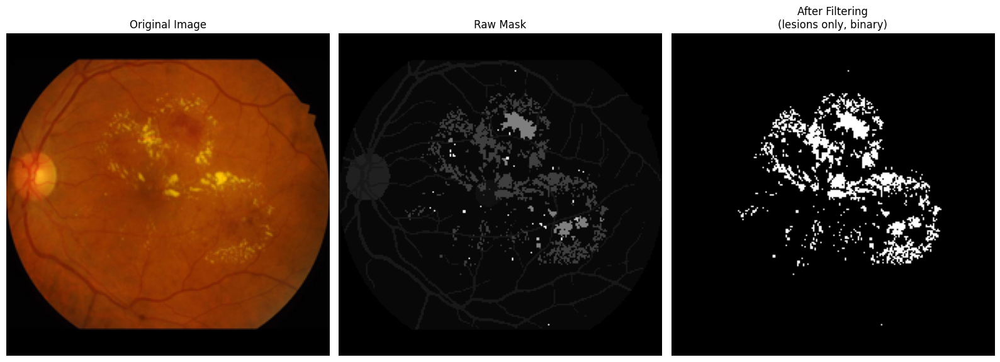

In [ ]:
split_dir = IDRID_SPLIT_DIRS[0]
images_dir = os.path.join(split_dir, "Images")
labels_dir = os.path.join(split_dir, "Labels")

sample_img_path = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))[0]

if os.path.normpath(split_dir) == os.path.normpath("/data/aveera/Refined IDRiD/Train/Train"):
    image_id = os.path.splitext(os.path.basename(sample_img_path))[0] + "_vessel"
else:
    image_id = os.path.splitext(os.path.basename(sample_img_path))[0]

sample_mask_path = os.path.join(labels_dir, f"{image_id}.png")
target_size = (224, 224)

raw_img = np.array(Image.open(sample_img_path).convert('RGB').resize(target_size))
raw_mask_native = np.array(Image.open(sample_mask_path).convert('L'))

raw_mask = cv2.resize(raw_mask_native, target_size, interpolation=cv2.INTER_NEAREST)

lesion_only_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

print(f"Sample: {image_id}")
print(f"Unique label values in raw mask: {sorted(np.unique(raw_mask).tolist())}")
print(f"Lesion pixels after filtering: {lesion_only_mask.mean():.2%} of image")
print(f"Lesion pixel count: {lesion_only_mask.sum()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(raw_img)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(raw_mask, cmap="gray")
axes[1].set_title("Raw Mask")
axes[1].axis("off")

axes[2].imshow(lesion_only_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("After Filtering\n(lesions only, binary)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# **Part Three: Explainability Evaluation Metrics**

**While Grad-CAM is widely applied in DR interpretability literature, disclosed hyperparameters for perturbation-based methods (LIME, SHAP) are rarely reported in DR-specific work.**

Our parameter choices were therefore informed by broader medical-imaging and XAI benchmarking literature rather than DR-specific research, while also accoutning for our resource constraints given the scale of our evaluation.

**For LIME, we set lime_samples=1000**, consistent with values used in [Gastrointestinal Endoscopic study](https://arxiv.org/pdf/2503.00780), [Sickle Cell study](https://arxiv.org/pdf/2305.01663) and [Photonic Chip study](https://arxiv.org/pdf/2505.09266) which set the number of samples to 1000 to ensure the creation of a sufficient number of perturbed samples around the input instance for accurate approximation.

**For SHAP, we set the max_evals =500**, consistent with the [Sickle Cell study](https://arxiv.org/pdf/2305.01663) from above and is also the SHAP libraries default. We also use batch_size-50 which is the SHAP library, the same justification as this study [haematopoietic stem cell study](https://pmc.ncbi.nlm.nih.gov/articles/PMC12746025/)


**We use a 32x32 blur kernel for the SHAP masker, smaller than the 128x128 kernel used in SHAP's reference examples for 224x224 natural images.** In natural-image classification, the relevant object typically occupies a large contiguous region of the frame whereas for DR lesion attribution, multiple small lesions can appear simultaneously across the image. A 128x128 kernel would blur across a majority of the image width in a single masking operation, conflating spatially distinct lesions that should be attributed independently, which is why we choose 32x32

**The XAI Attribution Engine is a single wrapper around three XAI methods, so each trained model can be explained the same way regardless of which method is used. Given a model and an image, it returns an attribution map per method highlighting the regions that most influenced the prediction**

In [ ]:
class AttributionEngine:
    IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    CLASS_NAMES = ["No DR","Mild DR","Moderate DR","Severe DR", "Proliferative DR"]

    def __init__(self, model, device, lime_samples=1000, img_size=224, shap_max_evals=500,
                 shap_batch_size=50, predict_chunk_size=32):
        
        self.model = model.to(device)
        self.model.eval()
        self.device = device

        self.lime_samples    = lime_samples     # How many perturbed versions of the image LIME generates to fit its local surrogate model
        self.img_size        = img_size
        self.shap_max_evals  = shap_max_evals   # How many masked evaluations shap.Explainer's Partition explainer is allowed per image
        self.shap_batch_size = shap_batch_size  # Batch size used when shap.Explainer evaluates masked images through the model
        self.predict_chunk_size = predict_chunk_size
        self.class_names     = self.CLASS_NAMES

        self._gradcam = None

        self._norm_transform = transforms.Normalize(mean=self.IMAGENET_MEAN.tolist(), std=self.IMAGENET_STD.tolist()) # Stores the standard ImageNet normalization
        self.shap_explainer = None  # Built lazily on first compute_shap() call, once we know the image shape
        self.lime_explainer = lime_image.LimeImageExplainer()

    def find_gradcam_target_layer(self):
      if hasattr(self.model, "layer4"):
          target_layer = self.model.layer4[-1]
      elif hasattr(self.model, "features"):
          target_layer = self.model.features[-1]
      else:
          conv_layers = [m for m in self.model.modules() if isinstance(m, nn.Conv2d)]
          if not conv_layers:
              raise ValueError("Could not locate a Conv2d layer in the model for Grad-CAM.")
          target_layer = conv_layers[-1]
      return target_layer

    def get_gradcam(self):
        """build a Grad-CAM object"""
        if self._gradcam is None:
            target_layer = self.find_gradcam_target_layer()
            self._gradcam = GradCAM(model=self.model, target_layers=[target_layer])
        return self._gradcam

    def unnormalize_to_uint8(self, img_tensor):
        """Unormalizes the image for LIME and SHAP (since they need the original image to create their superpixels)"""
        img = img_tensor.detach().cpu().numpy().transpose(1, 2, 0)
        img = img * self.IMAGENET_STD + self.IMAGENET_MEAN
        img = np.clip(img, 0.0, 1.0)
        return (img * 255).astype(np.uint8)

    @staticmethod
    def normalize_map(m, pct_clip=99.0, mode="abs"):
        m = np.nan_to_num(m.astype(np.float32))
        if mode == "abs":
            m = np.abs(m)
        elif mode == "pos":
            m = np.clip(m, 0, None)
        else:
            raise ValueError(f"Unknown normalize mode: {mode!r} (expected 'abs' or 'pos')")

        if m.max() > 0:
            clip_val = np.percentile(m, pct_clip)
            if clip_val > 0:
                m = np.clip(m, 0, clip_val)
        mn, mx = m.min(), m.max()
        if mx - mn > 1e-12:
            m = (m - mn) / (mx - mn)
        else:
            m = np.zeros_like(m)
        return m

    def resize_map(self, m):
        """Grad-CAM generally produces a smaller image, so the image is resized back to a normal viewing standard (224 x 224 pixels)"""
        if m.shape[0] != self.img_size or m.shape[1] != self.img_size:
            m = cv2.resize(m.astype(np.float32), (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        return m

    def compute_gradcam(self, img, target_class):
        """Computes and returns the Grad-CAM heatmap"""
        cam = self.get_gradcam()
        targets = [ClassifierOutputTarget(target_class)]
        grayscale_cam = cam(input_tensor=img, targets=targets)[0]
        heatmap = self.normalize_map(grayscale_cam, mode="abs")
        return self.resize_map(heatmap)

    def show_grad_cam(self, img, raw_img_uint8, target_class):
        """Displays the GradCAM heatmap"""
        heatmap = self.compute_gradcam(img, target_class)
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(raw_img_uint8)
        axes[0].set_title("Original Image")
        axes[0].axis("off")
        axes[1].imshow(raw_img_uint8)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        axes[1].set_title("Grad-CAM")
        axes[1].axis("off")
        plt.tight_layout()
        plt.show()

    def _predict_in_chunks(self, numpy_images):
        """Forward-pass a batch of perturbed images in small chunks."""
        outputs = [] 
        n = numpy_images.shape[0]
        for start in range(0, n, self.predict_chunk_size):
            chunk = numpy_images[start:start + self.predict_chunk_size]
            tensor = torch.from_numpy(chunk).float().to(self.device)
            tensor = tensor / 255.0
            tensor = tensor.permute(0, 3, 1, 2)
            tensor = self._norm_transform(tensor)
            with torch.no_grad():
                logits = self.model(tensor)
            outputs.append(logits.cpu().numpy())
            del tensor, logits, chunk
        return np.concatenate(outputs, axis=0)
    
    def _lime_predict_fn(self, numpy_images):
        return self._predict_in_chunks(numpy_images)

    def compute_lime(self, raw_img_uint8, target_class):
        """Runs LIME once, returns the raw explanation object."""
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)

        explanation = self.lime_explainer.explain_instance(
            raw_img_uint8.astype('double'),
            self._lime_predict_fn,
            top_labels=5,
            hide_color=0,
            num_samples=self.lime_samples,
        )

        if target_class not in explanation.local_exp:
            raise ValueError(
                f"LIME did not explain class {target_class} "
                f"(only explained {list(explanation.local_exp.keys())}); increase top_labels."
            )
        return explanation

    def get_lime_heatmap(self, explanation, target_class):
        """LIME heatmaps for Pointing Game"""
        dict_heatmap = dict(explanation.local_exp[target_class])
        heatmap = np.vectorize(dict_heatmap.get)(explanation.segments)
        heatmap = self.normalize_map(heatmap, mode="pos")
        return self.resize_map(heatmap)

    def show_lime(self, raw_img_uint8, target_class, num_features=5, positive_only=True):
        """Displays the LIME maps."""
        explanation = self.compute_lime(raw_img_uint8, target_class)

        fig, axes = plt.subplots(1, 4, figsize=(22, 5))
        fig.suptitle(f"LIME Detailed Subpixel Diagnostics: {type(self.model).__name__} (Class {target_class})",fontsize=14, weight='bold', y=1.02)

        # Original image
        axes[0].imshow(raw_img_uint8)
        axes[0].set_title("Original Image Structure")
        axes[0].axis("off")

        # Positive-only masking, using the method's own parameters
        temp1, mask1 = explanation.get_image_and_mask(
            target_class, positive_only=positive_only, num_features=num_features, hide_rest=True
        )
        axes[1].imshow(mark_boundaries(temp1 / 255.0, mask1))
        axes[1].set_title(f"Top {num_features} {'Positive' if positive_only else 'Pos/Neg'} Features")
        axes[1].axis("off")

        # Pros & cons boundary (fixed at 10 features, both signs, rest shown)
        temp2, mask2 = explanation.get_image_and_mask(
            target_class, positive_only=False, num_features=10, hide_rest=False
        )
        axes[2].imshow(mark_boundaries(temp2 / 255.0, mask2))
        axes[2].set_title("Top 10 Pros/Cons Boundary")
        axes[2].axis("off")

        # Symmetrical continuous weight heatmap
        dict_heatmap = dict(explanation.local_exp[target_class])
        heatmap_matrix = np.vectorize(dict_heatmap.get)(explanation.segments)

        max_val = np.abs(heatmap_matrix).max() if np.abs(heatmap_matrix).max() > 0 else 1.0
        im = axes[3].imshow(heatmap_matrix, cmap='RdBu', vmin=-max_val, vmax=max_val)
        axes[3].set_title("Symmetrical Weight Distribution")
        axes[3].axis("off")

        fig.colorbar(im, ax=axes[3], orientation='vertical', fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.show()

    def close_lime_explanation(self, explanation):
        """Explicitly drop LIME's internal segment/perturbation state."""
        explanation.segments = None
        explanation.local_exp = None
        explanation.local_pred = None

    def _shap_predict_fn(self, numpy_images):
        return self._predict_in_chunks(numpy_images)

    def _build_shap_explainer(self, image_shape):
        """Builds the SHAP explainer object."""
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)
        masker_blur = shap.maskers.Image("blur(32,32)", image_shape)
        self.shap_explainer = shap.Explainer(self._shap_predict_fn, masker_blur, output_names=self.class_names)

    def compute_shap(self, raw_img_uint8, target_class=None, all_classes=True):
        """Return the SHAP values for the given image."""
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)

        if self.shap_explainer is None:
            self._build_shap_explainer(raw_img_uint8.shape)

        images_batch = raw_img_uint8[np.newaxis, ...]
        n_classes = len(self.class_names) if self.class_names else 5
        outputs = list(range(n_classes)) if all_classes else [target_class]

        return self.shap_explainer(images_batch,max_evals=self.shap_max_evals,batch_size=self.shap_batch_size,outputs=outputs,)

    def get_shap_heatmap(self, shap_values, class_position=0):
        """SHAP heatmaps for Pointing Game"""
        raw_shap = shap_values.values[0, :, :, :, class_position]
        sv_signed = raw_shap.sum(axis=-1)
        heatmap = self.normalize_map(sv_signed, mode="pos")
        return self.resize_map(heatmap), self.resize_map(sv_signed)

    def show_shap(self, raw_img_uint8, target_class=None, all_classes=True):
        """Visualizes SHAP values using SHAP's own built-in image_plot."""
        shap_values = self.compute_shap(raw_img_uint8, target_class=target_class, all_classes=all_classes)
        shap.image_plot(shap_values)
        
    def compute_all(self, img_tensor, label):
        """Runs all the XAI techniques at once, returns a dictionary with the results."""
        self.model.eval()
        img = img_tensor.unsqueeze(0).to(self.device)
        with torch.no_grad():
            pred = self.model(img).argmax(dim=1).item()

        raw_img_uint8 = self.unnormalize_to_uint8(img_tensor)
        gradcam_map = self.compute_gradcam(img, pred)

        lime_explanation = self.compute_lime(raw_img_uint8, pred)
        lime_map = self.get_lime_heatmap(lime_explanation, pred)
        self.close_lime_explanation(lime_explanation)
        del lime_explanation

        shap_values = self.compute_shap(raw_img_uint8, target_class=pred, all_classes=False)
        shap_map, sv_signed = self.get_shap_heatmap(shap_values, class_position=0)
        del shap_values

        del img, raw_img_uint8
        return {'lime': lime_map, 'shap': shap_map, 'visual_shap': sv_signed, 'gradcam': gradcam_map, 'pred': pred}

In [25]:
_engine_cache = {}

def get_engine_for(model):
    """Look up the AttributionEngine that was built for this exact model object."""

    eng = _engine_cache.get(id(model))
    if eng is None:
        raise RuntimeError(
            "No AttributionEngine registered for this model."
        )
    return eng


In [ ]:
log_rss("BASELINE before MaxSensitivity section")
gpu_mem_report("BASELINE before MaxSensitivity section")


In [26]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
def get_predicted_labels(model, samples, device, transform=test_transform):
    """Recomputes the model's predicted class per sample."""
    preds = []
    model.eval()
    with torch.no_grad():
        for raw_img_np, _ in samples:
            input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to(device)
            pred = model(input_tensor).argmax(dim=1).item()
            preds.append(pred)
    return np.array(preds)

In [ ]:
def explain_gradcam(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)
    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()
        gradcam = eng.compute_gradcam(img_tensor.unsqueeze(0).to(eng.device), int(target))
        maps.append(gradcam)
        del img_tensor
    return np.stack(maps)[:, None, :, :]


def explain_lime(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)
    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()
        raw = eng.unnormalize_to_uint8(img_tensor)
        explanation = eng.compute_lime(raw, int(target))
        heatmap = eng.get_lime_heatmap(explanation, int(target))
        maps.append(heatmap)
        eng.close_lime_explanation(explanation)
        del explanation, img_tensor, raw
    return np.stack(maps)[:, None, :, :]


def explain_shap(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)
    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()
        raw = eng.unnormalize_to_uint8(img_tensor)
        shap_values = eng.compute_shap(raw, target_class=int(target), all_classes=False)
        heatmap, _ = eng.get_shap_heatmap(shap_values, class_position=0)
        maps.append(heatmap)
        del shap_values, img_tensor, raw
    return np.stack(maps)[:, None, :, :]

explain_funcs = {
    "GradCAM": explain_gradcam,
    "LIME": explain_lime,
    "SHAP": explain_shap,
}

In [ ]:
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "maxsens_per_image_checkpoint.csv")

CHECKPOINT_COLUMNS = ["model", "method", "image_index", "max_sensitivity"]


def load_checkpoint():
    if os.path.exists(CHECKPOINT_PATH):
        return pd.read_csv(CHECKPOINT_PATH)
    return pd.DataFrame(columns=CHECKPOINT_COLUMNS)


def append_checkpoint_row(row: dict):
    """Append a single completed (model, method, image_index) result to disk immediately."""
    df_row = pd.DataFrame([row], columns=CHECKPOINT_COLUMNS)
    write_header = not os.path.exists(CHECKPOINT_PATH)
    df_row.to_csv(CHECKPOINT_PATH, mode="a", header=write_header, index=False)


def already_done(checkpoint_df, model_name, method, image_index):
    if checkpoint_df.empty:
        return False
    match = checkpoint_df[
        (checkpoint_df["model"] == model_name)
        & (checkpoint_df["method"] == method)
        & (checkpoint_df["image_index"] == image_index)
    ]
    return not match.empty


'\nN_TEST = 10\nmaxsens_samples = idrid_subset[:N_TEST]\n\nall_maxsens_rows = []\n\nfor model_name in ["resnet50","efficientnetb0"]:\n    print(f"\n{\'=\'*60}\n  MaxSensitivity Evaluation | Model: {model_name}\n{\'=\'*60}")\n\n    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")\n    model = load_model(model_name, drive_weight_path, device)\n\n    engine = AttributionEngine(model, device)\n    _engine_cache[id(model)] = engine  # register so explain_gradcam/lime/shap resolve to THIS engine/model\n\n    # Build the normalized input batch\n    input_tensors = []\n    for raw_img_np, _ in maxsens_samples:\n        image_np = raw_img_np.astype(np.float32) / 255.0\n        t = preprocess_image(image_np, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])\n        input_tensors.append(t.squeeze(0))\n    input_batch = torch.stack(input_tensors).to(device)\n\n    x_batch = input_batch.cpu().numpy()\n    y_batch = get_predicted_labels(model, maxsens_samples, 

In [ ]:
MAXSENS_KWARGS = dict(
    nr_samples=10,
    lower_bound=0.2,
    norm_numerator=norm_func.fro_norm,
    norm_denominator=norm_func.fro_norm,
    similarity_func=similarity_func.difference,
)

MODEL_NAMES = ["resnet50", "efficientnetb0"]
METHOD_NAMES = ["GradCAM", "LIME", "SHAP"]  # processed strictly one at a time, in this order


'\nplt.figure(figsize=(9, 5))\npivot = maxsens_summary.pivot(index=\'method\', columns=\'model\', values=\'mean_max_sensitivity\')\npivot.plot(kind=\'bar\', ax=plt.gca())\nplt.yscale("log")\nplt.ylabel("Mean MaxSensitivity (log scale, lower = more robust)")\nplt.title(f"MaxSensitivity Comparison by Model and Method")\nplt.xticks(rotation=0)\nplt.grid(axis="y", alpha=0.3)\nplt.tight_layout()\nplt.show()\n'

In [ ]:
N_TEST = 81
maxsens_samples = idrid_subset[:N_TEST]

checkpoint_df = load_checkpoint()
print(f"Resuming from checkpoint with {len(checkpoint_df)} previously completed (model, method, image) rows.")

# Fast O(1) membership check instead of re-scanning/rebuilding checkpoint_df every image.
completed_keys = set(zip(checkpoint_df["model"], checkpoint_df["method"], checkpoint_df["image_index"]))

for model_name in MODEL_NAMES:
    print(f"\n{'='*60}\n  MaxSensitivity | Model: {model_name}\n{'='*60}")

    # ---- Load ONE model at a time ----
    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    engine = AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    # Build the normalized input batch 
    input_tensors = []
    for raw_img_np, _ in maxsens_samples:
        image_np = raw_img_np.astype(np.float32) / 255.0
        t = preprocess_image(image_np, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        input_tensors.append(t.squeeze(0))
    input_batch = torch.stack(input_tensors)
    x_batch_all = input_batch.cpu().numpy()
    del input_tensors, input_batch
    clear_memory()

    y_batch_all = get_predicted_labels(model, maxsens_samples, device)
    gpu_mem_report(f"after loading {model_name}")

    # ---- Process ONE XAI method at a time ----
    for method in METHOD_NAMES:
        explain_func = explain_funcs[method]
        print(f"\n  Method: {method} ({model_name})")

        metric = MaxSensitivity(**MAXSENS_KWARGS)

        n_images = x_batch_all.shape[0]
        pbar = tqdm(range(n_images), desc=f"MaxSensitivity [{model_name}/{method}]")

        for img_idx in pbar:
            if (model_name, method, img_idx) in completed_keys:
                continue  # already computed in a previous (crashed) run

            np.random.seed(SEED)
            random.seed(SEED)
            torch.manual_seed(SEED)

            x_single = x_batch_all[img_idx:img_idx + 1]
            y_single = y_batch_all[img_idx:img_idx + 1]
            a_single = None

            try:
                a_single = explain_func(model, x_single, y_single)

                score = metric(
                    model=model,
                    x_batch=x_single,
                    y_batch=y_single,
                    a_batch=a_single,
                    device=device,
                    explain_func=explain_func,
                )[0]

                row = {
                    "model": model_name,
                    "method": method,
                    "image_index": img_idx,
                    "max_sensitivity": float(score),
                }
                append_checkpoint_row(row)
                completed_keys.add((model_name, method, img_idx))

            except Exception as e:
                print(f"    Error on {model_name}/{method}/image {img_idx}: {e}")

            finally:
                # Clear Python/PyTorch memory after each image 
                a_single = None
                x_single = None
                y_single = None
                clear_memory()
                if img_idx % 5 == 0:
                    log_rss(f"{model_name}/{method}/image {img_idx}")

        # Clear the MaxSensitivity object after each  method
        del metric
        clear_memory()

        # Reload once per method (cheap: ~hundreds of rows) instead of accumulating
        # checkpoint_df in memory via pd.concat on every single image.
        checkpoint_df = load_checkpoint()
        method_df = checkpoint_df[
            (checkpoint_df["model"] == model_name) & (checkpoint_df["method"] == method)
        ]
        method_summary_path = os.path.join(
            RESULTS_DIR, f"maxsens_{model_name}_{method}_summary.csv"
        )
        method_df.to_csv(method_summary_path, index=False)
        print(f"  Saved {len(method_df)} results for {model_name}/{method} -> {method_summary_path}")
        gpu_mem_report(f"after {model_name}/{method}")

    del x_batch_all, y_batch_all

    # Clear the model completely before loading the next one 
    unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    gpu_mem_report(f"after unloading {model_name}")

print("\nAll models and methods complete.")


**Saving our max-sensitivity results**

In [ ]:
full_maxsens_df = load_checkpoint()
display(full_maxsens_df)

maxsens_summary = (
    full_maxsens_df
    .groupby(['model', 'method'])['max_sensitivity']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .rename(columns={'mean': 'mean_max_sensitivity', 'std': 'std_max_sensitivity', 'count': 'n_images'})
)
maxsens_summary['mean_max_sensitivity'] = maxsens_summary['mean_max_sensitivity'].round(4)
maxsens_summary['std_max_sensitivity'] = maxsens_summary['std_max_sensitivity'].round(4)
maxsens_summary = maxsens_summary.sort_values(['model', 'mean_max_sensitivity'])

print("\n=== MaxSensitivity summary -- mean score per model/method ===")
print("    (lower mean_max_sensitivity = explanation changes less under small input")
print("     perturbations = more robust explanation)\n")
display(maxsens_summary)

now = datetime.now().strftime("%Y-%m-%d")
full_maxsens_df.to_csv(os.path.join(RESULTS_DIR, f'maxsens_full_{now}.csv'), index=False)
maxsens_summary.to_csv(os.path.join(RESULTS_DIR, f'maxsens_summary_{now}.csv'), index=False)
print(f"\nSaved per-image results to maxsens_full_{now}.csv")
print(f"Saved summary to maxsens_summary_{now}.csv")


**Visualizing our Max-Sensitivity results**

In [ ]:
plt.figure(figsize=(9, 5))
pivot = maxsens_summary.pivot(index='method', columns='model', values='mean_max_sensitivity')
pivot.plot(kind='bar', ax=plt.gca())
plt.yscale("log")
plt.ylabel("Mean MaxSensitivity (log scale, lower = more robust)")
plt.title("MaxSensitivity Comparison by Model and Method")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
log_rss("after MaxSensitivity section (before attribution/IROF)")
gpu_mem_report("after MaxSensitivity section (before attribution/IROF)")
gc.collect()


In [ ]:
# --- FIX: checkpoint every image to disk as it's computed, instead of only holding
# results in a Python list and writing the .npz once ALL 81 images finish. Previously,
# if the job OOM-killed partway through (e.g. image 20/81 for efficientnet), every
# image computed in that run was lost and the next run started again from image 0.
# Now each image's maps are written to its own tiny .npz immediately, so a crash only
# costs you the one in-flight image, and a resumed run skips whatever is already saved.

def _per_image_dir(save_dir, model_name):
    d = os.path.join(save_dir, f"{model_name}_per_image")
    os.makedirs(d, exist_ok=True)
    return d


def run_attributions_on_samples(engine, samples, transform, save_dir, model_name, desc="XAI"):
    per_image_dir = _per_image_dir(save_dir, model_name)

    for i, (raw_img, label) in enumerate(tqdm(samples, desc=desc, ncols=90)):
        img_path = os.path.join(per_image_dir, f"image_{i:04d}.npz")
        if os.path.exists(img_path):
            continue  # already computed in a previous (crashed) run -- resume from here

        img_tensor = transform(PILImage.fromarray(raw_img))
        try:
            maps = engine.compute_all(img_tensor, label)
            # Write atomically: build the full file under a temp name, then rename,
            # so a crash mid-write never leaves a half-written / corrupt checkpoint.
            tmp_path = img_path + ".tmp"
            np.savez(
                tmp_path,
                lime=maps['lime'],
                shap=maps['shap'],
                gradcam=maps['gradcam'],
                label=label,
            )
            os.replace(tmp_path, img_path)
        finally:
            img_tensor = None
            clear_memory()
            if i % 5 == 0:
                log_rss(f"{desc}/image {i}")


def assemble_attribution_results(save_dir, model_name, n_images):
    """Stitches the per-image checkpoint files back into the combined arrays that
    downstream cells expect (gts/gradcam/lime/shap, one row per image, in order)."""
    per_image_dir = _per_image_dir(save_dir, model_name)
    lime_maps, shap_maps, gradcam_maps, labels = [], [], [], []
    for i in range(n_images):
        img_path = os.path.join(per_image_dir, f"image_{i:04d}.npz")
        with np.load(img_path) as d:
            lime_maps.append(d['lime'])
            shap_maps.append(d['shap'])
            gradcam_maps.append(d['gradcam'])
            labels.append(int(d['label']))
    return {
        'lime': lime_maps,
        'shap': shap_maps,
        'gradcam': gradcam_maps,
        'labels': labels,
    }

In [ ]:
log_rss("before viz (grad-cam/shap/lime side-by-side) cell")
gpu_mem_report("before viz cell")


# **Side-by-Side Comparison of each XAI technique**

--- resnet50 ---


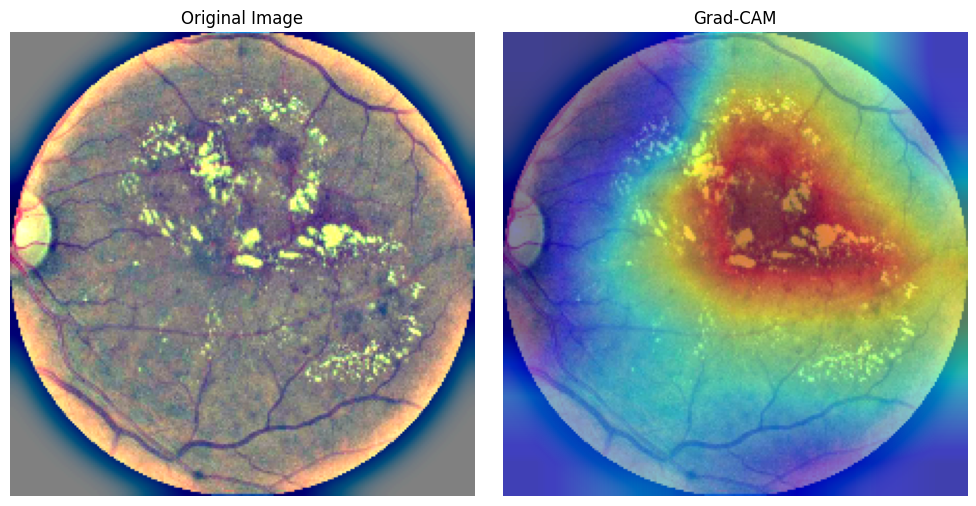


  0%|          | 0/498 [00:00<?, ?it/s]


542it [00:00, 2518.49it/s]             

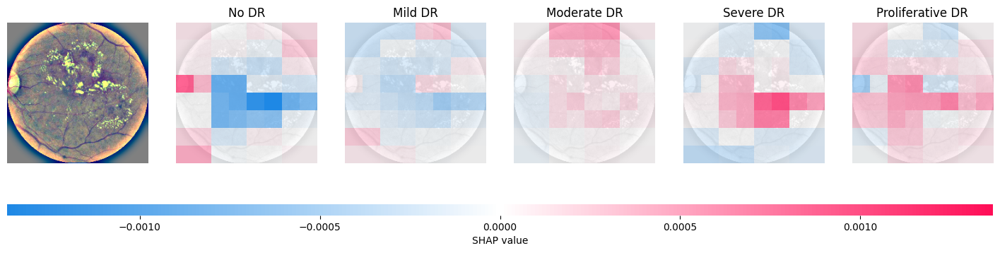


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<01:03, 15.61it/s]


  2%|▏         | 20/1000 [00:00<00:34, 28.74it/s]


  3%|▎         | 30/1000 [00:00<00:24, 39.74it/s]


  4%|▍         | 40/1000 [00:01<00:19, 48.20it/s]


  5%|▌         | 50/1000 [00:01<00:17, 55.00it/s]


  6%|▌         | 60/1000 [00:01<00:15, 59.82it/s]


  7%|▋         | 70/1000 [00:01<00:14, 63.79it/s]


  8%|▊         | 80/1000 [00:01<00:13, 66.39it/s]


  9%|▉         | 90/1000 [00:01<00:13, 68.09it/s]


 10%|█         | 100/1000 [00:01<00:13, 68.67it/s]


 11%|█         | 110/1000 [00:02<00:12, 69.43it/s]


 12%|█▏        | 120/1000 [00:02<00:12, 70.30it/s]


 13%|█▎        | 130/1000 [00:02<00:12, 71.27it/s]


 14%|█▍        | 140/1000 [00:02<00:11, 71.69it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 71.68it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 71.39it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 70.58it/s]


 18%|█▊        | 180/1000 [00:03<00:11, 70.28it/s]


 19%|█▉        | 190/1000 [00:03<00:11, 70.05it/s]


 20%|██        | 200/1000 [00:03<00:11, 69.36it/s]


 21%|██        | 210/1000 [00:03<00:11, 69.23it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 69.00it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 68.94it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 68.43it/s]


 25%|██▌       | 250/1000 [00:04<00:11, 68.06it/s]


 26%|██▌       | 260/1000 [00:04<00:10, 68.06it/s]


 27%|██▋       | 270/1000 [00:04<00:10, 67.81it/s]


 28%|██▊       | 280/1000 [00:04<00:10, 67.06it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 66.73it/s]


 30%|███       | 300/1000 [00:04<00:10, 66.31it/s]


 31%|███       | 310/1000 [00:04<00:10, 66.03it/s]


 32%|███▏      | 320/1000 [00:05<00:10, 65.79it/s]


 33%|███▎      | 330/1000 [00:05<00:10, 65.47it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 65.54it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 65.09it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 64.90it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 64.75it/s]


 38%|███▊      | 380/1000 [00:06<00:09, 64.75it/s]


 39%|███▉      | 390/1000 [00:06<00:09, 64.26it/s]


 40%|████      | 400/1000 [00:06<00:09, 63.93it/s]


 41%|████      | 410/1000 [00:06<00:09, 63.47it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 63.40it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 63.24it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 63.40it/s]


 45%|████▌     | 450/1000 [00:07<00:08, 63.34it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 62.91it/s]


 47%|████▋     | 470/1000 [00:07<00:08, 62.76it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 62.51it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 63.00it/s]


 50%|█████     | 500/1000 [00:07<00:07, 63.24it/s]


 51%|█████     | 510/1000 [00:08<00:07, 63.14it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 63.47it/s]


 53%|█████▎    | 530/1000 [00:08<00:07, 63.55it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 63.41it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 63.59it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 63.64it/s]


 57%|█████▋    | 570/1000 [00:09<00:06, 63.58it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 63.59it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 63.47it/s]


 60%|██████    | 600/1000 [00:09<00:06, 63.33it/s]


 61%|██████    | 610/1000 [00:09<00:06, 63.58it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 63.97it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 64.70it/s]


 64%|██████▍   | 640/1000 [00:10<00:05, 65.35it/s]


 65%|██████▌   | 650/1000 [00:10<00:05, 65.26it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 65.18it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 65.45it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 65.44it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 65.09it/s]


 70%|███████   | 700/1000 [00:11<00:04, 65.15it/s]


 71%|███████   | 710/1000 [00:11<00:04, 65.63it/s]


 72%|███████▏  | 720/1000 [00:11<00:04, 65.68it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 66.08it/s]


 74%|███████▍  | 740/1000 [00:11<00:03, 65.75it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 65.75it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 65.79it/s]


 77%|███████▋  | 770/1000 [00:12<00:03, 65.61it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 64.93it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 64.26it/s]


 80%|████████  | 800/1000 [00:12<00:03, 63.60it/s]


 81%|████████  | 810/1000 [00:12<00:02, 63.60it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 63.16it/s]


 83%|████████▎ | 830/1000 [00:13<00:02, 62.76it/s]


 84%|████████▍ | 840/1000 [00:13<00:02, 62.77it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 62.94it/s]


 86%|████████▌ | 860/1000 [00:13<00:02, 62.90it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 62.55it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 62.58it/s]


 89%|████████▉ | 890/1000 [00:14<00:01, 62.30it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 62.27it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 62.20it/s]


 92%|█████████▏| 920/1000 [00:14<00:01, 62.54it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 62.46it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 62.68it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 62.30it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 62.20it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 62.25it/s]


 98%|█████████▊| 980/1000 [00:15<00:00, 62.56it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 62.45it/s]


100%|██████████| 1000/1000 [00:15<00:00, 62.21it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.37it/s]

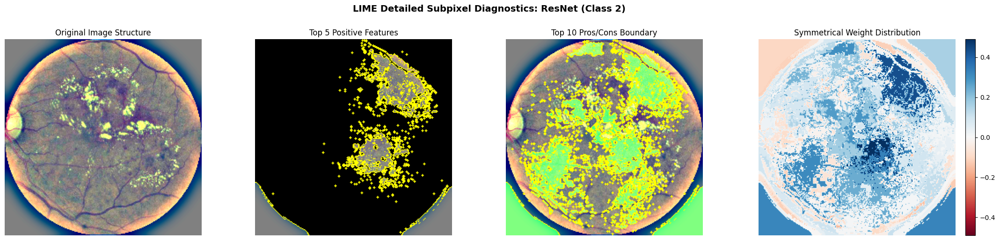

--- efficientnetb0 ---


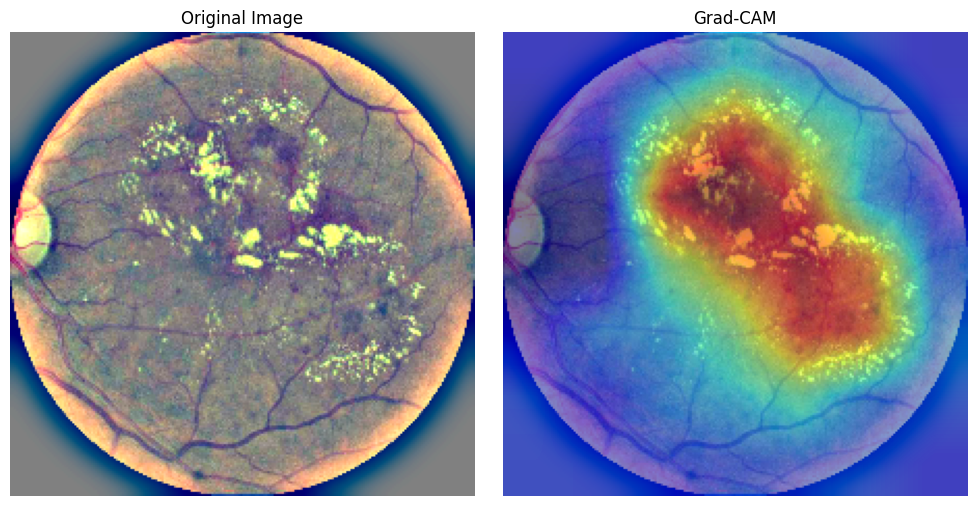


  0%|          | 0/498 [00:00<?, ?it/s]


 25%|██▍       | 124/498 [00:04<00:13, 27.68it/s]


 35%|███▍      | 174/498 [00:04<00:07, 41.90it/s]


 45%|████▍     | 224/498 [00:04<00:04, 60.38it/s]


 55%|█████▌    | 274/498 [00:04<00:02, 83.57it/s]


 65%|██████▌   | 324/498 [00:04<00:01, 111.52it/s]


 75%|███████▌  | 374/498 [00:05<00:00, 143.55it/s]


 85%|████████▌ | 424/498 [00:05<00:00, 178.15it/s]


 95%|█████████▌| 474/498 [00:05<00:00, 213.32it/s]


524it [00:05, 247.24it/s]                         


PartitionExplainer explainer: 100%|██████████| 1/1 [00:00<?, ?it/s]


PartitionExplainer explainer: 2it [00:15, 15.94s/it]               

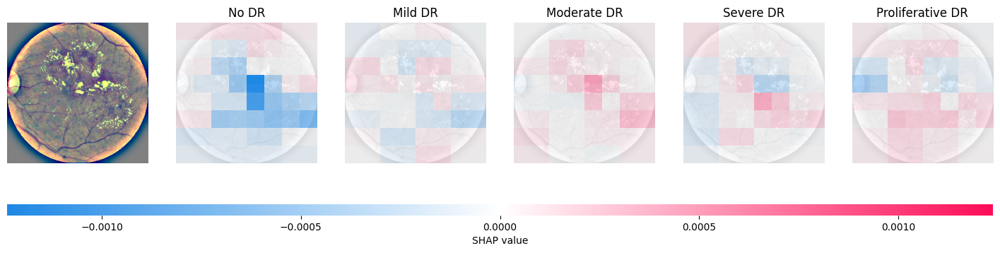


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:02<03:28,  4.74it/s]


  2%|▏         | 20/1000 [00:02<01:32, 10.58it/s]


  3%|▎         | 30/1000 [00:02<00:55, 17.56it/s]


  4%|▍         | 40/1000 [00:02<00:37, 25.32it/s]


  5%|▌         | 50/1000 [00:02<00:28, 33.66it/s]


  6%|▌         | 60/1000 [00:02<00:22, 41.83it/s]


  7%|▋         | 70/1000 [00:02<00:18, 49.62it/s]


  8%|▊         | 80/1000 [00:02<00:16, 56.36it/s]


  9%|▉         | 90/1000 [00:03<00:14, 62.13it/s]


 10%|█         | 100/1000 [00:03<00:13, 66.22it/s]


 11%|█         | 110/1000 [00:03<00:12, 69.57it/s]


 12%|█▏        | 120/1000 [00:03<00:12, 72.48it/s]


 13%|█▎        | 130/1000 [00:03<00:11, 75.11it/s]


 14%|█▍        | 140/1000 [00:03<00:11, 76.62it/s]


 15%|█▌        | 150/1000 [00:03<00:10, 77.32it/s]


 16%|█▌        | 160/1000 [00:03<00:10, 78.28it/s]


 17%|█▋        | 170/1000 [00:04<00:10, 78.17it/s]


 18%|█▊        | 180/1000 [00:04<00:10, 78.56it/s]


 19%|█▉        | 190/1000 [00:04<00:10, 78.69it/s]


 20%|██        | 200/1000 [00:04<00:10, 78.33it/s]


 21%|██        | 210/1000 [00:04<00:10, 78.76it/s]


 22%|██▏       | 220/1000 [00:04<00:09, 78.85it/s]


 23%|██▎       | 230/1000 [00:04<00:09, 79.00it/s]


 24%|██▍       | 240/1000 [00:05<00:09, 78.89it/s]


 25%|██▌       | 250/1000 [00:05<00:09, 79.00it/s]


 26%|██▌       | 260/1000 [00:05<00:09, 79.18it/s]


 27%|██▋       | 270/1000 [00:05<00:09, 79.05it/s]


 28%|██▊       | 280/1000 [00:05<00:09, 78.48it/s]


 29%|██▉       | 290/1000 [00:05<00:09, 78.59it/s]


 30%|███       | 300/1000 [00:05<00:08, 78.21it/s]


 31%|███       | 310/1000 [00:05<00:08, 78.08it/s]


 32%|███▏      | 320/1000 [00:06<00:08, 78.15it/s]


 33%|███▎      | 330/1000 [00:06<00:08, 78.22it/s]


 34%|███▍      | 340/1000 [00:06<00:08, 78.71it/s]


 35%|███▌      | 350/1000 [00:06<00:08, 78.34it/s]


 36%|███▌      | 360/1000 [00:06<00:08, 78.27it/s]


 37%|███▋      | 370/1000 [00:06<00:08, 78.43it/s]


 38%|███▊      | 380/1000 [00:06<00:07, 78.75it/s]


 39%|███▉      | 390/1000 [00:06<00:07, 78.45it/s]


 40%|████      | 400/1000 [00:07<00:07, 78.17it/s]


 41%|████      | 410/1000 [00:07<00:07, 77.91it/s]


 42%|████▏     | 420/1000 [00:07<00:07, 78.34it/s]


 43%|████▎     | 430/1000 [00:07<00:07, 78.59it/s]


 44%|████▍     | 440/1000 [00:07<00:07, 79.15it/s]


 45%|████▌     | 450/1000 [00:07<00:06, 79.32it/s]


 46%|████▌     | 460/1000 [00:07<00:06, 79.09it/s]


 47%|████▋     | 470/1000 [00:07<00:06, 79.03it/s]


 48%|████▊     | 480/1000 [00:08<00:06, 78.59it/s]


 49%|████▉     | 490/1000 [00:08<00:06, 78.80it/s]


 50%|█████     | 500/1000 [00:08<00:06, 78.96it/s]


 51%|█████     | 510/1000 [00:08<00:06, 78.73it/s]


 52%|█████▏    | 520/1000 [00:08<00:06, 78.80it/s]


 53%|█████▎    | 530/1000 [00:08<00:05, 79.12it/s]


 54%|█████▍    | 540/1000 [00:08<00:05, 78.80it/s]


 55%|█████▌    | 550/1000 [00:08<00:05, 79.02it/s]


 56%|█████▌    | 560/1000 [00:09<00:05, 78.98it/s]


 57%|█████▋    | 570/1000 [00:09<00:05, 78.88it/s]


 58%|█████▊    | 580/1000 [00:09<00:05, 78.92it/s]


 59%|█████▉    | 590/1000 [00:09<00:05, 78.58it/s]


 60%|██████    | 600/1000 [00:09<00:05, 78.37it/s]


 61%|██████    | 610/1000 [00:09<00:04, 78.63it/s]


 62%|██████▏   | 620/1000 [00:09<00:04, 79.25it/s]


 63%|██████▎   | 630/1000 [00:09<00:04, 79.55it/s]


 64%|██████▍   | 640/1000 [00:10<00:04, 79.95it/s]


 65%|██████▌   | 650/1000 [00:10<00:04, 79.49it/s]


 66%|██████▌   | 660/1000 [00:10<00:04, 79.17it/s]


 67%|██████▋   | 670/1000 [00:10<00:04, 79.26it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 79.13it/s]


 69%|██████▉   | 690/1000 [00:10<00:03, 78.35it/s]


 70%|███████   | 700/1000 [00:10<00:03, 78.51it/s]


 71%|███████   | 710/1000 [00:10<00:03, 79.10it/s]


 72%|███████▏  | 720/1000 [00:11<00:03, 79.05it/s]


 73%|███████▎  | 730/1000 [00:11<00:03, 79.28it/s]


 74%|███████▍  | 740/1000 [00:11<00:03, 78.86it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 78.85it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 78.76it/s]


 77%|███████▋  | 770/1000 [00:11<00:02, 78.65it/s]


 78%|███████▊  | 780/1000 [00:11<00:02, 78.31it/s]


 79%|███████▉  | 790/1000 [00:11<00:02, 78.33it/s]


 80%|████████  | 800/1000 [00:12<00:02, 78.21it/s]


 81%|████████  | 810/1000 [00:12<00:02, 78.84it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 78.63it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 78.30it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 78.53it/s]


 85%|████████▌ | 850/1000 [00:12<00:01, 78.91it/s]


 86%|████████▌ | 860/1000 [00:12<00:01, 79.02it/s]


 87%|████████▋ | 870/1000 [00:13<00:01, 78.64it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 78.98it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 78.75it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 78.70it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 78.58it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 79.09it/s]


 93%|█████████▎| 930/1000 [00:13<00:00, 78.82it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 79.08it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 78.56it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 78.35it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 78.34it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 78.84it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 78.63it/s]


100%|██████████| 1000/1000 [00:14<00:00, 78.25it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.20it/s]

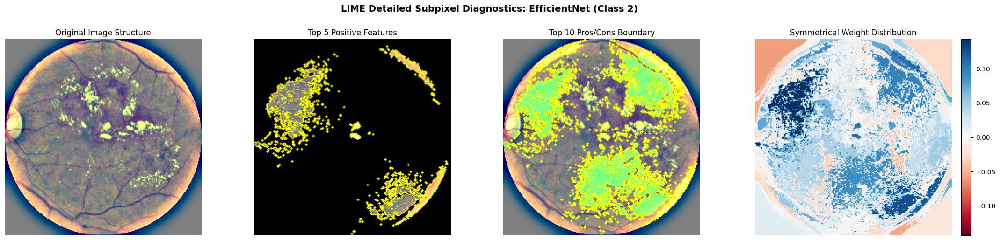

In [ ]:
raw_image, lesion_mask = idrid_subset[0]  # Sample image
drive_model_dir = "/data/aveera/models"
FIGURES_DIR = "/data/aveera/results/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

for model_name in ["resnet50", "efficientnetb0"]:
    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    engine = AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    image_tensor = test_transform(PILImage.fromarray(raw_image))
    with torch.no_grad():
        predicted_class = model(image_tensor.unsqueeze(0).to(device)).argmax(dim=1).item()

    raw_img_uint8 = engine.unnormalize_to_uint8(image_tensor)
    img_batched = image_tensor.unsqueeze(0).to(device)

    print(f"--- {model_name} ---")

    engine.show_grad_cam(img_batched, raw_img_uint8, predicted_class)
    plt.savefig(os.path.join(FIGURES_DIR, f"gradcam_{model_name}.png"), dpi=300, bbox_inches="tight")
    plt.close('all')

    engine.show_shap(raw_img_uint8, target_class=predicted_class, all_classes=True)
    plt.savefig(os.path.join(FIGURES_DIR, f"shap_{model_name}.png"), dpi=300, bbox_inches="tight")
    plt.close('all')

    engine.show_lime(raw_img_uint8, target_class=predicted_class)
    plt.savefig(os.path.join(FIGURES_DIR, f"lime_{model_name}.png"), dpi=300, bbox_inches="tight")
    plt.close('all')

    unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    gpu_mem_report(f"after unloading {model_name} (viz cell)")

    del image_tensor, img_batched, raw_img_uint8

    _engine_cache.clear()
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()
    gpu_mem_report(f"after unloading {model_name} (viz cell)")

 **Computing attribution maps used for localization and faithfulness tests**

In [ ]:
N_TEST = 81
SAVE_DIR = "/data/aveera/xai_maps"
os.makedirs(SAVE_DIR, exist_ok=True)

test_samples = idrid_subset[:N_TEST]

for model_name in ["resnet50", "efficientnetb0"]:
    save_path = os.path.join(SAVE_DIR, f"attribution_maps_{model_name}_test.npz")

    if os.path.exists(save_path):
        print(f"\nFound existing maps for {model_name} at {save_path}. Skipping generation.")
        continue

    print(f"\n{'='*60}\n  Computing attribution maps | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    engine = AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    # FIX: this now checkpoints every single image to disk as it finishes (see cell
    # defining run_attributions_on_samples). If SLURM kills the job partway through,
    # re-running this cell picks up right after the last completed image instead of
    # starting the whole model over from image 0.
    n_already_done = len([
        f for f in os.listdir(_per_image_dir(SAVE_DIR, model_name))
        if f.endswith(".npz")
    ]) if os.path.isdir(_per_image_dir(SAVE_DIR, model_name)) else 0
    print(f"  {n_already_done}/{len(test_samples)} images already checkpointed for {model_name}; resuming...")

    run_attributions_on_samples(
        engine, test_samples, test_transform,
        save_dir=SAVE_DIR, model_name=model_name,
        desc=f"XAI maps ({model_name})",
    )

    # All 81 images are now guaranteed to be on disk -- assemble the final combined
    # .npz that the rest of the notebook expects.
    attribution_results = assemble_attribution_results(SAVE_DIR, model_name, len(test_samples))

    gts           = np.stack(attribution_results['labels'], axis=0)
    gradcam_maps  = np.stack(attribution_results['gradcam'], axis=0)
    lime_maps     = np.stack(attribution_results['lime'], axis=0)
    shap_maps     = np.stack(attribution_results['shap'], axis=0)

    np.savez(save_path, gts=gts, gradcam=gradcam_maps, lime=lime_maps, shap=shap_maps)
    print(f"Saved {N_TEST} images' attribution maps to {save_path}")

    del attribution_results, gts, gradcam_maps, lime_maps, shap_maps

    unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    gpu_mem_report(f"after unloading {model_name}")


  Computing attribution maps | Model: resnet50



  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:14, 66.51it/s]


  2%|▏         | 20/1000 [00:00<00:15, 63.55it/s]


  3%|▎         | 30/1000 [00:00<00:15, 63.55it/s]


  4%|▍         | 40/1000 [00:00<00:15, 62.95it/s]


  5%|▌         | 50/1000 [00:00<00:15, 63.09it/s]


  6%|▌         | 60/1000 [00:00<00:14, 62.97it/s]


  7%|▋         | 70/1000 [00:01<00:14, 63.29it/s]


  8%|▊         | 80/1000 [00:01<00:14, 63.24it/s]


  9%|▉         | 90/1000 [00:01<00:14, 63.17it/s]


 10%|█         | 100/1000 [00:01<00:14, 63.17it/s]


 11%|█         | 110/1000 [00:01<00:14, 63.49it/s]


 12%|█▏        | 120/1000 [00:01<00:13, 63.99it/s]


 13%|█▎        | 130/1000 [00:02<00:13, 64.64it/s]


 14%|█▍        | 140/1000 [00:02<00:13, 64.78it/s]


 15%|█▌        | 150/1000 [00:02<00:13, 64.76it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 65.00it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 64.63it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 64.74it/s]


 19%|█▉        | 190/1000 [00:02<00:12, 64.80it/s]


 20%|██        | 200/1000 [00:03<00:12, 64.59it/s]


 21%|██        | 210/1000 [00:03<00:12, 64.90it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 64.80it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 64.99it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 64.86it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 64.93it/s]


 26%|██▌       | 260/1000 [00:04<00:11, 65.11it/s]


 27%|██▋       | 270/1000 [00:04<00:11, 65.01it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 64.63it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 64.62it/s]


 30%|███       | 300/1000 [00:04<00:10, 64.43it/s]


 31%|███       | 310/1000 [00:04<00:10, 64.38it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 64.44it/s]


 33%|███▎      | 330/1000 [00:05<00:10, 64.41it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 64.31it/s]


 35%|███▌      | 350/1000 [00:05<00:10, 63.75it/s]


 36%|███▌      | 360/1000 [00:05<00:10, 63.60it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 63.34it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 63.34it/s]


 39%|███▉      | 390/1000 [00:06<00:09, 62.75it/s]


 40%|████      | 400/1000 [00:06<00:09, 62.46it/s]


 41%|████      | 410/1000 [00:06<00:09, 62.44it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 62.86it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 63.13it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 63.57it/s]


 45%|████▌     | 450/1000 [00:07<00:08, 63.73it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 63.66it/s]


 47%|████▋     | 470/1000 [00:07<00:08, 63.77it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 63.55it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 63.83it/s]


 50%|█████     | 500/1000 [00:07<00:07, 63.91it/s]


 51%|█████     | 510/1000 [00:07<00:07, 63.68it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 63.90it/s]


 53%|█████▎    | 530/1000 [00:08<00:07, 64.07it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 63.89it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 63.92it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 63.88it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 63.92it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 63.93it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 63.76it/s]


 60%|██████    | 600/1000 [00:09<00:06, 63.67it/s]


 61%|██████    | 610/1000 [00:09<00:06, 63.86it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 64.25it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 64.40it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 64.88it/s]


 65%|██████▌   | 650/1000 [00:10<00:05, 64.78it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 64.65it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 64.79it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 64.85it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 64.56it/s]


 70%|███████   | 700/1000 [00:10<00:04, 64.68it/s]


 71%|███████   | 710/1000 [00:11<00:04, 65.25it/s]


 72%|███████▏  | 720/1000 [00:11<00:04, 65.28it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 65.48it/s]


 74%|███████▍  | 740/1000 [00:11<00:03, 65.11it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 65.14it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 65.21it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 65.13it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 65.03it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 64.34it/s]


 80%|████████  | 800/1000 [00:12<00:03, 63.68it/s]


 81%|████████  | 810/1000 [00:12<00:02, 64.04it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 63.92it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 63.74it/s]


 84%|████████▍ | 840/1000 [00:13<00:02, 63.99it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 64.20it/s]


 86%|████████▌ | 860/1000 [00:13<00:02, 64.25it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 63.97it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 64.13it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 63.83it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 64.14it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 64.34it/s]


 92%|█████████▏| 920/1000 [00:14<00:01, 64.82it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 64.68it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 64.96it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 64.62it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 64.53it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 64.47it/s]


 98%|█████████▊| 980/1000 [00:15<00:00, 64.84it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 64.72it/s]


100%|██████████| 1000/1000 [00:15<00:00, 64.50it/s]


100%|██████████| 1000/1000 [00:15<00:00, 64.20it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 81.22it/s]


  2%|▏         | 20/1000 [00:00<00:12, 76.59it/s]


  3%|▎         | 30/1000 [00:00<00:12, 75.93it/s]


  4%|▍         | 40/1000 [00:00<00:12, 74.91it/s]


  5%|▌         | 50/1000 [00:00<00:12, 75.42it/s]


  6%|▌         | 60/1000 [00:00<00:12, 75.07it/s]


  7%|▋         | 70/1000 [00:00<00:12, 74.88it/s]


  8%|▊         | 80/1000 [00:01<00:12, 74.35it/s]


  9%|▉         | 90/1000 [00:01<00:12, 73.23it/s]


 10%|█         | 100/1000 [00:01<00:12, 72.09it/s]


 11%|█         | 110/1000 [00:01<00:12, 71.44it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 70.94it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 70.92it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 70.70it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 70.80it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 70.36it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 70.32it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 69.29it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 68.88it/s]


 20%|██        | 200/1000 [00:02<00:11, 68.61it/s]


 21%|██        | 210/1000 [00:02<00:11, 68.28it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 68.28it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 68.01it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 68.10it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 67.98it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 67.61it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 67.44it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 67.17it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 66.92it/s]


 30%|███       | 300/1000 [00:04<00:10, 66.54it/s]


 31%|███       | 310/1000 [00:04<00:10, 66.24it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 65.92it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 65.56it/s]


 34%|███▍      | 340/1000 [00:04<00:10, 65.38it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 65.04it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 65.30it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 64.91it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 64.65it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 64.64it/s]


 40%|████      | 400/1000 [00:05<00:09, 65.50it/s]


 41%|████      | 410/1000 [00:05<00:08, 66.09it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 66.27it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 66.27it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 66.69it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 67.30it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 67.67it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 68.31it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 68.41it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 68.51it/s]


 50%|█████     | 500/1000 [00:07<00:07, 68.46it/s]


 51%|█████     | 510/1000 [00:07<00:07, 68.01it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 68.52it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 68.44it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 68.29it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 68.48it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 68.78it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 68.78it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 68.91it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 68.87it/s]


 60%|██████    | 600/1000 [00:08<00:05, 68.68it/s]


 61%|██████    | 610/1000 [00:08<00:05, 68.60it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 68.55it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 68.01it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 68.06it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 68.07it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 68.35it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 68.91it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 69.32it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 69.21it/s]


 70%|███████   | 700/1000 [00:10<00:04, 68.70it/s]


 71%|███████   | 710/1000 [00:10<00:04, 68.78it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 68.77it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 68.23it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 67.95it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 68.06it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 68.46it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 68.35it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 68.51it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 68.08it/s]


 80%|████████  | 800/1000 [00:11<00:02, 67.87it/s]


 81%|████████  | 810/1000 [00:11<00:02, 67.91it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 67.40it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 67.09it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.85it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 66.41it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 66.53it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 66.37it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 66.09it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 65.70it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 65.71it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 66.13it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 65.67it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 65.14it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 64.97it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 64.56it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 64.35it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 64.84it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 65.58it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 65.71it/s]


100%|██████████| 1000/1000 [00:14<00:00, 66.22it/s]


100%|██████████| 1000/1000 [00:14<00:00, 67.98it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 86.99it/s]


  2%|▏         | 20/1000 [00:00<00:11, 82.45it/s]


  3%|▎         | 30/1000 [00:00<00:11, 80.99it/s]


  4%|▍         | 40/1000 [00:00<00:11, 80.16it/s]


  5%|▌         | 50/1000 [00:00<00:11, 79.80it/s]


  6%|▌         | 60/1000 [00:00<00:11, 80.31it/s]


  7%|▋         | 70/1000 [00:00<00:11, 80.06it/s]


  8%|▊         | 80/1000 [00:00<00:11, 79.86it/s]


  9%|▉         | 90/1000 [00:01<00:11, 79.36it/s]


 10%|█         | 100/1000 [00:01<00:11, 78.24it/s]


 11%|█         | 110/1000 [00:01<00:11, 77.62it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 76.64it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 76.15it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 76.16it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 76.43it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 76.64it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 76.53it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 76.74it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 76.48it/s]


 20%|██        | 200/1000 [00:02<00:10, 76.34it/s]


 21%|██        | 210/1000 [00:02<00:10, 75.34it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 74.79it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 74.38it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 74.08it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 73.43it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 73.52it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 73.25it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 73.57it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 73.33it/s]


 30%|███       | 300/1000 [00:03<00:09, 72.76it/s]


 31%|███       | 310/1000 [00:04<00:09, 72.77it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 72.72it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 72.33it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 72.03it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 72.03it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 72.22it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 72.33it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 72.61it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 72.71it/s]


 40%|████      | 400/1000 [00:05<00:08, 73.23it/s]


 41%|████      | 410/1000 [00:05<00:08, 73.17it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 73.77it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 73.73it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 73.48it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 73.43it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 73.32it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 73.77it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 73.80it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 73.77it/s]


 50%|█████     | 500/1000 [00:06<00:06, 73.45it/s]


 51%|█████     | 510/1000 [00:06<00:06, 72.28it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 71.63it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 71.40it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 71.84it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 72.53it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.26it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 72.49it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 73.11it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 72.95it/s]


 60%|██████    | 600/1000 [00:08<00:05, 73.10it/s]


 61%|██████    | 610/1000 [00:08<00:05, 73.67it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 73.63it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 73.61it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 73.60it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 73.62it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 73.81it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 73.92it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 73.88it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 74.00it/s]


 70%|███████   | 700/1000 [00:09<00:04, 73.68it/s]


 71%|███████   | 710/1000 [00:09<00:03, 73.97it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 73.82it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 72.81it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 72.28it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 72.06it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 71.57it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 71.40it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 70.99it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 72.03it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.43it/s]


 81%|████████  | 810/1000 [00:10<00:02, 72.75it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 72.92it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 73.37it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 73.50it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 73.58it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 73.19it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 73.08it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 73.28it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 73.67it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 73.57it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 73.75it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 73.82it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 73.67it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 73.75it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 72.87it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 72.26it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 71.93it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 71.16it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 71.15it/s]


100%|██████████| 1000/1000 [00:13<00:00, 70.94it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.81it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 88.66it/s]


  2%|▏         | 20/1000 [00:00<00:11, 83.68it/s]


  3%|▎         | 30/1000 [00:00<00:11, 82.82it/s]


  4%|▍         | 40/1000 [00:00<00:11, 82.09it/s]


  5%|▌         | 50/1000 [00:00<00:11, 82.07it/s]


  6%|▌         | 60/1000 [00:00<00:11, 82.53it/s]


  7%|▋         | 70/1000 [00:00<00:11, 82.44it/s]


  8%|▊         | 80/1000 [00:00<00:11, 81.49it/s]


  9%|▉         | 90/1000 [00:01<00:11, 81.13it/s]


 10%|█         | 100/1000 [00:01<00:11, 80.55it/s]


 11%|█         | 110/1000 [00:01<00:11, 80.48it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 79.17it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 78.74it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 78.13it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 78.11it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 78.00it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 78.23it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 78.22it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.54it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.73it/s]


 21%|██        | 210/1000 [00:02<00:10, 77.07it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 76.35it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 76.06it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 75.83it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 75.44it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 75.60it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 75.28it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 75.29it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 75.46it/s]


 30%|███       | 300/1000 [00:03<00:09, 75.34it/s]


 31%|███       | 310/1000 [00:03<00:09, 74.99it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 74.70it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 74.41it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 73.91it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 73.67it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 73.23it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 73.01it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 72.36it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 72.44it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.72it/s]


 41%|████      | 410/1000 [00:05<00:08, 72.89it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 73.32it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 74.01it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 73.92it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 74.01it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 73.97it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 73.95it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 74.30it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 74.57it/s]


 50%|█████     | 500/1000 [00:06<00:06, 74.31it/s]


 51%|█████     | 510/1000 [00:06<00:06, 74.13it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 73.97it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 74.52it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 74.81it/s]


 55%|█████▌    | 550/1000 [00:07<00:05, 75.20it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 75.82it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 75.49it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 75.00it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 74.96it/s]


 60%|██████    | 600/1000 [00:07<00:05, 74.43it/s]


 61%|██████    | 610/1000 [00:08<00:05, 74.37it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 74.75it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 75.04it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 74.96it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 74.97it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 74.87it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 75.21it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 75.34it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 75.41it/s]


 70%|███████   | 700/1000 [00:09<00:03, 75.79it/s]


 71%|███████   | 710/1000 [00:09<00:03, 75.69it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 75.62it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 75.45it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 75.31it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 75.06it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 75.11it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 74.83it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 75.19it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 75.42it/s]


 80%|████████  | 800/1000 [00:10<00:02, 75.85it/s]


 81%|████████  | 810/1000 [00:10<00:02, 76.16it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 75.76it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 74.51it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 74.36it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 74.06it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 73.69it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 72.48it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 72.01it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 71.98it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 72.79it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 73.32it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 73.61it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 73.98it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 73.99it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 74.39it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 74.42it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 74.33it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 74.39it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 74.11it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.20it/s]


100%|██████████| 1000/1000 [00:13<00:00, 75.43it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 73.48it/s]


  2%|▏         | 20/1000 [00:00<00:13, 70.35it/s]


  3%|▎         | 29/1000 [00:00<00:12, 77.44it/s]


  4%|▎         | 37/1000 [00:00<00:13, 72.01it/s]


  4%|▍         | 45/1000 [00:00<00:13, 69.27it/s]


  5%|▌         | 52/1000 [00:00<00:14, 66.82it/s]


  6%|▌         | 60/1000 [00:00<00:14, 66.04it/s]


  7%|▋         | 70/1000 [00:01<00:13, 66.99it/s]


  8%|▊         | 80/1000 [00:01<00:13, 66.81it/s]


  9%|▉         | 89/1000 [00:01<00:12, 71.86it/s]


 10%|▉         | 97/1000 [00:01<00:13, 68.64it/s]


 10%|█         | 104/1000 [00:01<00:13, 65.55it/s]


 11%|█         | 111/1000 [00:01<00:13, 63.73it/s]


 12%|█▏        | 120/1000 [00:01<00:13, 64.06it/s]


 13%|█▎        | 130/1000 [00:01<00:13, 64.69it/s]


 14%|█▍        | 140/1000 [00:02<00:13, 64.91it/s]


 15%|█▍        | 149/1000 [00:02<00:12, 70.78it/s]


 16%|█▌        | 157/1000 [00:02<00:12, 67.21it/s]


 16%|█▋        | 164/1000 [00:02<00:13, 64.13it/s]


 17%|█▋        | 171/1000 [00:02<00:13, 61.98it/s]


 18%|█▊        | 180/1000 [00:02<00:13, 61.86it/s]


 19%|█▉        | 190/1000 [00:02<00:12, 62.52it/s]


 20%|██        | 200/1000 [00:03<00:12, 62.72it/s]


 21%|██        | 210/1000 [00:03<00:12, 63.07it/s]


 22%|██▏       | 219/1000 [00:03<00:11, 69.05it/s]


 23%|██▎       | 227/1000 [00:03<00:11, 65.58it/s]


 23%|██▎       | 234/1000 [00:03<00:12, 62.48it/s]


 24%|██▍       | 241/1000 [00:03<00:12, 60.31it/s]


 25%|██▌       | 250/1000 [00:03<00:12, 60.13it/s]


 26%|██▌       | 259/1000 [00:03<00:11, 66.90it/s]


 27%|██▋       | 266/1000 [00:04<00:11, 63.04it/s]


 27%|██▋       | 273/1000 [00:04<00:12, 60.12it/s]


 28%|██▊       | 280/1000 [00:04<00:12, 57.96it/s]


 29%|██▉       | 289/1000 [00:04<00:10, 65.82it/s]


 30%|██▉       | 296/1000 [00:04<00:11, 61.80it/s]


 30%|███       | 303/1000 [00:04<00:11, 59.32it/s]


 31%|███       | 310/1000 [00:04<00:11, 57.63it/s]


 32%|███▏      | 319/1000 [00:04<00:10, 65.64it/s]


 33%|███▎      | 326/1000 [00:05<00:10, 61.47it/s]


 33%|███▎      | 333/1000 [00:05<00:11, 58.42it/s]


 34%|███▍      | 340/1000 [00:05<00:11, 56.34it/s]


 35%|███▌      | 350/1000 [00:05<00:11, 57.54it/s]


 36%|███▌      | 359/1000 [00:05<00:09, 65.10it/s]


 37%|███▋      | 366/1000 [00:05<00:10, 60.97it/s]


 37%|███▋      | 373/1000 [00:05<00:10, 58.07it/s]


 38%|███▊      | 380/1000 [00:05<00:11, 56.20it/s]


 39%|███▉      | 390/1000 [00:06<00:10, 57.54it/s]


 40%|████      | 400/1000 [00:06<00:10, 58.70it/s]


 41%|████      | 410/1000 [00:06<00:09, 59.30it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 59.88it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 59.98it/s]


 44%|████▍     | 439/1000 [00:06<00:08, 66.32it/s]


 45%|████▍     | 446/1000 [00:07<00:08, 62.85it/s]


 45%|████▌     | 453/1000 [00:07<00:09, 59.87it/s]


 46%|████▌     | 460/1000 [00:07<00:09, 57.84it/s]


 47%|████▋     | 470/1000 [00:07<00:09, 58.76it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 59.65it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 60.02it/s]


 50%|█████     | 500/1000 [00:07<00:08, 60.28it/s]


 51%|█████     | 509/1000 [00:08<00:07, 66.58it/s]


 52%|█████▏    | 516/1000 [00:08<00:07, 63.00it/s]


 52%|█████▏    | 523/1000 [00:08<00:07, 59.98it/s]


 53%|█████▎    | 530/1000 [00:08<00:08, 57.91it/s]


 54%|█████▍    | 539/1000 [00:08<00:07, 65.54it/s]


 55%|█████▍    | 546/1000 [00:08<00:07, 61.65it/s]


 55%|█████▌    | 553/1000 [00:08<00:07, 58.25it/s]


 56%|█████▌    | 560/1000 [00:08<00:07, 56.46it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 57.63it/s]


 58%|█████▊    | 580/1000 [00:09<00:07, 58.73it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 59.43it/s]


 60%|█████▉    | 599/1000 [00:09<00:06, 66.04it/s]


 61%|██████    | 606/1000 [00:09<00:06, 62.30it/s]


 61%|██████▏   | 613/1000 [00:09<00:06, 59.35it/s]


 62%|██████▏   | 620/1000 [00:09<00:06, 57.37it/s]


 63%|██████▎   | 629/1000 [00:10<00:05, 64.83it/s]


 64%|██████▎   | 636/1000 [00:10<00:05, 60.93it/s]


 64%|██████▍   | 643/1000 [00:10<00:06, 58.36it/s]


 65%|██████▌   | 650/1000 [00:10<00:06, 56.76it/s]


 66%|██████▌   | 659/1000 [00:10<00:05, 64.88it/s]


 67%|██████▋   | 666/1000 [00:10<00:05, 61.39it/s]


 67%|██████▋   | 673/1000 [00:10<00:05, 58.55it/s]


 68%|██████▊   | 680/1000 [00:10<00:05, 56.87it/s]


 69%|██████▉   | 690/1000 [00:11<00:05, 58.05it/s]


 70%|██████▉   | 699/1000 [00:11<00:04, 65.38it/s]


 71%|███████   | 706/1000 [00:11<00:04, 61.84it/s]


 71%|███████▏  | 713/1000 [00:11<00:04, 58.72it/s]


 72%|███████▏  | 720/1000 [00:11<00:04, 56.83it/s]


 73%|███████▎  | 729/1000 [00:11<00:04, 64.71it/s]


 74%|███████▎  | 736/1000 [00:11<00:04, 61.25it/s]


 74%|███████▍  | 743/1000 [00:11<00:04, 58.74it/s]


 75%|███████▌  | 750/1000 [00:12<00:04, 56.78it/s]


 76%|███████▌  | 759/1000 [00:12<00:03, 65.06it/s]


 77%|███████▋  | 766/1000 [00:12<00:03, 61.11it/s]


 77%|███████▋  | 773/1000 [00:12<00:03, 58.39it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 56.55it/s]


 79%|███████▉  | 789/1000 [00:12<00:03, 64.86it/s]


 80%|███████▉  | 796/1000 [00:12<00:03, 60.21it/s]


 80%|████████  | 803/1000 [00:12<00:03, 57.68it/s]


 81%|████████  | 810/1000 [00:13<00:03, 55.61it/s]


 82%|████████▏ | 819/1000 [00:13<00:02, 63.83it/s]


 83%|████████▎ | 826/1000 [00:13<00:02, 59.89it/s]


 83%|████████▎ | 833/1000 [00:13<00:02, 57.15it/s]


 84%|████████▍ | 840/1000 [00:13<00:02, 55.71it/s]


 85%|████████▍ | 849/1000 [00:13<00:02, 63.92it/s]


 86%|████████▌ | 856/1000 [00:13<00:02, 60.25it/s]


 86%|████████▋ | 863/1000 [00:14<00:02, 57.42it/s]


 87%|████████▋ | 870/1000 [00:14<00:02, 55.42it/s]


 88%|████████▊ | 879/1000 [00:14<00:01, 63.75it/s]


 89%|████████▊ | 886/1000 [00:14<00:01, 59.72it/s]


 89%|████████▉ | 893/1000 [00:14<00:01, 57.28it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 55.71it/s]


 91%|█████████ | 909/1000 [00:14<00:01, 64.05it/s]


 92%|█████████▏| 916/1000 [00:14<00:01, 59.87it/s]


 92%|█████████▏| 923/1000 [00:15<00:01, 57.22it/s]


 93%|█████████▎| 930/1000 [00:15<00:01, 55.43it/s]


 94%|█████████▍| 940/1000 [00:15<00:01, 56.86it/s]


 95%|█████████▌| 950/1000 [00:15<00:00, 57.78it/s]


 96%|█████████▌| 959/1000 [00:15<00:00, 64.78it/s]


 97%|█████████▋| 966/1000 [00:15<00:00, 60.82it/s]


 97%|█████████▋| 973/1000 [00:15<00:00, 58.23it/s]


 98%|█████████▊| 980/1000 [00:16<00:00, 56.40it/s]


 99%|█████████▉| 989/1000 [00:16<00:00, 64.36it/s]


100%|█████████▉| 996/1000 [00:16<00:00, 60.01it/s]


100%|██████████| 1000/1000 [00:16<00:00, 61.19it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 75.72it/s]


  2%|▏         | 20/1000 [00:00<00:13, 72.60it/s]


  3%|▎         | 30/1000 [00:00<00:13, 71.31it/s]


  4%|▍         | 40/1000 [00:00<00:13, 70.87it/s]


  5%|▌         | 50/1000 [00:00<00:13, 70.89it/s]


  6%|▌         | 60/1000 [00:00<00:13, 70.97it/s]


  7%|▋         | 70/1000 [00:00<00:13, 71.13it/s]


  8%|▊         | 80/1000 [00:01<00:13, 70.01it/s]


  9%|▉         | 90/1000 [00:01<00:13, 69.24it/s]


 10%|█         | 100/1000 [00:01<00:13, 68.47it/s]


 11%|█         | 110/1000 [00:01<00:13, 67.82it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 67.85it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 68.07it/s]


 14%|█▍        | 140/1000 [00:02<00:12, 68.19it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 67.85it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 67.40it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 66.79it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 66.57it/s]


 19%|█▉        | 190/1000 [00:02<00:12, 66.35it/s]


 20%|██        | 200/1000 [00:02<00:12, 66.06it/s]


 21%|██        | 210/1000 [00:03<00:12, 65.72it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 65.64it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 65.36it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 64.82it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 64.60it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 64.52it/s]


 27%|██▋       | 270/1000 [00:04<00:11, 64.04it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 63.53it/s]


 29%|██▉       | 290/1000 [00:04<00:11, 63.03it/s]


 30%|███       | 300/1000 [00:04<00:11, 62.76it/s]


 31%|███       | 310/1000 [00:04<00:11, 62.59it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 62.38it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 62.70it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 62.38it/s]


 35%|███▌      | 350/1000 [00:05<00:10, 62.24it/s]


 36%|███▌      | 360/1000 [00:05<00:10, 61.83it/s]


 37%|███▋      | 370/1000 [00:05<00:10, 62.13it/s]


 38%|███▊      | 380/1000 [00:05<00:10, 61.83it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 61.57it/s]


 40%|████      | 400/1000 [00:06<00:09, 61.08it/s]


 41%|████      | 410/1000 [00:06<00:09, 61.39it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 61.87it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 62.53it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 62.72it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 62.70it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 62.69it/s]


 47%|████▋     | 470/1000 [00:07<00:08, 62.68it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 62.89it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 62.92it/s]


 50%|█████     | 500/1000 [00:07<00:07, 62.98it/s]


 51%|█████     | 510/1000 [00:07<00:07, 63.08it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 63.09it/s]


 53%|█████▎    | 530/1000 [00:08<00:07, 62.60it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 62.16it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 61.80it/s]


 56%|█████▌    | 560/1000 [00:08<00:07, 61.53it/s]


 57%|█████▋    | 570/1000 [00:08<00:07, 61.38it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 61.32it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 61.26it/s]


 60%|██████    | 600/1000 [00:09<00:06, 61.31it/s]


 61%|██████    | 610/1000 [00:09<00:06, 61.34it/s]


 62%|██████▏   | 620/1000 [00:09<00:06, 62.14it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 62.44it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 62.08it/s]


 65%|██████▌   | 650/1000 [00:10<00:05, 62.10it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 62.09it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 61.75it/s]


 68%|██████▊   | 680/1000 [00:10<00:05, 61.69it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 62.09it/s]


 70%|███████   | 700/1000 [00:10<00:04, 62.34it/s]


 71%|███████   | 710/1000 [00:11<00:04, 62.52it/s]


 72%|███████▏  | 720/1000 [00:11<00:04, 62.65it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 62.92it/s]


 74%|███████▍  | 740/1000 [00:11<00:04, 63.23it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 63.09it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 63.10it/s]


 77%|███████▋  | 770/1000 [00:12<00:03, 63.04it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 62.88it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 63.25it/s]


 80%|████████  | 800/1000 [00:12<00:03, 63.21it/s]


 81%|████████  | 810/1000 [00:12<00:03, 63.23it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 63.30it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 63.28it/s]


 84%|████████▍ | 840/1000 [00:13<00:02, 62.82it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 62.12it/s]


 86%|████████▌ | 860/1000 [00:13<00:02, 62.34it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 62.14it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 62.28it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 62.28it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 62.61it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 62.78it/s]


 92%|█████████▏| 920/1000 [00:14<00:01, 63.13it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 63.12it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 63.01it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 63.25it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 63.63it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 63.44it/s]


 98%|█████████▊| 980/1000 [00:15<00:00, 63.33it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 63.22it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.23it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.70it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 83.83it/s]


  2%|▏         | 20/1000 [00:00<00:12, 78.86it/s]


  3%|▎         | 30/1000 [00:00<00:12, 78.22it/s]


  4%|▍         | 40/1000 [00:00<00:12, 76.87it/s]


  5%|▌         | 50/1000 [00:00<00:12, 77.79it/s]


  6%|▌         | 60/1000 [00:00<00:12, 77.17it/s]


  7%|▋         | 70/1000 [00:00<00:11, 77.50it/s]


  8%|▊         | 80/1000 [00:01<00:11, 76.86it/s]


  9%|▉         | 90/1000 [00:01<00:11, 75.99it/s]


 10%|█         | 100/1000 [00:01<00:11, 75.58it/s]


 11%|█         | 110/1000 [00:01<00:11, 74.30it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 73.98it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 73.64it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 73.65it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 73.76it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 73.76it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 73.33it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 73.17it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 72.57it/s]


 20%|██        | 200/1000 [00:02<00:11, 72.19it/s]


 21%|██        | 210/1000 [00:02<00:11, 71.75it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 71.57it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 71.54it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 70.95it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 70.87it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 70.96it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 70.44it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 70.44it/s]


 29%|██▉       | 290/1000 [00:03<00:10, 70.23it/s]


 30%|███       | 300/1000 [00:04<00:10, 69.88it/s]


 31%|███       | 310/1000 [00:04<00:09, 69.54it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 69.01it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 68.97it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 68.70it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 68.87it/s]


 36%|███▌      | 360/1000 [00:04<00:09, 69.02it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 68.90it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 69.12it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 69.11it/s]


 40%|████      | 400/1000 [00:05<00:08, 69.35it/s]


 41%|████      | 410/1000 [00:05<00:08, 69.38it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 69.80it/s]


 43%|████▎     | 430/1000 [00:05<00:08, 69.88it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 69.86it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 69.53it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 69.35it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 69.70it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 69.92it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 70.47it/s]


 50%|█████     | 500/1000 [00:06<00:07, 70.38it/s]


 51%|█████     | 510/1000 [00:07<00:06, 70.42it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 70.43it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 70.06it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 70.08it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 70.35it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 70.16it/s]


 57%|█████▋    | 570/1000 [00:07<00:06, 69.72it/s]


 58%|█████▊    | 580/1000 [00:08<00:05, 70.11it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 69.91it/s]


 60%|██████    | 600/1000 [00:08<00:05, 69.36it/s]


 61%|██████    | 610/1000 [00:08<00:05, 69.27it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 69.09it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 68.96it/s]


 64%|██████▍   | 640/1000 [00:08<00:05, 68.86it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 68.86it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 68.52it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 68.58it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 68.77it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 69.26it/s]


 70%|███████   | 700/1000 [00:09<00:04, 69.53it/s]


 71%|███████   | 710/1000 [00:09<00:04, 70.07it/s]


 72%|███████▏  | 720/1000 [00:10<00:03, 70.21it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 70.26it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 69.99it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 70.17it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 70.07it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 69.58it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 69.47it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 69.57it/s]


 80%|████████  | 800/1000 [00:11<00:02, 70.02it/s]


 81%|████████  | 810/1000 [00:11<00:02, 69.90it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 70.33it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 70.05it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 69.96it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 70.19it/s]


 86%|████████▌ | 860/1000 [00:12<00:01, 70.08it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 70.55it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 69.94it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 69.89it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 69.76it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 70.13it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 70.15it/s]


 93%|█████████▎| 930/1000 [00:13<00:00, 70.07it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 69.58it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 69.48it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 69.62it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 69.01it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 68.49it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 68.41it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.09it/s]


100%|██████████| 1000/1000 [00:14<00:00, 70.59it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 73.42it/s]


  2%|▏         | 20/1000 [00:00<00:13, 70.25it/s]


  3%|▎         | 29/1000 [00:00<00:12, 77.44it/s]


  4%|▎         | 37/1000 [00:00<00:13, 71.62it/s]


  4%|▍         | 45/1000 [00:00<00:13, 69.12it/s]


  5%|▌         | 52/1000 [00:00<00:14, 66.56it/s]


  6%|▌         | 60/1000 [00:00<00:14, 65.48it/s]


  7%|▋         | 70/1000 [00:01<00:14, 65.76it/s]


  8%|▊         | 80/1000 [00:01<00:14, 65.68it/s]


  9%|▉         | 89/1000 [00:01<00:12, 71.28it/s]


 10%|▉         | 97/1000 [00:01<00:13, 67.59it/s]


 10%|█         | 104/1000 [00:01<00:13, 64.83it/s]


 11%|█         | 111/1000 [00:01<00:14, 62.90it/s]


 12%|█▏        | 120/1000 [00:01<00:13, 63.19it/s]


 13%|█▎        | 130/1000 [00:01<00:13, 63.79it/s]


 14%|█▍        | 140/1000 [00:02<00:13, 64.23it/s]


 15%|█▌        | 150/1000 [00:02<00:13, 64.17it/s]


 16%|█▌        | 159/1000 [00:02<00:12, 69.90it/s]


 17%|█▋        | 167/1000 [00:02<00:12, 66.51it/s]


 17%|█▋        | 174/1000 [00:02<00:13, 63.40it/s]


 18%|█▊        | 181/1000 [00:02<00:13, 61.17it/s]


 19%|█▉        | 190/1000 [00:02<00:13, 61.33it/s]


 20%|██        | 200/1000 [00:03<00:12, 61.61it/s]


 21%|██        | 210/1000 [00:03<00:12, 62.13it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 62.15it/s]


 23%|██▎       | 229/1000 [00:03<00:11, 68.28it/s]


 24%|██▎       | 237/1000 [00:03<00:11, 64.93it/s]


 24%|██▍       | 244/1000 [00:03<00:12, 61.79it/s]


 25%|██▌       | 251/1000 [00:03<00:12, 59.33it/s]


 26%|██▌       | 260/1000 [00:04<00:12, 58.67it/s]


 27%|██▋       | 270/1000 [00:04<00:12, 59.14it/s]


 28%|██▊       | 279/1000 [00:04<00:10, 66.00it/s]


 29%|██▊       | 286/1000 [00:04<00:11, 61.85it/s]


 29%|██▉       | 293/1000 [00:04<00:11, 58.92it/s]


 30%|███       | 300/1000 [00:04<00:12, 56.93it/s]


 31%|███       | 310/1000 [00:04<00:11, 57.97it/s]


 32%|███▏      | 319/1000 [00:04<00:10, 65.21it/s]


 33%|███▎      | 326/1000 [00:05<00:11, 61.03it/s]


 33%|███▎      | 333/1000 [00:05<00:11, 57.91it/s]


 34%|███▍      | 340/1000 [00:05<00:11, 55.88it/s]


 35%|███▌      | 350/1000 [00:05<00:11, 57.29it/s]


 36%|███▌      | 359/1000 [00:05<00:09, 64.73it/s]


 37%|███▋      | 366/1000 [00:05<00:10, 60.34it/s]


 37%|███▋      | 373/1000 [00:05<00:10, 57.24it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 55.44it/s]


 39%|███▉      | 390/1000 [00:06<00:10, 56.88it/s]


 40%|████      | 400/1000 [00:06<00:10, 57.97it/s]


 41%|████      | 410/1000 [00:06<00:10, 58.62it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 58.91it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 59.33it/s]


 44%|████▍     | 439/1000 [00:06<00:08, 65.61it/s]


 45%|████▍     | 446/1000 [00:07<00:08, 61.59it/s]


 45%|████▌     | 453/1000 [00:07<00:09, 58.75it/s]


 46%|████▌     | 460/1000 [00:07<00:09, 56.54it/s]


 47%|████▋     | 469/1000 [00:07<00:08, 64.28it/s]


 48%|████▊     | 476/1000 [00:07<00:08, 60.34it/s]


 48%|████▊     | 483/1000 [00:07<00:08, 57.91it/s]


 49%|████▉     | 490/1000 [00:07<00:09, 55.85it/s]


 50%|████▉     | 499/1000 [00:08<00:07, 64.19it/s]


 51%|█████     | 506/1000 [00:08<00:08, 60.29it/s]


 51%|█████▏    | 513/1000 [00:08<00:08, 57.33it/s]


 52%|█████▏    | 520/1000 [00:08<00:08, 55.40it/s]


 53%|█████▎    | 530/1000 [00:08<00:08, 56.69it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 57.55it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 58.28it/s]


 56%|█████▌    | 560/1000 [00:09<00:07, 58.57it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 58.98it/s]


 58%|█████▊    | 580/1000 [00:09<00:07, 59.45it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 60.10it/s]


 60%|██████    | 600/1000 [00:09<00:06, 60.18it/s]


 61%|██████    | 610/1000 [00:09<00:06, 60.12it/s]


 62%|██████▏   | 620/1000 [00:10<00:06, 60.02it/s]


 63%|██████▎   | 630/1000 [00:10<00:06, 59.89it/s]


 64%|██████▍   | 639/1000 [00:10<00:05, 65.88it/s]


 65%|██████▍   | 646/1000 [00:10<00:05, 62.07it/s]


 65%|██████▌   | 653/1000 [00:10<00:05, 59.36it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 57.42it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 58.46it/s]


 68%|██████▊   | 680/1000 [00:11<00:05, 59.02it/s]


 69%|██████▉   | 690/1000 [00:11<00:05, 59.40it/s]


 70%|███████   | 700/1000 [00:11<00:05, 59.68it/s]


 71%|███████   | 709/1000 [00:11<00:04, 66.06it/s]


 72%|███████▏  | 716/1000 [00:11<00:04, 62.02it/s]


 72%|███████▏  | 723/1000 [00:11<00:04, 58.65it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 56.48it/s]


 74%|███████▍  | 739/1000 [00:12<00:04, 64.35it/s]


 75%|███████▍  | 746/1000 [00:12<00:04, 60.65it/s]


 75%|███████▌  | 753/1000 [00:12<00:04, 57.87it/s]


 76%|███████▌  | 760/1000 [00:12<00:04, 55.56it/s]


 77%|███████▋  | 770/1000 [00:12<00:04, 56.80it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 57.87it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 58.74it/s]


 80%|███████▉  | 799/1000 [00:13<00:03, 65.34it/s]


 81%|████████  | 806/1000 [00:13<00:03, 61.38it/s]


 81%|████████▏ | 813/1000 [00:13<00:03, 58.65it/s]


 82%|████████▏ | 820/1000 [00:13<00:03, 56.51it/s]


 83%|████████▎ | 829/1000 [00:13<00:02, 64.46it/s]


 84%|████████▎ | 836/1000 [00:13<00:02, 60.43it/s]


 84%|████████▍ | 843/1000 [00:13<00:02, 57.77it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 56.45it/s]


 86%|████████▌ | 859/1000 [00:14<00:02, 64.49it/s]


 87%|████████▋ | 866/1000 [00:14<00:02, 60.70it/s]


 87%|████████▋ | 873/1000 [00:14<00:02, 57.66it/s]


 88%|████████▊ | 880/1000 [00:14<00:02, 55.59it/s]


 89%|████████▉ | 890/1000 [00:14<00:01, 57.13it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 58.23it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 58.85it/s]


 92%|█████████▏| 919/1000 [00:15<00:01, 65.56it/s]


 93%|█████████▎| 926/1000 [00:15<00:01, 61.44it/s]


 93%|█████████▎| 933/1000 [00:15<00:01, 58.52it/s]


 94%|█████████▍| 940/1000 [00:15<00:01, 56.76it/s]


 95%|█████████▌| 950/1000 [00:15<00:00, 57.91it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 58.79it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 59.29it/s]


 98%|█████████▊| 980/1000 [00:16<00:00, 59.90it/s]


 99%|█████████▉| 990/1000 [00:16<00:00, 60.16it/s]


100%|██████████| 1000/1000 [00:16<00:00, 60.26it/s]


100%|██████████| 1000/1000 [00:16<00:00, 60.80it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 88.80it/s]


  2%|▏         | 20/1000 [00:00<00:11, 83.94it/s]


  3%|▎         | 30/1000 [00:00<00:11, 82.81it/s]


  4%|▍         | 40/1000 [00:00<00:11, 82.27it/s]


  5%|▌         | 50/1000 [00:00<00:11, 82.06it/s]


  6%|▌         | 60/1000 [00:00<00:11, 82.39it/s]


  7%|▋         | 70/1000 [00:00<00:11, 82.19it/s]


  8%|▊         | 80/1000 [00:00<00:11, 81.29it/s]


  9%|▉         | 90/1000 [00:01<00:11, 80.71it/s]


 10%|█         | 100/1000 [00:01<00:11, 80.50it/s]


 11%|█         | 110/1000 [00:01<00:11, 79.75it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 78.78it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 78.10it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 77.93it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 78.05it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 78.12it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 77.95it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 78.15it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.79it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.68it/s]


 21%|██        | 210/1000 [00:02<00:10, 77.52it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 76.78it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 76.19it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 75.99it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 75.69it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 75.41it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 75.69it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 75.18it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 75.62it/s]


 30%|███       | 300/1000 [00:03<00:09, 75.30it/s]


 31%|███       | 310/1000 [00:03<00:09, 75.02it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 75.13it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 75.20it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 74.89it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 74.69it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 74.51it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 74.21it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 73.92it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 74.08it/s]


 40%|████      | 400/1000 [00:05<00:08, 74.41it/s]


 41%|████      | 410/1000 [00:05<00:07, 74.51it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 74.32it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 74.66it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 74.27it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 74.00it/s]


 46%|████▌     | 460/1000 [00:05<00:07, 73.93it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 73.88it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 74.22it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 74.18it/s]


 50%|█████     | 500/1000 [00:06<00:06, 74.10it/s]


 51%|█████     | 510/1000 [00:06<00:06, 73.80it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 73.42it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 73.34it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 73.65it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 73.67it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 73.82it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 74.03it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 73.48it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 72.58it/s]


 60%|██████    | 600/1000 [00:07<00:05, 72.24it/s]


 61%|██████    | 610/1000 [00:08<00:05, 71.74it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 71.71it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 71.71it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 72.34it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 72.47it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 72.78it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 73.69it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 73.97it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 74.18it/s]


 70%|███████   | 700/1000 [00:09<00:04, 74.24it/s]


 71%|███████   | 710/1000 [00:09<00:03, 74.58it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 74.26it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 74.28it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 74.63it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 74.57it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 74.62it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 74.49it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 74.43it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 75.00it/s]


 80%|████████  | 800/1000 [00:10<00:02, 75.05it/s]


 81%|████████  | 810/1000 [00:10<00:02, 75.67it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 75.90it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 75.48it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 74.44it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 74.25it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 74.05it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 74.29it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 73.77it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 73.60it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 73.88it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 74.22it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 74.28it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 74.34it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 74.36it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 74.29it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 74.49it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 74.42it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 74.48it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 74.71it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.53it/s]


100%|██████████| 1000/1000 [00:13<00:00, 75.23it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 72.86it/s]


  2%|▏         | 20/1000 [00:00<00:13, 70.01it/s]


  3%|▎         | 30/1000 [00:00<00:14, 68.47it/s]


  4%|▍         | 40/1000 [00:00<00:14, 68.37it/s]


  5%|▌         | 50/1000 [00:00<00:13, 68.25it/s]


  6%|▌         | 60/1000 [00:00<00:13, 68.16it/s]


  7%|▋         | 70/1000 [00:01<00:13, 67.30it/s]


  8%|▊         | 79/1000 [00:01<00:12, 72.68it/s]


  9%|▊         | 87/1000 [00:01<00:13, 68.30it/s]


  9%|▉         | 94/1000 [00:01<00:13, 64.83it/s]


 10%|█         | 101/1000 [00:01<00:14, 62.22it/s]


 11%|█         | 110/1000 [00:01<00:14, 62.11it/s]


 12%|█▏        | 120/1000 [00:01<00:13, 62.98it/s]


 13%|█▎        | 130/1000 [00:01<00:13, 63.21it/s]


 14%|█▍        | 140/1000 [00:02<00:13, 63.46it/s]


 15%|█▌        | 150/1000 [00:02<00:13, 63.22it/s]


 16%|█▌        | 159/1000 [00:02<00:12, 68.97it/s]


 17%|█▋        | 167/1000 [00:02<00:12, 65.54it/s]


 17%|█▋        | 174/1000 [00:02<00:13, 62.16it/s]


 18%|█▊        | 181/1000 [00:02<00:13, 59.86it/s]


 19%|█▉        | 190/1000 [00:02<00:13, 59.98it/s]


 20%|██        | 200/1000 [00:03<00:13, 60.20it/s]


 21%|██        | 210/1000 [00:03<00:13, 60.62it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 60.66it/s]


 23%|██▎       | 230/1000 [00:03<00:12, 60.51it/s]


 24%|██▍       | 240/1000 [00:03<00:12, 60.70it/s]


 25%|██▌       | 250/1000 [00:03<00:12, 60.65it/s]


 26%|██▌       | 259/1000 [00:04<00:11, 66.77it/s]


 27%|██▋       | 266/1000 [00:04<00:11, 62.62it/s]


 27%|██▋       | 273/1000 [00:04<00:12, 59.27it/s]


 28%|██▊       | 280/1000 [00:04<00:12, 57.25it/s]


 29%|██▉       | 290/1000 [00:04<00:12, 58.26it/s]


 30%|███       | 300/1000 [00:04<00:11, 58.89it/s]


 31%|███       | 310/1000 [00:04<00:11, 59.56it/s]


 32%|███▏      | 320/1000 [00:05<00:11, 59.59it/s]


 33%|███▎      | 330/1000 [00:05<00:11, 59.81it/s]


 34%|███▍      | 340/1000 [00:05<00:11, 59.73it/s]


 35%|███▌      | 350/1000 [00:05<00:10, 59.93it/s]


 36%|███▌      | 360/1000 [00:05<00:10, 59.81it/s]


 37%|███▋      | 369/1000 [00:05<00:09, 65.97it/s]


 38%|███▊      | 376/1000 [00:05<00:10, 61.61it/s]


 38%|███▊      | 383/1000 [00:06<00:10, 58.54it/s]


 39%|███▉      | 390/1000 [00:06<00:10, 56.69it/s]


 40%|████      | 400/1000 [00:06<00:10, 57.74it/s]


 41%|████      | 410/1000 [00:06<00:10, 58.40it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 58.72it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 59.16it/s]


 44%|████▍     | 439/1000 [00:07<00:08, 65.61it/s]


 45%|████▍     | 446/1000 [00:07<00:09, 61.46it/s]


 45%|████▌     | 453/1000 [00:07<00:09, 58.64it/s]


 46%|████▌     | 460/1000 [00:07<00:09, 56.76it/s]


 47%|████▋     | 469/1000 [00:07<00:08, 64.45it/s]


 48%|████▊     | 476/1000 [00:07<00:08, 60.50it/s]


 48%|████▊     | 483/1000 [00:07<00:08, 58.10it/s]


 49%|████▉     | 490/1000 [00:07<00:09, 56.11it/s]


 50%|█████     | 500/1000 [00:08<00:08, 57.42it/s]


 51%|█████     | 510/1000 [00:08<00:08, 58.28it/s]


 52%|█████▏    | 520/1000 [00:08<00:08, 58.68it/s]


 53%|█████▎    | 530/1000 [00:08<00:07, 59.00it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 59.30it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 59.48it/s]


 56%|█████▌    | 560/1000 [00:09<00:07, 59.44it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 59.67it/s]


 58%|█████▊    | 580/1000 [00:09<00:07, 60.00it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 60.46it/s]


 60%|██████    | 600/1000 [00:09<00:06, 60.39it/s]


 61%|██████    | 610/1000 [00:09<00:06, 60.09it/s]


 62%|██████▏   | 620/1000 [00:10<00:06, 60.07it/s]


 63%|██████▎   | 630/1000 [00:10<00:06, 59.74it/s]


 64%|██████▍   | 639/1000 [00:10<00:05, 65.73it/s]


 65%|██████▍   | 646/1000 [00:10<00:05, 61.91it/s]


 65%|██████▌   | 653/1000 [00:10<00:05, 58.92it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 56.92it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 57.86it/s]


 68%|██████▊   | 680/1000 [00:11<00:05, 58.32it/s]


 69%|██████▉   | 690/1000 [00:11<00:05, 58.62it/s]


 70%|███████   | 700/1000 [00:11<00:05, 58.95it/s]


 71%|███████   | 709/1000 [00:11<00:04, 65.40it/s]


 72%|███████▏  | 716/1000 [00:11<00:04, 61.42it/s]


 72%|███████▏  | 723/1000 [00:11<00:04, 58.10it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 56.10it/s]


 74%|███████▍  | 739/1000 [00:12<00:04, 63.98it/s]


 75%|███████▍  | 746/1000 [00:12<00:04, 60.30it/s]


 75%|███████▌  | 753/1000 [00:12<00:04, 57.55it/s]


 76%|███████▌  | 760/1000 [00:12<00:04, 55.60it/s]


 77%|███████▋  | 769/1000 [00:12<00:03, 63.89it/s]


 78%|███████▊  | 776/1000 [00:12<00:03, 59.97it/s]


 78%|███████▊  | 783/1000 [00:12<00:03, 57.60it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 55.86it/s]


 80%|███████▉  | 799/1000 [00:13<00:03, 64.22it/s]


 81%|████████  | 806/1000 [00:13<00:03, 59.89it/s]


 81%|████████▏ | 813/1000 [00:13<00:03, 57.39it/s]


 82%|████████▏ | 820/1000 [00:13<00:03, 55.43it/s]


 83%|████████▎ | 829/1000 [00:13<00:02, 63.86it/s]


 84%|████████▎ | 836/1000 [00:13<00:02, 59.84it/s]


 84%|████████▍ | 843/1000 [00:13<00:02, 57.26it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 55.82it/s]


 86%|████████▌ | 859/1000 [00:14<00:02, 64.08it/s]


 87%|████████▋ | 866/1000 [00:14<00:02, 60.36it/s]


 87%|████████▋ | 873/1000 [00:14<00:02, 57.39it/s]


 88%|████████▊ | 880/1000 [00:14<00:02, 55.45it/s]


 89%|████████▉ | 890/1000 [00:14<00:01, 56.89it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 57.73it/s]


 91%|█████████ | 910/1000 [00:15<00:01, 58.53it/s]


 92%|█████████▏| 919/1000 [00:15<00:01, 65.31it/s]


 93%|█████████▎| 926/1000 [00:15<00:01, 61.49it/s]


 93%|█████████▎| 933/1000 [00:15<00:01, 58.54it/s]


 94%|█████████▍| 940/1000 [00:15<00:01, 56.72it/s]


 95%|█████████▌| 950/1000 [00:15<00:00, 57.71it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 58.42it/s]


 97%|█████████▋| 969/1000 [00:15<00:00, 65.29it/s]


 98%|█████████▊| 976/1000 [00:16<00:00, 61.30it/s]


 98%|█████████▊| 983/1000 [00:16<00:00, 58.78it/s]


 99%|█████████▉| 990/1000 [00:16<00:00, 56.87it/s]


100%|██████████| 1000/1000 [00:16<00:00, 57.96it/s]


100%|██████████| 1000/1000 [00:16<00:00, 60.54it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 86.77it/s]


  2%|▏         | 18/1000 [00:00<00:14, 67.74it/s]


  3%|▎         | 26/1000 [00:00<00:15, 61.89it/s]


  3%|▎         | 33/1000 [00:00<00:16, 59.44it/s]


  4%|▍         | 40/1000 [00:00<00:16, 57.51it/s]


  5%|▍         | 48/1000 [00:00<00:15, 63.38it/s]


  6%|▌         | 55/1000 [00:00<00:15, 60.81it/s]


  6%|▌         | 62/1000 [00:01<00:16, 58.31it/s]


  7%|▋         | 70/1000 [00:01<00:16, 56.79it/s]


  8%|▊         | 78/1000 [00:01<00:14, 61.77it/s]


  8%|▊         | 85/1000 [00:01<00:15, 58.33it/s]


  9%|▉         | 91/1000 [00:01<00:16, 55.45it/s]


 10%|▉         | 99/1000 [00:01<00:14, 61.37it/s]


 11%|█         | 106/1000 [00:01<00:15, 58.25it/s]


 11%|█         | 112/1000 [00:01<00:16, 55.16it/s]


 12%|█▏        | 120/1000 [00:02<00:16, 54.50it/s]


 13%|█▎        | 128/1000 [00:02<00:14, 59.84it/s]


 14%|█▎        | 135/1000 [00:02<00:15, 56.33it/s]


 14%|█▍        | 141/1000 [00:02<00:16, 53.41it/s]


 15%|█▍        | 149/1000 [00:02<00:14, 59.49it/s]


 16%|█▌        | 156/1000 [00:02<00:14, 56.38it/s]


 16%|█▌        | 162/1000 [00:02<00:15, 53.40it/s]


 17%|█▋        | 170/1000 [00:02<00:15, 53.05it/s]


 18%|█▊        | 178/1000 [00:03<00:13, 59.14it/s]


 18%|█▊        | 185/1000 [00:03<00:14, 55.66it/s]


 19%|█▉        | 191/1000 [00:03<00:15, 52.65it/s]


 20%|█▉        | 199/1000 [00:03<00:13, 58.95it/s]


 21%|██        | 206/1000 [00:03<00:14, 55.25it/s]


 21%|██        | 212/1000 [00:03<00:15, 51.81it/s]


 22%|██▏       | 220/1000 [00:03<00:15, 51.04it/s]


 23%|██▎       | 228/1000 [00:03<00:13, 57.10it/s]


 23%|██▎       | 234/1000 [00:04<00:14, 52.84it/s]


 24%|██▍       | 240/1000 [00:04<00:15, 50.05it/s]


 25%|██▍       | 248/1000 [00:04<00:13, 56.66it/s]


 25%|██▌       | 254/1000 [00:04<00:14, 52.87it/s]


 26%|██▌       | 260/1000 [00:04<00:14, 50.19it/s]


 27%|██▋       | 268/1000 [00:04<00:12, 57.00it/s]


 27%|██▋       | 274/1000 [00:04<00:13, 52.78it/s]


 28%|██▊       | 280/1000 [00:05<00:14, 50.00it/s]


 29%|██▉       | 288/1000 [00:05<00:12, 57.40it/s]


 29%|██▉       | 294/1000 [00:05<00:13, 52.94it/s]


 30%|███       | 300/1000 [00:05<00:14, 49.79it/s]


 31%|███       | 308/1000 [00:05<00:12, 56.51it/s]


 31%|███▏      | 314/1000 [00:05<00:13, 52.41it/s]


 32%|███▏      | 320/1000 [00:05<00:13, 49.98it/s]


 33%|███▎      | 328/1000 [00:05<00:11, 56.99it/s]


 33%|███▎      | 334/1000 [00:05<00:12, 53.08it/s]


 34%|███▍      | 340/1000 [00:06<00:13, 50.24it/s]


 35%|███▍      | 348/1000 [00:06<00:11, 57.20it/s]


 35%|███▌      | 354/1000 [00:06<00:12, 52.88it/s]


 36%|███▌      | 360/1000 [00:06<00:12, 49.93it/s]


 37%|███▋      | 368/1000 [00:06<00:11, 57.26it/s]


 37%|███▋      | 374/1000 [00:06<00:11, 52.97it/s]


 38%|███▊      | 380/1000 [00:06<00:12, 50.13it/s]


 39%|███▉      | 388/1000 [00:06<00:10, 57.08it/s]


 39%|███▉      | 394/1000 [00:07<00:11, 53.03it/s]


 40%|████      | 400/1000 [00:07<00:11, 50.34it/s]


 41%|████      | 408/1000 [00:07<00:10, 57.33it/s]


 41%|████▏     | 414/1000 [00:07<00:11, 53.03it/s]


 42%|████▏     | 420/1000 [00:07<00:11, 50.22it/s]


 43%|████▎     | 428/1000 [00:07<00:09, 57.26it/s]


 43%|████▎     | 434/1000 [00:07<00:10, 52.69it/s]


 44%|████▍     | 440/1000 [00:08<00:11, 50.04it/s]


 45%|████▍     | 448/1000 [00:08<00:09, 56.89it/s]


 45%|████▌     | 454/1000 [00:08<00:10, 52.79it/s]


 46%|████▌     | 460/1000 [00:08<00:10, 49.99it/s]


 47%|████▋     | 468/1000 [00:08<00:09, 57.37it/s]


 47%|████▋     | 474/1000 [00:08<00:09, 53.23it/s]


 48%|████▊     | 480/1000 [00:08<00:10, 50.74it/s]


 49%|████▉     | 488/1000 [00:08<00:08, 58.01it/s]


 50%|████▉     | 495/1000 [00:09<00:09, 53.86it/s]


 50%|█████     | 501/1000 [00:09<00:09, 51.04it/s]


 51%|█████     | 509/1000 [00:09<00:08, 57.81it/s]


 52%|█████▏    | 516/1000 [00:09<00:08, 53.96it/s]


 52%|█████▏    | 522/1000 [00:09<00:09, 50.63it/s]


 53%|█████▎    | 530/1000 [00:09<00:09, 50.22it/s]


 54%|█████▍    | 538/1000 [00:09<00:08, 56.80it/s]


 54%|█████▍    | 544/1000 [00:09<00:08, 52.78it/s]


 55%|█████▌    | 550/1000 [00:10<00:08, 50.16it/s]


 56%|█████▌    | 558/1000 [00:10<00:07, 57.04it/s]


 56%|█████▋    | 564/1000 [00:10<00:08, 52.83it/s]


 57%|█████▋    | 570/1000 [00:10<00:08, 50.03it/s]


 58%|█████▊    | 578/1000 [00:10<00:07, 56.81it/s]


 58%|█████▊    | 584/1000 [00:10<00:07, 52.58it/s]


 59%|█████▉    | 590/1000 [00:10<00:08, 49.68it/s]


 60%|█████▉    | 598/1000 [00:10<00:07, 56.45it/s]


 60%|██████    | 604/1000 [00:11<00:07, 52.28it/s]


 61%|██████    | 610/1000 [00:11<00:07, 49.78it/s]


 62%|██████▏   | 618/1000 [00:11<00:06, 56.86it/s]


 62%|██████▏   | 624/1000 [00:11<00:07, 52.36it/s]


 63%|██████▎   | 630/1000 [00:11<00:07, 49.66it/s]


 64%|██████▍   | 638/1000 [00:11<00:06, 56.74it/s]


 64%|██████▍   | 644/1000 [00:11<00:06, 52.90it/s]


 65%|██████▌   | 650/1000 [00:11<00:06, 50.06it/s]


 66%|██████▌   | 658/1000 [00:12<00:06, 56.72it/s]


 66%|██████▋   | 664/1000 [00:12<00:06, 52.68it/s]


 67%|██████▋   | 670/1000 [00:12<00:06, 49.92it/s]


 68%|██████▊   | 678/1000 [00:12<00:05, 56.60it/s]


 68%|██████▊   | 684/1000 [00:12<00:06, 52.55it/s]


 69%|██████▉   | 690/1000 [00:12<00:06, 49.72it/s]


 70%|██████▉   | 698/1000 [00:12<00:05, 56.80it/s]


 70%|███████   | 704/1000 [00:12<00:05, 52.64it/s]


 71%|███████   | 710/1000 [00:13<00:05, 50.14it/s]


 72%|███████▏  | 718/1000 [00:13<00:04, 56.74it/s]


 72%|███████▏  | 724/1000 [00:13<00:05, 52.35it/s]


 73%|███████▎  | 730/1000 [00:13<00:05, 49.94it/s]


 74%|███████▍  | 738/1000 [00:13<00:04, 56.95it/s]


 74%|███████▍  | 744/1000 [00:13<00:04, 52.84it/s]


 75%|███████▌  | 750/1000 [00:13<00:05, 49.96it/s]


 76%|███████▌  | 758/1000 [00:13<00:04, 56.78it/s]


 76%|███████▋  | 764/1000 [00:14<00:04, 52.51it/s]


 77%|███████▋  | 770/1000 [00:14<00:04, 50.00it/s]


 78%|███████▊  | 778/1000 [00:14<00:03, 56.98it/s]


 78%|███████▊  | 784/1000 [00:14<00:04, 52.61it/s]


 79%|███████▉  | 790/1000 [00:14<00:04, 49.87it/s]


 80%|███████▉  | 798/1000 [00:14<00:03, 56.76it/s]


 80%|████████  | 804/1000 [00:14<00:03, 52.60it/s]


 81%|████████  | 810/1000 [00:14<00:03, 50.05it/s]


 82%|████████▏ | 818/1000 [00:15<00:03, 56.78it/s]


 82%|████████▏ | 824/1000 [00:15<00:03, 52.40it/s]


 83%|████████▎ | 830/1000 [00:15<00:03, 49.67it/s]


 84%|████████▍ | 838/1000 [00:15<00:02, 56.77it/s]


 84%|████████▍ | 844/1000 [00:15<00:02, 52.69it/s]


 85%|████████▌ | 850/1000 [00:15<00:02, 50.01it/s]


 86%|████████▌ | 858/1000 [00:15<00:02, 57.16it/s]


 86%|████████▋ | 864/1000 [00:15<00:02, 52.80it/s]


 87%|████████▋ | 870/1000 [00:16<00:02, 50.18it/s]


 88%|████████▊ | 878/1000 [00:16<00:02, 56.87it/s]


 88%|████████▊ | 884/1000 [00:16<00:02, 52.39it/s]


 89%|████████▉ | 890/1000 [00:16<00:02, 49.63it/s]


 90%|████████▉ | 898/1000 [00:16<00:01, 56.75it/s]


 90%|█████████ | 904/1000 [00:16<00:01, 52.51it/s]


 91%|█████████ | 910/1000 [00:16<00:01, 49.92it/s]


 92%|█████████▏| 918/1000 [00:16<00:01, 57.07it/s]


 92%|█████████▏| 924/1000 [00:17<00:01, 52.59it/s]


 93%|█████████▎| 930/1000 [00:17<00:01, 49.85it/s]


 94%|█████████▍| 938/1000 [00:17<00:01, 56.90it/s]


 94%|█████████▍| 944/1000 [00:17<00:01, 52.81it/s]


 95%|█████████▌| 950/1000 [00:17<00:01, 49.78it/s]


 96%|█████████▌| 958/1000 [00:17<00:00, 56.52it/s]


 96%|█████████▋| 964/1000 [00:17<00:00, 52.20it/s]


 97%|█████████▋| 970/1000 [00:17<00:00, 49.68it/s]


 98%|█████████▊| 978/1000 [00:18<00:00, 56.56it/s]


 98%|█████████▊| 984/1000 [00:18<00:00, 52.49it/s]


 99%|█████████▉| 990/1000 [00:18<00:00, 49.98it/s]


100%|█████████▉| 999/1000 [00:18<00:00, 58.09it/s]


100%|██████████| 1000/1000 [00:18<00:00, 53.91it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 8/1000 [00:00<00:13, 71.88it/s]


  2%|▏         | 16/1000 [00:00<00:17, 56.67it/s]


  2%|▏         | 22/1000 [00:00<00:19, 51.42it/s]


  3%|▎         | 29/1000 [00:00<00:17, 55.94it/s]


  4%|▎         | 35/1000 [00:00<00:18, 52.10it/s]


  4%|▍         | 41/1000 [00:00<00:19, 49.95it/s]


  5%|▍         | 48/1000 [00:00<00:17, 53.97it/s]


  5%|▌         | 54/1000 [00:01<00:18, 51.15it/s]


  6%|▌         | 60/1000 [00:01<00:19, 47.56it/s]


  7%|▋         | 67/1000 [00:01<00:18, 51.69it/s]


  7%|▋         | 73/1000 [00:01<00:19, 48.19it/s]


  8%|▊         | 80/1000 [00:01<00:19, 46.69it/s]


  9%|▊         | 87/1000 [00:01<00:17, 51.13it/s]


  9%|▉         | 93/1000 [00:01<00:19, 47.61it/s]


 10%|█         | 100/1000 [00:02<00:19, 45.67it/s]


 11%|█         | 107/1000 [00:02<00:17, 49.98it/s]


 11%|█▏        | 113/1000 [00:02<00:18, 46.74it/s]


 12%|█▏        | 120/1000 [00:02<00:19, 44.93it/s]


 13%|█▎        | 127/1000 [00:02<00:17, 49.51it/s]


 13%|█▎        | 133/1000 [00:02<00:18, 46.46it/s]


 14%|█▍        | 140/1000 [00:02<00:19, 44.98it/s]


 15%|█▍        | 147/1000 [00:02<00:17, 49.37it/s]


 15%|█▌        | 153/1000 [00:03<00:18, 46.38it/s]


 16%|█▌        | 160/1000 [00:03<00:18, 44.76it/s]


 17%|█▋        | 167/1000 [00:03<00:16, 49.05it/s]


 17%|█▋        | 173/1000 [00:03<00:18, 45.75it/s]


 18%|█▊        | 180/1000 [00:03<00:18, 44.21it/s]


 19%|█▊        | 187/1000 [00:03<00:16, 48.62it/s]


 19%|█▉        | 193/1000 [00:03<00:17, 45.60it/s]


 20%|██        | 200/1000 [00:04<00:18, 44.37it/s]


 21%|██        | 207/1000 [00:04<00:16, 48.80it/s]


 21%|██▏       | 213/1000 [00:04<00:17, 45.73it/s]


 22%|██▏       | 220/1000 [00:04<00:17, 44.33it/s]


 23%|██▎       | 227/1000 [00:04<00:15, 49.02it/s]


 23%|██▎       | 233/1000 [00:04<00:16, 45.79it/s]


 24%|██▍       | 240/1000 [00:05<00:17, 44.13it/s]


 25%|██▍       | 247/1000 [00:05<00:15, 48.55it/s]


 25%|██▌       | 253/1000 [00:05<00:16, 45.64it/s]


 26%|██▌       | 260/1000 [00:05<00:16, 44.52it/s]


 27%|██▋       | 267/1000 [00:05<00:14, 49.28it/s]


 27%|██▋       | 273/1000 [00:05<00:15, 45.99it/s]


 28%|██▊       | 280/1000 [00:05<00:16, 44.55it/s]


 29%|██▊       | 287/1000 [00:05<00:14, 49.02it/s]


 29%|██▉       | 293/1000 [00:06<00:15, 45.89it/s]


 30%|███       | 300/1000 [00:06<00:15, 44.35it/s]


 31%|███       | 307/1000 [00:06<00:14, 48.87it/s]


 31%|███▏      | 313/1000 [00:06<00:14, 45.91it/s]


 32%|███▏      | 320/1000 [00:06<00:15, 44.52it/s]


 33%|███▎      | 327/1000 [00:06<00:13, 49.14it/s]


 33%|███▎      | 333/1000 [00:07<00:14, 45.90it/s]


 34%|███▍      | 340/1000 [00:07<00:14, 44.43it/s]


 35%|███▍      | 347/1000 [00:07<00:13, 48.98it/s]


 35%|███▌      | 353/1000 [00:07<00:14, 45.84it/s]


 36%|███▌      | 360/1000 [00:07<00:14, 44.31it/s]


 37%|███▋      | 367/1000 [00:07<00:12, 49.02it/s]


 37%|███▋      | 373/1000 [00:07<00:13, 46.13it/s]


 38%|███▊      | 380/1000 [00:08<00:13, 45.02it/s]


 39%|███▊      | 387/1000 [00:08<00:12, 49.49it/s]


 39%|███▉      | 393/1000 [00:08<00:13, 46.16it/s]


 40%|████      | 400/1000 [00:08<00:13, 44.66it/s]


 41%|████      | 407/1000 [00:08<00:12, 48.99it/s]


 41%|████▏     | 413/1000 [00:08<00:12, 45.61it/s]


 42%|████▏     | 420/1000 [00:08<00:13, 44.33it/s]


 43%|████▎     | 427/1000 [00:09<00:11, 48.86it/s]


 43%|████▎     | 433/1000 [00:09<00:12, 45.72it/s]


 44%|████▍     | 440/1000 [00:09<00:12, 44.40it/s]


 45%|████▍     | 447/1000 [00:09<00:11, 48.98it/s]


 45%|████▌     | 453/1000 [00:09<00:11, 45.74it/s]


 46%|████▌     | 460/1000 [00:09<00:12, 44.37it/s]


 47%|████▋     | 467/1000 [00:09<00:10, 48.72it/s]


 47%|████▋     | 473/1000 [00:10<00:11, 45.71it/s]


 48%|████▊     | 480/1000 [00:10<00:11, 44.49it/s]


 49%|████▊     | 487/1000 [00:10<00:10, 49.09it/s]


 49%|████▉     | 493/1000 [00:10<00:11, 45.73it/s]


 50%|█████     | 500/1000 [00:10<00:11, 44.38it/s]


 51%|█████     | 507/1000 [00:10<00:10, 49.23it/s]


 51%|█████▏    | 513/1000 [00:10<00:10, 46.06it/s]


 52%|█████▏    | 520/1000 [00:11<00:10, 44.45it/s]


 53%|█████▎    | 527/1000 [00:11<00:09, 48.96it/s]


 53%|█████▎    | 533/1000 [00:11<00:10, 45.68it/s]


 54%|█████▍    | 540/1000 [00:11<00:10, 44.38it/s]


 55%|█████▍    | 547/1000 [00:11<00:09, 49.02it/s]


 55%|█████▌    | 553/1000 [00:11<00:09, 45.91it/s]


 56%|█████▌    | 560/1000 [00:11<00:09, 44.63it/s]


 57%|█████▋    | 567/1000 [00:12<00:08, 48.92it/s]


 57%|█████▋    | 573/1000 [00:12<00:09, 45.85it/s]


 58%|█████▊    | 580/1000 [00:12<00:09, 44.41it/s]


 59%|█████▊    | 587/1000 [00:12<00:08, 49.12it/s]


 59%|█████▉    | 593/1000 [00:12<00:08, 45.78it/s]


 60%|██████    | 600/1000 [00:12<00:09, 44.28it/s]


 61%|██████    | 607/1000 [00:12<00:08, 48.87it/s]


 61%|██████▏   | 613/1000 [00:13<00:08, 45.84it/s]


 62%|██████▏   | 620/1000 [00:13<00:08, 44.48it/s]


 63%|██████▎   | 627/1000 [00:13<00:07, 48.94it/s]


 63%|██████▎   | 633/1000 [00:13<00:07, 46.01it/s]


 64%|██████▍   | 640/1000 [00:13<00:08, 44.65it/s]


 65%|██████▍   | 647/1000 [00:13<00:07, 48.95it/s]


 65%|██████▌   | 653/1000 [00:13<00:07, 45.72it/s]


 66%|██████▌   | 660/1000 [00:14<00:07, 44.52it/s]


 67%|██████▋   | 667/1000 [00:14<00:06, 49.14it/s]


 67%|██████▋   | 673/1000 [00:14<00:07, 45.92it/s]


 68%|██████▊   | 680/1000 [00:14<00:07, 44.64it/s]


 69%|██████▊   | 687/1000 [00:14<00:06, 49.07it/s]


 69%|██████▉   | 693/1000 [00:14<00:06, 45.98it/s]


 70%|███████   | 700/1000 [00:14<00:06, 44.47it/s]


 71%|███████   | 707/1000 [00:15<00:05, 49.04it/s]


 71%|███████▏  | 713/1000 [00:15<00:06, 45.80it/s]


 72%|███████▏  | 720/1000 [00:15<00:06, 44.54it/s]


 73%|███████▎  | 727/1000 [00:15<00:05, 49.00it/s]


 73%|███████▎  | 733/1000 [00:15<00:05, 45.94it/s]


 74%|███████▍  | 740/1000 [00:15<00:05, 44.51it/s]


 75%|███████▍  | 747/1000 [00:15<00:05, 48.98it/s]


 75%|███████▌  | 753/1000 [00:16<00:05, 45.73it/s]


 76%|███████▌  | 760/1000 [00:16<00:05, 44.22it/s]


 77%|███████▋  | 767/1000 [00:16<00:04, 48.58it/s]


 77%|███████▋  | 773/1000 [00:16<00:04, 45.51it/s]


 78%|███████▊  | 780/1000 [00:16<00:04, 44.42it/s]


 79%|███████▊  | 787/1000 [00:16<00:04, 49.19it/s]


 79%|███████▉  | 793/1000 [00:16<00:04, 46.14it/s]


 80%|████████  | 800/1000 [00:17<00:04, 44.74it/s]


 81%|████████  | 807/1000 [00:17<00:03, 49.44it/s]


 81%|████████▏ | 813/1000 [00:17<00:04, 45.96it/s]


 82%|████████▏ | 820/1000 [00:17<00:04, 44.63it/s]


 83%|████████▎ | 827/1000 [00:17<00:03, 48.97it/s]


 83%|████████▎ | 833/1000 [00:17<00:03, 45.90it/s]


 84%|████████▍ | 840/1000 [00:17<00:03, 44.69it/s]


 85%|████████▍ | 847/1000 [00:18<00:03, 49.05it/s]


 85%|████████▌ | 853/1000 [00:18<00:03, 45.77it/s]


 86%|████████▌ | 860/1000 [00:18<00:03, 44.44it/s]


 87%|████████▋ | 867/1000 [00:18<00:02, 49.01it/s]


 87%|████████▋ | 873/1000 [00:18<00:02, 45.83it/s]


 88%|████████▊ | 880/1000 [00:18<00:02, 44.41it/s]


 89%|████████▊ | 887/1000 [00:18<00:02, 48.91it/s]


 89%|████████▉ | 893/1000 [00:19<00:02, 45.79it/s]


 90%|█████████ | 900/1000 [00:19<00:02, 44.33it/s]


 91%|█████████ | 907/1000 [00:19<00:01, 48.84it/s]


 91%|█████████▏| 913/1000 [00:19<00:01, 45.63it/s]


 92%|█████████▏| 920/1000 [00:19<00:01, 44.16it/s]


 93%|█████████▎| 927/1000 [00:19<00:01, 48.97it/s]


 93%|█████████▎| 933/1000 [00:19<00:01, 46.02it/s]


 94%|█████████▍| 940/1000 [00:20<00:01, 44.77it/s]


 95%|█████████▍| 947/1000 [00:20<00:01, 48.93it/s]


 95%|█████████▌| 953/1000 [00:20<00:01, 45.98it/s]


 96%|█████████▌| 960/1000 [00:20<00:00, 44.54it/s]


 97%|█████████▋| 967/1000 [00:20<00:00, 49.11it/s]


 97%|█████████▋| 973/1000 [00:20<00:00, 45.88it/s]


 98%|█████████▊| 980/1000 [00:20<00:00, 44.48it/s]


 99%|█████████▊| 987/1000 [00:21<00:00, 49.05it/s]


 99%|█████████▉| 993/1000 [00:21<00:00, 46.09it/s]


100%|██████████| 1000/1000 [00:21<00:00, 44.67it/s]


100%|██████████| 1000/1000 [00:21<00:00, 46.71it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 86.00it/s]


  2%|▏         | 20/1000 [00:00<00:11, 81.80it/s]


  3%|▎         | 30/1000 [00:00<00:11, 81.21it/s]


  4%|▍         | 40/1000 [00:00<00:12, 79.75it/s]


  5%|▌         | 50/1000 [00:00<00:11, 79.51it/s]


  6%|▌         | 60/1000 [00:00<00:11, 79.64it/s]


  7%|▋         | 70/1000 [00:00<00:11, 79.86it/s]


  8%|▊         | 80/1000 [00:01<00:11, 78.89it/s]


  9%|▉         | 90/1000 [00:01<00:11, 78.86it/s]


 10%|█         | 100/1000 [00:01<00:11, 77.93it/s]


 11%|█         | 110/1000 [00:01<00:11, 77.91it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 76.99it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 76.51it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 76.23it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 76.39it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 76.49it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 76.48it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 76.36it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 76.03it/s]


 20%|██        | 200/1000 [00:02<00:10, 75.59it/s]


 21%|██        | 210/1000 [00:02<00:10, 75.04it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 74.76it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 74.36it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 74.39it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 73.96it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 73.93it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 73.76it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 74.10it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 73.72it/s]


 30%|███       | 300/1000 [00:03<00:09, 73.48it/s]


 31%|███       | 310/1000 [00:04<00:09, 73.66it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 73.43it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 73.04it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 72.55it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 72.15it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 72.21it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 72.05it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 71.87it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 72.26it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.50it/s]


 41%|████      | 410/1000 [00:05<00:08, 72.32it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 72.64it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 72.75it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 72.86it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 72.63it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 72.44it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 72.57it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 72.56it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 72.37it/s]


 50%|█████     | 500/1000 [00:06<00:06, 71.91it/s]


 51%|█████     | 510/1000 [00:06<00:06, 71.94it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 72.14it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 72.36it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.72it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 73.21it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.92it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 72.22it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 72.26it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 71.88it/s]


 60%|██████    | 600/1000 [00:08<00:05, 72.32it/s]


 61%|██████    | 610/1000 [00:08<00:05, 72.40it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 72.57it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 72.27it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 72.61it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 72.95it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 72.83it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 72.66it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 72.87it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 72.82it/s]


 70%|███████   | 700/1000 [00:09<00:04, 72.75it/s]


 71%|███████   | 710/1000 [00:09<00:03, 72.63it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 72.65it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 72.41it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 72.62it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 72.46it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 72.25it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 72.48it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 72.85it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 73.25it/s]


 80%|████████  | 800/1000 [00:10<00:02, 73.11it/s]


 81%|████████  | 810/1000 [00:10<00:02, 72.64it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 72.76it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 72.72it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 73.08it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 72.47it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 72.26it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 72.70it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 73.22it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 72.96it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 72.89it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 72.95it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.89it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 72.88it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 72.88it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 72.32it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 72.54it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 72.06it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 72.25it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 72.26it/s]


100%|██████████| 1000/1000 [00:13<00:00, 72.71it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.63it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 90.19it/s]


  2%|▏         | 20/1000 [00:00<00:11, 86.63it/s]


  3%|▎         | 30/1000 [00:00<00:11, 86.37it/s]


  4%|▍         | 40/1000 [00:00<00:11, 86.17it/s]


  5%|▌         | 50/1000 [00:00<00:11, 84.74it/s]


  6%|▌         | 60/1000 [00:00<00:11, 85.32it/s]


  7%|▋         | 70/1000 [00:00<00:10, 85.54it/s]


  8%|▊         | 80/1000 [00:00<00:10, 85.96it/s]


  9%|▉         | 90/1000 [00:01<00:10, 85.96it/s]


 10%|█         | 100/1000 [00:01<00:10, 85.85it/s]


 11%|█         | 110/1000 [00:01<00:10, 84.36it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 84.05it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 82.87it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 82.19it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 82.00it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 81.87it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 81.84it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 82.00it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 81.73it/s]


 20%|██        | 200/1000 [00:02<00:09, 81.55it/s]


 21%|██        | 210/1000 [00:02<00:09, 81.04it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 81.23it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 80.74it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 80.30it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 80.10it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 79.79it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 79.92it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 79.71it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 79.59it/s]


 30%|███       | 300/1000 [00:03<00:08, 79.43it/s]


 31%|███       | 310/1000 [00:03<00:08, 79.80it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 79.52it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 79.07it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 78.68it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 78.60it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 78.49it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 78.02it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 77.66it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 76.93it/s]


 40%|████      | 400/1000 [00:04<00:07, 77.17it/s]


 41%|████      | 410/1000 [00:05<00:07, 76.68it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 76.42it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 76.09it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 76.32it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 76.29it/s]


 46%|████▌     | 460/1000 [00:05<00:07, 76.61it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 76.77it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 76.75it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 76.75it/s]


 50%|█████     | 500/1000 [00:06<00:06, 76.64it/s]


 51%|█████     | 510/1000 [00:06<00:06, 76.71it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 77.52it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 77.38it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 77.16it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 76.75it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 76.74it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 76.79it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 76.92it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 77.14it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.59it/s]


 61%|██████    | 610/1000 [00:07<00:05, 77.91it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 77.67it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 77.69it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 77.79it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 78.05it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 77.36it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 77.85it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 77.73it/s]


 69%|██████▉   | 690/1000 [00:08<00:04, 77.50it/s]


 70%|███████   | 700/1000 [00:08<00:03, 77.05it/s]


 71%|███████   | 710/1000 [00:08<00:03, 76.94it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 76.90it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 77.10it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 77.14it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 77.22it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 77.44it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 77.46it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 77.44it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 77.45it/s]


 80%|████████  | 800/1000 [00:10<00:02, 77.61it/s]


 81%|████████  | 810/1000 [00:10<00:02, 77.36it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 77.45it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.66it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 77.34it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 77.90it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 78.03it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 78.39it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 78.89it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 78.47it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 78.39it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 78.06it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 78.20it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 77.69it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 77.67it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 76.80it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 76.36it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 76.52it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 76.62it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 76.59it/s]


100%|██████████| 1000/1000 [00:12<00:00, 76.14it/s]


100%|██████████| 1000/1000 [00:12<00:00, 78.73it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 84.80it/s]


  2%|▏         | 20/1000 [00:00<00:12, 80.33it/s]


  3%|▎         | 30/1000 [00:00<00:12, 79.41it/s]


  4%|▍         | 40/1000 [00:00<00:12, 78.45it/s]


  5%|▌         | 50/1000 [00:00<00:12, 78.51it/s]


  6%|▌         | 60/1000 [00:00<00:11, 78.52it/s]


  7%|▋         | 70/1000 [00:00<00:11, 77.95it/s]


  8%|▊         | 80/1000 [00:01<00:11, 78.04it/s]


  9%|▉         | 90/1000 [00:01<00:11, 77.57it/s]


 10%|█         | 100/1000 [00:01<00:11, 76.68it/s]


 11%|█         | 110/1000 [00:01<00:11, 76.12it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 75.41it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 74.97it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 75.02it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 74.84it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 74.57it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 74.59it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 74.05it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 74.00it/s]


 20%|██        | 200/1000 [00:02<00:10, 73.49it/s]


 21%|██        | 210/1000 [00:02<00:10, 73.03it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 72.69it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 72.54it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 72.32it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 72.40it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 71.91it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 71.97it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 71.65it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 71.16it/s]


 30%|███       | 300/1000 [00:04<00:09, 70.89it/s]


 31%|███       | 310/1000 [00:04<00:09, 71.03it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 70.93it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 71.10it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 70.93it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 70.80it/s]


 36%|███▌      | 360/1000 [00:04<00:09, 70.80it/s]


 37%|███▋      | 370/1000 [00:05<00:08, 70.70it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 70.92it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 70.94it/s]


 40%|████      | 400/1000 [00:05<00:08, 71.51it/s]


 41%|████      | 410/1000 [00:05<00:08, 71.68it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 71.58it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 71.69it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 71.21it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 71.57it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 71.55it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 71.31it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 71.36it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 71.23it/s]


 50%|█████     | 500/1000 [00:06<00:06, 71.44it/s]


 51%|█████     | 510/1000 [00:06<00:06, 71.65it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 72.07it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 72.33it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.20it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 71.78it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 71.56it/s]


 57%|█████▋    | 570/1000 [00:07<00:06, 70.98it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 71.23it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 70.74it/s]


 60%|██████    | 600/1000 [00:08<00:05, 70.43it/s]


 61%|██████    | 610/1000 [00:08<00:05, 70.44it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 70.42it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 70.50it/s]


 64%|██████▍   | 640/1000 [00:08<00:05, 70.57it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 70.63it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 70.63it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 70.48it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 70.54it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 70.24it/s]


 70%|███████   | 700/1000 [00:09<00:04, 70.07it/s]


 71%|███████   | 710/1000 [00:09<00:04, 70.37it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 70.77it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 70.93it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 71.17it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 71.48it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 71.92it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 71.91it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 71.48it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 71.57it/s]


 80%|████████  | 800/1000 [00:11<00:02, 71.44it/s]


 81%|████████  | 810/1000 [00:11<00:02, 71.68it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 71.15it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 71.17it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 71.23it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 71.62it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 71.71it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 71.84it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 71.66it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 71.59it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 71.64it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 71.59it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 71.26it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 71.15it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 71.11it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 71.11it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 71.56it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 71.81it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 71.58it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 71.45it/s]


100%|██████████| 1000/1000 [00:13<00:00, 71.31it/s]


100%|██████████| 1000/1000 [00:13<00:00, 72.15it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 81.25it/s]


  2%|▏         | 20/1000 [00:00<00:12, 76.53it/s]


  3%|▎         | 30/1000 [00:00<00:12, 75.97it/s]


  4%|▍         | 40/1000 [00:00<00:12, 75.14it/s]


  5%|▌         | 50/1000 [00:00<00:12, 75.39it/s]


  6%|▌         | 60/1000 [00:00<00:12, 74.99it/s]


  7%|▋         | 70/1000 [00:00<00:12, 74.71it/s]


  8%|▊         | 80/1000 [00:01<00:12, 74.33it/s]


  9%|▉         | 90/1000 [00:01<00:12, 73.52it/s]


 10%|█         | 100/1000 [00:01<00:12, 72.67it/s]


 11%|█         | 110/1000 [00:01<00:12, 72.03it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 71.27it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 71.28it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 71.14it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 71.00it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 70.77it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 70.86it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 70.18it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 69.94it/s]


 20%|██        | 200/1000 [00:02<00:11, 69.61it/s]


 21%|██        | 210/1000 [00:02<00:11, 69.32it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 69.19it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 68.85it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 69.00it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 68.66it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 68.57it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 68.55it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 68.52it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 68.19it/s]


 30%|███       | 300/1000 [00:04<00:10, 67.83it/s]


 31%|███       | 310/1000 [00:04<00:10, 67.75it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 67.48it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 67.31it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 67.46it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 67.35it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 67.44it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 67.40it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 67.18it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 66.71it/s]


 40%|████      | 400/1000 [00:05<00:09, 66.26it/s]


 41%|████      | 410/1000 [00:05<00:08, 65.97it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 65.57it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 65.00it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 64.41it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 64.43it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 64.34it/s]


 47%|████▋     | 470/1000 [00:06<00:08, 65.17it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 65.34it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 65.67it/s]


 50%|█████     | 500/1000 [00:07<00:07, 66.02it/s]


 51%|█████     | 510/1000 [00:07<00:07, 66.12it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 66.74it/s]


 53%|█████▎    | 530/1000 [00:07<00:07, 66.99it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 67.18it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 67.61it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 68.20it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 68.34it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 68.18it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 68.39it/s]


 60%|██████    | 600/1000 [00:08<00:05, 68.28it/s]


 61%|██████    | 610/1000 [00:08<00:05, 68.42it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 68.52it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 68.24it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 68.28it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 68.03it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 68.35it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 68.67it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 69.22it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 69.00it/s]


 70%|███████   | 700/1000 [00:10<00:04, 68.57it/s]


 71%|███████   | 710/1000 [00:10<00:04, 68.75it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 68.33it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 68.26it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 67.68it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 67.85it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 68.02it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 68.16it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 68.14it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 67.78it/s]


 80%|████████  | 800/1000 [00:11<00:02, 67.70it/s]


 81%|████████  | 810/1000 [00:11<00:02, 67.39it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 67.04it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 67.14it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.34it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 66.22it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 65.86it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 65.91it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 65.62it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 65.68it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 65.86it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 66.07it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 66.21it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 66.17it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 66.54it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 66.67it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 66.60it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 66.77it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 66.72it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 67.24it/s]


100%|██████████| 1000/1000 [00:14<00:00, 66.91it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.11it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 89.21it/s]


  2%|▏         | 18/1000 [00:00<00:14, 69.40it/s]


  3%|▎         | 26/1000 [00:00<00:15, 63.30it/s]


  3%|▎         | 33/1000 [00:00<00:15, 60.70it/s]


  4%|▍         | 40/1000 [00:00<00:16, 58.94it/s]


  5%|▍         | 48/1000 [00:00<00:14, 64.82it/s]


  6%|▌         | 55/1000 [00:00<00:15, 62.17it/s]


  6%|▌         | 62/1000 [00:00<00:15, 60.21it/s]


  7%|▋         | 70/1000 [00:01<00:15, 58.63it/s]


  8%|▊         | 78/1000 [00:01<00:14, 63.25it/s]


  8%|▊         | 85/1000 [00:01<00:15, 59.65it/s]


  9%|▉         | 92/1000 [00:01<00:15, 57.53it/s]


 10%|█         | 100/1000 [00:01<00:15, 56.90it/s]


 11%|█         | 109/1000 [00:01<00:14, 63.31it/s]


 12%|█▏        | 116/1000 [00:01<00:14, 59.82it/s]


 12%|█▏        | 123/1000 [00:02<00:15, 57.66it/s]


 13%|█▎        | 130/1000 [00:02<00:15, 55.54it/s]


 14%|█▍        | 138/1000 [00:02<00:14, 61.20it/s]


 14%|█▍        | 145/1000 [00:02<00:14, 57.98it/s]


 15%|█▌        | 151/1000 [00:02<00:15, 55.08it/s]


 16%|█▌        | 159/1000 [00:02<00:13, 61.17it/s]


 17%|█▋        | 166/1000 [00:02<00:14, 57.58it/s]


 17%|█▋        | 172/1000 [00:02<00:15, 54.33it/s]


 18%|█▊        | 180/1000 [00:03<00:15, 53.93it/s]


 19%|█▉        | 188/1000 [00:03<00:13, 60.14it/s]


 20%|█▉        | 195/1000 [00:03<00:14, 56.73it/s]


 20%|██        | 201/1000 [00:03<00:14, 53.68it/s]


 21%|██        | 209/1000 [00:03<00:13, 60.02it/s]


 22%|██▏       | 216/1000 [00:03<00:13, 56.24it/s]


 22%|██▏       | 222/1000 [00:03<00:14, 52.95it/s]


 23%|██▎       | 230/1000 [00:03<00:14, 52.04it/s]


 24%|██▍       | 238/1000 [00:04<00:13, 58.37it/s]


 24%|██▍       | 245/1000 [00:04<00:13, 54.84it/s]


 25%|██▌       | 251/1000 [00:04<00:14, 51.87it/s]


 26%|██▌       | 259/1000 [00:04<00:12, 58.35it/s]


 27%|██▋       | 266/1000 [00:04<00:13, 54.95it/s]


 27%|██▋       | 272/1000 [00:04<00:14, 51.73it/s]


 28%|██▊       | 280/1000 [00:04<00:14, 51.17it/s]


 29%|██▉       | 288/1000 [00:04<00:12, 57.65it/s]


 30%|██▉       | 295/1000 [00:05<00:12, 54.65it/s]


 30%|███       | 301/1000 [00:05<00:13, 51.72it/s]


 31%|███       | 309/1000 [00:05<00:11, 58.07it/s]


 32%|███▏      | 316/1000 [00:05<00:12, 54.54it/s]


 32%|███▏      | 322/1000 [00:05<00:13, 51.25it/s]


 33%|███▎      | 330/1000 [00:05<00:13, 51.03it/s]


 34%|███▍      | 338/1000 [00:05<00:11, 57.72it/s]


 34%|███▍      | 345/1000 [00:06<00:11, 54.78it/s]


 35%|███▌      | 351/1000 [00:06<00:12, 51.90it/s]


 36%|███▌      | 359/1000 [00:06<00:10, 58.62it/s]


 37%|███▋      | 366/1000 [00:06<00:11, 55.33it/s]


 37%|███▋      | 372/1000 [00:06<00:12, 51.96it/s]


 38%|███▊      | 380/1000 [00:06<00:12, 51.51it/s]


 39%|███▉      | 388/1000 [00:06<00:10, 58.16it/s]


 40%|███▉      | 395/1000 [00:06<00:11, 54.62it/s]


 40%|████      | 401/1000 [00:07<00:11, 51.43it/s]


 41%|████      | 410/1000 [00:07<00:11, 52.02it/s]


 42%|████▏     | 419/1000 [00:07<00:09, 59.14it/s]


 43%|████▎     | 426/1000 [00:07<00:10, 55.36it/s]


 43%|████▎     | 432/1000 [00:07<00:10, 52.34it/s]


 44%|████▍     | 440/1000 [00:07<00:10, 51.60it/s]


 45%|████▍     | 448/1000 [00:07<00:09, 58.09it/s]


 46%|████▌     | 455/1000 [00:08<00:09, 54.75it/s]


 46%|████▌     | 461/1000 [00:08<00:10, 51.69it/s]


 47%|████▋     | 469/1000 [00:08<00:09, 58.37it/s]


 48%|████▊     | 476/1000 [00:08<00:09, 54.84it/s]


 48%|████▊     | 482/1000 [00:08<00:10, 51.78it/s]


 49%|████▉     | 490/1000 [00:08<00:09, 51.50it/s]


 50%|████▉     | 499/1000 [00:08<00:08, 59.26it/s]


 51%|█████     | 506/1000 [00:08<00:08, 55.80it/s]


 51%|█████     | 512/1000 [00:09<00:09, 52.64it/s]


 52%|█████▏    | 520/1000 [00:09<00:09, 51.78it/s]


 53%|█████▎    | 528/1000 [00:09<00:08, 58.25it/s]


 54%|█████▎    | 535/1000 [00:09<00:08, 54.96it/s]


 54%|█████▍    | 541/1000 [00:09<00:08, 51.66it/s]


 55%|█████▍    | 549/1000 [00:09<00:07, 58.21it/s]


 56%|█████▌    | 556/1000 [00:09<00:08, 54.97it/s]


 56%|█████▌    | 562/1000 [00:10<00:08, 52.07it/s]


 57%|█████▋    | 570/1000 [00:10<00:08, 51.21it/s]


 58%|█████▊    | 578/1000 [00:10<00:07, 57.92it/s]


 58%|█████▊    | 585/1000 [00:10<00:07, 54.54it/s]


 59%|█████▉    | 591/1000 [00:10<00:07, 51.55it/s]


 60%|█████▉    | 599/1000 [00:10<00:06, 58.28it/s]


 61%|██████    | 606/1000 [00:10<00:07, 54.77it/s]


 61%|██████    | 612/1000 [00:10<00:07, 51.67it/s]


 62%|██████▏   | 620/1000 [00:11<00:07, 50.92it/s]


 63%|██████▎   | 628/1000 [00:11<00:06, 57.38it/s]


 63%|██████▎   | 634/1000 [00:11<00:06, 53.75it/s]


 64%|██████▍   | 640/1000 [00:11<00:07, 50.98it/s]


 65%|██████▍   | 648/1000 [00:11<00:06, 57.69it/s]


 65%|██████▌   | 654/1000 [00:11<00:06, 53.45it/s]


 66%|██████▌   | 660/1000 [00:11<00:06, 50.73it/s]


 67%|██████▋   | 669/1000 [00:11<00:05, 58.84it/s]


 68%|██████▊   | 676/1000 [00:12<00:05, 55.40it/s]


 68%|██████▊   | 682/1000 [00:12<00:06, 51.87it/s]


 69%|██████▉   | 690/1000 [00:12<00:06, 51.32it/s]


 70%|██████▉   | 698/1000 [00:12<00:05, 57.87it/s]


 70%|███████   | 705/1000 [00:12<00:05, 54.51it/s]


 71%|███████   | 711/1000 [00:12<00:05, 51.58it/s]


 72%|███████▏  | 719/1000 [00:12<00:04, 58.12it/s]


 73%|███████▎  | 726/1000 [00:13<00:04, 54.91it/s]


 73%|███████▎  | 732/1000 [00:13<00:05, 51.72it/s]


 74%|███████▍  | 740/1000 [00:13<00:05, 51.44it/s]


 75%|███████▍  | 748/1000 [00:13<00:04, 57.87it/s]


 76%|███████▌  | 755/1000 [00:13<00:04, 54.50it/s]


 76%|███████▌  | 761/1000 [00:13<00:04, 51.49it/s]


 77%|███████▋  | 769/1000 [00:13<00:03, 58.30it/s]


 78%|███████▊  | 776/1000 [00:13<00:04, 54.94it/s]


 78%|███████▊  | 782/1000 [00:14<00:04, 51.64it/s]


 79%|███████▉  | 790/1000 [00:14<00:04, 51.11it/s]


 80%|███████▉  | 798/1000 [00:14<00:03, 57.83it/s]


 80%|████████  | 805/1000 [00:14<00:03, 54.42it/s]


 81%|████████  | 811/1000 [00:14<00:03, 51.56it/s]


 82%|████████▏ | 819/1000 [00:14<00:03, 58.33it/s]


 83%|████████▎ | 826/1000 [00:14<00:03, 54.54it/s]


 83%|████████▎ | 832/1000 [00:15<00:03, 51.55it/s]


 84%|████████▍ | 840/1000 [00:15<00:03, 51.39it/s]


 85%|████████▍ | 848/1000 [00:15<00:02, 57.85it/s]


 86%|████████▌ | 855/1000 [00:15<00:02, 54.52it/s]


 86%|████████▌ | 861/1000 [00:15<00:02, 51.41it/s]


 87%|████████▋ | 869/1000 [00:15<00:02, 58.09it/s]


 88%|████████▊ | 876/1000 [00:15<00:02, 54.82it/s]


 88%|████████▊ | 882/1000 [00:15<00:02, 51.72it/s]


 89%|████████▉ | 890/1000 [00:16<00:02, 51.14it/s]


 90%|████████▉ | 898/1000 [00:16<00:01, 57.87it/s]


 90%|█████████ | 905/1000 [00:16<00:01, 54.82it/s]


 91%|█████████ | 911/1000 [00:16<00:01, 51.65it/s]


 92%|█████████▏| 919/1000 [00:16<00:01, 58.18it/s]


 93%|█████████▎| 926/1000 [00:16<00:01, 54.69it/s]


 93%|█████████▎| 932/1000 [00:16<00:01, 51.51it/s]


 94%|█████████▍| 940/1000 [00:17<00:01, 51.11it/s]


 95%|█████████▍| 948/1000 [00:17<00:00, 57.65it/s]


 96%|█████████▌| 955/1000 [00:17<00:00, 54.56it/s]


 96%|█████████▌| 961/1000 [00:17<00:00, 51.53it/s]


 97%|█████████▋| 969/1000 [00:17<00:00, 58.08it/s]


 98%|█████████▊| 976/1000 [00:17<00:00, 54.73it/s]


 98%|█████████▊| 982/1000 [00:17<00:00, 51.72it/s]


 99%|█████████▉| 990/1000 [00:17<00:00, 51.05it/s]


100%|█████████▉| 998/1000 [00:18<00:00, 57.36it/s]


100%|██████████| 1000/1000 [00:18<00:00, 55.07it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 82.99it/s]


  2%|▏         | 20/1000 [00:00<00:12, 78.03it/s]


  3%|▎         | 30/1000 [00:00<00:12, 77.10it/s]


  4%|▍         | 40/1000 [00:00<00:12, 75.83it/s]


  5%|▌         | 50/1000 [00:00<00:12, 76.48it/s]


  6%|▌         | 60/1000 [00:00<00:12, 75.88it/s]


  7%|▋         | 70/1000 [00:00<00:12, 76.26it/s]


  8%|▊         | 80/1000 [00:01<00:12, 75.82it/s]


  9%|▉         | 90/1000 [00:01<00:12, 74.93it/s]


 10%|█         | 100/1000 [00:01<00:12, 74.61it/s]


 11%|█         | 110/1000 [00:01<00:12, 73.33it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 73.19it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 72.96it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 72.81it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 72.99it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 73.21it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 72.66it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 72.28it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 71.55it/s]


 20%|██        | 200/1000 [00:02<00:11, 71.34it/s]


 21%|██        | 210/1000 [00:02<00:11, 71.05it/s]


 22%|██▏       | 220/1000 [00:02<00:11, 70.76it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 70.86it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 70.55it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 70.68it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 70.57it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 70.29it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 69.83it/s]


 29%|██▉       | 290/1000 [00:03<00:10, 69.85it/s]


 30%|███       | 300/1000 [00:04<00:10, 69.74it/s]


 31%|███       | 310/1000 [00:04<00:09, 69.57it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 69.37it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 69.22it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 68.97it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 69.08it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 69.27it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 69.48it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 69.79it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 69.84it/s]


 40%|████      | 400/1000 [00:05<00:08, 69.94it/s]


 41%|████      | 410/1000 [00:05<00:08, 69.85it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 70.12it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 70.13it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 69.99it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 69.61it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 69.34it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 69.69it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 69.87it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 70.14it/s]


 50%|█████     | 500/1000 [00:07<00:07, 70.13it/s]


 51%|█████     | 510/1000 [00:07<00:06, 70.33it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 70.40it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 70.15it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 70.28it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 70.25it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 69.53it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 68.72it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 69.22it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 69.63it/s]


 60%|██████    | 600/1000 [00:08<00:05, 69.71it/s]


 61%|██████    | 610/1000 [00:08<00:05, 69.69it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 69.78it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 69.59it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 69.59it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 69.87it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 69.65it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 69.95it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 69.68it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 69.98it/s]


 70%|███████   | 700/1000 [00:09<00:04, 70.13it/s]


 71%|███████   | 710/1000 [00:10<00:04, 70.53it/s]


 72%|███████▏  | 720/1000 [00:10<00:03, 70.84it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 70.68it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 70.37it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 70.55it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 70.54it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 69.88it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 69.64it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 69.66it/s]


 80%|████████  | 800/1000 [00:11<00:02, 70.06it/s]


 81%|████████  | 810/1000 [00:11<00:02, 69.94it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 70.26it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 70.03it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 69.65it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 69.59it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 69.08it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 68.89it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 68.15it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 67.96it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 67.76it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 67.95it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 67.69it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 67.79it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 67.92it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 68.39it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 68.93it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 68.92it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 68.66it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 69.15it/s]


100%|██████████| 1000/1000 [00:14<00:00, 69.05it/s]


100%|██████████| 1000/1000 [00:14<00:00, 70.38it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 87.74it/s]


  2%|▏         | 20/1000 [00:00<00:11, 83.53it/s]


  3%|▎         | 30/1000 [00:00<00:11, 82.36it/s]


  4%|▍         | 40/1000 [00:00<00:11, 80.75it/s]


  5%|▌         | 50/1000 [00:00<00:11, 80.88it/s]


  6%|▌         | 60/1000 [00:00<00:11, 81.31it/s]


  7%|▋         | 70/1000 [00:00<00:11, 81.34it/s]


  8%|▊         | 80/1000 [00:00<00:11, 81.07it/s]


  9%|▉         | 90/1000 [00:01<00:11, 80.59it/s]


 10%|█         | 100/1000 [00:01<00:11, 79.51it/s]


 11%|█         | 110/1000 [00:01<00:11, 78.68it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 77.58it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 77.37it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 76.97it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 77.14it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 77.30it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 77.33it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.02it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 76.72it/s]


 20%|██        | 200/1000 [00:02<00:10, 76.58it/s]


 21%|██        | 210/1000 [00:02<00:10, 75.70it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 75.29it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 75.17it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 74.98it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 74.72it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 74.60it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 74.27it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 74.43it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 74.12it/s]


 30%|███       | 300/1000 [00:03<00:09, 73.58it/s]


 31%|███       | 310/1000 [00:04<00:09, 73.71it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 73.52it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 73.11it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 72.65it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 72.15it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 71.87it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 71.77it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 71.92it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 72.38it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.23it/s]


 41%|████      | 410/1000 [00:05<00:08, 72.78it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 73.10it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 73.18it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 72.86it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 72.66it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 72.68it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 72.88it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 72.66it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 72.28it/s]


 50%|█████     | 500/1000 [00:06<00:06, 72.05it/s]


 51%|█████     | 510/1000 [00:06<00:06, 72.15it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 72.23it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 72.15it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.78it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 72.87it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.98it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 72.98it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 73.10it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 72.51it/s]


 60%|██████    | 600/1000 [00:08<00:05, 73.23it/s]


 61%|██████    | 610/1000 [00:08<00:05, 73.13it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 73.30it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 73.61it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 73.69it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 73.92it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 73.88it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 73.69it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 73.70it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 73.55it/s]


 70%|███████   | 700/1000 [00:09<00:04, 72.83it/s]


 71%|███████   | 710/1000 [00:09<00:04, 72.16it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 71.38it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 71.10it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 70.76it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 70.42it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 71.28it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 71.70it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 72.37it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 72.70it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.60it/s]


 81%|████████  | 810/1000 [00:10<00:02, 72.33it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 72.53it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 72.30it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 72.23it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 71.83it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 71.82it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 71.87it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 72.29it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 72.21it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 72.84it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 72.66it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.81it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 72.92it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 72.78it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 72.94it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 73.00it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 72.76it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 72.89it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 72.98it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.48it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.88it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:14, 67.80it/s]


  2%|▏         | 19/1000 [00:00<00:13, 75.31it/s]


  3%|▎         | 27/1000 [00:00<00:14, 67.68it/s]


  3%|▎         | 34/1000 [00:00<00:15, 63.95it/s]


  4%|▍         | 41/1000 [00:00<00:15, 61.92it/s]


  5%|▌         | 50/1000 [00:00<00:15, 61.74it/s]


  6%|▌         | 59/1000 [00:00<00:13, 68.31it/s]


  7%|▋         | 66/1000 [00:01<00:14, 64.71it/s]


  7%|▋         | 73/1000 [00:01<00:15, 61.63it/s]


  8%|▊         | 80/1000 [00:01<00:15, 59.18it/s]


  9%|▉         | 89/1000 [00:01<00:13, 65.49it/s]


 10%|▉         | 96/1000 [00:01<00:14, 61.62it/s]


 10%|█         | 103/1000 [00:01<00:15, 59.39it/s]


 11%|█         | 110/1000 [00:01<00:15, 58.26it/s]


 12%|█▏        | 119/1000 [00:01<00:13, 65.42it/s]


 13%|█▎        | 126/1000 [00:01<00:14, 61.74it/s]


 13%|█▎        | 133/1000 [00:02<00:14, 59.17it/s]


 14%|█▍        | 140/1000 [00:02<00:15, 56.88it/s]


 15%|█▍        | 149/1000 [00:02<00:13, 63.78it/s]


 16%|█▌        | 156/1000 [00:02<00:14, 60.20it/s]


 16%|█▋        | 163/1000 [00:02<00:14, 57.68it/s]


 17%|█▋        | 170/1000 [00:02<00:14, 56.06it/s]


 18%|█▊        | 179/1000 [00:02<00:12, 63.23it/s]


 19%|█▊        | 186/1000 [00:03<00:13, 59.78it/s]


 19%|█▉        | 193/1000 [00:03<00:14, 57.12it/s]


 20%|██        | 200/1000 [00:03<00:14, 55.12it/s]


 21%|██        | 209/1000 [00:03<00:12, 62.53it/s]


 22%|██▏       | 216/1000 [00:03<00:13, 58.78it/s]


 22%|██▏       | 223/1000 [00:03<00:13, 56.14it/s]


 23%|██▎       | 230/1000 [00:03<00:14, 54.33it/s]


 24%|██▍       | 239/1000 [00:03<00:12, 61.31it/s]


 25%|██▍       | 246/1000 [00:04<00:13, 57.68it/s]


 25%|██▌       | 252/1000 [00:04<00:13, 54.37it/s]


 26%|██▌       | 260/1000 [00:04<00:13, 53.37it/s]


 27%|██▋       | 269/1000 [00:04<00:12, 60.79it/s]


 28%|██▊       | 276/1000 [00:04<00:12, 56.93it/s]


 28%|██▊       | 282/1000 [00:04<00:13, 53.84it/s]


 29%|██▉       | 290/1000 [00:04<00:13, 53.11it/s]


 30%|██▉       | 299/1000 [00:04<00:11, 60.60it/s]


 31%|███       | 306/1000 [00:05<00:12, 56.70it/s]


 31%|███       | 312/1000 [00:05<00:12, 53.85it/s]


 32%|███▏      | 320/1000 [00:05<00:12, 53.11it/s]


 33%|███▎      | 329/1000 [00:05<00:11, 60.49it/s]


 34%|███▎      | 336/1000 [00:05<00:11, 56.33it/s]


 34%|███▍      | 342/1000 [00:05<00:12, 53.00it/s]


 35%|███▌      | 350/1000 [00:05<00:12, 52.74it/s]


 36%|███▌      | 359/1000 [00:06<00:10, 60.52it/s]


 37%|███▋      | 366/1000 [00:06<00:11, 57.09it/s]


 37%|███▋      | 372/1000 [00:06<00:11, 53.72it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 53.08it/s]


 39%|███▉      | 389/1000 [00:06<00:10, 60.89it/s]


 40%|███▉      | 396/1000 [00:06<00:10, 56.74it/s]


 40%|████      | 402/1000 [00:06<00:11, 53.47it/s]


 41%|████      | 410/1000 [00:07<00:11, 52.87it/s]


 42%|████▏     | 419/1000 [00:07<00:09, 60.43it/s]


 43%|████▎     | 426/1000 [00:07<00:10, 56.66it/s]


 43%|████▎     | 432/1000 [00:07<00:10, 53.31it/s]


 44%|████▍     | 440/1000 [00:07<00:10, 53.00it/s]


 45%|████▍     | 449/1000 [00:07<00:09, 60.72it/s]


 46%|████▌     | 456/1000 [00:07<00:09, 57.13it/s]


 46%|████▌     | 462/1000 [00:07<00:10, 53.58it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 52.87it/s]


 48%|████▊     | 479/1000 [00:08<00:08, 60.42it/s]


 49%|████▊     | 486/1000 [00:08<00:09, 56.58it/s]


 49%|████▉     | 492/1000 [00:08<00:09, 53.31it/s]


 50%|█████     | 500/1000 [00:08<00:09, 52.80it/s]


 51%|█████     | 509/1000 [00:08<00:08, 60.56it/s]


 52%|█████▏    | 516/1000 [00:08<00:08, 57.00it/s]


 52%|█████▏    | 522/1000 [00:09<00:08, 53.75it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 53.43it/s]


 54%|█████▍    | 539/1000 [00:09<00:07, 61.12it/s]


 55%|█████▍    | 546/1000 [00:09<00:07, 57.00it/s]


 55%|█████▌    | 552/1000 [00:09<00:08, 53.74it/s]


 56%|█████▌    | 560/1000 [00:09<00:08, 52.98it/s]


 57%|█████▋    | 569/1000 [00:09<00:07, 60.24it/s]


 58%|█████▊    | 576/1000 [00:09<00:07, 56.29it/s]


 58%|█████▊    | 582/1000 [00:10<00:07, 53.24it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 52.88it/s]


 60%|█████▉    | 599/1000 [00:10<00:06, 60.72it/s]


 61%|██████    | 606/1000 [00:10<00:06, 56.95it/s]


 61%|██████    | 612/1000 [00:10<00:07, 53.77it/s]


 62%|██████▏   | 620/1000 [00:10<00:07, 52.97it/s]


 63%|██████▎   | 629/1000 [00:10<00:06, 60.62it/s]


 64%|██████▎   | 636/1000 [00:11<00:06, 56.84it/s]


 64%|██████▍   | 642/1000 [00:11<00:06, 53.68it/s]


 65%|██████▌   | 650/1000 [00:11<00:06, 52.81it/s]


 66%|██████▌   | 659/1000 [00:11<00:05, 60.21it/s]


 67%|██████▋   | 666/1000 [00:11<00:05, 56.30it/s]


 67%|██████▋   | 672/1000 [00:11<00:06, 53.37it/s]


 68%|██████▊   | 680/1000 [00:11<00:06, 52.77it/s]


 69%|██████▉   | 688/1000 [00:11<00:05, 59.08it/s]


 70%|██████▉   | 695/1000 [00:12<00:05, 55.79it/s]


 70%|███████   | 701/1000 [00:12<00:05, 52.88it/s]


 71%|███████   | 710/1000 [00:12<00:05, 53.56it/s]


 72%|███████▏  | 719/1000 [00:12<00:04, 60.65it/s]


 73%|███████▎  | 726/1000 [00:12<00:04, 56.80it/s]


 73%|███████▎  | 732/1000 [00:12<00:05, 53.50it/s]


 74%|███████▍  | 740/1000 [00:12<00:04, 52.89it/s]


 75%|███████▍  | 749/1000 [00:13<00:04, 60.19it/s]


 76%|███████▌  | 756/1000 [00:13<00:04, 56.48it/s]


 76%|███████▌  | 762/1000 [00:13<00:04, 53.22it/s]


 77%|███████▋  | 770/1000 [00:13<00:04, 52.98it/s]


 78%|███████▊  | 779/1000 [00:13<00:03, 60.16it/s]


 79%|███████▊  | 786/1000 [00:13<00:03, 56.67it/s]


 79%|███████▉  | 792/1000 [00:13<00:03, 53.33it/s]


 80%|████████  | 800/1000 [00:14<00:03, 52.40it/s]


 81%|████████  | 809/1000 [00:14<00:03, 60.17it/s]


 82%|████████▏ | 816/1000 [00:14<00:03, 56.57it/s]


 82%|████████▏ | 822/1000 [00:14<00:03, 53.41it/s]


 83%|████████▎ | 830/1000 [00:14<00:03, 52.72it/s]


 84%|████████▍ | 839/1000 [00:14<00:02, 60.17it/s]


 85%|████████▍ | 846/1000 [00:14<00:02, 56.55it/s]


 85%|████████▌ | 852/1000 [00:14<00:02, 53.33it/s]


 86%|████████▌ | 860/1000 [00:15<00:02, 52.87it/s]


 87%|████████▋ | 869/1000 [00:15<00:02, 60.19it/s]


 88%|████████▊ | 876/1000 [00:15<00:02, 56.58it/s]


 88%|████████▊ | 882/1000 [00:15<00:02, 53.35it/s]


 89%|████████▉ | 890/1000 [00:15<00:02, 52.95it/s]


 90%|████████▉ | 899/1000 [00:15<00:01, 60.33it/s]


 91%|█████████ | 906/1000 [00:15<00:01, 56.51it/s]


 91%|█████████ | 912/1000 [00:16<00:01, 53.26it/s]


 92%|█████████▏| 920/1000 [00:16<00:01, 52.81it/s]


 93%|█████████▎| 929/1000 [00:16<00:01, 60.39it/s]


 94%|█████████▎| 936/1000 [00:16<00:01, 56.84it/s]


 94%|█████████▍| 942/1000 [00:16<00:01, 53.57it/s]


 95%|█████████▌| 950/1000 [00:16<00:00, 53.10it/s]


 96%|█████████▌| 959/1000 [00:16<00:00, 60.84it/s]


 97%|█████████▋| 966/1000 [00:16<00:00, 56.80it/s]


 97%|█████████▋| 972/1000 [00:17<00:00, 53.35it/s]


 98%|█████████▊| 980/1000 [00:17<00:00, 52.69it/s]


 99%|█████████▉| 989/1000 [00:17<00:00, 60.22it/s]


100%|█████████▉| 996/1000 [00:17<00:00, 56.50it/s]


100%|██████████| 1000/1000 [00:17<00:00, 56.78it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 85.90it/s]


  2%|▏         | 20/1000 [00:00<00:12, 80.98it/s]


  3%|▎         | 30/1000 [00:00<00:12, 79.89it/s]


  4%|▍         | 40/1000 [00:00<00:12, 78.82it/s]


  5%|▌         | 50/1000 [00:00<00:12, 78.81it/s]


  6%|▌         | 60/1000 [00:00<00:11, 78.72it/s]


  7%|▋         | 70/1000 [00:00<00:11, 78.78it/s]


  8%|▊         | 80/1000 [00:01<00:11, 78.44it/s]


  9%|▉         | 90/1000 [00:01<00:11, 77.69it/s]


 10%|█         | 100/1000 [00:01<00:11, 77.00it/s]


 11%|█         | 110/1000 [00:01<00:11, 76.03it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 75.55it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 75.27it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 75.45it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 75.30it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 75.27it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 75.35it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 74.72it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 74.75it/s]


 20%|██        | 200/1000 [00:02<00:10, 74.20it/s]


 21%|██        | 210/1000 [00:02<00:10, 73.90it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 73.53it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 73.34it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 72.94it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 72.87it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 72.54it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 72.42it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 72.25it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 71.80it/s]


 30%|███       | 300/1000 [00:04<00:09, 71.72it/s]


 31%|███       | 310/1000 [00:04<00:09, 71.62it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 71.22it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 71.27it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 71.08it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 70.83it/s]


 36%|███▌      | 360/1000 [00:04<00:09, 70.72it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 70.91it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 71.26it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 71.18it/s]


 40%|████      | 400/1000 [00:05<00:08, 71.68it/s]


 41%|████      | 410/1000 [00:05<00:08, 71.56it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 71.59it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 71.42it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 71.30it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 71.46it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 71.38it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 71.33it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 70.91it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 71.20it/s]


 50%|█████     | 500/1000 [00:06<00:07, 71.30it/s]


 51%|█████     | 510/1000 [00:06<00:06, 71.61it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 71.86it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 71.99it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.06it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 71.97it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 71.81it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 71.70it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 72.17it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 72.04it/s]


 60%|██████    | 600/1000 [00:08<00:05, 72.01it/s]


 61%|██████    | 610/1000 [00:08<00:05, 72.04it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 72.17it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 72.11it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 72.29it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 72.27it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 72.16it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 71.90it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 71.95it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 71.86it/s]


 70%|███████   | 700/1000 [00:09<00:04, 71.60it/s]


 71%|███████   | 710/1000 [00:09<00:04, 71.60it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 71.35it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 71.71it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 71.86it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 72.10it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 72.63it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 72.39it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 72.02it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 71.89it/s]


 80%|████████  | 800/1000 [00:10<00:02, 71.85it/s]


 81%|████████  | 810/1000 [00:11<00:02, 71.70it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 71.23it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 71.08it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 71.30it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 71.46it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 71.68it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 71.97it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 71.65it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 71.82it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 71.98it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 71.70it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 71.84it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 71.22it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 71.32it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 71.37it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 71.80it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 71.85it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 71.84it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 71.90it/s]


100%|██████████| 1000/1000 [00:13<00:00, 71.83it/s]


100%|██████████| 1000/1000 [00:13<00:00, 72.62it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:14, 69.71it/s]


  2%|▏         | 19/1000 [00:00<00:12, 77.14it/s]


  3%|▎         | 27/1000 [00:00<00:14, 68.82it/s]


  3%|▎         | 34/1000 [00:00<00:14, 64.88it/s]


  4%|▍         | 41/1000 [00:00<00:15, 62.93it/s]


  5%|▌         | 50/1000 [00:00<00:15, 62.84it/s]


  6%|▌         | 59/1000 [00:00<00:13, 69.27it/s]


  7%|▋         | 67/1000 [00:01<00:14, 66.21it/s]


  7%|▋         | 74/1000 [00:01<00:14, 62.36it/s]


  8%|▊         | 81/1000 [00:01<00:15, 59.40it/s]


  9%|▉         | 90/1000 [00:01<00:15, 58.96it/s]


 10%|▉         | 99/1000 [00:01<00:13, 65.38it/s]


 11%|█         | 106/1000 [00:01<00:14, 61.75it/s]


 11%|█▏        | 113/1000 [00:01<00:14, 59.47it/s]


 12%|█▏        | 120/1000 [00:01<00:15, 57.68it/s]


 13%|█▎        | 129/1000 [00:02<00:13, 64.99it/s]


 14%|█▎        | 136/1000 [00:02<00:14, 61.30it/s]


 14%|█▍        | 143/1000 [00:02<00:14, 58.26it/s]


 15%|█▌        | 150/1000 [00:02<00:15, 56.30it/s]


 16%|█▌        | 159/1000 [00:02<00:13, 63.62it/s]


 17%|█▋        | 166/1000 [00:02<00:13, 60.02it/s]


 17%|█▋        | 173/1000 [00:02<00:14, 57.14it/s]


 18%|█▊        | 180/1000 [00:02<00:14, 55.17it/s]


 19%|█▉        | 189/1000 [00:03<00:12, 62.88it/s]


 20%|█▉        | 196/1000 [00:03<00:13, 59.08it/s]


 20%|██        | 203/1000 [00:03<00:14, 56.15it/s]


 21%|██        | 210/1000 [00:03<00:14, 54.32it/s]


 22%|██▏       | 219/1000 [00:03<00:12, 61.91it/s]


 23%|██▎       | 226/1000 [00:03<00:13, 58.04it/s]


 23%|██▎       | 232/1000 [00:03<00:14, 54.51it/s]


 24%|██▍       | 240/1000 [00:03<00:14, 53.42it/s]


 25%|██▍       | 249/1000 [00:04<00:12, 60.93it/s]


 26%|██▌       | 256/1000 [00:04<00:13, 56.95it/s]


 26%|██▌       | 262/1000 [00:04<00:13, 53.52it/s]


 27%|██▋       | 270/1000 [00:04<00:13, 52.92it/s]


 28%|██▊       | 279/1000 [00:04<00:11, 60.41it/s]


 29%|██▊       | 286/1000 [00:04<00:12, 57.19it/s]


 29%|██▉       | 292/1000 [00:04<00:13, 53.92it/s]


 30%|███       | 300/1000 [00:05<00:13, 53.29it/s]


 31%|███       | 309/1000 [00:05<00:11, 60.98it/s]


 32%|███▏      | 316/1000 [00:05<00:11, 57.23it/s]


 32%|███▏      | 322/1000 [00:05<00:12, 54.08it/s]


 33%|███▎      | 330/1000 [00:05<00:12, 53.27it/s]


 34%|███▍      | 339/1000 [00:05<00:10, 60.66it/s]


 35%|███▍      | 346/1000 [00:05<00:11, 56.87it/s]


 35%|███▌      | 352/1000 [00:05<00:12, 53.72it/s]


 36%|███▌      | 360/1000 [00:06<00:12, 53.18it/s]


 37%|███▋      | 369/1000 [00:06<00:10, 60.97it/s]


 38%|███▊      | 376/1000 [00:06<00:10, 57.47it/s]


 38%|███▊      | 382/1000 [00:06<00:11, 53.88it/s]


 39%|███▉      | 390/1000 [00:06<00:11, 53.24it/s]


 40%|███▉      | 399/1000 [00:06<00:09, 61.20it/s]


 41%|████      | 406/1000 [00:06<00:10, 56.88it/s]


 41%|████      | 412/1000 [00:07<00:10, 53.67it/s]


 42%|████▏     | 420/1000 [00:07<00:10, 53.19it/s]


 43%|████▎     | 429/1000 [00:07<00:09, 60.90it/s]


 44%|████▎     | 436/1000 [00:07<00:09, 57.13it/s]


 44%|████▍     | 442/1000 [00:07<00:10, 53.89it/s]


 45%|████▌     | 450/1000 [00:07<00:10, 53.51it/s]


 46%|████▌     | 459/1000 [00:07<00:08, 61.26it/s]


 47%|████▋     | 466/1000 [00:07<00:09, 57.53it/s]


 47%|████▋     | 472/1000 [00:08<00:09, 54.31it/s]


 48%|████▊     | 480/1000 [00:08<00:09, 53.55it/s]


 49%|████▉     | 489/1000 [00:08<00:08, 61.27it/s]


 50%|████▉     | 496/1000 [00:08<00:08, 57.36it/s]


 50%|█████     | 502/1000 [00:08<00:09, 53.97it/s]


 51%|█████     | 510/1000 [00:08<00:09, 53.36it/s]


 52%|█████▏    | 519/1000 [00:08<00:07, 60.86it/s]


 53%|█████▎    | 526/1000 [00:09<00:08, 57.55it/s]


 53%|█████▎    | 532/1000 [00:09<00:08, 54.18it/s]


 54%|█████▍    | 540/1000 [00:09<00:08, 53.96it/s]


 55%|█████▍    | 549/1000 [00:09<00:07, 61.83it/s]


 56%|█████▌    | 556/1000 [00:09<00:07, 57.75it/s]


 56%|█████▌    | 562/1000 [00:09<00:08, 54.06it/s]


 57%|█████▋    | 570/1000 [00:09<00:08, 53.72it/s]


 58%|█████▊    | 579/1000 [00:09<00:06, 61.45it/s]


 59%|█████▊    | 586/1000 [00:10<00:07, 57.22it/s]


 59%|█████▉    | 592/1000 [00:10<00:07, 53.64it/s]


 60%|██████    | 600/1000 [00:10<00:07, 53.17it/s]


 61%|██████    | 609/1000 [00:10<00:06, 61.11it/s]


 62%|██████▏   | 616/1000 [00:10<00:06, 57.15it/s]


 62%|██████▏   | 622/1000 [00:10<00:06, 54.08it/s]


 63%|██████▎   | 630/1000 [00:10<00:06, 53.34it/s]


 64%|██████▍   | 639/1000 [00:11<00:05, 61.02it/s]


 65%|██████▍   | 646/1000 [00:11<00:06, 57.39it/s]


 65%|██████▌   | 652/1000 [00:11<00:06, 53.84it/s]


 66%|██████▌   | 660/1000 [00:11<00:06, 53.36it/s]


 67%|██████▋   | 669/1000 [00:11<00:05, 60.67it/s]


 68%|██████▊   | 676/1000 [00:11<00:05, 56.85it/s]


 68%|██████▊   | 682/1000 [00:11<00:05, 53.54it/s]


 69%|██████▉   | 690/1000 [00:11<00:05, 53.32it/s]


 70%|██████▉   | 699/1000 [00:12<00:04, 60.87it/s]


 71%|███████   | 706/1000 [00:12<00:05, 56.92it/s]


 71%|███████   | 712/1000 [00:12<00:05, 53.73it/s]


 72%|███████▏  | 720/1000 [00:12<00:05, 53.31it/s]


 73%|███████▎  | 729/1000 [00:12<00:04, 61.45it/s]


 74%|███████▎  | 736/1000 [00:12<00:04, 57.55it/s]


 74%|███████▍  | 742/1000 [00:12<00:04, 54.01it/s]


 75%|███████▌  | 750/1000 [00:13<00:04, 53.41it/s]


 76%|███████▌  | 759/1000 [00:13<00:03, 60.96it/s]


 77%|███████▋  | 766/1000 [00:13<00:04, 56.95it/s]


 77%|███████▋  | 772/1000 [00:13<00:04, 53.81it/s]


 78%|███████▊  | 780/1000 [00:13<00:04, 53.24it/s]


 79%|███████▉  | 789/1000 [00:13<00:03, 61.21it/s]


 80%|███████▉  | 796/1000 [00:13<00:03, 57.24it/s]


 80%|████████  | 802/1000 [00:13<00:03, 54.23it/s]


 81%|████████  | 810/1000 [00:14<00:03, 53.37it/s]


 82%|████████▏ | 819/1000 [00:14<00:02, 60.65it/s]


 83%|████████▎ | 826/1000 [00:14<00:03, 57.06it/s]


 83%|████████▎ | 832/1000 [00:14<00:03, 53.88it/s]


 84%|████████▍ | 840/1000 [00:14<00:02, 53.41it/s]


 85%|████████▍ | 849/1000 [00:14<00:02, 61.04it/s]


 86%|████████▌ | 856/1000 [00:14<00:02, 57.36it/s]


 86%|████████▌ | 862/1000 [00:15<00:02, 53.82it/s]


 87%|████████▋ | 870/1000 [00:15<00:02, 53.29it/s]


 88%|████████▊ | 879/1000 [00:15<00:01, 60.97it/s]


 89%|████████▊ | 886/1000 [00:15<00:01, 57.25it/s]


 89%|████████▉ | 892/1000 [00:15<00:02, 53.82it/s]


 90%|█████████ | 900/1000 [00:15<00:01, 53.24it/s]


 91%|█████████ | 909/1000 [00:15<00:01, 60.96it/s]


 92%|█████████▏| 916/1000 [00:15<00:01, 57.41it/s]


 92%|█████████▏| 922/1000 [00:16<00:01, 54.03it/s]


 93%|█████████▎| 930/1000 [00:16<00:01, 53.18it/s]


 94%|█████████▍| 939/1000 [00:16<00:01, 60.93it/s]


 95%|█████████▍| 946/1000 [00:16<00:00, 57.40it/s]


 95%|█████████▌| 952/1000 [00:16<00:00, 54.12it/s]


 96%|█████████▌| 960/1000 [00:16<00:00, 53.60it/s]


 97%|█████████▋| 969/1000 [00:16<00:00, 61.21it/s]


 98%|█████████▊| 976/1000 [00:17<00:00, 57.60it/s]


 98%|█████████▊| 982/1000 [00:17<00:00, 54.16it/s]


 99%|█████████▉| 990/1000 [00:17<00:00, 53.25it/s]


100%|█████████▉| 999/1000 [00:17<00:00, 60.49it/s]


100%|██████████| 1000/1000 [00:17<00:00, 57.17it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 78.92it/s]


  2%|▏         | 20/1000 [00:00<00:13, 74.87it/s]


  3%|▎         | 30/1000 [00:00<00:13, 74.25it/s]


  4%|▍         | 40/1000 [00:00<00:13, 73.43it/s]


  5%|▌         | 50/1000 [00:00<00:12, 73.91it/s]


  6%|▌         | 60/1000 [00:00<00:12, 73.68it/s]


  7%|▋         | 70/1000 [00:00<00:12, 73.19it/s]


  8%|▊         | 80/1000 [00:01<00:12, 72.75it/s]


  9%|▉         | 90/1000 [00:01<00:12, 71.97it/s]


 10%|█         | 100/1000 [00:01<00:12, 71.30it/s]


 11%|█         | 110/1000 [00:01<00:12, 70.77it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 70.37it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 70.14it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 70.40it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 70.56it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 70.19it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 69.89it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 69.24it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 68.99it/s]


 20%|██        | 200/1000 [00:02<00:11, 68.50it/s]


 21%|██        | 210/1000 [00:02<00:11, 68.20it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 68.22it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 67.63it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 67.80it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 67.46it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 67.39it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 67.48it/s]


 28%|██▊       | 280/1000 [00:04<00:10, 67.17it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 66.75it/s]


 30%|███       | 300/1000 [00:04<00:10, 66.32it/s]


 31%|███       | 310/1000 [00:04<00:10, 65.81it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 65.25it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 64.98it/s]


 34%|███▍      | 340/1000 [00:04<00:10, 65.05it/s]


 35%|███▌      | 350/1000 [00:05<00:10, 65.00it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 65.39it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 65.35it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 65.84it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 65.82it/s]


 40%|████      | 400/1000 [00:05<00:09, 66.37it/s]


 41%|████      | 410/1000 [00:05<00:08, 66.28it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 66.02it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 66.04it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 66.03it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 66.31it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 66.78it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 67.08it/s]


 48%|████▊     | 480/1000 [00:07<00:07, 67.21it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 67.40it/s]


 50%|█████     | 500/1000 [00:07<00:07, 67.19it/s]


 51%|█████     | 510/1000 [00:07<00:07, 67.32it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 67.60it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 67.69it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 67.52it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 67.62it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 67.86it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 67.76it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 67.21it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 66.33it/s]


 60%|██████    | 600/1000 [00:08<00:06, 65.99it/s]


 61%|██████    | 610/1000 [00:08<00:05, 65.58it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 64.91it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 64.68it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 64.03it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 63.94it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 64.62it/s]


 67%|██████▋   | 670/1000 [00:09<00:05, 65.21it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 65.31it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 65.23it/s]


 70%|███████   | 700/1000 [00:10<00:04, 65.85it/s]


 71%|███████   | 710/1000 [00:10<00:04, 66.01it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 66.03it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 65.71it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 65.93it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 66.13it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 66.27it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 66.38it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 66.28it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 66.41it/s]


 80%|████████  | 800/1000 [00:11<00:03, 66.60it/s]


 81%|████████  | 810/1000 [00:12<00:02, 66.35it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 66.62it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 66.36it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.43it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 66.70it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 66.93it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 66.82it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 67.00it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 66.99it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 67.44it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 67.36it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 66.94it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 67.04it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 66.99it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 66.94it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 66.88it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 67.18it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 67.23it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 67.55it/s]


100%|██████████| 1000/1000 [00:14<00:00, 67.45it/s]


100%|██████████| 1000/1000 [00:14<00:00, 67.30it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 86.54it/s]


  2%|▏         | 20/1000 [00:00<00:12, 81.28it/s]


  3%|▎         | 30/1000 [00:00<00:12, 80.60it/s]


  4%|▍         | 40/1000 [00:00<00:12, 79.55it/s]


  5%|▌         | 50/1000 [00:00<00:11, 79.73it/s]


  6%|▌         | 60/1000 [00:00<00:11, 79.58it/s]


  7%|▋         | 70/1000 [00:00<00:11, 79.77it/s]


  8%|▊         | 80/1000 [00:00<00:11, 79.76it/s]


  9%|▉         | 90/1000 [00:01<00:11, 79.62it/s]


 10%|█         | 100/1000 [00:01<00:11, 78.39it/s]


 11%|█         | 110/1000 [00:01<00:11, 77.82it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 76.58it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 76.55it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 76.39it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 76.65it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 76.72it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 76.67it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 76.38it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 76.46it/s]


 20%|██        | 200/1000 [00:02<00:10, 75.85it/s]


 21%|██        | 210/1000 [00:02<00:10, 75.19it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 74.98it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 74.73it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 74.34it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 74.12it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 73.63it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 73.83it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 73.63it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 73.21it/s]


 30%|███       | 300/1000 [00:03<00:09, 73.21it/s]


 31%|███       | 310/1000 [00:04<00:09, 73.27it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 72.92it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 72.66it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 72.22it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 72.19it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 72.08it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 71.98it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 72.19it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 72.49it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.50it/s]


 41%|████      | 410/1000 [00:05<00:08, 72.98it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 72.74it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 72.85it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 72.56it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 72.36it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 72.79it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 72.48it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 72.16it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 72.00it/s]


 50%|█████     | 500/1000 [00:06<00:06, 71.94it/s]


 51%|█████     | 510/1000 [00:06<00:06, 72.44it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 72.62it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 72.72it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.79it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 72.68it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.66it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 72.42it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 72.35it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 72.91it/s]


 60%|██████    | 600/1000 [00:08<00:05, 72.51it/s]


 61%|██████    | 610/1000 [00:08<00:05, 72.51it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 72.41it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 72.74it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 72.79it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 72.74it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 72.57it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 72.47it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 72.37it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 72.41it/s]


 70%|███████   | 700/1000 [00:09<00:04, 72.53it/s]


 71%|███████   | 710/1000 [00:09<00:04, 72.26it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 72.35it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 72.13it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 72.32it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 72.75it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 72.96it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 73.37it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 73.31it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 72.74it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.90it/s]


 81%|████████  | 810/1000 [00:10<00:02, 72.14it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 71.71it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 70.67it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 70.76it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 70.85it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 71.42it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 71.66it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 71.68it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 71.76it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 71.75it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 71.91it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 71.76it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 71.60it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 71.73it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 71.47it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 71.54it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 71.78it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 72.27it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 72.24it/s]


100%|██████████| 1000/1000 [00:13<00:00, 71.74it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.40it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:14, 68.17it/s]


  2%|▏         | 19/1000 [00:00<00:12, 75.49it/s]


  3%|▎         | 27/1000 [00:00<00:14, 67.18it/s]


  3%|▎         | 34/1000 [00:00<00:15, 63.77it/s]


  4%|▍         | 41/1000 [00:00<00:15, 61.46it/s]


  5%|▌         | 50/1000 [00:00<00:15, 61.34it/s]


  6%|▌         | 59/1000 [00:00<00:13, 67.68it/s]


  7%|▋         | 66/1000 [00:01<00:14, 64.33it/s]


  7%|▋         | 73/1000 [00:01<00:15, 61.42it/s]


  8%|▊         | 80/1000 [00:01<00:15, 58.95it/s]


  9%|▉         | 89/1000 [00:01<00:13, 65.34it/s]


 10%|▉         | 96/1000 [00:01<00:14, 61.77it/s]


 10%|█         | 103/1000 [00:01<00:15, 59.44it/s]


 11%|█         | 110/1000 [00:01<00:15, 57.98it/s]


 12%|█▏        | 119/1000 [00:01<00:13, 65.00it/s]


 13%|█▎        | 126/1000 [00:02<00:14, 61.75it/s]


 13%|█▎        | 133/1000 [00:02<00:14, 58.98it/s]


 14%|█▍        | 140/1000 [00:02<00:15, 56.73it/s]


 15%|█▍        | 149/1000 [00:02<00:13, 63.69it/s]


 16%|█▌        | 156/1000 [00:02<00:14, 60.17it/s]


 16%|█▋        | 163/1000 [00:02<00:14, 57.43it/s]


 17%|█▋        | 170/1000 [00:02<00:14, 55.92it/s]


 18%|█▊        | 179/1000 [00:02<00:13, 62.87it/s]


 19%|█▊        | 186/1000 [00:03<00:13, 59.45it/s]


 19%|█▉        | 193/1000 [00:03<00:14, 56.94it/s]


 20%|██        | 200/1000 [00:03<00:14, 55.24it/s]


 21%|██        | 209/1000 [00:03<00:12, 62.42it/s]


 22%|██▏       | 216/1000 [00:03<00:13, 58.62it/s]


 22%|██▏       | 222/1000 [00:03<00:14, 54.97it/s]


 23%|██▎       | 230/1000 [00:03<00:14, 53.87it/s]


 24%|██▍       | 239/1000 [00:03<00:12, 60.94it/s]


 25%|██▍       | 246/1000 [00:04<00:13, 56.87it/s]


 25%|██▌       | 252/1000 [00:04<00:13, 53.63it/s]


 26%|██▌       | 260/1000 [00:04<00:13, 53.00it/s]


 27%|██▋       | 269/1000 [00:04<00:12, 60.25it/s]


 28%|██▊       | 276/1000 [00:04<00:12, 56.98it/s]


 28%|██▊       | 282/1000 [00:04<00:13, 53.48it/s]


 29%|██▉       | 290/1000 [00:04<00:13, 52.76it/s]


 30%|██▉       | 299/1000 [00:05<00:11, 60.08it/s]


 31%|███       | 306/1000 [00:05<00:12, 56.78it/s]


 31%|███       | 312/1000 [00:05<00:12, 53.45it/s]


 32%|███▏      | 320/1000 [00:05<00:12, 52.60it/s]


 33%|███▎      | 329/1000 [00:05<00:11, 59.70it/s]


 34%|███▎      | 336/1000 [00:05<00:11, 56.14it/s]


 34%|███▍      | 342/1000 [00:05<00:12, 52.96it/s]


 35%|███▌      | 350/1000 [00:05<00:12, 52.51it/s]


 36%|███▌      | 359/1000 [00:06<00:10, 60.26it/s]


 37%|███▋      | 366/1000 [00:06<00:11, 56.58it/s]


 37%|███▋      | 372/1000 [00:06<00:11, 53.26it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 52.67it/s]


 39%|███▉      | 388/1000 [00:06<00:10, 58.96it/s]


 40%|███▉      | 395/1000 [00:06<00:10, 56.11it/s]


 40%|████      | 401/1000 [00:06<00:11, 52.81it/s]


 41%|████      | 410/1000 [00:07<00:11, 53.02it/s]


 42%|████▏     | 419/1000 [00:07<00:09, 60.22it/s]


 43%|████▎     | 426/1000 [00:07<00:10, 56.71it/s]


 43%|████▎     | 432/1000 [00:07<00:10, 53.46it/s]


 44%|████▍     | 440/1000 [00:07<00:10, 52.83it/s]


 45%|████▍     | 449/1000 [00:07<00:09, 60.32it/s]


 46%|████▌     | 456/1000 [00:07<00:09, 56.65it/s]


 46%|████▌     | 462/1000 [00:07<00:10, 53.48it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 52.96it/s]


 48%|████▊     | 479/1000 [00:08<00:08, 60.04it/s]


 49%|████▊     | 486/1000 [00:08<00:09, 56.36it/s]


 49%|████▉     | 492/1000 [00:08<00:09, 52.96it/s]


 50%|█████     | 500/1000 [00:08<00:09, 52.61it/s]


 51%|█████     | 509/1000 [00:08<00:08, 60.40it/s]


 52%|█████▏    | 516/1000 [00:08<00:08, 57.12it/s]


 52%|█████▏    | 522/1000 [00:09<00:08, 53.54it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 52.65it/s]


 54%|█████▍    | 539/1000 [00:09<00:07, 60.14it/s]


 55%|█████▍    | 546/1000 [00:09<00:08, 56.22it/s]


 55%|█████▌    | 552/1000 [00:09<00:08, 53.24it/s]


 56%|█████▌    | 560/1000 [00:09<00:08, 52.27it/s]


 57%|█████▋    | 569/1000 [00:09<00:07, 59.66it/s]


 58%|█████▊    | 576/1000 [00:10<00:07, 56.30it/s]


 58%|█████▊    | 582/1000 [00:10<00:07, 53.25it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 52.71it/s]


 60%|█████▉    | 599/1000 [00:10<00:06, 60.15it/s]


 61%|██████    | 606/1000 [00:10<00:06, 56.62it/s]


 61%|██████    | 612/1000 [00:10<00:07, 53.43it/s]


 62%|██████▏   | 620/1000 [00:10<00:07, 52.49it/s]


 63%|██████▎   | 629/1000 [00:10<00:06, 60.01it/s]


 64%|██████▎   | 636/1000 [00:11<00:06, 55.97it/s]


 64%|██████▍   | 642/1000 [00:11<00:06, 52.81it/s]


 65%|██████▌   | 650/1000 [00:11<00:06, 52.31it/s]


 66%|██████▌   | 659/1000 [00:11<00:05, 60.10it/s]


 67%|██████▋   | 666/1000 [00:11<00:05, 56.39it/s]


 67%|██████▋   | 672/1000 [00:11<00:06, 53.08it/s]


 68%|██████▊   | 680/1000 [00:11<00:06, 52.48it/s]


 69%|██████▉   | 689/1000 [00:12<00:05, 60.23it/s]


 70%|██████▉   | 696/1000 [00:12<00:05, 56.74it/s]


 70%|███████   | 702/1000 [00:12<00:05, 53.22it/s]


 71%|███████   | 710/1000 [00:12<00:05, 52.55it/s]


 72%|███████▏  | 719/1000 [00:12<00:04, 59.99it/s]


 73%|███████▎  | 726/1000 [00:12<00:04, 56.16it/s]


 73%|███████▎  | 732/1000 [00:12<00:05, 53.02it/s]


 74%|███████▍  | 740/1000 [00:13<00:04, 52.38it/s]


 75%|███████▍  | 749/1000 [00:13<00:04, 60.10it/s]


 76%|███████▌  | 756/1000 [00:13<00:04, 56.31it/s]


 76%|███████▌  | 762/1000 [00:13<00:04, 53.32it/s]


 77%|███████▋  | 770/1000 [00:13<00:04, 52.49it/s]


 78%|███████▊  | 779/1000 [00:13<00:03, 59.65it/s]


 79%|███████▊  | 786/1000 [00:13<00:03, 56.31it/s]


 79%|███████▉  | 792/1000 [00:13<00:03, 53.21it/s]


 80%|████████  | 800/1000 [00:14<00:03, 52.66it/s]


 81%|████████  | 809/1000 [00:14<00:03, 59.94it/s]


 82%|████████▏ | 816/1000 [00:14<00:03, 56.25it/s]


 82%|████████▏ | 822/1000 [00:14<00:03, 52.93it/s]


 83%|████████▎ | 830/1000 [00:14<00:03, 52.20it/s]


 84%|████████▍ | 839/1000 [00:14<00:02, 59.75it/s]


 85%|████████▍ | 846/1000 [00:14<00:02, 56.16it/s]


 85%|████████▌ | 852/1000 [00:15<00:02, 52.96it/s]


 86%|████████▌ | 860/1000 [00:15<00:02, 52.49it/s]


 87%|████████▋ | 869/1000 [00:15<00:02, 60.02it/s]


 88%|████████▊ | 876/1000 [00:15<00:02, 56.28it/s]


 88%|████████▊ | 882/1000 [00:15<00:02, 53.03it/s]


 89%|████████▉ | 890/1000 [00:15<00:02, 52.33it/s]


 90%|████████▉ | 899/1000 [00:15<00:01, 59.80it/s]


 91%|█████████ | 906/1000 [00:15<00:01, 56.30it/s]


 91%|█████████ | 912/1000 [00:16<00:01, 53.12it/s]


 92%|█████████▏| 920/1000 [00:16<00:01, 52.56it/s]


 93%|█████████▎| 929/1000 [00:16<00:01, 60.28it/s]


 94%|█████████▎| 936/1000 [00:16<00:01, 56.57it/s]


 94%|█████████▍| 942/1000 [00:16<00:01, 53.31it/s]


 95%|█████████▌| 950/1000 [00:16<00:00, 52.38it/s]


 96%|█████████▌| 959/1000 [00:16<00:00, 59.71it/s]


 97%|█████████▋| 966/1000 [00:17<00:00, 56.20it/s]


 97%|█████████▋| 972/1000 [00:17<00:00, 52.88it/s]


 98%|█████████▊| 980/1000 [00:17<00:00, 52.39it/s]


 99%|█████████▉| 989/1000 [00:17<00:00, 59.87it/s]


100%|█████████▉| 996/1000 [00:17<00:00, 56.00it/s]


100%|██████████| 1000/1000 [00:17<00:00, 56.46it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 92.12it/s]


  2%|▏         | 20/1000 [00:00<00:11, 87.40it/s]


  3%|▎         | 30/1000 [00:00<00:11, 86.78it/s]


  4%|▍         | 40/1000 [00:00<00:11, 86.22it/s]


  5%|▌         | 50/1000 [00:00<00:11, 84.56it/s]


  6%|▌         | 60/1000 [00:00<00:11, 85.00it/s]


  7%|▋         | 70/1000 [00:00<00:10, 85.10it/s]


  8%|▊         | 80/1000 [00:00<00:10, 85.35it/s]


  9%|▉         | 90/1000 [00:01<00:10, 83.68it/s]


 10%|█         | 100/1000 [00:01<00:10, 83.68it/s]


 11%|█         | 110/1000 [00:01<00:10, 82.88it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 82.28it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 81.55it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 80.80it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 80.60it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 80.01it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 80.06it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 80.15it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 80.10it/s]


 20%|██        | 200/1000 [00:02<00:09, 80.11it/s]


 21%|██        | 210/1000 [00:02<00:09, 79.39it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 79.79it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 79.20it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 78.40it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 78.26it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 78.27it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 78.20it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 77.81it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 78.00it/s]


 30%|███       | 300/1000 [00:03<00:08, 77.92it/s]


 31%|███       | 310/1000 [00:03<00:08, 78.19it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 78.41it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 78.17it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 77.76it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 77.66it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 77.63it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 77.75it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 77.67it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 77.24it/s]


 40%|████      | 400/1000 [00:04<00:07, 77.01it/s]


 41%|████      | 410/1000 [00:05<00:07, 76.67it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 76.70it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 76.63it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 76.50it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 76.58it/s]


 46%|████▌     | 460/1000 [00:05<00:07, 76.45it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 77.28it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 77.14it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 77.01it/s]


 50%|█████     | 500/1000 [00:06<00:06, 77.10it/s]


 51%|█████     | 510/1000 [00:06<00:06, 77.17it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 77.27it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 77.60it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 77.77it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 77.40it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 77.24it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 76.79it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 76.76it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 77.28it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.29it/s]


 61%|██████    | 610/1000 [00:07<00:05, 77.81it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 78.11it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 78.03it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 77.66it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 77.58it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 77.41it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 77.07it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 77.68it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 77.60it/s]


 70%|███████   | 700/1000 [00:08<00:03, 77.54it/s]


 71%|███████   | 710/1000 [00:09<00:03, 77.17it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 77.69it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 77.90it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 77.45it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 77.46it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 77.61it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 77.75it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 77.67it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 77.67it/s]


 80%|████████  | 800/1000 [00:10<00:02, 77.72it/s]


 81%|████████  | 810/1000 [00:10<00:02, 77.96it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 77.57it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.56it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 77.60it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 77.43it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 77.79it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 78.01it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 78.27it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 78.69it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 78.49it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 78.27it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 77.67it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 77.59it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 77.35it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 77.35it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 76.53it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 75.99it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 76.21it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 76.31it/s]


100%|██████████| 1000/1000 [00:12<00:00, 76.24it/s]


100%|██████████| 1000/1000 [00:12<00:00, 78.38it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 89.28it/s]


  2%|▏         | 18/1000 [00:00<00:14, 69.63it/s]


  3%|▎         | 26/1000 [00:00<00:15, 64.18it/s]


  3%|▎         | 33/1000 [00:00<00:15, 61.63it/s]


  4%|▍         | 40/1000 [00:00<00:16, 59.74it/s]


  5%|▍         | 49/1000 [00:00<00:14, 66.25it/s]


  6%|▌         | 56/1000 [00:00<00:14, 63.41it/s]


  6%|▋         | 63/1000 [00:00<00:15, 61.08it/s]


  7%|▋         | 70/1000 [00:01<00:15, 58.73it/s]


  8%|▊         | 78/1000 [00:01<00:14, 63.63it/s]


  8%|▊         | 85/1000 [00:01<00:15, 60.00it/s]


  9%|▉         | 92/1000 [00:01<00:15, 57.80it/s]


 10%|█         | 100/1000 [00:01<00:15, 57.31it/s]


 11%|█         | 109/1000 [00:01<00:13, 63.97it/s]


 12%|█▏        | 116/1000 [00:01<00:14, 60.54it/s]


 12%|█▏        | 123/1000 [00:02<00:15, 58.29it/s]


 13%|█▎        | 130/1000 [00:02<00:15, 56.15it/s]


 14%|█▍        | 138/1000 [00:02<00:13, 61.86it/s]


 14%|█▍        | 145/1000 [00:02<00:14, 58.33it/s]


 15%|█▌        | 151/1000 [00:02<00:15, 55.28it/s]


 16%|█▌        | 159/1000 [00:02<00:13, 61.44it/s]


 17%|█▋        | 166/1000 [00:02<00:14, 57.80it/s]


 17%|█▋        | 172/1000 [00:02<00:15, 54.48it/s]


 18%|█▊        | 180/1000 [00:03<00:15, 54.28it/s]


 19%|█▉        | 189/1000 [00:03<00:13, 61.13it/s]


 20%|█▉        | 196/1000 [00:03<00:13, 57.83it/s]


 20%|██        | 202/1000 [00:03<00:14, 54.63it/s]


 21%|██        | 210/1000 [00:03<00:14, 53.50it/s]


 22%|██▏       | 218/1000 [00:03<00:13, 59.74it/s]


 22%|██▎       | 225/1000 [00:03<00:13, 55.97it/s]


 23%|██▎       | 231/1000 [00:03<00:14, 52.51it/s]


 24%|██▍       | 239/1000 [00:04<00:12, 59.14it/s]


 25%|██▍       | 246/1000 [00:04<00:13, 55.24it/s]


 25%|██▌       | 252/1000 [00:04<00:14, 52.17it/s]


 26%|██▌       | 260/1000 [00:04<00:14, 51.62it/s]


 27%|██▋       | 269/1000 [00:04<00:12, 59.28it/s]


 28%|██▊       | 276/1000 [00:04<00:13, 55.51it/s]


 28%|██▊       | 282/1000 [00:04<00:13, 52.53it/s]


 29%|██▉       | 290/1000 [00:05<00:13, 51.92it/s]


 30%|██▉       | 299/1000 [00:05<00:11, 59.24it/s]


 31%|███       | 306/1000 [00:05<00:12, 55.55it/s]


 31%|███       | 312/1000 [00:05<00:13, 52.35it/s]


 32%|███▏      | 320/1000 [00:05<00:13, 51.53it/s]


 33%|███▎      | 328/1000 [00:05<00:11, 57.96it/s]


 34%|███▎      | 335/1000 [00:05<00:12, 54.81it/s]


 34%|███▍      | 341/1000 [00:05<00:12, 51.99it/s]


 35%|███▌      | 350/1000 [00:06<00:12, 52.57it/s]


 36%|███▌      | 359/1000 [00:06<00:10, 59.41it/s]


 37%|███▋      | 366/1000 [00:06<00:11, 55.89it/s]


 37%|███▋      | 372/1000 [00:06<00:11, 52.64it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 51.99it/s]


 39%|███▉      | 389/1000 [00:06<00:10, 59.31it/s]


 40%|███▉      | 396/1000 [00:06<00:10, 55.75it/s]


 40%|████      | 402/1000 [00:07<00:11, 52.28it/s]


 41%|████      | 410/1000 [00:07<00:11, 51.85it/s]


 42%|████▏     | 419/1000 [00:07<00:09, 59.17it/s]


 43%|████▎     | 426/1000 [00:07<00:10, 55.61it/s]


 43%|████▎     | 432/1000 [00:07<00:10, 52.70it/s]


 44%|████▍     | 440/1000 [00:07<00:10, 52.05it/s]


 45%|████▍     | 449/1000 [00:07<00:09, 59.28it/s]


 46%|████▌     | 456/1000 [00:08<00:09, 55.62it/s]


 46%|████▌     | 462/1000 [00:08<00:10, 52.42it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 51.87it/s]


 48%|████▊     | 478/1000 [00:08<00:08, 58.21it/s]


 48%|████▊     | 485/1000 [00:08<00:09, 55.02it/s]


 49%|████▉     | 491/1000 [00:08<00:09, 52.22it/s]


 50%|█████     | 500/1000 [00:08<00:09, 53.00it/s]


 51%|█████     | 509/1000 [00:08<00:08, 60.30it/s]


 52%|█████▏    | 516/1000 [00:09<00:08, 56.31it/s]


 52%|█████▏    | 522/1000 [00:09<00:08, 53.26it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 52.57it/s]


 54%|█████▍    | 538/1000 [00:09<00:07, 58.82it/s]


 55%|█████▍    | 545/1000 [00:09<00:08, 55.02it/s]


 55%|█████▌    | 551/1000 [00:09<00:08, 51.96it/s]


 56%|█████▌    | 560/1000 [00:09<00:08, 52.44it/s]


 57%|█████▋    | 569/1000 [00:10<00:07, 59.48it/s]


 58%|█████▊    | 576/1000 [00:10<00:07, 56.01it/s]


 58%|█████▊    | 582/1000 [00:10<00:07, 52.57it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 52.13it/s]


 60%|█████▉    | 599/1000 [00:10<00:06, 59.30it/s]


 61%|██████    | 606/1000 [00:10<00:07, 55.65it/s]


 61%|██████    | 612/1000 [00:10<00:07, 52.71it/s]


 62%|██████▏   | 620/1000 [00:11<00:07, 51.77it/s]


 63%|██████▎   | 628/1000 [00:11<00:06, 58.06it/s]


 64%|██████▎   | 635/1000 [00:11<00:06, 54.95it/s]


 64%|██████▍   | 641/1000 [00:11<00:06, 52.25it/s]


 65%|██████▍   | 649/1000 [00:11<00:05, 58.77it/s]


 66%|██████▌   | 656/1000 [00:11<00:06, 55.18it/s]


 66%|██████▌   | 662/1000 [00:11<00:06, 52.28it/s]


 67%|██████▋   | 670/1000 [00:11<00:06, 52.05it/s]


 68%|██████▊   | 679/1000 [00:12<00:05, 59.53it/s]


 69%|██████▊   | 686/1000 [00:12<00:05, 55.62it/s]


 69%|██████▉   | 692/1000 [00:12<00:05, 52.53it/s]


 70%|███████   | 700/1000 [00:12<00:05, 52.01it/s]


 71%|███████   | 708/1000 [00:12<00:05, 58.35it/s]


 72%|███████▏  | 715/1000 [00:12<00:05, 55.13it/s]


 72%|███████▏  | 721/1000 [00:12<00:05, 52.08it/s]


 73%|███████▎  | 730/1000 [00:13<00:05, 52.56it/s]


 74%|███████▍  | 738/1000 [00:13<00:04, 58.82it/s]


 74%|███████▍  | 745/1000 [00:13<00:04, 55.69it/s]


 75%|███████▌  | 751/1000 [00:13<00:04, 52.35it/s]


 76%|███████▌  | 759/1000 [00:13<00:04, 58.66it/s]


 77%|███████▋  | 766/1000 [00:13<00:04, 55.17it/s]


 77%|███████▋  | 772/1000 [00:13<00:04, 52.24it/s]


 78%|███████▊  | 780/1000 [00:13<00:04, 51.70it/s]


 79%|███████▉  | 788/1000 [00:14<00:03, 58.32it/s]


 80%|███████▉  | 795/1000 [00:14<00:03, 54.79it/s]


 80%|████████  | 801/1000 [00:14<00:03, 51.87it/s]


 81%|████████  | 809/1000 [00:14<00:03, 58.64it/s]


 82%|████████▏ | 816/1000 [00:14<00:03, 55.12it/s]


 82%|████████▏ | 822/1000 [00:14<00:03, 52.21it/s]


 83%|████████▎ | 830/1000 [00:14<00:03, 51.43it/s]


 84%|████████▍ | 839/1000 [00:14<00:02, 58.88it/s]


 85%|████████▍ | 846/1000 [00:15<00:02, 55.50it/s]


 85%|████████▌ | 852/1000 [00:15<00:02, 52.47it/s]


 86%|████████▌ | 860/1000 [00:15<00:02, 51.77it/s]


 87%|████████▋ | 868/1000 [00:15<00:02, 58.31it/s]


 88%|████████▊ | 875/1000 [00:15<00:02, 55.16it/s]


 88%|████████▊ | 881/1000 [00:15<00:02, 52.15it/s]


 89%|████████▉ | 890/1000 [00:15<00:02, 52.50it/s]


 90%|████████▉ | 899/1000 [00:16<00:01, 59.55it/s]


 91%|█████████ | 906/1000 [00:16<00:01, 56.23it/s]


 91%|█████████ | 912/1000 [00:16<00:01, 52.90it/s]


 92%|█████████▏| 920/1000 [00:16<00:01, 52.08it/s]


 93%|█████████▎| 928/1000 [00:16<00:01, 58.48it/s]


 94%|█████████▎| 935/1000 [00:16<00:01, 55.03it/s]


 94%|█████████▍| 941/1000 [00:16<00:01, 52.03it/s]


 95%|█████████▍| 949/1000 [00:17<00:00, 58.55it/s]


 96%|█████████▌| 956/1000 [00:17<00:00, 55.34it/s]


 96%|█████████▌| 962/1000 [00:17<00:00, 52.12it/s]


 97%|█████████▋| 970/1000 [00:17<00:00, 51.39it/s]


 98%|█████████▊| 978/1000 [00:17<00:00, 58.10it/s]


 98%|█████████▊| 985/1000 [00:17<00:00, 54.75it/s]


 99%|█████████▉| 991/1000 [00:17<00:00, 51.65it/s]


100%|█████████▉| 999/1000 [00:17<00:00, 58.47it/s]


100%|██████████| 1000/1000 [00:18<00:00, 55.56it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 81.10it/s]


  2%|▏         | 20/1000 [00:00<00:12, 77.05it/s]


  3%|▎         | 30/1000 [00:00<00:12, 76.78it/s]


  4%|▍         | 40/1000 [00:00<00:12, 75.31it/s]


  5%|▌         | 50/1000 [00:00<00:12, 75.90it/s]


  6%|▌         | 60/1000 [00:00<00:12, 75.48it/s]


  7%|▋         | 70/1000 [00:00<00:12, 75.21it/s]


  8%|▊         | 80/1000 [00:01<00:12, 74.46it/s]


  9%|▉         | 90/1000 [00:01<00:12, 73.35it/s]


 10%|█         | 100/1000 [00:01<00:12, 72.52it/s]


 11%|█         | 110/1000 [00:01<00:12, 71.75it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 71.28it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 71.27it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 71.37it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 71.28it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 70.76it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 70.90it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 70.01it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 69.50it/s]


 20%|██        | 200/1000 [00:02<00:11, 69.36it/s]


 21%|██        | 210/1000 [00:02<00:11, 69.33it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 68.98it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 68.89it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 68.74it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 68.80it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 67.95it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 67.76it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 68.02it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 68.18it/s]


 30%|███       | 300/1000 [00:04<00:10, 68.15it/s]


 31%|███       | 310/1000 [00:04<00:10, 68.00it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 67.87it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 67.86it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 68.03it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 68.12it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 68.30it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 68.35it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 68.40it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 68.39it/s]


 40%|████      | 400/1000 [00:05<00:08, 68.16it/s]


 41%|████      | 410/1000 [00:05<00:08, 68.46it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 68.21it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 68.02it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 67.91it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 67.80it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 67.84it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 68.15it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 68.50it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 68.53it/s]


 50%|█████     | 500/1000 [00:07<00:07, 68.35it/s]


 51%|█████     | 510/1000 [00:07<00:07, 68.15it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 67.99it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 68.29it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 68.46it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 68.32it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 68.63it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 69.22it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 69.43it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 69.43it/s]


 60%|██████    | 600/1000 [00:08<00:05, 69.08it/s]


 61%|██████    | 610/1000 [00:08<00:05, 68.94it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 68.88it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 68.89it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 68.86it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 69.02it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 68.92it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 69.33it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 69.52it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 70.07it/s]


 70%|███████   | 700/1000 [00:10<00:04, 70.11it/s]


 71%|███████   | 710/1000 [00:10<00:04, 69.56it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 69.72it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 69.10it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 67.95it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 67.44it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 67.36it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 67.50it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 66.94it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 67.07it/s]


 80%|████████  | 800/1000 [00:11<00:02, 66.87it/s]


 81%|████████  | 810/1000 [00:11<00:02, 66.66it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 66.80it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 66.55it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.92it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 66.59it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 66.62it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 67.09it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 67.51it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 67.46it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 67.64it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 67.88it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 68.50it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 68.74it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 68.37it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 68.33it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 68.25it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 68.34it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 68.51it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 68.62it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.82it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.99it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 12/1000 [00:00<00:08, 113.22it/s]


  2%|▏         | 24/1000 [00:00<00:09, 108.13it/s]


  4%|▎         | 35/1000 [00:00<00:09, 105.53it/s]


  5%|▍         | 46/1000 [00:00<00:09, 104.34it/s]


  6%|▌         | 57/1000 [00:00<00:09, 103.76it/s]


  7%|▋         | 68/1000 [00:00<00:09, 101.88it/s]


  8%|▊         | 79/1000 [00:00<00:08, 102.53it/s]


  9%|▉         | 90/1000 [00:00<00:09, 92.55it/s] 


 10%|█         | 100/1000 [00:01<00:09, 92.97it/s]


 11%|█         | 110/1000 [00:01<00:09, 93.86it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 93.93it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 94.22it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 94.70it/s]


 15%|█▌        | 150/1000 [00:01<00:08, 94.82it/s]


 16%|█▌        | 160/1000 [00:01<00:08, 94.27it/s]


 17%|█▋        | 170/1000 [00:01<00:08, 94.62it/s]


 18%|█▊        | 180/1000 [00:01<00:08, 93.72it/s]


 19%|█▉        | 190/1000 [00:01<00:08, 93.43it/s]


 20%|██        | 200/1000 [00:02<00:08, 93.54it/s]


 21%|██        | 210/1000 [00:02<00:08, 93.00it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 92.86it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 93.27it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 93.03it/s]


 25%|██▌       | 250/1000 [00:02<00:07, 93.85it/s]


 26%|██▌       | 260/1000 [00:02<00:07, 94.16it/s]


 27%|██▋       | 270/1000 [00:02<00:07, 93.95it/s]


 28%|██▊       | 280/1000 [00:02<00:07, 93.99it/s]


 29%|██▉       | 290/1000 [00:03<00:07, 93.27it/s]


 30%|███       | 300/1000 [00:03<00:07, 93.54it/s]


 31%|███       | 310/1000 [00:03<00:07, 92.96it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 92.28it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 91.88it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 91.66it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 91.86it/s]


 36%|███▌      | 360/1000 [00:03<00:07, 91.39it/s]


 37%|███▋      | 370/1000 [00:03<00:06, 91.73it/s]


 38%|███▊      | 380/1000 [00:04<00:06, 91.36it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 91.09it/s]


 40%|████      | 400/1000 [00:04<00:06, 91.31it/s]


 41%|████      | 410/1000 [00:04<00:06, 91.32it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 90.94it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 91.20it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 91.46it/s]


 45%|████▌     | 450/1000 [00:04<00:06, 91.28it/s]


 46%|████▌     | 460/1000 [00:04<00:05, 91.11it/s]


 47%|████▋     | 470/1000 [00:05<00:05, 90.77it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 90.47it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 90.18it/s]


 50%|█████     | 500/1000 [00:05<00:05, 89.98it/s]


 51%|█████     | 510/1000 [00:05<00:05, 89.54it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 89.20it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 88.96it/s]


 54%|█████▍    | 540/1000 [00:05<00:05, 88.70it/s]


 55%|█████▌    | 550/1000 [00:05<00:05, 88.05it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 87.90it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 87.93it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 87.45it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 87.66it/s]


 60%|██████    | 600/1000 [00:06<00:04, 88.25it/s]


 61%|██████    | 610/1000 [00:06<00:04, 88.27it/s]


 62%|██████▏   | 620/1000 [00:06<00:04, 88.26it/s]


 63%|██████▎   | 630/1000 [00:06<00:04, 88.05it/s]


 64%|██████▍   | 640/1000 [00:06<00:04, 88.27it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 88.84it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 88.74it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 88.90it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 88.76it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 89.25it/s]


 70%|███████   | 700/1000 [00:07<00:03, 89.15it/s]


 71%|███████   | 710/1000 [00:07<00:03, 88.98it/s]


 72%|███████▏  | 720/1000 [00:07<00:03, 88.97it/s]


 73%|███████▎  | 730/1000 [00:07<00:03, 88.76it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 88.71it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 88.63it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 88.58it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 88.20it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 88.35it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 88.16it/s]


 80%|████████  | 800/1000 [00:08<00:02, 88.03it/s]


 81%|████████  | 810/1000 [00:08<00:02, 87.82it/s]


 82%|████████▏ | 820/1000 [00:08<00:02, 87.93it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 87.89it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 88.56it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 89.00it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 89.00it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 88.89it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 89.38it/s]


 89%|████████▉ | 890/1000 [00:09<00:01, 89.32it/s]


 90%|█████████ | 900/1000 [00:09<00:01, 89.64it/s]


 91%|█████████ | 910/1000 [00:09<00:01, 89.39it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 89.01it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 89.01it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 89.45it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 89.51it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 89.48it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 89.54it/s]


 98%|█████████▊| 980/1000 [00:10<00:00, 89.37it/s]


 99%|█████████▉| 990/1000 [00:10<00:00, 88.93it/s]


100%|██████████| 1000/1000 [00:10<00:00, 89.28it/s]


100%|██████████| 1000/1000 [00:10<00:00, 91.07it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 73.50it/s]


  2%|▏         | 19/1000 [00:00<00:12, 81.71it/s]


  3%|▎         | 28/1000 [00:00<00:13, 73.76it/s]


  4%|▎         | 36/1000 [00:00<00:13, 69.94it/s]


  4%|▍         | 44/1000 [00:00<00:14, 67.89it/s]


  5%|▌         | 51/1000 [00:00<00:14, 65.75it/s]


  6%|▌         | 60/1000 [00:00<00:14, 65.91it/s]


  7%|▋         | 70/1000 [00:01<00:14, 65.79it/s]


  8%|▊         | 80/1000 [00:01<00:13, 65.84it/s]


  9%|▉         | 89/1000 [00:01<00:12, 71.07it/s]


 10%|▉         | 97/1000 [00:01<00:13, 68.10it/s]


 10%|█         | 104/1000 [00:01<00:13, 64.87it/s]


 11%|█         | 111/1000 [00:01<00:14, 62.89it/s]


 12%|█▏        | 120/1000 [00:01<00:13, 63.20it/s]


 13%|█▎        | 130/1000 [00:01<00:13, 64.00it/s]


 14%|█▍        | 140/1000 [00:02<00:13, 64.18it/s]


 15%|█▌        | 150/1000 [00:02<00:13, 63.95it/s]


 16%|█▌        | 159/1000 [00:02<00:12, 69.67it/s]


 17%|█▋        | 167/1000 [00:02<00:12, 66.43it/s]


 17%|█▋        | 174/1000 [00:02<00:13, 63.47it/s]


 18%|█▊        | 181/1000 [00:02<00:13, 61.04it/s]


 19%|█▉        | 190/1000 [00:02<00:13, 61.19it/s]


 20%|█▉        | 199/1000 [00:02<00:11, 68.02it/s]


 21%|██        | 206/1000 [00:03<00:12, 64.28it/s]


 21%|██▏       | 213/1000 [00:03<00:12, 61.42it/s]


 22%|██▏       | 220/1000 [00:03<00:13, 59.37it/s]


 23%|██▎       | 230/1000 [00:03<00:12, 60.41it/s]


 24%|██▍       | 240/1000 [00:03<00:12, 60.82it/s]


 25%|██▍       | 249/1000 [00:03<00:11, 67.31it/s]


 26%|██▌       | 256/1000 [00:03<00:11, 63.18it/s]


 26%|██▋       | 263/1000 [00:04<00:12, 60.29it/s]


 27%|██▋       | 270/1000 [00:04<00:12, 57.94it/s]


 28%|██▊       | 279/1000 [00:04<00:10, 65.67it/s]


 29%|██▊       | 286/1000 [00:04<00:11, 61.69it/s]


 29%|██▉       | 293/1000 [00:04<00:12, 58.70it/s]


 30%|███       | 300/1000 [00:04<00:12, 56.62it/s]


 31%|███       | 310/1000 [00:04<00:11, 57.78it/s]


 32%|███▏      | 319/1000 [00:04<00:10, 65.25it/s]


 33%|███▎      | 326/1000 [00:05<00:11, 60.91it/s]


 33%|███▎      | 333/1000 [00:05<00:11, 58.05it/s]


 34%|███▍      | 340/1000 [00:05<00:11, 56.34it/s]


 35%|███▌      | 350/1000 [00:05<00:11, 57.58it/s]


 36%|███▌      | 359/1000 [00:05<00:09, 64.78it/s]


 37%|███▋      | 366/1000 [00:05<00:10, 60.61it/s]


 37%|███▋      | 373/1000 [00:05<00:10, 57.89it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 56.09it/s]


 39%|███▉      | 390/1000 [00:06<00:10, 57.44it/s]


 40%|████      | 400/1000 [00:06<00:10, 58.51it/s]


 41%|████      | 410/1000 [00:06<00:09, 59.01it/s]


 42%|████▏     | 419/1000 [00:06<00:08, 65.65it/s]


 43%|████▎     | 426/1000 [00:06<00:09, 61.69it/s]


 43%|████▎     | 433/1000 [00:06<00:09, 58.40it/s]


 44%|████▍     | 440/1000 [00:07<00:09, 56.76it/s]


 45%|████▌     | 450/1000 [00:07<00:09, 57.76it/s]


 46%|████▌     | 459/1000 [00:07<00:08, 64.97it/s]


 47%|████▋     | 466/1000 [00:07<00:08, 61.17it/s]


 47%|████▋     | 473/1000 [00:07<00:09, 58.44it/s]


 48%|████▊     | 480/1000 [00:07<00:09, 56.42it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 57.52it/s]


 50%|█████     | 500/1000 [00:08<00:08, 58.36it/s]


 51%|█████     | 510/1000 [00:08<00:08, 58.57it/s]


 52%|█████▏    | 520/1000 [00:08<00:08, 58.91it/s]


 53%|█████▎    | 530/1000 [00:08<00:07, 59.04it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 59.20it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 59.26it/s]


 56%|█████▌    | 560/1000 [00:09<00:07, 59.51it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 59.73it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 60.39it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 60.34it/s]


 60%|█████▉    | 599/1000 [00:09<00:06, 66.40it/s]


 61%|██████    | 606/1000 [00:09<00:06, 62.62it/s]


 61%|██████▏   | 613/1000 [00:09<00:06, 59.84it/s]


 62%|██████▏   | 620/1000 [00:10<00:06, 57.50it/s]


 63%|██████▎   | 629/1000 [00:10<00:05, 64.94it/s]


 64%|██████▎   | 636/1000 [00:10<00:05, 61.27it/s]


 64%|██████▍   | 643/1000 [00:10<00:06, 58.83it/s]


 65%|██████▌   | 650/1000 [00:10<00:06, 56.96it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 57.97it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 58.79it/s]


 68%|██████▊   | 680/1000 [00:11<00:05, 59.28it/s]


 69%|██████▉   | 690/1000 [00:11<00:05, 59.70it/s]


 70%|███████   | 700/1000 [00:11<00:05, 59.91it/s]


 71%|███████   | 709/1000 [00:11<00:04, 66.14it/s]


 72%|███████▏  | 716/1000 [00:11<00:04, 62.36it/s]


 72%|███████▏  | 723/1000 [00:11<00:04, 59.57it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 57.83it/s]


 74%|███████▍  | 740/1000 [00:12<00:04, 58.73it/s]


 75%|███████▍  | 749/1000 [00:12<00:03, 65.65it/s]


 76%|███████▌  | 756/1000 [00:12<00:03, 61.96it/s]


 76%|███████▋  | 763/1000 [00:12<00:03, 59.57it/s]


 77%|███████▋  | 770/1000 [00:12<00:03, 58.00it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 59.28it/s]


 79%|███████▉  | 789/1000 [00:12<00:03, 66.33it/s]


 80%|███████▉  | 796/1000 [00:12<00:03, 62.42it/s]


 80%|████████  | 803/1000 [00:13<00:03, 59.58it/s]


 81%|████████  | 810/1000 [00:13<00:03, 57.38it/s]


 82%|████████▏ | 820/1000 [00:13<00:03, 58.40it/s]


 83%|████████▎ | 829/1000 [00:13<00:02, 65.73it/s]


 84%|████████▎ | 836/1000 [00:13<00:02, 62.21it/s]


 84%|████████▍ | 843/1000 [00:13<00:02, 59.18it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 57.58it/s]


 86%|████████▌ | 860/1000 [00:14<00:02, 58.66it/s]


 87%|████████▋ | 869/1000 [00:14<00:01, 65.93it/s]


 88%|████████▊ | 876/1000 [00:14<00:01, 62.38it/s]


 88%|████████▊ | 883/1000 [00:14<00:01, 59.77it/s]


 89%|████████▉ | 890/1000 [00:14<00:01, 58.10it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 59.16it/s]


 91%|█████████ | 909/1000 [00:14<00:01, 66.27it/s]


 92%|█████████▏| 916/1000 [00:14<00:01, 62.30it/s]


 92%|█████████▏| 923/1000 [00:15<00:01, 59.86it/s]


 93%|█████████▎| 930/1000 [00:15<00:01, 58.00it/s]


 94%|█████████▍| 940/1000 [00:15<00:01, 59.17it/s]


 95%|█████████▌| 950/1000 [00:15<00:00, 59.93it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 60.30it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 60.50it/s]


 98%|█████████▊| 979/1000 [00:15<00:00, 66.87it/s]


 99%|█████████▊| 986/1000 [00:16<00:00, 62.50it/s]


 99%|█████████▉| 993/1000 [00:16<00:00, 59.06it/s]


100%|██████████| 1000/1000 [00:16<00:00, 56.64it/s]


100%|██████████| 1000/1000 [00:16<00:00, 61.24it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 80.35it/s]


  2%|▏         | 20/1000 [00:00<00:12, 76.13it/s]


  3%|▎         | 30/1000 [00:00<00:12, 75.20it/s]


  4%|▍         | 40/1000 [00:00<00:12, 74.62it/s]


  5%|▌         | 50/1000 [00:00<00:12, 74.96it/s]


  6%|▌         | 60/1000 [00:00<00:12, 74.88it/s]


  7%|▋         | 70/1000 [00:00<00:12, 74.71it/s]


  8%|▊         | 80/1000 [00:01<00:12, 74.41it/s]


  9%|▉         | 90/1000 [00:01<00:12, 73.36it/s]


 10%|█         | 100/1000 [00:01<00:12, 72.80it/s]


 11%|█         | 110/1000 [00:01<00:12, 72.19it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 71.87it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 72.02it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 71.94it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 71.86it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 71.42it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 71.27it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 70.45it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 70.09it/s]


 20%|██        | 200/1000 [00:02<00:11, 69.91it/s]


 21%|██        | 210/1000 [00:02<00:11, 69.62it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 69.40it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 69.11it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 69.37it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 69.25it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 68.76it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 68.60it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 68.40it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 67.70it/s]


 30%|███       | 300/1000 [00:04<00:10, 67.31it/s]


 31%|███       | 310/1000 [00:04<00:10, 67.40it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 67.31it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 67.24it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 67.32it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 67.50it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 68.13it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 68.13it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 68.06it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 68.05it/s]


 40%|████      | 400/1000 [00:05<00:08, 68.07it/s]


 41%|████      | 410/1000 [00:05<00:08, 68.43it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 68.32it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 68.16it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 67.83it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 68.17it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 68.48it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 69.12it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 69.03it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 69.03it/s]


 50%|█████     | 500/1000 [00:07<00:07, 69.28it/s]


 51%|█████     | 510/1000 [00:07<00:07, 68.69it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 68.85it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 68.87it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 68.70it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 68.50it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 68.66it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 68.65it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 68.35it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 68.37it/s]


 60%|██████    | 600/1000 [00:08<00:05, 68.18it/s]


 61%|██████    | 610/1000 [00:08<00:05, 67.91it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 67.43it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 66.90it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 66.74it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 66.38it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 66.34it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 66.53it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 66.87it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 66.55it/s]


 70%|███████   | 700/1000 [00:10<00:04, 66.06it/s]


 71%|███████   | 710/1000 [00:10<00:04, 65.95it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 65.57it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 65.25it/s]


 74%|███████▍  | 740/1000 [00:10<00:04, 64.65it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 64.42it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 64.57it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 65.28it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 65.53it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 65.60it/s]


 80%|████████  | 800/1000 [00:11<00:03, 65.76it/s]


 81%|████████  | 810/1000 [00:11<00:02, 66.01it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 66.00it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 66.39it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.10it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 66.12it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 66.23it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 66.81it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 66.73it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 66.70it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 66.79it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 67.12it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 67.21it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 67.22it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 67.11it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 67.03it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 66.82it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 66.48it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 65.91it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 65.66it/s]


100%|██████████| 1000/1000 [00:14<00:00, 65.20it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.14it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 86.90it/s]


  2%|▏         | 20/1000 [00:00<00:11, 82.83it/s]


  3%|▎         | 30/1000 [00:00<00:11, 81.78it/s]


  4%|▍         | 40/1000 [00:00<00:11, 80.46it/s]


  5%|▌         | 50/1000 [00:00<00:11, 80.85it/s]


  6%|▌         | 60/1000 [00:00<00:11, 80.71it/s]


  7%|▋         | 70/1000 [00:00<00:11, 80.42it/s]


  8%|▊         | 80/1000 [00:00<00:11, 80.49it/s]


  9%|▉         | 90/1000 [00:01<00:11, 80.14it/s]


 10%|█         | 100/1000 [00:01<00:11, 79.27it/s]


 11%|█         | 110/1000 [00:01<00:11, 78.69it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 77.44it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 77.47it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 77.31it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 77.34it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 77.66it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 77.60it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.09it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.26it/s]


 20%|██        | 200/1000 [00:02<00:10, 76.64it/s]


 21%|██        | 210/1000 [00:02<00:10, 75.84it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 75.58it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 75.24it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 74.73it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 75.02it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 74.49it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 74.36it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 74.13it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 73.97it/s]


 30%|███       | 300/1000 [00:03<00:09, 74.00it/s]


 31%|███       | 310/1000 [00:04<00:09, 73.85it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 73.69it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 73.22it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 72.94it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 73.03it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 72.94it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 72.86it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 72.92it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 72.80it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.90it/s]


 41%|████      | 410/1000 [00:05<00:08, 73.31it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 73.10it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 73.31it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 73.15it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 73.26it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 73.53it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 73.07it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 71.98it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 71.33it/s]


 50%|█████     | 500/1000 [00:06<00:07, 70.93it/s]


 51%|█████     | 510/1000 [00:06<00:06, 71.65it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 72.08it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 72.50it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.49it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 72.57it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.93it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 72.88it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 72.81it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 73.29it/s]


 60%|██████    | 600/1000 [00:08<00:05, 73.19it/s]


 61%|██████    | 610/1000 [00:08<00:05, 73.17it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 73.10it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 73.47it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 73.35it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 73.22it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 73.24it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 72.74it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 71.81it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 71.57it/s]


 70%|███████   | 700/1000 [00:09<00:04, 71.75it/s]


 71%|███████   | 710/1000 [00:09<00:04, 71.69it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 72.00it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 72.03it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 72.47it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 72.79it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 73.22it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 73.67it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 73.58it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 73.01it/s]


 80%|████████  | 800/1000 [00:10<00:02, 73.32it/s]


 81%|████████  | 810/1000 [00:10<00:02, 73.17it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 73.18it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 72.58it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 72.46it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 72.64it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 72.82it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 72.57it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 72.61it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 72.79it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 72.53it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 72.71it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.86it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 72.90it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 72.96it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 72.74it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 72.94it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 72.80it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 73.34it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 73.41it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.00it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.00it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 93.60it/s]


  2%|▏         | 20/1000 [00:00<00:11, 88.99it/s]


  3%|▎         | 30/1000 [00:00<00:10, 88.52it/s]


  4%|▍         | 40/1000 [00:00<00:10, 88.04it/s]


  5%|▌         | 50/1000 [00:00<00:10, 86.76it/s]


  6%|▌         | 60/1000 [00:00<00:10, 87.44it/s]


  7%|▋         | 70/1000 [00:00<00:10, 87.68it/s]


  8%|▊         | 80/1000 [00:00<00:10, 87.40it/s]


  9%|▉         | 90/1000 [00:01<00:10, 86.51it/s]


 10%|█         | 100/1000 [00:01<00:10, 86.06it/s]


 11%|█         | 110/1000 [00:01<00:10, 85.47it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 85.13it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 84.69it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 83.75it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 83.39it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 83.01it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 83.35it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 83.42it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 83.58it/s]


 20%|██        | 200/1000 [00:02<00:09, 83.53it/s]


 21%|██        | 210/1000 [00:02<00:09, 83.17it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 83.10it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 82.59it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 81.75it/s]


 25%|██▌       | 250/1000 [00:02<00:09, 81.12it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 81.05it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 80.81it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 81.05it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 80.72it/s]


 30%|███       | 300/1000 [00:03<00:08, 80.75it/s]


 31%|███       | 310/1000 [00:03<00:08, 80.41it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 80.69it/s]


 33%|███▎      | 330/1000 [00:03<00:08, 80.67it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 80.36it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 80.34it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 80.16it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 80.05it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 79.85it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 79.18it/s]


 40%|████      | 400/1000 [00:04<00:07, 79.06it/s]


 41%|████      | 410/1000 [00:04<00:07, 79.05it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 78.45it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 78.50it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 78.11it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 78.46it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 78.40it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 78.21it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 79.02it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 78.84it/s]


 50%|█████     | 500/1000 [00:06<00:06, 78.76it/s]


 51%|█████     | 510/1000 [00:06<00:06, 78.74it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 78.61it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 78.30it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 78.53it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 78.74it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 78.57it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 78.45it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 78.46it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 78.58it/s]


 60%|██████    | 600/1000 [00:07<00:05, 78.88it/s]


 61%|██████    | 610/1000 [00:07<00:04, 78.90it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 79.28it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 79.60it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 79.27it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 79.26it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 79.31it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 79.25it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 78.81it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 79.02it/s]


 70%|███████   | 700/1000 [00:08<00:03, 79.47it/s]


 71%|███████   | 710/1000 [00:08<00:03, 79.25it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 78.65it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 78.09it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 78.52it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 78.81it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 78.65it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 78.81it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 79.34it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 79.46it/s]


 80%|████████  | 800/1000 [00:09<00:02, 79.12it/s]


 81%|████████  | 810/1000 [00:10<00:02, 79.47it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 79.39it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 79.57it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 78.88it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 79.16it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 79.11it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 79.10it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 79.59it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 79.84it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 80.01it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 80.60it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 80.59it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 80.50it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 80.05it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 80.10it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 79.86it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 79.93it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 79.14it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 78.65it/s]


100%|██████████| 1000/1000 [00:12<00:00, 78.61it/s]


100%|██████████| 1000/1000 [00:12<00:00, 80.47it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 84.64it/s]


  2%|▏         | 20/1000 [00:00<00:12, 79.93it/s]


  3%|▎         | 30/1000 [00:00<00:12, 78.87it/s]


  4%|▍         | 40/1000 [00:00<00:12, 78.03it/s]


  5%|▌         | 50/1000 [00:00<00:12, 78.16it/s]


  6%|▌         | 60/1000 [00:00<00:12, 78.12it/s]


  7%|▋         | 70/1000 [00:00<00:11, 78.18it/s]


  8%|▊         | 80/1000 [00:01<00:11, 78.07it/s]


  9%|▉         | 90/1000 [00:01<00:11, 77.29it/s]


 10%|█         | 100/1000 [00:01<00:11, 76.84it/s]


 11%|█         | 110/1000 [00:01<00:11, 75.86it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 75.21it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 74.73it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 74.72it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 74.76it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 74.61it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 74.16it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 73.72it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 73.36it/s]


 20%|██        | 200/1000 [00:02<00:10, 72.76it/s]


 21%|██        | 210/1000 [00:02<00:10, 72.66it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 72.90it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 72.64it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 72.72it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 72.37it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 72.22it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 72.19it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 71.60it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 71.53it/s]


 30%|███       | 300/1000 [00:04<00:09, 71.78it/s]


 31%|███       | 310/1000 [00:04<00:09, 71.62it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 71.46it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 71.01it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 70.92it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 70.87it/s]


 36%|███▌      | 360/1000 [00:04<00:09, 70.90it/s]


 37%|███▋      | 370/1000 [00:05<00:08, 70.79it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 70.54it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 71.20it/s]


 40%|████      | 400/1000 [00:05<00:08, 71.35it/s]


 41%|████      | 410/1000 [00:05<00:08, 71.05it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 70.65it/s]


 43%|████▎     | 430/1000 [00:05<00:08, 70.39it/s]


 44%|████▍     | 440/1000 [00:06<00:07, 70.50it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 70.03it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 69.46it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 69.14it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 69.05it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 69.26it/s]


 50%|█████     | 500/1000 [00:06<00:07, 68.98it/s]


 51%|█████     | 510/1000 [00:07<00:07, 68.98it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 69.37it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 69.59it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 69.97it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 69.89it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 70.12it/s]


 57%|█████▋    | 570/1000 [00:07<00:06, 70.35it/s]


 58%|█████▊    | 580/1000 [00:08<00:05, 70.52it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 70.19it/s]


 60%|██████    | 600/1000 [00:08<00:05, 70.53it/s]


 61%|██████    | 610/1000 [00:08<00:05, 70.68it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 70.90it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 70.97it/s]


 64%|██████▍   | 640/1000 [00:08<00:05, 70.98it/s]


 65%|██████▌   | 650/1000 [00:09<00:04, 70.72it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 70.93it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 70.79it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 70.66it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 71.01it/s]


 70%|███████   | 700/1000 [00:09<00:04, 70.96it/s]


 71%|███████   | 710/1000 [00:09<00:04, 70.96it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 71.26it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 71.48it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 72.15it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 72.09it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 71.55it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 71.74it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 71.44it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 71.46it/s]


 80%|████████  | 800/1000 [00:11<00:02, 70.89it/s]


 81%|████████  | 810/1000 [00:11<00:02, 70.69it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 70.88it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 71.31it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 71.26it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 71.77it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 71.60it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 71.38it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 71.35it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 71.22it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 71.32it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 70.84it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 70.80it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 70.84it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 71.05it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 71.16it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 70.61it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 70.24it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 70.30it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 70.45it/s]


100%|██████████| 1000/1000 [00:13<00:00, 70.33it/s]


100%|██████████| 1000/1000 [00:13<00:00, 71.75it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 77.27it/s]


  2%|▏         | 20/1000 [00:00<00:13, 73.30it/s]


  3%|▎         | 30/1000 [00:00<00:13, 72.89it/s]


  4%|▍         | 40/1000 [00:00<00:13, 71.97it/s]


  5%|▌         | 50/1000 [00:00<00:13, 72.28it/s]


  6%|▌         | 60/1000 [00:00<00:13, 71.69it/s]


  7%|▋         | 70/1000 [00:00<00:12, 71.94it/s]


  8%|▊         | 80/1000 [00:01<00:12, 71.47it/s]


  9%|▉         | 90/1000 [00:01<00:12, 71.05it/s]


 10%|█         | 100/1000 [00:01<00:12, 69.88it/s]


 11%|█         | 110/1000 [00:01<00:12, 69.75it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 69.78it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 69.86it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 69.81it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 69.31it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 69.25it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 68.53it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 68.13it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 68.06it/s]


 20%|██        | 200/1000 [00:02<00:11, 67.55it/s]


 21%|██        | 210/1000 [00:03<00:11, 67.63it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 67.17it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 67.32it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 67.04it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 66.56it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 66.42it/s]


 27%|██▋       | 270/1000 [00:03<00:11, 66.00it/s]


 28%|██▊       | 280/1000 [00:04<00:10, 65.55it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 64.97it/s]


 30%|███       | 300/1000 [00:04<00:10, 64.62it/s]


 31%|███       | 310/1000 [00:04<00:10, 64.66it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 64.79it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 64.78it/s]


 34%|███▍      | 340/1000 [00:04<00:10, 65.25it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 65.28it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 65.24it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 65.02it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 65.48it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 65.47it/s]


 40%|████      | 400/1000 [00:05<00:09, 65.27it/s]


 41%|████      | 410/1000 [00:06<00:09, 64.97it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 64.46it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 64.03it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 64.10it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 64.05it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 64.08it/s]


 47%|████▋     | 470/1000 [00:07<00:08, 64.14it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 63.67it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 64.17it/s]


 50%|█████     | 500/1000 [00:07<00:07, 64.18it/s]


 51%|█████     | 510/1000 [00:07<00:07, 63.87it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 64.09it/s]


 53%|█████▎    | 530/1000 [00:07<00:07, 64.47it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 64.68it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 64.84it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 64.71it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 65.01it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 65.07it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 64.75it/s]


 60%|██████    | 600/1000 [00:09<00:06, 65.06it/s]


 61%|██████    | 610/1000 [00:09<00:06, 64.79it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 65.20it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 65.40it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 66.02it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 65.81it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 65.51it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 65.53it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 64.88it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 63.85it/s]


 70%|███████   | 700/1000 [00:10<00:04, 63.55it/s]


 71%|███████   | 710/1000 [00:10<00:04, 63.63it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 63.48it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 63.42it/s]


 74%|███████▍  | 740/1000 [00:11<00:04, 63.49it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 63.49it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 63.43it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 63.26it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 63.40it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 63.25it/s]


 80%|████████  | 800/1000 [00:12<00:03, 63.35it/s]


 81%|████████  | 810/1000 [00:12<00:02, 63.85it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 64.08it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 63.79it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 63.89it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 64.28it/s]


 86%|████████▌ | 860/1000 [00:13<00:02, 64.61it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 64.39it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 64.43it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 64.35it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 64.26it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 64.53it/s]


 92%|█████████▏| 920/1000 [00:14<00:01, 64.58it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 64.90it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 64.91it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 64.89it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 64.69it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 64.93it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 64.89it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 64.53it/s]


100%|██████████| 1000/1000 [00:15<00:00, 64.01it/s]


100%|██████████| 1000/1000 [00:15<00:00, 65.58it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 86.42it/s]


  2%|▏         | 20/1000 [00:00<00:12, 81.43it/s]


  3%|▎         | 30/1000 [00:00<00:12, 80.06it/s]


  4%|▍         | 40/1000 [00:00<00:12, 79.32it/s]


  5%|▌         | 50/1000 [00:00<00:11, 79.57it/s]


  6%|▌         | 60/1000 [00:00<00:11, 79.75it/s]


  7%|▋         | 70/1000 [00:00<00:11, 79.48it/s]


  8%|▊         | 80/1000 [00:01<00:11, 79.56it/s]


  9%|▉         | 90/1000 [00:01<00:11, 79.14it/s]


 10%|█         | 100/1000 [00:01<00:11, 78.03it/s]


 11%|█         | 110/1000 [00:01<00:11, 77.84it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 76.74it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 76.60it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 76.46it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 76.57it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 76.72it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 76.72it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 76.13it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 76.28it/s]


 20%|██        | 200/1000 [00:02<00:10, 75.53it/s]


 21%|██        | 210/1000 [00:02<00:10, 74.74it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 74.53it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 74.12it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 73.74it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 73.83it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 73.57it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 73.32it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 73.66it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 73.47it/s]


 30%|███       | 300/1000 [00:03<00:09, 73.18it/s]


 31%|███       | 310/1000 [00:04<00:09, 73.28it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 72.82it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 72.50it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 72.30it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 72.00it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 71.48it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 71.15it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 70.85it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 71.26it/s]


 40%|████      | 400/1000 [00:05<00:08, 71.42it/s]


 41%|████      | 410/1000 [00:05<00:08, 72.02it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 72.02it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 72.22it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 72.09it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 72.24it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 72.77it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 72.69it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 72.41it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 72.07it/s]


 50%|█████     | 500/1000 [00:06<00:06, 71.80it/s]


 51%|█████     | 510/1000 [00:06<00:06, 72.04it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 72.45it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 72.84it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 73.21it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 73.38it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 73.30it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 73.36it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 73.01it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 73.38it/s]


 60%|██████    | 600/1000 [00:08<00:05, 73.34it/s]


 61%|██████    | 610/1000 [00:08<00:05, 73.22it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 72.74it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 72.89it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 73.34it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 73.21it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 73.07it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 73.29it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 72.63it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 72.47it/s]


 70%|███████   | 700/1000 [00:09<00:04, 71.92it/s]


 71%|███████   | 710/1000 [00:09<00:04, 71.42it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 70.84it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 70.68it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 70.76it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 71.48it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 72.04it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 72.41it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 72.57it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 72.68it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.26it/s]


 81%|████████  | 810/1000 [00:10<00:02, 72.41it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 72.34it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 72.14it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 71.71it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 71.80it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 72.14it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 72.45it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 72.35it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 72.69it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 72.42it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 72.62it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.76it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 72.55it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 72.77it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 72.64it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 72.56it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 72.34it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 72.62it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 72.96it/s]


100%|██████████| 1000/1000 [00:13<00:00, 72.76it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.44it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 77.88it/s]


  2%|▏         | 20/1000 [00:00<00:13, 73.97it/s]


  3%|▎         | 30/1000 [00:00<00:13, 73.40it/s]


  4%|▍         | 40/1000 [00:00<00:13, 72.42it/s]


  5%|▌         | 50/1000 [00:00<00:13, 72.53it/s]


  6%|▌         | 60/1000 [00:00<00:12, 72.47it/s]


  7%|▋         | 70/1000 [00:00<00:12, 72.54it/s]


  8%|▊         | 80/1000 [00:01<00:12, 71.82it/s]


  9%|▉         | 90/1000 [00:01<00:12, 71.28it/s]


 10%|█         | 100/1000 [00:01<00:12, 70.39it/s]


 11%|█         | 110/1000 [00:01<00:12, 69.91it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 69.87it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 69.94it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 69.85it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 69.59it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 69.47it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 68.90it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 68.47it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 68.28it/s]


 20%|██        | 200/1000 [00:02<00:11, 67.75it/s]


 21%|██        | 210/1000 [00:02<00:11, 67.93it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 67.80it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 67.68it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 66.88it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 66.86it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 66.67it/s]


 27%|██▋       | 270/1000 [00:03<00:11, 66.05it/s]


 28%|██▊       | 280/1000 [00:04<00:10, 65.54it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 65.35it/s]


 30%|███       | 300/1000 [00:04<00:10, 64.97it/s]


 31%|███       | 310/1000 [00:04<00:10, 64.79it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 64.63it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 64.29it/s]


 34%|███▍      | 340/1000 [00:04<00:10, 64.40it/s]


 35%|███▌      | 350/1000 [00:05<00:10, 64.45it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 64.62it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 64.79it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 65.08it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 65.03it/s]


 40%|████      | 400/1000 [00:05<00:09, 64.87it/s]


 41%|████      | 410/1000 [00:06<00:09, 64.35it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 64.67it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 64.97it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 65.24it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 65.53it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 65.57it/s]


 47%|████▋     | 470/1000 [00:06<00:08, 65.50it/s]


 48%|████▊     | 480/1000 [00:07<00:07, 65.22it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 65.61it/s]


 50%|█████     | 500/1000 [00:07<00:07, 65.09it/s]


 51%|█████     | 510/1000 [00:07<00:07, 64.44it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 64.75it/s]


 53%|█████▎    | 530/1000 [00:07<00:07, 64.98it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 64.97it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 65.03it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 64.89it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 65.15it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 65.19it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 64.87it/s]


 60%|██████    | 600/1000 [00:08<00:06, 64.93it/s]


 61%|██████    | 610/1000 [00:09<00:06, 64.68it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 64.98it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 65.46it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 65.85it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 65.77it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 65.46it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 64.92it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 64.60it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 64.10it/s]


 70%|███████   | 700/1000 [00:10<00:04, 64.15it/s]


 71%|███████   | 710/1000 [00:10<00:04, 64.19it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 64.39it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 64.61it/s]


 74%|███████▍  | 740/1000 [00:11<00:04, 64.63it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 64.64it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 64.73it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 64.65it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 64.50it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 64.43it/s]


 80%|████████  | 800/1000 [00:12<00:03, 63.77it/s]


 81%|████████  | 810/1000 [00:12<00:02, 63.84it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 63.78it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 63.73it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 63.84it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 64.08it/s]


 86%|████████▌ | 860/1000 [00:13<00:02, 64.15it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 63.78it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 63.95it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 63.94it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 63.92it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 63.81it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 64.23it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 63.78it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 63.73it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 63.36it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 63.14it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 63.48it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 63.69it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 63.83it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.61it/s]


100%|██████████| 1000/1000 [00:15<00:00, 65.70it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 94.78it/s]


  2%|▏         | 20/1000 [00:00<00:10, 91.68it/s]


  3%|▎         | 30/1000 [00:00<00:10, 90.44it/s]


  4%|▍         | 40/1000 [00:00<00:10, 90.82it/s]


  5%|▌         | 50/1000 [00:00<00:10, 89.72it/s]


  6%|▌         | 60/1000 [00:00<00:10, 89.70it/s]


  7%|▋         | 70/1000 [00:00<00:10, 90.14it/s]


  8%|▊         | 80/1000 [00:00<00:10, 89.01it/s]


  9%|▉         | 90/1000 [00:01<00:10, 88.28it/s]


 10%|█         | 100/1000 [00:01<00:10, 87.38it/s]


 11%|█         | 110/1000 [00:01<00:10, 87.58it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 87.07it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 86.51it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 86.04it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 85.02it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 84.62it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 84.21it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 84.10it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 84.70it/s]


 20%|██        | 200/1000 [00:02<00:09, 85.00it/s]


 21%|██        | 210/1000 [00:02<00:09, 84.94it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 84.83it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 84.41it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 84.20it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 83.80it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 82.76it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 82.54it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 82.72it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 82.96it/s]


 30%|███       | 300/1000 [00:03<00:08, 83.02it/s]


 31%|███       | 310/1000 [00:03<00:08, 82.61it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 82.96it/s]


 33%|███▎      | 330/1000 [00:03<00:08, 83.08it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 82.68it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 82.90it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 82.71it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 81.99it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 81.89it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 81.51it/s]


 40%|████      | 400/1000 [00:04<00:07, 81.66it/s]


 41%|████      | 410/1000 [00:04<00:07, 81.40it/s]


 42%|████▏     | 420/1000 [00:04<00:07, 81.29it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 81.15it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 80.87it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 81.01it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 80.61it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 80.65it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 80.59it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 80.72it/s]


 50%|█████     | 500/1000 [00:05<00:06, 80.72it/s]


 51%|█████     | 510/1000 [00:06<00:06, 80.69it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 81.34it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 81.34it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 81.11it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 80.86it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 80.61it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 80.20it/s]


 58%|█████▊    | 580/1000 [00:06<00:05, 79.73it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 79.83it/s]


 60%|██████    | 600/1000 [00:07<00:05, 79.79it/s]


 61%|██████    | 610/1000 [00:07<00:04, 79.64it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 79.65it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 79.76it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 79.81it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 80.05it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 80.61it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 80.78it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 80.85it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 81.13it/s]


 70%|███████   | 700/1000 [00:08<00:03, 81.04it/s]


 71%|███████   | 710/1000 [00:08<00:03, 81.20it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 81.19it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 81.33it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 80.82it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 80.66it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 81.10it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 81.03it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 81.00it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 80.70it/s]


 80%|████████  | 800/1000 [00:09<00:02, 80.93it/s]


 81%|████████  | 810/1000 [00:09<00:02, 81.02it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 81.44it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 81.25it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 80.99it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 80.95it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 80.79it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 80.90it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 81.02it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 81.19it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 81.09it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 80.97it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 80.82it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 80.96it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 80.78it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 80.53it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 80.73it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 81.02it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 80.95it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 81.79it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.94it/s]


100%|██████████| 1000/1000 [00:12<00:00, 82.34it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:14, 68.52it/s]


  2%|▏         | 19/1000 [00:00<00:12, 75.95it/s]


  3%|▎         | 27/1000 [00:00<00:14, 67.79it/s]


  3%|▎         | 34/1000 [00:00<00:15, 63.58it/s]


  4%|▍         | 41/1000 [00:00<00:15, 61.46it/s]


  5%|▌         | 50/1000 [00:00<00:15, 61.40it/s]


  6%|▌         | 59/1000 [00:00<00:13, 67.65it/s]


  7%|▋         | 66/1000 [00:01<00:14, 63.43it/s]


  7%|▋         | 73/1000 [00:01<00:15, 60.36it/s]


  8%|▊         | 80/1000 [00:01<00:15, 57.86it/s]


  9%|▉         | 89/1000 [00:01<00:14, 64.15it/s]


 10%|▉         | 96/1000 [00:01<00:14, 60.70it/s]


 10%|█         | 103/1000 [00:01<00:15, 58.37it/s]


 11%|█         | 110/1000 [00:01<00:15, 56.94it/s]


 12%|█▏        | 119/1000 [00:01<00:13, 64.11it/s]


 13%|█▎        | 126/1000 [00:02<00:14, 60.37it/s]


 13%|█▎        | 133/1000 [00:02<00:14, 57.94it/s]


 14%|█▍        | 140/1000 [00:02<00:15, 56.04it/s]


 15%|█▍        | 149/1000 [00:02<00:13, 62.82it/s]


 16%|█▌        | 156/1000 [00:02<00:14, 59.13it/s]


 16%|█▋        | 163/1000 [00:02<00:14, 56.71it/s]


 17%|█▋        | 170/1000 [00:02<00:15, 54.90it/s]


 18%|█▊        | 179/1000 [00:02<00:13, 62.00it/s]


 19%|█▊        | 186/1000 [00:03<00:13, 58.47it/s]


 19%|█▉        | 192/1000 [00:03<00:14, 55.04it/s]


 20%|██        | 200/1000 [00:03<00:14, 54.02it/s]


 21%|██        | 209/1000 [00:03<00:12, 61.48it/s]


 22%|██▏       | 216/1000 [00:03<00:13, 57.72it/s]


 22%|██▏       | 222/1000 [00:03<00:14, 54.31it/s]


 23%|██▎       | 230/1000 [00:03<00:14, 53.28it/s]


 24%|██▍       | 239/1000 [00:03<00:12, 60.32it/s]


 25%|██▍       | 246/1000 [00:04<00:13, 56.40it/s]


 25%|██▌       | 252/1000 [00:04<00:14, 52.97it/s]


 26%|██▌       | 260/1000 [00:04<00:14, 52.29it/s]


 27%|██▋       | 269/1000 [00:04<00:12, 59.65it/s]


 28%|██▊       | 276/1000 [00:04<00:12, 55.96it/s]


 28%|██▊       | 282/1000 [00:04<00:13, 52.90it/s]


 29%|██▉       | 290/1000 [00:04<00:13, 52.05it/s]


 30%|██▉       | 299/1000 [00:05<00:11, 59.54it/s]


 31%|███       | 306/1000 [00:05<00:12, 55.92it/s]


 31%|███       | 312/1000 [00:05<00:12, 52.93it/s]


 32%|███▏      | 320/1000 [00:05<00:12, 52.40it/s]


 33%|███▎      | 329/1000 [00:05<00:11, 59.61it/s]


 34%|███▎      | 336/1000 [00:05<00:11, 55.81it/s]


 34%|███▍      | 342/1000 [00:05<00:12, 52.49it/s]


 35%|███▌      | 350/1000 [00:06<00:12, 52.19it/s]


 36%|███▌      | 359/1000 [00:06<00:10, 59.81it/s]


 37%|███▋      | 366/1000 [00:06<00:11, 56.41it/s]


 37%|███▋      | 372/1000 [00:06<00:11, 53.16it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 52.51it/s]


 39%|███▉      | 389/1000 [00:06<00:10, 60.15it/s]


 40%|███▉      | 396/1000 [00:06<00:10, 56.07it/s]


 40%|████      | 402/1000 [00:06<00:11, 52.91it/s]


 41%|████      | 410/1000 [00:07<00:11, 52.49it/s]


 42%|████▏     | 419/1000 [00:07<00:09, 59.97it/s]


 43%|████▎     | 426/1000 [00:07<00:10, 56.20it/s]


 43%|████▎     | 432/1000 [00:07<00:10, 52.95it/s]


 44%|████▍     | 440/1000 [00:07<00:10, 52.52it/s]


 45%|████▍     | 449/1000 [00:07<00:09, 60.11it/s]


 46%|████▌     | 456/1000 [00:07<00:09, 56.42it/s]


 46%|████▌     | 462/1000 [00:08<00:10, 53.08it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 52.42it/s]


 48%|████▊     | 479/1000 [00:08<00:08, 59.89it/s]


 49%|████▊     | 486/1000 [00:08<00:09, 56.32it/s]


 49%|████▉     | 492/1000 [00:08<00:09, 52.94it/s]


 50%|█████     | 500/1000 [00:08<00:09, 52.34it/s]


 51%|█████     | 509/1000 [00:08<00:08, 59.75it/s]


 52%|█████▏    | 516/1000 [00:09<00:08, 56.31it/s]


 52%|█████▏    | 522/1000 [00:09<00:08, 53.23it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 52.88it/s]


 54%|█████▍    | 539/1000 [00:09<00:07, 60.49it/s]


 55%|█████▍    | 546/1000 [00:09<00:08, 56.35it/s]


 55%|█████▌    | 552/1000 [00:09<00:08, 53.35it/s]


 56%|█████▌    | 560/1000 [00:09<00:08, 52.70it/s]


 57%|█████▋    | 569/1000 [00:09<00:07, 60.10it/s]


 58%|█████▊    | 576/1000 [00:10<00:07, 55.98it/s]


 58%|█████▊    | 582/1000 [00:10<00:07, 52.77it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 52.57it/s]


 60%|█████▉    | 599/1000 [00:10<00:06, 60.28it/s]


 61%|██████    | 606/1000 [00:10<00:06, 56.73it/s]


 61%|██████    | 612/1000 [00:10<00:07, 53.43it/s]


 62%|██████▏   | 620/1000 [00:10<00:07, 52.80it/s]


 63%|██████▎   | 629/1000 [00:11<00:06, 60.43it/s]


 64%|██████▎   | 636/1000 [00:11<00:06, 56.70it/s]


 64%|██████▍   | 642/1000 [00:11<00:06, 53.26it/s]


 65%|██████▌   | 650/1000 [00:11<00:06, 52.45it/s]


 66%|██████▌   | 659/1000 [00:11<00:05, 59.83it/s]


 67%|██████▋   | 666/1000 [00:11<00:05, 56.06it/s]


 67%|██████▋   | 672/1000 [00:11<00:06, 53.01it/s]


 68%|██████▊   | 680/1000 [00:12<00:06, 52.42it/s]


 69%|██████▉   | 689/1000 [00:12<00:05, 59.52it/s]


 70%|██████▉   | 696/1000 [00:12<00:05, 56.07it/s]


 70%|███████   | 702/1000 [00:12<00:05, 52.87it/s]


 71%|███████   | 710/1000 [00:12<00:05, 52.70it/s]


 72%|███████▏  | 719/1000 [00:12<00:04, 60.27it/s]


 73%|███████▎  | 726/1000 [00:12<00:04, 56.25it/s]


 73%|███████▎  | 732/1000 [00:12<00:05, 53.24it/s]


 74%|███████▍  | 740/1000 [00:13<00:04, 52.67it/s]


 75%|███████▍  | 749/1000 [00:13<00:04, 59.96it/s]


 76%|███████▌  | 756/1000 [00:13<00:04, 56.46it/s]


 76%|███████▌  | 762/1000 [00:13<00:04, 53.17it/s]


 77%|███████▋  | 770/1000 [00:13<00:04, 52.79it/s]


 78%|███████▊  | 779/1000 [00:13<00:03, 60.19it/s]


 79%|███████▊  | 786/1000 [00:13<00:03, 56.73it/s]


 79%|███████▉  | 792/1000 [00:14<00:03, 53.35it/s]


 80%|████████  | 800/1000 [00:14<00:03, 52.56it/s]


 81%|████████  | 809/1000 [00:14<00:03, 60.25it/s]


 82%|████████▏ | 816/1000 [00:14<00:03, 56.60it/s]


 82%|████████▏ | 822/1000 [00:14<00:03, 53.41it/s]


 83%|████████▎ | 830/1000 [00:14<00:03, 52.63it/s]


 84%|████████▍ | 839/1000 [00:14<00:02, 59.98it/s]


 85%|████████▍ | 846/1000 [00:14<00:02, 56.42it/s]


 85%|████████▌ | 852/1000 [00:15<00:02, 53.16it/s]


 86%|████████▌ | 860/1000 [00:15<00:02, 52.69it/s]


 87%|████████▋ | 869/1000 [00:15<00:02, 60.23it/s]


 88%|████████▊ | 876/1000 [00:15<00:02, 56.42it/s]


 88%|████████▊ | 882/1000 [00:15<00:02, 53.02it/s]


 89%|████████▉ | 890/1000 [00:15<00:02, 52.65it/s]


 90%|████████▉ | 899/1000 [00:15<00:01, 60.10it/s]


 91%|█████████ | 906/1000 [00:16<00:01, 56.34it/s]


 91%|█████████ | 912/1000 [00:16<00:01, 52.93it/s]


 92%|█████████▏| 920/1000 [00:16<00:01, 52.31it/s]


 93%|█████████▎| 929/1000 [00:16<00:01, 60.14it/s]


 94%|█████████▎| 936/1000 [00:16<00:01, 56.54it/s]


 94%|█████████▍| 942/1000 [00:16<00:01, 53.27it/s]


 95%|█████████▌| 950/1000 [00:16<00:00, 52.61it/s]


 96%|█████████▌| 959/1000 [00:16<00:00, 60.46it/s]


 97%|█████████▋| 966/1000 [00:17<00:00, 56.51it/s]


 97%|█████████▋| 972/1000 [00:17<00:00, 53.06it/s]


 98%|█████████▊| 980/1000 [00:17<00:00, 52.41it/s]


 99%|█████████▉| 989/1000 [00:17<00:00, 59.99it/s]


100%|█████████▉| 996/1000 [00:17<00:00, 56.35it/s]


100%|██████████| 1000/1000 [00:17<00:00, 56.26it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 83.52it/s]


  2%|▏         | 18/1000 [00:00<00:14, 65.80it/s]


  2%|▎         | 25/1000 [00:00<00:16, 60.33it/s]


  3%|▎         | 32/1000 [00:00<00:16, 58.27it/s]


  4%|▍         | 40/1000 [00:00<00:16, 57.23it/s]


  5%|▍         | 48/1000 [00:00<00:15, 62.24it/s]


  6%|▌         | 55/1000 [00:00<00:15, 59.63it/s]


  6%|▌         | 62/1000 [00:01<00:16, 57.58it/s]


  7%|▋         | 70/1000 [00:01<00:16, 55.93it/s]


  8%|▊         | 78/1000 [00:01<00:15, 60.53it/s]


  8%|▊         | 85/1000 [00:01<00:15, 57.64it/s]


  9%|▉         | 91/1000 [00:01<00:16, 54.75it/s]


 10%|▉         | 99/1000 [00:01<00:14, 60.42it/s]


 11%|█         | 106/1000 [00:01<00:15, 57.19it/s]


 11%|█         | 112/1000 [00:01<00:16, 54.24it/s]


 12%|█▏        | 120/1000 [00:02<00:16, 53.25it/s]


 13%|█▎        | 128/1000 [00:02<00:14, 58.64it/s]


 14%|█▎        | 135/1000 [00:02<00:15, 55.55it/s]


 14%|█▍        | 141/1000 [00:02<00:16, 52.98it/s]


 15%|█▍        | 149/1000 [00:02<00:14, 58.79it/s]


 16%|█▌        | 156/1000 [00:02<00:15, 55.64it/s]


 16%|█▌        | 162/1000 [00:02<00:15, 52.99it/s]


 17%|█▋        | 170/1000 [00:02<00:15, 52.41it/s]


 18%|█▊        | 178/1000 [00:03<00:14, 57.93it/s]


 18%|█▊        | 184/1000 [00:03<00:15, 54.25it/s]


 19%|█▉        | 190/1000 [00:03<00:15, 51.35it/s]


 20%|█▉        | 198/1000 [00:03<00:14, 57.24it/s]


 20%|██        | 204/1000 [00:03<00:15, 52.89it/s]


 21%|██        | 210/1000 [00:03<00:15, 50.08it/s]


 22%|██▏       | 218/1000 [00:03<00:13, 56.25it/s]


 22%|██▏       | 224/1000 [00:03<00:14, 52.12it/s]


 23%|██▎       | 230/1000 [00:04<00:15, 49.41it/s]


 24%|██▍       | 238/1000 [00:04<00:13, 55.96it/s]


 24%|██▍       | 244/1000 [00:04<00:14, 52.26it/s]


 25%|██▌       | 250/1000 [00:04<00:15, 49.32it/s]


 26%|██▌       | 258/1000 [00:04<00:13, 55.88it/s]


 26%|██▋       | 264/1000 [00:04<00:14, 51.84it/s]


 27%|██▋       | 270/1000 [00:04<00:14, 49.23it/s]


 28%|██▊       | 278/1000 [00:05<00:12, 55.91it/s]


 28%|██▊       | 284/1000 [00:05<00:13, 51.89it/s]


 29%|██▉       | 290/1000 [00:05<00:14, 49.20it/s]


 30%|██▉       | 298/1000 [00:05<00:12, 55.41it/s]


 30%|███       | 304/1000 [00:05<00:13, 51.71it/s]


 31%|███       | 310/1000 [00:05<00:14, 49.17it/s]


 32%|███▏      | 318/1000 [00:05<00:12, 56.15it/s]


 32%|███▏      | 324/1000 [00:05<00:13, 51.99it/s]


 33%|███▎      | 330/1000 [00:06<00:13, 49.31it/s]


 34%|███▍      | 338/1000 [00:06<00:11, 56.22it/s]


 34%|███▍      | 344/1000 [00:06<00:12, 51.77it/s]


 35%|███▌      | 350/1000 [00:06<00:13, 49.19it/s]


 36%|███▌      | 358/1000 [00:06<00:11, 55.99it/s]


 36%|███▋      | 364/1000 [00:06<00:12, 51.98it/s]


 37%|███▋      | 370/1000 [00:06<00:12, 49.18it/s]


 38%|███▊      | 378/1000 [00:06<00:11, 56.26it/s]


 38%|███▊      | 384/1000 [00:07<00:11, 52.09it/s]


 39%|███▉      | 390/1000 [00:07<00:12, 49.29it/s]


 40%|███▉      | 398/1000 [00:07<00:10, 55.97it/s]


 40%|████      | 404/1000 [00:07<00:11, 51.83it/s]


 41%|████      | 410/1000 [00:07<00:11, 49.28it/s]


 42%|████▏     | 418/1000 [00:07<00:10, 55.91it/s]


 42%|████▏     | 424/1000 [00:07<00:11, 51.63it/s]


 43%|████▎     | 430/1000 [00:07<00:11, 49.06it/s]


 44%|████▍     | 438/1000 [00:08<00:10, 55.70it/s]


 44%|████▍     | 444/1000 [00:08<00:10, 51.71it/s]


 45%|████▌     | 450/1000 [00:08<00:11, 49.34it/s]


 46%|████▌     | 458/1000 [00:08<00:09, 56.37it/s]


 46%|████▋     | 464/1000 [00:08<00:10, 52.54it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 49.78it/s]


 48%|████▊     | 478/1000 [00:08<00:09, 56.05it/s]


 48%|████▊     | 484/1000 [00:08<00:09, 52.13it/s]


 49%|████▉     | 490/1000 [00:09<00:10, 49.46it/s]


 50%|████▉     | 498/1000 [00:09<00:09, 55.47it/s]


 50%|█████     | 504/1000 [00:09<00:09, 51.41it/s]


 51%|█████     | 510/1000 [00:09<00:10, 48.94it/s]


 52%|█████▏    | 518/1000 [00:09<00:08, 55.83it/s]


 52%|█████▏    | 524/1000 [00:09<00:09, 51.69it/s]


 53%|█████▎    | 530/1000 [00:09<00:09, 49.34it/s]


 54%|█████▍    | 538/1000 [00:09<00:08, 55.65it/s]


 54%|█████▍    | 544/1000 [00:10<00:08, 51.63it/s]


 55%|█████▌    | 550/1000 [00:10<00:09, 49.23it/s]


 56%|█████▌    | 558/1000 [00:10<00:07, 55.69it/s]


 56%|█████▋    | 564/1000 [00:10<00:08, 51.79it/s]


 57%|█████▋    | 570/1000 [00:10<00:08, 49.06it/s]


 58%|█████▊    | 578/1000 [00:10<00:07, 55.46it/s]


 58%|█████▊    | 584/1000 [00:10<00:08, 51.81it/s]


 59%|█████▉    | 590/1000 [00:11<00:08, 49.33it/s]


 60%|█████▉    | 598/1000 [00:11<00:07, 55.57it/s]


 60%|██████    | 604/1000 [00:11<00:07, 51.59it/s]


 61%|██████    | 610/1000 [00:11<00:07, 49.04it/s]


 62%|██████▏   | 618/1000 [00:11<00:06, 56.20it/s]


 62%|██████▏   | 624/1000 [00:11<00:07, 52.10it/s]


 63%|██████▎   | 630/1000 [00:11<00:07, 49.12it/s]


 64%|██████▍   | 638/1000 [00:11<00:06, 55.70it/s]


 64%|██████▍   | 644/1000 [00:12<00:06, 51.66it/s]


 65%|██████▌   | 650/1000 [00:12<00:07, 48.77it/s]


 66%|██████▌   | 658/1000 [00:12<00:06, 55.51it/s]


 66%|██████▋   | 664/1000 [00:12<00:06, 51.49it/s]


 67%|██████▋   | 670/1000 [00:12<00:06, 49.12it/s]


 68%|██████▊   | 678/1000 [00:12<00:05, 55.58it/s]


 68%|██████▊   | 684/1000 [00:12<00:06, 51.77it/s]


 69%|██████▉   | 690/1000 [00:12<00:06, 48.97it/s]


 70%|██████▉   | 698/1000 [00:13<00:05, 55.46it/s]


 70%|███████   | 704/1000 [00:13<00:05, 51.60it/s]


 71%|███████   | 710/1000 [00:13<00:05, 49.05it/s]


 72%|███████▏  | 718/1000 [00:13<00:05, 55.79it/s]


 72%|███████▏  | 724/1000 [00:13<00:05, 51.67it/s]


 73%|███████▎  | 730/1000 [00:13<00:05, 49.00it/s]


 74%|███████▍  | 738/1000 [00:13<00:04, 55.52it/s]


 74%|███████▍  | 744/1000 [00:13<00:04, 51.49it/s]


 75%|███████▌  | 750/1000 [00:14<00:05, 48.87it/s]


 76%|███████▌  | 758/1000 [00:14<00:04, 55.52it/s]


 76%|███████▋  | 764/1000 [00:14<00:04, 51.57it/s]


 77%|███████▋  | 770/1000 [00:14<00:04, 49.11it/s]


 78%|███████▊  | 778/1000 [00:14<00:03, 55.73it/s]


 78%|███████▊  | 784/1000 [00:14<00:04, 51.79it/s]


 79%|███████▉  | 790/1000 [00:14<00:04, 49.02it/s]


 80%|███████▉  | 798/1000 [00:14<00:03, 55.41it/s]


 80%|████████  | 804/1000 [00:15<00:03, 51.76it/s]


 81%|████████  | 810/1000 [00:15<00:03, 49.10it/s]


 82%|████████▏ | 818/1000 [00:15<00:03, 55.74it/s]


 82%|████████▏ | 824/1000 [00:15<00:03, 51.84it/s]


 83%|████████▎ | 830/1000 [00:15<00:03, 49.32it/s]


 84%|████████▍ | 838/1000 [00:15<00:02, 55.79it/s]


 84%|████████▍ | 844/1000 [00:15<00:03, 51.73it/s]


 85%|████████▌ | 850/1000 [00:16<00:03, 48.94it/s]


 86%|████████▌ | 858/1000 [00:16<00:02, 55.52it/s]


 86%|████████▋ | 864/1000 [00:16<00:02, 51.63it/s]


 87%|████████▋ | 870/1000 [00:16<00:02, 48.94it/s]


 88%|████████▊ | 878/1000 [00:16<00:02, 55.80it/s]


 88%|████████▊ | 884/1000 [00:16<00:02, 51.84it/s]


 89%|████████▉ | 890/1000 [00:16<00:02, 48.97it/s]


 90%|████████▉ | 898/1000 [00:16<00:01, 55.62it/s]


 90%|█████████ | 904/1000 [00:17<00:01, 51.76it/s]


 91%|█████████ | 910/1000 [00:17<00:01, 49.10it/s]


 92%|█████████▏| 918/1000 [00:17<00:01, 55.49it/s]


 92%|█████████▏| 924/1000 [00:17<00:01, 51.49it/s]


 93%|█████████▎| 930/1000 [00:17<00:01, 48.91it/s]


 94%|█████████▍| 938/1000 [00:17<00:01, 55.41it/s]


 94%|█████████▍| 944/1000 [00:17<00:01, 51.65it/s]


 95%|█████████▌| 950/1000 [00:17<00:01, 49.16it/s]


 96%|█████████▌| 958/1000 [00:18<00:00, 56.24it/s]


 96%|█████████▋| 964/1000 [00:18<00:00, 52.20it/s]


 97%|█████████▋| 970/1000 [00:18<00:00, 49.47it/s]


 98%|█████████▊| 978/1000 [00:18<00:00, 56.33it/s]


 98%|█████████▊| 984/1000 [00:18<00:00, 52.40it/s]


 99%|█████████▉| 990/1000 [00:18<00:00, 49.30it/s]


100%|█████████▉| 998/1000 [00:18<00:00, 55.97it/s]


100%|██████████| 1000/1000 [00:18<00:00, 52.94it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 70.87it/s]


  2%|▏         | 19/1000 [00:00<00:12, 79.14it/s]


  3%|▎         | 28/1000 [00:00<00:13, 71.07it/s]


  4%|▎         | 36/1000 [00:00<00:14, 67.29it/s]


  4%|▍         | 43/1000 [00:00<00:14, 64.46it/s]


  5%|▌         | 50/1000 [00:00<00:15, 62.70it/s]


  6%|▌         | 59/1000 [00:00<00:13, 69.65it/s]


  7%|▋         | 67/1000 [00:00<00:13, 67.05it/s]


  7%|▋         | 74/1000 [00:01<00:14, 63.55it/s]


  8%|▊         | 81/1000 [00:01<00:15, 60.57it/s]


  9%|▉         | 90/1000 [00:01<00:15, 60.01it/s]


 10%|▉         | 99/1000 [00:01<00:13, 66.42it/s]


 11%|█         | 106/1000 [00:01<00:14, 63.15it/s]


 11%|█▏        | 113/1000 [00:01<00:14, 60.70it/s]


 12%|█▏        | 120/1000 [00:01<00:14, 59.06it/s]


 13%|█▎        | 129/1000 [00:01<00:13, 66.46it/s]


 14%|█▎        | 136/1000 [00:02<00:13, 62.62it/s]


 14%|█▍        | 143/1000 [00:02<00:14, 59.53it/s]


 15%|█▌        | 150/1000 [00:02<00:14, 57.47it/s]


 16%|█▌        | 159/1000 [00:02<00:12, 65.00it/s]


 17%|█▋        | 166/1000 [00:02<00:13, 61.28it/s]


 17%|█▋        | 173/1000 [00:02<00:14, 58.60it/s]


 18%|█▊        | 180/1000 [00:02<00:14, 57.04it/s]


 19%|█▉        | 189/1000 [00:02<00:12, 64.72it/s]


 20%|█▉        | 196/1000 [00:03<00:13, 60.92it/s]


 20%|██        | 203/1000 [00:03<00:13, 57.99it/s]


 21%|██        | 210/1000 [00:03<00:14, 56.01it/s]


 22%|██▏       | 219/1000 [00:03<00:12, 63.89it/s]


 23%|██▎       | 226/1000 [00:03<00:12, 60.16it/s]


 23%|██▎       | 233/1000 [00:03<00:13, 57.46it/s]


 24%|██▍       | 240/1000 [00:03<00:13, 55.24it/s]


 25%|██▍       | 249/1000 [00:03<00:11, 62.81it/s]


 26%|██▌       | 256/1000 [00:04<00:12, 58.66it/s]


 26%|██▋       | 263/1000 [00:04<00:13, 55.76it/s]


 27%|██▋       | 270/1000 [00:04<00:13, 53.88it/s]


 28%|██▊       | 279/1000 [00:04<00:11, 62.05it/s]


 29%|██▊       | 286/1000 [00:04<00:12, 57.87it/s]


 29%|██▉       | 292/1000 [00:04<00:13, 54.43it/s]


 30%|███       | 300/1000 [00:04<00:12, 53.95it/s]


 31%|███       | 309/1000 [00:05<00:11, 61.89it/s]


 32%|███▏      | 316/1000 [00:05<00:11, 57.90it/s]


 32%|███▏      | 322/1000 [00:05<00:12, 54.53it/s]


 33%|███▎      | 330/1000 [00:05<00:12, 54.17it/s]


 34%|███▍      | 339/1000 [00:05<00:10, 62.02it/s]


 35%|███▍      | 346/1000 [00:05<00:11, 57.89it/s]


 35%|███▌      | 352/1000 [00:05<00:11, 54.53it/s]


 36%|███▌      | 360/1000 [00:06<00:11, 53.62it/s]


 37%|███▋      | 369/1000 [00:06<00:10, 61.83it/s]


 38%|███▊      | 376/1000 [00:06<00:10, 58.07it/s]


 38%|███▊      | 383/1000 [00:06<00:11, 55.75it/s]


 39%|███▉      | 390/1000 [00:06<00:11, 54.01it/s]


 40%|███▉      | 399/1000 [00:06<00:09, 62.07it/s]


 41%|████      | 406/1000 [00:06<00:10, 58.21it/s]


 41%|████▏     | 413/1000 [00:06<00:10, 55.44it/s]


 42%|████▏     | 420/1000 [00:07<00:10, 53.40it/s]


 43%|████▎     | 429/1000 [00:07<00:09, 62.02it/s]


 44%|████▎     | 436/1000 [00:07<00:09, 57.81it/s]


 44%|████▍     | 443/1000 [00:07<00:10, 55.24it/s]


 45%|████▌     | 450/1000 [00:07<00:10, 53.55it/s]


 46%|████▌     | 459/1000 [00:07<00:08, 61.98it/s]


 47%|████▋     | 466/1000 [00:07<00:09, 58.18it/s]


 47%|████▋     | 473/1000 [00:07<00:09, 55.71it/s]


 48%|████▊     | 480/1000 [00:08<00:09, 54.04it/s]


 49%|████▉     | 489/1000 [00:08<00:08, 62.10it/s]


 50%|████▉     | 496/1000 [00:08<00:08, 58.22it/s]


 50%|█████     | 503/1000 [00:08<00:08, 55.63it/s]


 51%|█████     | 510/1000 [00:08<00:09, 53.88it/s]


 52%|█████▏    | 519/1000 [00:08<00:07, 61.74it/s]


 53%|█████▎    | 526/1000 [00:08<00:08, 58.17it/s]


 53%|█████▎    | 533/1000 [00:09<00:08, 55.69it/s]


 54%|█████▍    | 540/1000 [00:09<00:08, 54.18it/s]


 55%|█████▍    | 549/1000 [00:09<00:07, 62.46it/s]


 56%|█████▌    | 556/1000 [00:09<00:07, 58.91it/s]


 56%|█████▋    | 563/1000 [00:09<00:07, 56.25it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 54.36it/s]


 58%|█████▊    | 579/1000 [00:09<00:06, 62.23it/s]


 59%|█████▊    | 586/1000 [00:09<00:07, 58.35it/s]


 59%|█████▉    | 593/1000 [00:10<00:07, 55.85it/s]


 60%|██████    | 600/1000 [00:10<00:07, 53.73it/s]


 61%|██████    | 609/1000 [00:10<00:06, 61.53it/s]


 62%|██████▏   | 616/1000 [00:10<00:06, 57.77it/s]


 62%|██████▏   | 622/1000 [00:10<00:06, 54.55it/s]


 63%|██████▎   | 630/1000 [00:10<00:06, 54.07it/s]


 64%|██████▍   | 639/1000 [00:10<00:05, 61.98it/s]


 65%|██████▍   | 646/1000 [00:10<00:06, 58.22it/s]


 65%|██████▌   | 653/1000 [00:11<00:06, 55.64it/s]


 66%|██████▌   | 660/1000 [00:11<00:06, 54.02it/s]


 67%|██████▋   | 669/1000 [00:11<00:05, 61.93it/s]


 68%|██████▊   | 676/1000 [00:11<00:05, 58.01it/s]


 68%|██████▊   | 682/1000 [00:11<00:05, 54.80it/s]


 69%|██████▉   | 690/1000 [00:11<00:05, 53.94it/s]


 70%|██████▉   | 699/1000 [00:11<00:04, 61.71it/s]


 71%|███████   | 706/1000 [00:12<00:05, 58.04it/s]


 71%|███████   | 712/1000 [00:12<00:05, 54.72it/s]


 72%|███████▏  | 720/1000 [00:12<00:05, 53.98it/s]


 73%|███████▎  | 729/1000 [00:12<00:04, 61.79it/s]


 74%|███████▎  | 736/1000 [00:12<00:04, 58.07it/s]


 74%|███████▍  | 742/1000 [00:12<00:04, 54.80it/s]


 75%|███████▌  | 750/1000 [00:12<00:04, 54.54it/s]


 76%|███████▌  | 759/1000 [00:12<00:03, 62.33it/s]


 77%|███████▋  | 766/1000 [00:13<00:04, 58.07it/s]


 77%|███████▋  | 772/1000 [00:13<00:04, 54.75it/s]


 78%|███████▊  | 780/1000 [00:13<00:04, 54.09it/s]


 79%|███████▉  | 789/1000 [00:13<00:03, 61.78it/s]


 80%|███████▉  | 796/1000 [00:13<00:03, 57.87it/s]


 80%|████████  | 802/1000 [00:13<00:03, 54.35it/s]


 81%|████████  | 810/1000 [00:13<00:03, 53.96it/s]


 82%|████████▏ | 819/1000 [00:13<00:02, 61.96it/s]


 83%|████████▎ | 826/1000 [00:14<00:02, 58.18it/s]


 83%|████████▎ | 833/1000 [00:14<00:03, 55.34it/s]


 84%|████████▍ | 840/1000 [00:14<00:02, 53.39it/s]


 85%|████████▍ | 849/1000 [00:14<00:02, 61.74it/s]


 86%|████████▌ | 856/1000 [00:14<00:02, 57.87it/s]


 86%|████████▋ | 863/1000 [00:14<00:02, 55.31it/s]


 87%|████████▋ | 870/1000 [00:14<00:02, 53.60it/s]


 88%|████████▊ | 879/1000 [00:15<00:01, 61.63it/s]


 89%|████████▊ | 886/1000 [00:15<00:01, 57.74it/s]


 89%|████████▉ | 892/1000 [00:15<00:01, 54.58it/s]


 90%|█████████ | 900/1000 [00:15<00:01, 53.99it/s]


 91%|█████████ | 909/1000 [00:15<00:01, 61.84it/s]


 92%|█████████▏| 916/1000 [00:15<00:01, 57.83it/s]


 92%|█████████▏| 922/1000 [00:15<00:01, 54.58it/s]


 93%|█████████▎| 930/1000 [00:15<00:01, 54.16it/s]


 94%|█████████▍| 939/1000 [00:16<00:00, 62.38it/s]


 95%|█████████▍| 946/1000 [00:16<00:00, 58.24it/s]


 95%|█████████▌| 953/1000 [00:16<00:00, 55.78it/s]


 96%|█████████▌| 960/1000 [00:16<00:00, 53.90it/s]


 97%|█████████▋| 969/1000 [00:16<00:00, 61.80it/s]


 98%|█████████▊| 976/1000 [00:16<00:00, 58.27it/s]


 98%|█████████▊| 983/1000 [00:16<00:00, 55.71it/s]


 99%|█████████▉| 990/1000 [00:17<00:00, 54.01it/s]


100%|█████████▉| 999/1000 [00:17<00:00, 62.14it/s]


100%|██████████| 1000/1000 [00:17<00:00, 58.20it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 102.83it/s]


  2%|▏         | 22/1000 [00:00<00:09, 100.09it/s]


  3%|▎         | 33/1000 [00:00<00:09, 98.65it/s] 


  4%|▍         | 43/1000 [00:00<00:09, 97.52it/s]


  5%|▌         | 53/1000 [00:00<00:09, 96.05it/s]


  6%|▋         | 63/1000 [00:00<00:09, 95.25it/s]


  7%|▋         | 73/1000 [00:00<00:09, 95.93it/s]


  8%|▊         | 83/1000 [00:00<00:09, 95.54it/s]


  9%|▉         | 93/1000 [00:00<00:09, 94.85it/s]


 10%|█         | 103/1000 [00:01<00:09, 93.71it/s]


 11%|█▏        | 113/1000 [00:01<00:09, 92.76it/s]


 12%|█▏        | 123/1000 [00:01<00:09, 92.63it/s]


 13%|█▎        | 133/1000 [00:01<00:09, 91.38it/s]


 14%|█▍        | 143/1000 [00:01<00:09, 91.58it/s]


 15%|█▌        | 153/1000 [00:01<00:09, 90.42it/s]


 16%|█▋        | 163/1000 [00:01<00:09, 89.80it/s]


 17%|█▋        | 172/1000 [00:01<00:09, 89.28it/s]


 18%|█▊        | 181/1000 [00:01<00:09, 88.39it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 87.72it/s]


 20%|██        | 200/1000 [00:02<00:09, 88.82it/s]


 21%|██        | 210/1000 [00:02<00:08, 89.45it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 89.41it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 89.76it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 89.38it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 88.98it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 89.44it/s]


 27%|██▋       | 270/1000 [00:02<00:08, 89.23it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 88.83it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 88.52it/s]


 30%|███       | 300/1000 [00:03<00:07, 87.98it/s]


 31%|███       | 310/1000 [00:03<00:07, 87.67it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 87.44it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 87.31it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 87.61it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 87.30it/s]


 36%|███▌      | 360/1000 [00:03<00:07, 86.70it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 87.03it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 87.03it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 87.25it/s]


 40%|████      | 400/1000 [00:04<00:06, 86.57it/s]


 41%|████      | 410/1000 [00:04<00:06, 86.49it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 86.58it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 86.27it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 86.01it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 85.52it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 85.30it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 84.82it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 85.05it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 84.69it/s]


 50%|█████     | 500/1000 [00:05<00:05, 84.31it/s]


 51%|█████     | 510/1000 [00:05<00:05, 83.94it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 84.35it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 84.48it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 84.34it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 84.57it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 85.12it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 85.44it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 85.15it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 85.52it/s]


 60%|██████    | 600/1000 [00:06<00:04, 85.20it/s]


 61%|██████    | 610/1000 [00:06<00:04, 84.78it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 85.46it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 85.64it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 85.50it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 85.21it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 84.95it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 84.43it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 84.58it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 84.73it/s]


 70%|███████   | 700/1000 [00:07<00:03, 85.37it/s]


 71%|███████   | 710/1000 [00:08<00:03, 85.52it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 85.81it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 85.97it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 85.53it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 85.95it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 85.47it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 85.25it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 85.04it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 84.58it/s]


 80%|████████  | 800/1000 [00:09<00:02, 84.90it/s]


 81%|████████  | 810/1000 [00:09<00:02, 85.29it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 85.05it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 85.15it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 84.69it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 84.95it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 84.96it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 85.75it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 85.44it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 85.17it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 85.50it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 85.49it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 85.75it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 85.47it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 85.54it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 85.13it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 85.13it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 84.31it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 84.31it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 84.46it/s]


100%|██████████| 1000/1000 [00:11<00:00, 84.46it/s]


100%|██████████| 1000/1000 [00:11<00:00, 87.01it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:09, 99.07it/s]


  2%|▏         | 20/1000 [00:00<00:10, 95.95it/s]


  3%|▎         | 30/1000 [00:00<00:10, 94.02it/s]


  4%|▍         | 40/1000 [00:00<00:10, 93.74it/s]


  5%|▌         | 50/1000 [00:00<00:10, 92.92it/s]


  6%|▌         | 60/1000 [00:00<00:10, 92.31it/s]


  7%|▋         | 70/1000 [00:00<00:09, 93.35it/s]


  8%|▊         | 80/1000 [00:00<00:09, 93.50it/s]


  9%|▉         | 90/1000 [00:00<00:09, 93.16it/s]


 10%|█         | 100/1000 [00:01<00:09, 91.63it/s]


 11%|█         | 110/1000 [00:01<00:09, 91.20it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 90.94it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 90.35it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 90.12it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 89.13it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 88.61it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 88.67it/s]


 18%|█▊        | 180/1000 [00:01<00:09, 87.97it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 87.95it/s]


 20%|██        | 200/1000 [00:02<00:09, 88.10it/s]


 21%|██        | 210/1000 [00:02<00:08, 88.55it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 88.58it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 88.72it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 87.99it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 88.12it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 87.62it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 87.13it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 86.61it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 86.68it/s]


 30%|███       | 300/1000 [00:03<00:08, 86.33it/s]


 31%|███       | 310/1000 [00:03<00:08, 86.12it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 85.93it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 86.08it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 85.93it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 85.95it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 85.85it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 85.52it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 85.07it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 84.85it/s]


 40%|████      | 400/1000 [00:04<00:07, 84.80it/s]


 41%|████      | 410/1000 [00:04<00:06, 85.01it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 84.77it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 84.23it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 83.92it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 83.31it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 83.23it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 82.89it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 82.73it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 82.43it/s]


 50%|█████     | 500/1000 [00:05<00:06, 82.71it/s]


 51%|█████     | 510/1000 [00:05<00:05, 82.96it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 82.58it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 83.03it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 83.24it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 83.41it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 83.35it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 83.54it/s]


 58%|█████▊    | 580/1000 [00:06<00:05, 83.50it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 83.60it/s]


 60%|██████    | 600/1000 [00:06<00:04, 83.92it/s]


 61%|██████    | 610/1000 [00:07<00:04, 83.98it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 83.64it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 83.27it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 83.11it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 82.94it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 83.06it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 83.50it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 83.85it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 84.39it/s]


 70%|███████   | 700/1000 [00:08<00:03, 84.86it/s]


 71%|███████   | 710/1000 [00:08<00:03, 84.65it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 84.90it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 83.97it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 83.76it/s]


 75%|███████▌  | 750/1000 [00:08<00:03, 83.18it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 82.74it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 83.28it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 83.39it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 83.04it/s]


 80%|████████  | 800/1000 [00:09<00:02, 83.16it/s]


 81%|████████  | 810/1000 [00:09<00:02, 82.83it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 83.02it/s]


 83%|████████▎ | 830/1000 [00:09<00:02, 83.51it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 83.35it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 83.49it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 83.36it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 83.65it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 83.68it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 83.57it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 84.22it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 84.07it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 84.11it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 83.91it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 84.04it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 84.06it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 83.62it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 83.74it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 84.18it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 84.20it/s]


100%|██████████| 1000/1000 [00:11<00:00, 84.38it/s]


100%|██████████| 1000/1000 [00:11<00:00, 85.44it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 85.72it/s]


  2%|▏         | 20/1000 [00:00<00:12, 81.53it/s]


  3%|▎         | 30/1000 [00:00<00:12, 80.50it/s]


  4%|▍         | 40/1000 [00:00<00:12, 79.27it/s]


  5%|▌         | 50/1000 [00:00<00:11, 79.46it/s]


  6%|▌         | 60/1000 [00:00<00:11, 79.28it/s]


  7%|▋         | 70/1000 [00:00<00:11, 79.21it/s]


  8%|▊         | 80/1000 [00:01<00:11, 79.55it/s]


  9%|▉         | 90/1000 [00:01<00:11, 78.81it/s]


 10%|█         | 100/1000 [00:01<00:11, 78.38it/s]


 11%|█         | 110/1000 [00:01<00:11, 77.60it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 76.92it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 76.46it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 76.65it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 76.54it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 76.73it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 76.55it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 76.02it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 75.81it/s]


 20%|██        | 200/1000 [00:02<00:10, 75.18it/s]


 21%|██        | 210/1000 [00:02<00:10, 74.65it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 74.40it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 74.45it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 74.18it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 74.09it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 73.92it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 74.14it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 73.62it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 73.30it/s]


 30%|███       | 300/1000 [00:03<00:09, 73.11it/s]


 31%|███       | 310/1000 [00:04<00:09, 72.88it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 72.53it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 71.96it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 71.54it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 71.38it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 71.68it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 71.98it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 72.13it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 72.06it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.35it/s]


 41%|████      | 410/1000 [00:05<00:08, 72.24it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 72.07it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 72.13it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 72.11it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 72.55it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 72.19it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 72.04it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 71.83it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 71.85it/s]


 50%|█████     | 500/1000 [00:06<00:06, 72.19it/s]


 51%|█████     | 510/1000 [00:06<00:06, 72.34it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 72.63it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 72.60it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.59it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 72.78it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.43it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 72.55it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 72.63it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 72.64it/s]


 60%|██████    | 600/1000 [00:08<00:05, 72.00it/s]


 61%|██████    | 610/1000 [00:08<00:05, 72.21it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 72.32it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 72.09it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 72.03it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 72.18it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 71.90it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 72.31it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 72.18it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 72.26it/s]


 70%|███████   | 700/1000 [00:09<00:04, 72.16it/s]


 71%|███████   | 710/1000 [00:09<00:04, 72.23it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 72.19it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 72.53it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 72.63it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 73.13it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 72.96it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 72.62it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 72.20it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 71.97it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.27it/s]


 81%|████████  | 810/1000 [00:11<00:02, 71.90it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 71.57it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 71.95it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 72.27it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 72.44it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 72.43it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 72.57it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 72.40it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 72.37it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 72.29it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 72.20it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.24it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 72.24it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 72.14it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 72.09it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 72.49it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 72.51it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 72.43it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 72.57it/s]


100%|██████████| 1000/1000 [00:13<00:00, 72.79it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.37it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 72.17it/s]


  2%|▏         | 19/1000 [00:00<00:12, 80.09it/s]


  3%|▎         | 28/1000 [00:00<00:13, 71.87it/s]


  4%|▎         | 36/1000 [00:00<00:14, 68.25it/s]


  4%|▍         | 43/1000 [00:00<00:14, 65.42it/s]


  5%|▌         | 50/1000 [00:00<00:14, 63.63it/s]


  6%|▌         | 59/1000 [00:00<00:13, 70.38it/s]


  7%|▋         | 67/1000 [00:00<00:13, 67.94it/s]


  7%|▋         | 74/1000 [00:01<00:14, 64.55it/s]


  8%|▊         | 81/1000 [00:01<00:14, 61.70it/s]


  9%|▉         | 90/1000 [00:01<00:14, 61.57it/s]


 10%|▉         | 99/1000 [00:01<00:13, 67.91it/s]


 11%|█         | 106/1000 [00:01<00:13, 64.69it/s]


 11%|█▏        | 113/1000 [00:01<00:14, 62.38it/s]


 12%|█▏        | 120/1000 [00:01<00:14, 60.78it/s]


 13%|█▎        | 129/1000 [00:01<00:12, 67.96it/s]


 14%|█▎        | 136/1000 [00:02<00:13, 64.21it/s]


 14%|█▍        | 143/1000 [00:02<00:13, 61.45it/s]


 15%|█▌        | 150/1000 [00:02<00:14, 59.51it/s]


 16%|█▌        | 159/1000 [00:02<00:12, 66.79it/s]


 17%|█▋        | 166/1000 [00:02<00:13, 63.07it/s]


 17%|█▋        | 173/1000 [00:02<00:13, 60.15it/s]


 18%|█▊        | 180/1000 [00:02<00:13, 58.63it/s]


 19%|█▉        | 189/1000 [00:02<00:12, 66.06it/s]


 20%|█▉        | 196/1000 [00:03<00:12, 62.41it/s]


 20%|██        | 203/1000 [00:03<00:13, 59.84it/s]


 21%|██        | 210/1000 [00:03<00:13, 57.98it/s]


 22%|██▏       | 219/1000 [00:03<00:11, 65.62it/s]


 23%|██▎       | 226/1000 [00:03<00:12, 61.34it/s]


 23%|██▎       | 233/1000 [00:03<00:13, 58.48it/s]


 24%|██▍       | 240/1000 [00:03<00:13, 56.34it/s]


 25%|██▍       | 249/1000 [00:03<00:11, 63.94it/s]


 26%|██▌       | 256/1000 [00:04<00:12, 59.96it/s]


 26%|██▋       | 263/1000 [00:04<00:12, 57.44it/s]


 27%|██▋       | 270/1000 [00:04<00:13, 55.54it/s]


 28%|██▊       | 279/1000 [00:04<00:11, 63.47it/s]


 29%|██▊       | 286/1000 [00:04<00:12, 59.38it/s]


 29%|██▉       | 293/1000 [00:04<00:12, 56.72it/s]


 30%|███       | 300/1000 [00:04<00:12, 54.99it/s]


 31%|███       | 309/1000 [00:04<00:10, 63.03it/s]


 32%|███▏      | 316/1000 [00:05<00:11, 59.02it/s]


 32%|███▏      | 323/1000 [00:05<00:12, 56.12it/s]


 33%|███▎      | 330/1000 [00:05<00:12, 54.70it/s]


 34%|███▍      | 339/1000 [00:05<00:10, 62.81it/s]


 35%|███▍      | 346/1000 [00:05<00:11, 58.56it/s]


 35%|███▌      | 353/1000 [00:05<00:11, 55.90it/s]


 36%|███▌      | 360/1000 [00:05<00:11, 54.04it/s]


 37%|███▋      | 369/1000 [00:05<00:10, 62.24it/s]


 38%|███▊      | 376/1000 [00:06<00:10, 58.36it/s]


 38%|███▊      | 383/1000 [00:06<00:10, 56.10it/s]


 39%|███▉      | 390/1000 [00:06<00:11, 54.55it/s]


 40%|███▉      | 399/1000 [00:06<00:09, 62.74it/s]


 41%|████      | 406/1000 [00:06<00:10, 59.06it/s]


 41%|████▏     | 413/1000 [00:06<00:10, 56.31it/s]


 42%|████▏     | 420/1000 [00:06<00:10, 54.26it/s]


 43%|████▎     | 430/1000 [00:07<00:10, 55.98it/s]


 44%|████▍     | 439/1000 [00:07<00:08, 63.38it/s]


 45%|████▍     | 446/1000 [00:07<00:09, 59.09it/s]


 45%|████▌     | 453/1000 [00:07<00:09, 56.66it/s]


 46%|████▌     | 460/1000 [00:07<00:09, 55.05it/s]


 47%|████▋     | 469/1000 [00:07<00:08, 62.85it/s]


 48%|████▊     | 476/1000 [00:07<00:08, 59.00it/s]


 48%|████▊     | 483/1000 [00:07<00:09, 56.58it/s]


 49%|████▉     | 490/1000 [00:08<00:09, 54.74it/s]


 50%|████▉     | 499/1000 [00:08<00:07, 62.93it/s]


 51%|█████     | 506/1000 [00:08<00:08, 59.10it/s]


 51%|█████▏    | 513/1000 [00:08<00:08, 56.42it/s]


 52%|█████▏    | 520/1000 [00:08<00:08, 54.41it/s]


 53%|█████▎    | 529/1000 [00:08<00:07, 62.53it/s]


 54%|█████▎    | 536/1000 [00:08<00:07, 58.78it/s]


 54%|█████▍    | 543/1000 [00:09<00:08, 56.40it/s]


 55%|█████▌    | 550/1000 [00:09<00:08, 54.81it/s]


 56%|█████▌    | 560/1000 [00:09<00:07, 56.53it/s]


 57%|█████▋    | 569/1000 [00:09<00:06, 64.05it/s]


 58%|█████▊    | 576/1000 [00:09<00:07, 59.76it/s]


 58%|█████▊    | 583/1000 [00:09<00:07, 56.96it/s]


 59%|█████▉    | 590/1000 [00:09<00:07, 55.04it/s]


 60%|█████▉    | 599/1000 [00:09<00:06, 62.82it/s]


 61%|██████    | 606/1000 [00:10<00:06, 58.64it/s]


 61%|██████▏   | 613/1000 [00:10<00:06, 56.03it/s]


 62%|██████▏   | 620/1000 [00:10<00:06, 54.49it/s]


 63%|██████▎   | 629/1000 [00:10<00:05, 62.65it/s]


 64%|██████▎   | 636/1000 [00:10<00:06, 58.81it/s]


 64%|██████▍   | 643/1000 [00:10<00:06, 56.40it/s]


 65%|██████▌   | 650/1000 [00:10<00:06, 54.42it/s]


 66%|██████▌   | 659/1000 [00:10<00:05, 62.49it/s]


 67%|██████▋   | 666/1000 [00:11<00:05, 58.69it/s]


 67%|██████▋   | 673/1000 [00:11<00:05, 55.75it/s]


 68%|██████▊   | 680/1000 [00:11<00:05, 54.26it/s]


 69%|██████▉   | 689/1000 [00:11<00:05, 61.90it/s]


 70%|██████▉   | 696/1000 [00:11<00:05, 58.13it/s]


 70%|███████   | 702/1000 [00:11<00:05, 54.92it/s]


 71%|███████   | 710/1000 [00:11<00:05, 54.63it/s]


 72%|███████▏  | 719/1000 [00:12<00:04, 62.80it/s]


 73%|███████▎  | 726/1000 [00:12<00:04, 58.64it/s]


 73%|███████▎  | 733/1000 [00:12<00:04, 55.90it/s]


 74%|███████▍  | 740/1000 [00:12<00:04, 54.75it/s]


 75%|███████▌  | 750/1000 [00:12<00:04, 56.25it/s]


 76%|███████▌  | 759/1000 [00:12<00:03, 63.34it/s]


 77%|███████▋  | 766/1000 [00:12<00:03, 59.04it/s]


 77%|███████▋  | 773/1000 [00:12<00:03, 56.79it/s]


 78%|███████▊  | 780/1000 [00:13<00:04, 54.82it/s]


 79%|███████▉  | 789/1000 [00:13<00:03, 62.62it/s]


 80%|███████▉  | 796/1000 [00:13<00:03, 58.72it/s]


 80%|████████  | 803/1000 [00:13<00:03, 55.93it/s]


 81%|████████  | 810/1000 [00:13<00:03, 54.37it/s]


 82%|████████▏ | 819/1000 [00:13<00:02, 62.29it/s]


 83%|████████▎ | 826/1000 [00:13<00:02, 58.66it/s]


 83%|████████▎ | 833/1000 [00:14<00:02, 55.90it/s]


 84%|████████▍ | 840/1000 [00:14<00:02, 53.98it/s]


 85%|████████▍ | 849/1000 [00:14<00:02, 62.51it/s]


 86%|████████▌ | 856/1000 [00:14<00:02, 58.75it/s]


 86%|████████▋ | 863/1000 [00:14<00:02, 56.28it/s]


 87%|████████▋ | 870/1000 [00:14<00:02, 54.40it/s]


 88%|████████▊ | 879/1000 [00:14<00:01, 62.41it/s]


 89%|████████▊ | 886/1000 [00:14<00:01, 58.40it/s]


 89%|████████▉ | 893/1000 [00:15<00:01, 56.14it/s]


 90%|█████████ | 900/1000 [00:15<00:01, 54.36it/s]


 91%|█████████ | 909/1000 [00:15<00:01, 62.37it/s]


 92%|█████████▏| 916/1000 [00:15<00:01, 58.62it/s]


 92%|█████████▏| 923/1000 [00:15<00:01, 56.19it/s]


 93%|█████████▎| 930/1000 [00:15<00:01, 54.42it/s]


 94%|█████████▍| 939/1000 [00:15<00:00, 62.75it/s]


 95%|█████████▍| 946/1000 [00:15<00:00, 58.72it/s]


 95%|█████████▌| 953/1000 [00:16<00:00, 56.22it/s]


 96%|█████████▌| 960/1000 [00:16<00:00, 54.38it/s]


 97%|█████████▋| 969/1000 [00:16<00:00, 62.41it/s]


 98%|█████████▊| 976/1000 [00:16<00:00, 58.85it/s]


 98%|█████████▊| 983/1000 [00:16<00:00, 56.43it/s]


 99%|█████████▉| 990/1000 [00:16<00:00, 54.76it/s]


100%|█████████▉| 999/1000 [00:16<00:00, 62.99it/s]


100%|██████████| 1000/1000 [00:16<00:00, 59.11it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 72.51it/s]


  2%|▏         | 19/1000 [00:00<00:12, 80.82it/s]


  3%|▎         | 28/1000 [00:00<00:13, 72.59it/s]


  4%|▎         | 36/1000 [00:00<00:14, 68.40it/s]


  4%|▍         | 43/1000 [00:00<00:14, 65.61it/s]


  5%|▌         | 50/1000 [00:00<00:14, 63.66it/s]


  6%|▌         | 59/1000 [00:00<00:13, 70.82it/s]


  7%|▋         | 67/1000 [00:00<00:13, 68.38it/s]


  7%|▋         | 74/1000 [00:01<00:14, 64.69it/s]


  8%|▊         | 81/1000 [00:01<00:14, 62.27it/s]


  9%|▉         | 90/1000 [00:01<00:14, 62.01it/s]


 10%|▉         | 99/1000 [00:01<00:13, 68.75it/s]


 11%|█         | 107/1000 [00:01<00:13, 65.85it/s]


 11%|█▏        | 114/1000 [00:01<00:14, 63.28it/s]


 12%|█▏        | 121/1000 [00:01<00:14, 61.45it/s]


 13%|█▎        | 130/1000 [00:01<00:14, 61.65it/s]


 14%|█▍        | 139/1000 [00:02<00:12, 68.61it/s]


 15%|█▍        | 147/1000 [00:02<00:13, 65.32it/s]


 15%|█▌        | 154/1000 [00:02<00:13, 61.97it/s]


 16%|█▌        | 161/1000 [00:02<00:14, 59.78it/s]


 17%|█▋        | 170/1000 [00:02<00:13, 59.90it/s]


 18%|█▊        | 179/1000 [00:02<00:12, 66.63it/s]


 19%|█▊        | 186/1000 [00:02<00:12, 63.11it/s]


 19%|█▉        | 193/1000 [00:02<00:13, 60.11it/s]


 20%|██        | 200/1000 [00:03<00:13, 58.43it/s]


 21%|██        | 210/1000 [00:03<00:13, 59.36it/s]


 22%|██▏       | 219/1000 [00:03<00:11, 66.44it/s]


 23%|██▎       | 226/1000 [00:03<00:12, 62.16it/s]


 23%|██▎       | 233/1000 [00:03<00:12, 59.10it/s]


 24%|██▍       | 240/1000 [00:03<00:13, 57.05it/s]


 25%|██▍       | 249/1000 [00:03<00:11, 64.98it/s]


 26%|██▌       | 256/1000 [00:04<00:12, 60.77it/s]


 26%|██▋       | 263/1000 [00:04<00:12, 57.96it/s]


 27%|██▋       | 270/1000 [00:04<00:13, 56.01it/s]


 28%|██▊       | 279/1000 [00:04<00:11, 64.06it/s]


 29%|██▊       | 286/1000 [00:04<00:11, 59.95it/s]


 29%|██▉       | 293/1000 [00:04<00:12, 56.89it/s]


 30%|███       | 300/1000 [00:04<00:12, 55.26it/s]


 31%|███       | 310/1000 [00:04<00:12, 56.45it/s]


 32%|███▏      | 319/1000 [00:05<00:10, 63.92it/s]


 33%|███▎      | 326/1000 [00:05<00:11, 59.98it/s]


 33%|███▎      | 333/1000 [00:05<00:11, 57.11it/s]


 34%|███▍      | 340/1000 [00:05<00:11, 55.35it/s]


 35%|███▍      | 349/1000 [00:05<00:10, 63.37it/s]


 36%|███▌      | 356/1000 [00:05<00:10, 59.21it/s]


 36%|███▋      | 363/1000 [00:05<00:11, 56.39it/s]


 37%|███▋      | 370/1000 [00:06<00:11, 54.72it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 56.25it/s]


 39%|███▉      | 389/1000 [00:06<00:09, 63.87it/s]


 40%|███▉      | 396/1000 [00:06<00:10, 60.34it/s]


 40%|████      | 403/1000 [00:06<00:10, 57.31it/s]


 41%|████      | 410/1000 [00:06<00:10, 55.35it/s]


 42%|████▏     | 420/1000 [00:06<00:10, 56.70it/s]


 43%|████▎     | 429/1000 [00:06<00:08, 63.51it/s]


 44%|████▎     | 436/1000 [00:07<00:09, 59.96it/s]


 44%|████▍     | 443/1000 [00:07<00:09, 57.14it/s]


 45%|████▌     | 450/1000 [00:07<00:09, 55.35it/s]


 46%|████▌     | 459/1000 [00:07<00:08, 63.16it/s]


 47%|████▋     | 466/1000 [00:07<00:08, 59.50it/s]


 47%|████▋     | 473/1000 [00:07<00:09, 57.02it/s]


 48%|████▊     | 480/1000 [00:07<00:09, 55.37it/s]


 49%|████▉     | 489/1000 [00:07<00:08, 63.77it/s]


 50%|████▉     | 496/1000 [00:08<00:08, 59.84it/s]


 50%|█████     | 503/1000 [00:08<00:08, 57.12it/s]


 51%|█████     | 510/1000 [00:08<00:08, 55.41it/s]


 52%|█████▏    | 519/1000 [00:08<00:07, 63.83it/s]


 53%|█████▎    | 526/1000 [00:08<00:07, 59.66it/s]


 53%|█████▎    | 533/1000 [00:08<00:08, 57.06it/s]


 54%|█████▍    | 540/1000 [00:08<00:08, 55.22it/s]


 55%|█████▍    | 549/1000 [00:09<00:07, 63.68it/s]


 56%|█████▌    | 556/1000 [00:09<00:07, 59.53it/s]


 56%|█████▋    | 563/1000 [00:09<00:07, 56.68it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 55.02it/s]


 58%|█████▊    | 580/1000 [00:09<00:07, 56.50it/s]


 59%|█████▉    | 589/1000 [00:09<00:06, 63.77it/s]


 60%|█████▉    | 596/1000 [00:09<00:06, 59.85it/s]


 60%|██████    | 603/1000 [00:09<00:06, 57.15it/s]


 61%|██████    | 610/1000 [00:10<00:07, 55.32it/s]


 62%|██████▏   | 619/1000 [00:10<00:06, 62.99it/s]


 63%|██████▎   | 626/1000 [00:10<00:06, 59.00it/s]


 63%|██████▎   | 633/1000 [00:10<00:06, 56.63it/s]


 64%|██████▍   | 640/1000 [00:10<00:06, 55.16it/s]


 65%|██████▍   | 649/1000 [00:10<00:05, 63.43it/s]


 66%|██████▌   | 656/1000 [00:10<00:05, 59.78it/s]


 66%|██████▋   | 663/1000 [00:10<00:05, 56.82it/s]


 67%|██████▋   | 670/1000 [00:11<00:05, 55.10it/s]


 68%|██████▊   | 679/1000 [00:11<00:05, 63.56it/s]


 69%|██████▊   | 686/1000 [00:11<00:05, 59.38it/s]


 69%|██████▉   | 693/1000 [00:11<00:05, 56.64it/s]


 70%|███████   | 700/1000 [00:11<00:05, 54.85it/s]


 71%|███████   | 709/1000 [00:11<00:04, 63.06it/s]


 72%|███████▏  | 716/1000 [00:11<00:04, 59.08it/s]


 72%|███████▏  | 723/1000 [00:12<00:04, 56.59it/s]


 73%|███████▎  | 730/1000 [00:12<00:04, 54.90it/s]


 74%|███████▍  | 739/1000 [00:12<00:04, 63.04it/s]


 75%|███████▍  | 746/1000 [00:12<00:04, 59.19it/s]


 75%|███████▌  | 753/1000 [00:12<00:04, 56.44it/s]


 76%|███████▌  | 760/1000 [00:12<00:04, 54.78it/s]


 77%|███████▋  | 770/1000 [00:12<00:04, 56.35it/s]


 78%|███████▊  | 779/1000 [00:12<00:03, 63.87it/s]


 79%|███████▊  | 786/1000 [00:13<00:03, 59.87it/s]


 79%|███████▉  | 793/1000 [00:13<00:03, 57.41it/s]


 80%|████████  | 800/1000 [00:13<00:03, 55.37it/s]


 81%|████████  | 809/1000 [00:13<00:03, 63.51it/s]


 82%|████████▏ | 816/1000 [00:13<00:03, 59.53it/s]


 82%|████████▏ | 823/1000 [00:13<00:03, 56.73it/s]


 83%|████████▎ | 830/1000 [00:13<00:03, 55.21it/s]


 84%|████████▍ | 839/1000 [00:13<00:02, 63.56it/s]


 85%|████████▍ | 846/1000 [00:14<00:02, 59.76it/s]


 85%|████████▌ | 853/1000 [00:14<00:02, 56.70it/s]


 86%|████████▌ | 860/1000 [00:14<00:02, 54.77it/s]


 87%|████████▋ | 870/1000 [00:14<00:02, 56.35it/s]


 88%|████████▊ | 879/1000 [00:14<00:01, 63.96it/s]


 89%|████████▊ | 886/1000 [00:14<00:01, 59.93it/s]


 89%|████████▉ | 893/1000 [00:14<00:01, 56.83it/s]


 90%|█████████ | 900/1000 [00:15<00:01, 55.01it/s]


 91%|█████████ | 909/1000 [00:15<00:01, 63.19it/s]


 92%|█████████▏| 916/1000 [00:15<00:01, 59.28it/s]


 92%|█████████▏| 923/1000 [00:15<00:01, 56.82it/s]


 93%|█████████▎| 930/1000 [00:15<00:01, 55.01it/s]


 94%|█████████▍| 939/1000 [00:15<00:00, 63.26it/s]


 95%|█████████▍| 946/1000 [00:15<00:00, 59.17it/s]


 95%|█████████▌| 953/1000 [00:15<00:00, 56.65it/s]


 96%|█████████▌| 960/1000 [00:16<00:00, 55.05it/s]


 97%|█████████▋| 969/1000 [00:16<00:00, 63.30it/s]


 98%|█████████▊| 976/1000 [00:16<00:00, 59.16it/s]


 98%|█████████▊| 983/1000 [00:16<00:00, 56.34it/s]


 99%|█████████▉| 990/1000 [00:16<00:00, 54.58it/s]


100%|█████████▉| 999/1000 [00:16<00:00, 63.16it/s]


100%|██████████| 1000/1000 [00:16<00:00, 59.63it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 8/1000 [00:00<00:13, 74.48it/s]


  2%|▏         | 16/1000 [00:00<00:16, 58.07it/s]


  2%|▏         | 23/1000 [00:00<00:18, 53.39it/s]


  3%|▎         | 30/1000 [00:00<00:18, 51.84it/s]


  4%|▎         | 37/1000 [00:00<00:17, 55.84it/s]


  4%|▍         | 43/1000 [00:00<00:18, 53.01it/s]


  5%|▌         | 50/1000 [00:00<00:18, 51.56it/s]


  6%|▌         | 57/1000 [00:01<00:17, 55.19it/s]


  6%|▋         | 63/1000 [00:01<00:18, 50.62it/s]


  7%|▋         | 70/1000 [00:01<00:19, 48.19it/s]


  8%|▊         | 77/1000 [00:01<00:17, 52.59it/s]


  8%|▊         | 83/1000 [00:01<00:18, 49.35it/s]


  9%|▉         | 90/1000 [00:01<00:19, 47.56it/s]


 10%|▉         | 97/1000 [00:01<00:17, 52.15it/s]


 10%|█         | 103/1000 [00:02<00:18, 48.32it/s]


 11%|█         | 110/1000 [00:02<00:19, 46.57it/s]


 12%|█▏        | 117/1000 [00:02<00:17, 51.10it/s]


 12%|█▏        | 123/1000 [00:02<00:18, 47.66it/s]


 13%|█▎        | 130/1000 [00:02<00:18, 46.09it/s]


 14%|█▎        | 137/1000 [00:02<00:17, 50.73it/s]


 14%|█▍        | 143/1000 [00:02<00:17, 47.70it/s]


 15%|█▌        | 150/1000 [00:02<00:18, 46.03it/s]


 16%|█▌        | 157/1000 [00:03<00:16, 50.82it/s]


 16%|█▋        | 163/1000 [00:03<00:17, 47.42it/s]


 17%|█▋        | 170/1000 [00:03<00:18, 45.72it/s]


 18%|█▊        | 177/1000 [00:03<00:16, 50.33it/s]


 18%|█▊        | 183/1000 [00:03<00:17, 46.84it/s]


 19%|█▉        | 190/1000 [00:03<00:17, 45.37it/s]


 20%|█▉        | 197/1000 [00:03<00:15, 50.23it/s]


 20%|██        | 203/1000 [00:04<00:16, 47.01it/s]


 21%|██        | 210/1000 [00:04<00:17, 45.71it/s]


 22%|██▏       | 217/1000 [00:04<00:15, 50.32it/s]


 22%|██▏       | 223/1000 [00:04<00:16, 47.07it/s]


 23%|██▎       | 230/1000 [00:04<00:16, 45.49it/s]


 24%|██▎       | 237/1000 [00:04<00:15, 50.38it/s]


 24%|██▍       | 243/1000 [00:04<00:16, 47.03it/s]


 25%|██▌       | 250/1000 [00:05<00:16, 45.24it/s]


 26%|██▌       | 257/1000 [00:05<00:14, 49.86it/s]


 26%|██▋       | 263/1000 [00:05<00:15, 46.89it/s]


 27%|██▋       | 270/1000 [00:05<00:15, 45.66it/s]


 28%|██▊       | 277/1000 [00:05<00:14, 50.56it/s]


 28%|██▊       | 283/1000 [00:05<00:15, 47.29it/s]


 29%|██▉       | 290/1000 [00:05<00:15, 45.95it/s]


 30%|██▉       | 297/1000 [00:06<00:13, 50.37it/s]


 30%|███       | 303/1000 [00:06<00:14, 47.45it/s]


 31%|███       | 310/1000 [00:06<00:15, 45.71it/s]


 32%|███▏      | 317/1000 [00:06<00:13, 50.34it/s]


 32%|███▏      | 323/1000 [00:06<00:14, 47.22it/s]


 33%|███▎      | 330/1000 [00:06<00:14, 45.87it/s]


 34%|███▎      | 337/1000 [00:06<00:13, 50.63it/s]


 34%|███▍      | 343/1000 [00:07<00:13, 47.31it/s]


 35%|███▌      | 350/1000 [00:07<00:14, 45.79it/s]


 36%|███▌      | 357/1000 [00:07<00:12, 50.58it/s]


 36%|███▋      | 363/1000 [00:07<00:13, 47.15it/s]


 37%|███▋      | 370/1000 [00:07<00:13, 45.63it/s]


 38%|███▊      | 377/1000 [00:07<00:12, 50.21it/s]


 38%|███▊      | 383/1000 [00:07<00:13, 47.15it/s]


 39%|███▉      | 390/1000 [00:08<00:13, 45.86it/s]


 40%|███▉      | 397/1000 [00:08<00:11, 51.00it/s]


 40%|████      | 403/1000 [00:08<00:12, 47.48it/s]


 41%|████      | 410/1000 [00:08<00:12, 45.85it/s]


 42%|████▏     | 417/1000 [00:08<00:11, 50.60it/s]


 42%|████▏     | 423/1000 [00:08<00:12, 47.19it/s]


 43%|████▎     | 430/1000 [00:08<00:12, 45.43it/s]


 44%|████▎     | 437/1000 [00:08<00:11, 50.33it/s]


 44%|████▍     | 443/1000 [00:09<00:11, 47.13it/s]


 45%|████▌     | 450/1000 [00:09<00:12, 45.73it/s]


 46%|████▌     | 457/1000 [00:09<00:10, 50.42it/s]


 46%|████▋     | 463/1000 [00:09<00:11, 47.14it/s]


 47%|████▋     | 470/1000 [00:09<00:11, 45.72it/s]


 48%|████▊     | 477/1000 [00:09<00:10, 50.37it/s]


 48%|████▊     | 483/1000 [00:09<00:10, 47.06it/s]


 49%|████▉     | 490/1000 [00:10<00:11, 45.49it/s]


 50%|████▉     | 497/1000 [00:10<00:10, 50.20it/s]


 50%|█████     | 503/1000 [00:10<00:10, 47.24it/s]


 51%|█████     | 510/1000 [00:10<00:10, 45.56it/s]


 52%|█████▏    | 517/1000 [00:10<00:09, 50.29it/s]


 52%|█████▏    | 523/1000 [00:10<00:10, 47.12it/s]


 53%|█████▎    | 530/1000 [00:10<00:10, 45.98it/s]


 54%|█████▎    | 537/1000 [00:11<00:09, 50.58it/s]


 54%|█████▍    | 543/1000 [00:11<00:09, 47.23it/s]


 55%|█████▌    | 550/1000 [00:11<00:09, 45.63it/s]


 56%|█████▌    | 557/1000 [00:11<00:08, 50.38it/s]


 56%|█████▋    | 563/1000 [00:11<00:09, 47.04it/s]


 57%|█████▋    | 570/1000 [00:11<00:09, 45.75it/s]


 58%|█████▊    | 577/1000 [00:11<00:08, 50.42it/s]


 58%|█████▊    | 583/1000 [00:12<00:08, 47.32it/s]


 59%|█████▉    | 590/1000 [00:12<00:08, 45.65it/s]


 60%|█████▉    | 597/1000 [00:12<00:08, 50.35it/s]


 60%|██████    | 603/1000 [00:12<00:08, 47.16it/s]


 61%|██████    | 610/1000 [00:12<00:08, 45.75it/s]


 62%|██████▏   | 617/1000 [00:12<00:07, 50.31it/s]


 62%|██████▏   | 623/1000 [00:12<00:08, 46.91it/s]


 63%|██████▎   | 630/1000 [00:13<00:08, 45.43it/s]


 64%|██████▎   | 637/1000 [00:13<00:07, 50.32it/s]


 64%|██████▍   | 643/1000 [00:13<00:07, 47.21it/s]


 65%|██████▌   | 650/1000 [00:13<00:07, 45.72it/s]


 66%|██████▌   | 657/1000 [00:13<00:06, 50.40it/s]


 66%|██████▋   | 663/1000 [00:13<00:07, 47.28it/s]


 67%|██████▋   | 670/1000 [00:13<00:07, 45.65it/s]


 68%|██████▊   | 677/1000 [00:14<00:06, 50.26it/s]


 68%|██████▊   | 683/1000 [00:14<00:06, 46.97it/s]


 69%|██████▉   | 690/1000 [00:14<00:06, 45.74it/s]


 70%|██████▉   | 697/1000 [00:14<00:06, 50.41it/s]


 70%|███████   | 703/1000 [00:14<00:06, 47.31it/s]


 71%|███████   | 710/1000 [00:14<00:06, 45.79it/s]


 72%|███████▏  | 717/1000 [00:14<00:05, 50.48it/s]


 72%|███████▏  | 723/1000 [00:15<00:05, 47.04it/s]


 73%|███████▎  | 730/1000 [00:15<00:05, 45.56it/s]


 74%|███████▎  | 737/1000 [00:15<00:05, 50.43it/s]


 74%|███████▍  | 743/1000 [00:15<00:05, 46.97it/s]


 75%|███████▌  | 750/1000 [00:15<00:05, 45.56it/s]


 76%|███████▌  | 757/1000 [00:15<00:04, 50.27it/s]


 76%|███████▋  | 763/1000 [00:15<00:05, 46.98it/s]


 77%|███████▋  | 770/1000 [00:16<00:05, 45.49it/s]


 78%|███████▊  | 777/1000 [00:16<00:04, 50.27it/s]


 78%|███████▊  | 783/1000 [00:16<00:04, 46.99it/s]


 79%|███████▉  | 790/1000 [00:16<00:04, 45.24it/s]


 80%|███████▉  | 797/1000 [00:16<00:04, 49.88it/s]


 80%|████████  | 803/1000 [00:16<00:04, 46.57it/s]


 81%|████████  | 810/1000 [00:16<00:04, 45.32it/s]


 82%|████████▏ | 817/1000 [00:16<00:03, 50.35it/s]


 82%|████████▏ | 823/1000 [00:17<00:03, 47.28it/s]


 83%|████████▎ | 830/1000 [00:17<00:03, 45.90it/s]


 84%|████████▎ | 837/1000 [00:17<00:03, 50.69it/s]


 84%|████████▍ | 843/1000 [00:17<00:03, 47.23it/s]


 85%|████████▌ | 850/1000 [00:17<00:03, 45.53it/s]


 86%|████████▌ | 857/1000 [00:17<00:02, 50.23it/s]


 86%|████████▋ | 863/1000 [00:17<00:02, 47.00it/s]


 87%|████████▋ | 870/1000 [00:18<00:02, 45.56it/s]


 88%|████████▊ | 877/1000 [00:18<00:02, 50.51it/s]


 88%|████████▊ | 883/1000 [00:18<00:02, 47.03it/s]


 89%|████████▉ | 890/1000 [00:18<00:02, 45.35it/s]


 90%|████████▉ | 897/1000 [00:18<00:02, 50.30it/s]


 90%|█████████ | 903/1000 [00:18<00:02, 46.89it/s]


 91%|█████████ | 910/1000 [00:18<00:01, 45.42it/s]


 92%|█████████▏| 917/1000 [00:19<00:01, 50.19it/s]


 92%|█████████▏| 923/1000 [00:19<00:01, 46.99it/s]


 93%|█████████▎| 930/1000 [00:19<00:01, 45.72it/s]


 94%|█████████▎| 937/1000 [00:19<00:01, 50.43it/s]


 94%|█████████▍| 943/1000 [00:19<00:01, 47.15it/s]


 95%|█████████▌| 950/1000 [00:19<00:01, 45.52it/s]


 96%|█████████▌| 957/1000 [00:19<00:00, 49.90it/s]


 96%|█████████▋| 963/1000 [00:20<00:00, 46.85it/s]


 97%|█████████▋| 970/1000 [00:20<00:00, 45.65it/s]


 98%|█████████▊| 977/1000 [00:20<00:00, 50.67it/s]


 98%|█████████▊| 983/1000 [00:20<00:00, 47.27it/s]


 99%|█████████▉| 990/1000 [00:20<00:00, 45.68it/s]


100%|█████████▉| 997/1000 [00:20<00:00, 50.53it/s]


100%|██████████| 1000/1000 [00:20<00:00, 47.98it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 83.32it/s]


  2%|▏         | 18/1000 [00:00<00:15, 65.30it/s]


  2%|▎         | 25/1000 [00:00<00:16, 59.79it/s]


  3%|▎         | 32/1000 [00:00<00:16, 57.73it/s]


  4%|▍         | 40/1000 [00:00<00:16, 57.09it/s]


  5%|▍         | 48/1000 [00:00<00:15, 62.11it/s]


  6%|▌         | 55/1000 [00:00<00:15, 59.45it/s]


  6%|▌         | 62/1000 [00:01<00:16, 57.32it/s]


  7%|▋         | 70/1000 [00:01<00:16, 55.23it/s]


  8%|▊         | 78/1000 [00:01<00:15, 59.93it/s]


  8%|▊         | 85/1000 [00:01<00:16, 56.70it/s]


  9%|▉         | 91/1000 [00:01<00:16, 54.05it/s]


 10%|▉         | 99/1000 [00:01<00:15, 59.81it/s]


 11%|█         | 106/1000 [00:01<00:15, 56.68it/s]


 11%|█         | 112/1000 [00:01<00:16, 53.56it/s]


 12%|█▏        | 120/1000 [00:02<00:16, 52.53it/s]


 13%|█▎        | 128/1000 [00:02<00:15, 57.91it/s]


 13%|█▎        | 134/1000 [00:02<00:15, 54.31it/s]


 14%|█▍        | 140/1000 [00:02<00:16, 51.62it/s]


 15%|█▍        | 148/1000 [00:02<00:14, 57.52it/s]


 15%|█▌        | 154/1000 [00:02<00:15, 53.83it/s]


 16%|█▌        | 160/1000 [00:02<00:16, 51.14it/s]


 17%|█▋        | 168/1000 [00:02<00:14, 57.64it/s]


 17%|█▋        | 174/1000 [00:03<00:15, 53.48it/s]


 18%|█▊        | 180/1000 [00:03<00:16, 50.40it/s]


 19%|█▉        | 188/1000 [00:03<00:14, 56.88it/s]


 19%|█▉        | 194/1000 [00:03<00:15, 52.50it/s]


 20%|██        | 200/1000 [00:03<00:16, 49.48it/s]


 21%|██        | 208/1000 [00:03<00:14, 55.84it/s]


 21%|██▏       | 214/1000 [00:03<00:15, 51.67it/s]


 22%|██▏       | 220/1000 [00:03<00:15, 48.91it/s]


 23%|██▎       | 228/1000 [00:04<00:13, 55.46it/s]


 23%|██▎       | 234/1000 [00:04<00:14, 51.45it/s]


 24%|██▍       | 240/1000 [00:04<00:15, 48.80it/s]


 25%|██▍       | 248/1000 [00:04<00:13, 55.64it/s]


 25%|██▌       | 254/1000 [00:04<00:14, 51.66it/s]


 26%|██▌       | 260/1000 [00:04<00:15, 48.99it/s]


 27%|██▋       | 268/1000 [00:04<00:13, 55.46it/s]


 27%|██▋       | 274/1000 [00:05<00:14, 51.70it/s]


 28%|██▊       | 280/1000 [00:05<00:14, 48.95it/s]


 29%|██▉       | 288/1000 [00:05<00:12, 55.37it/s]


 29%|██▉       | 294/1000 [00:05<00:13, 51.13it/s]


 30%|███       | 300/1000 [00:05<00:14, 48.60it/s]


 31%|███       | 308/1000 [00:05<00:12, 55.34it/s]


 31%|███▏      | 314/1000 [00:05<00:13, 51.48it/s]


 32%|███▏      | 320/1000 [00:05<00:13, 49.13it/s]


 33%|███▎      | 328/1000 [00:06<00:12, 55.93it/s]


 33%|███▎      | 334/1000 [00:06<00:12, 51.65it/s]


 34%|███▍      | 340/1000 [00:06<00:13, 49.18it/s]


 35%|███▍      | 348/1000 [00:06<00:11, 55.42it/s]


 35%|███▌      | 354/1000 [00:06<00:12, 51.68it/s]


 36%|███▌      | 360/1000 [00:06<00:13, 49.04it/s]


 37%|███▋      | 368/1000 [00:06<00:11, 55.62it/s]


 37%|███▋      | 374/1000 [00:06<00:12, 51.34it/s]


 38%|███▊      | 380/1000 [00:07<00:12, 49.01it/s]


 39%|███▉      | 388/1000 [00:07<00:10, 55.68it/s]


 39%|███▉      | 394/1000 [00:07<00:11, 51.52it/s]


 40%|████      | 400/1000 [00:07<00:12, 49.05it/s]


 41%|████      | 408/1000 [00:07<00:10, 55.51it/s]


 41%|████▏     | 414/1000 [00:07<00:11, 51.61it/s]


 42%|████▏     | 420/1000 [00:07<00:11, 48.81it/s]


 43%|████▎     | 428/1000 [00:07<00:10, 55.20it/s]


 43%|████▎     | 434/1000 [00:08<00:11, 51.44it/s]


 44%|████▍     | 440/1000 [00:08<00:11, 48.65it/s]


 45%|████▍     | 448/1000 [00:08<00:09, 55.49it/s]


 45%|████▌     | 454/1000 [00:08<00:10, 51.72it/s]


 46%|████▌     | 460/1000 [00:08<00:10, 49.29it/s]


 47%|████▋     | 468/1000 [00:08<00:09, 56.36it/s]


 47%|████▋     | 474/1000 [00:08<00:10, 52.04it/s]


 48%|████▊     | 480/1000 [00:08<00:10, 49.19it/s]


 49%|████▉     | 488/1000 [00:09<00:09, 55.94it/s]


 49%|████▉     | 494/1000 [00:09<00:09, 51.90it/s]


 50%|█████     | 500/1000 [00:09<00:10, 48.70it/s]


 51%|█████     | 508/1000 [00:09<00:08, 55.26it/s]


 51%|█████▏    | 514/1000 [00:09<00:09, 51.41it/s]


 52%|█████▏    | 520/1000 [00:09<00:09, 48.97it/s]


 53%|█████▎    | 528/1000 [00:09<00:08, 55.51it/s]


 53%|█████▎    | 534/1000 [00:10<00:08, 51.82it/s]


 54%|█████▍    | 540/1000 [00:10<00:09, 48.89it/s]


 55%|█████▍    | 548/1000 [00:10<00:08, 55.53it/s]


 55%|█████▌    | 554/1000 [00:10<00:08, 51.64it/s]


 56%|█████▌    | 560/1000 [00:10<00:08, 48.92it/s]


 57%|█████▋    | 568/1000 [00:10<00:07, 55.51it/s]


 57%|█████▋    | 574/1000 [00:10<00:08, 51.24it/s]


 58%|█████▊    | 580/1000 [00:10<00:08, 48.70it/s]


 59%|█████▉    | 588/1000 [00:11<00:07, 55.56it/s]


 59%|█████▉    | 594/1000 [00:11<00:07, 51.58it/s]


 60%|██████    | 600/1000 [00:11<00:08, 48.82it/s]


 61%|██████    | 608/1000 [00:11<00:07, 55.29it/s]


 61%|██████▏   | 614/1000 [00:11<00:07, 51.44it/s]


 62%|██████▏   | 620/1000 [00:11<00:07, 49.21it/s]


 63%|██████▎   | 628/1000 [00:11<00:06, 55.90it/s]


 63%|██████▎   | 634/1000 [00:11<00:07, 51.59it/s]


 64%|██████▍   | 640/1000 [00:12<00:07, 49.01it/s]


 65%|██████▍   | 648/1000 [00:12<00:06, 55.57it/s]


 65%|██████▌   | 654/1000 [00:12<00:06, 51.43it/s]


 66%|██████▌   | 660/1000 [00:12<00:06, 48.96it/s]


 67%|██████▋   | 668/1000 [00:12<00:05, 55.50it/s]


 67%|██████▋   | 674/1000 [00:12<00:06, 51.75it/s]


 68%|██████▊   | 680/1000 [00:12<00:06, 48.96it/s]


 69%|██████▉   | 688/1000 [00:12<00:05, 55.76it/s]


 69%|██████▉   | 694/1000 [00:13<00:05, 51.52it/s]


 70%|███████   | 700/1000 [00:13<00:06, 48.70it/s]


 71%|███████   | 708/1000 [00:13<00:05, 55.54it/s]


 71%|███████▏  | 714/1000 [00:13<00:05, 51.70it/s]


 72%|███████▏  | 720/1000 [00:13<00:05, 49.17it/s]


 73%|███████▎  | 728/1000 [00:13<00:04, 55.63it/s]


 73%|███████▎  | 734/1000 [00:13<00:05, 51.66it/s]


 74%|███████▍  | 740/1000 [00:13<00:05, 49.00it/s]


 75%|███████▍  | 748/1000 [00:14<00:04, 55.57it/s]


 75%|███████▌  | 754/1000 [00:14<00:04, 51.62it/s]


 76%|███████▌  | 760/1000 [00:14<00:04, 49.00it/s]


 77%|███████▋  | 768/1000 [00:14<00:04, 55.48it/s]


 77%|███████▋  | 774/1000 [00:14<00:04, 51.63it/s]


 78%|███████▊  | 780/1000 [00:14<00:04, 49.21it/s]


 79%|███████▉  | 788/1000 [00:14<00:03, 55.78it/s]


 79%|███████▉  | 794/1000 [00:15<00:04, 51.49it/s]


 80%|████████  | 800/1000 [00:15<00:04, 48.93it/s]


 81%|████████  | 808/1000 [00:15<00:03, 55.68it/s]


 81%|████████▏ | 814/1000 [00:15<00:03, 51.89it/s]


 82%|████████▏ | 820/1000 [00:15<00:03, 49.28it/s]


 83%|████████▎ | 828/1000 [00:15<00:03, 55.87it/s]


 83%|████████▎ | 834/1000 [00:15<00:03, 52.05it/s]


 84%|████████▍ | 840/1000 [00:15<00:03, 49.46it/s]


 85%|████████▍ | 848/1000 [00:16<00:02, 55.93it/s]


 85%|████████▌ | 854/1000 [00:16<00:02, 51.62it/s]


 86%|████████▌ | 860/1000 [00:16<00:02, 49.09it/s]


 87%|████████▋ | 868/1000 [00:16<00:02, 55.84it/s]


 87%|████████▋ | 874/1000 [00:16<00:02, 51.57it/s]


 88%|████████▊ | 880/1000 [00:16<00:02, 48.94it/s]


 89%|████████▉ | 888/1000 [00:16<00:02, 55.72it/s]


 89%|████████▉ | 894/1000 [00:16<00:02, 51.44it/s]


 90%|█████████ | 900/1000 [00:17<00:02, 49.03it/s]


 91%|█████████ | 908/1000 [00:17<00:01, 55.54it/s]


 91%|█████████▏| 914/1000 [00:17<00:01, 51.46it/s]


 92%|█████████▏| 920/1000 [00:17<00:01, 48.77it/s]


 93%|█████████▎| 928/1000 [00:17<00:01, 55.11it/s]


 93%|█████████▎| 934/1000 [00:17<00:01, 51.28it/s]


 94%|█████████▍| 940/1000 [00:17<00:01, 48.70it/s]


 95%|█████████▍| 948/1000 [00:17<00:00, 55.30it/s]


 95%|█████████▌| 954/1000 [00:18<00:00, 51.54it/s]


 96%|█████████▌| 960/1000 [00:18<00:00, 49.12it/s]


 97%|█████████▋| 968/1000 [00:18<00:00, 55.98it/s]


 97%|█████████▋| 974/1000 [00:18<00:00, 52.03it/s]


 98%|█████████▊| 980/1000 [00:18<00:00, 49.27it/s]


 99%|█████████▉| 988/1000 [00:18<00:00, 56.02it/s]


 99%|█████████▉| 994/1000 [00:18<00:00, 51.66it/s]


100%|██████████| 1000/1000 [00:18<00:00, 48.82it/s]


100%|██████████| 1000/1000 [00:18<00:00, 52.65it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:12, 82.22it/s]


  2%|▏         | 18/1000 [00:00<00:15, 64.82it/s]


  2%|▎         | 25/1000 [00:00<00:16, 59.56it/s]


  3%|▎         | 32/1000 [00:00<00:16, 57.59it/s]


  4%|▍         | 40/1000 [00:00<00:16, 56.65it/s]


  5%|▍         | 48/1000 [00:00<00:15, 61.72it/s]


  6%|▌         | 55/1000 [00:00<00:15, 59.20it/s]


  6%|▌         | 62/1000 [00:01<00:16, 55.33it/s]


  7%|▋         | 70/1000 [00:01<00:17, 53.30it/s]


  8%|▊         | 78/1000 [00:01<00:15, 58.21it/s]


  8%|▊         | 84/1000 [00:01<00:16, 54.00it/s]


  9%|▉         | 90/1000 [00:01<00:17, 51.37it/s]


 10%|▉         | 98/1000 [00:01<00:15, 57.55it/s]


 10%|█         | 104/1000 [00:01<00:16, 53.68it/s]


 11%|█         | 110/1000 [00:01<00:17, 50.82it/s]


 12%|█▏        | 118/1000 [00:02<00:15, 57.01it/s]


 12%|█▏        | 124/1000 [00:02<00:16, 52.60it/s]


 13%|█▎        | 130/1000 [00:02<00:17, 49.86it/s]


 14%|█▍        | 138/1000 [00:02<00:15, 56.25it/s]


 14%|█▍        | 144/1000 [00:02<00:16, 51.97it/s]


 15%|█▌        | 150/1000 [00:02<00:17, 49.51it/s]


 16%|█▌        | 158/1000 [00:02<00:15, 55.93it/s]


 16%|█▋        | 164/1000 [00:02<00:16, 52.08it/s]


 17%|█▋        | 170/1000 [00:03<00:16, 49.39it/s]


 18%|█▊        | 178/1000 [00:03<00:14, 55.59it/s]


 18%|█▊        | 184/1000 [00:03<00:15, 51.95it/s]


 19%|█▉        | 190/1000 [00:03<00:16, 49.18it/s]


 20%|█▉        | 198/1000 [00:03<00:14, 55.45it/s]


 20%|██        | 204/1000 [00:03<00:15, 51.32it/s]


 21%|██        | 210/1000 [00:03<00:16, 48.73it/s]


 22%|██▏       | 218/1000 [00:04<00:14, 55.07it/s]


 22%|██▏       | 224/1000 [00:04<00:15, 51.12it/s]


 23%|██▎       | 230/1000 [00:04<00:15, 48.60it/s]


 24%|██▍       | 238/1000 [00:04<00:13, 55.11it/s]


 24%|██▍       | 244/1000 [00:04<00:14, 51.52it/s]


 25%|██▌       | 250/1000 [00:04<00:15, 48.79it/s]


 26%|██▌       | 258/1000 [00:04<00:13, 55.29it/s]


 26%|██▋       | 264/1000 [00:04<00:14, 51.34it/s]


 27%|██▋       | 270/1000 [00:05<00:14, 48.87it/s]


 28%|██▊       | 278/1000 [00:05<00:13, 55.50it/s]


 28%|██▊       | 284/1000 [00:05<00:14, 51.11it/s]


 29%|██▉       | 290/1000 [00:05<00:14, 48.50it/s]


 30%|██▉       | 298/1000 [00:05<00:12, 54.81it/s]


 30%|███       | 304/1000 [00:05<00:13, 51.19it/s]


 31%|███       | 310/1000 [00:05<00:14, 48.77it/s]


 32%|███▏      | 318/1000 [00:05<00:12, 55.71it/s]


 32%|███▏      | 324/1000 [00:06<00:13, 51.63it/s]


 33%|███▎      | 330/1000 [00:06<00:13, 48.84it/s]


 34%|███▍      | 338/1000 [00:06<00:11, 55.55it/s]


 34%|███▍      | 344/1000 [00:06<00:12, 51.30it/s]


 35%|███▌      | 350/1000 [00:06<00:13, 48.96it/s]


 36%|███▌      | 358/1000 [00:06<00:11, 55.43it/s]


 36%|███▋      | 364/1000 [00:06<00:12, 51.39it/s]


 37%|███▋      | 370/1000 [00:06<00:12, 48.71it/s]


 38%|███▊      | 378/1000 [00:07<00:11, 55.49it/s]


 38%|███▊      | 384/1000 [00:07<00:11, 51.43it/s]


 39%|███▉      | 390/1000 [00:07<00:12, 48.66it/s]


 40%|███▉      | 398/1000 [00:07<00:10, 55.47it/s]


 40%|████      | 404/1000 [00:07<00:11, 51.41it/s]


 41%|████      | 410/1000 [00:07<00:12, 48.85it/s]


 42%|████▏     | 418/1000 [00:07<00:10, 55.56it/s]


 42%|████▏     | 424/1000 [00:08<00:11, 51.41it/s]


 43%|████▎     | 430/1000 [00:08<00:11, 48.98it/s]


 44%|████▍     | 438/1000 [00:08<00:10, 55.18it/s]


 44%|████▍     | 444/1000 [00:08<00:10, 51.63it/s]


 45%|████▌     | 450/1000 [00:08<00:11, 49.08it/s]


 46%|████▌     | 458/1000 [00:08<00:09, 56.18it/s]


 46%|████▋     | 464/1000 [00:08<00:10, 52.03it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 49.21it/s]


 48%|████▊     | 478/1000 [00:09<00:09, 55.79it/s]


 48%|████▊     | 484/1000 [00:09<00:10, 51.59it/s]


 49%|████▉     | 490/1000 [00:09<00:10, 49.03it/s]


 50%|████▉     | 498/1000 [00:09<00:09, 55.08it/s]


 50%|█████     | 504/1000 [00:09<00:09, 51.09it/s]


 51%|█████     | 510/1000 [00:09<00:10, 48.72it/s]


 52%|█████▏    | 518/1000 [00:09<00:08, 55.54it/s]


 52%|█████▏    | 524/1000 [00:09<00:09, 51.47it/s]


 53%|█████▎    | 530/1000 [00:10<00:09, 48.82it/s]


 54%|█████▍    | 538/1000 [00:10<00:08, 55.23it/s]


 54%|█████▍    | 544/1000 [00:10<00:08, 51.17it/s]


 55%|█████▌    | 550/1000 [00:10<00:09, 48.72it/s]


 56%|█████▌    | 558/1000 [00:10<00:08, 55.17it/s]


 56%|█████▋    | 564/1000 [00:10<00:08, 50.87it/s]


 57%|█████▋    | 570/1000 [00:10<00:08, 48.33it/s]


 58%|█████▊    | 578/1000 [00:10<00:07, 54.79it/s]


 58%|█████▊    | 584/1000 [00:11<00:08, 51.30it/s]


 59%|█████▉    | 590/1000 [00:11<00:08, 48.81it/s]


 60%|█████▉    | 598/1000 [00:11<00:07, 55.02it/s]


 60%|██████    | 604/1000 [00:11<00:07, 51.13it/s]


 61%|██████    | 610/1000 [00:11<00:08, 48.67it/s]


 62%|██████▏   | 618/1000 [00:11<00:06, 55.71it/s]


 62%|██████▏   | 624/1000 [00:11<00:07, 51.53it/s]


 63%|██████▎   | 630/1000 [00:12<00:07, 48.77it/s]


 64%|██████▍   | 638/1000 [00:12<00:06, 55.35it/s]


 64%|██████▍   | 644/1000 [00:12<00:06, 51.22it/s]


 65%|██████▌   | 650/1000 [00:12<00:07, 48.62it/s]


 66%|██████▌   | 658/1000 [00:12<00:06, 55.16it/s]


 66%|██████▋   | 664/1000 [00:12<00:06, 51.51it/s]


 67%|██████▋   | 670/1000 [00:12<00:06, 48.76it/s]


 68%|██████▊   | 678/1000 [00:12<00:05, 55.57it/s]


 68%|██████▊   | 684/1000 [00:13<00:06, 51.31it/s]


 69%|██████▉   | 690/1000 [00:13<00:06, 48.68it/s]


 70%|██████▉   | 698/1000 [00:13<00:05, 55.37it/s]


 70%|███████   | 704/1000 [00:13<00:05, 51.44it/s]


 71%|███████   | 710/1000 [00:13<00:05, 48.99it/s]


 72%|███████▏  | 718/1000 [00:13<00:05, 55.38it/s]


 72%|███████▏  | 724/1000 [00:13<00:05, 51.47it/s]


 73%|███████▎  | 730/1000 [00:13<00:05, 48.70it/s]


 74%|███████▍  | 738/1000 [00:14<00:04, 55.24it/s]


 74%|███████▍  | 744/1000 [00:14<00:04, 51.23it/s]


 75%|███████▌  | 750/1000 [00:14<00:05, 48.76it/s]


 76%|███████▌  | 758/1000 [00:14<00:04, 55.14it/s]


 76%|███████▋  | 764/1000 [00:14<00:04, 51.07it/s]


 77%|███████▋  | 770/1000 [00:14<00:04, 48.76it/s]


 78%|███████▊  | 778/1000 [00:14<00:04, 55.22it/s]


 78%|███████▊  | 784/1000 [00:14<00:04, 51.13it/s]


 79%|███████▉  | 790/1000 [00:15<00:04, 48.40it/s]


 80%|███████▉  | 798/1000 [00:15<00:03, 54.95it/s]


 80%|████████  | 804/1000 [00:15<00:03, 51.13it/s]


 81%|████████  | 810/1000 [00:15<00:03, 48.57it/s]


 82%|████████▏ | 818/1000 [00:15<00:03, 55.12it/s]


 82%|████████▏ | 824/1000 [00:15<00:03, 51.39it/s]


 83%|████████▎ | 830/1000 [00:15<00:03, 48.99it/s]


 84%|████████▍ | 838/1000 [00:15<00:02, 55.30it/s]


 84%|████████▍ | 844/1000 [00:16<00:03, 51.22it/s]


 85%|████████▌ | 850/1000 [00:16<00:03, 48.62it/s]


 86%|████████▌ | 858/1000 [00:16<00:02, 55.36it/s]


 86%|████████▋ | 864/1000 [00:16<00:02, 51.22it/s]


 87%|████████▋ | 870/1000 [00:16<00:02, 48.65it/s]


 88%|████████▊ | 878/1000 [00:16<00:02, 55.08it/s]


 88%|████████▊ | 884/1000 [00:16<00:02, 51.11it/s]


 89%|████████▉ | 890/1000 [00:17<00:02, 48.56it/s]


 90%|████████▉ | 898/1000 [00:17<00:01, 54.94it/s]


 90%|█████████ | 904/1000 [00:17<00:01, 51.10it/s]


 91%|█████████ | 910/1000 [00:17<00:01, 48.35it/s]


 92%|█████████▏| 918/1000 [00:17<00:01, 54.55it/s]


 92%|█████████▏| 924/1000 [00:17<00:01, 50.78it/s]


 93%|█████████▎| 930/1000 [00:17<00:01, 48.37it/s]


 94%|█████████▍| 938/1000 [00:17<00:01, 54.85it/s]


 94%|█████████▍| 944/1000 [00:18<00:01, 51.22it/s]


 95%|█████████▌| 950/1000 [00:18<00:01, 48.99it/s]


 96%|█████████▌| 958/1000 [00:18<00:00, 55.91it/s]


 96%|█████████▋| 964/1000 [00:18<00:00, 51.80it/s]


 97%|█████████▋| 970/1000 [00:18<00:00, 49.20it/s]


 98%|█████████▊| 978/1000 [00:18<00:00, 55.77it/s]


 98%|█████████▊| 984/1000 [00:18<00:00, 51.55it/s]


 99%|█████████▉| 990/1000 [00:18<00:00, 48.87it/s]


100%|█████████▉| 998/1000 [00:19<00:00, 55.35it/s]


100%|██████████| 1000/1000 [00:19<00:00, 52.18it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 86.99it/s]


  2%|▏         | 20/1000 [00:00<00:11, 82.56it/s]


  3%|▎         | 30/1000 [00:00<00:11, 81.86it/s]


  4%|▍         | 40/1000 [00:00<00:11, 80.73it/s]


  5%|▌         | 50/1000 [00:00<00:11, 81.15it/s]


  6%|▌         | 60/1000 [00:00<00:11, 81.59it/s]


  7%|▋         | 70/1000 [00:00<00:11, 81.42it/s]


  8%|▊         | 80/1000 [00:00<00:11, 81.05it/s]


  9%|▉         | 90/1000 [00:01<00:11, 80.56it/s]


 10%|█         | 100/1000 [00:01<00:11, 79.63it/s]


 11%|█         | 110/1000 [00:01<00:11, 79.36it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 78.14it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 77.70it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 77.57it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 77.86it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 78.20it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 78.22it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.64it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.64it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.17it/s]


 21%|██        | 210/1000 [00:02<00:10, 76.24it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 76.17it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 76.25it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 75.46it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 75.54it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 75.35it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 75.18it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 74.91it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 74.62it/s]


 30%|███       | 300/1000 [00:03<00:09, 74.50it/s]


 31%|███       | 310/1000 [00:04<00:09, 74.39it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 74.18it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 73.84it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 73.50it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 73.61it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 73.71it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 73.68it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 73.58it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 73.84it/s]


 40%|████      | 400/1000 [00:05<00:08, 73.75it/s]


 41%|████      | 410/1000 [00:05<00:07, 74.31it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 73.96it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 73.95it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 73.78it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 72.89it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 72.62it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 71.85it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 71.17it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 70.43it/s]


 50%|█████     | 500/1000 [00:06<00:07, 70.00it/s]


 51%|█████     | 510/1000 [00:06<00:06, 70.98it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 71.43it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 72.00it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.20it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 72.56it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.69it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 72.49it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 72.46it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 72.98it/s]


 60%|██████    | 600/1000 [00:07<00:05, 72.71it/s]


 61%|██████    | 610/1000 [00:08<00:05, 72.56it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 72.50it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 72.89it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 73.21it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 73.16it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 73.34it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 73.48it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 73.24it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 73.51it/s]


 70%|███████   | 700/1000 [00:09<00:04, 73.82it/s]


 71%|███████   | 710/1000 [00:09<00:03, 73.69it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 73.83it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 73.63it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 73.83it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 74.00it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 74.37it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 74.96it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 74.86it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 74.32it/s]


 80%|████████  | 800/1000 [00:10<00:02, 74.40it/s]


 81%|████████  | 810/1000 [00:10<00:02, 74.08it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 74.33it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 73.66it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 73.47it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 73.57it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 73.61it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 73.46it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 73.35it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 73.10it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 72.59it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 72.30it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.18it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 71.79it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 71.38it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 71.45it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 71.50it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 71.49it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 72.36it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 72.71it/s]


100%|██████████| 1000/1000 [00:13<00:00, 72.32it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.30it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 96.88it/s]


  2%|▏         | 20/1000 [00:00<00:10, 93.43it/s]


  3%|▎         | 30/1000 [00:00<00:10, 92.74it/s]


  4%|▍         | 40/1000 [00:00<00:10, 92.28it/s]


  5%|▌         | 50/1000 [00:00<00:10, 90.99it/s]


  6%|▌         | 60/1000 [00:00<00:10, 90.97it/s]


  7%|▋         | 70/1000 [00:00<00:10, 91.43it/s]


  8%|▊         | 80/1000 [00:00<00:10, 90.61it/s]


  9%|▉         | 90/1000 [00:00<00:10, 89.66it/s]


 10%|█         | 100/1000 [00:01<00:10, 88.98it/s]


 11%|█         | 110/1000 [00:01<00:09, 89.11it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 88.62it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 88.16it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 87.31it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 86.52it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 86.87it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 86.35it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 86.92it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 86.14it/s]


 20%|██        | 200/1000 [00:02<00:09, 86.71it/s]


 21%|██        | 210/1000 [00:02<00:09, 87.12it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 86.86it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 86.20it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 86.09it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 85.58it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 84.99it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 84.95it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 84.93it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 84.74it/s]


 30%|███       | 300/1000 [00:03<00:08, 84.24it/s]


 31%|███       | 310/1000 [00:03<00:08, 84.33it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 84.41it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 84.26it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 84.32it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 84.15it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 84.09it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 83.42it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 83.41it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 83.35it/s]


 40%|████      | 400/1000 [00:04<00:07, 83.05it/s]


 41%|████      | 410/1000 [00:04<00:07, 82.33it/s]


 42%|████▏     | 420/1000 [00:04<00:07, 82.25it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 81.76it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 81.85it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 81.56it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 81.61it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 81.42it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 81.40it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 81.74it/s]


 50%|█████     | 500/1000 [00:05<00:06, 81.74it/s]


 51%|█████     | 510/1000 [00:05<00:05, 82.25it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 82.60it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 82.31it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 82.58it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 82.59it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 82.43it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 82.52it/s]


 58%|█████▊    | 580/1000 [00:06<00:05, 83.05it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 82.55it/s]


 60%|██████    | 600/1000 [00:07<00:04, 82.00it/s]


 61%|██████    | 610/1000 [00:07<00:04, 81.88it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 81.38it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 81.38it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 81.43it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 81.57it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 82.06it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 82.76it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 82.52it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 83.13it/s]


 70%|███████   | 700/1000 [00:08<00:03, 82.57it/s]


 71%|███████   | 710/1000 [00:08<00:03, 82.57it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 82.15it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 81.87it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 82.85it/s]


 75%|███████▌  | 750/1000 [00:08<00:03, 82.78it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 82.64it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 82.45it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 82.17it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 82.52it/s]


 80%|████████  | 800/1000 [00:09<00:02, 82.93it/s]


 81%|████████  | 810/1000 [00:09<00:02, 82.53it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 82.50it/s]


 83%|████████▎ | 830/1000 [00:09<00:02, 82.38it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 82.37it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 82.30it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 82.28it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 82.56it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 82.61it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 82.38it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 82.06it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 82.33it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 82.21it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 82.33it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 82.64it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 82.80it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 83.13it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 83.96it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 83.81it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 83.46it/s]


100%|██████████| 1000/1000 [00:11<00:00, 82.56it/s]


100%|██████████| 1000/1000 [00:11<00:00, 83.92it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 86.77it/s]


  2%|▏         | 20/1000 [00:00<00:11, 82.79it/s]


  3%|▎         | 30/1000 [00:00<00:11, 81.86it/s]


  4%|▍         | 40/1000 [00:00<00:11, 80.82it/s]


  5%|▌         | 50/1000 [00:00<00:11, 80.97it/s]


  6%|▌         | 60/1000 [00:00<00:11, 81.12it/s]


  7%|▋         | 70/1000 [00:00<00:11, 80.96it/s]


  8%|▊         | 80/1000 [00:00<00:11, 79.97it/s]


  9%|▉         | 90/1000 [00:01<00:11, 79.77it/s]


 10%|█         | 100/1000 [00:01<00:11, 79.14it/s]


 11%|█         | 110/1000 [00:01<00:11, 78.70it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 77.78it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 77.45it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 77.02it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 77.30it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 77.49it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 77.37it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.05it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 76.82it/s]


 20%|██        | 200/1000 [00:02<00:10, 76.21it/s]


 21%|██        | 210/1000 [00:02<00:10, 75.85it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 75.90it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 75.53it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 75.63it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 75.33it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 74.85it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 74.53it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 74.69it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 74.47it/s]


 30%|███       | 300/1000 [00:03<00:09, 73.94it/s]


 31%|███       | 310/1000 [00:04<00:09, 73.86it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 73.50it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 73.06it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 73.02it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 72.95it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 72.87it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 72.93it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 72.86it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 73.23it/s]


 40%|████      | 400/1000 [00:05<00:08, 73.37it/s]


 41%|████      | 410/1000 [00:05<00:08, 73.34it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 73.68it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 73.32it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 73.40it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 73.33it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 73.31it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 73.70it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 73.31it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 73.04it/s]


 50%|█████     | 500/1000 [00:06<00:06, 72.14it/s]


 51%|█████     | 510/1000 [00:06<00:06, 71.66it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 71.20it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 71.37it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 71.93it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 72.19it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 73.01it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 73.16it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 73.24it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 72.97it/s]


 60%|██████    | 600/1000 [00:08<00:05, 73.54it/s]


 61%|██████    | 610/1000 [00:08<00:05, 73.51it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 73.59it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 73.36it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 73.55it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 74.17it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 74.02it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 74.02it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 73.95it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 73.69it/s]


 70%|███████   | 700/1000 [00:09<00:04, 73.98it/s]


 71%|███████   | 710/1000 [00:09<00:03, 73.57it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 72.86it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 72.28it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 72.06it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 71.55it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 71.34it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 71.38it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 71.98it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 72.59it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.68it/s]


 81%|████████  | 810/1000 [00:10<00:02, 72.68it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 73.23it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 73.35it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 73.49it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 73.12it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 73.23it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 73.24it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 73.76it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 73.58it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 73.63it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 74.01it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 73.80it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 74.00it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 72.83it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 72.02it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 71.84it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 71.32it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 71.01it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 70.84it/s]


100%|██████████| 1000/1000 [00:13<00:00, 71.80it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.08it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 79.83it/s]


  2%|▏         | 20/1000 [00:00<00:12, 75.86it/s]


  3%|▎         | 30/1000 [00:00<00:12, 74.97it/s]


  4%|▍         | 40/1000 [00:00<00:12, 74.13it/s]


  5%|▌         | 50/1000 [00:00<00:12, 74.48it/s]


  6%|▌         | 60/1000 [00:00<00:12, 74.37it/s]


  7%|▋         | 70/1000 [00:00<00:12, 73.42it/s]


  8%|▊         | 80/1000 [00:01<00:12, 72.82it/s]


  9%|▉         | 90/1000 [00:01<00:12, 72.19it/s]


 10%|█         | 100/1000 [00:01<00:12, 71.41it/s]


 11%|█         | 110/1000 [00:01<00:12, 71.00it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 70.67it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 70.53it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 70.77it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 70.87it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 70.37it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 69.99it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 69.47it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 69.13it/s]


 20%|██        | 200/1000 [00:02<00:11, 68.79it/s]


 21%|██        | 210/1000 [00:02<00:11, 68.44it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 68.56it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 68.25it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 68.18it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 67.75it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 67.61it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 67.53it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 67.18it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 66.66it/s]


 30%|███       | 300/1000 [00:04<00:10, 66.22it/s]


 31%|███       | 310/1000 [00:04<00:10, 66.18it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 65.78it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 65.85it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 66.04it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 66.20it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 66.23it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 66.13it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 66.05it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 66.16it/s]


 40%|████      | 400/1000 [00:05<00:09, 66.40it/s]


 41%|████      | 410/1000 [00:05<00:08, 66.08it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 65.56it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 64.96it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 64.51it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 64.49it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 64.66it/s]


 47%|████▋     | 470/1000 [00:06<00:08, 64.89it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 64.99it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 65.49it/s]


 50%|█████     | 500/1000 [00:07<00:07, 65.41it/s]


 51%|█████     | 510/1000 [00:07<00:07, 66.10it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 66.44it/s]


 53%|█████▎    | 530/1000 [00:07<00:07, 66.43it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 66.94it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 67.39it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 67.53it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 67.61it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 67.90it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 67.93it/s]


 60%|██████    | 600/1000 [00:08<00:05, 68.06it/s]


 61%|██████    | 610/1000 [00:08<00:05, 68.09it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 67.85it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 67.97it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 67.63it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 68.05it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 68.24it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 68.75it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 68.57it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 68.12it/s]


 70%|███████   | 700/1000 [00:10<00:04, 68.21it/s]


 71%|███████   | 710/1000 [00:10<00:04, 68.20it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 67.74it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 67.46it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 67.72it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 68.09it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 68.01it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 68.40it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 67.85it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 67.34it/s]


 80%|████████  | 800/1000 [00:11<00:02, 67.26it/s]


 81%|████████  | 810/1000 [00:11<00:02, 66.98it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 67.16it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 67.08it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.97it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 67.18it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 67.36it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 67.22it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 67.14it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 67.42it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 67.81it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 67.60it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 67.23it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 67.37it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 67.26it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 67.32it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 67.31it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 67.13it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 66.37it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 66.17it/s]


100%|██████████| 1000/1000 [00:14<00:00, 65.58it/s]


100%|██████████| 1000/1000 [00:14<00:00, 67.75it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 72.76it/s]


  2%|▏         | 19/1000 [00:00<00:12, 81.19it/s]


  3%|▎         | 28/1000 [00:00<00:13, 73.02it/s]


  4%|▎         | 36/1000 [00:00<00:14, 68.66it/s]


  4%|▍         | 43/1000 [00:00<00:14, 66.23it/s]


  5%|▌         | 50/1000 [00:00<00:14, 64.24it/s]


  6%|▌         | 59/1000 [00:00<00:13, 71.55it/s]


  7%|▋         | 67/1000 [00:00<00:13, 69.04it/s]


  7%|▋         | 74/1000 [00:01<00:14, 65.32it/s]


  8%|▊         | 81/1000 [00:01<00:14, 63.08it/s]


  9%|▉         | 90/1000 [00:01<00:14, 62.60it/s]


 10%|▉         | 99/1000 [00:01<00:12, 69.34it/s]


 11%|█         | 107/1000 [00:01<00:13, 66.33it/s]


 11%|█▏        | 114/1000 [00:01<00:13, 63.56it/s]


 12%|█▏        | 121/1000 [00:01<00:14, 61.71it/s]


 13%|█▎        | 130/1000 [00:01<00:14, 61.91it/s]


 14%|█▍        | 140/1000 [00:02<00:13, 62.50it/s]


 15%|█▌        | 150/1000 [00:02<00:13, 62.91it/s]


 16%|█▌        | 159/1000 [00:02<00:12, 68.73it/s]


 17%|█▋        | 167/1000 [00:02<00:12, 65.74it/s]


 17%|█▋        | 174/1000 [00:02<00:13, 62.61it/s]


 18%|█▊        | 181/1000 [00:02<00:13, 60.23it/s]


 19%|█▉        | 190/1000 [00:02<00:13, 60.33it/s]


 20%|██        | 200/1000 [00:03<00:13, 60.91it/s]


 21%|██        | 210/1000 [00:03<00:12, 61.32it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 61.36it/s]


 23%|██▎       | 230/1000 [00:03<00:12, 61.35it/s]


 24%|██▍       | 240/1000 [00:03<00:12, 61.47it/s]


 25%|██▍       | 249/1000 [00:03<00:11, 67.52it/s]


 26%|██▌       | 256/1000 [00:03<00:11, 63.33it/s]


 26%|██▋       | 263/1000 [00:04<00:12, 60.10it/s]


 27%|██▋       | 270/1000 [00:04<00:12, 57.48it/s]


 28%|██▊       | 279/1000 [00:04<00:11, 65.12it/s]


 29%|██▊       | 286/1000 [00:04<00:11, 60.93it/s]


 29%|██▉       | 293/1000 [00:04<00:12, 58.28it/s]


 30%|███       | 300/1000 [00:04<00:12, 56.19it/s]


 31%|███       | 310/1000 [00:04<00:11, 57.73it/s]


 32%|███▏      | 319/1000 [00:05<00:10, 65.09it/s]


 33%|███▎      | 326/1000 [00:05<00:11, 60.77it/s]


 33%|███▎      | 333/1000 [00:05<00:11, 57.77it/s]


 34%|███▍      | 340/1000 [00:05<00:11, 55.71it/s]


 35%|███▌      | 350/1000 [00:05<00:11, 57.13it/s]


 36%|███▌      | 359/1000 [00:05<00:09, 64.45it/s]


 37%|███▋      | 366/1000 [00:05<00:10, 60.09it/s]


 37%|███▋      | 373/1000 [00:05<00:11, 56.99it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 55.23it/s]


 39%|███▉      | 390/1000 [00:06<00:10, 56.55it/s]


 40%|████      | 400/1000 [00:06<00:10, 57.51it/s]


 41%|████      | 410/1000 [00:06<00:10, 58.09it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 58.32it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 58.77it/s]


 44%|████▍     | 439/1000 [00:07<00:08, 64.88it/s]


 45%|████▍     | 446/1000 [00:07<00:09, 61.07it/s]


 45%|████▌     | 453/1000 [00:07<00:09, 58.00it/s]


 46%|████▌     | 460/1000 [00:07<00:09, 56.03it/s]


 47%|████▋     | 469/1000 [00:07<00:08, 63.81it/s]


 48%|████▊     | 476/1000 [00:07<00:08, 60.01it/s]


 48%|████▊     | 483/1000 [00:07<00:08, 57.49it/s]


 49%|████▉     | 490/1000 [00:07<00:09, 55.63it/s]


 50%|████▉     | 499/1000 [00:08<00:07, 64.00it/s]


 51%|█████     | 506/1000 [00:08<00:08, 60.10it/s]


 51%|█████▏    | 513/1000 [00:08<00:08, 57.15it/s]


 52%|█████▏    | 520/1000 [00:08<00:08, 55.26it/s]


 53%|█████▎    | 529/1000 [00:08<00:07, 63.61it/s]


 54%|█████▎    | 536/1000 [00:08<00:07, 59.56it/s]


 54%|█████▍    | 543/1000 [00:08<00:08, 56.67it/s]


 55%|█████▌    | 550/1000 [00:08<00:08, 55.14it/s]


 56%|█████▌    | 559/1000 [00:09<00:06, 63.40it/s]


 57%|█████▋    | 566/1000 [00:09<00:07, 59.94it/s]


 57%|█████▋    | 573/1000 [00:09<00:07, 57.56it/s]


 58%|█████▊    | 580/1000 [00:09<00:07, 55.78it/s]


 59%|█████▉    | 590/1000 [00:09<00:07, 57.48it/s]


 60%|█████▉    | 599/1000 [00:09<00:06, 65.04it/s]


 61%|██████    | 606/1000 [00:09<00:06, 60.77it/s]


 61%|██████▏   | 613/1000 [00:10<00:06, 58.24it/s]


 62%|██████▏   | 620/1000 [00:10<00:06, 56.37it/s]


 63%|██████▎   | 629/1000 [00:10<00:05, 64.24it/s]


 64%|██████▎   | 636/1000 [00:10<00:06, 60.00it/s]


 64%|██████▍   | 643/1000 [00:10<00:06, 57.32it/s]


 65%|██████▌   | 650/1000 [00:10<00:06, 55.71it/s]


 66%|██████▌   | 659/1000 [00:10<00:05, 64.13it/s]


 67%|██████▋   | 666/1000 [00:10<00:05, 60.27it/s]


 67%|██████▋   | 673/1000 [00:11<00:05, 57.80it/s]


 68%|██████▊   | 680/1000 [00:11<00:05, 55.70it/s]


 69%|██████▉   | 689/1000 [00:11<00:04, 64.11it/s]


 70%|██████▉   | 696/1000 [00:11<00:05, 60.15it/s]


 70%|███████   | 703/1000 [00:11<00:05, 57.38it/s]


 71%|███████   | 710/1000 [00:11<00:05, 55.71it/s]


 72%|███████▏  | 719/1000 [00:11<00:04, 64.02it/s]


 73%|███████▎  | 726/1000 [00:11<00:04, 59.73it/s]


 73%|███████▎  | 733/1000 [00:12<00:04, 56.96it/s]


 74%|███████▍  | 740/1000 [00:12<00:04, 55.16it/s]


 75%|███████▌  | 750/1000 [00:12<00:04, 56.72it/s]


 76%|███████▌  | 759/1000 [00:12<00:03, 64.31it/s]


 77%|███████▋  | 766/1000 [00:12<00:03, 60.32it/s]


 77%|███████▋  | 773/1000 [00:12<00:03, 57.55it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 55.88it/s]


 79%|███████▉  | 790/1000 [00:13<00:03, 57.28it/s]


 80%|███████▉  | 799/1000 [00:13<00:03, 64.56it/s]


 81%|████████  | 806/1000 [00:13<00:03, 60.47it/s]


 81%|████████▏ | 813/1000 [00:13<00:03, 57.77it/s]


 82%|████████▏ | 820/1000 [00:13<00:03, 55.76it/s]


 83%|████████▎ | 829/1000 [00:13<00:02, 63.83it/s]


 84%|████████▎ | 836/1000 [00:13<00:02, 59.92it/s]


 84%|████████▍ | 843/1000 [00:13<00:02, 57.23it/s]


 85%|████████▌ | 850/1000 [00:14<00:02, 55.65it/s]


 86%|████████▌ | 859/1000 [00:14<00:02, 64.06it/s]


 87%|████████▋ | 866/1000 [00:14<00:02, 60.00it/s]


 87%|████████▋ | 873/1000 [00:14<00:02, 57.06it/s]


 88%|████████▊ | 880/1000 [00:14<00:02, 55.02it/s]


 89%|████████▉ | 890/1000 [00:14<00:01, 56.46it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 57.38it/s]


 91%|█████████ | 910/1000 [00:15<00:01, 57.87it/s]


 92%|█████████▏| 919/1000 [00:15<00:01, 64.67it/s]


 93%|█████████▎| 926/1000 [00:15<00:01, 60.69it/s]


 93%|█████████▎| 933/1000 [00:15<00:01, 57.81it/s]


 94%|█████████▍| 940/1000 [00:15<00:01, 55.76it/s]


 95%|█████████▌| 950/1000 [00:15<00:00, 57.04it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 57.59it/s]


 97%|█████████▋| 969/1000 [00:16<00:00, 64.51it/s]


 98%|█████████▊| 976/1000 [00:16<00:00, 60.48it/s]


 98%|█████████▊| 983/1000 [00:16<00:00, 57.89it/s]


 99%|█████████▉| 990/1000 [00:16<00:00, 55.81it/s]


100%|█████████▉| 999/1000 [00:16<00:00, 63.91it/s]


100%|██████████| 1000/1000 [00:16<00:00, 60.18it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:12, 82.12it/s]


  2%|▏         | 18/1000 [00:00<00:15, 65.06it/s]


  2%|▎         | 25/1000 [00:00<00:16, 59.13it/s]


  3%|▎         | 32/1000 [00:00<00:16, 56.97it/s]


  4%|▍         | 40/1000 [00:00<00:17, 56.22it/s]


  5%|▍         | 48/1000 [00:00<00:15, 61.08it/s]


  6%|▌         | 55/1000 [00:00<00:16, 58.49it/s]


  6%|▌         | 61/1000 [00:01<00:17, 55.09it/s]


  7%|▋         | 69/1000 [00:01<00:15, 59.61it/s]


  8%|▊         | 76/1000 [00:01<00:16, 56.19it/s]


  8%|▊         | 82/1000 [00:01<00:17, 53.35it/s]


  9%|▉         | 90/1000 [00:01<00:17, 53.02it/s]


 10%|▉         | 98/1000 [00:01<00:15, 58.57it/s]


 10%|█         | 104/1000 [00:01<00:16, 54.98it/s]


 11%|█         | 110/1000 [00:01<00:16, 52.35it/s]


 12%|█▏        | 118/1000 [00:02<00:15, 57.86it/s]


 12%|█▏        | 124/1000 [00:02<00:16, 53.92it/s]


 13%|█▎        | 130/1000 [00:02<00:16, 51.45it/s]


 14%|█▍        | 138/1000 [00:02<00:15, 57.29it/s]


 14%|█▍        | 144/1000 [00:02<00:15, 53.53it/s]


 15%|█▌        | 150/1000 [00:02<00:16, 51.14it/s]


 16%|█▌        | 158/1000 [00:02<00:14, 57.07it/s]


 16%|█▋        | 164/1000 [00:02<00:15, 53.46it/s]


 17%|█▋        | 170/1000 [00:03<00:16, 50.75it/s]


 18%|█▊        | 178/1000 [00:03<00:14, 56.82it/s]


 18%|█▊        | 184/1000 [00:03<00:15, 52.64it/s]


 19%|█▉        | 190/1000 [00:03<00:16, 49.84it/s]


 20%|█▉        | 198/1000 [00:03<00:14, 55.89it/s]


 20%|██        | 204/1000 [00:03<00:15, 51.42it/s]


 21%|██        | 210/1000 [00:03<00:16, 48.53it/s]


 22%|██▏       | 218/1000 [00:03<00:14, 54.68it/s]


 22%|██▏       | 224/1000 [00:04<00:15, 50.72it/s]


 23%|██▎       | 230/1000 [00:04<00:15, 48.33it/s]


 24%|██▍       | 238/1000 [00:04<00:13, 54.83it/s]


 24%|██▍       | 244/1000 [00:04<00:14, 51.06it/s]


 25%|██▌       | 250/1000 [00:04<00:15, 48.42it/s]


 26%|██▌       | 258/1000 [00:04<00:13, 54.62it/s]


 26%|██▋       | 264/1000 [00:04<00:14, 50.86it/s]


 27%|██▋       | 270/1000 [00:05<00:15, 48.54it/s]


 28%|██▊       | 278/1000 [00:05<00:13, 54.64it/s]


 28%|██▊       | 284/1000 [00:05<00:14, 50.60it/s]


 29%|██▉       | 290/1000 [00:05<00:14, 47.95it/s]


 30%|██▉       | 298/1000 [00:05<00:12, 54.31it/s]


 30%|███       | 304/1000 [00:05<00:13, 50.87it/s]


 31%|███       | 310/1000 [00:05<00:14, 48.56it/s]


 32%|███▏      | 318/1000 [00:05<00:12, 55.21it/s]


 32%|███▏      | 324/1000 [00:06<00:13, 51.34it/s]


 33%|███▎      | 330/1000 [00:06<00:13, 48.50it/s]


 34%|███▍      | 338/1000 [00:06<00:12, 54.90it/s]


 34%|███▍      | 344/1000 [00:06<00:12, 50.95it/s]


 35%|███▌      | 350/1000 [00:06<00:13, 48.55it/s]


 36%|███▌      | 358/1000 [00:06<00:11, 55.12it/s]


 36%|███▋      | 364/1000 [00:06<00:12, 50.85it/s]


 37%|███▋      | 370/1000 [00:06<00:13, 48.38it/s]


 38%|███▊      | 378/1000 [00:07<00:11, 55.15it/s]


 38%|███▊      | 384/1000 [00:07<00:12, 51.11it/s]


 39%|███▉      | 390/1000 [00:07<00:12, 48.61it/s]


 40%|███▉      | 398/1000 [00:07<00:10, 55.18it/s]


 40%|████      | 404/1000 [00:07<00:11, 51.10it/s]


 41%|████      | 410/1000 [00:07<00:12, 48.45it/s]


 42%|████▏     | 418/1000 [00:07<00:10, 54.80it/s]


 42%|████▏     | 424/1000 [00:07<00:11, 50.86it/s]


 43%|████▎     | 430/1000 [00:08<00:11, 48.32it/s]


 44%|████▍     | 438/1000 [00:08<00:10, 54.83it/s]


 44%|████▍     | 444/1000 [00:08<00:10, 51.13it/s]


 45%|████▌     | 450/1000 [00:08<00:11, 48.72it/s]


 46%|████▌     | 458/1000 [00:08<00:09, 55.63it/s]


 46%|████▋     | 464/1000 [00:08<00:10, 51.44it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 48.50it/s]


 48%|████▊     | 478/1000 [00:09<00:09, 55.05it/s]


 48%|████▊     | 484/1000 [00:09<00:10, 51.21it/s]


 49%|████▉     | 490/1000 [00:09<00:10, 48.22it/s]


 50%|████▉     | 498/1000 [00:09<00:09, 54.41it/s]


 50%|█████     | 504/1000 [00:09<00:09, 50.72it/s]


 51%|█████     | 510/1000 [00:09<00:10, 48.37it/s]


 52%|█████▏    | 518/1000 [00:09<00:08, 54.72it/s]


 52%|█████▏    | 524/1000 [00:09<00:09, 51.05it/s]


 53%|█████▎    | 530/1000 [00:10<00:09, 48.22it/s]


 54%|█████▍    | 538/1000 [00:10<00:08, 54.55it/s]


 54%|█████▍    | 544/1000 [00:10<00:09, 50.64it/s]


 55%|█████▌    | 550/1000 [00:10<00:09, 48.04it/s]


 56%|█████▌    | 558/1000 [00:10<00:08, 54.42it/s]


 56%|█████▋    | 564/1000 [00:10<00:08, 50.55it/s]


 57%|█████▋    | 570/1000 [00:10<00:08, 47.99it/s]


 58%|█████▊    | 578/1000 [00:10<00:07, 54.68it/s]


 58%|█████▊    | 584/1000 [00:11<00:08, 50.81it/s]


 59%|█████▉    | 590/1000 [00:11<00:08, 48.16it/s]


 60%|█████▉    | 598/1000 [00:11<00:07, 54.42it/s]


 60%|██████    | 604/1000 [00:11<00:07, 50.86it/s]


 61%|██████    | 610/1000 [00:11<00:08, 48.72it/s]


 62%|██████▏   | 618/1000 [00:11<00:06, 54.87it/s]


 62%|██████▏   | 624/1000 [00:11<00:07, 50.73it/s]


 63%|██████▎   | 630/1000 [00:12<00:07, 48.34it/s]


 64%|██████▍   | 638/1000 [00:12<00:06, 54.54it/s]


 64%|██████▍   | 644/1000 [00:12<00:07, 50.59it/s]


 65%|██████▌   | 650/1000 [00:12<00:07, 48.12it/s]


 66%|██████▌   | 658/1000 [00:12<00:06, 54.80it/s]


 66%|██████▋   | 664/1000 [00:12<00:06, 50.77it/s]


 67%|██████▋   | 670/1000 [00:12<00:06, 48.38it/s]


 68%|██████▊   | 678/1000 [00:12<00:05, 54.65it/s]


 68%|██████▊   | 684/1000 [00:13<00:06, 50.64it/s]


 69%|██████▉   | 690/1000 [00:13<00:06, 48.26it/s]


 70%|██████▉   | 698/1000 [00:13<00:05, 54.74it/s]


 70%|███████   | 704/1000 [00:13<00:05, 51.04it/s]


 71%|███████   | 710/1000 [00:13<00:06, 48.25it/s]


 72%|███████▏  | 718/1000 [00:13<00:05, 54.58it/s]


 72%|███████▏  | 724/1000 [00:13<00:05, 50.69it/s]


 73%|███████▎  | 730/1000 [00:13<00:05, 48.24it/s]


 74%|███████▍  | 738/1000 [00:14<00:04, 54.82it/s]


 74%|███████▍  | 744/1000 [00:14<00:05, 50.93it/s]


 75%|███████▌  | 750/1000 [00:14<00:05, 48.31it/s]


 76%|███████▌  | 758/1000 [00:14<00:04, 54.63it/s]


 76%|███████▋  | 764/1000 [00:14<00:04, 50.95it/s]


 77%|███████▋  | 770/1000 [00:14<00:04, 48.47it/s]


 78%|███████▊  | 778/1000 [00:14<00:04, 54.66it/s]


 78%|███████▊  | 784/1000 [00:15<00:04, 50.64it/s]


 79%|███████▉  | 790/1000 [00:15<00:04, 48.11it/s]


 80%|███████▉  | 798/1000 [00:15<00:03, 54.71it/s]


 80%|████████  | 804/1000 [00:15<00:03, 50.87it/s]


 81%|████████  | 810/1000 [00:15<00:03, 48.36it/s]


 82%|████████▏ | 818/1000 [00:15<00:03, 54.97it/s]


 82%|████████▏ | 824/1000 [00:15<00:03, 51.13it/s]


 83%|████████▎ | 830/1000 [00:15<00:03, 48.36it/s]


 84%|████████▍ | 838/1000 [00:16<00:02, 54.48it/s]


 84%|████████▍ | 844/1000 [00:16<00:03, 50.78it/s]


 85%|████████▌ | 850/1000 [00:16<00:03, 48.28it/s]


 86%|████████▌ | 858/1000 [00:16<00:02, 54.52it/s]


 86%|████████▋ | 864/1000 [00:16<00:02, 50.72it/s]


 87%|████████▋ | 870/1000 [00:16<00:02, 48.24it/s]


 88%|████████▊ | 878/1000 [00:16<00:02, 54.45it/s]


 88%|████████▊ | 884/1000 [00:16<00:02, 50.56it/s]


 89%|████████▉ | 890/1000 [00:17<00:02, 48.18it/s]


 90%|████████▉ | 898/1000 [00:17<00:01, 54.46it/s]


 90%|█████████ | 904/1000 [00:17<00:01, 50.70it/s]


 91%|█████████ | 910/1000 [00:17<00:01, 48.06it/s]


 92%|█████████▏| 918/1000 [00:17<00:01, 54.64it/s]


 92%|█████████▏| 924/1000 [00:17<00:01, 50.67it/s]


 93%|█████████▎| 930/1000 [00:17<00:01, 48.16it/s]


 94%|█████████▍| 938/1000 [00:18<00:01, 54.71it/s]


 94%|█████████▍| 944/1000 [00:18<00:01, 51.14it/s]


 95%|█████████▌| 950/1000 [00:18<00:01, 48.54it/s]


 96%|█████████▌| 958/1000 [00:18<00:00, 55.18it/s]


 96%|█████████▋| 964/1000 [00:18<00:00, 51.16it/s]


 97%|█████████▋| 970/1000 [00:18<00:00, 48.69it/s]


 98%|█████████▊| 978/1000 [00:18<00:00, 54.85it/s]


 98%|█████████▊| 984/1000 [00:18<00:00, 51.16it/s]


 99%|█████████▉| 990/1000 [00:19<00:00, 48.37it/s]


100%|█████████▉| 998/1000 [00:19<00:00, 54.75it/s]


100%|██████████| 1000/1000 [00:19<00:00, 51.94it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 8/1000 [00:00<00:13, 75.45it/s]


  2%|▏         | 16/1000 [00:00<00:16, 58.71it/s]


  2%|▏         | 23/1000 [00:00<00:18, 54.15it/s]


  3%|▎         | 30/1000 [00:00<00:18, 52.86it/s]


  4%|▎         | 37/1000 [00:00<00:16, 56.75it/s]


  4%|▍         | 43/1000 [00:00<00:17, 53.56it/s]


  5%|▌         | 50/1000 [00:00<00:18, 52.39it/s]


  6%|▌         | 57/1000 [00:01<00:16, 56.25it/s]


  6%|▋         | 63/1000 [00:01<00:18, 51.29it/s]


  7%|▋         | 70/1000 [00:01<00:18, 49.14it/s]


  8%|▊         | 77/1000 [00:01<00:17, 53.63it/s]


  8%|▊         | 83/1000 [00:01<00:18, 50.11it/s]


  9%|▉         | 90/1000 [00:01<00:18, 48.34it/s]


 10%|▉         | 97/1000 [00:01<00:17, 52.95it/s]


 10%|█         | 103/1000 [00:01<00:18, 49.42it/s]


 11%|█         | 110/1000 [00:02<00:18, 47.26it/s]


 12%|█▏        | 117/1000 [00:02<00:17, 51.74it/s]


 12%|█▏        | 123/1000 [00:02<00:18, 48.37it/s]


 13%|█▎        | 130/1000 [00:02<00:18, 46.60it/s]


 14%|█▎        | 137/1000 [00:02<00:16, 51.39it/s]


 14%|█▍        | 143/1000 [00:02<00:17, 48.07it/s]


 15%|█▌        | 150/1000 [00:02<00:18, 46.57it/s]


 16%|█▌        | 157/1000 [00:03<00:16, 51.27it/s]


 16%|█▋        | 163/1000 [00:03<00:17, 48.04it/s]


 17%|█▋        | 170/1000 [00:03<00:17, 46.31it/s]


 18%|█▊        | 177/1000 [00:03<00:16, 51.02it/s]


 18%|█▊        | 183/1000 [00:03<00:17, 47.60it/s]


 19%|█▉        | 190/1000 [00:03<00:17, 45.87it/s]


 20%|█▉        | 197/1000 [00:03<00:15, 50.72it/s]


 20%|██        | 203/1000 [00:04<00:16, 47.41it/s]


 21%|██        | 210/1000 [00:04<00:17, 45.85it/s]


 22%|██▏       | 217/1000 [00:04<00:15, 50.97it/s]


 22%|██▏       | 223/1000 [00:04<00:16, 47.70it/s]


 23%|██▎       | 230/1000 [00:04<00:16, 46.14it/s]


 24%|██▎       | 237/1000 [00:04<00:14, 50.89it/s]


 24%|██▍       | 243/1000 [00:04<00:15, 47.69it/s]


 25%|██▌       | 250/1000 [00:05<00:16, 46.24it/s]


 26%|██▌       | 257/1000 [00:05<00:14, 50.70it/s]


 26%|██▋       | 263/1000 [00:05<00:15, 47.16it/s]


 27%|██▋       | 270/1000 [00:05<00:15, 45.81it/s]


 28%|██▊       | 277/1000 [00:05<00:14, 50.69it/s]


 28%|██▊       | 283/1000 [00:05<00:15, 47.69it/s]


 29%|██▉       | 290/1000 [00:05<00:15, 46.17it/s]


 30%|██▉       | 297/1000 [00:05<00:13, 50.93it/s]


 30%|███       | 303/1000 [00:06<00:14, 47.39it/s]


 31%|███       | 310/1000 [00:06<00:15, 45.94it/s]


 32%|███▏      | 317/1000 [00:06<00:13, 50.87it/s]


 32%|███▏      | 323/1000 [00:06<00:14, 47.44it/s]


 33%|███▎      | 330/1000 [00:06<00:14, 45.89it/s]


 34%|███▎      | 337/1000 [00:06<00:13, 50.98it/s]


 34%|███▍      | 343/1000 [00:06<00:13, 47.61it/s]


 35%|███▌      | 350/1000 [00:07<00:14, 46.05it/s]


 36%|███▌      | 357/1000 [00:07<00:12, 50.98it/s]


 36%|███▋      | 363/1000 [00:07<00:13, 47.76it/s]


 37%|███▋      | 370/1000 [00:07<00:13, 46.08it/s]


 38%|███▊      | 377/1000 [00:07<00:12, 50.76it/s]


 38%|███▊      | 383/1000 [00:07<00:12, 47.59it/s]


 39%|███▉      | 390/1000 [00:07<00:13, 46.02it/s]


 40%|███▉      | 397/1000 [00:08<00:11, 51.05it/s]


 40%|████      | 403/1000 [00:08<00:12, 47.88it/s]


 41%|████      | 410/1000 [00:08<00:12, 46.82it/s]


 42%|████▏     | 417/1000 [00:08<00:11, 51.61it/s]


 42%|████▏     | 423/1000 [00:08<00:11, 48.11it/s]


 43%|████▎     | 430/1000 [00:08<00:12, 46.60it/s]


 44%|████▎     | 437/1000 [00:08<00:10, 51.41it/s]


 44%|████▍     | 443/1000 [00:09<00:11, 47.56it/s]


 45%|████▌     | 450/1000 [00:09<00:11, 46.05it/s]


 46%|████▌     | 457/1000 [00:09<00:10, 51.10it/s]


 46%|████▋     | 463/1000 [00:09<00:11, 47.68it/s]


 47%|████▋     | 470/1000 [00:09<00:11, 46.29it/s]


 48%|████▊     | 477/1000 [00:09<00:10, 51.06it/s]


 48%|████▊     | 483/1000 [00:09<00:10, 47.62it/s]


 49%|████▉     | 490/1000 [00:10<00:11, 45.96it/s]


 50%|████▉     | 497/1000 [00:10<00:09, 50.89it/s]


 50%|█████     | 503/1000 [00:10<00:10, 47.12it/s]


 51%|█████     | 510/1000 [00:10<00:10, 45.72it/s]


 52%|█████▏    | 517/1000 [00:10<00:09, 50.80it/s]


 52%|█████▏    | 523/1000 [00:10<00:10, 47.58it/s]


 53%|█████▎    | 530/1000 [00:10<00:10, 45.89it/s]


 54%|█████▎    | 537/1000 [00:10<00:09, 50.79it/s]


 54%|█████▍    | 543/1000 [00:11<00:09, 47.67it/s]


 55%|█████▌    | 550/1000 [00:11<00:09, 46.37it/s]


 56%|█████▌    | 557/1000 [00:11<00:08, 50.91it/s]


 56%|█████▋    | 563/1000 [00:11<00:09, 47.44it/s]


 57%|█████▋    | 570/1000 [00:11<00:09, 45.87it/s]


 58%|█████▊    | 577/1000 [00:11<00:08, 50.55it/s]


 58%|█████▊    | 583/1000 [00:11<00:08, 47.22it/s]


 59%|█████▉    | 590/1000 [00:12<00:08, 46.05it/s]


 60%|█████▉    | 597/1000 [00:12<00:07, 50.73it/s]


 60%|██████    | 603/1000 [00:12<00:08, 46.74it/s]


 61%|██████    | 610/1000 [00:12<00:08, 45.31it/s]


 62%|██████▏   | 617/1000 [00:12<00:07, 50.19it/s]


 62%|██████▏   | 623/1000 [00:12<00:08, 46.97it/s]


 63%|██████▎   | 630/1000 [00:12<00:08, 45.75it/s]


 64%|██████▎   | 637/1000 [00:13<00:07, 50.48it/s]


 64%|██████▍   | 643/1000 [00:13<00:07, 47.38it/s]


 65%|██████▌   | 650/1000 [00:13<00:07, 45.80it/s]


 66%|██████▌   | 657/1000 [00:13<00:06, 50.67it/s]


 66%|██████▋   | 663/1000 [00:13<00:07, 47.45it/s]


 67%|██████▋   | 670/1000 [00:13<00:07, 45.95it/s]


 68%|██████▊   | 677/1000 [00:13<00:06, 50.72it/s]


 68%|██████▊   | 683/1000 [00:14<00:06, 47.41it/s]


 69%|██████▉   | 690/1000 [00:14<00:06, 45.97it/s]


 70%|██████▉   | 697/1000 [00:14<00:05, 50.79it/s]


 70%|███████   | 703/1000 [00:14<00:06, 47.45it/s]


 71%|███████   | 710/1000 [00:14<00:06, 46.00it/s]


 72%|███████▏  | 717/1000 [00:14<00:05, 50.94it/s]


 72%|███████▏  | 723/1000 [00:14<00:05, 47.48it/s]


 73%|███████▎  | 730/1000 [00:15<00:05, 46.04it/s]


 74%|███████▎  | 737/1000 [00:15<00:05, 51.25it/s]


 74%|███████▍  | 743/1000 [00:15<00:05, 47.60it/s]


 75%|███████▌  | 750/1000 [00:15<00:05, 45.90it/s]


 76%|███████▌  | 757/1000 [00:15<00:04, 50.72it/s]


 76%|███████▋  | 763/1000 [00:15<00:04, 47.59it/s]


 77%|███████▋  | 770/1000 [00:15<00:05, 45.95it/s]


 78%|███████▊  | 777/1000 [00:15<00:04, 50.86it/s]


 78%|███████▊  | 783/1000 [00:16<00:04, 47.39it/s]


 79%|███████▉  | 790/1000 [00:16<00:04, 45.87it/s]


 80%|███████▉  | 797/1000 [00:16<00:03, 50.81it/s]


 80%|████████  | 803/1000 [00:16<00:04, 47.43it/s]


 81%|████████  | 810/1000 [00:16<00:04, 45.75it/s]


 82%|████████▏ | 817/1000 [00:16<00:03, 50.45it/s]


 82%|████████▏ | 823/1000 [00:16<00:03, 47.28it/s]


 83%|████████▎ | 830/1000 [00:17<00:03, 45.71it/s]


 84%|████████▎ | 837/1000 [00:17<00:03, 50.52it/s]


 84%|████████▍ | 843/1000 [00:17<00:03, 47.45it/s]


 85%|████████▌ | 850/1000 [00:17<00:03, 46.24it/s]


 86%|████████▌ | 857/1000 [00:17<00:02, 51.27it/s]


 86%|████████▋ | 863/1000 [00:17<00:02, 47.85it/s]


 87%|████████▋ | 870/1000 [00:17<00:02, 46.45it/s]


 88%|████████▊ | 877/1000 [00:18<00:02, 51.03it/s]


 88%|████████▊ | 883/1000 [00:18<00:02, 47.72it/s]


 89%|████████▉ | 890/1000 [00:18<00:02, 45.88it/s]


 90%|████████▉ | 897/1000 [00:18<00:02, 50.96it/s]


 90%|█████████ | 903/1000 [00:18<00:02, 47.65it/s]


 91%|█████████ | 910/1000 [00:18<00:01, 46.13it/s]


 92%|█████████▏| 917/1000 [00:18<00:01, 50.83it/s]


 92%|█████████▏| 923/1000 [00:19<00:01, 47.36it/s]


 93%|█████████▎| 930/1000 [00:19<00:01, 45.96it/s]


 94%|█████████▎| 937/1000 [00:19<00:01, 50.77it/s]


 94%|█████████▍| 943/1000 [00:19<00:01, 47.39it/s]


 95%|█████████▌| 950/1000 [00:19<00:01, 45.83it/s]


 96%|█████████▌| 957/1000 [00:19<00:00, 50.76it/s]


 96%|█████████▋| 963/1000 [00:19<00:00, 47.60it/s]


 97%|█████████▋| 970/1000 [00:20<00:00, 46.06it/s]


 98%|█████████▊| 977/1000 [00:20<00:00, 50.89it/s]


 98%|█████████▊| 983/1000 [00:20<00:00, 47.40it/s]


 99%|█████████▉| 990/1000 [00:20<00:00, 45.74it/s]


100%|█████████▉| 997/1000 [00:20<00:00, 50.91it/s]


100%|██████████| 1000/1000 [00:20<00:00, 48.44it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 90.55it/s]


  2%|▏         | 20/1000 [00:00<00:11, 86.58it/s]


  3%|▎         | 30/1000 [00:00<00:11, 86.08it/s]


  4%|▍         | 40/1000 [00:00<00:11, 85.41it/s]


  5%|▌         | 50/1000 [00:00<00:11, 84.44it/s]


  6%|▌         | 60/1000 [00:00<00:11, 84.94it/s]


  7%|▋         | 70/1000 [00:00<00:10, 84.58it/s]


  8%|▊         | 80/1000 [00:00<00:11, 83.57it/s]


  9%|▉         | 90/1000 [00:01<00:10, 82.77it/s]


 10%|█         | 100/1000 [00:01<00:10, 82.24it/s]


 11%|█         | 110/1000 [00:01<00:10, 81.54it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 81.27it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 80.60it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 80.18it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 80.04it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 79.94it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 80.20it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 80.23it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 80.40it/s]


 20%|██        | 200/1000 [00:02<00:09, 80.28it/s]


 21%|██        | 210/1000 [00:02<00:09, 79.74it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 79.46it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 78.82it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 78.16it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 78.01it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 77.79it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 77.65it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 77.65it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 77.50it/s]


 30%|███       | 300/1000 [00:03<00:09, 77.20it/s]


 31%|███       | 310/1000 [00:03<00:08, 77.57it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 77.14it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 77.01it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 77.18it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 77.47it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 77.16it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 77.13it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 77.19it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 77.06it/s]


 40%|████      | 400/1000 [00:05<00:07, 76.91it/s]


 41%|████      | 410/1000 [00:05<00:07, 76.86it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 76.80it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 77.11it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 77.34it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 77.25it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 77.60it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 77.49it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 77.34it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 77.23it/s]


 50%|█████     | 500/1000 [00:06<00:06, 77.03it/s]


 51%|█████     | 510/1000 [00:06<00:06, 76.80it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 76.67it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 76.42it/s]


 54%|█████▍    | 540/1000 [00:06<00:06, 76.42it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 76.20it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 76.07it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 76.09it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 76.52it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 76.72it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.15it/s]


 61%|██████    | 610/1000 [00:07<00:05, 77.26it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 77.45it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 77.28it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 77.23it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 77.00it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 77.15it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 77.53it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 77.56it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 77.58it/s]


 70%|███████   | 700/1000 [00:08<00:03, 77.48it/s]


 71%|███████   | 710/1000 [00:09<00:03, 77.52it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 77.63it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 77.59it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 77.51it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 77.46it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 77.32it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 77.32it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 77.22it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 77.30it/s]


 80%|████████  | 800/1000 [00:10<00:02, 76.90it/s]


 81%|████████  | 810/1000 [00:10<00:02, 76.78it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 77.21it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 76.96it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 76.98it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 77.09it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 77.44it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 77.99it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 77.91it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 77.71it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 77.25it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 77.53it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 77.53it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 77.80it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 77.10it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 77.00it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 77.06it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 77.44it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 77.66it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 77.53it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.80it/s]


100%|██████████| 1000/1000 [00:12<00:00, 78.14it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:14, 67.97it/s]


  2%|▏         | 19/1000 [00:00<00:13, 74.71it/s]


  3%|▎         | 27/1000 [00:00<00:14, 67.47it/s]


  3%|▎         | 34/1000 [00:00<00:15, 63.91it/s]


  4%|▍         | 41/1000 [00:00<00:15, 61.51it/s]


  5%|▌         | 50/1000 [00:00<00:15, 61.64it/s]


  6%|▌         | 59/1000 [00:00<00:13, 67.83it/s]


  7%|▋         | 66/1000 [00:01<00:14, 64.40it/s]


  7%|▋         | 73/1000 [00:01<00:15, 61.29it/s]


  8%|▊         | 80/1000 [00:01<00:15, 58.41it/s]


  9%|▉         | 89/1000 [00:01<00:14, 64.65it/s]


 10%|▉         | 96/1000 [00:01<00:14, 61.45it/s]


 10%|█         | 103/1000 [00:01<00:15, 59.00it/s]


 11%|█         | 110/1000 [00:01<00:15, 57.70it/s]


 12%|█▏        | 119/1000 [00:01<00:13, 64.48it/s]


 13%|█▎        | 126/1000 [00:02<00:14, 61.26it/s]


 13%|█▎        | 133/1000 [00:02<00:14, 58.52it/s]


 14%|█▍        | 140/1000 [00:02<00:15, 56.34it/s]


 15%|█▍        | 149/1000 [00:02<00:13, 63.10it/s]


 16%|█▌        | 156/1000 [00:02<00:14, 59.67it/s]


 16%|█▋        | 163/1000 [00:02<00:14, 56.98it/s]


 17%|█▋        | 170/1000 [00:02<00:14, 55.70it/s]


 18%|█▊        | 179/1000 [00:02<00:13, 62.60it/s]


 19%|█▊        | 186/1000 [00:03<00:13, 59.21it/s]


 19%|█▉        | 193/1000 [00:03<00:14, 56.51it/s]


 20%|██        | 200/1000 [00:03<00:14, 54.68it/s]


 21%|██        | 209/1000 [00:03<00:12, 62.11it/s]


 22%|██▏       | 216/1000 [00:03<00:13, 58.04it/s]


 22%|██▏       | 222/1000 [00:03<00:14, 54.32it/s]


 23%|██▎       | 230/1000 [00:03<00:14, 53.41it/s]


 24%|██▍       | 239/1000 [00:03<00:12, 60.52it/s]


 25%|██▍       | 246/1000 [00:04<00:13, 56.73it/s]


 25%|██▌       | 252/1000 [00:04<00:13, 53.63it/s]


 26%|██▌       | 260/1000 [00:04<00:14, 52.81it/s]


 27%|██▋       | 269/1000 [00:04<00:12, 59.99it/s]


 28%|██▊       | 276/1000 [00:04<00:12, 56.63it/s]


 28%|██▊       | 282/1000 [00:04<00:13, 53.34it/s]


 29%|██▉       | 290/1000 [00:04<00:13, 52.68it/s]


 30%|██▉       | 299/1000 [00:05<00:11, 59.82it/s]


 31%|███       | 306/1000 [00:05<00:12, 56.32it/s]


 31%|███       | 312/1000 [00:05<00:12, 53.17it/s]


 32%|███▏      | 320/1000 [00:05<00:12, 52.48it/s]


 33%|███▎      | 328/1000 [00:05<00:11, 58.80it/s]


 34%|███▎      | 335/1000 [00:05<00:12, 55.40it/s]


 34%|███▍      | 341/1000 [00:05<00:12, 52.44it/s]


 35%|███▌      | 350/1000 [00:06<00:12, 53.02it/s]


 36%|███▌      | 359/1000 [00:06<00:10, 60.58it/s]


 37%|███▋      | 366/1000 [00:06<00:11, 56.87it/s]


 37%|███▋      | 372/1000 [00:06<00:11, 53.42it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 53.08it/s]


 39%|███▉      | 388/1000 [00:06<00:10, 59.21it/s]


 40%|███▉      | 395/1000 [00:06<00:10, 56.36it/s]


 40%|████      | 401/1000 [00:06<00:11, 53.26it/s]


 41%|████      | 410/1000 [00:07<00:11, 53.21it/s]


 42%|████▏     | 419/1000 [00:07<00:09, 60.34it/s]


 43%|████▎     | 426/1000 [00:07<00:10, 56.96it/s]


 43%|████▎     | 432/1000 [00:07<00:10, 53.59it/s]


 44%|████▍     | 440/1000 [00:07<00:10, 52.82it/s]


 45%|████▍     | 449/1000 [00:07<00:09, 60.31it/s]


 46%|████▌     | 456/1000 [00:07<00:09, 56.57it/s]


 46%|████▌     | 462/1000 [00:08<00:10, 53.40it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 52.81it/s]


 48%|████▊     | 479/1000 [00:08<00:08, 59.84it/s]


 49%|████▊     | 486/1000 [00:08<00:09, 56.57it/s]


 49%|████▉     | 492/1000 [00:08<00:09, 53.11it/s]


 50%|█████     | 500/1000 [00:08<00:09, 52.84it/s]


 51%|█████     | 509/1000 [00:08<00:08, 60.33it/s]


 52%|█████▏    | 516/1000 [00:08<00:08, 56.94it/s]


 52%|█████▏    | 522/1000 [00:09<00:08, 53.92it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 53.08it/s]


 54%|█████▍    | 539/1000 [00:09<00:07, 60.32it/s]


 55%|█████▍    | 546/1000 [00:09<00:08, 56.71it/s]


 55%|█████▌    | 552/1000 [00:09<00:08, 53.49it/s]


 56%|█████▌    | 560/1000 [00:09<00:08, 52.40it/s]


 57%|█████▋    | 569/1000 [00:09<00:07, 59.64it/s]


 58%|█████▊    | 576/1000 [00:10<00:07, 56.30it/s]


 58%|█████▊    | 582/1000 [00:10<00:07, 53.30it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 52.65it/s]


 60%|█████▉    | 599/1000 [00:10<00:06, 60.09it/s]


 61%|██████    | 606/1000 [00:10<00:06, 56.42it/s]


 61%|██████    | 612/1000 [00:10<00:07, 53.31it/s]


 62%|██████▏   | 620/1000 [00:10<00:07, 52.60it/s]


 63%|██████▎   | 629/1000 [00:10<00:06, 59.83it/s]


 64%|██████▎   | 636/1000 [00:11<00:06, 56.10it/s]


 64%|██████▍   | 642/1000 [00:11<00:06, 53.01it/s]


 65%|██████▌   | 650/1000 [00:11<00:06, 52.29it/s]


 66%|██████▌   | 659/1000 [00:11<00:05, 59.88it/s]


 67%|██████▋   | 666/1000 [00:11<00:05, 56.45it/s]


 67%|██████▋   | 672/1000 [00:11<00:06, 53.14it/s]


 68%|██████▊   | 680/1000 [00:11<00:06, 52.52it/s]


 69%|██████▉   | 689/1000 [00:12<00:05, 60.16it/s]


 70%|██████▉   | 696/1000 [00:12<00:05, 56.95it/s]


 70%|███████   | 702/1000 [00:12<00:05, 53.58it/s]


 71%|███████   | 710/1000 [00:12<00:05, 52.62it/s]


 72%|███████▏  | 719/1000 [00:12<00:04, 60.19it/s]


 73%|███████▎  | 726/1000 [00:12<00:04, 56.36it/s]


 73%|███████▎  | 732/1000 [00:12<00:05, 53.09it/s]


 74%|███████▍  | 740/1000 [00:13<00:04, 52.25it/s]


 75%|███████▍  | 749/1000 [00:13<00:04, 59.77it/s]


 76%|███████▌  | 756/1000 [00:13<00:04, 56.11it/s]


 76%|███████▌  | 762/1000 [00:13<00:04, 52.97it/s]


 77%|███████▋  | 770/1000 [00:13<00:04, 52.59it/s]


 78%|███████▊  | 778/1000 [00:13<00:03, 58.88it/s]


 78%|███████▊  | 785/1000 [00:13<00:03, 55.58it/s]


 79%|███████▉  | 791/1000 [00:13<00:03, 52.58it/s]


 80%|████████  | 800/1000 [00:14<00:03, 53.16it/s]


 81%|████████  | 809/1000 [00:14<00:03, 60.16it/s]


 82%|████████▏ | 816/1000 [00:14<00:03, 56.38it/s]


 82%|████████▏ | 822/1000 [00:14<00:03, 53.26it/s]


 83%|████████▎ | 830/1000 [00:14<00:03, 52.61it/s]


 84%|████████▍ | 839/1000 [00:14<00:02, 59.85it/s]


 85%|████████▍ | 846/1000 [00:14<00:02, 56.41it/s]


 85%|████████▌ | 852/1000 [00:15<00:02, 53.06it/s]


 86%|████████▌ | 860/1000 [00:15<00:02, 52.48it/s]


 87%|████████▋ | 869/1000 [00:15<00:02, 59.96it/s]


 88%|████████▊ | 876/1000 [00:15<00:02, 56.40it/s]


 88%|████████▊ | 882/1000 [00:15<00:02, 53.27it/s]


 89%|████████▉ | 890/1000 [00:15<00:02, 52.62it/s]


 90%|████████▉ | 899/1000 [00:15<00:01, 59.86it/s]


 91%|█████████ | 906/1000 [00:15<00:01, 56.47it/s]


 91%|█████████ | 912/1000 [00:16<00:01, 53.16it/s]


 92%|█████████▏| 920/1000 [00:16<00:01, 52.67it/s]


 93%|█████████▎| 929/1000 [00:16<00:01, 59.99it/s]


 94%|█████████▎| 936/1000 [00:16<00:01, 56.71it/s]


 94%|█████████▍| 942/1000 [00:16<00:01, 53.24it/s]


 95%|█████████▌| 950/1000 [00:16<00:00, 52.54it/s]


 96%|█████████▌| 959/1000 [00:16<00:00, 59.83it/s]


 97%|█████████▋| 966/1000 [00:17<00:00, 56.42it/s]


 97%|█████████▋| 972/1000 [00:17<00:00, 53.22it/s]


 98%|█████████▊| 980/1000 [00:17<00:00, 52.46it/s]


 99%|█████████▉| 989/1000 [00:17<00:00, 59.77it/s]


100%|█████████▉| 996/1000 [00:17<00:00, 56.01it/s]


100%|██████████| 1000/1000 [00:17<00:00, 56.41it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 90.10it/s]


  2%|▏         | 20/1000 [00:00<00:11, 86.14it/s]


  3%|▎         | 30/1000 [00:00<00:11, 85.60it/s]


  4%|▍         | 40/1000 [00:00<00:11, 84.76it/s]


  5%|▌         | 50/1000 [00:00<00:11, 83.87it/s]


  6%|▌         | 60/1000 [00:00<00:11, 84.67it/s]


  7%|▋         | 70/1000 [00:00<00:11, 84.52it/s]


  8%|▊         | 80/1000 [00:00<00:10, 84.54it/s]


  9%|▉         | 90/1000 [00:01<00:10, 84.84it/s]


 10%|█         | 100/1000 [00:01<00:10, 84.68it/s]


 11%|█         | 110/1000 [00:01<00:10, 83.24it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 83.05it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 81.97it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 81.09it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 80.57it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 80.58it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 80.18it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 80.62it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 80.63it/s]


 20%|██        | 200/1000 [00:02<00:09, 80.57it/s]


 21%|██        | 210/1000 [00:02<00:09, 80.11it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 79.99it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 79.27it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 78.77it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 78.57it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 78.24it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 77.69it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 77.63it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 77.55it/s]


 30%|███       | 300/1000 [00:03<00:09, 77.28it/s]


 31%|███       | 310/1000 [00:03<00:08, 77.74it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 77.39it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 77.19it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 77.32it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 77.35it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 76.87it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 76.62it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 76.33it/s]


 39%|███▉      | 390/1000 [00:04<00:08, 75.87it/s]


 40%|████      | 400/1000 [00:05<00:07, 75.98it/s]


 41%|████      | 410/1000 [00:05<00:07, 75.88it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 75.40it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 75.84it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 76.40it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 76.28it/s]


 46%|████▌     | 460/1000 [00:05<00:07, 76.90it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 77.15it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 77.12it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 77.04it/s]


 50%|█████     | 500/1000 [00:06<00:06, 76.98it/s]


 51%|█████     | 510/1000 [00:06<00:06, 76.79it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 77.22it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 77.23it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 77.06it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 76.88it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 76.72it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 76.47it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 77.13it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 76.97it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.53it/s]


 61%|██████    | 610/1000 [00:07<00:05, 77.41it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 77.54it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 76.89it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 77.17it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 76.76it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 76.72it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 76.93it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 76.57it/s]


 69%|██████▉   | 690/1000 [00:08<00:04, 76.44it/s]


 70%|███████   | 700/1000 [00:08<00:03, 76.06it/s]


 71%|███████   | 710/1000 [00:09<00:03, 76.35it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 77.06it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 77.25it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 77.13it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 77.13it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 77.16it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 76.93it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 77.20it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 76.90it/s]


 80%|████████  | 800/1000 [00:10<00:02, 77.08it/s]


 81%|████████  | 810/1000 [00:10<00:02, 76.98it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 77.30it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.18it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 77.05it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 77.20it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 77.47it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 77.94it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 78.41it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 78.15it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 77.67it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 77.79it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 77.66it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 77.51it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 76.72it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 76.52it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 76.24it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 76.55it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 76.71it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 77.02it/s]


100%|██████████| 1000/1000 [00:12<00:00, 76.83it/s]


100%|██████████| 1000/1000 [00:12<00:00, 78.08it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:14, 69.97it/s]


  2%|▏         | 19/1000 [00:00<00:12, 78.13it/s]


  3%|▎         | 27/1000 [00:00<00:14, 69.24it/s]


  4%|▎         | 35/1000 [00:00<00:14, 65.58it/s]


  4%|▍         | 42/1000 [00:00<00:15, 63.31it/s]


  5%|▌         | 50/1000 [00:00<00:15, 62.45it/s]


  6%|▌         | 59/1000 [00:00<00:13, 69.45it/s]


  7%|▋         | 67/1000 [00:00<00:13, 66.65it/s]


  7%|▋         | 74/1000 [00:01<00:14, 62.99it/s]


  8%|▊         | 81/1000 [00:01<00:15, 59.98it/s]


  9%|▉         | 90/1000 [00:01<00:15, 59.58it/s]


 10%|▉         | 99/1000 [00:01<00:13, 65.86it/s]


 11%|█         | 106/1000 [00:01<00:14, 62.48it/s]


 11%|█▏        | 113/1000 [00:01<00:14, 60.41it/s]


 12%|█▏        | 120/1000 [00:01<00:14, 58.76it/s]


 13%|█▎        | 129/1000 [00:02<00:13, 66.09it/s]


 14%|█▎        | 136/1000 [00:02<00:13, 62.17it/s]


 14%|█▍        | 143/1000 [00:02<00:14, 58.89it/s]


 15%|█▌        | 150/1000 [00:02<00:14, 56.93it/s]


 16%|█▌        | 159/1000 [00:02<00:13, 64.42it/s]


 17%|█▋        | 166/1000 [00:02<00:13, 60.59it/s]


 17%|█▋        | 173/1000 [00:02<00:14, 58.00it/s]


 18%|█▊        | 180/1000 [00:02<00:14, 56.35it/s]


 19%|█▉        | 189/1000 [00:03<00:12, 64.03it/s]


 20%|█▉        | 196/1000 [00:03<00:13, 60.05it/s]


 20%|██        | 203/1000 [00:03<00:13, 57.11it/s]


 21%|██        | 210/1000 [00:03<00:14, 55.25it/s]


 22%|██▏       | 219/1000 [00:03<00:12, 63.26it/s]


 23%|██▎       | 226/1000 [00:03<00:13, 59.31it/s]


 23%|██▎       | 233/1000 [00:03<00:13, 56.58it/s]


 24%|██▍       | 240/1000 [00:03<00:13, 54.44it/s]


 25%|██▍       | 249/1000 [00:04<00:12, 62.03it/s]


 26%|██▌       | 256/1000 [00:04<00:12, 57.86it/s]


 26%|██▌       | 262/1000 [00:04<00:13, 54.26it/s]


 27%|██▋       | 270/1000 [00:04<00:13, 53.63it/s]


 28%|██▊       | 279/1000 [00:04<00:11, 61.25it/s]


 29%|██▊       | 286/1000 [00:04<00:12, 57.79it/s]


 29%|██▉       | 292/1000 [00:04<00:12, 54.51it/s]


 30%|███       | 300/1000 [00:04<00:12, 53.93it/s]


 31%|███       | 309/1000 [00:05<00:11, 61.72it/s]


 32%|███▏      | 316/1000 [00:05<00:11, 57.74it/s]


 32%|███▏      | 322/1000 [00:05<00:12, 54.59it/s]


 33%|███▎      | 330/1000 [00:05<00:12, 53.85it/s]


 34%|███▍      | 339/1000 [00:05<00:10, 61.26it/s]


 35%|███▍      | 346/1000 [00:05<00:11, 57.19it/s]


 35%|███▌      | 352/1000 [00:05<00:12, 54.00it/s]


 36%|███▌      | 360/1000 [00:06<00:11, 53.63it/s]


 37%|███▋      | 369/1000 [00:06<00:10, 61.54it/s]


 38%|███▊      | 376/1000 [00:06<00:10, 57.99it/s]


 38%|███▊      | 382/1000 [00:06<00:11, 54.60it/s]


 39%|███▉      | 390/1000 [00:06<00:11, 53.99it/s]


 40%|███▉      | 399/1000 [00:06<00:09, 62.00it/s]


 41%|████      | 406/1000 [00:06<00:10, 57.86it/s]


 41%|████      | 412/1000 [00:06<00:10, 54.64it/s]


 42%|████▏     | 420/1000 [00:07<00:10, 54.02it/s]


 43%|████▎     | 429/1000 [00:07<00:09, 61.75it/s]


 44%|████▎     | 436/1000 [00:07<00:09, 57.78it/s]


 44%|████▍     | 442/1000 [00:07<00:10, 54.50it/s]


 45%|████▌     | 450/1000 [00:07<00:10, 54.04it/s]


 46%|████▌     | 459/1000 [00:07<00:08, 61.87it/s]


 47%|████▋     | 466/1000 [00:07<00:09, 57.91it/s]


 47%|████▋     | 472/1000 [00:08<00:09, 54.60it/s]


 48%|████▊     | 480/1000 [00:08<00:09, 53.83it/s]


 49%|████▉     | 489/1000 [00:08<00:08, 61.65it/s]


 50%|████▉     | 496/1000 [00:08<00:08, 57.87it/s]


 50%|█████     | 502/1000 [00:08<00:09, 54.29it/s]


 51%|█████     | 510/1000 [00:08<00:09, 53.74it/s]


 52%|█████▏    | 519/1000 [00:08<00:07, 61.33it/s]


 53%|█████▎    | 526/1000 [00:08<00:08, 57.88it/s]


 53%|█████▎    | 532/1000 [00:09<00:08, 54.47it/s]


 54%|█████▍    | 540/1000 [00:09<00:08, 54.13it/s]


 55%|█████▍    | 549/1000 [00:09<00:07, 62.03it/s]


 56%|█████▌    | 556/1000 [00:09<00:07, 58.03it/s]


 56%|█████▌    | 562/1000 [00:09<00:08, 54.55it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 54.07it/s]


 58%|█████▊    | 579/1000 [00:09<00:06, 61.96it/s]


 59%|█████▊    | 586/1000 [00:09<00:07, 57.64it/s]


 59%|█████▉    | 592/1000 [00:10<00:07, 54.10it/s]


 60%|██████    | 600/1000 [00:10<00:07, 53.69it/s]


 61%|██████    | 609/1000 [00:10<00:06, 61.94it/s]


 62%|██████▏   | 616/1000 [00:10<00:06, 57.81it/s]


 62%|██████▏   | 622/1000 [00:10<00:06, 54.66it/s]


 63%|██████▎   | 630/1000 [00:10<00:06, 53.95it/s]


 64%|██████▍   | 639/1000 [00:10<00:05, 61.76it/s]


 65%|██████▍   | 646/1000 [00:11<00:06, 57.82it/s]


 65%|██████▌   | 652/1000 [00:11<00:06, 54.39it/s]


 66%|██████▌   | 660/1000 [00:11<00:06, 53.96it/s]


 67%|██████▋   | 669/1000 [00:11<00:05, 61.21it/s]


 68%|██████▊   | 676/1000 [00:11<00:05, 57.47it/s]


 68%|██████▊   | 682/1000 [00:11<00:05, 54.06it/s]


 69%|██████▉   | 690/1000 [00:11<00:05, 53.83it/s]


 70%|██████▉   | 699/1000 [00:11<00:04, 61.42it/s]


 71%|███████   | 706/1000 [00:12<00:05, 57.48it/s]


 71%|███████   | 712/1000 [00:12<00:05, 54.22it/s]


 72%|███████▏  | 720/1000 [00:12<00:05, 53.87it/s]


 73%|███████▎  | 729/1000 [00:12<00:04, 62.04it/s]


 74%|███████▎  | 736/1000 [00:12<00:04, 58.12it/s]


 74%|███████▍  | 743/1000 [00:12<00:04, 55.23it/s]


 75%|███████▌  | 750/1000 [00:12<00:04, 53.72it/s]


 76%|███████▌  | 759/1000 [00:13<00:03, 61.46it/s]


 77%|███████▋  | 766/1000 [00:13<00:04, 57.45it/s]


 77%|███████▋  | 772/1000 [00:13<00:04, 54.23it/s]


 78%|███████▊  | 780/1000 [00:13<00:04, 53.59it/s]


 79%|███████▉  | 789/1000 [00:13<00:03, 61.55it/s]


 80%|███████▉  | 796/1000 [00:13<00:03, 57.58it/s]


 80%|████████  | 802/1000 [00:13<00:03, 54.45it/s]


 81%|████████  | 810/1000 [00:13<00:03, 53.61it/s]


 82%|████████▏ | 819/1000 [00:14<00:02, 61.08it/s]


 83%|████████▎ | 826/1000 [00:14<00:03, 57.78it/s]


 83%|████████▎ | 832/1000 [00:14<00:03, 54.36it/s]


 84%|████████▍ | 840/1000 [00:14<00:02, 53.92it/s]


 85%|████████▍ | 849/1000 [00:14<00:02, 61.69it/s]


 86%|████████▌ | 856/1000 [00:14<00:02, 57.82it/s]


 86%|████████▌ | 862/1000 [00:14<00:02, 54.26it/s]


 87%|████████▋ | 870/1000 [00:15<00:02, 53.71it/s]


 88%|████████▊ | 879/1000 [00:15<00:01, 61.61it/s]


 89%|████████▊ | 886/1000 [00:15<00:01, 57.80it/s]


 89%|████████▉ | 892/1000 [00:15<00:01, 54.34it/s]


 90%|█████████ | 900/1000 [00:15<00:01, 53.80it/s]


 91%|█████████ | 909/1000 [00:15<00:01, 61.60it/s]


 92%|█████████▏| 916/1000 [00:15<00:01, 57.86it/s]


 92%|█████████▏| 922/1000 [00:15<00:01, 54.53it/s]


 93%|█████████▎| 930/1000 [00:16<00:01, 53.73it/s]


 94%|█████████▍| 939/1000 [00:16<00:00, 61.43it/s]


 95%|█████████▍| 946/1000 [00:16<00:00, 57.89it/s]


 95%|█████████▌| 952/1000 [00:16<00:00, 54.52it/s]


 96%|█████████▌| 960/1000 [00:16<00:00, 54.00it/s]


 97%|█████████▋| 969/1000 [00:16<00:00, 61.78it/s]


 98%|█████████▊| 976/1000 [00:16<00:00, 58.16it/s]


 98%|█████████▊| 982/1000 [00:16<00:00, 54.68it/s]


 99%|█████████▉| 990/1000 [00:17<00:00, 53.77it/s]


100%|█████████▉| 999/1000 [00:17<00:00, 61.21it/s]


100%|██████████| 1000/1000 [00:17<00:00, 57.76it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 88.92it/s]


  2%|▏         | 20/1000 [00:00<00:11, 84.08it/s]


  3%|▎         | 30/1000 [00:00<00:11, 83.39it/s]


  4%|▍         | 40/1000 [00:00<00:11, 82.08it/s]


  5%|▌         | 50/1000 [00:00<00:11, 82.11it/s]


  6%|▌         | 60/1000 [00:00<00:11, 82.40it/s]


  7%|▋         | 70/1000 [00:00<00:11, 82.11it/s]


  8%|▊         | 80/1000 [00:00<00:11, 81.05it/s]


  9%|▉         | 90/1000 [00:01<00:11, 80.82it/s]


 10%|█         | 100/1000 [00:01<00:11, 79.78it/s]


 11%|█         | 110/1000 [00:01<00:11, 79.48it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 78.50it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 77.97it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 77.70it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 77.58it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 77.72it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 77.79it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.80it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.50it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.40it/s]


 21%|██        | 210/1000 [00:02<00:10, 76.57it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 76.29it/s]


 23%|██▎       | 230/1000 [00:02<00:10, 76.11it/s]


 24%|██▍       | 240/1000 [00:03<00:09, 76.04it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 75.38it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 75.56it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 75.28it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 75.51it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 75.32it/s]


 30%|███       | 300/1000 [00:03<00:09, 74.83it/s]


 31%|███       | 310/1000 [00:03<00:09, 74.40it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 74.35it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 74.01it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 73.51it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 73.14it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 72.93it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 72.22it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 71.84it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 71.98it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.07it/s]


 41%|████      | 410/1000 [00:05<00:08, 72.01it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 72.76it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 72.92it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 72.81it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 73.07it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 73.19it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 73.87it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 73.94it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 73.65it/s]


 50%|█████     | 500/1000 [00:06<00:06, 73.67it/s]


 51%|█████     | 510/1000 [00:06<00:06, 73.61it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 73.68it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 74.02it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 74.14it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 74.41it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 74.19it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 74.18it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 73.65it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 73.04it/s]


 60%|██████    | 600/1000 [00:07<00:05, 72.41it/s]


 61%|██████    | 610/1000 [00:08<00:05, 72.87it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 72.06it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 71.70it/s]


 64%|██████▍   | 640/1000 [00:08<00:05, 71.78it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 71.95it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 72.25it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 72.68it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 73.22it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 73.34it/s]


 70%|███████   | 700/1000 [00:09<00:04, 73.37it/s]


 71%|███████   | 710/1000 [00:09<00:03, 73.64it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 73.50it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 73.69it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 73.62it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 73.86it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 73.59it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 73.75it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 74.13it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 74.60it/s]


 80%|████████  | 800/1000 [00:10<00:02, 75.22it/s]


 81%|████████  | 810/1000 [00:10<00:02, 75.18it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 74.56it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 74.58it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 74.10it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 74.18it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 73.37it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 72.93it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 72.84it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 72.80it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 72.45it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 72.31it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.20it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 71.79it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 71.48it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 72.12it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 72.20it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 72.69it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 72.51it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 72.73it/s]


100%|██████████| 1000/1000 [00:13<00:00, 72.76it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.49it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 105.34it/s]


  2%|▏         | 22/1000 [00:00<00:09, 101.44it/s]


  3%|▎         | 33/1000 [00:00<00:09, 99.64it/s] 


  4%|▍         | 43/1000 [00:00<00:09, 98.25it/s]


  5%|▌         | 53/1000 [00:00<00:09, 97.58it/s]


  6%|▋         | 63/1000 [00:00<00:09, 96.05it/s]


  7%|▋         | 73/1000 [00:00<00:09, 97.15it/s]


  8%|▊         | 83/1000 [00:00<00:09, 97.45it/s]


  9%|▉         | 93/1000 [00:00<00:09, 95.38it/s]


 10%|█         | 103/1000 [00:01<00:09, 94.44it/s]


 11%|█▏        | 113/1000 [00:01<00:09, 93.44it/s]


 12%|█▏        | 123/1000 [00:01<00:09, 93.77it/s]


 13%|█▎        | 133/1000 [00:01<00:09, 93.76it/s]


 14%|█▍        | 143/1000 [00:01<00:09, 93.29it/s]


 15%|█▌        | 153/1000 [00:01<00:09, 92.88it/s]


 16%|█▋        | 163/1000 [00:01<00:09, 91.80it/s]


 17%|█▋        | 173/1000 [00:01<00:09, 91.01it/s]


 18%|█▊        | 183/1000 [00:01<00:08, 91.08it/s]


 19%|█▉        | 193/1000 [00:02<00:08, 90.82it/s]


 20%|██        | 203/1000 [00:02<00:08, 90.76it/s]


 21%|██▏       | 213/1000 [00:02<00:08, 91.30it/s]


 22%|██▏       | 223/1000 [00:02<00:08, 90.91it/s]


 23%|██▎       | 233/1000 [00:02<00:08, 91.43it/s]


 24%|██▍       | 243/1000 [00:02<00:08, 91.53it/s]


 25%|██▌       | 253/1000 [00:02<00:08, 91.48it/s]


 26%|██▋       | 263/1000 [00:02<00:08, 90.82it/s]


 27%|██▋       | 273/1000 [00:02<00:07, 91.34it/s]


 28%|██▊       | 283/1000 [00:03<00:07, 90.93it/s]


 29%|██▉       | 293/1000 [00:03<00:07, 89.83it/s]


 30%|███       | 302/1000 [00:03<00:07, 88.23it/s]


 31%|███       | 311/1000 [00:03<00:07, 87.24it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 86.73it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 87.28it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 87.61it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 87.51it/s]


 36%|███▌      | 360/1000 [00:03<00:07, 88.20it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 88.53it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 88.30it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 88.32it/s]


 40%|████      | 400/1000 [00:04<00:06, 88.65it/s]


 41%|████      | 410/1000 [00:04<00:06, 88.52it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 88.22it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 88.23it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 88.06it/s]


 45%|████▌     | 450/1000 [00:04<00:06, 87.97it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 87.86it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 86.87it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 86.71it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 86.85it/s]


 50%|█████     | 500/1000 [00:05<00:05, 86.59it/s]


 51%|█████     | 510/1000 [00:05<00:05, 86.67it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 85.76it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 85.99it/s]


 54%|█████▍    | 540/1000 [00:05<00:05, 85.77it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 85.70it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 85.90it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 86.11it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 86.45it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 87.09it/s]


 60%|██████    | 600/1000 [00:06<00:04, 86.60it/s]


 61%|██████    | 610/1000 [00:06<00:04, 86.20it/s]


 62%|██████▏   | 620/1000 [00:06<00:04, 86.52it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 86.48it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 86.35it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 86.11it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 86.79it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 86.87it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 86.40it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 86.26it/s]


 70%|███████   | 700/1000 [00:07<00:03, 86.17it/s]


 71%|███████   | 710/1000 [00:07<00:03, 85.71it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 85.75it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 85.96it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 86.22it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 86.31it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 86.55it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 87.31it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 87.29it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 86.84it/s]


 80%|████████  | 800/1000 [00:08<00:02, 86.20it/s]


 81%|████████  | 810/1000 [00:09<00:02, 86.47it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 86.41it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 85.70it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 85.40it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 85.93it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 86.19it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 86.35it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 86.53it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 86.38it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 86.74it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 86.94it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 87.50it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 87.19it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 86.87it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 86.51it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 86.56it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 86.70it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 86.58it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 86.65it/s]


100%|██████████| 1000/1000 [00:11<00:00, 86.65it/s]


100%|██████████| 1000/1000 [00:11<00:00, 88.45it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 81.30it/s]


  2%|▏         | 20/1000 [00:00<00:12, 77.13it/s]


  3%|▎         | 30/1000 [00:00<00:12, 76.17it/s]


  4%|▍         | 40/1000 [00:00<00:12, 75.22it/s]


  5%|▌         | 50/1000 [00:00<00:12, 75.83it/s]


  6%|▌         | 60/1000 [00:00<00:12, 75.50it/s]


  7%|▋         | 70/1000 [00:00<00:12, 75.10it/s]


  8%|▊         | 80/1000 [00:01<00:12, 75.11it/s]


  9%|▉         | 90/1000 [00:01<00:12, 73.81it/s]


 10%|█         | 100/1000 [00:01<00:12, 72.95it/s]


 11%|█         | 110/1000 [00:01<00:12, 72.02it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 71.63it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 71.56it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 71.49it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 71.37it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 71.07it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 71.01it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 70.20it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 69.97it/s]


 20%|██        | 200/1000 [00:02<00:11, 69.60it/s]


 21%|██        | 210/1000 [00:02<00:11, 69.41it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 69.19it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 69.31it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 69.52it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 69.56it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 69.17it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 69.26it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 69.25it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 69.12it/s]


 30%|███       | 300/1000 [00:04<00:10, 69.06it/s]


 31%|███       | 310/1000 [00:04<00:10, 68.91it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 68.61it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 68.54it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 68.58it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 68.65it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 68.53it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 68.50it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 68.16it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 67.94it/s]


 40%|████      | 400/1000 [00:05<00:08, 67.40it/s]


 41%|████      | 410/1000 [00:05<00:08, 67.79it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 67.49it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 67.04it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 66.43it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 66.37it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 66.55it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 66.82it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 67.28it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 67.68it/s]


 50%|█████     | 500/1000 [00:07<00:07, 67.61it/s]


 51%|█████     | 510/1000 [00:07<00:07, 67.64it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 67.44it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 68.19it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 68.23it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 68.07it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 68.36it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 68.74it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 68.66it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 68.46it/s]


 60%|██████    | 600/1000 [00:08<00:05, 68.73it/s]


 61%|██████    | 610/1000 [00:08<00:05, 68.66it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 68.70it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 68.68it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 68.36it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 68.43it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 68.09it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 67.98it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 68.00it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 68.13it/s]


 70%|███████   | 700/1000 [00:10<00:04, 67.93it/s]


 71%|███████   | 710/1000 [00:10<00:04, 67.38it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 67.49it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 67.13it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 67.06it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 66.92it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 67.36it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 67.93it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 68.06it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 68.36it/s]


 80%|████████  | 800/1000 [00:11<00:02, 68.45it/s]


 81%|████████  | 810/1000 [00:11<00:02, 68.41it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 68.56it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 68.32it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 68.34it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 67.95it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 67.96it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 68.00it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 68.64it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 68.56it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 68.22it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 68.40it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 68.75it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 69.01it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 68.97it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 68.78it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 68.88it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 68.82it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 68.96it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 68.81it/s]


100%|██████████| 1000/1000 [00:14<00:00, 69.10it/s]


100%|██████████| 1000/1000 [00:14<00:00, 69.02it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 76.16it/s]


  2%|▏         | 20/1000 [00:00<00:13, 71.96it/s]


  3%|▎         | 30/1000 [00:00<00:13, 71.41it/s]


  4%|▍         | 40/1000 [00:00<00:13, 70.65it/s]


  5%|▌         | 50/1000 [00:00<00:13, 70.82it/s]


  6%|▌         | 60/1000 [00:00<00:13, 70.74it/s]


  7%|▋         | 70/1000 [00:00<00:13, 71.11it/s]


  8%|▊         | 80/1000 [00:01<00:13, 70.28it/s]


  9%|▉         | 90/1000 [00:01<00:13, 69.62it/s]


 10%|█         | 100/1000 [00:01<00:13, 68.76it/s]


 11%|█         | 110/1000 [00:01<00:13, 68.32it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 68.20it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 68.29it/s]


 14%|█▍        | 140/1000 [00:02<00:12, 68.42it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 68.17it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 67.72it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 67.00it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 66.65it/s]


 19%|█▉        | 190/1000 [00:02<00:12, 66.48it/s]


 20%|██        | 200/1000 [00:02<00:12, 66.19it/s]


 21%|██        | 210/1000 [00:03<00:11, 65.86it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 65.97it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 65.93it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 65.50it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 65.07it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 64.79it/s]


 27%|██▋       | 270/1000 [00:03<00:11, 64.45it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 63.97it/s]


 29%|██▉       | 290/1000 [00:04<00:11, 63.76it/s]


 30%|███       | 300/1000 [00:04<00:11, 63.25it/s]


 31%|███       | 310/1000 [00:04<00:10, 63.05it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 62.96it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 62.94it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 62.55it/s]


 35%|███▌      | 350/1000 [00:05<00:10, 61.99it/s]


 36%|███▌      | 360/1000 [00:05<00:10, 61.70it/s]


 37%|███▋      | 370/1000 [00:05<00:10, 61.65it/s]


 38%|███▊      | 380/1000 [00:05<00:10, 61.59it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 61.40it/s]


 40%|████      | 400/1000 [00:06<00:09, 61.10it/s]


 41%|████      | 410/1000 [00:06<00:09, 61.22it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 61.38it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 61.89it/s]


 44%|████▍     | 440/1000 [00:06<00:09, 62.04it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 61.94it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 61.92it/s]


 47%|████▋     | 470/1000 [00:07<00:08, 61.66it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 62.04it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 62.05it/s]


 50%|█████     | 500/1000 [00:07<00:08, 61.93it/s]


 51%|█████     | 510/1000 [00:07<00:07, 62.00it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 62.16it/s]


 53%|█████▎    | 530/1000 [00:08<00:07, 62.36it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 62.43it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 62.20it/s]


 56%|█████▌    | 560/1000 [00:08<00:07, 62.42it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 62.40it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 62.26it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 62.49it/s]


 60%|██████    | 600/1000 [00:09<00:06, 62.32it/s]


 61%|██████    | 610/1000 [00:09<00:06, 62.62it/s]


 62%|██████▏   | 620/1000 [00:09<00:06, 62.89it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 63.33it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 62.91it/s]


 65%|██████▌   | 650/1000 [00:10<00:05, 62.27it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 62.21it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 62.06it/s]


 68%|██████▊   | 680/1000 [00:10<00:05, 61.51it/s]


 69%|██████▉   | 690/1000 [00:10<00:05, 61.40it/s]


 70%|███████   | 700/1000 [00:10<00:04, 61.65it/s]


 71%|███████   | 710/1000 [00:11<00:04, 61.72it/s]


 72%|███████▏  | 720/1000 [00:11<00:04, 61.84it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 61.50it/s]


 74%|███████▍  | 740/1000 [00:11<00:04, 61.41it/s]


 75%|███████▌  | 750/1000 [00:11<00:04, 61.46it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 61.36it/s]


 77%|███████▋  | 770/1000 [00:12<00:03, 61.15it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 61.38it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 61.51it/s]


 80%|████████  | 800/1000 [00:12<00:03, 62.21it/s]


 81%|████████  | 810/1000 [00:12<00:03, 62.23it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 62.18it/s]


 83%|████████▎ | 830/1000 [00:13<00:02, 62.58it/s]


 84%|████████▍ | 840/1000 [00:13<00:02, 63.15it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 63.31it/s]


 86%|████████▌ | 860/1000 [00:13<00:02, 63.20it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 63.31it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 63.19it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 63.21it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 63.27it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 63.50it/s]


 92%|█████████▏| 920/1000 [00:14<00:01, 63.46it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 63.68it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 63.07it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 62.74it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 62.35it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 62.64it/s]


 98%|█████████▊| 980/1000 [00:15<00:00, 62.45it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 62.47it/s]


100%|██████████| 1000/1000 [00:15<00:00, 62.53it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.60it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 82.85it/s]


  2%|▏         | 20/1000 [00:00<00:12, 78.59it/s]


  3%|▎         | 30/1000 [00:00<00:12, 78.15it/s]


  4%|▍         | 40/1000 [00:00<00:12, 76.93it/s]


  5%|▌         | 50/1000 [00:00<00:12, 77.62it/s]


  6%|▌         | 60/1000 [00:00<00:12, 77.10it/s]


  7%|▋         | 70/1000 [00:00<00:12, 77.01it/s]


  8%|▊         | 80/1000 [00:01<00:11, 76.84it/s]


  9%|▉         | 90/1000 [00:01<00:11, 75.94it/s]


 10%|█         | 100/1000 [00:01<00:11, 75.33it/s]


 11%|█         | 110/1000 [00:01<00:12, 73.96it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 73.63it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 73.21it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 73.31it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 73.61it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 73.60it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 72.97it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 72.91it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 72.26it/s]


 20%|██        | 200/1000 [00:02<00:11, 72.05it/s]


 21%|██        | 210/1000 [00:02<00:11, 71.80it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 71.57it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 71.59it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 71.16it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 71.03it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 70.84it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 70.13it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 70.27it/s]


 29%|██▉       | 290/1000 [00:03<00:10, 70.05it/s]


 30%|███       | 300/1000 [00:04<00:10, 69.86it/s]


 31%|███       | 310/1000 [00:04<00:09, 69.83it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 69.66it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 69.46it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 69.42it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 69.46it/s]


 36%|███▌      | 360/1000 [00:04<00:09, 69.68it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 69.92it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 70.34it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 70.45it/s]


 40%|████      | 400/1000 [00:05<00:08, 70.46it/s]


 41%|████      | 410/1000 [00:05<00:08, 70.25it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 70.36it/s]


 43%|████▎     | 430/1000 [00:05<00:08, 70.34it/s]


 44%|████▍     | 440/1000 [00:06<00:07, 70.20it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 69.76it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 69.53it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 69.90it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 69.86it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 70.27it/s]


 50%|█████     | 500/1000 [00:06<00:07, 70.19it/s]


 51%|█████     | 510/1000 [00:07<00:07, 69.83it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 69.73it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 69.87it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 69.98it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 70.11it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 70.10it/s]


 57%|█████▋    | 570/1000 [00:07<00:06, 70.01it/s]


 58%|█████▊    | 580/1000 [00:08<00:05, 70.26it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 70.54it/s]


 60%|██████    | 600/1000 [00:08<00:05, 70.61it/s]


 61%|██████    | 610/1000 [00:08<00:05, 70.74it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 70.75it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 70.75it/s]


 64%|██████▍   | 640/1000 [00:08<00:05, 70.64it/s]


 65%|██████▌   | 650/1000 [00:09<00:04, 70.68it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 70.46it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 70.54it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 70.24it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 70.55it/s]


 70%|███████   | 700/1000 [00:09<00:04, 70.63it/s]


 71%|███████   | 710/1000 [00:09<00:04, 71.11it/s]


 72%|███████▏  | 720/1000 [00:10<00:03, 71.07it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 70.72it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 70.56it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 70.54it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 70.66it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 69.90it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 69.80it/s]


 79%|███████▉  | 790/1000 [00:11<00:02, 70.20it/s]


 80%|████████  | 800/1000 [00:11<00:02, 70.44it/s]


 81%|████████  | 810/1000 [00:11<00:02, 70.43it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 70.22it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 69.43it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 69.18it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 69.01it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 68.62it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 68.42it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 67.94it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 67.41it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 67.50it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 67.91it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 67.79it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 67.89it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 67.81it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 68.72it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 69.21it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 69.16it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 69.19it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 69.37it/s]


100%|██████████| 1000/1000 [00:14<00:00, 69.40it/s]


100%|██████████| 1000/1000 [00:14<00:00, 70.72it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 80.05it/s]


  2%|▏         | 20/1000 [00:00<00:12, 75.88it/s]


  3%|▎         | 30/1000 [00:00<00:12, 75.22it/s]


  4%|▍         | 40/1000 [00:00<00:12, 73.98it/s]


  5%|▌         | 50/1000 [00:00<00:12, 74.53it/s]


  6%|▌         | 60/1000 [00:00<00:12, 74.26it/s]


  7%|▋         | 70/1000 [00:00<00:12, 73.99it/s]


  8%|▊         | 80/1000 [00:01<00:12, 73.63it/s]


  9%|▉         | 90/1000 [00:01<00:12, 72.57it/s]


 10%|█         | 100/1000 [00:01<00:12, 71.61it/s]


 11%|█         | 110/1000 [00:01<00:12, 71.03it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 70.50it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 70.53it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 70.41it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 70.42it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 69.93it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 69.91it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 69.26it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 68.95it/s]


 20%|██        | 200/1000 [00:02<00:11, 68.61it/s]


 21%|██        | 210/1000 [00:02<00:11, 68.34it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 68.45it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 68.21it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 68.30it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 68.26it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 68.00it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 68.02it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 68.13it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 67.83it/s]


 30%|███       | 300/1000 [00:04<00:10, 67.77it/s]


 31%|███       | 310/1000 [00:04<00:10, 67.52it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 67.32it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 67.11it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 67.23it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 67.17it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 67.47it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 67.57it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 67.33it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 66.85it/s]


 40%|████      | 400/1000 [00:05<00:09, 66.38it/s]


 41%|████      | 410/1000 [00:05<00:08, 66.22it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 65.65it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 65.05it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 64.40it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 64.45it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 64.61it/s]


 47%|████▋     | 470/1000 [00:06<00:08, 64.77it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 64.55it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 64.57it/s]


 50%|█████     | 500/1000 [00:07<00:07, 65.26it/s]


 51%|█████     | 510/1000 [00:07<00:07, 65.24it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 65.70it/s]


 53%|█████▎    | 530/1000 [00:07<00:07, 66.06it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 66.48it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 66.75it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 67.32it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 67.45it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 67.38it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 67.48it/s]


 60%|██████    | 600/1000 [00:08<00:05, 67.57it/s]


 61%|██████    | 610/1000 [00:08<00:05, 67.54it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 67.41it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 67.45it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 67.64it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 67.37it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 67.65it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 67.87it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 68.48it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 68.44it/s]


 70%|███████   | 700/1000 [00:10<00:04, 68.17it/s]


 71%|███████   | 710/1000 [00:10<00:04, 68.30it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 67.99it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 68.04it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 67.49it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 67.46it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 67.53it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 67.90it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 67.87it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 68.07it/s]


 80%|████████  | 800/1000 [00:11<00:02, 67.94it/s]


 81%|████████  | 810/1000 [00:11<00:02, 67.45it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 66.61it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 66.45it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 65.83it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 65.65it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 65.11it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 65.39it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 65.31it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 64.90it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 64.78it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 64.87it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 64.91it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 65.12it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 65.36it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 65.70it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 65.72it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 66.34it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 66.53it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 66.89it/s]


100%|██████████| 1000/1000 [00:14<00:00, 67.00it/s]


100%|██████████| 1000/1000 [00:14<00:00, 67.58it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:12, 81.47it/s]


  2%|▏         | 18/1000 [00:00<00:15, 63.85it/s]


  2%|▎         | 25/1000 [00:00<00:16, 58.15it/s]


  3%|▎         | 31/1000 [00:00<00:17, 55.33it/s]


  4%|▍         | 39/1000 [00:00<00:15, 61.01it/s]


  5%|▍         | 46/1000 [00:00<00:16, 57.77it/s]


  5%|▌         | 52/1000 [00:00<00:17, 55.46it/s]


  6%|▌         | 60/1000 [00:01<00:17, 53.05it/s]


  7%|▋         | 68/1000 [00:01<00:16, 57.85it/s]


  7%|▋         | 74/1000 [00:01<00:17, 53.41it/s]


  8%|▊         | 80/1000 [00:01<00:18, 50.41it/s]


  9%|▉         | 88/1000 [00:01<00:16, 56.28it/s]


  9%|▉         | 94/1000 [00:01<00:17, 52.52it/s]


 10%|█         | 100/1000 [00:01<00:18, 49.82it/s]


 11%|█         | 108/1000 [00:01<00:15, 55.84it/s]


 11%|█▏        | 114/1000 [00:02<00:17, 51.93it/s]


 12%|█▏        | 120/1000 [00:02<00:18, 48.87it/s]


 13%|█▎        | 128/1000 [00:02<00:15, 54.85it/s]


 13%|█▎        | 134/1000 [00:02<00:17, 50.79it/s]


 14%|█▍        | 140/1000 [00:02<00:17, 48.08it/s]


 15%|█▍        | 148/1000 [00:02<00:15, 54.59it/s]


 15%|█▌        | 154/1000 [00:02<00:16, 50.59it/s]


 16%|█▌        | 160/1000 [00:02<00:17, 48.37it/s]


 17%|█▋        | 168/1000 [00:03<00:15, 54.76it/s]


 17%|█▋        | 174/1000 [00:03<00:16, 50.76it/s]


 18%|█▊        | 180/1000 [00:03<00:17, 48.20it/s]


 19%|█▉        | 188/1000 [00:03<00:14, 54.59it/s]


 19%|█▉        | 194/1000 [00:03<00:15, 50.54it/s]


 20%|██        | 200/1000 [00:03<00:16, 47.82it/s]


 21%|██        | 208/1000 [00:03<00:14, 54.17it/s]


 21%|██▏       | 214/1000 [00:04<00:15, 50.23it/s]


 22%|██▏       | 220/1000 [00:04<00:16, 47.64it/s]


 23%|██▎       | 228/1000 [00:04<00:14, 54.05it/s]


 23%|██▎       | 234/1000 [00:04<00:15, 50.08it/s]


 24%|██▍       | 240/1000 [00:04<00:15, 47.87it/s]


 25%|██▍       | 248/1000 [00:04<00:13, 54.20it/s]


 25%|██▌       | 254/1000 [00:04<00:14, 50.37it/s]


 26%|██▌       | 260/1000 [00:04<00:15, 47.79it/s]


 27%|██▋       | 268/1000 [00:05<00:13, 54.27it/s]


 27%|██▋       | 274/1000 [00:05<00:14, 50.47it/s]


 28%|██▊       | 280/1000 [00:05<00:15, 47.69it/s]


 29%|██▉       | 288/1000 [00:05<00:13, 53.71it/s]


 29%|██▉       | 294/1000 [00:05<00:14, 50.02it/s]


 30%|███       | 300/1000 [00:05<00:14, 47.58it/s]


 31%|███       | 308/1000 [00:05<00:12, 54.19it/s]


 31%|███▏      | 314/1000 [00:06<00:13, 50.67it/s]


 32%|███▏      | 320/1000 [00:06<00:14, 48.23it/s]


 33%|███▎      | 328/1000 [00:06<00:12, 54.53it/s]


 33%|███▎      | 334/1000 [00:06<00:13, 50.40it/s]


 34%|███▍      | 340/1000 [00:06<00:13, 47.56it/s]


 35%|███▍      | 348/1000 [00:06<00:11, 54.42it/s]


 35%|███▌      | 354/1000 [00:06<00:12, 50.51it/s]


 36%|███▌      | 360/1000 [00:06<00:13, 47.71it/s]


 37%|███▋      | 368/1000 [00:07<00:11, 54.40it/s]


 37%|███▋      | 374/1000 [00:07<00:12, 50.64it/s]


 38%|███▊      | 380/1000 [00:07<00:12, 48.13it/s]


 39%|███▉      | 388/1000 [00:07<00:11, 54.57it/s]


 39%|███▉      | 394/1000 [00:07<00:11, 50.78it/s]


 40%|████      | 400/1000 [00:07<00:12, 48.13it/s]


 41%|████      | 408/1000 [00:07<00:10, 54.62it/s]


 41%|████▏     | 414/1000 [00:07<00:11, 50.68it/s]


 42%|████▏     | 420/1000 [00:08<00:12, 47.91it/s]


 43%|████▎     | 428/1000 [00:08<00:10, 54.35it/s]


 43%|████▎     | 434/1000 [00:08<00:11, 50.56it/s]


 44%|████▍     | 440/1000 [00:08<00:11, 47.96it/s]


 45%|████▍     | 448/1000 [00:08<00:10, 54.72it/s]


 45%|████▌     | 454/1000 [00:08<00:10, 51.29it/s]


 46%|████▌     | 460/1000 [00:08<00:11, 48.55it/s]


 47%|████▋     | 468/1000 [00:09<00:09, 54.63it/s]


 47%|████▋     | 474/1000 [00:09<00:10, 50.90it/s]


 48%|████▊     | 480/1000 [00:09<00:10, 48.30it/s]


 49%|████▊     | 487/1000 [00:09<00:09, 53.44it/s]


 49%|████▉     | 493/1000 [00:09<00:10, 49.58it/s]


 50%|█████     | 500/1000 [00:09<00:10, 48.20it/s]


 51%|█████     | 508/1000 [00:09<00:08, 54.72it/s]


 51%|█████▏    | 514/1000 [00:09<00:09, 50.76it/s]


 52%|█████▏    | 520/1000 [00:10<00:09, 48.45it/s]


 53%|█████▎    | 528/1000 [00:10<00:08, 54.56it/s]


 53%|█████▎    | 534/1000 [00:10<00:09, 50.61it/s]


 54%|█████▍    | 540/1000 [00:10<00:09, 47.96it/s]


 55%|█████▍    | 548/1000 [00:10<00:08, 54.24it/s]


 55%|█████▌    | 554/1000 [00:10<00:08, 50.41it/s]


 56%|█████▌    | 560/1000 [00:10<00:09, 47.82it/s]


 57%|█████▋    | 568/1000 [00:10<00:08, 53.99it/s]


 57%|█████▋    | 574/1000 [00:11<00:08, 50.57it/s]


 58%|█████▊    | 580/1000 [00:11<00:08, 48.02it/s]


 59%|█████▉    | 588/1000 [00:11<00:07, 54.09it/s]


 59%|█████▉    | 594/1000 [00:11<00:08, 50.20it/s]


 60%|██████    | 600/1000 [00:11<00:08, 47.84it/s]


 61%|██████    | 608/1000 [00:11<00:07, 54.69it/s]


 61%|██████▏   | 614/1000 [00:11<00:07, 50.42it/s]


 62%|██████▏   | 620/1000 [00:12<00:07, 47.63it/s]


 63%|██████▎   | 628/1000 [00:12<00:06, 54.12it/s]


 63%|██████▎   | 634/1000 [00:12<00:07, 50.09it/s]


 64%|██████▍   | 640/1000 [00:12<00:07, 47.56it/s]


 65%|██████▍   | 648/1000 [00:12<00:06, 53.90it/s]


 65%|██████▌   | 654/1000 [00:12<00:06, 50.42it/s]


 66%|██████▌   | 660/1000 [00:12<00:07, 47.77it/s]


 67%|██████▋   | 668/1000 [00:12<00:06, 54.34it/s]


 67%|██████▋   | 674/1000 [00:13<00:06, 50.30it/s]


 68%|██████▊   | 680/1000 [00:13<00:06, 47.59it/s]


 69%|██████▉   | 688/1000 [00:13<00:05, 54.05it/s]


 69%|██████▉   | 694/1000 [00:13<00:06, 50.50it/s]


 70%|███████   | 700/1000 [00:13<00:06, 48.05it/s]


 71%|███████   | 708/1000 [00:13<00:05, 54.28it/s]


 71%|███████▏  | 714/1000 [00:13<00:05, 50.53it/s]


 72%|███████▏  | 720/1000 [00:14<00:05, 47.87it/s]


 73%|███████▎  | 728/1000 [00:14<00:05, 54.24it/s]


 73%|███████▎  | 734/1000 [00:14<00:05, 50.41it/s]


 74%|███████▍  | 740/1000 [00:14<00:05, 47.94it/s]


 75%|███████▍  | 748/1000 [00:14<00:04, 54.19it/s]


 75%|███████▌  | 754/1000 [00:14<00:04, 50.56it/s]


 76%|███████▌  | 760/1000 [00:14<00:04, 48.11it/s]


 77%|███████▋  | 768/1000 [00:14<00:04, 54.37it/s]


 77%|███████▋  | 774/1000 [00:15<00:04, 50.31it/s]


 78%|███████▊  | 780/1000 [00:15<00:04, 47.80it/s]


 79%|███████▉  | 788/1000 [00:15<00:03, 54.60it/s]


 79%|███████▉  | 794/1000 [00:15<00:04, 50.71it/s]


 80%|████████  | 800/1000 [00:15<00:04, 48.12it/s]


 81%|████████  | 808/1000 [00:15<00:03, 54.65it/s]


 81%|████████▏ | 814/1000 [00:15<00:03, 50.93it/s]


 82%|████████▏ | 820/1000 [00:15<00:03, 48.38it/s]


 83%|████████▎ | 828/1000 [00:16<00:03, 54.61it/s]


 83%|████████▎ | 834/1000 [00:16<00:03, 50.76it/s]


 84%|████████▍ | 840/1000 [00:16<00:03, 48.02it/s]


 85%|████████▍ | 848/1000 [00:16<00:02, 54.50it/s]


 85%|████████▌ | 854/1000 [00:16<00:02, 50.65it/s]


 86%|████████▌ | 860/1000 [00:16<00:02, 48.19it/s]


 87%|████████▋ | 868/1000 [00:16<00:02, 54.43it/s]


 87%|████████▋ | 874/1000 [00:17<00:02, 50.45it/s]


 88%|████████▊ | 880/1000 [00:17<00:02, 47.95it/s]


 89%|████████▉ | 888/1000 [00:17<00:02, 54.37it/s]


 89%|████████▉ | 894/1000 [00:17<00:02, 50.31it/s]


 90%|█████████ | 900/1000 [00:17<00:02, 47.69it/s]


 91%|█████████ | 908/1000 [00:17<00:01, 54.17it/s]


 91%|█████████▏| 914/1000 [00:17<00:01, 50.24it/s]


 92%|█████████▏| 920/1000 [00:17<00:01, 47.72it/s]


 93%|█████████▎| 928/1000 [00:18<00:01, 54.30it/s]


 93%|█████████▎| 934/1000 [00:18<00:01, 50.55it/s]


 94%|█████████▍| 940/1000 [00:18<00:01, 48.36it/s]


 95%|█████████▍| 948/1000 [00:18<00:00, 55.10it/s]


 95%|█████████▌| 954/1000 [00:18<00:00, 51.16it/s]


 96%|█████████▌| 960/1000 [00:18<00:00, 48.49it/s]


 97%|█████████▋| 968/1000 [00:18<00:00, 54.87it/s]


 97%|█████████▋| 974/1000 [00:18<00:00, 50.86it/s]


 98%|█████████▊| 980/1000 [00:19<00:00, 48.26it/s]


 99%|█████████▉| 988/1000 [00:19<00:00, 54.57it/s]


 99%|█████████▉| 994/1000 [00:19<00:00, 50.92it/s]


100%|██████████| 1000/1000 [00:19<00:00, 48.33it/s]


100%|██████████| 1000/1000 [00:19<00:00, 51.27it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 81.55it/s]


  2%|▏         | 20/1000 [00:00<00:12, 77.30it/s]


  3%|▎         | 30/1000 [00:00<00:12, 76.70it/s]


  4%|▍         | 40/1000 [00:00<00:12, 75.17it/s]


  5%|▌         | 50/1000 [00:00<00:12, 75.56it/s]


  6%|▌         | 60/1000 [00:00<00:12, 75.11it/s]


  7%|▋         | 70/1000 [00:00<00:12, 75.16it/s]


  8%|▊         | 80/1000 [00:01<00:12, 75.83it/s]


  9%|▉         | 90/1000 [00:01<00:12, 74.41it/s]


 10%|█         | 100/1000 [00:01<00:12, 73.54it/s]


 11%|█         | 110/1000 [00:01<00:12, 72.73it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 72.17it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 72.00it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 71.99it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 72.03it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 71.77it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 71.44it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 70.94it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 70.58it/s]


 20%|██        | 200/1000 [00:02<00:11, 70.25it/s]


 21%|██        | 210/1000 [00:02<00:11, 69.88it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 69.53it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 69.39it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 69.13it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 69.26it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 69.07it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 68.95it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 68.63it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 68.16it/s]


 30%|███       | 300/1000 [00:04<00:10, 68.23it/s]


 31%|███       | 310/1000 [00:04<00:10, 68.18it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 67.96it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 67.94it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 67.99it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 68.11it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 68.28it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 68.55it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 68.47it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 68.60it/s]


 40%|████      | 400/1000 [00:05<00:08, 68.49it/s]


 41%|████      | 410/1000 [00:05<00:08, 68.63it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 68.73it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 68.25it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 67.93it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 68.03it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 68.42it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 68.42it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 68.93it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 68.93it/s]


 50%|█████     | 500/1000 [00:07<00:07, 68.72it/s]


 51%|█████     | 510/1000 [00:07<00:07, 68.66it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 68.27it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 68.99it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 68.87it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 68.79it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 68.98it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 69.42it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 69.22it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 69.27it/s]


 60%|██████    | 600/1000 [00:08<00:05, 69.34it/s]


 61%|██████    | 610/1000 [00:08<00:05, 69.21it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 69.31it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 69.12it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 68.14it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 67.71it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 67.10it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 67.17it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 67.10it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 67.29it/s]


 70%|███████   | 700/1000 [00:10<00:04, 66.99it/s]


 71%|███████   | 710/1000 [00:10<00:04, 66.50it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 66.32it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 66.20it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 65.94it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 65.24it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 64.89it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 64.95it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 64.96it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 65.01it/s]


 80%|████████  | 800/1000 [00:11<00:03, 65.00it/s]


 81%|████████  | 810/1000 [00:11<00:02, 64.90it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 65.10it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 65.67it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.29it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 66.51it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 66.76it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 67.02it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 67.60it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 67.85it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 67.58it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 67.61it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 68.02it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 68.56it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 68.37it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 68.07it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 68.32it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 68.09it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 68.24it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 68.15it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.77it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.75it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 85.31it/s]


  2%|▏         | 20/1000 [00:00<00:12, 81.53it/s]


  3%|▎         | 30/1000 [00:00<00:12, 80.42it/s]


  4%|▍         | 40/1000 [00:00<00:12, 79.49it/s]


  5%|▌         | 50/1000 [00:00<00:11, 79.75it/s]


  6%|▌         | 60/1000 [00:00<00:11, 79.44it/s]


  7%|▋         | 70/1000 [00:00<00:11, 79.38it/s]


  8%|▊         | 80/1000 [00:01<00:11, 78.59it/s]


  9%|▉         | 90/1000 [00:01<00:11, 77.91it/s]


 10%|█         | 100/1000 [00:01<00:11, 77.43it/s]


 11%|█         | 110/1000 [00:01<00:11, 76.41it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 75.72it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 75.35it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 75.19it/s]


 15%|█▌        | 150/1000 [00:01<00:11, 75.28it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 75.14it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 75.20it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 74.94it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 74.76it/s]


 20%|██        | 200/1000 [00:02<00:10, 74.41it/s]


 21%|██        | 210/1000 [00:02<00:10, 74.12it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 74.07it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 73.84it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 73.57it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 73.52it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 73.17it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 73.19it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 73.04it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 72.57it/s]


 30%|███       | 300/1000 [00:03<00:09, 72.68it/s]


 31%|███       | 310/1000 [00:04<00:09, 72.13it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 71.80it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 71.08it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 70.82it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 70.69it/s]


 36%|███▌      | 360/1000 [00:04<00:09, 70.71it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 70.96it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 71.24it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 71.67it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.12it/s]


 41%|████      | 410/1000 [00:05<00:08, 72.04it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 71.76it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 71.69it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 71.68it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 71.65it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 71.38it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 71.41it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 71.26it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 71.21it/s]


 50%|█████     | 500/1000 [00:06<00:06, 71.62it/s]


 51%|█████     | 510/1000 [00:06<00:06, 72.10it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 72.55it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 72.69it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.77it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 72.97it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.40it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 72.89it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 72.81it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 72.63it/s]


 60%|██████    | 600/1000 [00:08<00:05, 72.23it/s]


 61%|██████    | 610/1000 [00:08<00:05, 72.49it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 72.23it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 72.31it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 72.41it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 72.55it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 72.35it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 72.43it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 72.22it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 72.08it/s]


 70%|███████   | 700/1000 [00:09<00:04, 72.31it/s]


 71%|███████   | 710/1000 [00:09<00:04, 72.13it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 72.47it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 72.73it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 72.97it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 73.24it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 73.34it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 72.68it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 72.22it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 71.70it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.02it/s]


 81%|████████  | 810/1000 [00:11<00:02, 71.66it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 71.60it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 71.64it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 72.01it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 71.91it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 72.25it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 71.92it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 71.60it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 71.65it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 71.43it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 71.75it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 71.45it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 71.67it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 71.90it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 72.31it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 72.17it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 71.99it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 71.83it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 72.12it/s]


100%|██████████| 1000/1000 [00:13<00:00, 72.61it/s]


100%|██████████| 1000/1000 [00:13<00:00, 72.99it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 76.99it/s]


  2%|▏         | 20/1000 [00:00<00:13, 73.31it/s]


  3%|▎         | 30/1000 [00:00<00:13, 72.07it/s]


  4%|▍         | 40/1000 [00:00<00:13, 71.76it/s]


  5%|▌         | 50/1000 [00:00<00:13, 71.51it/s]


  6%|▌         | 60/1000 [00:00<00:13, 71.38it/s]


  7%|▋         | 70/1000 [00:00<00:12, 71.73it/s]


  8%|▊         | 80/1000 [00:01<00:13, 70.52it/s]


  9%|▉         | 90/1000 [00:01<00:13, 69.47it/s]


 10%|█         | 100/1000 [00:01<00:13, 68.83it/s]


 11%|█         | 110/1000 [00:01<00:12, 68.50it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 68.65it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 68.78it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 69.01it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 68.66it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 68.35it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 67.72it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 67.56it/s]


 19%|█▉        | 190/1000 [00:02<00:12, 67.22it/s]


 20%|██        | 200/1000 [00:02<00:11, 66.77it/s]


 21%|██        | 210/1000 [00:03<00:11, 66.41it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 66.50it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 66.18it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 65.54it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 65.41it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 65.28it/s]


 27%|██▋       | 270/1000 [00:03<00:11, 65.19it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 65.06it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 64.72it/s]


 30%|███       | 300/1000 [00:04<00:10, 64.81it/s]


 31%|███       | 310/1000 [00:04<00:10, 64.97it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 64.83it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 65.37it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 65.14it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 65.22it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 65.08it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 64.92it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 64.17it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 64.15it/s]


 40%|████      | 400/1000 [00:05<00:09, 63.74it/s]


 41%|████      | 410/1000 [00:06<00:09, 63.94it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 64.16it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 64.62it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 64.63it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 64.44it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 64.29it/s]


 47%|████▋     | 470/1000 [00:07<00:08, 64.31it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 64.71it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 64.67it/s]


 50%|█████     | 500/1000 [00:07<00:07, 64.72it/s]


 51%|█████     | 510/1000 [00:07<00:07, 64.98it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 64.85it/s]


 53%|█████▎    | 530/1000 [00:07<00:07, 65.14it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 65.38it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 65.23it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 65.18it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 65.14it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 64.98it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 64.37it/s]


 60%|██████    | 600/1000 [00:09<00:06, 63.97it/s]


 61%|██████    | 610/1000 [00:09<00:06, 63.87it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 64.14it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 63.94it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 63.38it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 63.25it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 63.06it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 62.65it/s]


 68%|██████▊   | 680/1000 [00:10<00:05, 62.48it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 62.74it/s]


 70%|███████   | 700/1000 [00:10<00:04, 62.97it/s]


 71%|███████   | 710/1000 [00:10<00:04, 62.93it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 62.58it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 62.42it/s]


 74%|███████▍  | 740/1000 [00:11<00:04, 62.17it/s]


 75%|███████▌  | 750/1000 [00:11<00:04, 62.18it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 62.11it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 62.17it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 62.21it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 62.70it/s]


 80%|████████  | 800/1000 [00:12<00:03, 63.07it/s]


 81%|████████  | 810/1000 [00:12<00:03, 63.17it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 63.36it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 63.79it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 63.97it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 63.76it/s]


 86%|████████▌ | 860/1000 [00:13<00:02, 64.04it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 63.75it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 63.76it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 63.72it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 63.93it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 63.46it/s]


 92%|█████████▏| 920/1000 [00:14<00:01, 63.28it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 63.00it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 63.15it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 63.27it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 63.74it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 63.56it/s]


 98%|█████████▊| 980/1000 [00:15<00:00, 63.37it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 63.36it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.34it/s]


100%|██████████| 1000/1000 [00:15<00:00, 64.90it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 75.82it/s]


  2%|▏         | 20/1000 [00:00<00:13, 72.45it/s]


  3%|▎         | 30/1000 [00:00<00:13, 71.18it/s]


  4%|▍         | 40/1000 [00:00<00:13, 70.99it/s]


  5%|▌         | 50/1000 [00:00<00:13, 70.53it/s]


  6%|▌         | 60/1000 [00:00<00:13, 70.48it/s]


  7%|▋         | 70/1000 [00:00<00:13, 70.85it/s]


  8%|▊         | 80/1000 [00:01<00:13, 69.68it/s]


  9%|▉         | 90/1000 [00:01<00:13, 68.85it/s]


 10%|█         | 100/1000 [00:01<00:13, 68.22it/s]


 11%|█         | 110/1000 [00:01<00:13, 67.75it/s]


 12%|█▏        | 120/1000 [00:01<00:13, 67.62it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 67.61it/s]


 14%|█▍        | 140/1000 [00:02<00:12, 67.42it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 67.18it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 66.49it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 66.02it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 65.95it/s]


 19%|█▉        | 190/1000 [00:02<00:12, 65.80it/s]


 20%|██        | 200/1000 [00:02<00:12, 65.59it/s]


 21%|██        | 210/1000 [00:03<00:12, 65.26it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 65.29it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 65.04it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 64.69it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 64.39it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 64.00it/s]


 27%|██▋       | 270/1000 [00:04<00:11, 63.47it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 63.10it/s]


 29%|██▉       | 290/1000 [00:04<00:11, 62.71it/s]


 30%|███       | 300/1000 [00:04<00:11, 62.38it/s]


 31%|███       | 310/1000 [00:04<00:11, 62.01it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 61.90it/s]


 33%|███▎      | 330/1000 [00:05<00:10, 61.95it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 61.67it/s]


 35%|███▌      | 350/1000 [00:05<00:10, 61.40it/s]


 36%|███▌      | 360/1000 [00:05<00:10, 61.47it/s]


 37%|███▋      | 370/1000 [00:05<00:10, 61.39it/s]


 38%|███▊      | 380/1000 [00:05<00:10, 61.30it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 61.44it/s]


 40%|████      | 400/1000 [00:06<00:09, 61.70it/s]


 41%|████      | 410/1000 [00:06<00:09, 62.17it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 62.49it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 62.93it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 63.37it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 63.58it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 63.37it/s]


 47%|████▋     | 470/1000 [00:07<00:08, 63.82it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 63.80it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 63.58it/s]


 50%|█████     | 500/1000 [00:07<00:07, 63.79it/s]


 51%|█████     | 510/1000 [00:07<00:07, 64.08it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 64.26it/s]


 53%|█████▎    | 530/1000 [00:08<00:07, 64.67it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 64.72it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 64.89it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 64.90it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 64.85it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 64.83it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 65.08it/s]


 60%|██████    | 600/1000 [00:09<00:06, 65.27it/s]


 61%|██████    | 610/1000 [00:09<00:05, 65.74it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 65.57it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 64.45it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 63.85it/s]


 65%|██████▌   | 650/1000 [00:10<00:05, 63.60it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 63.01it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 62.70it/s]


 68%|██████▊   | 680/1000 [00:10<00:05, 62.84it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 62.84it/s]


 70%|███████   | 700/1000 [00:10<00:04, 62.89it/s]


 71%|███████   | 710/1000 [00:10<00:04, 62.75it/s]


 72%|███████▏  | 720/1000 [00:11<00:04, 62.61it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 62.53it/s]


 74%|███████▍  | 740/1000 [00:11<00:04, 62.27it/s]


 75%|███████▌  | 750/1000 [00:11<00:04, 62.24it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 61.86it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 61.43it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 61.58it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 61.23it/s]


 80%|████████  | 800/1000 [00:12<00:03, 61.32it/s]


 81%|████████  | 810/1000 [00:12<00:03, 61.56it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 62.19it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 62.05it/s]


 84%|████████▍ | 840/1000 [00:13<00:02, 61.97it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 62.36it/s]


 86%|████████▌ | 860/1000 [00:13<00:02, 62.35it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 62.73it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 62.83it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 63.19it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 63.45it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 63.42it/s]


 92%|█████████▏| 920/1000 [00:14<00:01, 63.16it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 63.33it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 63.52it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 63.50it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 62.80it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 62.24it/s]


 98%|█████████▊| 980/1000 [00:15<00:00, 62.01it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 62.03it/s]


100%|██████████| 1000/1000 [00:15<00:00, 61.97it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.89it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 80.12it/s]


  2%|▏         | 20/1000 [00:00<00:12, 75.86it/s]


  3%|▎         | 30/1000 [00:00<00:12, 74.83it/s]


  4%|▍         | 40/1000 [00:00<00:13, 73.79it/s]


  5%|▌         | 50/1000 [00:00<00:12, 74.20it/s]


  6%|▌         | 60/1000 [00:00<00:12, 74.11it/s]


  7%|▋         | 70/1000 [00:00<00:12, 73.97it/s]


  8%|▊         | 80/1000 [00:01<00:12, 73.65it/s]


  9%|▉         | 90/1000 [00:01<00:12, 72.77it/s]


 10%|█         | 100/1000 [00:01<00:12, 71.93it/s]


 11%|█         | 110/1000 [00:01<00:12, 71.50it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 70.88it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 71.23it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 71.30it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 71.37it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 70.77it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 70.39it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 69.90it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 69.75it/s]


 20%|██        | 200/1000 [00:02<00:11, 69.63it/s]


 21%|██        | 210/1000 [00:02<00:11, 69.29it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 69.25it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 68.58it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 68.57it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 68.29it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 67.79it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 67.61it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 67.42it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 66.94it/s]


 30%|███       | 300/1000 [00:04<00:10, 66.50it/s]


 31%|███       | 310/1000 [00:04<00:10, 66.11it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 65.83it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 65.88it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 66.05it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 66.16it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 66.34it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 66.47it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 66.44it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 66.48it/s]


 40%|████      | 400/1000 [00:05<00:08, 66.73it/s]


 41%|████      | 410/1000 [00:05<00:08, 66.56it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 66.65it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 66.26it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 66.48it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 66.74it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 67.16it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 67.35it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 67.38it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 67.05it/s]


 50%|█████     | 500/1000 [00:07<00:07, 66.10it/s]


 51%|█████     | 510/1000 [00:07<00:07, 65.87it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 65.40it/s]


 53%|█████▎    | 530/1000 [00:07<00:07, 65.21it/s]


 54%|█████▍    | 540/1000 [00:07<00:07, 64.95it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 64.79it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 64.59it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 65.26it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 65.67it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 65.65it/s]


 60%|██████    | 600/1000 [00:08<00:06, 65.81it/s]


 61%|██████    | 610/1000 [00:08<00:05, 66.42it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 66.58it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 66.90it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 66.93it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 67.46it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 67.92it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 68.41it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 68.52it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 68.26it/s]


 70%|███████   | 700/1000 [00:10<00:04, 68.40it/s]


 71%|███████   | 710/1000 [00:10<00:04, 68.35it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 67.60it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 67.32it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 67.55it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 67.82it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 67.76it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 68.02it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 68.18it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 67.96it/s]


 80%|████████  | 800/1000 [00:11<00:02, 67.91it/s]


 81%|████████  | 810/1000 [00:11<00:02, 67.82it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 67.71it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 67.72it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 67.56it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 67.83it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 67.77it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 67.76it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 67.38it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 67.11it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 66.87it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 66.39it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 65.89it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 65.89it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 65.58it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 65.53it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 65.48it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 65.73it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 65.61it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 65.79it/s]


100%|██████████| 1000/1000 [00:14<00:00, 65.36it/s]


100%|██████████| 1000/1000 [00:14<00:00, 67.69it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:12, 78.43it/s]


  2%|▏         | 17/1000 [00:00<00:15, 62.49it/s]


  2%|▏         | 24/1000 [00:00<00:17, 57.00it/s]


  3%|▎         | 30/1000 [00:00<00:17, 54.55it/s]


  4%|▍         | 38/1000 [00:00<00:16, 59.90it/s]


  4%|▍         | 45/1000 [00:00<00:16, 56.72it/s]


  5%|▌         | 51/1000 [00:00<00:17, 54.63it/s]


  6%|▌         | 59/1000 [00:01<00:15, 59.23it/s]


  6%|▋         | 65/1000 [00:01<00:17, 53.91it/s]


  7%|▋         | 71/1000 [00:01<00:18, 50.43it/s]


  8%|▊         | 78/1000 [00:01<00:16, 55.27it/s]


  8%|▊         | 84/1000 [00:01<00:17, 51.38it/s]


  9%|▉         | 90/1000 [00:01<00:18, 49.08it/s]


 10%|▉         | 98/1000 [00:01<00:16, 55.23it/s]


 10%|█         | 104/1000 [00:01<00:17, 51.42it/s]


 11%|█         | 110/1000 [00:02<00:18, 48.72it/s]


 12%|█▏        | 117/1000 [00:02<00:16, 53.67it/s]


 12%|█▏        | 123/1000 [00:02<00:17, 49.99it/s]


 13%|█▎        | 130/1000 [00:02<00:18, 48.30it/s]


 14%|█▎        | 137/1000 [00:02<00:16, 53.28it/s]


 14%|█▍        | 143/1000 [00:02<00:17, 49.62it/s]


 15%|█▌        | 150/1000 [00:02<00:17, 48.10it/s]


 16%|█▌        | 158/1000 [00:02<00:15, 54.03it/s]


 16%|█▋        | 164/1000 [00:03<00:16, 50.30it/s]


 17%|█▋        | 170/1000 [00:03<00:17, 47.70it/s]


 18%|█▊        | 178/1000 [00:03<00:15, 53.67it/s]


 18%|█▊        | 184/1000 [00:03<00:16, 49.82it/s]


 19%|█▉        | 190/1000 [00:03<00:17, 47.21it/s]


 20%|█▉        | 197/1000 [00:03<00:15, 52.41it/s]


 20%|██        | 203/1000 [00:03<00:16, 48.87it/s]


 21%|██        | 210/1000 [00:04<00:16, 47.28it/s]


 22%|██▏       | 217/1000 [00:04<00:14, 52.60it/s]


 22%|██▏       | 223/1000 [00:04<00:15, 49.13it/s]


 23%|██▎       | 230/1000 [00:04<00:16, 47.73it/s]


 24%|██▎       | 237/1000 [00:04<00:14, 52.88it/s]


 24%|██▍       | 243/1000 [00:04<00:15, 49.18it/s]


 25%|██▌       | 250/1000 [00:04<00:15, 47.59it/s]


 26%|██▌       | 258/1000 [00:04<00:13, 53.49it/s]


 26%|██▋       | 264/1000 [00:05<00:14, 49.71it/s]


 27%|██▋       | 270/1000 [00:05<00:15, 47.03it/s]


 28%|██▊       | 277/1000 [00:05<00:13, 52.22it/s]


 28%|██▊       | 283/1000 [00:05<00:14, 48.92it/s]


 29%|██▉       | 290/1000 [00:05<00:14, 47.47it/s]


 30%|██▉       | 298/1000 [00:05<00:13, 53.60it/s]


 30%|███       | 304/1000 [00:05<00:13, 50.07it/s]


 31%|███       | 310/1000 [00:06<00:14, 47.43it/s]


 32%|███▏      | 317/1000 [00:06<00:12, 52.71it/s]


 32%|███▏      | 323/1000 [00:06<00:13, 49.09it/s]


 33%|███▎      | 330/1000 [00:06<00:14, 47.65it/s]


 34%|███▍      | 338/1000 [00:06<00:12, 53.44it/s]


 34%|███▍      | 344/1000 [00:06<00:13, 49.77it/s]


 35%|███▌      | 350/1000 [00:06<00:13, 47.37it/s]


 36%|███▌      | 358/1000 [00:06<00:11, 53.57it/s]


 36%|███▋      | 364/1000 [00:07<00:12, 49.74it/s]


 37%|███▋      | 370/1000 [00:07<00:13, 47.47it/s]


 38%|███▊      | 378/1000 [00:07<00:11, 53.40it/s]


 38%|███▊      | 384/1000 [00:07<00:12, 49.82it/s]


 39%|███▉      | 390/1000 [00:07<00:12, 47.40it/s]


 40%|███▉      | 397/1000 [00:07<00:11, 52.73it/s]


 40%|████      | 403/1000 [00:07<00:12, 49.12it/s]


 41%|████      | 410/1000 [00:08<00:12, 47.50it/s]


 42%|████▏     | 418/1000 [00:08<00:10, 53.79it/s]


 42%|████▏     | 424/1000 [00:08<00:11, 50.14it/s]


 43%|████▎     | 430/1000 [00:08<00:11, 47.92it/s]


 44%|████▍     | 438/1000 [00:08<00:10, 53.81it/s]


 44%|████▍     | 444/1000 [00:08<00:11, 50.03it/s]


 45%|████▌     | 450/1000 [00:08<00:11, 47.51it/s]


 46%|████▌     | 458/1000 [00:08<00:10, 53.56it/s]


 46%|████▋     | 464/1000 [00:09<00:10, 49.58it/s]


 47%|████▋     | 470/1000 [00:09<00:11, 47.04it/s]


 48%|████▊     | 478/1000 [00:09<00:09, 53.40it/s]


 48%|████▊     | 484/1000 [00:09<00:10, 49.84it/s]


 49%|████▉     | 490/1000 [00:09<00:10, 47.60it/s]


 50%|████▉     | 498/1000 [00:09<00:09, 53.56it/s]


 50%|█████     | 504/1000 [00:09<00:09, 49.92it/s]


 51%|█████     | 510/1000 [00:10<00:10, 47.48it/s]


 52%|█████▏    | 517/1000 [00:10<00:09, 52.85it/s]


 52%|█████▏    | 523/1000 [00:10<00:09, 49.08it/s]


 53%|█████▎    | 530/1000 [00:10<00:09, 47.35it/s]


 54%|█████▎    | 537/1000 [00:10<00:08, 52.54it/s]


 54%|█████▍    | 543/1000 [00:10<00:09, 49.32it/s]


 55%|█████▌    | 550/1000 [00:10<00:09, 47.70it/s]


 56%|█████▌    | 557/1000 [00:10<00:08, 52.81it/s]


 56%|█████▋    | 563/1000 [00:11<00:08, 49.24it/s]


 57%|█████▋    | 570/1000 [00:11<00:08, 47.94it/s]


 58%|█████▊    | 578/1000 [00:11<00:07, 54.01it/s]


 58%|█████▊    | 584/1000 [00:11<00:08, 50.02it/s]


 59%|█████▉    | 590/1000 [00:11<00:08, 47.54it/s]


 60%|█████▉    | 598/1000 [00:11<00:07, 53.46it/s]


 60%|██████    | 604/1000 [00:11<00:07, 49.67it/s]


 61%|██████    | 610/1000 [00:12<00:08, 47.23it/s]


 62%|██████▏   | 618/1000 [00:12<00:07, 53.49it/s]


 62%|██████▏   | 624/1000 [00:12<00:07, 49.57it/s]


 63%|██████▎   | 630/1000 [00:12<00:07, 47.39it/s]


 64%|██████▎   | 637/1000 [00:12<00:06, 52.60it/s]


 64%|██████▍   | 643/1000 [00:12<00:07, 48.88it/s]


 65%|██████▌   | 650/1000 [00:12<00:07, 47.68it/s]


 66%|██████▌   | 658/1000 [00:12<00:06, 53.58it/s]


 66%|██████▋   | 664/1000 [00:13<00:06, 49.92it/s]


 67%|██████▋   | 670/1000 [00:13<00:06, 47.44it/s]


 68%|██████▊   | 678/1000 [00:13<00:06, 53.36it/s]


 68%|██████▊   | 684/1000 [00:13<00:06, 49.90it/s]


 69%|██████▉   | 690/1000 [00:13<00:06, 47.38it/s]


 70%|██████▉   | 698/1000 [00:13<00:05, 53.51it/s]


 70%|███████   | 704/1000 [00:13<00:05, 49.77it/s]


 71%|███████   | 710/1000 [00:14<00:06, 47.30it/s]


 72%|███████▏  | 718/1000 [00:14<00:05, 53.67it/s]


 72%|███████▏  | 724/1000 [00:14<00:05, 49.68it/s]


 73%|███████▎  | 730/1000 [00:14<00:05, 47.32it/s]


 74%|███████▎  | 737/1000 [00:14<00:04, 52.66it/s]


 74%|███████▍  | 743/1000 [00:14<00:05, 49.16it/s]


 75%|███████▌  | 750/1000 [00:14<00:05, 47.74it/s]


 76%|███████▌  | 758/1000 [00:14<00:04, 53.75it/s]


 76%|███████▋  | 764/1000 [00:15<00:04, 49.86it/s]


 77%|███████▋  | 770/1000 [00:15<00:04, 47.54it/s]


 78%|███████▊  | 777/1000 [00:15<00:04, 52.81it/s]


 78%|███████▊  | 783/1000 [00:15<00:04, 49.17it/s]


 79%|███████▉  | 790/1000 [00:15<00:04, 47.57it/s]


 80%|███████▉  | 798/1000 [00:15<00:03, 53.48it/s]


 80%|████████  | 804/1000 [00:15<00:03, 49.79it/s]


 81%|████████  | 810/1000 [00:16<00:04, 47.30it/s]


 82%|████████▏ | 818/1000 [00:16<00:03, 53.40it/s]


 82%|████████▏ | 824/1000 [00:16<00:03, 49.35it/s]


 83%|████████▎ | 830/1000 [00:16<00:03, 47.19it/s]


 84%|████████▍ | 838/1000 [00:16<00:03, 53.26it/s]


 84%|████████▍ | 844/1000 [00:16<00:03, 49.42it/s]


 85%|████████▌ | 850/1000 [00:16<00:03, 46.99it/s]


 86%|████████▌ | 857/1000 [00:16<00:02, 52.30it/s]


 86%|████████▋ | 863/1000 [00:17<00:02, 48.92it/s]


 87%|████████▋ | 870/1000 [00:17<00:02, 47.37it/s]


 88%|████████▊ | 878/1000 [00:17<00:02, 53.47it/s]


 88%|████████▊ | 884/1000 [00:17<00:02, 49.93it/s]


 89%|████████▉ | 890/1000 [00:17<00:02, 47.79it/s]


 90%|████████▉ | 898/1000 [00:17<00:01, 54.03it/s]


 90%|█████████ | 904/1000 [00:17<00:01, 50.27it/s]


 91%|█████████ | 910/1000 [00:18<00:01, 47.91it/s]


 92%|█████████▏| 917/1000 [00:18<00:01, 53.15it/s]


 92%|█████████▏| 923/1000 [00:18<00:01, 49.40it/s]


 93%|█████████▎| 930/1000 [00:18<00:01, 47.73it/s]


 94%|█████████▍| 938/1000 [00:18<00:01, 53.55it/s]


 94%|█████████▍| 944/1000 [00:18<00:01, 50.00it/s]


 95%|█████████▌| 950/1000 [00:18<00:01, 47.72it/s]


 96%|█████████▌| 957/1000 [00:18<00:00, 52.96it/s]


 96%|█████████▋| 963/1000 [00:19<00:00, 49.21it/s]


 97%|█████████▋| 970/1000 [00:19<00:00, 47.70it/s]


 98%|█████████▊| 978/1000 [00:19<00:00, 53.65it/s]


 98%|█████████▊| 984/1000 [00:19<00:00, 49.82it/s]


 99%|█████████▉| 990/1000 [00:19<00:00, 47.34it/s]


100%|█████████▉| 997/1000 [00:19<00:00, 52.68it/s]


100%|██████████| 1000/1000 [00:19<00:00, 50.43it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 81.34it/s]


  2%|▏         | 20/1000 [00:00<00:12, 76.82it/s]


  3%|▎         | 30/1000 [00:00<00:12, 76.34it/s]


  4%|▍         | 40/1000 [00:00<00:12, 75.31it/s]


  5%|▌         | 50/1000 [00:00<00:12, 75.72it/s]


  6%|▌         | 60/1000 [00:00<00:12, 75.50it/s]


  7%|▋         | 70/1000 [00:00<00:12, 75.37it/s]


  8%|▊         | 80/1000 [00:01<00:12, 76.01it/s]


  9%|▉         | 90/1000 [00:01<00:12, 74.88it/s]


 10%|█         | 100/1000 [00:01<00:12, 74.16it/s]


 11%|█         | 110/1000 [00:01<00:12, 73.23it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 72.80it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 72.79it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 72.56it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 72.52it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 72.50it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 72.09it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 71.68it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 70.85it/s]


 20%|██        | 200/1000 [00:02<00:11, 70.64it/s]


 21%|██        | 210/1000 [00:02<00:11, 70.49it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 70.19it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 70.26it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 69.74it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 69.96it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 69.67it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 69.11it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 69.18it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 68.97it/s]


 30%|███       | 300/1000 [00:04<00:10, 68.50it/s]


 31%|███       | 310/1000 [00:04<00:10, 67.97it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 67.71it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 67.51it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 67.57it/s]


 35%|███▌      | 350/1000 [00:04<00:09, 67.59it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 67.75it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 68.44it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 68.39it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 68.42it/s]


 40%|████      | 400/1000 [00:05<00:08, 68.60it/s]


 41%|████      | 410/1000 [00:05<00:08, 68.58it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 68.80it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 68.55it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 68.45it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 67.81it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 68.27it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 68.53it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 69.04it/s]


 49%|████▉     | 490/1000 [00:06<00:07, 69.32it/s]


 50%|█████     | 500/1000 [00:07<00:07, 69.28it/s]


 51%|█████     | 510/1000 [00:07<00:07, 69.34it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 69.09it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 69.12it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 69.28it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 69.36it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 68.98it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 69.16it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 69.33it/s]


 59%|█████▉    | 590/1000 [00:08<00:05, 69.18it/s]


 60%|██████    | 600/1000 [00:08<00:05, 69.29it/s]


 61%|██████    | 610/1000 [00:08<00:05, 69.34it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 69.30it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 69.37it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 69.34it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 69.18it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 69.18it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 69.37it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 69.70it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 69.84it/s]


 70%|███████   | 700/1000 [00:09<00:04, 70.20it/s]


 71%|███████   | 710/1000 [00:10<00:04, 70.06it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 69.35it/s]


 73%|███████▎  | 730/1000 [00:10<00:03, 69.60it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 68.96it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 68.51it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 68.06it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 68.09it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 68.33it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 68.50it/s]


 80%|████████  | 800/1000 [00:11<00:02, 68.61it/s]


 81%|████████  | 810/1000 [00:11<00:02, 68.92it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 68.88it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 68.99it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 68.90it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 69.09it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 68.77it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 68.73it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 68.65it/s]


 89%|████████▉ | 890/1000 [00:12<00:01, 69.07it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 69.07it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 68.69it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 68.70it/s]


 93%|█████████▎| 930/1000 [00:13<00:01, 69.16it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 69.43it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 69.15it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 68.97it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 68.86it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 68.82it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 68.70it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.48it/s]


100%|██████████| 1000/1000 [00:14<00:00, 69.71it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 79.50it/s]


  2%|▏         | 20/1000 [00:00<00:13, 74.87it/s]


  3%|▎         | 30/1000 [00:00<00:13, 74.09it/s]


  4%|▍         | 40/1000 [00:00<00:13, 73.33it/s]


  5%|▌         | 50/1000 [00:00<00:12, 73.64it/s]


  6%|▌         | 60/1000 [00:00<00:12, 73.74it/s]


  7%|▋         | 70/1000 [00:00<00:12, 73.76it/s]


  8%|▊         | 80/1000 [00:01<00:12, 73.02it/s]


  9%|▉         | 90/1000 [00:01<00:12, 72.32it/s]


 10%|█         | 100/1000 [00:01<00:12, 71.36it/s]


 11%|█         | 110/1000 [00:01<00:12, 70.97it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 70.71it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 70.56it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 70.78it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 70.77it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 70.15it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 69.91it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 69.20it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 68.84it/s]


 20%|██        | 200/1000 [00:02<00:11, 68.61it/s]


 21%|██        | 210/1000 [00:02<00:11, 68.33it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 68.06it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 67.97it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 68.00it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 67.68it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 67.54it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 67.27it/s]


 28%|██▊       | 280/1000 [00:04<00:10, 66.72it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 66.48it/s]


 30%|███       | 300/1000 [00:04<00:10, 66.13it/s]


 31%|███       | 310/1000 [00:04<00:10, 65.65it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 65.25it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 65.19it/s]


 34%|███▍      | 340/1000 [00:04<00:10, 64.73it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 65.09it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 64.58it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 64.28it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 64.41it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 64.78it/s]


 40%|████      | 400/1000 [00:05<00:09, 64.88it/s]


 41%|████      | 410/1000 [00:06<00:09, 64.80it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 64.45it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 64.45it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 64.81it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 65.07it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 65.44it/s]


 47%|████▋     | 470/1000 [00:06<00:08, 65.61it/s]


 48%|████▊     | 480/1000 [00:07<00:07, 65.64it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 65.13it/s]


 50%|█████     | 500/1000 [00:07<00:07, 64.70it/s]


 51%|█████     | 510/1000 [00:07<00:07, 64.59it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 64.44it/s]


 53%|█████▎    | 530/1000 [00:07<00:07, 64.07it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 64.08it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 64.65it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 64.90it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 65.01it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 65.00it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 65.24it/s]


 60%|██████    | 600/1000 [00:08<00:06, 65.19it/s]


 61%|██████    | 610/1000 [00:09<00:05, 65.12it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 65.25it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 65.07it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 65.41it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 65.44it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 65.58it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 65.00it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 64.53it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 64.61it/s]


 70%|███████   | 700/1000 [00:10<00:04, 64.47it/s]


 71%|███████   | 710/1000 [00:10<00:04, 64.03it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 63.75it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 64.15it/s]


 74%|███████▍  | 740/1000 [00:11<00:04, 64.51it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 64.43it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 64.75it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 64.63it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 64.56it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 64.44it/s]


 80%|████████  | 800/1000 [00:12<00:03, 64.40it/s]


 81%|████████  | 810/1000 [00:12<00:02, 64.68it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 64.82it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 64.83it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 65.59it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 65.78it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 65.53it/s]


 87%|████████▋ | 870/1000 [00:13<00:01, 65.69it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 66.32it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 66.62it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 66.49it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 66.46it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 66.35it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 66.09it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 66.02it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 65.56it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 65.84it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 65.53it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 65.57it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 64.93it/s]


100%|██████████| 1000/1000 [00:15<00:00, 64.59it/s]


100%|██████████| 1000/1000 [00:15<00:00, 66.32it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 84.08it/s]


  2%|▏         | 18/1000 [00:00<00:14, 66.28it/s]


  2%|▎         | 25/1000 [00:00<00:16, 59.96it/s]


  3%|▎         | 32/1000 [00:00<00:16, 57.75it/s]


  4%|▍         | 40/1000 [00:00<00:16, 56.69it/s]


  5%|▍         | 48/1000 [00:00<00:15, 62.16it/s]


  6%|▌         | 55/1000 [00:00<00:15, 59.66it/s]


  6%|▌         | 62/1000 [00:01<00:16, 55.52it/s]


  7%|▋         | 70/1000 [00:01<00:17, 53.77it/s]


  8%|▊         | 78/1000 [00:01<00:15, 58.96it/s]


  8%|▊         | 85/1000 [00:01<00:16, 55.21it/s]


  9%|▉         | 91/1000 [00:01<00:17, 52.55it/s]


 10%|▉         | 99/1000 [00:01<00:15, 58.67it/s]


 11%|█         | 106/1000 [00:01<00:16, 55.56it/s]


 11%|█         | 112/1000 [00:01<00:17, 52.13it/s]


 12%|█▏        | 120/1000 [00:02<00:17, 51.26it/s]


 13%|█▎        | 128/1000 [00:02<00:15, 57.01it/s]


 13%|█▎        | 134/1000 [00:02<00:16, 52.94it/s]


 14%|█▍        | 140/1000 [00:02<00:17, 50.03it/s]


 15%|█▍        | 148/1000 [00:02<00:15, 56.30it/s]


 15%|█▌        | 154/1000 [00:02<00:16, 52.45it/s]


 16%|█▌        | 160/1000 [00:02<00:16, 49.55it/s]


 17%|█▋        | 168/1000 [00:03<00:14, 56.44it/s]


 17%|█▋        | 174/1000 [00:03<00:15, 52.06it/s]


 18%|█▊        | 180/1000 [00:03<00:16, 49.14it/s]


 19%|█▉        | 188/1000 [00:03<00:14, 56.07it/s]


 19%|█▉        | 194/1000 [00:03<00:15, 52.02it/s]


 20%|██        | 200/1000 [00:03<00:16, 49.18it/s]


 21%|██        | 208/1000 [00:03<00:14, 55.67it/s]


 21%|██▏       | 214/1000 [00:03<00:15, 51.61it/s]


 22%|██▏       | 220/1000 [00:04<00:15, 48.75it/s]


 23%|██▎       | 228/1000 [00:04<00:13, 55.33it/s]


 23%|██▎       | 234/1000 [00:04<00:14, 51.56it/s]


 24%|██▍       | 240/1000 [00:04<00:15, 48.90it/s]


 25%|██▍       | 248/1000 [00:04<00:13, 55.80it/s]


 25%|██▌       | 254/1000 [00:04<00:14, 51.81it/s]


 26%|██▌       | 260/1000 [00:04<00:15, 49.02it/s]


 27%|██▋       | 268/1000 [00:04<00:13, 55.65it/s]


 27%|██▋       | 274/1000 [00:05<00:14, 51.53it/s]


 28%|██▊       | 280/1000 [00:05<00:14, 49.15it/s]


 29%|██▉       | 288/1000 [00:05<00:12, 55.77it/s]


 29%|██▉       | 294/1000 [00:05<00:13, 51.40it/s]


 30%|███       | 300/1000 [00:05<00:14, 48.56it/s]


 31%|███       | 308/1000 [00:05<00:12, 55.08it/s]


 31%|███▏      | 314/1000 [00:05<00:13, 51.33it/s]


 32%|███▏      | 320/1000 [00:05<00:13, 48.75it/s]


 33%|███▎      | 328/1000 [00:06<00:11, 56.07it/s]


 33%|███▎      | 334/1000 [00:06<00:12, 51.85it/s]


 34%|███▍      | 340/1000 [00:06<00:13, 48.98it/s]


 35%|███▍      | 348/1000 [00:06<00:11, 55.74it/s]


 35%|███▌      | 354/1000 [00:06<00:12, 51.51it/s]


 36%|███▌      | 360/1000 [00:06<00:13, 49.02it/s]


 37%|███▋      | 368/1000 [00:06<00:11, 55.79it/s]


 37%|███▋      | 374/1000 [00:06<00:12, 51.82it/s]


 38%|███▊      | 380/1000 [00:07<00:12, 49.09it/s]


 39%|███▉      | 388/1000 [00:07<00:10, 56.18it/s]


 39%|███▉      | 394/1000 [00:07<00:11, 52.04it/s]


 40%|████      | 400/1000 [00:07<00:12, 49.36it/s]


 41%|████      | 408/1000 [00:07<00:10, 56.10it/s]


 41%|████▏     | 414/1000 [00:07<00:11, 51.90it/s]


 42%|████▏     | 420/1000 [00:07<00:11, 49.38it/s]


 43%|████▎     | 428/1000 [00:07<00:10, 55.94it/s]


 43%|████▎     | 434/1000 [00:08<00:10, 51.65it/s]


 44%|████▍     | 440/1000 [00:08<00:11, 48.94it/s]


 45%|████▍     | 448/1000 [00:08<00:09, 55.66it/s]


 45%|████▌     | 454/1000 [00:08<00:10, 51.85it/s]


 46%|████▌     | 460/1000 [00:08<00:10, 49.21it/s]


 47%|████▋     | 468/1000 [00:08<00:09, 56.31it/s]


 47%|████▋     | 474/1000 [00:08<00:10, 52.53it/s]


 48%|████▊     | 480/1000 [00:09<00:10, 49.64it/s]


 49%|████▉     | 488/1000 [00:09<00:09, 56.17it/s]


 49%|████▉     | 494/1000 [00:09<00:09, 52.10it/s]


 50%|█████     | 500/1000 [00:09<00:10, 49.29it/s]


 51%|█████     | 508/1000 [00:09<00:08, 55.63it/s]


 51%|█████▏    | 514/1000 [00:09<00:09, 51.42it/s]


 52%|█████▏    | 520/1000 [00:09<00:09, 48.95it/s]


 53%|█████▎    | 528/1000 [00:09<00:08, 55.91it/s]


 53%|█████▎    | 534/1000 [00:10<00:08, 51.88it/s]


 54%|█████▍    | 540/1000 [00:10<00:09, 49.24it/s]


 55%|█████▍    | 548/1000 [00:10<00:08, 55.91it/s]


 55%|█████▌    | 554/1000 [00:10<00:08, 51.87it/s]


 56%|█████▌    | 560/1000 [00:10<00:08, 49.20it/s]


 57%|█████▋    | 568/1000 [00:10<00:07, 55.72it/s]


 57%|█████▋    | 574/1000 [00:10<00:08, 51.81it/s]


 58%|█████▊    | 580/1000 [00:10<00:08, 48.98it/s]


 59%|█████▉    | 588/1000 [00:11<00:07, 55.51it/s]


 59%|█████▉    | 594/1000 [00:11<00:07, 51.47it/s]


 60%|██████    | 600/1000 [00:11<00:08, 48.96it/s]


 61%|██████    | 608/1000 [00:11<00:07, 55.61it/s]


 61%|██████▏   | 614/1000 [00:11<00:07, 51.37it/s]


 62%|██████▏   | 620/1000 [00:11<00:07, 48.66it/s]


 63%|██████▎   | 628/1000 [00:11<00:06, 55.65it/s]


 63%|██████▎   | 634/1000 [00:11<00:07, 52.03it/s]


 64%|██████▍   | 640/1000 [00:12<00:07, 49.03it/s]


 65%|██████▍   | 648/1000 [00:12<00:06, 55.35it/s]


 65%|██████▌   | 654/1000 [00:12<00:06, 51.68it/s]


 66%|██████▌   | 660/1000 [00:12<00:06, 48.83it/s]


 67%|██████▋   | 668/1000 [00:12<00:05, 55.39it/s]


 67%|██████▋   | 674/1000 [00:12<00:06, 51.61it/s]


 68%|██████▊   | 680/1000 [00:12<00:06, 48.82it/s]


 69%|██████▉   | 688/1000 [00:12<00:05, 55.60it/s]


 69%|██████▉   | 694/1000 [00:13<00:05, 51.48it/s]


 70%|███████   | 700/1000 [00:13<00:06, 48.90it/s]


 71%|███████   | 708/1000 [00:13<00:05, 55.26it/s]


 71%|███████▏  | 714/1000 [00:13<00:05, 51.29it/s]


 72%|███████▏  | 720/1000 [00:13<00:05, 48.74it/s]


 73%|███████▎  | 728/1000 [00:13<00:04, 55.52it/s]


 73%|███████▎  | 734/1000 [00:13<00:05, 51.30it/s]


 74%|███████▍  | 740/1000 [00:14<00:05, 48.68it/s]


 75%|███████▍  | 748/1000 [00:14<00:04, 55.34it/s]


 75%|███████▌  | 754/1000 [00:14<00:04, 51.32it/s]


 76%|███████▌  | 760/1000 [00:14<00:04, 48.74it/s]


 77%|███████▋  | 768/1000 [00:14<00:04, 55.43it/s]


 77%|███████▋  | 774/1000 [00:14<00:04, 51.43it/s]


 78%|███████▊  | 780/1000 [00:14<00:04, 48.75it/s]


 79%|███████▉  | 788/1000 [00:14<00:03, 55.38it/s]


 79%|███████▉  | 794/1000 [00:15<00:03, 51.65it/s]


 80%|████████  | 800/1000 [00:15<00:04, 48.97it/s]


 81%|████████  | 808/1000 [00:15<00:03, 55.49it/s]


 81%|████████▏ | 814/1000 [00:15<00:03, 51.63it/s]


 82%|████████▏ | 820/1000 [00:15<00:03, 48.95it/s]


 83%|████████▎ | 828/1000 [00:15<00:03, 55.83it/s]


 83%|████████▎ | 834/1000 [00:15<00:03, 51.73it/s]


 84%|████████▍ | 840/1000 [00:15<00:03, 49.04it/s]


 85%|████████▍ | 848/1000 [00:16<00:02, 55.82it/s]


 85%|████████▌ | 854/1000 [00:16<00:02, 52.01it/s]


 86%|████████▌ | 860/1000 [00:16<00:02, 48.97it/s]


 87%|████████▋ | 868/1000 [00:16<00:02, 55.40it/s]


 87%|████████▋ | 874/1000 [00:16<00:02, 51.47it/s]


 88%|████████▊ | 880/1000 [00:16<00:02, 48.84it/s]


 89%|████████▉ | 888/1000 [00:16<00:02, 55.47it/s]


 89%|████████▉ | 894/1000 [00:16<00:02, 51.55it/s]


 90%|█████████ | 900/1000 [00:17<00:02, 48.96it/s]


 91%|█████████ | 908/1000 [00:17<00:01, 55.43it/s]


 91%|█████████▏| 914/1000 [00:17<00:01, 51.36it/s]


 92%|█████████▏| 920/1000 [00:17<00:01, 48.71it/s]


 93%|█████████▎| 928/1000 [00:17<00:01, 55.47it/s]


 93%|█████████▎| 934/1000 [00:17<00:01, 51.22it/s]


 94%|█████████▍| 940/1000 [00:17<00:01, 48.47it/s]


 95%|█████████▍| 948/1000 [00:18<00:00, 55.06it/s]


 95%|█████████▌| 954/1000 [00:18<00:00, 51.21it/s]


 96%|█████████▌| 960/1000 [00:18<00:00, 48.46it/s]


 97%|█████████▋| 968/1000 [00:18<00:00, 55.29it/s]


 97%|█████████▋| 974/1000 [00:18<00:00, 51.51it/s]


 98%|█████████▊| 980/1000 [00:18<00:00, 49.21it/s]


 99%|█████████▉| 988/1000 [00:18<00:00, 56.14it/s]


 99%|█████████▉| 994/1000 [00:18<00:00, 52.07it/s]


100%|██████████| 1000/1000 [00:19<00:00, 49.45it/s]


100%|██████████| 1000/1000 [00:19<00:00, 52.51it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:09, 99.48it/s]


  2%|▏         | 20/1000 [00:00<00:10, 96.14it/s]


  3%|▎         | 30/1000 [00:00<00:10, 94.67it/s]


  4%|▍         | 40/1000 [00:00<00:10, 94.66it/s]


  5%|▌         | 50/1000 [00:00<00:10, 94.16it/s]


  6%|▌         | 60/1000 [00:00<00:10, 93.11it/s]


  7%|▋         | 70/1000 [00:00<00:09, 93.88it/s]


  8%|▊         | 80/1000 [00:00<00:09, 94.15it/s]


  9%|▉         | 90/1000 [00:00<00:09, 93.35it/s]


 10%|█         | 100/1000 [00:01<00:09, 92.63it/s]


 11%|█         | 110/1000 [00:01<00:09, 91.85it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 92.02it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 91.40it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 91.16it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 89.99it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 89.39it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 88.95it/s]


 18%|█▊        | 180/1000 [00:01<00:09, 88.70it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 88.66it/s]


 20%|██        | 200/1000 [00:02<00:08, 89.20it/s]


 21%|██        | 210/1000 [00:02<00:08, 89.25it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 89.15it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 89.41it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 89.16it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 88.71it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 89.00it/s]


 27%|██▋       | 270/1000 [00:02<00:08, 87.95it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 87.24it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 87.18it/s]


 30%|███       | 300/1000 [00:03<00:08, 87.49it/s]


 31%|███       | 310/1000 [00:03<00:07, 87.35it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 87.40it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 87.19it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 87.35it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 87.08it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 86.82it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 87.13it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 86.83it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 86.64it/s]


 40%|████      | 400/1000 [00:04<00:06, 86.18it/s]


 41%|████      | 410/1000 [00:04<00:06, 86.00it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 85.74it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 85.66it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 85.28it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 85.05it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 84.95it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 84.70it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 84.91it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 84.66it/s]


 50%|█████     | 500/1000 [00:05<00:05, 84.10it/s]


 51%|█████     | 510/1000 [00:05<00:05, 84.30it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 84.77it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 84.92it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 84.54it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 84.84it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 85.13it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 85.00it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 84.62it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 84.89it/s]


 60%|██████    | 600/1000 [00:06<00:04, 84.79it/s]


 61%|██████    | 610/1000 [00:06<00:04, 84.45it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 85.02it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 85.48it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 85.29it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 85.11it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 84.97it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 84.37it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 84.32it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 84.39it/s]


 70%|███████   | 700/1000 [00:08<00:03, 84.91it/s]


 71%|███████   | 710/1000 [00:08<00:03, 84.87it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 84.99it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 85.30it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 84.79it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 84.76it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 84.57it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 84.65it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 84.40it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 83.94it/s]


 80%|████████  | 800/1000 [00:09<00:02, 84.45it/s]


 81%|████████  | 810/1000 [00:09<00:02, 84.90it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 84.85it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 85.23it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 84.76it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 85.23it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 85.23it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 85.72it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 85.30it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 85.35it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 85.48it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 85.67it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 85.59it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 85.24it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 85.13it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 84.74it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 84.78it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 84.45it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 84.31it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 84.52it/s]


100%|██████████| 1000/1000 [00:11<00:00, 84.60it/s]


100%|██████████| 1000/1000 [00:11<00:00, 86.60it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:14, 67.44it/s]


  2%|▏         | 19/1000 [00:00<00:13, 74.74it/s]


  3%|▎         | 27/1000 [00:00<00:14, 66.93it/s]


  3%|▎         | 34/1000 [00:00<00:15, 63.53it/s]


  4%|▍         | 41/1000 [00:00<00:15, 61.17it/s]


  5%|▌         | 50/1000 [00:00<00:15, 61.30it/s]


  6%|▌         | 59/1000 [00:00<00:13, 67.58it/s]


  7%|▋         | 66/1000 [00:01<00:14, 63.95it/s]


  7%|▋         | 73/1000 [00:01<00:15, 60.81it/s]


  8%|▊         | 80/1000 [00:01<00:15, 58.25it/s]


  9%|▉         | 88/1000 [00:01<00:14, 63.77it/s]


 10%|▉         | 95/1000 [00:01<00:14, 60.71it/s]


 10%|█         | 102/1000 [00:01<00:15, 58.61it/s]


 11%|█         | 110/1000 [00:01<00:15, 57.98it/s]


 12%|█▏        | 119/1000 [00:01<00:13, 64.30it/s]


 13%|█▎        | 126/1000 [00:02<00:14, 60.86it/s]


 13%|█▎        | 133/1000 [00:02<00:14, 58.01it/s]


 14%|█▍        | 140/1000 [00:02<00:15, 56.12it/s]


 15%|█▍        | 149/1000 [00:02<00:13, 62.99it/s]


 16%|█▌        | 156/1000 [00:02<00:14, 59.58it/s]


 16%|█▋        | 163/1000 [00:02<00:14, 57.13it/s]


 17%|█▋        | 170/1000 [00:02<00:14, 55.57it/s]


 18%|█▊        | 179/1000 [00:02<00:13, 62.76it/s]


 19%|█▊        | 186/1000 [00:03<00:13, 59.19it/s]


 19%|█▉        | 193/1000 [00:03<00:14, 56.43it/s]


 20%|██        | 200/1000 [00:03<00:14, 54.68it/s]


 21%|██        | 209/1000 [00:03<00:12, 62.03it/s]


 22%|██▏       | 216/1000 [00:03<00:13, 58.12it/s]


 22%|██▏       | 222/1000 [00:03<00:14, 54.42it/s]


 23%|██▎       | 230/1000 [00:03<00:14, 53.34it/s]


 24%|██▍       | 238/1000 [00:03<00:12, 59.62it/s]


 24%|██▍       | 245/1000 [00:04<00:13, 55.97it/s]


 25%|██▌       | 251/1000 [00:04<00:14, 52.92it/s]


 26%|██▌       | 260/1000 [00:04<00:13, 53.01it/s]


 27%|██▋       | 269/1000 [00:04<00:12, 60.47it/s]


 28%|██▊       | 276/1000 [00:04<00:12, 56.78it/s]


 28%|██▊       | 282/1000 [00:04<00:13, 53.42it/s]


 29%|██▉       | 290/1000 [00:04<00:13, 52.70it/s]


 30%|██▉       | 299/1000 [00:05<00:11, 59.88it/s]


 31%|███       | 306/1000 [00:05<00:12, 56.46it/s]


 31%|███       | 312/1000 [00:05<00:12, 53.15it/s]


 32%|███▏      | 320/1000 [00:05<00:12, 52.34it/s]


 33%|███▎      | 328/1000 [00:05<00:11, 58.53it/s]


 34%|███▎      | 335/1000 [00:05<00:12, 55.34it/s]


 34%|███▍      | 341/1000 [00:05<00:12, 52.31it/s]


 35%|███▌      | 350/1000 [00:06<00:12, 52.97it/s]


 36%|███▌      | 359/1000 [00:06<00:10, 60.12it/s]


 37%|███▋      | 366/1000 [00:06<00:11, 56.38it/s]


 37%|███▋      | 372/1000 [00:06<00:11, 53.26it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 52.23it/s]


 39%|███▉      | 389/1000 [00:06<00:10, 59.79it/s]


 40%|███▉      | 396/1000 [00:06<00:10, 56.17it/s]


 40%|████      | 402/1000 [00:06<00:11, 53.06it/s]


 41%|████      | 410/1000 [00:07<00:11, 52.58it/s]


 42%|████▏     | 419/1000 [00:07<00:09, 60.15it/s]


 43%|████▎     | 426/1000 [00:07<00:10, 56.55it/s]


 43%|████▎     | 432/1000 [00:07<00:10, 53.27it/s]


 44%|████▍     | 440/1000 [00:07<00:10, 52.74it/s]


 45%|████▍     | 449/1000 [00:07<00:09, 60.03it/s]


 46%|████▌     | 456/1000 [00:07<00:09, 56.54it/s]


 46%|████▌     | 462/1000 [00:08<00:10, 53.37it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 52.76it/s]


 48%|████▊     | 479/1000 [00:08<00:08, 60.08it/s]


 49%|████▊     | 486/1000 [00:08<00:09, 56.41it/s]


 49%|████▉     | 492/1000 [00:08<00:09, 53.31it/s]


 50%|█████     | 500/1000 [00:08<00:09, 52.70it/s]


 51%|█████     | 509/1000 [00:08<00:08, 60.66it/s]


 52%|█████▏    | 516/1000 [00:08<00:08, 56.88it/s]


 52%|█████▏    | 522/1000 [00:09<00:08, 53.22it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 52.88it/s]


 54%|█████▍    | 539/1000 [00:09<00:07, 60.20it/s]


 55%|█████▍    | 546/1000 [00:09<00:08, 56.23it/s]


 55%|█████▌    | 552/1000 [00:09<00:08, 52.91it/s]


 56%|█████▌    | 560/1000 [00:09<00:08, 52.30it/s]


 57%|█████▋    | 569/1000 [00:09<00:07, 59.68it/s]


 58%|█████▊    | 576/1000 [00:10<00:07, 56.21it/s]


 58%|█████▊    | 582/1000 [00:10<00:07, 52.98it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 52.34it/s]


 60%|█████▉    | 599/1000 [00:10<00:06, 59.82it/s]


 61%|██████    | 606/1000 [00:10<00:07, 56.18it/s]


 61%|██████    | 612/1000 [00:10<00:07, 52.79it/s]


 62%|██████▏   | 620/1000 [00:10<00:07, 52.50it/s]


 63%|██████▎   | 628/1000 [00:11<00:06, 58.66it/s]


 64%|██████▎   | 635/1000 [00:11<00:06, 55.24it/s]


 64%|██████▍   | 641/1000 [00:11<00:06, 52.16it/s]


 65%|██████▌   | 650/1000 [00:11<00:06, 52.83it/s]


 66%|██████▌   | 658/1000 [00:11<00:05, 58.92it/s]


 66%|██████▋   | 665/1000 [00:11<00:06, 55.61it/s]


 67%|██████▋   | 671/1000 [00:11<00:06, 52.53it/s]


 68%|██████▊   | 680/1000 [00:11<00:06, 53.20it/s]


 69%|██████▉   | 689/1000 [00:12<00:05, 60.34it/s]


 70%|██████▉   | 696/1000 [00:12<00:05, 56.20it/s]


 70%|███████   | 702/1000 [00:12<00:05, 53.08it/s]


 71%|███████   | 710/1000 [00:12<00:05, 52.39it/s]


 72%|███████▏  | 719/1000 [00:12<00:04, 59.53it/s]


 73%|███████▎  | 726/1000 [00:12<00:04, 56.05it/s]


 73%|███████▎  | 732/1000 [00:12<00:05, 52.94it/s]


 74%|███████▍  | 740/1000 [00:13<00:04, 52.57it/s]


 75%|███████▍  | 749/1000 [00:13<00:04, 59.90it/s]


 76%|███████▌  | 756/1000 [00:13<00:04, 56.43it/s]


 76%|███████▌  | 762/1000 [00:13<00:04, 53.01it/s]


 77%|███████▋  | 770/1000 [00:13<00:04, 52.35it/s]


 78%|███████▊  | 779/1000 [00:13<00:03, 59.64it/s]


 79%|███████▊  | 786/1000 [00:13<00:03, 56.30it/s]


 79%|███████▉  | 792/1000 [00:14<00:03, 53.09it/s]


 80%|████████  | 800/1000 [00:14<00:03, 52.25it/s]


 81%|████████  | 809/1000 [00:14<00:03, 59.47it/s]


 82%|████████▏ | 816/1000 [00:14<00:03, 55.75it/s]


 82%|████████▏ | 822/1000 [00:14<00:03, 52.69it/s]


 83%|████████▎ | 830/1000 [00:14<00:03, 52.15it/s]


 84%|████████▍ | 839/1000 [00:14<00:02, 59.36it/s]


 85%|████████▍ | 846/1000 [00:14<00:02, 55.77it/s]


 85%|████████▌ | 852/1000 [00:15<00:02, 52.70it/s]


 86%|████████▌ | 860/1000 [00:15<00:02, 52.32it/s]


 87%|████████▋ | 869/1000 [00:15<00:02, 59.62it/s]


 88%|████████▊ | 876/1000 [00:15<00:02, 55.78it/s]


 88%|████████▊ | 882/1000 [00:15<00:02, 52.74it/s]


 89%|████████▉ | 890/1000 [00:15<00:02, 52.57it/s]


 90%|████████▉ | 899/1000 [00:15<00:01, 59.80it/s]


 91%|█████████ | 906/1000 [00:16<00:01, 56.24it/s]


 91%|█████████ | 912/1000 [00:16<00:01, 53.09it/s]


 92%|█████████▏| 920/1000 [00:16<00:01, 52.77it/s]


 93%|█████████▎| 929/1000 [00:16<00:01, 59.84it/s]


 94%|█████████▎| 936/1000 [00:16<00:01, 56.02it/s]


 94%|█████████▍| 942/1000 [00:16<00:01, 52.81it/s]


 95%|█████████▌| 950/1000 [00:16<00:00, 52.35it/s]


 96%|█████████▌| 959/1000 [00:16<00:00, 59.60it/s]


 97%|█████████▋| 966/1000 [00:17<00:00, 56.05it/s]


 97%|█████████▋| 972/1000 [00:17<00:00, 52.95it/s]


 98%|█████████▊| 980/1000 [00:17<00:00, 52.04it/s]


 99%|█████████▉| 989/1000 [00:17<00:00, 59.38it/s]


100%|█████████▉| 996/1000 [00:17<00:00, 55.78it/s]


100%|██████████| 1000/1000 [00:17<00:00, 56.19it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:14, 67.96it/s]


  2%|▏         | 19/1000 [00:00<00:13, 75.23it/s]


  3%|▎         | 27/1000 [00:00<00:14, 67.17it/s]


  3%|▎         | 34/1000 [00:00<00:15, 63.58it/s]


  4%|▍         | 41/1000 [00:00<00:15, 61.47it/s]


  5%|▌         | 50/1000 [00:00<00:15, 61.45it/s]


  6%|▌         | 59/1000 [00:00<00:13, 67.52it/s]


  7%|▋         | 66/1000 [00:01<00:14, 63.50it/s]


  7%|▋         | 73/1000 [00:01<00:15, 60.56it/s]


  8%|▊         | 80/1000 [00:01<00:15, 57.99it/s]


  9%|▉         | 89/1000 [00:01<00:14, 64.29it/s]


 10%|▉         | 96/1000 [00:01<00:14, 61.01it/s]


 10%|█         | 103/1000 [00:01<00:15, 58.80it/s]


 11%|█         | 110/1000 [00:01<00:15, 57.25it/s]


 12%|█▏        | 119/1000 [00:01<00:13, 64.21it/s]


 13%|█▎        | 126/1000 [00:02<00:14, 60.82it/s]


 13%|█▎        | 133/1000 [00:02<00:14, 58.17it/s]


 14%|█▍        | 140/1000 [00:02<00:15, 56.14it/s]


 15%|█▍        | 149/1000 [00:02<00:13, 63.13it/s]


 16%|█▌        | 156/1000 [00:02<00:14, 59.59it/s]


 16%|█▋        | 163/1000 [00:02<00:14, 57.06it/s]


 17%|█▋        | 170/1000 [00:02<00:14, 55.43it/s]


 18%|█▊        | 179/1000 [00:02<00:13, 62.51it/s]


 19%|█▊        | 186/1000 [00:03<00:13, 59.07it/s]


 19%|█▉        | 193/1000 [00:03<00:14, 56.50it/s]


 20%|██        | 200/1000 [00:03<00:14, 54.75it/s]


 21%|██        | 209/1000 [00:03<00:12, 61.95it/s]


 22%|██▏       | 216/1000 [00:03<00:13, 58.18it/s]


 22%|██▏       | 222/1000 [00:03<00:14, 54.70it/s]


 23%|██▎       | 230/1000 [00:03<00:14, 53.83it/s]


 24%|██▍       | 239/1000 [00:03<00:12, 60.93it/s]


 25%|██▍       | 246/1000 [00:04<00:13, 57.03it/s]


 25%|██▌       | 252/1000 [00:04<00:13, 53.65it/s]


 26%|██▌       | 260/1000 [00:04<00:13, 52.99it/s]


 27%|██▋       | 269/1000 [00:04<00:12, 60.21it/s]


 28%|██▊       | 276/1000 [00:04<00:12, 56.79it/s]


 28%|██▊       | 282/1000 [00:04<00:13, 53.34it/s]


 29%|██▉       | 290/1000 [00:04<00:13, 52.80it/s]


 30%|██▉       | 299/1000 [00:05<00:11, 59.92it/s]


 31%|███       | 306/1000 [00:05<00:12, 56.68it/s]


 31%|███       | 312/1000 [00:05<00:12, 53.32it/s]


 32%|███▏      | 320/1000 [00:05<00:12, 52.41it/s]


 33%|███▎      | 328/1000 [00:05<00:11, 58.73it/s]


 34%|███▎      | 335/1000 [00:05<00:11, 55.70it/s]


 34%|███▍      | 341/1000 [00:05<00:12, 52.72it/s]


 35%|███▌      | 350/1000 [00:06<00:12, 53.34it/s]


 36%|███▌      | 359/1000 [00:06<00:10, 60.78it/s]


 37%|███▋      | 366/1000 [00:06<00:11, 56.97it/s]


 37%|███▋      | 372/1000 [00:06<00:11, 53.48it/s]


 38%|███▊      | 380/1000 [00:06<00:11, 52.94it/s]


 39%|███▉      | 388/1000 [00:06<00:10, 59.22it/s]


 40%|███▉      | 395/1000 [00:06<00:10, 56.34it/s]


 40%|████      | 401/1000 [00:06<00:11, 53.14it/s]


 41%|████      | 410/1000 [00:07<00:11, 53.36it/s]


 42%|████▏     | 419/1000 [00:07<00:09, 60.51it/s]


 43%|████▎     | 426/1000 [00:07<00:10, 57.10it/s]


 43%|████▎     | 432/1000 [00:07<00:10, 53.80it/s]


 44%|████▍     | 440/1000 [00:07<00:10, 53.05it/s]


 45%|████▍     | 449/1000 [00:07<00:09, 60.60it/s]


 46%|████▌     | 456/1000 [00:07<00:09, 56.78it/s]


 46%|████▌     | 462/1000 [00:08<00:10, 53.50it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 52.78it/s]


 48%|████▊     | 479/1000 [00:08<00:08, 59.88it/s]


 49%|████▊     | 486/1000 [00:08<00:09, 56.43it/s]


 49%|████▉     | 492/1000 [00:08<00:09, 53.00it/s]


 50%|█████     | 500/1000 [00:08<00:09, 52.69it/s]


 51%|█████     | 509/1000 [00:08<00:08, 60.23it/s]


 52%|█████▏    | 516/1000 [00:08<00:08, 57.11it/s]


 52%|█████▏    | 522/1000 [00:09<00:08, 53.93it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 53.01it/s]


 54%|█████▍    | 539/1000 [00:09<00:07, 60.48it/s]


 55%|█████▍    | 546/1000 [00:09<00:07, 56.88it/s]


 55%|█████▌    | 552/1000 [00:09<00:08, 53.55it/s]


 56%|█████▌    | 560/1000 [00:09<00:08, 52.45it/s]


 57%|█████▋    | 569/1000 [00:09<00:07, 59.71it/s]


 58%|█████▊    | 576/1000 [00:10<00:07, 56.47it/s]


 58%|█████▊    | 582/1000 [00:10<00:07, 53.31it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 52.70it/s]


 60%|█████▉    | 599/1000 [00:10<00:06, 60.04it/s]


 61%|██████    | 606/1000 [00:10<00:06, 56.35it/s]


 61%|██████    | 612/1000 [00:10<00:07, 53.24it/s]


 62%|██████▏   | 620/1000 [00:10<00:07, 52.65it/s]


 63%|██████▎   | 629/1000 [00:10<00:06, 60.19it/s]


 64%|██████▎   | 636/1000 [00:11<00:06, 56.21it/s]


 64%|██████▍   | 642/1000 [00:11<00:06, 52.91it/s]


 65%|██████▌   | 650/1000 [00:11<00:06, 52.42it/s]


 66%|██████▌   | 659/1000 [00:11<00:05, 60.08it/s]


 67%|██████▋   | 666/1000 [00:11<00:05, 56.58it/s]


 67%|██████▋   | 672/1000 [00:11<00:06, 53.15it/s]


 68%|██████▊   | 680/1000 [00:11<00:06, 52.68it/s]


 69%|██████▉   | 689/1000 [00:12<00:05, 60.49it/s]


 70%|██████▉   | 696/1000 [00:12<00:05, 56.91it/s]


 70%|███████   | 702/1000 [00:12<00:05, 53.53it/s]


 71%|███████   | 710/1000 [00:12<00:05, 52.91it/s]


 72%|███████▏  | 719/1000 [00:12<00:04, 60.28it/s]


 73%|███████▎  | 726/1000 [00:12<00:04, 56.55it/s]


 73%|███████▎  | 732/1000 [00:12<00:05, 53.35it/s]


 74%|███████▍  | 740/1000 [00:13<00:04, 52.68it/s]


 75%|███████▍  | 749/1000 [00:13<00:04, 60.26it/s]


 76%|███████▌  | 756/1000 [00:13<00:04, 56.54it/s]


 76%|███████▌  | 762/1000 [00:13<00:04, 53.44it/s]


 77%|███████▋  | 770/1000 [00:13<00:04, 52.55it/s]


 78%|███████▊  | 779/1000 [00:13<00:03, 59.76it/s]


 79%|███████▊  | 786/1000 [00:13<00:03, 56.30it/s]


 79%|███████▉  | 792/1000 [00:13<00:03, 53.36it/s]


 80%|████████  | 800/1000 [00:14<00:03, 52.78it/s]


 81%|████████  | 809/1000 [00:14<00:03, 60.07it/s]


 82%|████████▏ | 816/1000 [00:14<00:03, 56.33it/s]


 82%|████████▏ | 822/1000 [00:14<00:03, 53.13it/s]


 83%|████████▎ | 830/1000 [00:14<00:03, 52.59it/s]


 84%|████████▍ | 839/1000 [00:14<00:02, 60.06it/s]


 85%|████████▍ | 846/1000 [00:14<00:02, 56.44it/s]


 85%|████████▌ | 852/1000 [00:15<00:02, 53.30it/s]


 86%|████████▌ | 860/1000 [00:15<00:02, 52.62it/s]


 87%|████████▋ | 869/1000 [00:15<00:02, 60.11it/s]


 88%|████████▊ | 876/1000 [00:15<00:02, 56.22it/s]


 88%|████████▊ | 882/1000 [00:15<00:02, 52.99it/s]


 89%|████████▉ | 890/1000 [00:15<00:02, 52.29it/s]


 90%|████████▉ | 899/1000 [00:15<00:01, 59.67it/s]


 91%|█████████ | 906/1000 [00:15<00:01, 56.28it/s]


 91%|█████████ | 912/1000 [00:16<00:01, 53.27it/s]


 92%|█████████▏| 920/1000 [00:16<00:01, 52.57it/s]


 93%|█████████▎| 929/1000 [00:16<00:01, 60.14it/s]


 94%|█████████▎| 936/1000 [00:16<00:01, 56.41it/s]


 94%|█████████▍| 942/1000 [00:16<00:01, 53.21it/s]


 95%|█████████▌| 950/1000 [00:16<00:00, 52.38it/s]


 96%|█████████▌| 959/1000 [00:16<00:00, 59.56it/s]


 97%|█████████▋| 966/1000 [00:17<00:00, 56.22it/s]


 97%|█████████▋| 972/1000 [00:17<00:00, 53.05it/s]


 98%|█████████▊| 980/1000 [00:17<00:00, 52.49it/s]


 99%|█████████▉| 989/1000 [00:17<00:00, 59.98it/s]


100%|█████████▉| 996/1000 [00:17<00:00, 56.01it/s]


100%|██████████| 1000/1000 [00:17<00:00, 56.45it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 75.33it/s]


  2%|▏         | 20/1000 [00:00<00:13, 71.92it/s]


  3%|▎         | 30/1000 [00:00<00:13, 70.77it/s]


  4%|▍         | 40/1000 [00:00<00:13, 70.57it/s]


  5%|▌         | 50/1000 [00:00<00:13, 70.45it/s]


  6%|▌         | 60/1000 [00:00<00:13, 70.46it/s]


  7%|▋         | 70/1000 [00:00<00:13, 70.70it/s]


  8%|▊         | 80/1000 [00:01<00:13, 69.15it/s]


  9%|▉         | 90/1000 [00:01<00:13, 68.31it/s]


 10%|█         | 100/1000 [00:01<00:13, 67.61it/s]


 11%|█         | 110/1000 [00:01<00:13, 67.09it/s]


 12%|█▏        | 120/1000 [00:01<00:13, 67.04it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 67.20it/s]


 14%|█▍        | 140/1000 [00:02<00:12, 67.20it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 66.82it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 66.39it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 65.58it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 65.40it/s]


 19%|█▉        | 190/1000 [00:02<00:12, 65.35it/s]


 20%|██        | 200/1000 [00:02<00:12, 65.26it/s]


 21%|██        | 210/1000 [00:03<00:12, 64.88it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 64.80it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 64.34it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 63.92it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 63.89it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 63.58it/s]


 27%|██▋       | 270/1000 [00:04<00:11, 63.10it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 62.70it/s]


 29%|██▉       | 290/1000 [00:04<00:11, 62.38it/s]


 30%|███       | 300/1000 [00:04<00:11, 61.95it/s]


 31%|███       | 310/1000 [00:04<00:11, 61.69it/s]


 32%|███▏      | 320/1000 [00:04<00:11, 61.59it/s]


 33%|███▎      | 330/1000 [00:05<00:10, 61.64it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 61.29it/s]


 35%|███▌      | 350/1000 [00:05<00:10, 61.13it/s]


 36%|███▌      | 360/1000 [00:05<00:10, 60.99it/s]


 37%|███▋      | 370/1000 [00:05<00:10, 61.14it/s]


 38%|███▊      | 380/1000 [00:05<00:10, 60.85it/s]


 39%|███▉      | 390/1000 [00:06<00:10, 60.82it/s]


 40%|████      | 400/1000 [00:06<00:09, 60.84it/s]


 41%|████      | 410/1000 [00:06<00:09, 61.04it/s]


 42%|████▏     | 420/1000 [00:06<00:09, 61.31it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 61.82it/s]


 44%|████▍     | 440/1000 [00:06<00:09, 62.02it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 61.88it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 61.71it/s]


 47%|████▋     | 470/1000 [00:07<00:08, 61.62it/s]


 48%|████▊     | 480/1000 [00:07<00:08, 61.67it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 61.62it/s]


 50%|█████     | 500/1000 [00:07<00:08, 61.35it/s]


 51%|█████     | 510/1000 [00:07<00:07, 61.43it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 61.28it/s]


 53%|█████▎    | 530/1000 [00:08<00:07, 61.14it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 61.02it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 61.14it/s]


 56%|█████▌    | 560/1000 [00:08<00:07, 61.50it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 61.47it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 61.66it/s]


 59%|█████▉    | 590/1000 [00:09<00:06, 61.63it/s]


 60%|██████    | 600/1000 [00:09<00:06, 62.26it/s]


 61%|██████    | 610/1000 [00:09<00:06, 62.58it/s]


 62%|██████▏   | 620/1000 [00:09<00:06, 63.28it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 63.37it/s]


 64%|██████▍   | 640/1000 [00:10<00:05, 62.98it/s]


 65%|██████▌   | 650/1000 [00:10<00:05, 63.00it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 63.01it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 62.57it/s]


 68%|██████▊   | 680/1000 [00:10<00:05, 62.53it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 62.63it/s]


 70%|███████   | 700/1000 [00:11<00:04, 62.88it/s]


 71%|███████   | 710/1000 [00:11<00:04, 62.70it/s]


 72%|███████▏  | 720/1000 [00:11<00:04, 62.09it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 61.72it/s]


 74%|███████▍  | 740/1000 [00:11<00:04, 61.38it/s]


 75%|███████▌  | 750/1000 [00:11<00:04, 60.95it/s]


 76%|███████▌  | 760/1000 [00:12<00:03, 60.84it/s]


 77%|███████▋  | 770/1000 [00:12<00:03, 60.70it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 60.47it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 60.98it/s]


 80%|████████  | 800/1000 [00:12<00:03, 60.75it/s]


 81%|████████  | 810/1000 [00:12<00:03, 60.95it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 61.34it/s]


 83%|████████▎ | 830/1000 [00:13<00:02, 61.88it/s]


 84%|████████▍ | 840/1000 [00:13<00:02, 61.61it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 61.45it/s]


 86%|████████▌ | 860/1000 [00:13<00:02, 61.63it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 61.56it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 61.53it/s]


 89%|████████▉ | 890/1000 [00:14<00:01, 61.44it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 61.66it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 61.63it/s]


 92%|█████████▏| 920/1000 [00:14<00:01, 61.64it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 61.44it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 61.65it/s]


 95%|█████████▌| 950/1000 [00:15<00:00, 61.69it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 62.05it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 62.10it/s]


 98%|█████████▊| 980/1000 [00:15<00:00, 62.14it/s]


 99%|█████████▉| 990/1000 [00:15<00:00, 62.27it/s]


100%|██████████| 1000/1000 [00:15<00:00, 62.29it/s]


100%|██████████| 1000/1000 [00:15<00:00, 62.89it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 78.65it/s]


  2%|▏         | 20/1000 [00:00<00:13, 74.91it/s]


  3%|▎         | 30/1000 [00:00<00:13, 74.49it/s]


  4%|▍         | 40/1000 [00:00<00:13, 73.42it/s]


  5%|▌         | 50/1000 [00:00<00:12, 73.91it/s]


  6%|▌         | 60/1000 [00:00<00:12, 73.75it/s]


  7%|▋         | 70/1000 [00:00<00:12, 73.58it/s]


  8%|▊         | 80/1000 [00:01<00:12, 72.94it/s]


  9%|▉         | 90/1000 [00:01<00:12, 72.12it/s]


 10%|█         | 100/1000 [00:01<00:12, 71.00it/s]


 11%|█         | 110/1000 [00:01<00:12, 70.40it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 69.68it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 69.83it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 70.03it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 69.95it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 69.58it/s]


 17%|█▋        | 170/1000 [00:02<00:11, 69.25it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 68.51it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 68.33it/s]


 20%|██        | 200/1000 [00:02<00:11, 68.31it/s]


 21%|██        | 210/1000 [00:02<00:11, 67.78it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 67.79it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 67.25it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 67.30it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 67.08it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 66.82it/s]


 27%|██▋       | 270/1000 [00:03<00:10, 66.45it/s]


 28%|██▊       | 280/1000 [00:04<00:10, 66.24it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 65.90it/s]


 30%|███       | 300/1000 [00:04<00:10, 65.49it/s]


 31%|███       | 310/1000 [00:04<00:10, 64.99it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 64.66it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 64.59it/s]


 34%|███▍      | 340/1000 [00:04<00:10, 64.45it/s]


 35%|███▌      | 350/1000 [00:05<00:10, 64.39it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 64.33it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 64.09it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 64.58it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 64.76it/s]


 40%|████      | 400/1000 [00:05<00:09, 65.30it/s]


 41%|████      | 410/1000 [00:06<00:09, 65.15it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 65.16it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 64.78it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 65.25it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 65.39it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 65.83it/s]


 47%|████▋     | 470/1000 [00:06<00:08, 65.81it/s]


 48%|████▊     | 480/1000 [00:07<00:07, 65.80it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 65.95it/s]


 50%|█████     | 500/1000 [00:07<00:07, 65.66it/s]


 51%|█████     | 510/1000 [00:07<00:07, 66.26it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 66.16it/s]


 53%|█████▎    | 530/1000 [00:07<00:07, 65.80it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 65.40it/s]


 55%|█████▌    | 550/1000 [00:08<00:06, 65.31it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 64.88it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 64.49it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 64.15it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 64.25it/s]


 60%|██████    | 600/1000 [00:08<00:06, 64.49it/s]


 61%|██████    | 610/1000 [00:09<00:06, 64.58it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 64.37it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 64.51it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 64.84it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 65.03it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 65.41it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 65.71it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 65.51it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 65.15it/s]


 70%|███████   | 700/1000 [00:10<00:04, 64.93it/s]


 71%|███████   | 710/1000 [00:10<00:04, 64.77it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 64.19it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 64.00it/s]


 74%|███████▍  | 740/1000 [00:11<00:04, 64.18it/s]


 75%|███████▌  | 750/1000 [00:11<00:03, 64.32it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 64.83it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 65.00it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 64.95it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 65.18it/s]


 80%|████████  | 800/1000 [00:12<00:03, 65.20it/s]


 81%|████████  | 810/1000 [00:12<00:02, 65.24it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 64.79it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 64.63it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 64.62it/s]


 85%|████████▌ | 850/1000 [00:12<00:02, 65.22it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 65.20it/s]


 87%|████████▋ | 870/1000 [00:13<00:02, 64.75it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 64.49it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 65.25it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 65.75it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 65.57it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 65.69it/s]


 93%|█████████▎| 930/1000 [00:14<00:01, 65.79it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 65.88it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 66.28it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 66.37it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 66.81it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 66.90it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 67.10it/s]


100%|██████████| 1000/1000 [00:15<00:00, 66.85it/s]


100%|██████████| 1000/1000 [00:15<00:00, 66.33it/s]

Saved 81 images' attribution maps to /data/ramdhavb/xai_maps/attribution_maps_resnet50_test.npz

  Computing attribution maps | Model: efficientnetb0



  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 86.02it/s]


  2%|▏         | 20/1000 [00:00<00:12, 81.09it/s]


  3%|▎         | 30/1000 [00:00<00:12, 80.68it/s]


  4%|▍         | 40/1000 [00:00<00:12, 79.41it/s]


  5%|▌         | 50/1000 [00:00<00:11, 79.43it/s]


  6%|▌         | 60/1000 [00:00<00:11, 79.15it/s]


  7%|▋         | 70/1000 [00:00<00:11, 79.42it/s]


  8%|▊         | 80/1000 [00:01<00:11, 79.16it/s]


  9%|▉         | 90/1000 [00:01<00:11, 78.91it/s]


 10%|█         | 100/1000 [00:01<00:11, 78.01it/s]


 11%|█         | 110/1000 [00:01<00:11, 77.83it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 78.05it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 78.55it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 78.63it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 78.47it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 78.71it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 78.19it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 78.17it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 78.05it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.71it/s]


 21%|██        | 210/1000 [00:02<00:10, 78.16it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 78.30it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 78.58it/s]


 24%|██▍       | 240/1000 [00:03<00:09, 78.49it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 78.62it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 78.83it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 78.62it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 78.10it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 77.96it/s]


 30%|███       | 300/1000 [00:03<00:09, 77.73it/s]


 31%|███       | 310/1000 [00:03<00:08, 77.76it/s]


 32%|███▏      | 320/1000 [00:04<00:08, 77.85it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 77.86it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 78.26it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 77.76it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 77.87it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 77.92it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 78.40it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 78.08it/s]


 40%|████      | 400/1000 [00:05<00:07, 77.95it/s]


 41%|████      | 410/1000 [00:05<00:07, 77.55it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 78.09it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 78.41it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 79.02it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 78.99it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 78.62it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 78.54it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 78.12it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 78.42it/s]


 50%|█████     | 500/1000 [00:06<00:06, 78.43it/s]


 51%|█████     | 510/1000 [00:06<00:06, 77.97it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 78.34it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 78.58it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 78.27it/s]


 55%|█████▌    | 550/1000 [00:07<00:05, 78.49it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 78.37it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 78.31it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 78.28it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 78.05it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.82it/s]


 61%|██████    | 610/1000 [00:07<00:04, 78.15it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 78.58it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 78.87it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 79.38it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 78.84it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 78.53it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 78.47it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 78.45it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 77.74it/s]


 70%|███████   | 700/1000 [00:08<00:03, 77.71it/s]


 71%|███████   | 710/1000 [00:09<00:03, 78.36it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 78.33it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 78.75it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 78.27it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 78.25it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 78.31it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 78.07it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 77.83it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 77.80it/s]


 80%|████████  | 800/1000 [00:10<00:02, 77.59it/s]


 81%|████████  | 810/1000 [00:10<00:02, 78.22it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 78.03it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.77it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 78.15it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 78.57it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 78.41it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 77.99it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 78.22it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 77.87it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 77.90it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 77.93it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 78.41it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 78.16it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 78.51it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 78.00it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 77.82it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 77.69it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 78.24it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 78.05it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.80it/s]


100%|██████████| 1000/1000 [00:12<00:00, 78.31it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 91.64it/s]


  2%|▏         | 20/1000 [00:00<00:11, 86.42it/s]


  3%|▎         | 30/1000 [00:00<00:11, 85.37it/s]


  4%|▍         | 40/1000 [00:00<00:11, 84.01it/s]


  5%|▌         | 50/1000 [00:00<00:11, 84.44it/s]


  6%|▌         | 60/1000 [00:00<00:11, 83.92it/s]


  7%|▋         | 70/1000 [00:00<00:11, 83.60it/s]


  8%|▊         | 80/1000 [00:00<00:10, 83.80it/s]


  9%|▉         | 90/1000 [00:01<00:10, 83.48it/s]


 10%|█         | 100/1000 [00:01<00:10, 82.92it/s]


 11%|█         | 110/1000 [00:01<00:10, 82.96it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 82.83it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 83.05it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 83.41it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 83.83it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 83.63it/s]


 17%|█▋        | 170/1000 [00:02<00:09, 83.49it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 82.81it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 82.44it/s]


 20%|██        | 200/1000 [00:02<00:09, 82.60it/s]


 21%|██        | 210/1000 [00:02<00:09, 82.70it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 83.11it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 83.08it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 83.38it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 83.35it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 83.25it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 83.26it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 83.32it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 83.32it/s]


 30%|███       | 300/1000 [00:03<00:08, 82.78it/s]


 31%|███       | 310/1000 [00:03<00:08, 82.63it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 82.27it/s]


 33%|███▎      | 330/1000 [00:03<00:08, 82.34it/s]


 34%|███▍      | 340/1000 [00:04<00:07, 82.61it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 82.63it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 83.47it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 83.23it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 83.11it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 83.21it/s]


 40%|████      | 400/1000 [00:04<00:07, 83.31it/s]


 41%|████      | 410/1000 [00:04<00:07, 83.39it/s]


 42%|████▏     | 420/1000 [00:05<00:06, 82.98it/s]


 43%|████▎     | 430/1000 [00:05<00:06, 82.60it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 82.63it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 82.93it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 82.91it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 83.57it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 83.48it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 83.45it/s]


 50%|█████     | 500/1000 [00:06<00:06, 83.31it/s]


 51%|█████     | 510/1000 [00:06<00:05, 82.73it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 83.57it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 83.44it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 83.16it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 83.17it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 83.61it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 83.56it/s]


 58%|█████▊    | 580/1000 [00:06<00:05, 83.71it/s]


 59%|█████▉    | 590/1000 [00:07<00:04, 83.75it/s]


 60%|██████    | 600/1000 [00:07<00:04, 83.55it/s]


 61%|██████    | 610/1000 [00:07<00:04, 83.60it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 83.56it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 83.36it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 83.37it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 83.31it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 83.57it/s]


 67%|██████▋   | 670/1000 [00:08<00:03, 84.07it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 84.60it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 84.41it/s]


 70%|███████   | 700/1000 [00:08<00:03, 83.69it/s]


 71%|███████   | 710/1000 [00:08<00:03, 83.92it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 83.91it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 82.89it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 82.44it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 82.90it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 83.40it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 83.17it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 83.70it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 83.24it/s]


 80%|████████  | 800/1000 [00:09<00:02, 83.22it/s]


 81%|████████  | 810/1000 [00:09<00:02, 83.38it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 82.94it/s]


 83%|████████▎ | 830/1000 [00:09<00:02, 82.76it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 82.58it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 82.29it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 82.95it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 83.05it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 83.02it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 82.78it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 83.33it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 84.21it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 83.54it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 83.14it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 83.27it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 82.91it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 82.79it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 82.69it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 83.14it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 82.96it/s]


100%|██████████| 1000/1000 [00:12<00:00, 83.63it/s]


100%|██████████| 1000/1000 [00:12<00:00, 83.29it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 101.69it/s]


  2%|▏         | 22/1000 [00:00<00:10, 96.57it/s] 


  3%|▎         | 32/1000 [00:00<00:10, 94.10it/s]


  4%|▍         | 42/1000 [00:00<00:10, 92.48it/s]


  5%|▌         | 52/1000 [00:00<00:10, 92.72it/s]


  6%|▌         | 62/1000 [00:00<00:10, 92.71it/s]


  7%|▋         | 72/1000 [00:00<00:10, 91.97it/s]


  8%|▊         | 82/1000 [00:00<00:10, 91.61it/s]


  9%|▉         | 92/1000 [00:00<00:09, 92.00it/s]


 10%|█         | 102/1000 [00:01<00:09, 91.10it/s]


 11%|█         | 112/1000 [00:01<00:09, 90.92it/s]


 12%|█▏        | 122/1000 [00:01<00:09, 90.09it/s]


 13%|█▎        | 132/1000 [00:01<00:09, 90.15it/s]


 14%|█▍        | 142/1000 [00:01<00:09, 90.18it/s]


 15%|█▌        | 152/1000 [00:01<00:09, 90.64it/s]


 16%|█▌        | 162/1000 [00:01<00:09, 91.38it/s]


 17%|█▋        | 172/1000 [00:01<00:09, 91.53it/s]


 18%|█▊        | 182/1000 [00:01<00:08, 91.83it/s]


 19%|█▉        | 192/1000 [00:02<00:08, 92.08it/s]


 20%|██        | 202/1000 [00:02<00:08, 91.65it/s]


 21%|██        | 212/1000 [00:02<00:08, 91.25it/s]


 22%|██▏       | 222/1000 [00:02<00:08, 90.98it/s]


 23%|██▎       | 232/1000 [00:02<00:08, 90.56it/s]


 24%|██▍       | 242/1000 [00:02<00:08, 90.84it/s]


 25%|██▌       | 252/1000 [00:02<00:08, 90.60it/s]


 26%|██▌       | 262/1000 [00:02<00:08, 91.01it/s]


 27%|██▋       | 272/1000 [00:02<00:08, 90.94it/s]


 28%|██▊       | 282/1000 [00:03<00:07, 91.72it/s]


 29%|██▉       | 292/1000 [00:03<00:07, 91.57it/s]


 30%|███       | 302/1000 [00:03<00:07, 91.03it/s]


 31%|███       | 312/1000 [00:03<00:07, 91.39it/s]


 32%|███▏      | 322/1000 [00:03<00:07, 91.48it/s]


 33%|███▎      | 332/1000 [00:03<00:07, 91.50it/s]


 34%|███▍      | 342/1000 [00:03<00:07, 91.20it/s]


 35%|███▌      | 352/1000 [00:03<00:07, 90.81it/s]


 36%|███▌      | 362/1000 [00:03<00:07, 91.14it/s]


 37%|███▋      | 372/1000 [00:04<00:06, 91.10it/s]


 38%|███▊      | 382/1000 [00:04<00:06, 90.79it/s]


 39%|███▉      | 392/1000 [00:04<00:06, 91.11it/s]


 40%|████      | 402/1000 [00:04<00:06, 91.11it/s]


 41%|████      | 412/1000 [00:04<00:06, 91.13it/s]


 42%|████▏     | 422/1000 [00:04<00:06, 91.55it/s]


 43%|████▎     | 432/1000 [00:04<00:06, 91.41it/s]


 44%|████▍     | 442/1000 [00:04<00:06, 91.42it/s]


 45%|████▌     | 452/1000 [00:04<00:05, 91.35it/s]


 46%|████▌     | 462/1000 [00:05<00:05, 91.07it/s]


 47%|████▋     | 472/1000 [00:05<00:05, 91.56it/s]


 48%|████▊     | 482/1000 [00:05<00:05, 91.41it/s]


 49%|████▉     | 492/1000 [00:05<00:05, 91.05it/s]


 50%|█████     | 502/1000 [00:05<00:05, 90.62it/s]


 51%|█████     | 512/1000 [00:05<00:05, 90.35it/s]


 52%|█████▏    | 522/1000 [00:05<00:05, 90.79it/s]


 53%|█████▎    | 532/1000 [00:05<00:05, 90.86it/s]


 54%|█████▍    | 542/1000 [00:05<00:04, 91.64it/s]


 55%|█████▌    | 552/1000 [00:06<00:04, 92.27it/s]


 56%|█████▌    | 562/1000 [00:06<00:04, 91.94it/s]


 57%|█████▋    | 572/1000 [00:06<00:04, 91.55it/s]


 58%|█████▊    | 582/1000 [00:06<00:04, 92.06it/s]


 59%|█████▉    | 592/1000 [00:06<00:04, 91.32it/s]


 60%|██████    | 602/1000 [00:06<00:04, 91.28it/s]


 61%|██████    | 612/1000 [00:06<00:04, 91.64it/s]


 62%|██████▏   | 622/1000 [00:06<00:04, 91.84it/s]


 63%|██████▎   | 632/1000 [00:06<00:04, 91.20it/s]


 64%|██████▍   | 642/1000 [00:07<00:03, 91.16it/s]


 65%|██████▌   | 652/1000 [00:07<00:03, 91.43it/s]


 66%|██████▌   | 662/1000 [00:07<00:03, 91.28it/s]


 67%|██████▋   | 672/1000 [00:07<00:03, 91.54it/s]


 68%|██████▊   | 682/1000 [00:07<00:03, 91.42it/s]


 69%|██████▉   | 692/1000 [00:07<00:03, 91.47it/s]


 70%|███████   | 702/1000 [00:07<00:03, 91.29it/s]


 71%|███████   | 712/1000 [00:07<00:03, 91.63it/s]


 72%|███████▏  | 722/1000 [00:07<00:03, 91.30it/s]


 73%|███████▎  | 732/1000 [00:08<00:02, 91.12it/s]


 74%|███████▍  | 742/1000 [00:08<00:02, 91.24it/s]


 75%|███████▌  | 752/1000 [00:08<00:02, 91.34it/s]


 76%|███████▌  | 762/1000 [00:08<00:02, 91.29it/s]


 77%|███████▋  | 772/1000 [00:08<00:02, 91.34it/s]


 78%|███████▊  | 782/1000 [00:08<00:02, 91.91it/s]


 79%|███████▉  | 792/1000 [00:08<00:02, 92.68it/s]


 80%|████████  | 802/1000 [00:08<00:02, 92.62it/s]


 81%|████████  | 812/1000 [00:08<00:02, 92.56it/s]


 82%|████████▏ | 822/1000 [00:08<00:01, 91.86it/s]


 83%|████████▎ | 832/1000 [00:09<00:01, 92.43it/s]


 84%|████████▍ | 842/1000 [00:09<00:01, 92.41it/s]


 85%|████████▌ | 852/1000 [00:09<00:01, 91.97it/s]


 86%|████████▌ | 862/1000 [00:09<00:01, 91.21it/s]


 87%|████████▋ | 872/1000 [00:09<00:01, 91.08it/s]


 88%|████████▊ | 882/1000 [00:09<00:01, 91.38it/s]


 89%|████████▉ | 892/1000 [00:09<00:01, 91.65it/s]


 90%|█████████ | 902/1000 [00:09<00:01, 91.27it/s]


 91%|█████████ | 912/1000 [00:09<00:00, 91.87it/s]


 92%|█████████▏| 922/1000 [00:10<00:00, 91.59it/s]


 93%|█████████▎| 932/1000 [00:10<00:00, 91.49it/s]


 94%|█████████▍| 942/1000 [00:10<00:00, 91.19it/s]


 95%|█████████▌| 952/1000 [00:10<00:00, 91.17it/s]


 96%|█████████▌| 962/1000 [00:10<00:00, 91.28it/s]


 97%|█████████▋| 972/1000 [00:10<00:00, 91.33it/s]


 98%|█████████▊| 982/1000 [00:10<00:00, 90.72it/s]


 99%|█████████▉| 992/1000 [00:10<00:00, 90.80it/s]


100%|██████████| 1000/1000 [00:10<00:00, 91.40it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 101.83it/s]


  2%|▏         | 22/1000 [00:00<00:10, 96.47it/s] 


  3%|▎         | 32/1000 [00:00<00:10, 95.00it/s]


  4%|▍         | 42/1000 [00:00<00:10, 93.28it/s]


  5%|▌         | 52/1000 [00:00<00:10, 93.26it/s]


  6%|▌         | 62/1000 [00:00<00:10, 93.09it/s]


  7%|▋         | 72/1000 [00:00<00:09, 93.19it/s]


  8%|▊         | 82/1000 [00:00<00:09, 92.61it/s]


  9%|▉         | 92/1000 [00:00<00:09, 93.22it/s]


 10%|█         | 102/1000 [00:01<00:09, 92.86it/s]


 11%|█         | 112/1000 [00:01<00:09, 92.82it/s]


 12%|█▏        | 122/1000 [00:01<00:09, 91.89it/s]


 13%|█▎        | 132/1000 [00:01<00:09, 91.21it/s]


 14%|█▍        | 142/1000 [00:01<00:09, 90.64it/s]


 15%|█▌        | 152/1000 [00:01<00:09, 90.80it/s]


 16%|█▌        | 162/1000 [00:01<00:09, 91.34it/s]


 17%|█▋        | 172/1000 [00:01<00:09, 91.92it/s]


 18%|█▊        | 182/1000 [00:01<00:08, 92.50it/s]


 19%|█▉        | 192/1000 [00:02<00:08, 92.03it/s]


 20%|██        | 202/1000 [00:02<00:08, 92.18it/s]


 21%|██        | 212/1000 [00:02<00:08, 91.64it/s]


 22%|██▏       | 222/1000 [00:02<00:08, 91.14it/s]


 23%|██▎       | 232/1000 [00:02<00:08, 91.18it/s]


 24%|██▍       | 242/1000 [00:02<00:08, 91.70it/s]


 25%|██▌       | 252/1000 [00:02<00:08, 91.17it/s]


 26%|██▌       | 262/1000 [00:02<00:08, 91.71it/s]


 27%|██▋       | 272/1000 [00:02<00:07, 91.43it/s]


 28%|██▊       | 282/1000 [00:03<00:07, 91.65it/s]


 29%|██▉       | 292/1000 [00:03<00:07, 92.29it/s]


 30%|███       | 302/1000 [00:03<00:07, 92.08it/s]


 31%|███       | 312/1000 [00:03<00:07, 91.90it/s]


 32%|███▏      | 322/1000 [00:03<00:07, 91.94it/s]


 33%|███▎      | 332/1000 [00:03<00:07, 91.75it/s]


 34%|███▍      | 342/1000 [00:03<00:07, 91.22it/s]


 35%|███▌      | 352/1000 [00:03<00:07, 91.24it/s]


 36%|███▌      | 362/1000 [00:03<00:07, 90.98it/s]


 37%|███▋      | 372/1000 [00:04<00:06, 90.92it/s]


 38%|███▊      | 382/1000 [00:04<00:06, 91.00it/s]


 39%|███▉      | 392/1000 [00:04<00:06, 91.02it/s]


 40%|████      | 402/1000 [00:04<00:06, 91.13it/s]


 41%|████      | 412/1000 [00:04<00:06, 91.00it/s]


 42%|████▏     | 422/1000 [00:04<00:06, 91.63it/s]


 43%|████▎     | 432/1000 [00:04<00:06, 92.24it/s]


 44%|████▍     | 442/1000 [00:04<00:06, 91.82it/s]


 45%|████▌     | 452/1000 [00:04<00:05, 91.65it/s]


 46%|████▌     | 462/1000 [00:05<00:05, 91.57it/s]


 47%|████▋     | 472/1000 [00:05<00:05, 91.38it/s]


 48%|████▊     | 482/1000 [00:05<00:05, 91.85it/s]


 49%|████▉     | 492/1000 [00:05<00:05, 91.67it/s]


 50%|█████     | 502/1000 [00:05<00:05, 91.40it/s]


 51%|█████     | 512/1000 [00:05<00:05, 91.04it/s]


 52%|█████▏    | 522/1000 [00:05<00:05, 91.08it/s]


 53%|█████▎    | 532/1000 [00:05<00:05, 91.35it/s]


 54%|█████▍    | 542/1000 [00:05<00:05, 91.59it/s]


 55%|█████▌    | 552/1000 [00:06<00:04, 92.15it/s]


 56%|█████▌    | 562/1000 [00:06<00:04, 92.60it/s]


 57%|█████▋    | 572/1000 [00:06<00:04, 92.55it/s]


 58%|█████▊    | 582/1000 [00:06<00:04, 92.02it/s]


 59%|█████▉    | 592/1000 [00:06<00:04, 92.03it/s]


 60%|██████    | 602/1000 [00:06<00:04, 91.33it/s]


 61%|██████    | 612/1000 [00:06<00:04, 91.59it/s]


 62%|██████▏   | 622/1000 [00:06<00:04, 91.65it/s]


 63%|██████▎   | 632/1000 [00:06<00:03, 92.19it/s]


 64%|██████▍   | 642/1000 [00:06<00:03, 91.55it/s]


 65%|██████▌   | 652/1000 [00:07<00:03, 91.91it/s]


 66%|██████▌   | 662/1000 [00:07<00:03, 92.22it/s]


 67%|██████▋   | 672/1000 [00:07<00:03, 92.25it/s]


 68%|██████▊   | 682/1000 [00:07<00:03, 92.16it/s]


 69%|██████▉   | 692/1000 [00:07<00:03, 92.33it/s]


 70%|███████   | 702/1000 [00:07<00:03, 92.35it/s]


 71%|███████   | 712/1000 [00:07<00:03, 92.22it/s]


 72%|███████▏  | 722/1000 [00:07<00:03, 92.15it/s]


 73%|███████▎  | 732/1000 [00:07<00:02, 92.28it/s]


 74%|███████▍  | 742/1000 [00:08<00:02, 91.92it/s]


 75%|███████▌  | 752/1000 [00:08<00:02, 91.75it/s]


 76%|███████▌  | 762/1000 [00:08<00:02, 91.53it/s]


 77%|███████▋  | 772/1000 [00:08<00:02, 91.44it/s]


 78%|███████▊  | 782/1000 [00:08<00:02, 92.42it/s]


 79%|███████▉  | 792/1000 [00:08<00:02, 92.63it/s]


 80%|████████  | 802/1000 [00:08<00:02, 93.14it/s]


 81%|████████  | 812/1000 [00:08<00:02, 93.51it/s]


 82%|████████▏ | 822/1000 [00:08<00:01, 93.26it/s]


 83%|████████▎ | 832/1000 [00:09<00:01, 92.15it/s]


 84%|████████▍ | 842/1000 [00:09<00:01, 92.64it/s]


 85%|████████▌ | 852/1000 [00:09<00:01, 92.37it/s]


 86%|████████▌ | 862/1000 [00:09<00:01, 92.25it/s]


 87%|████████▋ | 872/1000 [00:09<00:01, 91.20it/s]


 88%|████████▊ | 882/1000 [00:09<00:01, 91.26it/s]


 89%|████████▉ | 892/1000 [00:09<00:01, 91.49it/s]


 90%|█████████ | 902/1000 [00:09<00:01, 92.00it/s]


 91%|█████████ | 912/1000 [00:09<00:00, 91.92it/s]


 92%|█████████▏| 922/1000 [00:10<00:00, 91.93it/s]


 93%|█████████▎| 932/1000 [00:10<00:00, 92.23it/s]


 94%|█████████▍| 942/1000 [00:10<00:00, 91.83it/s]


 95%|█████████▌| 952/1000 [00:10<00:00, 91.99it/s]


 96%|█████████▌| 962/1000 [00:10<00:00, 92.31it/s]


 97%|█████████▋| 972/1000 [00:10<00:00, 91.61it/s]


 98%|█████████▊| 982/1000 [00:10<00:00, 91.96it/s]


 99%|█████████▉| 992/1000 [00:10<00:00, 90.96it/s]


100%|██████████| 1000/1000 [00:10<00:00, 91.90it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 81.31it/s]


  2%|▏         | 20/1000 [00:00<00:12, 76.85it/s]


  3%|▎         | 29/1000 [00:00<00:11, 81.83it/s]


  4%|▍         | 38/1000 [00:00<00:12, 78.34it/s]


  5%|▍         | 46/1000 [00:00<00:12, 75.77it/s]


  5%|▌         | 54/1000 [00:00<00:12, 73.95it/s]


  6%|▌         | 62/1000 [00:00<00:12, 73.26it/s]


  7%|▋         | 70/1000 [00:00<00:12, 72.35it/s]


  8%|▊         | 80/1000 [00:01<00:12, 72.93it/s]


  9%|▉         | 89/1000 [00:01<00:11, 76.81it/s]


 10%|▉         | 97/1000 [00:01<00:12, 74.69it/s]


 10%|█         | 105/1000 [00:01<00:12, 73.10it/s]


 11%|█▏        | 113/1000 [00:01<00:12, 72.39it/s]


 12%|█▏        | 121/1000 [00:01<00:12, 72.09it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 72.74it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 73.26it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 73.40it/s]


 16%|█▌        | 159/1000 [00:02<00:10, 77.22it/s]


 17%|█▋        | 167/1000 [00:02<00:11, 75.25it/s]


 18%|█▊        | 175/1000 [00:02<00:11, 73.81it/s]


 18%|█▊        | 183/1000 [00:02<00:11, 72.57it/s]


 19%|█▉        | 191/1000 [00:02<00:11, 72.24it/s]


 20%|██        | 200/1000 [00:02<00:11, 72.32it/s]


 21%|██        | 210/1000 [00:02<00:10, 73.20it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 73.27it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 73.48it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 73.76it/s]


 25%|██▍       | 249/1000 [00:03<00:09, 77.59it/s]


 26%|██▌       | 257/1000 [00:03<00:09, 75.20it/s]


 26%|██▋       | 265/1000 [00:03<00:09, 73.82it/s]


 27%|██▋       | 273/1000 [00:03<00:10, 72.45it/s]


 28%|██▊       | 281/1000 [00:03<00:10, 71.68it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 71.81it/s]


 30%|██▉       | 299/1000 [00:04<00:09, 76.53it/s]


 31%|███       | 307/1000 [00:04<00:09, 75.40it/s]


 32%|███▏      | 315/1000 [00:04<00:09, 73.83it/s]


 32%|███▏      | 323/1000 [00:04<00:09, 72.64it/s]


 33%|███▎      | 331/1000 [00:04<00:09, 71.83it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 71.92it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 72.60it/s]


 36%|███▌      | 359/1000 [00:04<00:08, 76.93it/s]


 37%|███▋      | 367/1000 [00:04<00:08, 74.70it/s]


 38%|███▊      | 375/1000 [00:05<00:08, 72.96it/s]


 38%|███▊      | 383/1000 [00:05<00:08, 72.35it/s]


 39%|███▉      | 391/1000 [00:05<00:08, 71.83it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.31it/s]


 41%|████      | 410/1000 [00:05<00:08, 73.00it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 73.37it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 73.41it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 73.58it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 73.87it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 73.92it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 73.73it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 74.13it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 74.14it/s]


 50%|█████     | 500/1000 [00:06<00:06, 74.32it/s]


 51%|█████     | 509/1000 [00:06<00:06, 78.07it/s]


 52%|█████▏    | 517/1000 [00:06<00:06, 76.58it/s]


 52%|█████▎    | 525/1000 [00:07<00:06, 74.95it/s]


 53%|█████▎    | 533/1000 [00:07<00:06, 73.42it/s]


 54%|█████▍    | 541/1000 [00:07<00:06, 72.45it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 72.68it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 73.45it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 73.87it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 74.56it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 74.64it/s]


 60%|█████▉    | 599/1000 [00:08<00:05, 78.38it/s]


 61%|██████    | 607/1000 [00:08<00:05, 76.04it/s]


 62%|██████▏   | 615/1000 [00:08<00:05, 74.47it/s]


 62%|██████▏   | 623/1000 [00:08<00:05, 72.85it/s]


 63%|██████▎   | 631/1000 [00:08<00:05, 71.75it/s]


 64%|██████▍   | 640/1000 [00:08<00:05, 71.94it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 72.90it/s]


 66%|██████▌   | 659/1000 [00:08<00:04, 77.23it/s]


 67%|██████▋   | 667/1000 [00:09<00:04, 75.57it/s]


 68%|██████▊   | 675/1000 [00:09<00:04, 73.66it/s]


 68%|██████▊   | 683/1000 [00:09<00:04, 72.59it/s]


 69%|██████▉   | 691/1000 [00:09<00:04, 71.86it/s]


 70%|███████   | 700/1000 [00:09<00:04, 71.61it/s]


 71%|███████   | 710/1000 [00:09<00:04, 72.26it/s]


 72%|███████▏  | 719/1000 [00:09<00:03, 76.55it/s]


 73%|███████▎  | 727/1000 [00:09<00:03, 74.08it/s]


 74%|███████▎  | 735/1000 [00:09<00:03, 73.25it/s]


 74%|███████▍  | 743/1000 [00:10<00:03, 72.44it/s]


 75%|███████▌  | 751/1000 [00:10<00:03, 71.57it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 71.76it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 72.69it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 73.51it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 73.62it/s]


 80%|████████  | 800/1000 [00:10<00:02, 73.60it/s]


 81%|████████  | 810/1000 [00:10<00:02, 73.72it/s]


 82%|████████▏ | 819/1000 [00:11<00:02, 77.45it/s]


 83%|████████▎ | 827/1000 [00:11<00:02, 75.75it/s]


 84%|████████▎ | 835/1000 [00:11<00:02, 74.23it/s]


 84%|████████▍ | 843/1000 [00:11<00:02, 73.51it/s]


 85%|████████▌ | 851/1000 [00:11<00:02, 72.28it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 72.69it/s]


 87%|████████▋ | 869/1000 [00:11<00:01, 76.95it/s]


 88%|████████▊ | 877/1000 [00:11<00:01, 74.67it/s]


 88%|████████▊ | 885/1000 [00:11<00:01, 73.39it/s]


 89%|████████▉ | 893/1000 [00:12<00:01, 72.61it/s]


 90%|█████████ | 901/1000 [00:12<00:01, 72.21it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 72.30it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.75it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 73.05it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 73.34it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 73.45it/s]


 96%|█████████▌| 959/1000 [00:12<00:00, 77.41it/s]


 97%|█████████▋| 967/1000 [00:13<00:00, 75.35it/s]


 98%|█████████▊| 975/1000 [00:13<00:00, 74.32it/s]


 98%|█████████▊| 983/1000 [00:13<00:00, 72.96it/s]


 99%|█████████▉| 991/1000 [00:13<00:00, 72.02it/s]


100%|██████████| 1000/1000 [00:13<00:00, 71.84it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.82it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 84.75it/s]


  2%|▏         | 20/1000 [00:00<00:12, 81.07it/s]


  3%|▎         | 30/1000 [00:00<00:12, 79.66it/s]


  4%|▍         | 40/1000 [00:00<00:12, 79.19it/s]


  5%|▌         | 50/1000 [00:00<00:12, 78.98it/s]


  6%|▌         | 60/1000 [00:00<00:11, 78.93it/s]


  7%|▋         | 70/1000 [00:00<00:11, 78.97it/s]


  8%|▊         | 80/1000 [00:01<00:11, 78.50it/s]


  9%|▉         | 90/1000 [00:01<00:11, 78.17it/s]


 10%|█         | 100/1000 [00:01<00:11, 77.62it/s]


 11%|█         | 110/1000 [00:01<00:11, 77.24it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 77.72it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 78.28it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 78.64it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 78.56it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 78.01it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 77.57it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.54it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.60it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.79it/s]


 21%|██        | 210/1000 [00:02<00:10, 77.95it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 78.46it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 78.40it/s]


 24%|██▍       | 240/1000 [00:03<00:09, 78.30it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 78.28it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 78.16it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 77.69it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 77.36it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 77.10it/s]


 30%|███       | 300/1000 [00:03<00:09, 77.31it/s]


 31%|███       | 310/1000 [00:03<00:08, 77.44it/s]


 32%|███▏      | 320/1000 [00:04<00:08, 77.18it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 77.84it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 77.82it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 77.97it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 77.58it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 78.11it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 77.86it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 77.62it/s]


 40%|████      | 400/1000 [00:05<00:07, 77.02it/s]


 41%|████      | 410/1000 [00:05<00:07, 77.66it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 77.85it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 78.50it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 78.61it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 78.55it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 78.28it/s]


 47%|████▋     | 470/1000 [00:06<00:06, 78.17it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 78.47it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 78.41it/s]


 50%|█████     | 500/1000 [00:06<00:06, 78.43it/s]


 51%|█████     | 510/1000 [00:06<00:06, 78.54it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 78.61it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 78.58it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 78.42it/s]


 55%|█████▌    | 550/1000 [00:07<00:05, 78.25it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 78.11it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 78.04it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 78.03it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 77.95it/s]


 60%|██████    | 600/1000 [00:07<00:05, 78.21it/s]


 61%|██████    | 610/1000 [00:07<00:04, 78.42it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 79.28it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 79.38it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 78.59it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 78.46it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 78.40it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 77.57it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 77.31it/s]


 69%|██████▉   | 690/1000 [00:08<00:04, 77.29it/s]


 70%|███████   | 700/1000 [00:08<00:03, 77.78it/s]


 71%|███████   | 710/1000 [00:09<00:03, 77.82it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 77.79it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 77.91it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 78.24it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 78.02it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 77.78it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 77.56it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 77.33it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 77.90it/s]


 80%|████████  | 800/1000 [00:10<00:02, 77.87it/s]


 81%|████████  | 810/1000 [00:10<00:02, 77.83it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 78.00it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 78.53it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 78.40it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 77.80it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 78.04it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 77.70it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 77.75it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 77.77it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 78.25it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 77.97it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 78.06it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 77.82it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 77.37it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 77.60it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 78.12it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 77.78it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 77.57it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 77.46it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.38it/s]


100%|██████████| 1000/1000 [00:12<00:00, 78.04it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 94.78it/s]


  2%|▏         | 20/1000 [00:00<00:11, 88.77it/s]


  3%|▎         | 30/1000 [00:00<00:11, 87.80it/s]


  4%|▍         | 40/1000 [00:00<00:11, 86.17it/s]


  5%|▌         | 50/1000 [00:00<00:10, 87.02it/s]


  6%|▌         | 60/1000 [00:00<00:10, 86.27it/s]


  7%|▋         | 70/1000 [00:00<00:10, 86.41it/s]


  8%|▊         | 80/1000 [00:00<00:10, 86.49it/s]


  9%|▉         | 90/1000 [00:01<00:10, 85.83it/s]


 10%|█         | 100/1000 [00:01<00:10, 85.67it/s]


 11%|█         | 110/1000 [00:01<00:10, 84.30it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 84.47it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 84.49it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 84.95it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 85.65it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 86.14it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 85.94it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 86.13it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 85.49it/s]


 20%|██        | 200/1000 [00:02<00:09, 85.14it/s]


 21%|██        | 210/1000 [00:02<00:09, 84.99it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 85.06it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 85.47it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 85.38it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 85.69it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 85.96it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 85.63it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 85.64it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 85.85it/s]


 30%|███       | 300/1000 [00:03<00:08, 85.66it/s]


 31%|███       | 310/1000 [00:03<00:08, 85.53it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 85.19it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 85.07it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 84.67it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 84.78it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 85.06it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 85.06it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 85.50it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 85.53it/s]


 40%|████      | 400/1000 [00:04<00:07, 85.52it/s]


 41%|████      | 410/1000 [00:04<00:06, 85.44it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 85.64it/s]


 43%|████▎     | 430/1000 [00:05<00:06, 85.53it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 85.33it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 84.91it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 84.40it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 84.83it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 84.98it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 85.57it/s]


 50%|█████     | 500/1000 [00:05<00:05, 85.71it/s]


 51%|█████     | 510/1000 [00:05<00:05, 86.01it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 86.10it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 85.60it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 85.23it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 85.77it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 85.79it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 85.21it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 85.72it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 85.96it/s]


 60%|██████    | 600/1000 [00:07<00:04, 85.66it/s]


 61%|██████    | 610/1000 [00:07<00:04, 85.93it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 85.91it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 85.78it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 85.75it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 85.80it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 85.28it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 85.41it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 85.03it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 85.64it/s]


 70%|███████   | 700/1000 [00:08<00:03, 85.84it/s]


 71%|███████   | 710/1000 [00:08<00:03, 86.67it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 86.69it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 86.43it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 85.98it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 86.15it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 86.02it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 85.08it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 84.96it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 84.97it/s]


 80%|████████  | 800/1000 [00:09<00:02, 85.56it/s]


 81%|████████  | 810/1000 [00:09<00:02, 85.42it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 85.89it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 85.42it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 85.31it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 85.63it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 85.44it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 85.98it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 85.05it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 85.01it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 84.90it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 85.45it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 85.31it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 85.13it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 85.04it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 85.59it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 86.30it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 85.88it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 85.45it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 85.69it/s]


100%|██████████| 1000/1000 [00:11<00:00, 85.36it/s]


100%|██████████| 1000/1000 [00:11<00:00, 85.57it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 80.74it/s]


  2%|▏         | 19/1000 [00:00<00:11, 85.31it/s]


  3%|▎         | 28/1000 [00:00<00:12, 79.75it/s]


  4%|▎         | 37/1000 [00:00<00:12, 76.88it/s]


  4%|▍         | 45/1000 [00:00<00:12, 75.34it/s]


  5%|▌         | 53/1000 [00:00<00:12, 73.98it/s]


  6%|▌         | 61/1000 [00:00<00:12, 72.94it/s]


  7%|▋         | 70/1000 [00:00<00:12, 73.32it/s]


  8%|▊         | 80/1000 [00:01<00:12, 73.61it/s]


  9%|▉         | 89/1000 [00:01<00:11, 77.41it/s]


 10%|▉         | 97/1000 [00:01<00:12, 75.05it/s]


 10%|█         | 105/1000 [00:01<00:12, 73.50it/s]


 11%|█▏        | 113/1000 [00:01<00:12, 73.10it/s]


 12%|█▏        | 121/1000 [00:01<00:12, 72.77it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 73.29it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 73.83it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 73.94it/s]


 16%|█▌        | 159/1000 [00:02<00:10, 77.66it/s]


 17%|█▋        | 167/1000 [00:02<00:11, 75.59it/s]


 18%|█▊        | 175/1000 [00:02<00:11, 74.18it/s]


 18%|█▊        | 183/1000 [00:02<00:11, 72.82it/s]


 19%|█▉        | 191/1000 [00:02<00:11, 72.79it/s]


 20%|██        | 200/1000 [00:02<00:10, 72.73it/s]


 21%|██        | 210/1000 [00:02<00:10, 73.85it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 74.13it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 74.10it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 74.35it/s]


 25%|██▍       | 249/1000 [00:03<00:09, 78.12it/s]


 26%|██▌       | 257/1000 [00:03<00:09, 75.76it/s]


 26%|██▋       | 265/1000 [00:03<00:09, 73.98it/s]


 27%|██▋       | 273/1000 [00:03<00:10, 72.46it/s]


 28%|██▊       | 281/1000 [00:03<00:09, 71.99it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 72.27it/s]


 30%|██▉       | 299/1000 [00:03<00:09, 76.98it/s]


 31%|███       | 307/1000 [00:04<00:09, 75.45it/s]


 32%|███▏      | 315/1000 [00:04<00:09, 74.33it/s]


 32%|███▏      | 323/1000 [00:04<00:09, 73.38it/s]


 33%|███▎      | 331/1000 [00:04<00:09, 72.87it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 72.57it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 73.58it/s]


 36%|███▌      | 359/1000 [00:04<00:08, 77.71it/s]


 37%|███▋      | 367/1000 [00:04<00:08, 75.42it/s]


 38%|███▊      | 375/1000 [00:05<00:08, 73.77it/s]


 38%|███▊      | 383/1000 [00:05<00:08, 72.65it/s]


 39%|███▉      | 391/1000 [00:05<00:08, 72.34it/s]


 40%|████      | 400/1000 [00:05<00:08, 73.14it/s]


 41%|████      | 410/1000 [00:05<00:07, 73.96it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 74.10it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 74.51it/s]


 44%|████▍     | 439/1000 [00:05<00:07, 78.02it/s]


 45%|████▍     | 447/1000 [00:05<00:07, 76.39it/s]


 46%|████▌     | 455/1000 [00:06<00:07, 74.98it/s]


 46%|████▋     | 463/1000 [00:06<00:07, 73.83it/s]


 47%|████▋     | 471/1000 [00:06<00:07, 72.90it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 73.23it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 73.93it/s]


 50%|████▉     | 499/1000 [00:06<00:06, 78.03it/s]


 51%|█████     | 507/1000 [00:06<00:06, 76.57it/s]


 52%|█████▏    | 515/1000 [00:06<00:06, 74.81it/s]


 52%|█████▏    | 523/1000 [00:07<00:06, 74.04it/s]


 53%|█████▎    | 531/1000 [00:07<00:06, 72.97it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 72.68it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 73.54it/s]


 56%|█████▌    | 559/1000 [00:07<00:05, 77.82it/s]


 57%|█████▋    | 567/1000 [00:07<00:05, 76.25it/s]


 57%|█████▊    | 575/1000 [00:07<00:05, 75.01it/s]


 58%|█████▊    | 583/1000 [00:07<00:05, 74.52it/s]


 59%|█████▉    | 591/1000 [00:07<00:05, 74.08it/s]


 60%|██████    | 600/1000 [00:08<00:05, 74.04it/s]


 61%|██████    | 609/1000 [00:08<00:04, 78.38it/s]


 62%|██████▏   | 617/1000 [00:08<00:05, 76.40it/s]


 62%|██████▎   | 625/1000 [00:08<00:05, 74.90it/s]


 63%|██████▎   | 633/1000 [00:08<00:05, 73.08it/s]


 64%|██████▍   | 641/1000 [00:08<00:04, 72.38it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 72.75it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 73.45it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 73.96it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 74.17it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 74.22it/s]


 70%|███████   | 700/1000 [00:09<00:04, 74.57it/s]


 71%|███████   | 709/1000 [00:09<00:03, 78.07it/s]


 72%|███████▏  | 717/1000 [00:09<00:03, 75.99it/s]


 72%|███████▎  | 725/1000 [00:09<00:03, 74.23it/s]


 73%|███████▎  | 733/1000 [00:09<00:03, 73.14it/s]


 74%|███████▍  | 741/1000 [00:09<00:03, 72.63it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 73.19it/s]


 76%|███████▌  | 759/1000 [00:10<00:03, 77.41it/s]


 77%|███████▋  | 767/1000 [00:10<00:03, 75.59it/s]


 78%|███████▊  | 775/1000 [00:10<00:03, 74.37it/s]


 78%|███████▊  | 783/1000 [00:10<00:02, 73.99it/s]


 79%|███████▉  | 791/1000 [00:10<00:02, 73.19it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.83it/s]


 81%|████████  | 810/1000 [00:10<00:02, 73.38it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 73.75it/s]


 83%|████████▎ | 829/1000 [00:11<00:02, 77.71it/s]


 84%|████████▎ | 837/1000 [00:11<00:02, 75.74it/s]


 84%|████████▍ | 845/1000 [00:11<00:02, 74.38it/s]


 85%|████████▌ | 853/1000 [00:11<00:01, 73.74it/s]


 86%|████████▌ | 861/1000 [00:11<00:01, 72.65it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 72.97it/s]


 88%|████████▊ | 879/1000 [00:11<00:01, 77.23it/s]


 89%|████████▊ | 887/1000 [00:11<00:01, 75.19it/s]


 90%|████████▉ | 895/1000 [00:12<00:01, 73.96it/s]


 90%|█████████ | 903/1000 [00:12<00:01, 73.11it/s]


 91%|█████████ | 911/1000 [00:12<00:01, 72.73it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.64it/s]


 93%|█████████▎| 929/1000 [00:12<00:00, 77.24it/s]


 94%|█████████▎| 937/1000 [00:12<00:00, 75.34it/s]


 94%|█████████▍| 945/1000 [00:12<00:00, 73.95it/s]


 95%|█████████▌| 953/1000 [00:12<00:00, 73.31it/s]


 96%|█████████▌| 961/1000 [00:12<00:00, 72.68it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 72.69it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 73.53it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 73.92it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.11it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.44it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 102.96it/s]


  2%|▏         | 22/1000 [00:00<00:10, 96.95it/s] 


  3%|▎         | 32/1000 [00:00<00:10, 94.80it/s]


  4%|▍         | 42/1000 [00:00<00:10, 93.09it/s]


  5%|▌         | 52/1000 [00:00<00:10, 92.98it/s]


  6%|▌         | 62/1000 [00:00<00:10, 93.08it/s]


  7%|▋         | 72/1000 [00:00<00:09, 92.85it/s]


  8%|▊         | 82/1000 [00:00<00:09, 91.84it/s]


  9%|▉         | 92/1000 [00:00<00:09, 92.06it/s]


 10%|█         | 102/1000 [00:01<00:09, 91.73it/s]


 11%|█         | 112/1000 [00:01<00:09, 91.42it/s]


 12%|█▏        | 122/1000 [00:01<00:09, 90.89it/s]


 13%|█▎        | 132/1000 [00:01<00:09, 90.93it/s]


 14%|█▍        | 142/1000 [00:01<00:09, 90.84it/s]


 15%|█▌        | 152/1000 [00:01<00:09, 91.47it/s]


 16%|█▌        | 162/1000 [00:01<00:09, 91.73it/s]


 17%|█▋        | 172/1000 [00:01<00:09, 91.94it/s]


 18%|█▊        | 182/1000 [00:01<00:08, 92.36it/s]


 19%|█▉        | 192/1000 [00:02<00:08, 92.12it/s]


 20%|██        | 202/1000 [00:02<00:08, 92.57it/s]


 21%|██        | 212/1000 [00:02<00:08, 92.21it/s]


 22%|██▏       | 222/1000 [00:02<00:08, 91.78it/s]


 23%|██▎       | 232/1000 [00:02<00:08, 91.59it/s]


 24%|██▍       | 242/1000 [00:02<00:08, 91.39it/s]


 25%|██▌       | 252/1000 [00:02<00:08, 91.00it/s]


 26%|██▌       | 262/1000 [00:02<00:08, 91.26it/s]


 27%|██▋       | 272/1000 [00:02<00:07, 91.57it/s]


 28%|██▊       | 282/1000 [00:03<00:07, 91.69it/s]


 29%|██▉       | 292/1000 [00:03<00:07, 92.36it/s]


 30%|███       | 302/1000 [00:03<00:07, 92.18it/s]


 31%|███       | 312/1000 [00:03<00:07, 91.87it/s]


 32%|███▏      | 322/1000 [00:03<00:07, 91.51it/s]


 33%|███▎      | 332/1000 [00:03<00:07, 91.45it/s]


 34%|███▍      | 342/1000 [00:03<00:07, 91.27it/s]


 35%|███▌      | 352/1000 [00:03<00:07, 91.17it/s]


 36%|███▌      | 362/1000 [00:03<00:07, 90.77it/s]


 37%|███▋      | 372/1000 [00:04<00:06, 90.97it/s]


 38%|███▊      | 382/1000 [00:04<00:06, 90.63it/s]


 39%|███▉      | 392/1000 [00:04<00:06, 90.58it/s]


 40%|████      | 402/1000 [00:04<00:06, 91.08it/s]


 41%|████      | 412/1000 [00:04<00:06, 91.03it/s]


 42%|████▏     | 422/1000 [00:04<00:06, 91.12it/s]


 43%|████▎     | 432/1000 [00:04<00:06, 91.95it/s]


 44%|████▍     | 442/1000 [00:04<00:06, 91.87it/s]


 45%|████▌     | 452/1000 [00:04<00:05, 91.93it/s]


 46%|████▌     | 462/1000 [00:05<00:05, 91.64it/s]


 47%|████▋     | 472/1000 [00:05<00:05, 91.63it/s]


 48%|████▊     | 482/1000 [00:05<00:05, 92.39it/s]


 49%|████▉     | 492/1000 [00:05<00:05, 92.15it/s]


 50%|█████     | 502/1000 [00:05<00:05, 92.08it/s]


 51%|█████     | 512/1000 [00:05<00:05, 91.53it/s]


 52%|█████▏    | 522/1000 [00:05<00:05, 90.87it/s]


 53%|█████▎    | 532/1000 [00:05<00:05, 90.76it/s]


 54%|█████▍    | 542/1000 [00:05<00:05, 91.18it/s]


 55%|█████▌    | 552/1000 [00:06<00:04, 91.30it/s]


 56%|█████▌    | 562/1000 [00:06<00:04, 91.89it/s]


 57%|█████▋    | 572/1000 [00:06<00:04, 91.89it/s]


 58%|█████▊    | 582/1000 [00:06<00:04, 92.00it/s]


 59%|█████▉    | 592/1000 [00:06<00:04, 91.81it/s]


 60%|██████    | 602/1000 [00:06<00:04, 92.06it/s]


 61%|██████    | 612/1000 [00:06<00:04, 91.22it/s]


 62%|██████▏   | 622/1000 [00:06<00:04, 92.00it/s]


 63%|██████▎   | 632/1000 [00:06<00:03, 92.30it/s]


 64%|██████▍   | 642/1000 [00:06<00:03, 92.23it/s]


 65%|██████▌   | 652/1000 [00:07<00:03, 91.59it/s]


 66%|██████▌   | 662/1000 [00:07<00:03, 91.96it/s]


 67%|██████▋   | 672/1000 [00:07<00:03, 92.34it/s]


 68%|██████▊   | 682/1000 [00:07<00:03, 92.25it/s]


 69%|██████▉   | 692/1000 [00:07<00:03, 91.51it/s]


 70%|███████   | 702/1000 [00:07<00:03, 92.15it/s]


 71%|███████   | 712/1000 [00:07<00:03, 92.13it/s]


 72%|███████▏  | 722/1000 [00:07<00:03, 91.46it/s]


 73%|███████▎  | 732/1000 [00:07<00:02, 91.45it/s]


 74%|███████▍  | 742/1000 [00:08<00:02, 91.99it/s]


 75%|███████▌  | 752/1000 [00:08<00:02, 91.56it/s]


 76%|███████▌  | 762/1000 [00:08<00:02, 91.74it/s]


 77%|███████▋  | 772/1000 [00:08<00:02, 91.74it/s]


 78%|███████▊  | 782/1000 [00:08<00:02, 91.61it/s]


 79%|███████▉  | 792/1000 [00:08<00:02, 91.90it/s]


 80%|████████  | 802/1000 [00:08<00:02, 92.26it/s]


 81%|████████  | 812/1000 [00:08<00:02, 93.00it/s]


 82%|████████▏ | 822/1000 [00:08<00:01, 92.81it/s]


 83%|████████▎ | 832/1000 [00:09<00:01, 92.69it/s]


 84%|████████▍ | 842/1000 [00:09<00:01, 91.38it/s]


 85%|████████▌ | 852/1000 [00:09<00:01, 91.76it/s]


 86%|████████▌ | 862/1000 [00:09<00:01, 91.60it/s]


 87%|████████▋ | 872/1000 [00:09<00:01, 91.44it/s]


 88%|████████▊ | 882/1000 [00:09<00:01, 90.73it/s]


 89%|████████▉ | 892/1000 [00:09<00:01, 90.47it/s]


 90%|█████████ | 902/1000 [00:09<00:01, 90.39it/s]


 91%|█████████ | 912/1000 [00:09<00:00, 91.08it/s]


 92%|█████████▏| 922/1000 [00:10<00:00, 90.97it/s]


 93%|█████████▎| 932/1000 [00:10<00:00, 90.95it/s]


 94%|█████████▍| 942/1000 [00:10<00:00, 91.40it/s]


 95%|█████████▌| 952/1000 [00:10<00:00, 91.26it/s]


 96%|█████████▌| 962/1000 [00:10<00:00, 91.44it/s]


 97%|█████████▋| 972/1000 [00:10<00:00, 91.70it/s]


 98%|█████████▊| 982/1000 [00:10<00:00, 91.25it/s]


 99%|█████████▉| 992/1000 [00:10<00:00, 92.13it/s]


100%|██████████| 1000/1000 [00:10<00:00, 91.70it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 81.31it/s]


  2%|▏         | 19/1000 [00:00<00:11, 85.54it/s]


  3%|▎         | 28/1000 [00:00<00:12, 79.95it/s]


  4%|▎         | 37/1000 [00:00<00:12, 76.74it/s]


  4%|▍         | 45/1000 [00:00<00:12, 75.06it/s]


  5%|▌         | 53/1000 [00:00<00:12, 73.77it/s]


  6%|▌         | 61/1000 [00:00<00:12, 72.96it/s]


  7%|▋         | 70/1000 [00:00<00:12, 73.41it/s]


  8%|▊         | 79/1000 [00:01<00:11, 77.83it/s]


  9%|▊         | 87/1000 [00:01<00:12, 75.07it/s]


 10%|▉         | 95/1000 [00:01<00:12, 73.68it/s]


 10%|█         | 103/1000 [00:01<00:12, 72.33it/s]


 11%|█         | 111/1000 [00:01<00:12, 72.19it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 73.00it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 73.44it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 74.00it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 74.34it/s]


 16%|█▌        | 159/1000 [00:02<00:10, 77.85it/s]


 17%|█▋        | 167/1000 [00:02<00:10, 75.88it/s]


 18%|█▊        | 175/1000 [00:02<00:11, 74.28it/s]


 18%|█▊        | 183/1000 [00:02<00:11, 73.08it/s]


 19%|█▉        | 191/1000 [00:02<00:11, 72.46it/s]


 20%|██        | 200/1000 [00:02<00:11, 72.25it/s]


 21%|██        | 210/1000 [00:02<00:10, 73.26it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 73.73it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 73.87it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 74.23it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 74.18it/s]


 26%|██▌       | 259/1000 [00:03<00:09, 77.72it/s]


 27%|██▋       | 267/1000 [00:03<00:09, 75.79it/s]


 28%|██▊       | 275/1000 [00:03<00:09, 74.11it/s]


 28%|██▊       | 283/1000 [00:03<00:09, 72.77it/s]


 29%|██▉       | 291/1000 [00:03<00:09, 72.52it/s]


 30%|███       | 300/1000 [00:04<00:09, 72.41it/s]


 31%|███       | 310/1000 [00:04<00:09, 73.39it/s]


 32%|███▏      | 319/1000 [00:04<00:08, 77.56it/s]


 33%|███▎      | 327/1000 [00:04<00:08, 75.76it/s]


 34%|███▎      | 335/1000 [00:04<00:08, 74.36it/s]


 34%|███▍      | 343/1000 [00:04<00:08, 73.23it/s]


 35%|███▌      | 351/1000 [00:04<00:08, 72.98it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 72.86it/s]


 37%|███▋      | 369/1000 [00:04<00:08, 77.17it/s]


 38%|███▊      | 377/1000 [00:05<00:08, 74.67it/s]


 38%|███▊      | 385/1000 [00:05<00:08, 73.46it/s]


 39%|███▉      | 393/1000 [00:05<00:08, 72.58it/s]


 40%|████      | 401/1000 [00:05<00:08, 72.38it/s]


 41%|████      | 410/1000 [00:05<00:08, 72.76it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 73.39it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 73.87it/s]


 44%|████▍     | 439/1000 [00:05<00:07, 77.69it/s]


 45%|████▍     | 447/1000 [00:06<00:07, 75.87it/s]


 46%|████▌     | 455/1000 [00:06<00:07, 74.35it/s]


 46%|████▋     | 463/1000 [00:06<00:07, 73.13it/s]


 47%|████▋     | 471/1000 [00:06<00:07, 72.23it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 72.88it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 73.65it/s]


 50%|█████     | 500/1000 [00:06<00:06, 73.92it/s]


 51%|█████     | 510/1000 [00:06<00:06, 74.29it/s]


 52%|█████▏    | 519/1000 [00:06<00:06, 78.16it/s]


 53%|█████▎    | 527/1000 [00:07<00:06, 76.22it/s]


 54%|█████▎    | 535/1000 [00:07<00:06, 75.14it/s]


 54%|█████▍    | 543/1000 [00:07<00:06, 73.63it/s]


 55%|█████▌    | 551/1000 [00:07<00:06, 72.99it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.88it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 73.62it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 74.28it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 74.89it/s]


 60%|██████    | 600/1000 [00:08<00:05, 74.77it/s]


 61%|██████    | 609/1000 [00:08<00:04, 78.42it/s]


 62%|██████▏   | 617/1000 [00:08<00:05, 76.60it/s]


 62%|██████▎   | 625/1000 [00:08<00:04, 75.12it/s]


 63%|██████▎   | 633/1000 [00:08<00:05, 73.28it/s]


 64%|██████▍   | 641/1000 [00:08<00:04, 72.48it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 72.64it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 73.35it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 73.87it/s]


 68%|██████▊   | 679/1000 [00:09<00:04, 77.87it/s]


 69%|██████▊   | 687/1000 [00:09<00:04, 75.80it/s]


 70%|██████▉   | 695/1000 [00:09<00:04, 74.41it/s]


 70%|███████   | 703/1000 [00:09<00:04, 73.38it/s]


 71%|███████   | 711/1000 [00:09<00:03, 72.55it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 72.31it/s]


 73%|███████▎  | 729/1000 [00:09<00:03, 76.65it/s]


 74%|███████▎  | 737/1000 [00:09<00:03, 74.76it/s]


 74%|███████▍  | 745/1000 [00:10<00:03, 73.89it/s]


 75%|███████▌  | 753/1000 [00:10<00:03, 72.85it/s]


 76%|███████▌  | 761/1000 [00:10<00:03, 72.05it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 71.96it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 73.09it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 73.87it/s]


 80%|███████▉  | 799/1000 [00:10<00:02, 77.69it/s]


 81%|████████  | 807/1000 [00:10<00:02, 75.45it/s]


 82%|████████▏ | 815/1000 [00:10<00:02, 74.13it/s]


 82%|████████▏ | 823/1000 [00:11<00:02, 72.93it/s]


 83%|████████▎ | 831/1000 [00:11<00:02, 72.06it/s]


 84%|████████▍ | 840/1000 [00:11<00:02, 72.08it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 73.25it/s]


 86%|████████▌ | 859/1000 [00:11<00:01, 77.11it/s]


 87%|████████▋ | 867/1000 [00:11<00:01, 75.86it/s]


 88%|████████▊ | 875/1000 [00:11<00:01, 74.00it/s]


 88%|████████▊ | 883/1000 [00:11<00:01, 72.58it/s]


 89%|████████▉ | 891/1000 [00:12<00:01, 72.26it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 72.44it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 73.22it/s]


 92%|█████████▏| 919/1000 [00:12<00:01, 77.31it/s]


 93%|█████████▎| 927/1000 [00:12<00:00, 75.56it/s]


 94%|█████████▎| 935/1000 [00:12<00:00, 74.04it/s]


 94%|█████████▍| 943/1000 [00:12<00:00, 72.83it/s]


 95%|█████████▌| 951/1000 [00:12<00:00, 72.25it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 72.64it/s]


 97%|█████████▋| 969/1000 [00:13<00:00, 76.96it/s]


 98%|█████████▊| 977/1000 [00:13<00:00, 75.14it/s]


 98%|█████████▊| 985/1000 [00:13<00:00, 74.39it/s]


 99%|█████████▉| 993/1000 [00:13<00:00, 73.00it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.21it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 85.35it/s]


  2%|▏         | 18/1000 [00:00<00:13, 71.37it/s]


  3%|▎         | 26/1000 [00:00<00:14, 66.94it/s]


  3%|▎         | 33/1000 [00:00<00:14, 64.91it/s]


  4%|▍         | 40/1000 [00:00<00:15, 63.36it/s]


  5%|▍         | 48/1000 [00:00<00:14, 67.65it/s]


  6%|▌         | 55/1000 [00:00<00:14, 65.99it/s]


  6%|▌         | 62/1000 [00:00<00:14, 63.79it/s]


  7%|▋         | 70/1000 [00:01<00:14, 62.99it/s]


  8%|▊         | 78/1000 [00:01<00:13, 66.34it/s]


  8%|▊         | 85/1000 [00:01<00:14, 64.23it/s]


  9%|▉         | 92/1000 [00:01<00:14, 63.14it/s]


 10%|█         | 100/1000 [00:01<00:14, 63.04it/s]


 11%|█         | 108/1000 [00:01<00:13, 67.07it/s]


 12%|█▏        | 115/1000 [00:01<00:13, 65.30it/s]


 12%|█▏        | 122/1000 [00:01<00:13, 63.83it/s]


 13%|█▎        | 130/1000 [00:02<00:13, 62.92it/s]


 14%|█▍        | 138/1000 [00:02<00:12, 66.44it/s]


 14%|█▍        | 145/1000 [00:02<00:13, 64.95it/s]


 15%|█▌        | 152/1000 [00:02<00:13, 63.36it/s]


 16%|█▌        | 160/1000 [00:02<00:13, 63.23it/s]


 17%|█▋        | 168/1000 [00:02<00:12, 66.83it/s]


 18%|█▊        | 175/1000 [00:02<00:12, 65.33it/s]


 18%|█▊        | 182/1000 [00:02<00:12, 63.77it/s]


 19%|█▉        | 190/1000 [00:02<00:12, 63.28it/s]


 20%|█▉        | 198/1000 [00:03<00:11, 67.01it/s]


 20%|██        | 205/1000 [00:03<00:12, 64.64it/s]


 21%|██        | 212/1000 [00:03<00:12, 63.17it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 62.75it/s]


 23%|██▎       | 228/1000 [00:03<00:11, 66.14it/s]


 24%|██▎       | 235/1000 [00:03<00:11, 64.14it/s]


 24%|██▍       | 242/1000 [00:03<00:12, 63.04it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 62.86it/s]


 26%|██▌       | 258/1000 [00:03<00:11, 66.89it/s]


 26%|██▋       | 265/1000 [00:04<00:11, 64.85it/s]


 27%|██▋       | 272/1000 [00:04<00:11, 63.74it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 63.07it/s]


 29%|██▉       | 288/1000 [00:04<00:10, 67.21it/s]


 30%|██▉       | 295/1000 [00:04<00:10, 65.05it/s]


 30%|███       | 302/1000 [00:04<00:11, 63.43it/s]


 31%|███       | 310/1000 [00:04<00:11, 62.47it/s]


 32%|███▏      | 318/1000 [00:04<00:10, 66.59it/s]


 32%|███▎      | 325/1000 [00:05<00:10, 64.94it/s]


 33%|███▎      | 332/1000 [00:05<00:10, 64.06it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 63.69it/s]


 35%|███▍      | 348/1000 [00:05<00:09, 67.27it/s]


 36%|███▌      | 355/1000 [00:05<00:09, 65.36it/s]


 36%|███▌      | 362/1000 [00:05<00:10, 63.50it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 63.65it/s]


 38%|███▊      | 378/1000 [00:05<00:09, 67.24it/s]


 38%|███▊      | 385/1000 [00:05<00:09, 64.91it/s]


 39%|███▉      | 392/1000 [00:06<00:09, 63.97it/s]


 40%|████      | 400/1000 [00:06<00:09, 63.69it/s]


 41%|████      | 408/1000 [00:06<00:08, 67.33it/s]


 42%|████▏     | 415/1000 [00:06<00:08, 65.46it/s]


 42%|████▏     | 422/1000 [00:06<00:09, 63.59it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 63.43it/s]


 44%|████▍     | 438/1000 [00:06<00:08, 67.08it/s]


 44%|████▍     | 445/1000 [00:06<00:08, 64.89it/s]


 45%|████▌     | 452/1000 [00:06<00:08, 63.70it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 63.02it/s]


 47%|████▋     | 468/1000 [00:07<00:07, 67.18it/s]


 48%|████▊     | 475/1000 [00:07<00:08, 65.57it/s]


 48%|████▊     | 482/1000 [00:07<00:08, 64.74it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 64.28it/s]


 50%|████▉     | 498/1000 [00:07<00:07, 67.46it/s]


 50%|█████     | 505/1000 [00:07<00:07, 65.67it/s]


 51%|█████     | 512/1000 [00:07<00:07, 64.17it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 62.94it/s]


 53%|█████▎    | 528/1000 [00:08<00:07, 66.65it/s]


 54%|█████▎    | 535/1000 [00:08<00:07, 64.86it/s]


 54%|█████▍    | 542/1000 [00:08<00:07, 63.58it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 63.32it/s]


 56%|█████▌    | 558/1000 [00:08<00:06, 66.96it/s]


 56%|█████▋    | 565/1000 [00:08<00:06, 65.10it/s]


 57%|█████▋    | 572/1000 [00:08<00:06, 63.68it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 63.16it/s]


 59%|█████▉    | 588/1000 [00:09<00:06, 66.67it/s]


 60%|█████▉    | 595/1000 [00:09<00:06, 64.51it/s]


 60%|██████    | 602/1000 [00:09<00:06, 63.22it/s]


 61%|██████    | 610/1000 [00:09<00:06, 63.32it/s]


 62%|██████▏   | 618/1000 [00:09<00:05, 66.88it/s]


 62%|██████▎   | 625/1000 [00:09<00:05, 64.44it/s]


 63%|██████▎   | 632/1000 [00:09<00:05, 63.18it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 63.29it/s]


 65%|██████▍   | 648/1000 [00:09<00:05, 67.46it/s]


 66%|██████▌   | 655/1000 [00:10<00:05, 65.30it/s]


 66%|██████▌   | 662/1000 [00:10<00:05, 63.77it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 63.55it/s]


 68%|██████▊   | 678/1000 [00:10<00:04, 66.61it/s]


 68%|██████▊   | 685/1000 [00:10<00:04, 65.03it/s]


 69%|██████▉   | 692/1000 [00:10<00:04, 63.57it/s]


 70%|███████   | 700/1000 [00:10<00:04, 63.34it/s]


 71%|███████   | 708/1000 [00:10<00:04, 66.79it/s]


 72%|███████▏  | 715/1000 [00:11<00:04, 64.92it/s]


 72%|███████▏  | 722/1000 [00:11<00:04, 63.15it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 63.07it/s]


 74%|███████▍  | 738/1000 [00:11<00:03, 66.80it/s]


 74%|███████▍  | 745/1000 [00:11<00:03, 65.00it/s]


 75%|███████▌  | 752/1000 [00:11<00:03, 63.55it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 63.18it/s]


 77%|███████▋  | 768/1000 [00:11<00:03, 66.91it/s]


 78%|███████▊  | 775/1000 [00:11<00:03, 64.91it/s]


 78%|███████▊  | 782/1000 [00:12<00:03, 63.61it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 62.92it/s]


 80%|███████▉  | 798/1000 [00:12<00:03, 66.45it/s]


 80%|████████  | 805/1000 [00:12<00:03, 64.72it/s]


 81%|████████  | 812/1000 [00:12<00:02, 63.57it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 63.00it/s]


 83%|████████▎ | 828/1000 [00:12<00:02, 66.44it/s]


 84%|████████▎ | 835/1000 [00:12<00:02, 64.63it/s]


 84%|████████▍ | 842/1000 [00:13<00:02, 63.74it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 63.30it/s]


 86%|████████▌ | 858/1000 [00:13<00:02, 67.21it/s]


 86%|████████▋ | 865/1000 [00:13<00:02, 65.51it/s]


 87%|████████▋ | 872/1000 [00:13<00:02, 64.00it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 63.31it/s]


 89%|████████▉ | 888/1000 [00:13<00:01, 66.71it/s]


 90%|████████▉ | 895/1000 [00:13<00:01, 64.88it/s]


 90%|█████████ | 902/1000 [00:13<00:01, 63.54it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 63.22it/s]


 92%|█████████▏| 918/1000 [00:14<00:01, 66.96it/s]


 92%|█████████▎| 925/1000 [00:14<00:01, 64.88it/s]


 93%|█████████▎| 932/1000 [00:14<00:01, 63.45it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 63.11it/s]


 95%|█████████▍| 948/1000 [00:14<00:00, 66.75it/s]


 96%|█████████▌| 955/1000 [00:14<00:00, 64.80it/s]


 96%|█████████▌| 962/1000 [00:14<00:00, 62.90it/s]


 97%|█████████▋| 970/1000 [00:14<00:00, 62.66it/s]


 98%|█████████▊| 978/1000 [00:15<00:00, 66.18it/s]


 98%|█████████▊| 985/1000 [00:15<00:00, 64.66it/s]


 99%|█████████▉| 992/1000 [00:15<00:00, 63.62it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.79it/s]


100%|██████████| 1000/1000 [00:15<00:00, 64.70it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 8/1000 [00:00<00:13, 70.97it/s]


  2%|▏         | 16/1000 [00:00<00:16, 58.83it/s]


  2%|▏         | 23/1000 [00:00<00:17, 55.18it/s]


  3%|▎         | 30/1000 [00:00<00:17, 54.00it/s]


  4%|▎         | 37/1000 [00:00<00:16, 56.84it/s]


  4%|▍         | 43/1000 [00:00<00:17, 54.69it/s]


  5%|▌         | 50/1000 [00:00<00:17, 53.38it/s]


  6%|▌         | 57/1000 [00:01<00:16, 55.62it/s]


  6%|▋         | 63/1000 [00:01<00:17, 53.51it/s]


  7%|▋         | 70/1000 [00:01<00:17, 52.83it/s]


  8%|▊         | 77/1000 [00:01<00:16, 55.75it/s]


  8%|▊         | 83/1000 [00:01<00:16, 54.03it/s]


  9%|▉         | 90/1000 [00:01<00:17, 53.09it/s]


 10%|▉         | 97/1000 [00:01<00:16, 55.73it/s]


 10%|█         | 103/1000 [00:01<00:16, 53.44it/s]


 11%|█         | 110/1000 [00:02<00:16, 52.64it/s]


 12%|█▏        | 117/1000 [00:02<00:15, 55.31it/s]


 12%|█▏        | 123/1000 [00:02<00:16, 53.85it/s]


 13%|█▎        | 130/1000 [00:02<00:16, 53.00it/s]


 14%|█▎        | 137/1000 [00:02<00:15, 56.00it/s]


 14%|█▍        | 143/1000 [00:02<00:15, 53.92it/s]


 15%|█▌        | 150/1000 [00:02<00:15, 53.18it/s]


 16%|█▌        | 157/1000 [00:02<00:15, 55.85it/s]


 16%|█▋        | 163/1000 [00:02<00:15, 53.69it/s]


 17%|█▋        | 170/1000 [00:03<00:15, 52.59it/s]


 18%|█▊        | 177/1000 [00:03<00:14, 55.05it/s]


 18%|█▊        | 183/1000 [00:03<00:15, 53.17it/s]


 19%|█▉        | 190/1000 [00:03<00:15, 52.47it/s]


 20%|█▉        | 197/1000 [00:03<00:14, 55.19it/s]


 20%|██        | 203/1000 [00:03<00:14, 53.67it/s]


 21%|██        | 210/1000 [00:03<00:14, 52.76it/s]


 22%|██▏       | 217/1000 [00:03<00:14, 55.27it/s]


 22%|██▏       | 223/1000 [00:04<00:14, 53.54it/s]


 23%|██▎       | 230/1000 [00:04<00:14, 52.65it/s]


 24%|██▎       | 237/1000 [00:04<00:13, 55.08it/s]


 24%|██▍       | 243/1000 [00:04<00:14, 53.10it/s]


 25%|██▌       | 250/1000 [00:04<00:14, 52.46it/s]


 26%|██▌       | 257/1000 [00:04<00:13, 55.23it/s]


 26%|██▋       | 263/1000 [00:04<00:13, 53.88it/s]


 27%|██▋       | 270/1000 [00:04<00:13, 53.02it/s]


 28%|██▊       | 277/1000 [00:05<00:12, 55.82it/s]


 28%|██▊       | 283/1000 [00:05<00:13, 53.65it/s]


 29%|██▉       | 290/1000 [00:05<00:13, 53.20it/s]


 30%|██▉       | 297/1000 [00:05<00:12, 55.76it/s]


 30%|███       | 303/1000 [00:05<00:12, 53.70it/s]


 31%|███       | 310/1000 [00:05<00:12, 53.36it/s]


 32%|███▏      | 317/1000 [00:05<00:12, 56.08it/s]


 32%|███▏      | 323/1000 [00:05<00:12, 54.24it/s]


 33%|███▎      | 330/1000 [00:06<00:12, 53.36it/s]


 34%|███▎      | 337/1000 [00:06<00:11, 56.05it/s]


 34%|███▍      | 343/1000 [00:06<00:12, 54.03it/s]


 35%|███▌      | 350/1000 [00:06<00:12, 52.85it/s]


 36%|███▌      | 357/1000 [00:06<00:11, 55.62it/s]


 36%|███▋      | 363/1000 [00:06<00:11, 53.88it/s]


 37%|███▋      | 370/1000 [00:06<00:11, 53.35it/s]


 38%|███▊      | 377/1000 [00:06<00:11, 56.49it/s]


 38%|███▊      | 383/1000 [00:07<00:11, 54.51it/s]


 39%|███▉      | 390/1000 [00:07<00:11, 53.44it/s]


 40%|███▉      | 397/1000 [00:07<00:10, 56.16it/s]


 40%|████      | 403/1000 [00:07<00:10, 54.28it/s]


 41%|████      | 410/1000 [00:07<00:11, 52.77it/s]


 42%|████▏     | 417/1000 [00:07<00:10, 55.16it/s]


 42%|████▏     | 423/1000 [00:07<00:10, 53.76it/s]


 43%|████▎     | 430/1000 [00:07<00:10, 52.93it/s]


 44%|████▎     | 437/1000 [00:08<00:10, 55.71it/s]


 44%|████▍     | 443/1000 [00:08<00:10, 53.83it/s]


 45%|████▌     | 450/1000 [00:08<00:10, 52.95it/s]


 46%|████▌     | 457/1000 [00:08<00:09, 55.49it/s]


 46%|████▋     | 463/1000 [00:08<00:10, 53.59it/s]


 47%|████▋     | 470/1000 [00:08<00:10, 52.55it/s]


 48%|████▊     | 477/1000 [00:08<00:09, 55.21it/s]


 48%|████▊     | 483/1000 [00:08<00:09, 53.92it/s]


 49%|████▉     | 490/1000 [00:09<00:09, 52.86it/s]


 50%|████▉     | 497/1000 [00:09<00:09, 55.31it/s]


 50%|█████     | 503/1000 [00:09<00:09, 53.79it/s]


 51%|█████     | 510/1000 [00:09<00:09, 53.36it/s]


 52%|█████▏    | 517/1000 [00:09<00:08, 55.74it/s]


 52%|█████▏    | 523/1000 [00:09<00:08, 53.93it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 52.94it/s]


 54%|█████▎    | 537/1000 [00:09<00:08, 55.48it/s]


 54%|█████▍    | 543/1000 [00:10<00:08, 53.53it/s]


 55%|█████▌    | 550/1000 [00:10<00:08, 53.02it/s]


 56%|█████▌    | 557/1000 [00:10<00:07, 55.71it/s]


 56%|█████▋    | 563/1000 [00:10<00:08, 53.87it/s]


 57%|█████▋    | 570/1000 [00:10<00:08, 52.73it/s]


 58%|█████▊    | 577/1000 [00:10<00:07, 55.43it/s]


 58%|█████▊    | 583/1000 [00:10<00:07, 53.85it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 52.93it/s]


 60%|█████▉    | 597/1000 [00:11<00:07, 55.40it/s]


 60%|██████    | 603/1000 [00:11<00:07, 53.62it/s]


 61%|██████    | 610/1000 [00:11<00:07, 52.84it/s]


 62%|██████▏   | 617/1000 [00:11<00:06, 55.40it/s]


 62%|██████▏   | 623/1000 [00:11<00:07, 53.61it/s]


 63%|██████▎   | 630/1000 [00:11<00:07, 52.80it/s]


 64%|██████▎   | 637/1000 [00:11<00:06, 55.73it/s]


 64%|██████▍   | 643/1000 [00:11<00:06, 53.79it/s]


 65%|██████▌   | 650/1000 [00:12<00:06, 52.87it/s]


 66%|██████▌   | 657/1000 [00:12<00:06, 55.53it/s]


 66%|██████▋   | 663/1000 [00:12<00:06, 54.02it/s]


 67%|██████▋   | 670/1000 [00:12<00:06, 53.08it/s]


 68%|██████▊   | 677/1000 [00:12<00:05, 55.85it/s]


 68%|██████▊   | 683/1000 [00:12<00:05, 54.32it/s]


 69%|██████▉   | 690/1000 [00:12<00:05, 53.32it/s]


 70%|██████▉   | 697/1000 [00:12<00:05, 55.55it/s]


 70%|███████   | 703/1000 [00:12<00:05, 53.79it/s]


 71%|███████   | 710/1000 [00:13<00:05, 52.83it/s]


 72%|███████▏  | 717/1000 [00:13<00:05, 55.46it/s]


 72%|███████▏  | 723/1000 [00:13<00:05, 53.80it/s]


 73%|███████▎  | 730/1000 [00:13<00:05, 52.81it/s]


 74%|███████▎  | 737/1000 [00:13<00:04, 55.55it/s]


 74%|███████▍  | 743/1000 [00:13<00:04, 53.78it/s]


 75%|███████▌  | 750/1000 [00:13<00:04, 52.76it/s]


 76%|███████▌  | 757/1000 [00:13<00:04, 55.13it/s]


 76%|███████▋  | 763/1000 [00:14<00:04, 53.46it/s]


 77%|███████▋  | 770/1000 [00:14<00:04, 52.64it/s]


 78%|███████▊  | 777/1000 [00:14<00:04, 55.42it/s]


 78%|███████▊  | 783/1000 [00:14<00:04, 53.98it/s]


 79%|███████▉  | 790/1000 [00:14<00:03, 53.51it/s]


 80%|███████▉  | 797/1000 [00:14<00:03, 56.37it/s]


 80%|████████  | 803/1000 [00:14<00:03, 54.36it/s]


 81%|████████  | 810/1000 [00:14<00:03, 53.38it/s]


 82%|████████▏ | 817/1000 [00:15<00:03, 55.93it/s]


 82%|████████▏ | 823/1000 [00:15<00:03, 54.00it/s]


 83%|████████▎ | 830/1000 [00:15<00:03, 53.11it/s]


 84%|████████▎ | 837/1000 [00:15<00:02, 55.85it/s]


 84%|████████▍ | 843/1000 [00:15<00:02, 53.96it/s]


 85%|████████▌ | 850/1000 [00:15<00:02, 52.86it/s]


 86%|████████▌ | 857/1000 [00:15<00:02, 55.53it/s]


 86%|████████▋ | 863/1000 [00:15<00:02, 53.91it/s]


 87%|████████▋ | 870/1000 [00:16<00:02, 52.99it/s]


 88%|████████▊ | 877/1000 [00:16<00:02, 55.39it/s]


 88%|████████▊ | 883/1000 [00:16<00:02, 53.47it/s]


 89%|████████▉ | 890/1000 [00:16<00:02, 53.04it/s]


 90%|████████▉ | 897/1000 [00:16<00:01, 55.50it/s]


 90%|█████████ | 903/1000 [00:16<00:01, 53.73it/s]


 91%|█████████ | 910/1000 [00:16<00:01, 52.93it/s]


 92%|█████████▏| 917/1000 [00:16<00:01, 55.16it/s]


 92%|█████████▏| 923/1000 [00:17<00:01, 53.55it/s]


 93%|█████████▎| 930/1000 [00:17<00:01, 53.07it/s]


 94%|█████████▎| 937/1000 [00:17<00:01, 55.94it/s]


 94%|█████████▍| 943/1000 [00:17<00:01, 54.10it/s]


 95%|█████████▌| 950/1000 [00:17<00:00, 53.03it/s]


 96%|█████████▌| 957/1000 [00:17<00:00, 55.78it/s]


 96%|█████████▋| 963/1000 [00:17<00:00, 53.83it/s]


 97%|█████████▋| 970/1000 [00:17<00:00, 52.73it/s]


 98%|█████████▊| 977/1000 [00:18<00:00, 55.47it/s]


 98%|█████████▊| 983/1000 [00:18<00:00, 53.73it/s]


 99%|█████████▉| 990/1000 [00:18<00:00, 52.99it/s]


100%|█████████▉| 997/1000 [00:18<00:00, 55.91it/s]


100%|██████████| 1000/1000 [00:18<00:00, 54.16it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 98.12it/s]


  2%|▏         | 20/1000 [00:00<00:10, 93.62it/s]


  3%|▎         | 30/1000 [00:00<00:10, 92.66it/s]


  4%|▍         | 40/1000 [00:00<00:10, 91.29it/s]


  5%|▌         | 50/1000 [00:00<00:10, 90.97it/s]


  6%|▌         | 60/1000 [00:00<00:10, 91.27it/s]


  7%|▋         | 70/1000 [00:00<00:10, 91.62it/s]


  8%|▊         | 80/1000 [00:00<00:10, 90.93it/s]


  9%|▉         | 90/1000 [00:00<00:09, 91.49it/s]


 10%|█         | 100/1000 [00:01<00:09, 90.84it/s]


 11%|█         | 110/1000 [00:01<00:09, 90.79it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 89.94it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 89.82it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 89.71it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 90.29it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 90.93it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 91.14it/s]


 18%|█▊        | 180/1000 [00:01<00:08, 91.31it/s]


 19%|█▉        | 190/1000 [00:02<00:08, 91.22it/s]


 20%|██        | 200/1000 [00:02<00:08, 90.71it/s]


 21%|██        | 210/1000 [00:02<00:08, 90.47it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 90.62it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 90.09it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 90.55it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 90.19it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 90.56it/s]


 27%|██▋       | 270/1000 [00:02<00:08, 90.76it/s]


 28%|██▊       | 280/1000 [00:03<00:07, 91.52it/s]


 29%|██▉       | 290/1000 [00:03<00:07, 91.01it/s]


 30%|███       | 300/1000 [00:03<00:07, 90.51it/s]


 31%|███       | 310/1000 [00:03<00:07, 90.83it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 90.92it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 90.66it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 90.21it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 89.96it/s]


 36%|███▌      | 360/1000 [00:03<00:07, 90.18it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 89.88it/s]


 38%|███▊      | 380/1000 [00:04<00:06, 89.42it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 89.97it/s]


 40%|████      | 400/1000 [00:04<00:06, 90.13it/s]


 41%|████      | 410/1000 [00:04<00:06, 89.92it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 90.66it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 90.67it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 90.96it/s]


 45%|████▌     | 450/1000 [00:04<00:06, 90.87it/s]


 46%|████▌     | 460/1000 [00:05<00:05, 90.57it/s]


 47%|████▋     | 470/1000 [00:05<00:05, 90.78it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 90.70it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 90.42it/s]


 50%|█████     | 500/1000 [00:05<00:05, 89.94it/s]


 51%|█████     | 510/1000 [00:05<00:05, 90.06it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 90.18it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 90.41it/s]


 54%|█████▍    | 540/1000 [00:05<00:05, 90.52it/s]


 55%|█████▌    | 550/1000 [00:06<00:04, 91.13it/s]


 56%|█████▌    | 560/1000 [00:06<00:04, 91.31it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 90.74it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 90.87it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 90.25it/s]


 60%|██████    | 600/1000 [00:06<00:04, 90.65it/s]


 61%|██████    | 610/1000 [00:06<00:04, 90.72it/s]


 62%|██████▏   | 620/1000 [00:06<00:04, 90.60it/s]


 63%|██████▎   | 630/1000 [00:06<00:04, 90.03it/s]


 64%|██████▍   | 640/1000 [00:07<00:03, 90.17it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 90.91it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 91.19it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 90.92it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 91.30it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 91.08it/s]


 70%|███████   | 700/1000 [00:07<00:03, 91.01it/s]


 71%|███████   | 710/1000 [00:07<00:03, 90.77it/s]


 72%|███████▏  | 720/1000 [00:07<00:03, 90.68it/s]


 73%|███████▎  | 730/1000 [00:08<00:02, 90.30it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 90.66it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 90.53it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 90.62it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 91.06it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 91.34it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 92.12it/s]


 80%|████████  | 800/1000 [00:08<00:02, 92.02it/s]


 81%|████████  | 810/1000 [00:08<00:02, 91.21it/s]


 82%|████████▏ | 820/1000 [00:09<00:01, 91.30it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 91.18it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 91.35it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 89.87it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 89.28it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 89.72it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 90.47it/s]


 89%|████████▉ | 890/1000 [00:09<00:01, 90.51it/s]


 90%|█████████ | 900/1000 [00:09<00:01, 90.61it/s]


 91%|█████████ | 910/1000 [00:10<00:00, 90.70it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 90.36it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 90.34it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 90.84it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 90.53it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 91.28it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 90.19it/s]


 98%|█████████▊| 980/1000 [00:10<00:00, 89.99it/s]


 99%|█████████▉| 990/1000 [00:10<00:00, 90.04it/s]


100%|██████████| 1000/1000 [00:11<00:00, 90.70it/s]


100%|██████████| 1000/1000 [00:11<00:00, 90.68it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 106.09it/s]


  2%|▏         | 22/1000 [00:00<00:09, 100.74it/s]


  3%|▎         | 33/1000 [00:00<00:09, 99.99it/s] 


  4%|▍         | 44/1000 [00:00<00:09, 98.94it/s]


  5%|▌         | 54/1000 [00:00<00:09, 97.86it/s]


  6%|▋         | 64/1000 [00:00<00:09, 97.94it/s]


  7%|▋         | 74/1000 [00:00<00:09, 97.25it/s]


  8%|▊         | 84/1000 [00:00<00:09, 97.39it/s]


  9%|▉         | 94/1000 [00:00<00:09, 97.49it/s]


 10%|█         | 104/1000 [00:01<00:09, 97.81it/s]


 11%|█▏        | 114/1000 [00:01<00:09, 96.64it/s]


 12%|█▏        | 124/1000 [00:01<00:09, 96.85it/s]


 13%|█▎        | 134/1000 [00:01<00:09, 95.51it/s]


 14%|█▍        | 144/1000 [00:01<00:09, 94.99it/s]


 15%|█▌        | 154/1000 [00:01<00:08, 94.85it/s]


 16%|█▋        | 164/1000 [00:01<00:08, 94.65it/s]


 17%|█▋        | 174/1000 [00:01<00:08, 95.10it/s]


 18%|█▊        | 184/1000 [00:01<00:08, 95.89it/s]


 19%|█▉        | 194/1000 [00:02<00:08, 96.51it/s]


 20%|██        | 204/1000 [00:02<00:08, 96.53it/s]


 21%|██▏       | 214/1000 [00:02<00:08, 96.78it/s]


 22%|██▏       | 224/1000 [00:02<00:08, 96.55it/s]


 23%|██▎       | 234/1000 [00:02<00:08, 95.71it/s]


 24%|██▍       | 244/1000 [00:02<00:07, 95.19it/s]


 25%|██▌       | 254/1000 [00:02<00:07, 95.46it/s]


 26%|██▋       | 264/1000 [00:02<00:07, 95.80it/s]


 27%|██▋       | 274/1000 [00:02<00:07, 95.67it/s]


 28%|██▊       | 284/1000 [00:02<00:07, 96.25it/s]


 29%|██▉       | 294/1000 [00:03<00:07, 96.17it/s]


 30%|███       | 304/1000 [00:03<00:07, 96.12it/s]


 31%|███▏      | 314/1000 [00:03<00:07, 96.82it/s]


 32%|███▏      | 324/1000 [00:03<00:06, 96.62it/s]


 33%|███▎      | 334/1000 [00:03<00:06, 95.93it/s]


 34%|███▍      | 344/1000 [00:03<00:06, 96.53it/s]


 35%|███▌      | 354/1000 [00:03<00:06, 96.55it/s]


 36%|███▋      | 364/1000 [00:03<00:06, 96.50it/s]


 37%|███▋      | 374/1000 [00:03<00:06, 96.47it/s]


 38%|███▊      | 384/1000 [00:03<00:06, 96.14it/s]


 39%|███▉      | 394/1000 [00:04<00:06, 95.62it/s]


 40%|████      | 404/1000 [00:04<00:06, 95.60it/s]


 41%|████▏     | 414/1000 [00:04<00:06, 95.55it/s]


 42%|████▏     | 424/1000 [00:04<00:06, 95.17it/s]


 43%|████▎     | 434/1000 [00:04<00:05, 95.40it/s]


 44%|████▍     | 444/1000 [00:04<00:05, 95.81it/s]


 45%|████▌     | 454/1000 [00:04<00:05, 95.50it/s]


 46%|████▋     | 464/1000 [00:04<00:05, 96.29it/s]


 47%|████▋     | 474/1000 [00:04<00:05, 96.06it/s]


 48%|████▊     | 484/1000 [00:05<00:05, 95.84it/s]


 49%|████▉     | 494/1000 [00:05<00:05, 96.00it/s]


 50%|█████     | 504/1000 [00:05<00:05, 95.80it/s]


 51%|█████▏    | 514/1000 [00:05<00:05, 95.86it/s]


 52%|█████▏    | 524/1000 [00:05<00:04, 96.39it/s]


 53%|█████▎    | 534/1000 [00:05<00:04, 95.98it/s]


 54%|█████▍    | 544/1000 [00:05<00:04, 95.49it/s]


 55%|█████▌    | 554/1000 [00:05<00:04, 95.51it/s]


 56%|█████▋    | 564/1000 [00:05<00:04, 95.36it/s]


 57%|█████▋    | 574/1000 [00:05<00:04, 94.99it/s]


 58%|█████▊    | 584/1000 [00:06<00:04, 95.77it/s]


 59%|█████▉    | 594/1000 [00:06<00:04, 95.84it/s]


 60%|██████    | 604/1000 [00:06<00:04, 96.39it/s]


 61%|██████▏   | 614/1000 [00:06<00:03, 96.73it/s]


 62%|██████▏   | 624/1000 [00:06<00:03, 96.73it/s]


 63%|██████▎   | 634/1000 [00:06<00:03, 96.25it/s]


 64%|██████▍   | 644/1000 [00:06<00:03, 96.47it/s]


 65%|██████▌   | 654/1000 [00:06<00:03, 95.88it/s]


 66%|██████▋   | 664/1000 [00:06<00:03, 95.81it/s]


 67%|██████▋   | 674/1000 [00:06<00:03, 97.00it/s]


 68%|██████▊   | 684/1000 [00:07<00:03, 96.42it/s]


 69%|██████▉   | 694/1000 [00:07<00:03, 96.24it/s]


 70%|███████   | 704/1000 [00:07<00:03, 95.84it/s]


 71%|███████▏  | 714/1000 [00:07<00:02, 95.97it/s]


 72%|███████▏  | 724/1000 [00:07<00:02, 96.71it/s]


 73%|███████▎  | 734/1000 [00:07<00:02, 96.35it/s]


 74%|███████▍  | 744/1000 [00:07<00:02, 96.37it/s]


 75%|███████▌  | 754/1000 [00:07<00:02, 96.61it/s]


 76%|███████▋  | 764/1000 [00:07<00:02, 96.78it/s]


 77%|███████▋  | 774/1000 [00:08<00:02, 96.08it/s]


 78%|███████▊  | 784/1000 [00:08<00:02, 96.75it/s]


 79%|███████▉  | 794/1000 [00:08<00:02, 95.99it/s]


 80%|████████  | 804/1000 [00:08<00:02, 96.20it/s]


 81%|████████▏ | 814/1000 [00:08<00:01, 95.75it/s]


 82%|████████▏ | 824/1000 [00:08<00:01, 96.39it/s]


 83%|████████▎ | 834/1000 [00:08<00:01, 96.08it/s]


 84%|████████▍ | 844/1000 [00:08<00:01, 95.88it/s]


 85%|████████▌ | 854/1000 [00:08<00:01, 96.52it/s]


 86%|████████▋ | 864/1000 [00:08<00:01, 96.79it/s]


 87%|████████▋ | 874/1000 [00:09<00:01, 97.29it/s]


 88%|████████▊ | 884/1000 [00:09<00:01, 97.97it/s]


 89%|████████▉ | 894/1000 [00:09<00:01, 97.45it/s]


 90%|█████████ | 904/1000 [00:09<00:00, 96.67it/s]


 91%|█████████▏| 914/1000 [00:09<00:00, 96.87it/s]


 92%|█████████▏| 924/1000 [00:09<00:00, 97.04it/s]


 93%|█████████▎| 934/1000 [00:09<00:00, 96.91it/s]


 94%|█████████▍| 944/1000 [00:09<00:00, 96.53it/s]


 95%|█████████▌| 954/1000 [00:09<00:00, 95.71it/s]


 96%|█████████▋| 964/1000 [00:10<00:00, 95.71it/s]


 97%|█████████▋| 974/1000 [00:10<00:00, 95.80it/s]


 98%|█████████▊| 984/1000 [00:10<00:00, 96.50it/s]


 99%|█████████▉| 994/1000 [00:10<00:00, 96.42it/s]


100%|██████████| 1000/1000 [00:10<00:00, 96.22it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 96.04it/s]


  2%|▏         | 20/1000 [00:00<00:10, 90.26it/s]


  3%|▎         | 30/1000 [00:00<00:10, 89.24it/s]


  4%|▍         | 40/1000 [00:00<00:10, 87.85it/s]


  5%|▌         | 50/1000 [00:00<00:10, 87.96it/s]


  6%|▌         | 60/1000 [00:00<00:10, 88.08it/s]


  7%|▋         | 70/1000 [00:00<00:10, 87.70it/s]


  8%|▊         | 80/1000 [00:00<00:10, 87.80it/s]


  9%|▉         | 90/1000 [00:01<00:10, 88.04it/s]


 10%|█         | 100/1000 [00:01<00:10, 87.42it/s]


 11%|█         | 110/1000 [00:01<00:10, 86.82it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 86.24it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 85.94it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 86.52it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 86.49it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 86.92it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 87.30it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 86.99it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 87.12it/s]


 20%|██        | 200/1000 [00:02<00:09, 86.66it/s]


 21%|██        | 210/1000 [00:02<00:09, 86.67it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 86.66it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 86.83it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 86.61it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 87.12it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 86.78it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 87.56it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 87.29it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 87.28it/s]


 30%|███       | 300/1000 [00:03<00:07, 87.54it/s]


 31%|███       | 310/1000 [00:03<00:07, 87.40it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 86.93it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 86.75it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 86.37it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 86.40it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 86.41it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 86.37it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 86.53it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 86.45it/s]


 40%|████      | 400/1000 [00:04<00:06, 87.12it/s]


 41%|████      | 410/1000 [00:04<00:06, 87.07it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 87.06it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 87.15it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 86.67it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 87.27it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 87.37it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 87.02it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 87.02it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 86.52it/s]


 50%|█████     | 500/1000 [00:05<00:05, 86.94it/s]


 51%|█████     | 510/1000 [00:05<00:05, 87.04it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 87.48it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 87.88it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 87.81it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 87.44it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 87.66it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 87.00it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 87.63it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 87.53it/s]


 60%|██████    | 600/1000 [00:06<00:04, 87.47it/s]


 61%|██████    | 610/1000 [00:06<00:04, 87.37it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 87.50it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 87.47it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 87.64it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 87.61it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 87.60it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 87.64it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 87.65it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 87.43it/s]


 70%|███████   | 700/1000 [00:08<00:03, 87.36it/s]


 71%|███████   | 710/1000 [00:08<00:03, 87.27it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 87.57it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 87.35it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 87.44it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 87.51it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 88.19it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 88.02it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 87.43it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 87.66it/s]


 80%|████████  | 800/1000 [00:09<00:02, 87.40it/s]


 81%|████████  | 810/1000 [00:09<00:02, 87.79it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 86.83it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 86.70it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 86.81it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 87.44it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 87.46it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 87.57it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 87.07it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 86.89it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 86.90it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 86.91it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 86.73it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 86.76it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 86.65it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 86.62it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 87.20it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 87.38it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 86.98it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 86.69it/s]


100%|██████████| 1000/1000 [00:11<00:00, 86.47it/s]


100%|██████████| 1000/1000 [00:11<00:00, 87.18it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 89.71it/s]


  2%|▏         | 20/1000 [00:00<00:11, 84.61it/s]


  3%|▎         | 30/1000 [00:00<00:11, 83.86it/s]


  4%|▍         | 40/1000 [00:00<00:11, 82.99it/s]


  5%|▌         | 50/1000 [00:00<00:11, 83.40it/s]


  6%|▌         | 60/1000 [00:00<00:11, 83.18it/s]


  7%|▋         | 70/1000 [00:00<00:11, 82.83it/s]


  8%|▊         | 80/1000 [00:00<00:11, 83.32it/s]


  9%|▉         | 90/1000 [00:01<00:11, 82.66it/s]


 10%|█         | 100/1000 [00:01<00:10, 82.08it/s]


 11%|█         | 110/1000 [00:01<00:10, 81.51it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 81.07it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 81.36it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 81.71it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 82.19it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 82.16it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 82.52it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 82.07it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 81.99it/s]


 20%|██        | 200/1000 [00:02<00:09, 81.95it/s]


 21%|██        | 210/1000 [00:02<00:09, 81.91it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 82.04it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 81.83it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 82.40it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 82.39it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 82.39it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 82.48it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 82.52it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 82.10it/s]


 30%|███       | 300/1000 [00:03<00:08, 81.62it/s]


 31%|███       | 310/1000 [00:03<00:08, 81.77it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 81.43it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 81.45it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 81.72it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 81.65it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 82.07it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 81.92it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 81.81it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 81.98it/s]


 40%|████      | 400/1000 [00:04<00:07, 82.03it/s]


 41%|████      | 410/1000 [00:04<00:07, 82.00it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 81.85it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 81.33it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 80.94it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 81.45it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 81.57it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 82.18it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 82.10it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 82.32it/s]


 50%|█████     | 500/1000 [00:06<00:06, 82.69it/s]


 51%|█████     | 510/1000 [00:06<00:05, 81.87it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 82.18it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 82.21it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 82.37it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 82.30it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 82.64it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 82.50it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 82.25it/s]


 59%|█████▉    | 590/1000 [00:07<00:04, 82.50it/s]


 60%|██████    | 600/1000 [00:07<00:04, 82.28it/s]


 61%|██████    | 610/1000 [00:07<00:04, 82.37it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 82.45it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 81.99it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 82.15it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 82.00it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 82.45it/s]


 67%|██████▋   | 670/1000 [00:08<00:03, 82.72it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 83.42it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 83.10it/s]


 70%|███████   | 700/1000 [00:08<00:03, 82.53it/s]


 71%|███████   | 710/1000 [00:08<00:03, 82.72it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 82.29it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 82.25it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 81.43it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 81.51it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 81.86it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 82.03it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 82.16it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 81.98it/s]


 80%|████████  | 800/1000 [00:09<00:02, 82.06it/s]


 81%|████████  | 810/1000 [00:09<00:02, 81.96it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 81.72it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 82.19it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 81.40it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 81.43it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 81.58it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 81.81it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 81.58it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 81.66it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 81.82it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 82.33it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 82.54it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 82.04it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 82.21it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 82.28it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 82.03it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 82.06it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 81.93it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 82.43it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.94it/s]


100%|██████████| 1000/1000 [00:12<00:00, 82.13it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 89.65it/s]


  2%|▏         | 18/1000 [00:00<00:13, 74.18it/s]


  3%|▎         | 26/1000 [00:00<00:14, 69.26it/s]


  3%|▎         | 34/1000 [00:00<00:14, 67.91it/s]


  4%|▍         | 41/1000 [00:00<00:14, 66.14it/s]


  5%|▌         | 50/1000 [00:00<00:14, 66.33it/s]


  6%|▌         | 59/1000 [00:00<00:13, 70.87it/s]


  7%|▋         | 67/1000 [00:00<00:13, 68.65it/s]


  7%|▋         | 74/1000 [00:01<00:13, 66.25it/s]


  8%|▊         | 81/1000 [00:01<00:14, 64.81it/s]


  9%|▉         | 89/1000 [00:01<00:13, 68.40it/s]


 10%|▉         | 96/1000 [00:01<00:13, 66.77it/s]


 10%|█         | 103/1000 [00:01<00:13, 65.66it/s]


 11%|█         | 110/1000 [00:01<00:13, 64.79it/s]


 12%|█▏        | 118/1000 [00:01<00:12, 68.82it/s]


 12%|█▎        | 125/1000 [00:01<00:13, 67.05it/s]


 13%|█▎        | 132/1000 [00:01<00:13, 65.23it/s]


 14%|█▍        | 140/1000 [00:02<00:13, 64.79it/s]


 15%|█▍        | 148/1000 [00:02<00:12, 68.79it/s]


 16%|█▌        | 155/1000 [00:02<00:12, 66.49it/s]


 16%|█▌        | 162/1000 [00:02<00:12, 65.50it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 64.98it/s]


 18%|█▊        | 179/1000 [00:02<00:11, 69.44it/s]


 19%|█▊        | 186/1000 [00:02<00:12, 67.56it/s]


 19%|█▉        | 193/1000 [00:02<00:12, 65.95it/s]


 20%|██        | 200/1000 [00:02<00:12, 65.00it/s]


 21%|██        | 208/1000 [00:03<00:11, 68.90it/s]


 22%|██▏       | 215/1000 [00:03<00:11, 66.79it/s]


 22%|██▏       | 222/1000 [00:03<00:11, 65.22it/s]


 23%|██▎       | 230/1000 [00:03<00:11, 64.68it/s]


 24%|██▍       | 238/1000 [00:03<00:11, 68.49it/s]


 24%|██▍       | 245/1000 [00:03<00:11, 66.39it/s]


 25%|██▌       | 252/1000 [00:03<00:11, 65.09it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 64.64it/s]


 27%|██▋       | 269/1000 [00:04<00:10, 69.22it/s]


 28%|██▊       | 276/1000 [00:04<00:10, 67.01it/s]


 28%|██▊       | 283/1000 [00:04<00:10, 65.72it/s]


 29%|██▉       | 290/1000 [00:04<00:11, 64.54it/s]


 30%|██▉       | 299/1000 [00:04<00:10, 69.50it/s]


 31%|███       | 306/1000 [00:04<00:10, 67.21it/s]


 31%|███▏      | 313/1000 [00:04<00:10, 65.35it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 64.26it/s]


 33%|███▎      | 328/1000 [00:04<00:09, 68.11it/s]


 34%|███▎      | 335/1000 [00:05<00:10, 66.47it/s]


 34%|███▍      | 342/1000 [00:05<00:10, 65.54it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 65.43it/s]


 36%|███▌      | 358/1000 [00:05<00:09, 69.40it/s]


 36%|███▋      | 365/1000 [00:05<00:09, 67.53it/s]


 37%|███▋      | 372/1000 [00:05<00:09, 65.56it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 65.17it/s]


 39%|███▉      | 389/1000 [00:05<00:08, 69.65it/s]


 40%|███▉      | 396/1000 [00:05<00:08, 67.36it/s]


 40%|████      | 403/1000 [00:06<00:09, 65.83it/s]


 41%|████      | 410/1000 [00:06<00:09, 65.05it/s]


 42%|████▏     | 419/1000 [00:06<00:08, 69.86it/s]


 43%|████▎     | 426/1000 [00:06<00:08, 67.51it/s]


 43%|████▎     | 433/1000 [00:06<00:08, 66.24it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 65.08it/s]


 45%|████▍     | 449/1000 [00:06<00:07, 69.62it/s]


 46%|████▌     | 456/1000 [00:06<00:08, 67.74it/s]


 46%|████▋     | 463/1000 [00:06<00:08, 65.87it/s]


 47%|████▋     | 470/1000 [00:07<00:08, 64.99it/s]


 48%|████▊     | 478/1000 [00:07<00:07, 68.86it/s]


 48%|████▊     | 485/1000 [00:07<00:07, 67.50it/s]


 49%|████▉     | 492/1000 [00:07<00:07, 66.05it/s]


 50%|█████     | 500/1000 [00:07<00:07, 66.45it/s]


 51%|█████     | 509/1000 [00:07<00:06, 70.83it/s]


 52%|█████▏    | 517/1000 [00:07<00:07, 68.64it/s]


 52%|█████▏    | 524/1000 [00:07<00:07, 66.97it/s]


 53%|█████▎    | 531/1000 [00:07<00:07, 65.84it/s]


 54%|█████▍    | 539/1000 [00:08<00:06, 69.26it/s]


 55%|█████▍    | 546/1000 [00:08<00:06, 66.94it/s]


 55%|█████▌    | 553/1000 [00:08<00:06, 65.66it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 65.08it/s]


 57%|█████▋    | 568/1000 [00:08<00:06, 69.03it/s]


 57%|█████▊    | 575/1000 [00:08<00:06, 67.57it/s]


 58%|█████▊    | 582/1000 [00:08<00:06, 65.90it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 65.50it/s]


 60%|█████▉    | 599/1000 [00:08<00:05, 69.65it/s]


 61%|██████    | 606/1000 [00:09<00:05, 67.68it/s]


 61%|██████▏   | 613/1000 [00:09<00:05, 65.99it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 64.65it/s]


 63%|██████▎   | 628/1000 [00:09<00:05, 68.41it/s]


 64%|██████▎   | 635/1000 [00:09<00:05, 67.06it/s]


 64%|██████▍   | 642/1000 [00:09<00:05, 65.73it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 64.85it/s]


 66%|██████▌   | 658/1000 [00:09<00:04, 68.52it/s]


 66%|██████▋   | 665/1000 [00:09<00:04, 67.26it/s]


 67%|██████▋   | 672/1000 [00:10<00:04, 66.51it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 65.64it/s]


 69%|██████▉   | 688/1000 [00:10<00:04, 69.28it/s]


 70%|██████▉   | 695/1000 [00:10<00:04, 67.46it/s]


 70%|███████   | 702/1000 [00:10<00:04, 65.81it/s]


 71%|███████   | 710/1000 [00:10<00:04, 65.17it/s]


 72%|███████▏  | 718/1000 [00:10<00:04, 68.92it/s]


 72%|███████▎  | 725/1000 [00:10<00:04, 67.46it/s]


 73%|███████▎  | 732/1000 [00:10<00:04, 65.46it/s]


 74%|███████▍  | 740/1000 [00:11<00:03, 65.31it/s]


 75%|███████▍  | 748/1000 [00:11<00:03, 69.03it/s]


 76%|███████▌  | 755/1000 [00:11<00:03, 66.93it/s]


 76%|███████▌  | 762/1000 [00:11<00:03, 65.51it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 65.10it/s]


 78%|███████▊  | 778/1000 [00:11<00:03, 69.05it/s]


 78%|███████▊  | 785/1000 [00:11<00:03, 66.97it/s]


 79%|███████▉  | 792/1000 [00:11<00:03, 65.57it/s]


 80%|████████  | 800/1000 [00:11<00:03, 65.13it/s]


 81%|████████  | 808/1000 [00:12<00:02, 69.07it/s]


 82%|████████▏ | 815/1000 [00:12<00:02, 66.75it/s]


 82%|████████▏ | 822/1000 [00:12<00:02, 65.35it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 64.92it/s]


 84%|████████▍ | 839/1000 [00:12<00:02, 69.52it/s]


 85%|████████▍ | 846/1000 [00:12<00:02, 67.63it/s]


 85%|████████▌ | 853/1000 [00:12<00:02, 65.89it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 64.69it/s]


 87%|████████▋ | 868/1000 [00:12<00:01, 68.64it/s]


 88%|████████▊ | 875/1000 [00:13<00:01, 67.07it/s]


 88%|████████▊ | 882/1000 [00:13<00:01, 65.78it/s]


 89%|████████▉ | 890/1000 [00:13<00:01, 65.27it/s]


 90%|████████▉ | 899/1000 [00:13<00:01, 69.83it/s]


 91%|█████████ | 907/1000 [00:13<00:01, 68.16it/s]


 91%|█████████▏| 914/1000 [00:13<00:01, 66.16it/s]


 92%|█████████▏| 921/1000 [00:13<00:01, 64.95it/s]


 93%|█████████▎| 929/1000 [00:13<00:01, 68.88it/s]


 94%|█████████▎| 936/1000 [00:13<00:00, 66.99it/s]


 94%|█████████▍| 943/1000 [00:14<00:00, 65.44it/s]


 95%|█████████▌| 950/1000 [00:14<00:00, 64.41it/s]


 96%|█████████▌| 958/1000 [00:14<00:00, 68.67it/s]


 96%|█████████▋| 965/1000 [00:14<00:00, 66.33it/s]


 97%|█████████▋| 972/1000 [00:14<00:00, 65.43it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 64.88it/s]


 99%|█████████▉| 988/1000 [00:14<00:00, 68.97it/s]


100%|█████████▉| 995/1000 [00:14<00:00, 66.86it/s]


100%|██████████| 1000/1000 [00:14<00:00, 66.84it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 94.78it/s]


  2%|▏         | 20/1000 [00:00<00:11, 88.71it/s]


  3%|▎         | 30/1000 [00:00<00:11, 87.44it/s]


  4%|▍         | 40/1000 [00:00<00:11, 85.72it/s]


  5%|▌         | 50/1000 [00:00<00:10, 86.48it/s]


  6%|▌         | 60/1000 [00:00<00:11, 85.36it/s]


  7%|▋         | 70/1000 [00:00<00:10, 85.37it/s]


  8%|▊         | 80/1000 [00:00<00:10, 85.56it/s]


  9%|▉         | 90/1000 [00:01<00:10, 84.82it/s]


 10%|█         | 100/1000 [00:01<00:10, 84.84it/s]


 11%|█         | 110/1000 [00:01<00:10, 83.77it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 84.25it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 84.27it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 84.60it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 85.25it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 85.93it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 85.73it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 85.58it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 84.72it/s]


 20%|██        | 200/1000 [00:02<00:09, 84.62it/s]


 21%|██        | 210/1000 [00:02<00:09, 84.80it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 84.98it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 85.23it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 85.07it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 85.35it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 85.39it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 85.29it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 85.31it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 85.60it/s]


 30%|███       | 300/1000 [00:03<00:08, 85.48it/s]


 31%|███       | 310/1000 [00:03<00:08, 85.39it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 84.92it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 84.66it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 84.33it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 84.59it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 84.70it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 84.64it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 84.86it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 84.73it/s]


 40%|████      | 400/1000 [00:04<00:07, 84.61it/s]


 41%|████      | 410/1000 [00:04<00:06, 84.52it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 84.99it/s]


 43%|████▎     | 430/1000 [00:05<00:06, 85.08it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 84.75it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 84.41it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 84.08it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 84.58it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 84.94it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 85.52it/s]


 50%|█████     | 500/1000 [00:05<00:05, 85.60it/s]


 51%|█████     | 510/1000 [00:05<00:05, 85.95it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 85.93it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 85.52it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 85.59it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 85.67it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 85.52it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 84.93it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 85.41it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 85.79it/s]


 60%|██████    | 600/1000 [00:07<00:04, 85.66it/s]


 61%|██████    | 610/1000 [00:07<00:04, 85.57it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 85.70it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 85.36it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 85.45it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 85.56it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 85.09it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 85.59it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 85.30it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 85.62it/s]


 70%|███████   | 700/1000 [00:08<00:03, 85.86it/s]


 71%|███████   | 710/1000 [00:08<00:03, 86.50it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 86.86it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 86.53it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 85.94it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 86.05it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 85.97it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 85.01it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 84.67it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 84.55it/s]


 80%|████████  | 800/1000 [00:09<00:02, 85.28it/s]


 81%|████████  | 810/1000 [00:09<00:02, 85.17it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 85.65it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 85.32it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 84.99it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 85.32it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 84.89it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 85.07it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 84.14it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 84.13it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 84.13it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 85.06it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 85.04it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 84.62it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 84.57it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 85.21it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 85.86it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 85.57it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 85.24it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 85.71it/s]


100%|██████████| 1000/1000 [00:11<00:00, 85.20it/s]


100%|██████████| 1000/1000 [00:11<00:00, 85.24it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 98.45it/s]


  2%|▏         | 20/1000 [00:00<00:10, 93.24it/s]


  3%|▎         | 30/1000 [00:00<00:10, 92.14it/s]


  4%|▍         | 40/1000 [00:00<00:10, 90.45it/s]


  5%|▌         | 50/1000 [00:00<00:10, 90.38it/s]


  6%|▌         | 60/1000 [00:00<00:10, 90.72it/s]


  7%|▋         | 70/1000 [00:00<00:10, 90.48it/s]


  8%|▊         | 80/1000 [00:00<00:10, 90.03it/s]


  9%|▉         | 90/1000 [00:00<00:10, 90.66it/s]


 10%|█         | 100/1000 [00:01<00:09, 90.13it/s]


 11%|█         | 110/1000 [00:01<00:09, 89.63it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 88.74it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 88.48it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 88.17it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 88.87it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 89.19it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 89.54it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 89.59it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 89.26it/s]


 20%|██        | 200/1000 [00:02<00:08, 89.53it/s]


 21%|██        | 210/1000 [00:02<00:08, 88.95it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 88.86it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 88.84it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 88.98it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 88.94it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 89.00it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 88.91it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 89.61it/s]


 29%|██▉       | 290/1000 [00:03<00:07, 89.73it/s]


 30%|███       | 300/1000 [00:03<00:07, 89.33it/s]


 31%|███       | 310/1000 [00:03<00:07, 89.69it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 89.40it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 89.21it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 89.09it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 88.65it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 88.52it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 88.54it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 88.46it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 88.94it/s]


 40%|████      | 400/1000 [00:04<00:06, 88.86it/s]


 41%|████      | 410/1000 [00:04<00:06, 89.57it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 90.08it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 90.07it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 89.66it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 89.50it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 89.38it/s]


 47%|████▋     | 470/1000 [00:05<00:05, 89.67it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 89.34it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 88.83it/s]


 50%|█████     | 500/1000 [00:05<00:05, 88.67it/s]


 51%|█████     | 510/1000 [00:05<00:05, 88.88it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 89.17it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 89.36it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 89.99it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 89.76it/s]


 56%|█████▌    | 560/1000 [00:06<00:04, 89.66it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 89.53it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 89.69it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 88.78it/s]


 60%|██████    | 600/1000 [00:06<00:04, 89.89it/s]


 61%|██████    | 610/1000 [00:06<00:04, 89.52it/s]


 62%|██████▏   | 620/1000 [00:06<00:04, 89.51it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 89.58it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 89.57it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 89.80it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 89.77it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 89.66it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 89.94it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 89.64it/s]


 70%|███████   | 700/1000 [00:07<00:03, 89.74it/s]


 71%|███████   | 710/1000 [00:07<00:03, 89.50it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 89.15it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 88.99it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 89.27it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 89.04it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 89.79it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 89.96it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 90.33it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 90.90it/s]


 80%|████████  | 800/1000 [00:08<00:02, 90.62it/s]


 81%|████████  | 810/1000 [00:09<00:02, 89.86it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 89.99it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 89.60it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 89.39it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 88.78it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 88.84it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 88.99it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 89.53it/s]


 89%|████████▉ | 890/1000 [00:09<00:01, 88.97it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 89.60it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 88.93it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 89.17it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 89.28it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 89.01it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 89.27it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 89.39it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 89.08it/s]


 98%|█████████▊| 980/1000 [00:10<00:00, 89.22it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 89.23it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.83it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.47it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 76.30it/s]


  2%|▏         | 19/1000 [00:00<00:12, 79.83it/s]


  3%|▎         | 28/1000 [00:00<00:13, 74.39it/s]


  4%|▎         | 36/1000 [00:00<00:13, 72.08it/s]


  4%|▍         | 44/1000 [00:00<00:13, 70.24it/s]


  5%|▌         | 52/1000 [00:00<00:13, 69.60it/s]


  6%|▌         | 60/1000 [00:00<00:13, 69.54it/s]


  7%|▋         | 69/1000 [00:00<00:12, 73.38it/s]


  8%|▊         | 77/1000 [00:01<00:12, 71.00it/s]


  8%|▊         | 85/1000 [00:01<00:13, 69.39it/s]


  9%|▉         | 92/1000 [00:01<00:13, 67.75it/s]


 10%|█         | 100/1000 [00:01<00:13, 67.55it/s]


 11%|█         | 109/1000 [00:01<00:12, 72.35it/s]


 12%|█▏        | 117/1000 [00:01<00:12, 71.13it/s]


 12%|█▎        | 125/1000 [00:01<00:12, 69.76it/s]


 13%|█▎        | 132/1000 [00:01<00:12, 68.71it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 68.02it/s]


 15%|█▍        | 149/1000 [00:02<00:11, 72.31it/s]


 16%|█▌        | 157/1000 [00:02<00:11, 70.77it/s]


 16%|█▋        | 165/1000 [00:02<00:12, 69.45it/s]


 17%|█▋        | 172/1000 [00:02<00:12, 68.22it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 67.90it/s]


 19%|█▉        | 189/1000 [00:02<00:11, 72.86it/s]


 20%|█▉        | 197/1000 [00:02<00:11, 71.02it/s]


 20%|██        | 205/1000 [00:02<00:11, 69.80it/s]


 21%|██▏       | 213/1000 [00:03<00:11, 69.17it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 67.95it/s]


 23%|██▎       | 229/1000 [00:03<00:10, 72.22it/s]


 24%|██▎       | 237/1000 [00:03<00:10, 70.05it/s]


 24%|██▍       | 245/1000 [00:03<00:10, 69.00it/s]


 25%|██▌       | 252/1000 [00:03<00:11, 67.83it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 67.33it/s]


 27%|██▋       | 269/1000 [00:03<00:10, 71.90it/s]


 28%|██▊       | 277/1000 [00:03<00:10, 70.52it/s]


 28%|██▊       | 285/1000 [00:04<00:10, 69.53it/s]


 29%|██▉       | 292/1000 [00:04<00:10, 67.98it/s]


 30%|███       | 300/1000 [00:04<00:10, 67.55it/s]


 31%|███       | 309/1000 [00:04<00:09, 72.07it/s]


 32%|███▏      | 317/1000 [00:04<00:09, 70.66it/s]


 32%|███▎      | 325/1000 [00:04<00:09, 69.45it/s]


 33%|███▎      | 332/1000 [00:04<00:09, 67.81it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 67.25it/s]


 35%|███▍      | 349/1000 [00:04<00:09, 72.03it/s]


 36%|███▌      | 357/1000 [00:05<00:09, 70.56it/s]


 36%|███▋      | 365/1000 [00:05<00:09, 69.92it/s]


 37%|███▋      | 373/1000 [00:05<00:09, 69.00it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 67.97it/s]


 39%|███▉      | 389/1000 [00:05<00:08, 72.96it/s]


 40%|███▉      | 397/1000 [00:05<00:08, 70.75it/s]


 40%|████      | 405/1000 [00:05<00:08, 69.97it/s]


 41%|████▏     | 413/1000 [00:05<00:08, 68.99it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 67.94it/s]


 43%|████▎     | 429/1000 [00:06<00:07, 72.43it/s]


 44%|████▎     | 437/1000 [00:06<00:07, 71.10it/s]


 44%|████▍     | 445/1000 [00:06<00:07, 69.86it/s]


 45%|████▌     | 453/1000 [00:06<00:07, 69.11it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 68.31it/s]


 47%|████▋     | 469/1000 [00:06<00:07, 72.74it/s]


 48%|████▊     | 477/1000 [00:06<00:07, 71.01it/s]


 48%|████▊     | 485/1000 [00:06<00:07, 69.72it/s]


 49%|████▉     | 492/1000 [00:07<00:07, 68.18it/s]


 50%|█████     | 500/1000 [00:07<00:07, 67.89it/s]


 51%|█████     | 509/1000 [00:07<00:06, 72.72it/s]


 52%|█████▏    | 517/1000 [00:07<00:06, 71.27it/s]


 52%|█████▎    | 525/1000 [00:07<00:06, 70.47it/s]


 53%|█████▎    | 533/1000 [00:07<00:06, 70.10it/s]


 54%|█████▍    | 541/1000 [00:07<00:06, 69.43it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 69.10it/s]


 56%|█████▌    | 559/1000 [00:07<00:06, 73.28it/s]


 57%|█████▋    | 567/1000 [00:08<00:06, 71.35it/s]


 57%|█████▊    | 575/1000 [00:08<00:06, 69.47it/s]


 58%|█████▊    | 582/1000 [00:08<00:06, 68.27it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 68.07it/s]


 60%|█████▉    | 599/1000 [00:08<00:05, 72.96it/s]


 61%|██████    | 607/1000 [00:08<00:05, 71.46it/s]


 62%|██████▏   | 615/1000 [00:08<00:05, 69.97it/s]


 62%|██████▏   | 623/1000 [00:08<00:05, 69.10it/s]


 63%|██████▎   | 630/1000 [00:08<00:05, 68.00it/s]


 64%|██████▍   | 639/1000 [00:09<00:04, 72.52it/s]


 65%|██████▍   | 647/1000 [00:09<00:04, 71.03it/s]


 66%|██████▌   | 655/1000 [00:09<00:04, 69.24it/s]


 66%|██████▌   | 662/1000 [00:09<00:04, 67.81it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 67.86it/s]


 68%|██████▊   | 679/1000 [00:09<00:04, 72.53it/s]


 69%|██████▊   | 687/1000 [00:09<00:04, 70.36it/s]


 70%|██████▉   | 695/1000 [00:09<00:04, 69.22it/s]


 70%|███████   | 702/1000 [00:10<00:04, 68.07it/s]


 71%|███████   | 710/1000 [00:10<00:04, 68.35it/s]


 72%|███████▏  | 719/1000 [00:10<00:03, 72.48it/s]


 73%|███████▎  | 727/1000 [00:10<00:03, 70.61it/s]


 74%|███████▎  | 735/1000 [00:10<00:03, 69.69it/s]


 74%|███████▍  | 742/1000 [00:10<00:03, 68.15it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 67.66it/s]


 76%|███████▌  | 759/1000 [00:10<00:03, 72.12it/s]


 77%|███████▋  | 767/1000 [00:10<00:03, 70.96it/s]


 78%|███████▊  | 775/1000 [00:11<00:03, 69.42it/s]


 78%|███████▊  | 782/1000 [00:11<00:03, 68.39it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 67.58it/s]


 80%|███████▉  | 799/1000 [00:11<00:02, 71.67it/s]


 81%|████████  | 807/1000 [00:11<00:02, 70.43it/s]


 82%|████████▏ | 815/1000 [00:11<00:02, 69.25it/s]


 82%|████████▏ | 822/1000 [00:11<00:02, 68.10it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 67.61it/s]


 84%|████████▍ | 839/1000 [00:11<00:02, 72.11it/s]


 85%|████████▍ | 847/1000 [00:12<00:02, 70.43it/s]


 86%|████████▌ | 855/1000 [00:12<00:02, 69.42it/s]


 86%|████████▌ | 862/1000 [00:12<00:02, 67.93it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 67.73it/s]


 88%|████████▊ | 879/1000 [00:12<00:01, 72.18it/s]


 89%|████████▊ | 887/1000 [00:12<00:01, 70.56it/s]


 90%|████████▉ | 895/1000 [00:12<00:01, 69.63it/s]


 90%|█████████ | 902/1000 [00:12<00:01, 68.21it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 67.64it/s]


 92%|█████████▏| 919/1000 [00:13<00:01, 72.17it/s]


 93%|█████████▎| 927/1000 [00:13<00:01, 70.89it/s]


 94%|█████████▎| 935/1000 [00:13<00:00, 69.64it/s]


 94%|█████████▍| 942/1000 [00:13<00:00, 68.41it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 68.20it/s]


 96%|█████████▌| 959/1000 [00:13<00:00, 72.88it/s]


 97%|█████████▋| 967/1000 [00:13<00:00, 71.06it/s]


 98%|█████████▊| 975/1000 [00:13<00:00, 69.19it/s]


 98%|█████████▊| 982/1000 [00:14<00:00, 68.12it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 67.90it/s]


100%|█████████▉| 999/1000 [00:14<00:00, 71.97it/s]


100%|██████████| 1000/1000 [00:14<00:00, 69.87it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 95.54it/s]


  2%|▏         | 20/1000 [00:00<00:10, 89.93it/s]


  3%|▎         | 30/1000 [00:00<00:10, 88.55it/s]


  4%|▍         | 40/1000 [00:00<00:10, 87.53it/s]


  5%|▌         | 50/1000 [00:00<00:10, 87.77it/s]


  6%|▌         | 60/1000 [00:00<00:10, 87.47it/s]


  7%|▋         | 70/1000 [00:00<00:10, 87.03it/s]


  8%|▊         | 80/1000 [00:00<00:10, 87.21it/s]


  9%|▉         | 90/1000 [00:01<00:10, 87.04it/s]


 10%|█         | 100/1000 [00:01<00:10, 86.58it/s]


 11%|█         | 110/1000 [00:01<00:10, 85.89it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 85.68it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 85.71it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 86.32it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 86.61it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 87.03it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 87.55it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 87.28it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 87.29it/s]


 20%|██        | 200/1000 [00:02<00:09, 86.57it/s]


 21%|██        | 210/1000 [00:02<00:09, 86.66it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 86.41it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 86.64it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 86.57it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 86.96it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 86.71it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 86.85it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 86.99it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 86.90it/s]


 30%|███       | 300/1000 [00:03<00:08, 87.08it/s]


 31%|███       | 310/1000 [00:03<00:07, 87.25it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 86.94it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 86.70it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 86.12it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 85.55it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 85.48it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 85.80it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 86.22it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 86.11it/s]


 40%|████      | 400/1000 [00:04<00:06, 86.81it/s]


 41%|████      | 410/1000 [00:04<00:06, 86.74it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 86.72it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 86.57it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 86.53it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 86.69it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 86.47it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 86.33it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 85.95it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 86.35it/s]


 50%|█████     | 500/1000 [00:05<00:05, 86.44it/s]


 51%|█████     | 510/1000 [00:05<00:05, 86.75it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 87.19it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 87.39it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 87.54it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 87.49it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 87.17it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 87.00it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 87.63it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 87.34it/s]


 60%|██████    | 600/1000 [00:06<00:04, 87.18it/s]


 61%|██████    | 610/1000 [00:07<00:04, 87.17it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 87.32it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 87.46it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 87.57it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 87.44it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 87.47it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 87.25it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 87.08it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 86.96it/s]


 70%|███████   | 700/1000 [00:08<00:03, 86.83it/s]


 71%|███████   | 710/1000 [00:08<00:03, 86.82it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 86.39it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 86.91it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 87.26it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 87.58it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 88.42it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 88.08it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 86.58it/s]


 79%|███████▉  | 789/1000 [00:09<00:02, 87.39it/s]


 80%|███████▉  | 798/1000 [00:09<00:02, 85.86it/s]


 81%|████████  | 807/1000 [00:09<00:02, 85.66it/s]


 82%|████████▏ | 816/1000 [00:09<00:02, 84.52it/s]


 82%|████████▎ | 825/1000 [00:09<00:02, 84.03it/s]


 83%|████████▎ | 834/1000 [00:09<00:01, 84.05it/s]


 84%|████████▍ | 843/1000 [00:09<00:01, 84.49it/s]


 85%|████████▌ | 852/1000 [00:09<00:01, 84.71it/s]


 86%|████████▌ | 861/1000 [00:09<00:01, 84.78it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 85.08it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 85.28it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 85.82it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 86.24it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 85.99it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 86.43it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 85.72it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 85.92it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 85.98it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 86.41it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 86.57it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 86.34it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 86.34it/s]


100%|██████████| 1000/1000 [00:11<00:00, 86.52it/s]


100%|██████████| 1000/1000 [00:11<00:00, 86.63it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 77.39it/s]


  2%|▏         | 19/1000 [00:00<00:12, 81.36it/s]


  3%|▎         | 28/1000 [00:00<00:12, 74.81it/s]


  4%|▎         | 36/1000 [00:00<00:13, 72.40it/s]


  4%|▍         | 44/1000 [00:00<00:13, 70.83it/s]


  5%|▌         | 52/1000 [00:00<00:13, 69.91it/s]


  6%|▌         | 60/1000 [00:00<00:13, 69.20it/s]


  7%|▋         | 69/1000 [00:00<00:12, 73.88it/s]


  8%|▊         | 77/1000 [00:01<00:12, 71.54it/s]


  8%|▊         | 85/1000 [00:01<00:13, 69.44it/s]


  9%|▉         | 92/1000 [00:01<00:13, 68.21it/s]


 10%|█         | 100/1000 [00:01<00:13, 68.15it/s]


 11%|█         | 109/1000 [00:01<00:12, 73.20it/s]


 12%|█▏        | 117/1000 [00:01<00:12, 71.79it/s]


 12%|█▎        | 125/1000 [00:01<00:12, 70.57it/s]


 13%|█▎        | 133/1000 [00:01<00:12, 69.77it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 68.37it/s]


 15%|█▍        | 149/1000 [00:02<00:11, 72.82it/s]


 16%|█▌        | 157/1000 [00:02<00:11, 70.94it/s]


 16%|█▋        | 165/1000 [00:02<00:11, 69.79it/s]


 17%|█▋        | 172/1000 [00:02<00:12, 68.27it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 68.05it/s]


 19%|█▉        | 189/1000 [00:02<00:11, 73.21it/s]


 20%|█▉        | 197/1000 [00:02<00:11, 71.73it/s]


 20%|██        | 205/1000 [00:02<00:11, 70.06it/s]


 21%|██▏       | 213/1000 [00:03<00:11, 69.29it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 68.30it/s]


 23%|██▎       | 229/1000 [00:03<00:10, 73.04it/s]


 24%|██▎       | 237/1000 [00:03<00:10, 71.19it/s]


 24%|██▍       | 245/1000 [00:03<00:10, 69.56it/s]


 25%|██▌       | 252/1000 [00:03<00:10, 68.11it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 67.45it/s]


 27%|██▋       | 269/1000 [00:03<00:10, 72.49it/s]


 28%|██▊       | 277/1000 [00:03<00:10, 70.45it/s]


 28%|██▊       | 285/1000 [00:04<00:10, 69.88it/s]


 29%|██▉       | 293/1000 [00:04<00:10, 69.20it/s]


 30%|███       | 300/1000 [00:04<00:10, 68.01it/s]


 31%|███       | 309/1000 [00:04<00:09, 72.95it/s]


 32%|███▏      | 317/1000 [00:04<00:09, 71.21it/s]


 32%|███▎      | 325/1000 [00:04<00:09, 70.26it/s]


 33%|███▎      | 333/1000 [00:04<00:09, 68.99it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 67.68it/s]


 35%|███▍      | 349/1000 [00:04<00:09, 72.18it/s]


 36%|███▌      | 357/1000 [00:05<00:09, 70.77it/s]


 36%|███▋      | 365/1000 [00:05<00:09, 69.69it/s]


 37%|███▋      | 372/1000 [00:05<00:09, 68.91it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 68.56it/s]


 39%|███▉      | 389/1000 [00:05<00:08, 73.39it/s]


 40%|███▉      | 397/1000 [00:05<00:08, 71.89it/s]


 40%|████      | 405/1000 [00:05<00:08, 70.14it/s]


 41%|████▏     | 413/1000 [00:05<00:08, 69.53it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 68.37it/s]


 43%|████▎     | 429/1000 [00:06<00:07, 73.16it/s]


 44%|████▎     | 437/1000 [00:06<00:07, 71.36it/s]


 44%|████▍     | 445/1000 [00:06<00:07, 70.31it/s]


 45%|████▌     | 453/1000 [00:06<00:07, 69.52it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 68.50it/s]


 47%|████▋     | 469/1000 [00:06<00:07, 73.51it/s]


 48%|████▊     | 477/1000 [00:06<00:07, 71.62it/s]


 48%|████▊     | 485/1000 [00:06<00:07, 70.48it/s]


 49%|████▉     | 493/1000 [00:06<00:07, 69.31it/s]


 50%|█████     | 500/1000 [00:07<00:07, 68.07it/s]


 51%|█████     | 509/1000 [00:07<00:06, 73.15it/s]


 52%|█████▏    | 517/1000 [00:07<00:06, 70.95it/s]


 52%|█████▎    | 525/1000 [00:07<00:06, 70.20it/s]


 53%|█████▎    | 533/1000 [00:07<00:06, 69.56it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 69.09it/s]


 55%|█████▍    | 549/1000 [00:07<00:06, 74.06it/s]


 56%|█████▌    | 557/1000 [00:07<00:06, 71.86it/s]


 56%|█████▋    | 565/1000 [00:08<00:06, 70.52it/s]


 57%|█████▋    | 573/1000 [00:08<00:06, 69.58it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 68.32it/s]


 59%|█████▉    | 589/1000 [00:08<00:05, 72.53it/s]


 60%|█████▉    | 597/1000 [00:08<00:05, 70.67it/s]


 60%|██████    | 605/1000 [00:08<00:05, 69.55it/s]


 61%|██████    | 612/1000 [00:08<00:05, 68.46it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 67.95it/s]


 63%|██████▎   | 629/1000 [00:08<00:05, 72.90it/s]


 64%|██████▎   | 637/1000 [00:09<00:05, 71.14it/s]


 64%|██████▍   | 645/1000 [00:09<00:05, 70.08it/s]


 65%|██████▌   | 653/1000 [00:09<00:05, 68.98it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 68.11it/s]


 67%|██████▋   | 669/1000 [00:09<00:04, 72.38it/s]


 68%|██████▊   | 677/1000 [00:09<00:04, 70.64it/s]


 68%|██████▊   | 685/1000 [00:09<00:04, 69.45it/s]


 69%|██████▉   | 692/1000 [00:09<00:04, 68.61it/s]


 70%|███████   | 700/1000 [00:09<00:04, 68.05it/s]


 71%|███████   | 709/1000 [00:10<00:04, 72.71it/s]


 72%|███████▏  | 717/1000 [00:10<00:03, 71.13it/s]


 72%|███████▎  | 725/1000 [00:10<00:03, 70.52it/s]


 73%|███████▎  | 733/1000 [00:10<00:03, 69.78it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 68.38it/s]


 75%|███████▍  | 749/1000 [00:10<00:03, 73.12it/s]


 76%|███████▌  | 757/1000 [00:10<00:03, 70.98it/s]


 76%|███████▋  | 765/1000 [00:10<00:03, 69.69it/s]


 77%|███████▋  | 772/1000 [00:10<00:03, 68.62it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 68.18it/s]


 79%|███████▉  | 789/1000 [00:11<00:02, 73.31it/s]


 80%|███████▉  | 797/1000 [00:11<00:02, 71.36it/s]


 80%|████████  | 805/1000 [00:11<00:02, 70.46it/s]


 81%|████████▏ | 813/1000 [00:11<00:02, 69.27it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 67.85it/s]


 83%|████████▎ | 829/1000 [00:11<00:02, 72.83it/s]


 84%|████████▎ | 837/1000 [00:11<00:02, 71.44it/s]


 84%|████████▍ | 845/1000 [00:11<00:02, 70.16it/s]


 85%|████████▌ | 853/1000 [00:12<00:02, 69.13it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 68.14it/s]


 87%|████████▋ | 869/1000 [00:12<00:01, 73.02it/s]


 88%|████████▊ | 877/1000 [00:12<00:01, 71.42it/s]


 88%|████████▊ | 885/1000 [00:12<00:01, 69.95it/s]


 89%|████████▉ | 893/1000 [00:12<00:01, 69.12it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 67.98it/s]


 91%|█████████ | 909/1000 [00:12<00:01, 72.95it/s]


 92%|█████████▏| 917/1000 [00:13<00:01, 71.55it/s]


 92%|█████████▎| 925/1000 [00:13<00:01, 69.71it/s]


 93%|█████████▎| 932/1000 [00:13<00:00, 68.16it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 67.77it/s]


 95%|█████████▍| 949/1000 [00:13<00:00, 73.24it/s]


 96%|█████████▌| 957/1000 [00:13<00:00, 71.61it/s]


 96%|█████████▋| 965/1000 [00:13<00:00, 70.26it/s]


 97%|█████████▋| 973/1000 [00:13<00:00, 69.37it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 68.86it/s]


 99%|█████████▉| 989/1000 [00:14<00:00, 73.54it/s]


100%|█████████▉| 997/1000 [00:14<00:00, 71.25it/s]


100%|██████████| 1000/1000 [00:14<00:00, 70.35it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 90.15it/s]


  2%|▏         | 20/1000 [00:00<00:11, 85.04it/s]


  3%|▎         | 30/1000 [00:00<00:11, 83.81it/s]


  4%|▍         | 40/1000 [00:00<00:11, 82.46it/s]


  5%|▌         | 50/1000 [00:00<00:11, 82.94it/s]


  6%|▌         | 60/1000 [00:00<00:11, 82.73it/s]


  7%|▋         | 70/1000 [00:00<00:11, 82.11it/s]


  8%|▊         | 80/1000 [00:00<00:11, 82.17it/s]


  9%|▉         | 90/1000 [00:01<00:11, 81.87it/s]


 10%|█         | 100/1000 [00:01<00:11, 81.08it/s]


 11%|█         | 110/1000 [00:01<00:11, 80.61it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 80.66it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 80.84it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 81.65it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 82.33it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 82.10it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 81.95it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 81.52it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 81.60it/s]


 20%|██        | 200/1000 [00:02<00:09, 81.50it/s]


 21%|██        | 210/1000 [00:02<00:09, 81.27it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 81.65it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 81.49it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 81.94it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 81.72it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 81.70it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 82.12it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 82.08it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 81.67it/s]


 30%|███       | 300/1000 [00:03<00:08, 81.53it/s]


 31%|███       | 310/1000 [00:03<00:08, 81.44it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 81.19it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 81.22it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 81.25it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 81.10it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 81.59it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 81.46it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 81.57it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 81.12it/s]


 40%|████      | 400/1000 [00:04<00:07, 81.60it/s]


 41%|████      | 410/1000 [00:05<00:07, 81.43it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 80.81it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 80.88it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 80.67it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 80.91it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 81.67it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 81.72it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 81.58it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 81.55it/s]


 50%|█████     | 500/1000 [00:06<00:06, 81.19it/s]


 51%|█████     | 510/1000 [00:06<00:06, 81.38it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 81.65it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 81.75it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 81.39it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 81.70it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 82.06it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 82.07it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 82.22it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 81.86it/s]


 60%|██████    | 600/1000 [00:07<00:04, 82.00it/s]


 61%|██████    | 610/1000 [00:07<00:04, 81.67it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 81.34it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 81.51it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 81.23it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 81.43it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 81.71it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 82.30it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 82.15it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 82.02it/s]


 70%|███████   | 700/1000 [00:08<00:03, 82.32it/s]


 71%|███████   | 710/1000 [00:08<00:03, 82.22it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 81.59it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 81.02it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 81.10it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 81.27it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 81.31it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 81.40it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 81.07it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 81.16it/s]


 80%|████████  | 800/1000 [00:09<00:02, 81.48it/s]


 81%|████████  | 810/1000 [00:09<00:02, 81.14it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 81.53it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 81.13it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 81.14it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 81.47it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 81.70it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 81.42it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 81.59it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 81.50it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 82.15it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 81.97it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 81.29it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 81.35it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 81.27it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 81.13it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 80.83it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 81.17it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 81.33it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 81.69it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.45it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.59it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 97.35it/s]


  2%|▏         | 20/1000 [00:00<00:10, 91.67it/s]


  3%|▎         | 30/1000 [00:00<00:10, 90.30it/s]


  4%|▍         | 40/1000 [00:00<00:10, 89.27it/s]


  5%|▌         | 50/1000 [00:00<00:10, 89.38it/s]


  6%|▌         | 60/1000 [00:00<00:10, 89.30it/s]


  7%|▋         | 70/1000 [00:00<00:10, 89.40it/s]


  8%|▊         | 80/1000 [00:00<00:10, 89.02it/s]


  9%|▉         | 90/1000 [00:01<00:10, 89.23it/s]


 10%|█         | 100/1000 [00:01<00:10, 88.50it/s]


 11%|█         | 110/1000 [00:01<00:10, 88.34it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 87.45it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 87.72it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 87.58it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 88.05it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 88.41it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 88.71it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 88.27it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 88.67it/s]


 20%|██        | 200/1000 [00:02<00:09, 88.11it/s]


 21%|██        | 210/1000 [00:02<00:08, 87.79it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 87.88it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 87.93it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 87.63it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 88.03it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 87.86it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 88.60it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 88.85it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 88.46it/s]


 30%|███       | 300/1000 [00:03<00:07, 88.53it/s]


 31%|███       | 310/1000 [00:03<00:07, 88.79it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 88.62it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 88.24it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 87.75it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 87.70it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 87.39it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 87.15it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 87.53it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 87.85it/s]


 40%|████      | 400/1000 [00:04<00:06, 88.00it/s]


 41%|████      | 410/1000 [00:04<00:06, 88.44it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 88.11it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 88.53it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 88.21it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 88.15it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 88.69it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 88.15it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 87.90it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 87.69it/s]


 50%|█████     | 500/1000 [00:05<00:05, 87.70it/s]


 51%|█████     | 510/1000 [00:05<00:05, 88.34it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 88.47it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 88.81it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 88.95it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 88.78it/s]


 56%|█████▌    | 560/1000 [00:06<00:04, 88.80it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 88.43it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 88.35it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 89.04it/s]


 60%|██████    | 600/1000 [00:06<00:04, 88.62it/s]


 61%|██████    | 610/1000 [00:06<00:04, 88.57it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 88.29it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 88.64it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 88.71it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 88.55it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 88.61it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 88.69it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 88.51it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 88.49it/s]


 70%|███████   | 700/1000 [00:07<00:03, 88.79it/s]


 71%|███████   | 710/1000 [00:08<00:03, 88.15it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 88.30it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 87.97it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 88.16it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 88.91it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 89.22it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 90.00it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 89.68it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 88.63it/s]


 80%|████████  | 800/1000 [00:09<00:02, 88.79it/s]


 81%|████████  | 810/1000 [00:09<00:02, 88.50it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 88.78it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 87.62it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 87.50it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 87.85it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 88.65it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 88.68it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 88.39it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 88.42it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 88.28it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 88.57it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 88.41it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 87.95it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 88.06it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 87.44it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 87.44it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 87.64it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 88.30it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 88.46it/s]


100%|██████████| 1000/1000 [00:11<00:00, 87.86it/s]


100%|██████████| 1000/1000 [00:11<00:00, 88.38it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 74.93it/s]


  2%|▏         | 19/1000 [00:00<00:12, 78.78it/s]


  3%|▎         | 27/1000 [00:00<00:13, 72.45it/s]


  4%|▎         | 35/1000 [00:00<00:13, 70.31it/s]


  4%|▍         | 43/1000 [00:00<00:13, 68.38it/s]


  5%|▌         | 50/1000 [00:00<00:14, 67.35it/s]


  6%|▌         | 59/1000 [00:00<00:12, 72.46it/s]


  7%|▋         | 67/1000 [00:00<00:13, 69.94it/s]


  8%|▊         | 75/1000 [00:01<00:13, 68.15it/s]


  8%|▊         | 82/1000 [00:01<00:13, 66.45it/s]


  9%|▉         | 90/1000 [00:01<00:13, 65.87it/s]


 10%|▉         | 99/1000 [00:01<00:12, 70.59it/s]


 11%|█         | 107/1000 [00:01<00:12, 69.36it/s]


 11%|█▏        | 114/1000 [00:01<00:13, 67.99it/s]


 12%|█▏        | 121/1000 [00:01<00:13, 66.75it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 67.13it/s]


 14%|█▍        | 138/1000 [00:01<00:12, 70.49it/s]


 15%|█▍        | 146/1000 [00:02<00:12, 68.92it/s]


 15%|█▌        | 153/1000 [00:02<00:12, 67.30it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 66.16it/s]


 17%|█▋        | 169/1000 [00:02<00:11, 71.24it/s]


 18%|█▊        | 177/1000 [00:02<00:11, 69.25it/s]


 18%|█▊        | 184/1000 [00:02<00:12, 67.78it/s]


 19%|█▉        | 191/1000 [00:02<00:12, 66.77it/s]


 20%|██        | 200/1000 [00:02<00:11, 66.89it/s]


 21%|██        | 209/1000 [00:03<00:11, 71.37it/s]


 22%|██▏       | 217/1000 [00:03<00:11, 69.43it/s]


 22%|██▏       | 224/1000 [00:03<00:11, 67.66it/s]


 23%|██▎       | 231/1000 [00:03<00:11, 66.23it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 66.11it/s]


 25%|██▍       | 249/1000 [00:03<00:10, 70.31it/s]


 26%|██▌       | 257/1000 [00:03<00:10, 68.66it/s]


 26%|██▋       | 264/1000 [00:03<00:10, 67.08it/s]


 27%|██▋       | 271/1000 [00:03<00:10, 66.33it/s]


 28%|██▊       | 280/1000 [00:04<00:10, 66.72it/s]


 29%|██▉       | 289/1000 [00:04<00:10, 71.05it/s]


 30%|██▉       | 297/1000 [00:04<00:10, 69.28it/s]


 30%|███       | 304/1000 [00:04<00:10, 67.82it/s]


 31%|███       | 311/1000 [00:04<00:10, 66.47it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 66.38it/s]


 33%|███▎      | 329/1000 [00:04<00:09, 70.34it/s]


 34%|███▎      | 337/1000 [00:04<00:09, 68.80it/s]


 34%|███▍      | 344/1000 [00:05<00:09, 67.38it/s]


 35%|███▌      | 351/1000 [00:05<00:09, 66.30it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 66.91it/s]


 37%|███▋      | 369/1000 [00:05<00:08, 71.09it/s]


 38%|███▊      | 377/1000 [00:05<00:08, 69.47it/s]


 38%|███▊      | 384/1000 [00:05<00:09, 67.24it/s]


 39%|███▉      | 391/1000 [00:05<00:09, 66.15it/s]


 40%|████      | 400/1000 [00:05<00:08, 66.80it/s]


 41%|████      | 409/1000 [00:05<00:08, 71.06it/s]


 42%|████▏     | 417/1000 [00:06<00:08, 69.22it/s]


 42%|████▏     | 424/1000 [00:06<00:08, 67.56it/s]


 43%|████▎     | 431/1000 [00:06<00:08, 66.47it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 66.74it/s]


 45%|████▍     | 449/1000 [00:06<00:07, 71.21it/s]


 46%|████▌     | 457/1000 [00:06<00:07, 69.40it/s]


 46%|████▋     | 464/1000 [00:06<00:07, 67.71it/s]


 47%|████▋     | 471/1000 [00:06<00:07, 66.71it/s]


 48%|████▊     | 480/1000 [00:07<00:07, 66.42it/s]


 49%|████▉     | 489/1000 [00:07<00:07, 70.81it/s]


 50%|████▉     | 497/1000 [00:07<00:07, 69.08it/s]


 50%|█████     | 504/1000 [00:07<00:07, 67.84it/s]


 51%|█████     | 511/1000 [00:07<00:07, 66.95it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 67.66it/s]


 53%|█████▎    | 529/1000 [00:07<00:06, 71.67it/s]


 54%|█████▎    | 537/1000 [00:07<00:06, 69.62it/s]


 54%|█████▍    | 544/1000 [00:07<00:06, 67.82it/s]


 55%|█████▌    | 551/1000 [00:08<00:06, 66.62it/s]


 56%|█████▌    | 559/1000 [00:08<00:06, 70.16it/s]


 57%|█████▋    | 567/1000 [00:08<00:06, 68.49it/s]


 57%|█████▋    | 574/1000 [00:08<00:06, 67.04it/s]


 58%|█████▊    | 581/1000 [00:08<00:06, 65.98it/s]


 59%|█████▉    | 590/1000 [00:08<00:06, 66.33it/s]


 60%|█████▉    | 599/1000 [00:08<00:05, 70.77it/s]


 61%|██████    | 607/1000 [00:08<00:05, 69.12it/s]


 61%|██████▏   | 614/1000 [00:08<00:05, 67.41it/s]


 62%|██████▏   | 621/1000 [00:09<00:05, 65.96it/s]


 63%|██████▎   | 630/1000 [00:09<00:05, 66.27it/s]


 64%|██████▍   | 638/1000 [00:09<00:05, 69.84it/s]


 65%|██████▍   | 646/1000 [00:09<00:05, 68.18it/s]


 65%|██████▌   | 653/1000 [00:09<00:05, 66.66it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 65.82it/s]


 67%|██████▋   | 668/1000 [00:09<00:04, 69.69it/s]


 68%|██████▊   | 676/1000 [00:09<00:04, 68.17it/s]


 68%|██████▊   | 683/1000 [00:10<00:04, 67.02it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 66.20it/s]


 70%|██████▉   | 699/1000 [00:10<00:04, 71.02it/s]


 71%|███████   | 707/1000 [00:10<00:04, 68.52it/s]


 71%|███████▏  | 714/1000 [00:10<00:04, 67.09it/s]


 72%|███████▏  | 721/1000 [00:10<00:04, 64.98it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 65.47it/s]


 74%|███████▍  | 739/1000 [00:10<00:03, 69.75it/s]


 75%|███████▍  | 747/1000 [00:10<00:03, 69.08it/s]


 75%|███████▌  | 754/1000 [00:11<00:03, 67.24it/s]


 76%|███████▌  | 761/1000 [00:11<00:03, 66.19it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 66.09it/s]


 78%|███████▊  | 778/1000 [00:11<00:03, 69.65it/s]


 79%|███████▊  | 786/1000 [00:11<00:03, 68.59it/s]


 79%|███████▉  | 793/1000 [00:11<00:03, 67.28it/s]


 80%|████████  | 800/1000 [00:11<00:03, 66.26it/s]


 81%|████████  | 809/1000 [00:11<00:02, 70.72it/s]


 82%|████████▏ | 817/1000 [00:11<00:02, 68.84it/s]


 82%|████████▏ | 824/1000 [00:12<00:02, 67.13it/s]


 83%|████████▎ | 831/1000 [00:12<00:02, 65.77it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.10it/s]


 85%|████████▍ | 849/1000 [00:12<00:02, 70.54it/s]


 86%|████████▌ | 857/1000 [00:12<00:02, 68.96it/s]


 86%|████████▋ | 864/1000 [00:12<00:02, 67.57it/s]


 87%|████████▋ | 871/1000 [00:12<00:01, 66.30it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 66.50it/s]


 89%|████████▉ | 889/1000 [00:13<00:01, 70.53it/s]


 90%|████████▉ | 897/1000 [00:13<00:01, 69.11it/s]


 90%|█████████ | 904/1000 [00:13<00:01, 67.66it/s]


 91%|█████████ | 911/1000 [00:13<00:01, 66.45it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 66.48it/s]


 93%|█████████▎| 929/1000 [00:13<00:00, 71.17it/s]


 94%|█████████▎| 937/1000 [00:13<00:00, 69.23it/s]


 94%|█████████▍| 944/1000 [00:13<00:00, 67.55it/s]


 95%|█████████▌| 951/1000 [00:13<00:00, 65.96it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 66.40it/s]


 97%|█████████▋| 969/1000 [00:14<00:00, 70.56it/s]


 98%|█████████▊| 977/1000 [00:14<00:00, 68.83it/s]


 98%|█████████▊| 984/1000 [00:14<00:00, 67.36it/s]


 99%|█████████▉| 991/1000 [00:14<00:00, 65.88it/s]


100%|██████████| 1000/1000 [00:14<00:00, 65.87it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.09it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 107.46it/s]


  2%|▏         | 22/1000 [00:00<00:09, 102.00it/s]


  3%|▎         | 33/1000 [00:00<00:09, 101.66it/s]


  4%|▍         | 44/1000 [00:00<00:09, 100.27it/s]


  6%|▌         | 55/1000 [00:00<00:09, 99.37it/s] 


  6%|▋         | 65/1000 [00:00<00:09, 99.32it/s]


  8%|▊         | 75/1000 [00:00<00:09, 98.11it/s]


  8%|▊         | 85/1000 [00:00<00:09, 97.74it/s]


 10%|▉         | 95/1000 [00:00<00:09, 97.64it/s]


 10%|█         | 105/1000 [00:01<00:09, 97.74it/s]


 12%|█▏        | 115/1000 [00:01<00:09, 96.65it/s]


 12%|█▎        | 125/1000 [00:01<00:09, 96.76it/s]


 14%|█▎        | 135/1000 [00:01<00:08, 96.21it/s]


 14%|█▍        | 145/1000 [00:01<00:08, 95.96it/s]


 16%|█▌        | 155/1000 [00:01<00:08, 95.70it/s]


 16%|█▋        | 165/1000 [00:01<00:08, 96.33it/s]


 18%|█▊        | 175/1000 [00:01<00:08, 96.07it/s]


 18%|█▊        | 185/1000 [00:01<00:08, 96.52it/s]


 20%|█▉        | 195/1000 [00:01<00:08, 97.05it/s]


 20%|██        | 205/1000 [00:02<00:08, 96.99it/s]


 22%|██▏       | 215/1000 [00:02<00:08, 97.22it/s]


 22%|██▎       | 225/1000 [00:02<00:07, 97.43it/s]


 24%|██▎       | 235/1000 [00:02<00:07, 96.55it/s]


 24%|██▍       | 245/1000 [00:02<00:07, 96.59it/s]


 26%|██▌       | 255/1000 [00:02<00:07, 96.94it/s]


 26%|██▋       | 265/1000 [00:02<00:07, 96.72it/s]


 28%|██▊       | 275/1000 [00:02<00:07, 96.42it/s]


 28%|██▊       | 285/1000 [00:02<00:07, 96.74it/s]


 30%|██▉       | 295/1000 [00:03<00:07, 97.12it/s]


 30%|███       | 305/1000 [00:03<00:07, 97.09it/s]


 32%|███▏      | 315/1000 [00:03<00:07, 97.82it/s]


 32%|███▎      | 325/1000 [00:03<00:06, 97.85it/s]


 34%|███▎      | 335/1000 [00:03<00:06, 97.26it/s]


 34%|███▍      | 345/1000 [00:03<00:06, 96.95it/s]


 36%|███▌      | 355/1000 [00:03<00:06, 97.36it/s]


 36%|███▋      | 365/1000 [00:03<00:06, 97.72it/s]


 38%|███▊      | 375/1000 [00:03<00:06, 97.25it/s]


 38%|███▊      | 385/1000 [00:03<00:06, 97.12it/s]


 40%|███▉      | 395/1000 [00:04<00:06, 96.32it/s]


 40%|████      | 405/1000 [00:04<00:06, 96.42it/s]


 42%|████▏     | 415/1000 [00:04<00:06, 95.74it/s]


 42%|████▎     | 425/1000 [00:04<00:05, 96.01it/s]


 44%|████▎     | 435/1000 [00:04<00:05, 96.12it/s]


 44%|████▍     | 445/1000 [00:04<00:05, 96.29it/s]


 46%|████▌     | 455/1000 [00:04<00:05, 95.99it/s]


 46%|████▋     | 465/1000 [00:04<00:05, 96.62it/s]


 48%|████▊     | 475/1000 [00:04<00:05, 97.21it/s]


 48%|████▊     | 485/1000 [00:04<00:05, 97.32it/s]


 50%|████▉     | 495/1000 [00:05<00:05, 97.25it/s]


 50%|█████     | 505/1000 [00:05<00:05, 96.77it/s]


 52%|█████▏    | 515/1000 [00:05<00:05, 96.55it/s]


 52%|█████▎    | 525/1000 [00:05<00:04, 97.27it/s]


 54%|█████▎    | 535/1000 [00:05<00:04, 96.97it/s]


 55%|█████▍    | 545/1000 [00:05<00:04, 96.96it/s]


 56%|█████▌    | 555/1000 [00:05<00:04, 96.58it/s]


 56%|█████▋    | 565/1000 [00:05<00:04, 95.57it/s]


 57%|█████▊    | 575/1000 [00:05<00:04, 95.83it/s]


 58%|█████▊    | 585/1000 [00:06<00:04, 96.31it/s]


 60%|█████▉    | 595/1000 [00:06<00:04, 96.67it/s]


 60%|██████    | 605/1000 [00:06<00:04, 97.22it/s]


 62%|██████▏   | 615/1000 [00:06<00:03, 98.01it/s]


 62%|██████▎   | 625/1000 [00:06<00:03, 97.69it/s]


 64%|██████▎   | 635/1000 [00:06<00:03, 97.81it/s]


 64%|██████▍   | 645/1000 [00:06<00:03, 97.73it/s]


 66%|██████▌   | 655/1000 [00:06<00:03, 97.92it/s]


 66%|██████▋   | 665/1000 [00:06<00:03, 97.30it/s]


 68%|██████▊   | 675/1000 [00:06<00:03, 97.26it/s]


 68%|██████▊   | 685/1000 [00:07<00:03, 97.42it/s]


 70%|██████▉   | 695/1000 [00:07<00:03, 97.05it/s]


 70%|███████   | 705/1000 [00:07<00:03, 96.77it/s]


 72%|███████▏  | 715/1000 [00:07<00:02, 96.66it/s]


 72%|███████▎  | 725/1000 [00:07<00:02, 97.05it/s]


 74%|███████▎  | 735/1000 [00:07<00:02, 97.69it/s]


 74%|███████▍  | 745/1000 [00:07<00:02, 97.08it/s]


 76%|███████▌  | 755/1000 [00:07<00:02, 97.07it/s]


 76%|███████▋  | 765/1000 [00:07<00:02, 97.52it/s]


 78%|███████▊  | 775/1000 [00:07<00:02, 97.21it/s]


 78%|███████▊  | 785/1000 [00:08<00:02, 97.00it/s]


 80%|███████▉  | 795/1000 [00:08<00:02, 97.48it/s]


 80%|████████  | 805/1000 [00:08<00:01, 97.58it/s]


 82%|████████▏ | 815/1000 [00:08<00:01, 97.16it/s]


 82%|████████▎ | 825/1000 [00:08<00:01, 97.02it/s]


 84%|████████▎ | 835/1000 [00:08<00:01, 97.27it/s]


 84%|████████▍ | 845/1000 [00:08<00:01, 96.69it/s]


 86%|████████▌ | 855/1000 [00:08<00:01, 96.90it/s]


 86%|████████▋ | 865/1000 [00:08<00:01, 96.63it/s]


 88%|████████▊ | 875/1000 [00:09<00:01, 97.15it/s]


 89%|████████▊ | 886/1000 [00:09<00:01, 98.85it/s]


 90%|████████▉ | 896/1000 [00:09<00:01, 98.97it/s]


 91%|█████████ | 906/1000 [00:09<00:00, 98.42it/s]


 92%|█████████▏| 916/1000 [00:09<00:00, 97.63it/s]


 93%|█████████▎| 926/1000 [00:09<00:00, 97.56it/s]


 94%|█████████▎| 936/1000 [00:09<00:00, 97.23it/s]


 95%|█████████▍| 946/1000 [00:09<00:00, 97.38it/s]


 96%|█████████▌| 956/1000 [00:09<00:00, 96.61it/s]


 97%|█████████▋| 966/1000 [00:09<00:00, 96.14it/s]


 98%|█████████▊| 976/1000 [00:10<00:00, 96.22it/s]


 99%|█████████▊| 986/1000 [00:10<00:00, 96.62it/s]


100%|█████████▉| 996/1000 [00:10<00:00, 96.72it/s]


100%|██████████| 1000/1000 [00:10<00:00, 97.02it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 73.51it/s]


  2%|▏         | 19/1000 [00:00<00:12, 77.38it/s]


  3%|▎         | 27/1000 [00:00<00:13, 71.76it/s]


  4%|▎         | 35/1000 [00:00<00:13, 69.91it/s]


  4%|▍         | 43/1000 [00:00<00:14, 68.24it/s]


  5%|▌         | 50/1000 [00:00<00:14, 66.89it/s]


  6%|▌         | 59/1000 [00:00<00:13, 72.03it/s]


  7%|▋         | 67/1000 [00:00<00:13, 69.63it/s]


  7%|▋         | 74/1000 [00:01<00:13, 67.15it/s]


  8%|▊         | 81/1000 [00:01<00:14, 65.56it/s]


  9%|▉         | 90/1000 [00:01<00:13, 65.55it/s]


 10%|▉         | 99/1000 [00:01<00:12, 70.18it/s]


 11%|█         | 107/1000 [00:01<00:12, 68.98it/s]


 11%|█▏        | 114/1000 [00:01<00:13, 67.66it/s]


 12%|█▏        | 121/1000 [00:01<00:13, 66.47it/s]


 13%|█▎        | 130/1000 [00:01<00:13, 66.49it/s]


 14%|█▍        | 138/1000 [00:02<00:12, 69.93it/s]


 15%|█▍        | 146/1000 [00:02<00:12, 68.33it/s]


 15%|█▌        | 153/1000 [00:02<00:12, 66.97it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 65.83it/s]


 17%|█▋        | 169/1000 [00:02<00:11, 70.08it/s]


 18%|█▊        | 177/1000 [00:02<00:11, 68.86it/s]


 18%|█▊        | 184/1000 [00:02<00:12, 67.32it/s]


 19%|█▉        | 191/1000 [00:02<00:12, 65.89it/s]


 20%|██        | 200/1000 [00:02<00:12, 66.44it/s]


 21%|██        | 209/1000 [00:03<00:11, 70.59it/s]


 22%|██▏       | 217/1000 [00:03<00:11, 68.69it/s]


 22%|██▏       | 224/1000 [00:03<00:11, 66.85it/s]


 23%|██▎       | 231/1000 [00:03<00:11, 65.71it/s]


 24%|██▍       | 239/1000 [00:03<00:10, 69.57it/s]


 25%|██▍       | 246/1000 [00:03<00:11, 67.26it/s]


 25%|██▌       | 253/1000 [00:03<00:11, 66.04it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 65.16it/s]


 27%|██▋       | 269/1000 [00:03<00:10, 70.27it/s]


 28%|██▊       | 277/1000 [00:04<00:10, 68.43it/s]


 28%|██▊       | 284/1000 [00:04<00:10, 67.02it/s]


 29%|██▉       | 291/1000 [00:04<00:10, 65.55it/s]


 30%|███       | 300/1000 [00:04<00:10, 66.38it/s]


 31%|███       | 308/1000 [00:04<00:09, 69.89it/s]


 32%|███▏      | 316/1000 [00:04<00:10, 67.99it/s]


 32%|███▏      | 323/1000 [00:04<00:10, 65.84it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 65.24it/s]


 34%|███▍      | 339/1000 [00:04<00:09, 69.91it/s]


 35%|███▍      | 347/1000 [00:05<00:09, 68.84it/s]


 35%|███▌      | 354/1000 [00:05<00:09, 67.07it/s]


 36%|███▌      | 361/1000 [00:05<00:09, 65.94it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 66.37it/s]


 38%|███▊      | 378/1000 [00:05<00:08, 69.65it/s]


 39%|███▊      | 386/1000 [00:05<00:08, 68.66it/s]


 39%|███▉      | 393/1000 [00:05<00:09, 67.10it/s]


 40%|████      | 400/1000 [00:05<00:09, 65.59it/s]


 41%|████      | 409/1000 [00:06<00:08, 70.32it/s]


 42%|████▏     | 417/1000 [00:06<00:08, 68.77it/s]


 42%|████▏     | 424/1000 [00:06<00:08, 67.22it/s]


 43%|████▎     | 431/1000 [00:06<00:08, 66.29it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 66.55it/s]


 45%|████▍     | 449/1000 [00:06<00:07, 70.77it/s]


 46%|████▌     | 457/1000 [00:06<00:07, 68.94it/s]


 46%|████▋     | 464/1000 [00:06<00:07, 67.00it/s]


 47%|████▋     | 471/1000 [00:06<00:08, 65.96it/s]


 48%|████▊     | 479/1000 [00:07<00:07, 69.63it/s]


 49%|████▊     | 487/1000 [00:07<00:07, 68.52it/s]


 49%|████▉     | 494/1000 [00:07<00:07, 67.09it/s]


 50%|█████     | 501/1000 [00:07<00:07, 66.61it/s]


 51%|█████     | 510/1000 [00:07<00:07, 67.17it/s]


 52%|█████▏    | 518/1000 [00:07<00:06, 70.56it/s]


 53%|█████▎    | 526/1000 [00:07<00:06, 68.97it/s]


 53%|█████▎    | 533/1000 [00:07<00:06, 67.42it/s]


 54%|█████▍    | 540/1000 [00:07<00:07, 65.60it/s]


 55%|█████▍    | 548/1000 [00:08<00:06, 69.25it/s]


 56%|█████▌    | 555/1000 [00:08<00:06, 67.55it/s]


 56%|█████▌    | 562/1000 [00:08<00:06, 66.58it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 66.10it/s]


 58%|█████▊    | 579/1000 [00:08<00:05, 70.68it/s]


 59%|█████▊    | 587/1000 [00:08<00:06, 68.83it/s]


 59%|█████▉    | 594/1000 [00:08<00:06, 67.35it/s]


 60%|██████    | 601/1000 [00:08<00:06, 66.10it/s]


 61%|██████    | 610/1000 [00:08<00:05, 66.46it/s]


 62%|██████▏   | 618/1000 [00:09<00:05, 69.98it/s]


 63%|██████▎   | 626/1000 [00:09<00:05, 68.01it/s]


 63%|██████▎   | 633/1000 [00:09<00:05, 66.36it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 65.98it/s]


 65%|██████▍   | 649/1000 [00:09<00:05, 70.18it/s]


 66%|██████▌   | 657/1000 [00:09<00:04, 68.65it/s]


 66%|██████▋   | 664/1000 [00:09<00:04, 67.32it/s]


 67%|██████▋   | 671/1000 [00:09<00:04, 66.41it/s]


 68%|██████▊   | 680/1000 [00:10<00:04, 66.51it/s]


 69%|██████▉   | 688/1000 [00:10<00:04, 69.73it/s]


 70%|██████▉   | 696/1000 [00:10<00:04, 68.65it/s]


 70%|███████   | 703/1000 [00:10<00:04, 66.75it/s]


 71%|███████   | 710/1000 [00:10<00:04, 65.76it/s]


 72%|███████▏  | 718/1000 [00:10<00:04, 69.56it/s]


 72%|███████▎  | 725/1000 [00:10<00:04, 67.91it/s]


 73%|███████▎  | 732/1000 [00:10<00:04, 66.47it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 66.36it/s]


 75%|███████▍  | 748/1000 [00:11<00:03, 69.97it/s]


 76%|███████▌  | 756/1000 [00:11<00:03, 67.89it/s]


 76%|███████▋  | 763/1000 [00:11<00:03, 66.59it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 65.79it/s]


 78%|███████▊  | 779/1000 [00:11<00:03, 70.59it/s]


 79%|███████▊  | 787/1000 [00:11<00:03, 68.31it/s]


 79%|███████▉  | 794/1000 [00:11<00:03, 66.60it/s]


 80%|████████  | 801/1000 [00:11<00:03, 65.50it/s]


 81%|████████  | 810/1000 [00:11<00:02, 65.82it/s]


 82%|████████▏ | 818/1000 [00:12<00:02, 69.47it/s]


 82%|████████▎ | 825/1000 [00:12<00:02, 67.77it/s]


 83%|████████▎ | 832/1000 [00:12<00:02, 66.21it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 65.87it/s]


 85%|████████▍ | 849/1000 [00:12<00:02, 70.35it/s]


 86%|████████▌ | 857/1000 [00:12<00:02, 68.58it/s]


 86%|████████▋ | 864/1000 [00:12<00:02, 66.61it/s]


 87%|████████▋ | 871/1000 [00:12<00:01, 65.65it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 66.38it/s]


 89%|████████▉ | 889/1000 [00:13<00:01, 70.38it/s]


 90%|████████▉ | 897/1000 [00:13<00:01, 69.00it/s]


 90%|█████████ | 904/1000 [00:13<00:01, 67.76it/s]


 91%|█████████ | 911/1000 [00:13<00:01, 66.28it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 66.33it/s]


 93%|█████████▎| 929/1000 [00:13<00:01, 70.23it/s]


 94%|█████████▎| 937/1000 [00:13<00:00, 68.37it/s]


 94%|█████████▍| 944/1000 [00:13<00:00, 66.88it/s]


 95%|█████████▌| 951/1000 [00:14<00:00, 65.80it/s]


 96%|█████████▌| 960/1000 [00:14<00:00, 66.24it/s]


 97%|█████████▋| 968/1000 [00:14<00:00, 69.49it/s]


 98%|█████████▊| 975/1000 [00:14<00:00, 67.79it/s]


 98%|█████████▊| 982/1000 [00:14<00:00, 66.10it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 65.70it/s]


100%|█████████▉| 998/1000 [00:14<00:00, 69.53it/s]


100%|██████████| 1000/1000 [00:14<00:00, 67.71it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 90.16it/s]


  2%|▏         | 20/1000 [00:00<00:11, 85.56it/s]


  3%|▎         | 30/1000 [00:00<00:11, 85.03it/s]


  4%|▍         | 40/1000 [00:00<00:11, 83.70it/s]


  5%|▌         | 50/1000 [00:00<00:11, 84.09it/s]


  6%|▌         | 60/1000 [00:00<00:11, 83.63it/s]


  7%|▋         | 70/1000 [00:00<00:11, 83.33it/s]


  8%|▊         | 80/1000 [00:00<00:10, 83.97it/s]


  9%|▉         | 90/1000 [00:01<00:10, 83.41it/s]


 10%|█         | 100/1000 [00:01<00:10, 82.90it/s]


 11%|█         | 110/1000 [00:01<00:10, 82.29it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 82.10it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 82.46it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 82.89it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 83.11it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 82.99it/s]


 17%|█▋        | 170/1000 [00:02<00:09, 83.36it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 82.46it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 82.02it/s]


 20%|██        | 200/1000 [00:02<00:09, 82.29it/s]


 21%|██        | 210/1000 [00:02<00:09, 82.45it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 82.45it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 82.63it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 82.69it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 83.16it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 82.54it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 82.64it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 82.69it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 82.56it/s]


 30%|███       | 300/1000 [00:03<00:08, 82.28it/s]


 31%|███       | 310/1000 [00:03<00:08, 82.09it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 81.84it/s]


 33%|███▎      | 330/1000 [00:03<00:08, 81.96it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 82.37it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 82.12it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 82.44it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 82.53it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 82.42it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 82.69it/s]


 40%|████      | 400/1000 [00:04<00:07, 82.40it/s]


 41%|████      | 410/1000 [00:04<00:07, 83.09it/s]


 42%|████▏     | 420/1000 [00:05<00:06, 83.15it/s]


 43%|████▎     | 430/1000 [00:05<00:06, 82.72it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 82.28it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 82.18it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 82.28it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 82.86it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 83.45it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 83.49it/s]


 50%|█████     | 500/1000 [00:06<00:06, 83.14it/s]


 51%|█████     | 510/1000 [00:06<00:05, 82.87it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 82.65it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 83.16it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 82.98it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 82.50it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 82.85it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 83.59it/s]


 58%|█████▊    | 580/1000 [00:06<00:05, 83.59it/s]


 59%|█████▉    | 590/1000 [00:07<00:04, 83.85it/s]


 60%|██████    | 600/1000 [00:07<00:04, 83.65it/s]


 61%|██████    | 610/1000 [00:07<00:04, 83.37it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 83.38it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 83.39it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 83.11it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 83.19it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 83.04it/s]


 67%|██████▋   | 670/1000 [00:08<00:03, 83.70it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 83.97it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 84.44it/s]


 70%|███████   | 700/1000 [00:08<00:03, 84.31it/s]


 71%|███████   | 710/1000 [00:08<00:03, 83.51it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 83.70it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 83.19it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 82.28it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 82.02it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 82.40it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 83.19it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 82.89it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 83.18it/s]


 80%|████████  | 800/1000 [00:09<00:02, 82.93it/s]


 81%|████████  | 810/1000 [00:09<00:02, 82.75it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 83.06it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 82.61it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 82.99it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 82.37it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 82.29it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 82.50it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 83.06it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 82.60it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 82.59it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 82.71it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 83.06it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 83.28it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 82.55it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 82.54it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 82.34it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 82.21it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 82.36it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 82.62it/s]


100%|██████████| 1000/1000 [00:12<00:00, 82.85it/s]


100%|██████████| 1000/1000 [00:12<00:00, 82.90it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|▏         | 14/1000 [00:00<00:07, 134.69it/s]


  3%|▎         | 28/1000 [00:00<00:07, 129.26it/s]


  4%|▍         | 41/1000 [00:00<00:08, 116.23it/s]


  5%|▌         | 54/1000 [00:00<00:07, 119.08it/s]


  7%|▋         | 66/1000 [00:00<00:07, 119.17it/s]


  8%|▊         | 79/1000 [00:00<00:07, 121.24it/s]


  9%|▉         | 92/1000 [00:00<00:07, 114.27it/s]


 10%|█         | 104/1000 [00:00<00:07, 115.83it/s]


 12%|█▏        | 117/1000 [00:00<00:07, 118.14it/s]


 13%|█▎        | 130/1000 [00:01<00:07, 112.44it/s]


 14%|█▍        | 143/1000 [00:01<00:07, 116.37it/s]


 16%|█▌        | 156/1000 [00:01<00:07, 118.65it/s]


 17%|█▋        | 169/1000 [00:01<00:06, 120.87it/s]


 18%|█▊        | 182/1000 [00:01<00:07, 113.68it/s]


 20%|█▉        | 195/1000 [00:01<00:06, 116.24it/s]


 21%|██        | 208/1000 [00:01<00:06, 118.21it/s]


 22%|██▏       | 220/1000 [00:01<00:06, 111.89it/s]


 23%|██▎       | 233/1000 [00:01<00:06, 115.95it/s]


 25%|██▍       | 246/1000 [00:02<00:06, 118.52it/s]


 26%|██▌       | 259/1000 [00:02<00:06, 121.07it/s]


 27%|██▋       | 272/1000 [00:02<00:06, 114.84it/s]


 28%|██▊       | 285/1000 [00:02<00:06, 117.28it/s]


 30%|██▉       | 298/1000 [00:02<00:05, 119.90it/s]


 31%|███       | 311/1000 [00:02<00:06, 113.53it/s]


 32%|███▏      | 324/1000 [00:02<00:05, 116.29it/s]


 34%|███▎      | 337/1000 [00:02<00:05, 118.60it/s]


 35%|███▌      | 350/1000 [00:02<00:05, 112.70it/s]


 36%|███▌      | 362/1000 [00:03<00:05, 114.39it/s]


 38%|███▊      | 375/1000 [00:03<00:05, 117.22it/s]


 39%|███▊      | 387/1000 [00:03<00:05, 117.84it/s]


 40%|████      | 400/1000 [00:03<00:05, 112.47it/s]


 41%|████▏     | 413/1000 [00:03<00:05, 116.01it/s]


 43%|████▎     | 426/1000 [00:03<00:04, 118.32it/s]


 44%|████▍     | 439/1000 [00:03<00:04, 121.00it/s]


 45%|████▌     | 452/1000 [00:03<00:04, 114.30it/s]


 46%|████▋     | 465/1000 [00:03<00:04, 117.22it/s]


 48%|████▊     | 478/1000 [00:04<00:04, 119.30it/s]


 49%|████▉     | 491/1000 [00:04<00:04, 113.55it/s]


 50%|█████     | 504/1000 [00:04<00:04, 116.80it/s]


 52%|█████▏    | 517/1000 [00:04<00:04, 118.69it/s]


 53%|█████▎    | 530/1000 [00:04<00:04, 112.64it/s]


 54%|█████▍    | 543/1000 [00:04<00:03, 115.74it/s]


 56%|█████▌    | 555/1000 [00:04<00:03, 116.79it/s]


 57%|█████▋    | 568/1000 [00:04<00:03, 118.77it/s]


 58%|█████▊    | 580/1000 [00:04<00:03, 111.45it/s]


 59%|█████▉    | 592/1000 [00:05<00:03, 113.74it/s]


 60%|██████    | 605/1000 [00:05<00:03, 116.81it/s]


 62%|██████▏   | 618/1000 [00:05<00:03, 119.18it/s]


 63%|██████▎   | 630/1000 [00:05<00:03, 111.89it/s]


 64%|██████▍   | 643/1000 [00:05<00:03, 115.48it/s]


 66%|██████▌   | 656/1000 [00:05<00:02, 118.72it/s]


 67%|██████▋   | 669/1000 [00:05<00:02, 119.92it/s]


 68%|██████▊   | 682/1000 [00:05<00:02, 113.13it/s]


 70%|██████▉   | 695/1000 [00:05<00:02, 116.65it/s]


 71%|███████   | 708/1000 [00:06<00:02, 118.95it/s]


 72%|███████▏  | 720/1000 [00:06<00:02, 112.15it/s]


 73%|███████▎  | 733/1000 [00:06<00:02, 115.68it/s]


 75%|███████▍  | 746/1000 [00:06<00:02, 117.96it/s]


 76%|███████▌  | 759/1000 [00:06<00:02, 119.60it/s]


 77%|███████▋  | 772/1000 [00:06<00:02, 112.31it/s]


 78%|███████▊  | 784/1000 [00:06<00:01, 114.01it/s]


 80%|███████▉  | 797/1000 [00:06<00:01, 116.61it/s]


 81%|████████  | 810/1000 [00:06<00:01, 111.22it/s]


 82%|████████▏ | 823/1000 [00:07<00:01, 114.40it/s]


 84%|████████▎ | 836/1000 [00:07<00:01, 117.81it/s]


 85%|████████▍ | 849/1000 [00:07<00:01, 120.25it/s]


 86%|████████▌ | 862/1000 [00:07<00:01, 113.94it/s]


 88%|████████▊ | 875/1000 [00:07<00:01, 117.47it/s]


 89%|████████▊ | 887/1000 [00:07<00:00, 118.13it/s]


 90%|█████████ | 900/1000 [00:07<00:00, 112.93it/s]


 91%|█████████▏| 913/1000 [00:07<00:00, 115.97it/s]


 93%|█████████▎| 926/1000 [00:07<00:00, 117.96it/s]


 94%|█████████▍| 939/1000 [00:08<00:00, 120.64it/s]


 95%|█████████▌| 952/1000 [00:08<00:00, 114.55it/s]


 96%|█████████▋| 965/1000 [00:08<00:00, 117.58it/s]


 98%|█████████▊| 978/1000 [00:08<00:00, 119.79it/s]


 99%|█████████▉| 991/1000 [00:08<00:00, 112.99it/s]


100%|██████████| 1000/1000 [00:08<00:00, 116.36it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 80.79it/s]


  2%|▏         | 19/1000 [00:00<00:11, 85.34it/s]


  3%|▎         | 28/1000 [00:00<00:12, 79.27it/s]


  4%|▎         | 36/1000 [00:00<00:12, 76.01it/s]


  4%|▍         | 44/1000 [00:00<00:12, 74.80it/s]


  5%|▌         | 52/1000 [00:00<00:12, 73.47it/s]


  6%|▌         | 60/1000 [00:00<00:12, 72.65it/s]


  7%|▋         | 70/1000 [00:00<00:12, 73.32it/s]


  8%|▊         | 79/1000 [00:01<00:11, 77.86it/s]


  9%|▊         | 87/1000 [00:01<00:12, 75.02it/s]


 10%|▉         | 95/1000 [00:01<00:12, 73.31it/s]


 10%|█         | 103/1000 [00:01<00:12, 71.98it/s]


 11%|█         | 111/1000 [00:01<00:12, 71.90it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 72.39it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 73.23it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 73.59it/s]


 15%|█▍        | 149/1000 [00:01<00:10, 77.72it/s]


 16%|█▌        | 157/1000 [00:02<00:11, 75.11it/s]


 16%|█▋        | 165/1000 [00:02<00:11, 73.85it/s]


 17%|█▋        | 173/1000 [00:02<00:11, 72.90it/s]


 18%|█▊        | 181/1000 [00:02<00:11, 71.65it/s]


 19%|█▉        | 190/1000 [00:02<00:11, 72.40it/s]


 20%|█▉        | 199/1000 [00:02<00:10, 76.97it/s]


 21%|██        | 207/1000 [00:02<00:10, 75.56it/s]


 22%|██▏       | 215/1000 [00:02<00:10, 73.93it/s]


 22%|██▏       | 223/1000 [00:03<00:10, 72.95it/s]


 23%|██▎       | 231/1000 [00:03<00:10, 72.61it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 72.51it/s]


 25%|██▍       | 249/1000 [00:03<00:09, 76.76it/s]


 26%|██▌       | 257/1000 [00:03<00:09, 74.82it/s]


 26%|██▋       | 265/1000 [00:03<00:10, 73.23it/s]


 27%|██▋       | 273/1000 [00:03<00:10, 72.12it/s]


 28%|██▊       | 281/1000 [00:03<00:10, 71.44it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 71.59it/s]


 30%|██▉       | 299/1000 [00:04<00:09, 76.37it/s]


 31%|███       | 307/1000 [00:04<00:09, 74.88it/s]


 32%|███▏      | 315/1000 [00:04<00:09, 73.34it/s]


 32%|███▏      | 323/1000 [00:04<00:09, 72.67it/s]


 33%|███▎      | 331/1000 [00:04<00:09, 71.79it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 72.39it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 72.98it/s]


 36%|███▌      | 359/1000 [00:04<00:08, 76.92it/s]


 37%|███▋      | 367/1000 [00:04<00:08, 74.83it/s]


 38%|███▊      | 375/1000 [00:05<00:08, 73.50it/s]


 38%|███▊      | 383/1000 [00:05<00:08, 72.96it/s]


 39%|███▉      | 391/1000 [00:05<00:08, 72.40it/s]


 40%|████      | 400/1000 [00:05<00:08, 73.00it/s]


 41%|████      | 410/1000 [00:05<00:08, 73.71it/s]


 42%|████▏     | 419/1000 [00:05<00:07, 77.78it/s]


 43%|████▎     | 427/1000 [00:05<00:07, 75.74it/s]


 44%|████▎     | 435/1000 [00:05<00:07, 73.81it/s]


 44%|████▍     | 443/1000 [00:05<00:07, 73.55it/s]


 45%|████▌     | 451/1000 [00:06<00:07, 72.61it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 72.36it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 73.29it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 73.93it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 74.03it/s]


 50%|█████     | 500/1000 [00:06<00:06, 74.37it/s]


 51%|█████     | 510/1000 [00:06<00:06, 74.07it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 74.15it/s]


 53%|█████▎    | 529/1000 [00:07<00:06, 77.91it/s]


 54%|█████▎    | 537/1000 [00:07<00:06, 75.76it/s]


 55%|█████▍    | 545/1000 [00:07<00:06, 74.39it/s]


 55%|█████▌    | 553/1000 [00:07<00:06, 73.39it/s]


 56%|█████▌    | 561/1000 [00:07<00:06, 72.82it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 73.26it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 74.37it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 74.35it/s]


 60%|█████▉    | 599/1000 [00:08<00:05, 78.04it/s]


 61%|██████    | 607/1000 [00:08<00:05, 75.95it/s]


 62%|██████▏   | 615/1000 [00:08<00:05, 74.43it/s]


 62%|██████▏   | 623/1000 [00:08<00:05, 72.94it/s]


 63%|██████▎   | 631/1000 [00:08<00:05, 72.21it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 72.61it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 73.31it/s]


 66%|██████▌   | 659/1000 [00:08<00:04, 77.64it/s]


 67%|██████▋   | 667/1000 [00:08<00:04, 75.80it/s]


 68%|██████▊   | 675/1000 [00:09<00:04, 74.07it/s]


 68%|██████▊   | 683/1000 [00:09<00:04, 73.10it/s]


 69%|██████▉   | 691/1000 [00:09<00:04, 72.34it/s]


 70%|███████   | 700/1000 [00:09<00:04, 72.39it/s]


 71%|███████   | 709/1000 [00:09<00:03, 76.63it/s]


 72%|███████▏  | 717/1000 [00:09<00:03, 74.79it/s]


 72%|███████▎  | 725/1000 [00:09<00:03, 73.53it/s]


 73%|███████▎  | 733/1000 [00:09<00:03, 73.20it/s]


 74%|███████▍  | 741/1000 [00:10<00:03, 72.51it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 72.21it/s]


 76%|███████▌  | 759/1000 [00:10<00:03, 76.96it/s]


 77%|███████▋  | 767/1000 [00:10<00:03, 75.34it/s]


 78%|███████▊  | 775/1000 [00:10<00:03, 74.60it/s]


 78%|███████▊  | 783/1000 [00:10<00:02, 73.30it/s]


 79%|███████▉  | 791/1000 [00:10<00:02, 72.32it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.56it/s]


 81%|████████  | 809/1000 [00:10<00:02, 77.03it/s]


 82%|████████▏ | 817/1000 [00:11<00:02, 74.92it/s]


 82%|████████▎ | 825/1000 [00:11<00:02, 73.42it/s]


 83%|████████▎ | 833/1000 [00:11<00:02, 72.83it/s]


 84%|████████▍ | 841/1000 [00:11<00:02, 72.45it/s]


 85%|████████▌ | 850/1000 [00:11<00:02, 72.74it/s]


 86%|████████▌ | 859/1000 [00:11<00:01, 77.16it/s]


 87%|████████▋ | 867/1000 [00:11<00:01, 74.72it/s]


 88%|████████▊ | 875/1000 [00:11<00:01, 73.68it/s]


 88%|████████▊ | 883/1000 [00:11<00:01, 72.86it/s]


 89%|████████▉ | 891/1000 [00:12<00:01, 72.47it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 72.55it/s]


 91%|█████████ | 909/1000 [00:12<00:01, 76.91it/s]


 92%|█████████▏| 917/1000 [00:12<00:01, 74.87it/s]


 92%|█████████▎| 925/1000 [00:12<00:01, 73.70it/s]


 93%|█████████▎| 933/1000 [00:12<00:00, 72.97it/s]


 94%|█████████▍| 941/1000 [00:12<00:00, 72.15it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 72.33it/s]


 96%|█████████▌| 959/1000 [00:12<00:00, 77.07it/s]


 97%|█████████▋| 967/1000 [00:13<00:00, 75.17it/s]


 98%|█████████▊| 975/1000 [00:13<00:00, 73.70it/s]


 98%|█████████▊| 983/1000 [00:13<00:00, 72.58it/s]


 99%|█████████▉| 991/1000 [00:13<00:00, 71.92it/s]


100%|██████████| 1000/1000 [00:13<00:00, 71.83it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.99it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 89.41it/s]


  2%|▏         | 20/1000 [00:00<00:11, 84.00it/s]


  3%|▎         | 30/1000 [00:00<00:11, 83.02it/s]


  4%|▍         | 40/1000 [00:00<00:11, 81.85it/s]


  5%|▌         | 50/1000 [00:00<00:11, 82.38it/s]


  6%|▌         | 60/1000 [00:00<00:11, 82.28it/s]


  7%|▋         | 70/1000 [00:00<00:11, 81.99it/s]


  8%|▊         | 80/1000 [00:00<00:11, 82.62it/s]


  9%|▉         | 90/1000 [00:01<00:11, 81.80it/s]


 10%|█         | 100/1000 [00:01<00:11, 81.32it/s]


 11%|█         | 110/1000 [00:01<00:10, 81.09it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 80.73it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 81.17it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 81.38it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 81.73it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 81.79it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 81.95it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 81.32it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 81.06it/s]


 20%|██        | 200/1000 [00:02<00:09, 81.20it/s]


 21%|██        | 210/1000 [00:02<00:09, 81.27it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 81.50it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 81.51it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 81.90it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 82.06it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 81.73it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 81.93it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 82.08it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 81.78it/s]


 30%|███       | 300/1000 [00:03<00:08, 81.66it/s]


 31%|███       | 310/1000 [00:03<00:08, 81.54it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 81.26it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 81.06it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 81.29it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 81.35it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 81.90it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 81.68it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 81.60it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 81.50it/s]


 40%|████      | 400/1000 [00:04<00:07, 81.42it/s]


 41%|████      | 410/1000 [00:05<00:07, 81.72it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 81.36it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 81.02it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 80.38it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 80.80it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 81.04it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 81.77it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 81.56it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 81.67it/s]


 50%|█████     | 500/1000 [00:06<00:06, 82.06it/s]


 51%|█████     | 510/1000 [00:06<00:06, 81.37it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 81.66it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 81.63it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 81.34it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 81.23it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 81.47it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 81.61it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 81.54it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 81.93it/s]


 60%|██████    | 600/1000 [00:07<00:04, 81.66it/s]


 61%|██████    | 610/1000 [00:07<00:04, 81.77it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 81.76it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 81.30it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 81.45it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 81.21it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 81.64it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 82.06it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 82.82it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 82.71it/s]


 70%|███████   | 700/1000 [00:08<00:03, 82.24it/s]


 71%|███████   | 710/1000 [00:08<00:03, 82.22it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 81.90it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 81.58it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 80.88it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 80.72it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 81.14it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 81.36it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 81.38it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 81.22it/s]


 80%|████████  | 800/1000 [00:09<00:02, 81.31it/s]


 81%|████████  | 810/1000 [00:09<00:02, 81.21it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 81.08it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 81.55it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 80.88it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 80.69it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 80.70it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 81.38it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 81.16it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 81.06it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 81.26it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 81.82it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 81.96it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 81.48it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 81.38it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 81.30it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 80.96it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 81.26it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 81.29it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 81.72it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.57it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.54it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 98.35it/s]


  2%|▏         | 20/1000 [00:00<00:10, 92.64it/s]


  3%|▎         | 30/1000 [00:00<00:10, 91.68it/s]


  4%|▍         | 40/1000 [00:00<00:10, 90.10it/s]


  5%|▌         | 50/1000 [00:00<00:10, 90.56it/s]


  6%|▌         | 60/1000 [00:00<00:10, 90.59it/s]


  7%|▋         | 70/1000 [00:00<00:10, 90.31it/s]


  8%|▊         | 80/1000 [00:00<00:10, 90.46it/s]


  9%|▉         | 90/1000 [00:00<00:10, 90.72it/s]


 10%|█         | 100/1000 [00:01<00:09, 90.13it/s]


 11%|█         | 110/1000 [00:01<00:09, 89.71it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 88.63it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 88.85it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 89.04it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 89.60it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 90.22it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 90.42it/s]


 18%|█▊        | 180/1000 [00:01<00:09, 90.03it/s]


 19%|█▉        | 190/1000 [00:02<00:08, 90.36it/s]


 20%|██        | 200/1000 [00:02<00:08, 89.85it/s]


 21%|██        | 210/1000 [00:02<00:08, 89.65it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 89.68it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 89.37it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 89.12it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 89.90it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 89.56it/s]


 27%|██▋       | 270/1000 [00:02<00:08, 89.83it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 89.97it/s]


 29%|██▉       | 290/1000 [00:03<00:07, 89.58it/s]


 30%|███       | 300/1000 [00:03<00:07, 89.79it/s]


 31%|███       | 310/1000 [00:03<00:07, 89.79it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 89.77it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 89.22it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 88.88it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 89.03it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 89.01it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 88.75it/s]


 38%|███▊      | 380/1000 [00:04<00:06, 89.06it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 89.31it/s]


 40%|████      | 400/1000 [00:04<00:06, 89.54it/s]


 41%|████      | 410/1000 [00:04<00:06, 89.93it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 89.52it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 89.66it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 89.32it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 89.43it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 89.97it/s]


 47%|████▋     | 470/1000 [00:05<00:05, 89.49it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 89.12it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 89.02it/s]


 50%|█████     | 500/1000 [00:05<00:05, 88.91it/s]


 51%|█████     | 510/1000 [00:05<00:05, 89.24it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 89.45it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 89.90it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 89.75it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 89.54it/s]


 56%|█████▌    | 560/1000 [00:06<00:04, 89.85it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 89.64it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 89.53it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 90.07it/s]


 60%|██████    | 600/1000 [00:06<00:04, 89.84it/s]


 61%|██████    | 610/1000 [00:06<00:04, 89.81it/s]


 62%|██████▏   | 620/1000 [00:06<00:04, 89.71it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 90.09it/s]


 64%|██████▍   | 640/1000 [00:07<00:03, 90.07it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 89.99it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 90.07it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 90.11it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 89.73it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 89.61it/s]


 70%|███████   | 700/1000 [00:07<00:03, 89.86it/s]


 71%|███████   | 710/1000 [00:07<00:03, 89.38it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 89.59it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 89.22it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 89.55it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 89.91it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 90.07it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 90.82it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 90.54it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 89.60it/s]


 80%|████████  | 800/1000 [00:08<00:02, 89.94it/s]


 81%|████████  | 810/1000 [00:09<00:02, 89.65it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 89.67it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 88.85it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 88.49it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 88.83it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 89.72it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 89.83it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 89.96it/s]


 89%|████████▉ | 890/1000 [00:09<00:01, 89.84it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 89.34it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 89.31it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 89.43it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 89.33it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 89.47it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 89.00it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 89.44it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 89.28it/s]


 98%|█████████▊| 980/1000 [00:10<00:00, 89.86it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 89.77it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.22it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.67it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 108.16it/s]


  2%|▏         | 22/1000 [00:00<00:09, 101.15it/s]


  3%|▎         | 33/1000 [00:00<00:09, 100.89it/s]


  4%|▍         | 44/1000 [00:00<00:09, 100.67it/s]


  6%|▌         | 55/1000 [00:00<00:09, 100.24it/s]


  7%|▋         | 66/1000 [00:00<00:09, 101.50it/s]


  8%|▊         | 77/1000 [00:00<00:09, 100.65it/s]


  9%|▉         | 88/1000 [00:00<00:09, 100.84it/s]


 10%|▉         | 99/1000 [00:00<00:08, 100.97it/s]


 11%|█         | 110/1000 [00:01<00:09, 94.24it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 95.08it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 95.62it/s]


 14%|█▍        | 140/1000 [00:01<00:08, 95.78it/s]


 15%|█▌        | 150/1000 [00:01<00:08, 96.14it/s]


 16%|█▌        | 160/1000 [00:01<00:08, 96.20it/s]


 17%|█▋        | 170/1000 [00:01<00:08, 96.90it/s]


 18%|█▊        | 180/1000 [00:01<00:08, 97.19it/s]


 19%|█▉        | 190/1000 [00:01<00:08, 97.54it/s]


 20%|██        | 200/1000 [00:02<00:08, 97.70it/s]


 21%|██        | 210/1000 [00:02<00:08, 97.93it/s]


 22%|██▏       | 220/1000 [00:02<00:07, 97.95it/s]


 23%|██▎       | 230/1000 [00:02<00:07, 97.73it/s]


 24%|██▍       | 240/1000 [00:02<00:07, 97.24it/s]


 25%|██▌       | 250/1000 [00:02<00:07, 97.00it/s]


 26%|██▌       | 260/1000 [00:02<00:07, 97.61it/s]


 27%|██▋       | 270/1000 [00:02<00:07, 97.34it/s]


 28%|██▊       | 280/1000 [00:02<00:07, 97.86it/s]


 29%|██▉       | 290/1000 [00:02<00:07, 97.52it/s]


 30%|███       | 300/1000 [00:03<00:07, 97.81it/s]


 31%|███       | 310/1000 [00:03<00:07, 97.74it/s]


 32%|███▏      | 321/1000 [00:03<00:06, 99.27it/s]


 33%|███▎      | 331/1000 [00:03<00:06, 99.07it/s]


 34%|███▍      | 341/1000 [00:03<00:06, 98.64it/s]


 35%|███▌      | 351/1000 [00:03<00:06, 98.51it/s]


 36%|███▌      | 361/1000 [00:03<00:06, 98.69it/s]


 37%|███▋      | 371/1000 [00:03<00:06, 99.00it/s]


 38%|███▊      | 381/1000 [00:03<00:06, 98.36it/s]


 39%|███▉      | 391/1000 [00:03<00:06, 97.97it/s]


 40%|████      | 401/1000 [00:04<00:06, 97.64it/s]


 41%|████      | 411/1000 [00:04<00:06, 97.77it/s]


 42%|████▏     | 421/1000 [00:04<00:05, 97.42it/s]


 43%|████▎     | 431/1000 [00:04<00:05, 97.61it/s]


 44%|████▍     | 441/1000 [00:04<00:05, 96.98it/s]


 45%|████▌     | 451/1000 [00:04<00:05, 97.41it/s]


 46%|████▌     | 461/1000 [00:04<00:05, 97.34it/s]


 47%|████▋     | 471/1000 [00:04<00:05, 97.18it/s]


 48%|████▊     | 482/1000 [00:04<00:05, 98.86it/s]


 49%|████▉     | 492/1000 [00:05<00:05, 98.53it/s]


 50%|█████     | 502/1000 [00:05<00:05, 97.85it/s]


 51%|█████     | 512/1000 [00:05<00:04, 97.86it/s]


 52%|█████▏    | 522/1000 [00:05<00:04, 97.64it/s]


 53%|█████▎    | 532/1000 [00:05<00:04, 97.74it/s]


 54%|█████▍    | 542/1000 [00:05<00:04, 98.08it/s]


 55%|█████▌    | 552/1000 [00:05<00:04, 98.14it/s]


 56%|█████▌    | 562/1000 [00:05<00:04, 97.73it/s]


 57%|█████▋    | 572/1000 [00:05<00:04, 97.21it/s]


 58%|█████▊    | 582/1000 [00:05<00:04, 97.08it/s]


 59%|█████▉    | 592/1000 [00:06<00:04, 96.83it/s]


 60%|██████    | 602/1000 [00:06<00:04, 97.71it/s]


 61%|██████    | 612/1000 [00:06<00:03, 97.48it/s]


 62%|██████▏   | 622/1000 [00:06<00:03, 98.04it/s]


 63%|██████▎   | 633/1000 [00:06<00:03, 99.27it/s]


 64%|██████▍   | 643/1000 [00:06<00:03, 98.77it/s]


 65%|██████▌   | 653/1000 [00:06<00:03, 98.21it/s]


 66%|██████▋   | 663/1000 [00:06<00:03, 98.50it/s]


 67%|██████▋   | 673/1000 [00:06<00:03, 98.64it/s]


 68%|██████▊   | 683/1000 [00:06<00:03, 97.81it/s]


 69%|██████▉   | 693/1000 [00:07<00:03, 98.41it/s]


 70%|███████   | 703/1000 [00:07<00:03, 98.29it/s]


 71%|███████▏  | 713/1000 [00:07<00:02, 98.40it/s]


 72%|███████▏  | 723/1000 [00:07<00:02, 97.92it/s]


 73%|███████▎  | 733/1000 [00:07<00:02, 97.71it/s]


 74%|███████▍  | 743/1000 [00:07<00:02, 97.72it/s]


 75%|███████▌  | 753/1000 [00:07<00:02, 98.06it/s]


 76%|███████▋  | 763/1000 [00:07<00:02, 98.31it/s]


 77%|███████▋  | 773/1000 [00:07<00:02, 97.59it/s]


 78%|███████▊  | 783/1000 [00:07<00:02, 98.09it/s]


 79%|███████▉  | 793/1000 [00:08<00:02, 98.16it/s]


 80%|████████  | 803/1000 [00:08<00:02, 97.44it/s]


 81%|████████▏ | 813/1000 [00:08<00:01, 97.85it/s]


 82%|████████▏ | 823/1000 [00:08<00:01, 97.30it/s]


 83%|████████▎ | 833/1000 [00:08<00:01, 97.36it/s]


 84%|████████▍ | 843/1000 [00:08<00:01, 97.06it/s]


 85%|████████▌ | 853/1000 [00:08<00:01, 97.24it/s]


 86%|████████▋ | 863/1000 [00:08<00:01, 97.45it/s]


 87%|████████▋ | 873/1000 [00:08<00:01, 97.71it/s]


 88%|████████▊ | 884/1000 [00:09<00:01, 99.15it/s]


 89%|████████▉ | 894/1000 [00:09<00:01, 99.12it/s]


 90%|█████████ | 904/1000 [00:09<00:00, 99.12it/s]


 92%|█████████▏| 915/1000 [00:09<00:00, 100.44it/s]


 93%|█████████▎| 926/1000 [00:09<00:00, 100.78it/s]


 94%|█████████▎| 937/1000 [00:09<00:00, 99.71it/s] 


 95%|█████████▍| 947/1000 [00:09<00:00, 99.61it/s]


 96%|█████████▌| 957/1000 [00:09<00:00, 99.01it/s]


 97%|█████████▋| 967/1000 [00:09<00:00, 98.96it/s]


 98%|█████████▊| 977/1000 [00:09<00:00, 98.27it/s]


 99%|█████████▊| 987/1000 [00:10<00:00, 97.40it/s]


100%|█████████▉| 997/1000 [00:10<00:00, 96.96it/s]


100%|██████████| 1000/1000 [00:10<00:00, 97.89it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 96.00it/s]


  2%|▏         | 20/1000 [00:00<00:10, 89.55it/s]


  3%|▎         | 30/1000 [00:00<00:10, 88.56it/s]


  4%|▍         | 40/1000 [00:00<00:10, 87.28it/s]


  5%|▌         | 50/1000 [00:00<00:10, 87.57it/s]


  6%|▌         | 60/1000 [00:00<00:10, 87.27it/s]


  7%|▋         | 70/1000 [00:00<00:10, 87.25it/s]


  8%|▊         | 80/1000 [00:00<00:10, 87.31it/s]


  9%|▉         | 90/1000 [00:01<00:10, 86.83it/s]


 10%|█         | 100/1000 [00:01<00:10, 86.74it/s]


 11%|█         | 110/1000 [00:01<00:10, 85.75it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 85.35it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 85.17it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 85.33it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 85.72it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 86.30it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 86.27it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 86.36it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 86.35it/s]


 20%|██        | 200/1000 [00:02<00:09, 85.73it/s]


 21%|██        | 210/1000 [00:02<00:09, 85.76it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 86.00it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 85.75it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 86.04it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 85.88it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 86.26it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 86.63it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 86.28it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 86.27it/s]


 30%|███       | 300/1000 [00:03<00:08, 86.55it/s]


 31%|███       | 310/1000 [00:03<00:07, 86.33it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 86.00it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 85.50it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 85.17it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 85.25it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 85.23it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 85.28it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 84.95it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 85.83it/s]


 40%|████      | 400/1000 [00:04<00:06, 85.90it/s]


 41%|████      | 410/1000 [00:04<00:06, 85.97it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 85.67it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 85.90it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 86.35it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 86.04it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 85.61it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 85.23it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 85.38it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 85.85it/s]


 50%|█████     | 500/1000 [00:05<00:05, 85.85it/s]


 51%|█████     | 510/1000 [00:05<00:05, 86.34it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 86.05it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 86.03it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 86.28it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 85.86it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 86.09it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 86.45it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 86.53it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 85.85it/s]


 60%|██████    | 600/1000 [00:06<00:04, 86.09it/s]


 61%|██████    | 610/1000 [00:07<00:04, 86.40it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 86.45it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 86.38it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 86.43it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 86.00it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 86.20it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 85.88it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 85.57it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 86.08it/s]


 70%|███████   | 700/1000 [00:08<00:03, 86.05it/s]


 71%|███████   | 710/1000 [00:08<00:03, 85.99it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 86.27it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 86.43it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 87.19it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 87.13it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 86.46it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 86.64it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 86.09it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 86.16it/s]


 80%|████████  | 800/1000 [00:09<00:02, 85.44it/s]


 81%|████████  | 810/1000 [00:09<00:02, 85.15it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 85.12it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 85.74it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 85.62it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 86.08it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 85.83it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 85.59it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 85.75it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 85.46it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 85.66it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 84.92it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 84.85it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 84.76it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 85.22it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 85.67it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 85.37it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 85.44it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 85.86it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 86.37it/s]


100%|██████████| 1000/1000 [00:11<00:00, 86.64it/s]


100%|██████████| 1000/1000 [00:11<00:00, 86.04it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 85.31it/s]


  2%|▏         | 20/1000 [00:00<00:12, 80.62it/s]


  3%|▎         | 30/1000 [00:00<00:12, 79.98it/s]


  4%|▍         | 40/1000 [00:00<00:12, 78.92it/s]


  5%|▌         | 50/1000 [00:00<00:11, 79.20it/s]


  6%|▌         | 60/1000 [00:00<00:11, 78.75it/s]


  7%|▋         | 70/1000 [00:00<00:11, 78.75it/s]


  8%|▊         | 80/1000 [00:01<00:11, 78.52it/s]


  9%|▉         | 90/1000 [00:01<00:11, 78.43it/s]


 10%|█         | 100/1000 [00:01<00:11, 77.51it/s]


 11%|█         | 110/1000 [00:01<00:11, 77.58it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 77.60it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 78.29it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 78.46it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 78.28it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 78.59it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 78.03it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.74it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.88it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.63it/s]


 21%|██        | 210/1000 [00:02<00:10, 78.13it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 77.89it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 78.34it/s]


 24%|██▍       | 240/1000 [00:03<00:09, 78.24it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 78.13it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 78.34it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 78.08it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 77.68it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 77.59it/s]


 30%|███       | 300/1000 [00:03<00:09, 77.46it/s]


 31%|███       | 310/1000 [00:03<00:08, 77.48it/s]


 32%|███▏      | 320/1000 [00:04<00:08, 77.51it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 77.50it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 77.98it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 77.86it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 77.74it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 77.39it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 78.17it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 78.14it/s]


 40%|████      | 400/1000 [00:05<00:07, 77.85it/s]


 41%|████      | 410/1000 [00:05<00:07, 77.40it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 77.53it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 77.98it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 78.35it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 78.42it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 78.44it/s]


 47%|████▋     | 470/1000 [00:06<00:06, 78.57it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 77.94it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 78.52it/s]


 50%|█████     | 500/1000 [00:06<00:06, 78.49it/s]


 51%|█████     | 510/1000 [00:06<00:06, 77.95it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 78.32it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 78.50it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 78.70it/s]


 55%|█████▌    | 550/1000 [00:07<00:05, 78.68it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 78.30it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 78.41it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 78.26it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 77.75it/s]


 60%|██████    | 600/1000 [00:07<00:05, 78.10it/s]


 61%|██████    | 610/1000 [00:07<00:05, 77.62it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 78.20it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 78.53it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 79.55it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 79.23it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 78.66it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 78.48it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 78.21it/s]


 69%|██████▉   | 690/1000 [00:08<00:04, 77.40it/s]


 70%|███████   | 700/1000 [00:08<00:03, 77.34it/s]


 71%|███████   | 710/1000 [00:09<00:03, 77.93it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 78.10it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 78.28it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 78.48it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 78.40it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 78.32it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 77.94it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 78.09it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 77.58it/s]


 80%|████████  | 800/1000 [00:10<00:02, 77.49it/s]


 81%|████████  | 810/1000 [00:10<00:02, 77.95it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 77.96it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.56it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 77.75it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 78.26it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 78.78it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 78.33it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 78.11it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 77.89it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 77.51it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 77.65it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 77.70it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 78.13it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 78.22it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 78.15it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 77.75it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 77.85it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 78.10it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 78.17it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.89it/s]


100%|██████████| 1000/1000 [00:12<00:00, 78.12it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 97.64it/s]


  2%|▏         | 20/1000 [00:00<00:10, 91.78it/s]


  3%|▎         | 30/1000 [00:00<00:10, 91.11it/s]


  4%|▍         | 40/1000 [00:00<00:10, 89.72it/s]


  5%|▌         | 50/1000 [00:00<00:10, 90.37it/s]


  6%|▌         | 60/1000 [00:00<00:10, 90.42it/s]


  7%|▋         | 70/1000 [00:00<00:10, 90.05it/s]


  8%|▊         | 80/1000 [00:00<00:10, 89.79it/s]


  9%|▉         | 90/1000 [00:00<00:10, 90.13it/s]


 10%|█         | 100/1000 [00:01<00:10, 89.20it/s]


 11%|█         | 110/1000 [00:01<00:09, 89.17it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 88.28it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 88.51it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 88.37it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 88.65it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 89.13it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 89.63it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 89.52it/s]


 19%|█▉        | 190/1000 [00:02<00:08, 90.14it/s]


 20%|██        | 200/1000 [00:02<00:08, 89.51it/s]


 21%|██        | 210/1000 [00:02<00:08, 88.98it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 89.08it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 88.94it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 88.93it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 89.37it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 89.34it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 89.52it/s]


 28%|██▊       | 280/1000 [00:03<00:07, 90.04it/s]


 29%|██▉       | 290/1000 [00:03<00:07, 89.68it/s]


 30%|███       | 300/1000 [00:03<00:07, 89.19it/s]


 31%|███       | 310/1000 [00:03<00:07, 89.70it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 89.45it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 89.23it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 89.06it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 88.97it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 88.62it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 88.63it/s]


 38%|███▊      | 380/1000 [00:04<00:06, 88.70it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 88.91it/s]


 40%|████      | 400/1000 [00:04<00:06, 88.83it/s]


 41%|████      | 410/1000 [00:04<00:06, 89.69it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 89.47it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 89.37it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 89.15it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 89.22it/s]


 46%|████▌     | 460/1000 [00:05<00:05, 90.12it/s]


 47%|████▋     | 470/1000 [00:05<00:05, 89.81it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 89.20it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 88.66it/s]


 50%|█████     | 500/1000 [00:05<00:05, 88.13it/s]


 51%|█████     | 510/1000 [00:05<00:05, 88.49it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 88.75it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 89.33it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 90.10it/s]


 55%|█████▌    | 550/1000 [00:06<00:04, 90.30it/s]


 56%|█████▌    | 560/1000 [00:06<00:04, 90.06it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 89.93it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 89.27it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 89.77it/s]


 60%|██████    | 600/1000 [00:06<00:04, 89.72it/s]


 61%|██████    | 610/1000 [00:06<00:04, 89.65it/s]


 62%|██████▏   | 620/1000 [00:06<00:04, 88.96it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 89.13it/s]


 64%|██████▍   | 640/1000 [00:07<00:03, 90.02it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 90.01it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 89.71it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 89.83it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 89.53it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 90.03it/s]


 70%|███████   | 700/1000 [00:07<00:03, 89.71it/s]


 71%|███████   | 710/1000 [00:07<00:03, 89.67it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 89.46it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 89.75it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 89.36it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 89.90it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 90.06it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 90.70it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 91.04it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 90.97it/s]


 80%|████████  | 800/1000 [00:08<00:02, 90.24it/s]


 81%|████████  | 810/1000 [00:09<00:02, 90.37it/s]


 82%|████████▏ | 820/1000 [00:09<00:01, 90.20it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 89.93it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 88.98it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 88.86it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 89.23it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 89.48it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 89.38it/s]


 89%|████████▉ | 890/1000 [00:09<00:01, 89.89it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 89.32it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 89.46it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 89.75it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 89.31it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 89.33it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 89.12it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 89.00it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 88.78it/s]


 98%|█████████▊| 980/1000 [00:10<00:00, 89.14it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 89.56it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.16it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.49it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 85.15it/s]


  2%|▏         | 20/1000 [00:00<00:12, 80.33it/s]


  3%|▎         | 30/1000 [00:00<00:12, 79.30it/s]


  4%|▍         | 40/1000 [00:00<00:12, 78.49it/s]


  5%|▌         | 50/1000 [00:00<00:12, 78.72it/s]


  6%|▌         | 60/1000 [00:00<00:11, 78.35it/s]


  7%|▋         | 70/1000 [00:00<00:11, 78.42it/s]


  8%|▊         | 80/1000 [00:01<00:11, 78.07it/s]


  9%|▉         | 90/1000 [00:01<00:11, 77.98it/s]


 10%|█         | 100/1000 [00:01<00:11, 77.18it/s]


 11%|█         | 110/1000 [00:01<00:11, 76.97it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 77.38it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 77.85it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 78.05it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 77.84it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 77.94it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 77.50it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.29it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.33it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.10it/s]


 21%|██        | 210/1000 [00:02<00:10, 77.69it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 77.81it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 78.14it/s]


 24%|██▍       | 240/1000 [00:03<00:09, 77.71it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 78.00it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 78.01it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 77.64it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 77.49it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 77.33it/s]


 30%|███       | 300/1000 [00:03<00:09, 76.94it/s]


 31%|███       | 310/1000 [00:03<00:08, 76.89it/s]


 32%|███▏      | 320/1000 [00:04<00:08, 77.08it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 77.05it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 77.56it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 77.37it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 77.52it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 77.50it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 77.95it/s]


 39%|███▉      | 390/1000 [00:05<00:07, 77.69it/s]


 40%|████      | 400/1000 [00:05<00:07, 77.40it/s]


 41%|████      | 410/1000 [00:05<00:07, 76.82it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 77.13it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 77.42it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 77.89it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 78.24it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 78.23it/s]


 47%|████▋     | 470/1000 [00:06<00:06, 78.07it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 77.52it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 78.02it/s]


 50%|█████     | 500/1000 [00:06<00:06, 78.04it/s]


 51%|█████     | 510/1000 [00:06<00:06, 77.84it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 78.26it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 78.47it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 78.44it/s]


 55%|█████▌    | 550/1000 [00:07<00:05, 78.27it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 77.85it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 78.08it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 78.23it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 77.77it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.77it/s]


 61%|██████    | 610/1000 [00:07<00:05, 77.70it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 78.00it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 78.60it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 79.08it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 78.59it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 78.11it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 77.98it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 77.98it/s]


 69%|██████▉   | 690/1000 [00:08<00:04, 77.20it/s]


 70%|███████   | 700/1000 [00:08<00:03, 77.35it/s]


 71%|███████   | 710/1000 [00:09<00:03, 77.57it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 77.78it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 77.99it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 77.71it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 77.76it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 77.85it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 77.70it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 77.41it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 77.20it/s]


 80%|████████  | 800/1000 [00:10<00:02, 76.94it/s]


 81%|████████  | 810/1000 [00:10<00:02, 77.40it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 77.17it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.08it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 77.22it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 77.84it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 78.13it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 77.62it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 77.93it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 77.67it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 77.43it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 77.33it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 77.78it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 77.61it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 77.92it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 77.70it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 77.19it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 77.62it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 77.89it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 78.05it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.60it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.76it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 12/1000 [00:00<00:08, 115.23it/s]


  2%|▏         | 24/1000 [00:00<00:08, 109.72it/s]


  4%|▎         | 35/1000 [00:00<00:08, 107.71it/s]


  5%|▍         | 46/1000 [00:00<00:08, 107.11it/s]


  6%|▌         | 57/1000 [00:00<00:08, 104.86it/s]


  7%|▋         | 68/1000 [00:00<00:08, 105.80it/s]


  8%|▊         | 79/1000 [00:00<00:08, 105.34it/s]


  9%|▉         | 90/1000 [00:00<00:09, 97.57it/s] 


 10%|█         | 101/1000 [00:00<00:09, 99.19it/s]


 11%|█         | 112/1000 [00:01<00:08, 101.66it/s]


 12%|█▏        | 123/1000 [00:01<00:08, 102.30it/s]


 13%|█▎        | 134/1000 [00:01<00:08, 102.77it/s]


 14%|█▍        | 145/1000 [00:01<00:08, 102.76it/s]


 16%|█▌        | 156/1000 [00:01<00:08, 102.54it/s]


 17%|█▋        | 167/1000 [00:01<00:08, 102.70it/s]


 18%|█▊        | 178/1000 [00:01<00:07, 102.85it/s]


 19%|█▉        | 189/1000 [00:01<00:07, 103.87it/s]


 20%|██        | 200/1000 [00:01<00:08, 97.53it/s] 


 21%|██        | 211/1000 [00:02<00:07, 99.39it/s]


 22%|██▏       | 222/1000 [00:02<00:07, 101.50it/s]


 23%|██▎       | 233/1000 [00:02<00:07, 102.09it/s]


 24%|██▍       | 244/1000 [00:02<00:07, 103.36it/s]


 26%|██▌       | 255/1000 [00:02<00:07, 103.15it/s]


 27%|██▋       | 266/1000 [00:02<00:07, 102.57it/s]


 28%|██▊       | 277/1000 [00:02<00:07, 102.88it/s]


 29%|██▉       | 288/1000 [00:02<00:06, 103.15it/s]


 30%|██▉       | 299/1000 [00:02<00:06, 103.87it/s]


 31%|███       | 310/1000 [00:03<00:07, 96.66it/s] 


 32%|███▏      | 321/1000 [00:03<00:06, 99.26it/s]


 33%|███▎      | 332/1000 [00:03<00:06, 100.85it/s]


 34%|███▍      | 343/1000 [00:03<00:06, 101.27it/s]


 35%|███▌      | 354/1000 [00:03<00:06, 102.40it/s]


 36%|███▋      | 365/1000 [00:03<00:06, 103.06it/s]


 38%|███▊      | 376/1000 [00:03<00:06, 103.09it/s]


 39%|███▊      | 387/1000 [00:03<00:05, 103.61it/s]


 40%|███▉      | 398/1000 [00:03<00:05, 104.23it/s]


 41%|████      | 409/1000 [00:03<00:05, 104.03it/s]


 42%|████▏     | 420/1000 [00:04<00:05, 96.84it/s] 


 43%|████▎     | 431/1000 [00:04<00:05, 98.52it/s]


 44%|████▍     | 441/1000 [00:04<00:05, 98.67it/s]


 45%|████▌     | 452/1000 [00:04<00:05, 100.33it/s]


 46%|████▋     | 463/1000 [00:04<00:05, 100.52it/s]


 47%|████▋     | 474/1000 [00:04<00:05, 101.36it/s]


 48%|████▊     | 485/1000 [00:04<00:05, 101.88it/s]


 50%|████▉     | 496/1000 [00:04<00:04, 102.12it/s]


 51%|█████     | 507/1000 [00:04<00:04, 102.17it/s]


 52%|█████▏    | 518/1000 [00:05<00:04, 103.20it/s]


 53%|█████▎    | 529/1000 [00:05<00:04, 103.75it/s]


 54%|█████▍    | 540/1000 [00:05<00:04, 96.75it/s] 


 55%|█████▌    | 551/1000 [00:05<00:04, 98.71it/s]


 56%|█████▌    | 562/1000 [00:05<00:04, 100.24it/s]


 57%|█████▋    | 573/1000 [00:05<00:04, 100.81it/s]


 58%|█████▊    | 584/1000 [00:05<00:04, 101.77it/s]


 60%|█████▉    | 595/1000 [00:05<00:03, 102.62it/s]


 61%|██████    | 606/1000 [00:05<00:03, 102.74it/s]


 62%|██████▏   | 617/1000 [00:06<00:03, 102.73it/s]


 63%|██████▎   | 628/1000 [00:06<00:03, 102.64it/s]


 64%|██████▍   | 639/1000 [00:06<00:03, 102.59it/s]


 65%|██████▌   | 650/1000 [00:06<00:03, 96.21it/s] 


 66%|██████▌   | 661/1000 [00:06<00:03, 98.88it/s]


 67%|██████▋   | 672/1000 [00:06<00:03, 100.34it/s]


 68%|██████▊   | 683/1000 [00:06<00:03, 101.55it/s]


 69%|██████▉   | 694/1000 [00:06<00:02, 102.95it/s]


 70%|███████   | 705/1000 [00:06<00:02, 103.83it/s]


 72%|███████▏  | 716/1000 [00:07<00:02, 103.68it/s]


 73%|███████▎  | 727/1000 [00:07<00:02, 104.34it/s]


 74%|███████▍  | 738/1000 [00:07<00:02, 103.95it/s]


 75%|███████▍  | 749/1000 [00:07<00:02, 103.43it/s]


 76%|███████▌  | 760/1000 [00:07<00:02, 97.65it/s] 


 77%|███████▋  | 771/1000 [00:07<00:02, 99.23it/s]


 78%|███████▊  | 782/1000 [00:07<00:02, 100.74it/s]


 79%|███████▉  | 793/1000 [00:07<00:02, 100.55it/s]


 80%|████████  | 804/1000 [00:07<00:01, 102.17it/s]


 82%|████████▏ | 815/1000 [00:08<00:01, 103.28it/s]


 83%|████████▎ | 826/1000 [00:08<00:01, 103.36it/s]


 84%|████████▎ | 837/1000 [00:08<00:01, 103.50it/s]


 85%|████████▍ | 848/1000 [00:08<00:01, 103.74it/s]


 86%|████████▌ | 859/1000 [00:08<00:01, 103.67it/s]


 87%|████████▋ | 870/1000 [00:08<00:01, 96.77it/s] 


 88%|████████▊ | 881/1000 [00:08<00:01, 98.65it/s]


 89%|████████▉ | 892/1000 [00:08<00:01, 99.80it/s]


 90%|█████████ | 903/1000 [00:08<00:00, 101.22it/s]


 91%|█████████▏| 914/1000 [00:08<00:00, 101.74it/s]


 92%|█████████▎| 925/1000 [00:09<00:00, 101.88it/s]


 94%|█████████▎| 936/1000 [00:09<00:00, 102.45it/s]


 95%|█████████▍| 947/1000 [00:09<00:00, 102.33it/s]


 96%|█████████▌| 958/1000 [00:09<00:00, 103.39it/s]


 97%|█████████▋| 969/1000 [00:09<00:00, 104.08it/s]


 98%|█████████▊| 980/1000 [00:09<00:00, 97.40it/s] 


 99%|█████████▉| 991/1000 [00:09<00:00, 100.22it/s]


100%|██████████| 1000/1000 [00:09<00:00, 101.69it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 75.95it/s]


  2%|▏         | 19/1000 [00:00<00:12, 79.73it/s]


  3%|▎         | 28/1000 [00:00<00:13, 73.63it/s]


  4%|▎         | 36/1000 [00:00<00:13, 71.43it/s]


  4%|▍         | 44/1000 [00:00<00:13, 69.76it/s]


  5%|▌         | 51/1000 [00:00<00:13, 68.49it/s]


  6%|▌         | 60/1000 [00:00<00:13, 68.62it/s]


  7%|▋         | 69/1000 [00:00<00:12, 72.57it/s]


  8%|▊         | 77/1000 [00:01<00:13, 70.27it/s]


  8%|▊         | 85/1000 [00:01<00:13, 68.59it/s]


  9%|▉         | 92/1000 [00:01<00:13, 67.37it/s]


 10%|█         | 100/1000 [00:01<00:13, 67.08it/s]


 11%|█         | 109/1000 [00:01<00:12, 72.03it/s]


 12%|█▏        | 117/1000 [00:01<00:12, 70.59it/s]


 12%|█▎        | 125/1000 [00:01<00:12, 69.31it/s]


 13%|█▎        | 132/1000 [00:01<00:12, 68.38it/s]


 14%|█▍        | 140/1000 [00:02<00:12, 67.31it/s]


 15%|█▍        | 149/1000 [00:02<00:11, 71.52it/s]


 16%|█▌        | 157/1000 [00:02<00:12, 69.78it/s]


 16%|█▋        | 165/1000 [00:02<00:12, 68.45it/s]


 17%|█▋        | 172/1000 [00:02<00:12, 67.63it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 67.32it/s]


 19%|█▉        | 189/1000 [00:02<00:11, 72.12it/s]


 20%|█▉        | 197/1000 [00:02<00:11, 70.26it/s]


 20%|██        | 205/1000 [00:02<00:11, 68.87it/s]


 21%|██        | 212/1000 [00:03<00:11, 67.98it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 67.56it/s]


 23%|██▎       | 229/1000 [00:03<00:10, 71.71it/s]


 24%|██▎       | 237/1000 [00:03<00:10, 69.76it/s]


 24%|██▍       | 245/1000 [00:03<00:11, 68.48it/s]


 25%|██▌       | 252/1000 [00:03<00:11, 67.03it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 66.85it/s]


 27%|██▋       | 269/1000 [00:03<00:10, 71.31it/s]


 28%|██▊       | 277/1000 [00:03<00:10, 69.98it/s]


 28%|██▊       | 285/1000 [00:04<00:10, 69.01it/s]


 29%|██▉       | 292/1000 [00:04<00:10, 67.29it/s]


 30%|███       | 300/1000 [00:04<00:10, 67.22it/s]


 31%|███       | 309/1000 [00:04<00:09, 71.61it/s]


 32%|███▏      | 317/1000 [00:04<00:09, 70.34it/s]


 32%|███▎      | 325/1000 [00:04<00:09, 68.90it/s]


 33%|███▎      | 332/1000 [00:04<00:09, 67.34it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 66.66it/s]


 35%|███▍      | 349/1000 [00:05<00:09, 70.94it/s]


 36%|███▌      | 357/1000 [00:05<00:09, 69.89it/s]


 36%|███▋      | 365/1000 [00:05<00:09, 69.07it/s]


 37%|███▋      | 372/1000 [00:05<00:09, 67.67it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 67.27it/s]


 39%|███▉      | 389/1000 [00:05<00:08, 72.08it/s]


 40%|███▉      | 397/1000 [00:05<00:08, 69.78it/s]


 40%|████      | 405/1000 [00:05<00:08, 68.82it/s]


 41%|████      | 412/1000 [00:05<00:08, 67.60it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 67.23it/s]


 43%|████▎     | 429/1000 [00:06<00:07, 71.63it/s]


 44%|████▎     | 437/1000 [00:06<00:08, 70.34it/s]


 44%|████▍     | 445/1000 [00:06<00:08, 69.06it/s]


 45%|████▌     | 452/1000 [00:06<00:08, 67.58it/s]


 46%|████▌     | 460/1000 [00:06<00:08, 67.44it/s]


 47%|████▋     | 469/1000 [00:06<00:07, 71.59it/s]


 48%|████▊     | 477/1000 [00:06<00:07, 69.98it/s]


 48%|████▊     | 485/1000 [00:06<00:07, 68.95it/s]


 49%|████▉     | 492/1000 [00:07<00:07, 67.50it/s]


 50%|█████     | 500/1000 [00:07<00:07, 67.18it/s]


 51%|█████     | 509/1000 [00:07<00:06, 71.60it/s]


 52%|█████▏    | 517/1000 [00:07<00:06, 70.43it/s]


 52%|█████▎    | 525/1000 [00:07<00:06, 69.65it/s]


 53%|█████▎    | 532/1000 [00:07<00:06, 68.60it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 68.04it/s]


 55%|█████▍    | 549/1000 [00:07<00:06, 71.97it/s]


 56%|█████▌    | 557/1000 [00:08<00:06, 70.53it/s]


 56%|█████▋    | 565/1000 [00:08<00:06, 69.53it/s]


 57%|█████▋    | 572/1000 [00:08<00:06, 67.49it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 66.91it/s]


 59%|█████▉    | 589/1000 [00:08<00:05, 71.66it/s]


 60%|█████▉    | 597/1000 [00:08<00:05, 70.07it/s]


 60%|██████    | 605/1000 [00:08<00:05, 69.26it/s]


 61%|██████    | 612/1000 [00:08<00:05, 67.81it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 67.23it/s]


 63%|██████▎   | 629/1000 [00:09<00:05, 71.77it/s]


 64%|██████▎   | 637/1000 [00:09<00:05, 69.94it/s]


 64%|██████▍   | 645/1000 [00:09<00:05, 69.01it/s]


 65%|██████▌   | 652/1000 [00:09<00:05, 67.22it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 66.95it/s]


 67%|██████▋   | 669/1000 [00:09<00:04, 71.19it/s]


 68%|██████▊   | 677/1000 [00:09<00:04, 70.06it/s]


 68%|██████▊   | 685/1000 [00:09<00:04, 68.55it/s]


 69%|██████▉   | 692/1000 [00:09<00:04, 67.26it/s]


 70%|███████   | 700/1000 [00:10<00:04, 66.91it/s]


 71%|███████   | 709/1000 [00:10<00:04, 72.02it/s]


 72%|███████▏  | 717/1000 [00:10<00:04, 70.20it/s]


 72%|███████▎  | 725/1000 [00:10<00:04, 68.63it/s]


 73%|███████▎  | 732/1000 [00:10<00:03, 67.71it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 67.32it/s]


 75%|███████▍  | 749/1000 [00:10<00:03, 71.35it/s]


 76%|███████▌  | 757/1000 [00:10<00:03, 69.82it/s]


 76%|███████▋  | 765/1000 [00:11<00:03, 68.47it/s]


 77%|███████▋  | 772/1000 [00:11<00:03, 67.50it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 67.11it/s]


 79%|███████▉  | 789/1000 [00:11<00:02, 71.67it/s]


 80%|███████▉  | 797/1000 [00:11<00:02, 69.64it/s]


 80%|████████  | 804/1000 [00:11<00:02, 68.27it/s]


 81%|████████  | 811/1000 [00:11<00:02, 67.10it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 67.91it/s]


 83%|████████▎ | 829/1000 [00:11<00:02, 71.86it/s]


 84%|████████▎ | 837/1000 [00:12<00:02, 70.03it/s]


 84%|████████▍ | 845/1000 [00:12<00:02, 68.85it/s]


 85%|████████▌ | 852/1000 [00:12<00:02, 67.58it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 67.34it/s]


 87%|████████▋ | 869/1000 [00:12<00:01, 71.73it/s]


 88%|████████▊ | 877/1000 [00:12<00:01, 69.82it/s]


 88%|████████▊ | 885/1000 [00:12<00:01, 68.56it/s]


 89%|████████▉ | 892/1000 [00:12<00:01, 67.62it/s]


 90%|█████████ | 900/1000 [00:13<00:01, 67.00it/s]


 91%|█████████ | 909/1000 [00:13<00:01, 71.22it/s]


 92%|█████████▏| 917/1000 [00:13<00:01, 69.60it/s]


 92%|█████████▏| 924/1000 [00:13<00:01, 68.31it/s]


 93%|█████████▎| 931/1000 [00:13<00:01, 67.21it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 67.61it/s]


 95%|█████████▍| 949/1000 [00:13<00:00, 71.99it/s]


 96%|█████████▌| 957/1000 [00:13<00:00, 70.51it/s]


 96%|█████████▋| 965/1000 [00:13<00:00, 69.20it/s]


 97%|█████████▋| 972/1000 [00:14<00:00, 67.67it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 67.25it/s]


 99%|█████████▉| 989/1000 [00:14<00:00, 71.75it/s]


100%|█████████▉| 997/1000 [00:14<00:00, 70.12it/s]


100%|██████████| 1000/1000 [00:14<00:00, 69.15it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 84.37it/s]


  2%|▏         | 18/1000 [00:00<00:14, 69.49it/s]


  3%|▎         | 26/1000 [00:00<00:14, 65.07it/s]


  3%|▎         | 33/1000 [00:00<00:15, 63.50it/s]


  4%|▍         | 40/1000 [00:00<00:15, 62.08it/s]


  5%|▍         | 48/1000 [00:00<00:14, 66.04it/s]


  6%|▌         | 55/1000 [00:00<00:14, 63.91it/s]


  6%|▌         | 62/1000 [00:00<00:15, 62.10it/s]


  7%|▋         | 70/1000 [00:01<00:15, 61.12it/s]


  8%|▊         | 78/1000 [00:01<00:14, 64.52it/s]


  8%|▊         | 85/1000 [00:01<00:14, 63.00it/s]


  9%|▉         | 92/1000 [00:01<00:14, 61.80it/s]


 10%|█         | 100/1000 [00:01<00:14, 61.82it/s]


 11%|█         | 108/1000 [00:01<00:13, 65.35it/s]


 12%|█▏        | 115/1000 [00:01<00:13, 63.59it/s]


 12%|█▏        | 122/1000 [00:01<00:14, 61.84it/s]


 13%|█▎        | 130/1000 [00:02<00:14, 61.43it/s]


 14%|█▍        | 138/1000 [00:02<00:13, 65.13it/s]


 14%|█▍        | 145/1000 [00:02<00:13, 63.02it/s]


 15%|█▌        | 152/1000 [00:02<00:13, 62.15it/s]


 16%|█▌        | 160/1000 [00:02<00:13, 61.62it/s]


 17%|█▋        | 168/1000 [00:02<00:12, 65.57it/s]


 18%|█▊        | 175/1000 [00:02<00:13, 63.37it/s]


 18%|█▊        | 182/1000 [00:02<00:13, 62.18it/s]


 19%|█▉        | 190/1000 [00:02<00:13, 62.00it/s]


 20%|█▉        | 198/1000 [00:03<00:12, 65.26it/s]


 20%|██        | 205/1000 [00:03<00:12, 63.00it/s]


 21%|██        | 212/1000 [00:03<00:12, 61.50it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 60.96it/s]


 23%|██▎       | 228/1000 [00:03<00:11, 64.62it/s]


 24%|██▎       | 235/1000 [00:03<00:12, 62.71it/s]


 24%|██▍       | 242/1000 [00:03<00:12, 61.60it/s]


 25%|██▌       | 250/1000 [00:03<00:12, 61.29it/s]


 26%|██▌       | 258/1000 [00:04<00:11, 64.82it/s]


 26%|██▋       | 265/1000 [00:04<00:11, 63.00it/s]


 27%|██▋       | 272/1000 [00:04<00:11, 61.94it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 61.39it/s]


 29%|██▉       | 288/1000 [00:04<00:11, 64.43it/s]


 30%|██▉       | 295/1000 [00:04<00:11, 62.50it/s]


 30%|███       | 302/1000 [00:04<00:11, 61.29it/s]


 31%|███       | 310/1000 [00:04<00:11, 61.13it/s]


 32%|███▏      | 318/1000 [00:05<00:10, 65.24it/s]


 32%|███▎      | 325/1000 [00:05<00:10, 63.34it/s]


 33%|███▎      | 332/1000 [00:05<00:10, 62.00it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 61.78it/s]


 35%|███▍      | 348/1000 [00:05<00:10, 65.00it/s]


 36%|███▌      | 355/1000 [00:05<00:10, 63.41it/s]


 36%|███▌      | 362/1000 [00:05<00:10, 62.22it/s]


 37%|███▋      | 370/1000 [00:05<00:10, 61.55it/s]


 38%|███▊      | 378/1000 [00:05<00:09, 65.71it/s]


 38%|███▊      | 385/1000 [00:06<00:09, 63.85it/s]


 39%|███▉      | 392/1000 [00:06<00:09, 62.32it/s]


 40%|████      | 400/1000 [00:06<00:09, 61.92it/s]


 41%|████      | 408/1000 [00:06<00:09, 65.30it/s]


 42%|████▏     | 415/1000 [00:06<00:09, 63.56it/s]


 42%|████▏     | 422/1000 [00:06<00:09, 62.22it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 61.72it/s]


 44%|████▍     | 438/1000 [00:06<00:08, 65.25it/s]


 44%|████▍     | 445/1000 [00:07<00:08, 63.58it/s]


 45%|████▌     | 452/1000 [00:07<00:08, 62.32it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 62.53it/s]


 47%|████▋     | 468/1000 [00:07<00:08, 66.16it/s]


 48%|████▊     | 475/1000 [00:07<00:08, 63.66it/s]


 48%|████▊     | 482/1000 [00:07<00:08, 62.53it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 62.16it/s]


 50%|████▉     | 498/1000 [00:07<00:07, 64.90it/s]


 50%|█████     | 505/1000 [00:07<00:07, 62.97it/s]


 51%|█████     | 512/1000 [00:08<00:07, 61.97it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 61.72it/s]


 53%|█████▎    | 528/1000 [00:08<00:07, 65.28it/s]


 54%|█████▎    | 535/1000 [00:08<00:07, 63.22it/s]


 54%|█████▍    | 542/1000 [00:08<00:07, 62.00it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 61.58it/s]


 56%|█████▌    | 558/1000 [00:08<00:06, 64.96it/s]


 56%|█████▋    | 565/1000 [00:08<00:06, 63.05it/s]


 57%|█████▋    | 572/1000 [00:09<00:06, 61.53it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 61.00it/s]


 59%|█████▉    | 588/1000 [00:09<00:06, 64.98it/s]


 60%|█████▉    | 595/1000 [00:09<00:06, 63.01it/s]


 60%|██████    | 602/1000 [00:09<00:06, 61.60it/s]


 61%|██████    | 610/1000 [00:09<00:06, 61.30it/s]


 62%|██████▏   | 618/1000 [00:09<00:05, 65.49it/s]


 62%|██████▎   | 625/1000 [00:09<00:05, 63.56it/s]


 63%|██████▎   | 632/1000 [00:10<00:05, 61.77it/s]


 64%|██████▍   | 640/1000 [00:10<00:05, 61.57it/s]


 65%|██████▍   | 648/1000 [00:10<00:05, 64.85it/s]


 66%|██████▌   | 655/1000 [00:10<00:05, 62.96it/s]


 66%|██████▌   | 662/1000 [00:10<00:05, 61.68it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 61.74it/s]


 68%|██████▊   | 678/1000 [00:10<00:04, 65.16it/s]


 68%|██████▊   | 685/1000 [00:10<00:04, 63.43it/s]


 69%|██████▉   | 692/1000 [00:10<00:04, 61.67it/s]


 70%|███████   | 700/1000 [00:11<00:04, 61.47it/s]


 71%|███████   | 708/1000 [00:11<00:04, 65.17it/s]


 72%|███████▏  | 715/1000 [00:11<00:04, 63.44it/s]


 72%|███████▏  | 722/1000 [00:11<00:04, 61.81it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 61.15it/s]


 74%|███████▍  | 738/1000 [00:11<00:04, 64.86it/s]


 74%|███████▍  | 745/1000 [00:11<00:04, 63.00it/s]


 75%|███████▌  | 752/1000 [00:11<00:04, 61.63it/s]


 76%|███████▌  | 760/1000 [00:12<00:03, 61.44it/s]


 77%|███████▋  | 768/1000 [00:12<00:03, 64.94it/s]


 78%|███████▊  | 775/1000 [00:12<00:03, 63.35it/s]


 78%|███████▊  | 782/1000 [00:12<00:03, 61.89it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 61.28it/s]


 80%|███████▉  | 798/1000 [00:12<00:03, 64.65it/s]


 80%|████████  | 805/1000 [00:12<00:03, 63.30it/s]


 81%|████████  | 812/1000 [00:12<00:03, 61.85it/s]


 82%|████████▏ | 820/1000 [00:13<00:02, 61.63it/s]


 83%|████████▎ | 828/1000 [00:13<00:02, 65.35it/s]


 84%|████████▎ | 835/1000 [00:13<00:02, 63.69it/s]


 84%|████████▍ | 842/1000 [00:13<00:02, 62.16it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 61.24it/s]


 86%|████████▌ | 858/1000 [00:13<00:02, 64.74it/s]


 86%|████████▋ | 865/1000 [00:13<00:02, 62.94it/s]


 87%|████████▋ | 872/1000 [00:13<00:02, 61.49it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 61.37it/s]


 89%|████████▉ | 888/1000 [00:14<00:01, 64.62it/s]


 90%|████████▉ | 895/1000 [00:14<00:01, 63.13it/s]


 90%|█████████ | 902/1000 [00:14<00:01, 61.73it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 61.34it/s]


 92%|█████████▏| 918/1000 [00:14<00:01, 64.54it/s]


 92%|█████████▎| 925/1000 [00:14<00:01, 62.63it/s]


 93%|█████████▎| 932/1000 [00:14<00:01, 61.31it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 60.96it/s]


 95%|█████████▍| 948/1000 [00:15<00:00, 64.89it/s]


 96%|█████████▌| 955/1000 [00:15<00:00, 63.45it/s]


 96%|█████████▌| 962/1000 [00:15<00:00, 62.57it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 62.08it/s]


 98%|█████████▊| 978/1000 [00:15<00:00, 65.73it/s]


 98%|█████████▊| 985/1000 [00:15<00:00, 63.90it/s]


 99%|█████████▉| 992/1000 [00:15<00:00, 62.06it/s]


100%|██████████| 1000/1000 [00:15<00:00, 61.72it/s]


100%|██████████| 1000/1000 [00:15<00:00, 62.98it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 78.72it/s]


  2%|▏         | 19/1000 [00:00<00:11, 83.37it/s]


  3%|▎         | 28/1000 [00:00<00:12, 76.98it/s]


  4%|▎         | 36/1000 [00:00<00:12, 74.28it/s]


  4%|▍         | 44/1000 [00:00<00:13, 72.85it/s]


  5%|▌         | 52/1000 [00:00<00:13, 71.58it/s]


  6%|▌         | 60/1000 [00:00<00:13, 70.87it/s]


  7%|▋         | 69/1000 [00:00<00:12, 75.62it/s]


  8%|▊         | 77/1000 [00:01<00:12, 73.29it/s]


  8%|▊         | 85/1000 [00:01<00:12, 71.14it/s]


  9%|▉         | 93/1000 [00:01<00:12, 69.99it/s]


 10%|█         | 101/1000 [00:01<00:13, 69.14it/s]


 11%|█         | 110/1000 [00:01<00:12, 69.54it/s]


 12%|█▏        | 119/1000 [00:01<00:11, 74.57it/s]


 13%|█▎        | 127/1000 [00:01<00:11, 73.21it/s]


 14%|█▎        | 135/1000 [00:01<00:12, 71.97it/s]


 14%|█▍        | 143/1000 [00:01<00:12, 70.82it/s]


 15%|█▌        | 151/1000 [00:02<00:12, 69.87it/s]


 16%|█▌        | 160/1000 [00:02<00:11, 70.01it/s]


 17%|█▋        | 169/1000 [00:02<00:11, 74.62it/s]


 18%|█▊        | 177/1000 [00:02<00:11, 72.60it/s]


 18%|█▊        | 185/1000 [00:02<00:11, 71.63it/s]


 19%|█▉        | 193/1000 [00:02<00:11, 70.73it/s]


 20%|██        | 201/1000 [00:02<00:11, 70.20it/s]


 21%|██        | 210/1000 [00:02<00:11, 70.34it/s]


 22%|██▏       | 219/1000 [00:03<00:10, 74.95it/s]


 23%|██▎       | 227/1000 [00:03<00:10, 73.31it/s]


 24%|██▎       | 235/1000 [00:03<00:10, 71.88it/s]


 24%|██▍       | 243/1000 [00:03<00:10, 70.95it/s]


 25%|██▌       | 251/1000 [00:03<00:10, 69.97it/s]


 26%|██▌       | 260/1000 [00:03<00:10, 69.66it/s]


 27%|██▋       | 269/1000 [00:03<00:09, 73.98it/s]


 28%|██▊       | 277/1000 [00:03<00:09, 72.54it/s]


 28%|██▊       | 285/1000 [00:03<00:10, 70.90it/s]


 29%|██▉       | 293/1000 [00:04<00:10, 70.38it/s]


 30%|███       | 301/1000 [00:04<00:09, 70.00it/s]


 31%|███       | 310/1000 [00:04<00:09, 70.02it/s]


 32%|███▏      | 319/1000 [00:04<00:09, 74.40it/s]


 33%|███▎      | 327/1000 [00:04<00:09, 72.46it/s]


 34%|███▎      | 335/1000 [00:04<00:09, 71.57it/s]


 34%|███▍      | 343/1000 [00:04<00:09, 70.46it/s]


 35%|███▌      | 351/1000 [00:04<00:09, 69.84it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 69.36it/s]


 37%|███▋      | 369/1000 [00:05<00:08, 74.25it/s]


 38%|███▊      | 377/1000 [00:05<00:08, 72.66it/s]


 38%|███▊      | 385/1000 [00:05<00:08, 71.85it/s]


 39%|███▉      | 393/1000 [00:05<00:08, 70.74it/s]


 40%|████      | 401/1000 [00:05<00:08, 70.23it/s]


 41%|████      | 410/1000 [00:05<00:08, 70.75it/s]


 42%|████▏     | 419/1000 [00:05<00:07, 74.53it/s]


 43%|████▎     | 427/1000 [00:05<00:07, 73.30it/s]


 44%|████▎     | 435/1000 [00:06<00:07, 71.71it/s]


 44%|████▍     | 443/1000 [00:06<00:07, 70.88it/s]


 45%|████▌     | 451/1000 [00:06<00:07, 70.31it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 70.49it/s]


 47%|████▋     | 469/1000 [00:06<00:07, 75.16it/s]


 48%|████▊     | 477/1000 [00:06<00:07, 73.33it/s]


 48%|████▊     | 485/1000 [00:06<00:07, 72.12it/s]


 49%|████▉     | 493/1000 [00:06<00:07, 70.88it/s]


 50%|█████     | 501/1000 [00:06<00:07, 70.04it/s]


 51%|█████     | 510/1000 [00:07<00:06, 70.09it/s]


 52%|█████▏    | 519/1000 [00:07<00:06, 74.29it/s]


 53%|█████▎    | 527/1000 [00:07<00:06, 72.64it/s]


 54%|█████▎    | 535/1000 [00:07<00:06, 71.61it/s]


 54%|█████▍    | 543/1000 [00:07<00:06, 70.93it/s]


 55%|█████▌    | 551/1000 [00:07<00:06, 70.69it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 71.51it/s]


 57%|█████▋    | 569/1000 [00:07<00:05, 76.08it/s]


 58%|█████▊    | 577/1000 [00:08<00:05, 73.70it/s]


 58%|█████▊    | 585/1000 [00:08<00:05, 72.35it/s]


 59%|█████▉    | 593/1000 [00:08<00:05, 71.58it/s]


 60%|██████    | 601/1000 [00:08<00:05, 70.23it/s]


 61%|██████    | 610/1000 [00:08<00:05, 70.19it/s]


 62%|██████▏   | 619/1000 [00:08<00:05, 74.82it/s]


 63%|██████▎   | 627/1000 [00:08<00:05, 73.26it/s]


 64%|██████▎   | 635/1000 [00:08<00:05, 71.86it/s]


 64%|██████▍   | 643/1000 [00:08<00:05, 71.31it/s]


 65%|██████▌   | 651/1000 [00:09<00:04, 70.56it/s]


 66%|██████▌   | 660/1000 [00:09<00:04, 70.45it/s]


 67%|██████▋   | 669/1000 [00:09<00:04, 74.82it/s]


 68%|██████▊   | 677/1000 [00:09<00:04, 73.07it/s]


 68%|██████▊   | 685/1000 [00:09<00:04, 71.58it/s]


 69%|██████▉   | 693/1000 [00:09<00:04, 70.75it/s]


 70%|███████   | 701/1000 [00:09<00:04, 69.95it/s]


 71%|███████   | 710/1000 [00:09<00:04, 70.15it/s]


 72%|███████▏  | 719/1000 [00:09<00:03, 74.60it/s]


 73%|███████▎  | 727/1000 [00:10<00:03, 72.75it/s]


 74%|███████▎  | 735/1000 [00:10<00:03, 71.62it/s]


 74%|███████▍  | 743/1000 [00:10<00:03, 71.07it/s]


 75%|███████▌  | 751/1000 [00:10<00:03, 71.06it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 70.73it/s]


 77%|███████▋  | 769/1000 [00:10<00:03, 74.87it/s]


 78%|███████▊  | 777/1000 [00:10<00:03, 72.98it/s]


 78%|███████▊  | 785/1000 [00:10<00:03, 71.35it/s]


 79%|███████▉  | 793/1000 [00:11<00:02, 70.83it/s]


 80%|████████  | 801/1000 [00:11<00:02, 70.02it/s]


 81%|████████  | 810/1000 [00:11<00:02, 70.55it/s]


 82%|████████▏ | 819/1000 [00:11<00:02, 75.08it/s]


 83%|████████▎ | 827/1000 [00:11<00:02, 73.41it/s]


 84%|████████▎ | 835/1000 [00:11<00:02, 71.93it/s]


 84%|████████▍ | 843/1000 [00:11<00:02, 70.37it/s]


 85%|████████▌ | 851/1000 [00:11<00:02, 70.24it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 70.53it/s]


 87%|████████▋ | 869/1000 [00:12<00:01, 75.25it/s]


 88%|████████▊ | 877/1000 [00:12<00:01, 73.04it/s]


 88%|████████▊ | 885/1000 [00:12<00:01, 71.71it/s]


 89%|████████▉ | 893/1000 [00:12<00:01, 70.91it/s]


 90%|█████████ | 901/1000 [00:12<00:01, 70.25it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 70.27it/s]


 92%|█████████▏| 919/1000 [00:12<00:01, 74.76it/s]


 93%|█████████▎| 927/1000 [00:12<00:00, 73.02it/s]


 94%|█████████▎| 935/1000 [00:12<00:00, 71.82it/s]


 94%|█████████▍| 943/1000 [00:13<00:00, 70.89it/s]


 95%|█████████▌| 951/1000 [00:13<00:00, 70.16it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 70.26it/s]


 97%|█████████▋| 969/1000 [00:13<00:00, 74.52it/s]


 98%|█████████▊| 977/1000 [00:13<00:00, 73.21it/s]


 98%|█████████▊| 985/1000 [00:13<00:00, 72.01it/s]


 99%|█████████▉| 993/1000 [00:13<00:00, 70.94it/s]


100%|██████████| 1000/1000 [00:13<00:00, 71.86it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 12/1000 [00:00<00:08, 118.07it/s]


  2%|▏         | 24/1000 [00:00<00:08, 113.18it/s]


  4%|▎         | 36/1000 [00:00<00:08, 112.26it/s]


  5%|▍         | 48/1000 [00:00<00:08, 111.58it/s]


  6%|▌         | 60/1000 [00:00<00:09, 102.36it/s]


  7%|▋         | 72/1000 [00:00<00:08, 105.75it/s]


  8%|▊         | 83/1000 [00:00<00:08, 106.86it/s]


  9%|▉         | 94/1000 [00:00<00:08, 107.71it/s]


 10%|█         | 105/1000 [00:00<00:08, 107.92it/s]


 12%|█▏        | 116/1000 [00:01<00:08, 108.43it/s]


 13%|█▎        | 127/1000 [00:01<00:08, 108.54it/s]


 14%|█▍        | 138/1000 [00:01<00:08, 107.05it/s]


 15%|█▍        | 149/1000 [00:01<00:07, 107.50it/s]


 16%|█▌        | 160/1000 [00:01<00:08, 99.42it/s] 


 17%|█▋        | 171/1000 [00:01<00:08, 101.57it/s]


 18%|█▊        | 182/1000 [00:01<00:07, 103.00it/s]


 19%|█▉        | 193/1000 [00:01<00:07, 104.20it/s]


 20%|██        | 204/1000 [00:01<00:07, 105.58it/s]


 22%|██▏       | 216/1000 [00:02<00:07, 108.10it/s]


 23%|██▎       | 227/1000 [00:02<00:07, 108.40it/s]


 24%|██▍       | 238/1000 [00:02<00:07, 108.85it/s]


 25%|██▍       | 249/1000 [00:02<00:06, 108.18it/s]


 26%|██▌       | 260/1000 [00:02<00:07, 101.03it/s]


 27%|██▋       | 271/1000 [00:02<00:07, 102.75it/s]


 28%|██▊       | 282/1000 [00:02<00:06, 103.51it/s]


 29%|██▉       | 293/1000 [00:02<00:06, 104.54it/s]


 30%|███       | 304/1000 [00:02<00:06, 105.14it/s]


 32%|███▏      | 315/1000 [00:02<00:06, 105.86it/s]


 33%|███▎      | 326/1000 [00:03<00:06, 105.89it/s]


 34%|███▎      | 337/1000 [00:03<00:06, 106.85it/s]


 35%|███▍      | 348/1000 [00:03<00:06, 107.28it/s]


 36%|███▌      | 359/1000 [00:03<00:06, 106.80it/s]


 37%|███▋      | 370/1000 [00:03<00:06, 100.39it/s]


 38%|███▊      | 381/1000 [00:03<00:06, 103.06it/s]


 39%|███▉      | 392/1000 [00:03<00:05, 104.59it/s]


 40%|████      | 403/1000 [00:03<00:05, 105.21it/s]


 41%|████▏     | 414/1000 [00:03<00:05, 105.65it/s]


 42%|████▎     | 425/1000 [00:04<00:05, 106.68it/s]


 44%|████▎     | 436/1000 [00:04<00:05, 106.64it/s]


 45%|████▍     | 447/1000 [00:04<00:05, 107.29it/s]


 46%|████▌     | 458/1000 [00:04<00:05, 106.99it/s]


 47%|████▋     | 469/1000 [00:04<00:04, 107.04it/s]


 48%|████▊     | 480/1000 [00:04<00:05, 100.13it/s]


 49%|████▉     | 491/1000 [00:04<00:05, 101.73it/s]


 50%|█████     | 502/1000 [00:04<00:04, 103.49it/s]


 51%|█████▏    | 513/1000 [00:04<00:04, 104.86it/s]


 52%|█████▏    | 524/1000 [00:04<00:04, 105.55it/s]


 54%|█████▎    | 535/1000 [00:05<00:04, 106.26it/s]


 55%|█████▍    | 546/1000 [00:05<00:04, 106.68it/s]


 56%|█████▌    | 557/1000 [00:05<00:04, 107.63it/s]


 57%|█████▋    | 568/1000 [00:05<00:04, 107.93it/s]


 58%|█████▊    | 579/1000 [00:05<00:03, 107.58it/s]


 59%|█████▉    | 590/1000 [00:05<00:04, 100.73it/s]


 60%|██████    | 601/1000 [00:05<00:03, 102.35it/s]


 61%|██████    | 612/1000 [00:05<00:03, 103.32it/s]


 62%|██████▏   | 624/1000 [00:05<00:03, 106.30it/s]


 64%|██████▎   | 635/1000 [00:06<00:03, 106.72it/s]


 65%|██████▍   | 646/1000 [00:06<00:03, 106.63it/s]


 66%|██████▌   | 657/1000 [00:06<00:03, 106.77it/s]


 67%|██████▋   | 668/1000 [00:06<00:03, 106.43it/s]


 68%|██████▊   | 679/1000 [00:06<00:03, 106.52it/s]


 69%|██████▉   | 690/1000 [00:06<00:03, 99.77it/s] 


 70%|███████   | 702/1000 [00:06<00:02, 103.35it/s]


 71%|███████▏  | 713/1000 [00:06<00:02, 105.09it/s]


 72%|███████▏  | 724/1000 [00:06<00:02, 106.02it/s]


 74%|███████▎  | 735/1000 [00:06<00:02, 106.85it/s]


 75%|███████▍  | 746/1000 [00:07<00:02, 107.27it/s]


 76%|███████▌  | 757/1000 [00:07<00:02, 107.13it/s]


 77%|███████▋  | 768/1000 [00:07<00:02, 107.63it/s]


 78%|███████▊  | 779/1000 [00:07<00:02, 107.77it/s]


 79%|███████▉  | 790/1000 [00:07<00:02, 99.91it/s] 


 80%|████████  | 801/1000 [00:07<00:01, 102.49it/s]


 81%|████████  | 812/1000 [00:07<00:01, 104.33it/s]


 82%|████████▏ | 823/1000 [00:07<00:01, 105.36it/s]


 83%|████████▎ | 834/1000 [00:07<00:01, 105.92it/s]


 84%|████████▍ | 845/1000 [00:08<00:01, 106.10it/s]


 86%|████████▌ | 856/1000 [00:08<00:01, 107.22it/s]


 87%|████████▋ | 868/1000 [00:08<00:01, 108.94it/s]


 88%|████████▊ | 879/1000 [00:08<00:01, 108.58it/s]


 89%|████████▉ | 890/1000 [00:08<00:01, 100.60it/s]


 90%|█████████ | 901/1000 [00:08<00:00, 102.88it/s]


 91%|█████████ | 912/1000 [00:08<00:00, 104.78it/s]


 92%|█████████▏| 923/1000 [00:08<00:00, 105.55it/s]


 93%|█████████▎| 934/1000 [00:08<00:00, 106.27it/s]


 94%|█████████▍| 945/1000 [00:08<00:00, 106.72it/s]


 96%|█████████▌| 956/1000 [00:09<00:00, 107.22it/s]


 97%|█████████▋| 967/1000 [00:09<00:00, 107.06it/s]


 98%|█████████▊| 978/1000 [00:09<00:00, 106.75it/s]


 99%|█████████▉| 989/1000 [00:09<00:00, 107.48it/s]


100%|██████████| 1000/1000 [00:09<00:00, 100.25it/s]


100%|██████████| 1000/1000 [00:09<00:00, 105.40it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 12/1000 [00:00<00:08, 116.91it/s]


  2%|▏         | 24/1000 [00:00<00:08, 111.42it/s]


  4%|▎         | 36/1000 [00:00<00:08, 110.51it/s]


  5%|▍         | 48/1000 [00:00<00:08, 108.89it/s]


  6%|▌         | 59/1000 [00:00<00:08, 107.14it/s]


  7%|▋         | 70/1000 [00:00<00:09, 100.09it/s]


  8%|▊         | 81/1000 [00:00<00:09, 101.56it/s]


  9%|▉         | 92/1000 [00:00<00:08, 102.23it/s]


 10%|█         | 103/1000 [00:00<00:08, 102.75it/s]


 11%|█▏        | 114/1000 [00:01<00:08, 104.32it/s]


 12%|█▎        | 125/1000 [00:01<00:08, 104.67it/s]


 14%|█▎        | 136/1000 [00:01<00:08, 104.70it/s]


 15%|█▍        | 147/1000 [00:01<00:08, 104.37it/s]


 16%|█▌        | 158/1000 [00:01<00:08, 103.76it/s]


 17%|█▋        | 169/1000 [00:01<00:07, 104.18it/s]


 18%|█▊        | 180/1000 [00:01<00:08, 97.19it/s] 


 19%|█▉        | 191/1000 [00:01<00:08, 99.87it/s]


 20%|██        | 202/1000 [00:01<00:07, 101.62it/s]


 21%|██▏       | 213/1000 [00:02<00:07, 103.16it/s]


 22%|██▏       | 224/1000 [00:02<00:07, 104.27it/s]


 24%|██▎       | 235/1000 [00:02<00:07, 105.01it/s]


 25%|██▍       | 246/1000 [00:02<00:07, 105.83it/s]


 26%|██▌       | 257/1000 [00:02<00:07, 105.78it/s]


 27%|██▋       | 268/1000 [00:02<00:06, 105.49it/s]


 28%|██▊       | 279/1000 [00:02<00:06, 105.24it/s]


 29%|██▉       | 290/1000 [00:02<00:07, 98.64it/s] 


 30%|███       | 301/1000 [00:02<00:06, 100.19it/s]


 31%|███       | 312/1000 [00:03<00:06, 101.37it/s]


 32%|███▏      | 323/1000 [00:03<00:06, 102.97it/s]


 33%|███▎      | 334/1000 [00:03<00:06, 103.98it/s]


 34%|███▍      | 345/1000 [00:03<00:06, 104.50it/s]


 36%|███▌      | 356/1000 [00:03<00:06, 105.49it/s]


 37%|███▋      | 367/1000 [00:03<00:05, 106.10it/s]


 38%|███▊      | 378/1000 [00:03<00:05, 105.71it/s]


 39%|███▉      | 389/1000 [00:03<00:05, 106.19it/s]


 40%|████      | 400/1000 [00:03<00:06, 99.10it/s] 


 41%|████      | 411/1000 [00:03<00:05, 101.21it/s]


 42%|████▏     | 422/1000 [00:04<00:05, 102.74it/s]


 43%|████▎     | 433/1000 [00:04<00:05, 103.49it/s]


 44%|████▍     | 444/1000 [00:04<00:05, 103.65it/s]


 46%|████▌     | 455/1000 [00:04<00:05, 104.06it/s]


 47%|████▋     | 466/1000 [00:04<00:05, 104.19it/s]


 48%|████▊     | 477/1000 [00:04<00:05, 104.41it/s]


 49%|████▉     | 488/1000 [00:04<00:04, 104.11it/s]


 50%|████▉     | 499/1000 [00:04<00:04, 104.32it/s]


 51%|█████     | 510/1000 [00:04<00:04, 98.01it/s] 


 52%|█████▏    | 521/1000 [00:05<00:04, 99.79it/s]


 53%|█████▎    | 532/1000 [00:05<00:04, 102.13it/s]


 54%|█████▍    | 543/1000 [00:05<00:04, 103.47it/s]


 55%|█████▌    | 554/1000 [00:05<00:04, 103.90it/s]


 56%|█████▋    | 565/1000 [00:05<00:04, 104.80it/s]


 58%|█████▊    | 576/1000 [00:05<00:04, 105.35it/s]


 59%|█████▊    | 587/1000 [00:05<00:03, 105.07it/s]


 60%|█████▉    | 598/1000 [00:05<00:03, 106.41it/s]


 61%|██████    | 609/1000 [00:05<00:03, 106.25it/s]


 62%|██████▏   | 620/1000 [00:05<00:03, 99.00it/s] 


 63%|██████▎   | 631/1000 [00:06<00:03, 100.61it/s]


 64%|██████▍   | 642/1000 [00:06<00:03, 101.47it/s]


 65%|██████▌   | 653/1000 [00:06<00:03, 102.65it/s]


 66%|██████▋   | 664/1000 [00:06<00:03, 103.68it/s]


 68%|██████▊   | 675/1000 [00:06<00:03, 104.72it/s]


 69%|██████▊   | 686/1000 [00:06<00:02, 105.42it/s]


 70%|██████▉   | 697/1000 [00:06<00:02, 106.28it/s]


 71%|███████   | 708/1000 [00:06<00:02, 106.18it/s]


 72%|███████▏  | 719/1000 [00:06<00:02, 106.55it/s]


 73%|███████▎  | 730/1000 [00:07<00:02, 99.12it/s] 


 74%|███████▍  | 741/1000 [00:07<00:02, 100.99it/s]


 75%|███████▌  | 752/1000 [00:07<00:02, 102.13it/s]


 76%|███████▋  | 763/1000 [00:07<00:02, 103.08it/s]


 77%|███████▋  | 774/1000 [00:07<00:02, 104.80it/s]


 78%|███████▊  | 785/1000 [00:07<00:02, 104.99it/s]


 80%|███████▉  | 796/1000 [00:07<00:01, 105.16it/s]


 81%|████████  | 807/1000 [00:07<00:01, 105.00it/s]


 82%|████████▏ | 818/1000 [00:07<00:01, 106.04it/s]


 83%|████████▎ | 829/1000 [00:07<00:01, 106.16it/s]


 84%|████████▍ | 840/1000 [00:08<00:01, 99.20it/s] 


 85%|████████▌ | 851/1000 [00:08<00:01, 101.17it/s]


 86%|████████▌ | 862/1000 [00:08<00:01, 102.56it/s]


 87%|████████▋ | 873/1000 [00:08<00:01, 104.16it/s]


 88%|████████▊ | 884/1000 [00:08<00:01, 104.63it/s]


 90%|████████▉ | 895/1000 [00:08<00:01, 104.70it/s]


 91%|█████████ | 906/1000 [00:08<00:00, 105.78it/s]


 92%|█████████▏| 917/1000 [00:08<00:00, 106.12it/s]


 93%|█████████▎| 928/1000 [00:08<00:00, 105.83it/s]


 94%|█████████▍| 939/1000 [00:09<00:00, 105.48it/s]


 95%|█████████▌| 950/1000 [00:09<00:00, 98.87it/s] 


 96%|█████████▌| 961/1000 [00:09<00:00, 100.65it/s]


 97%|█████████▋| 972/1000 [00:09<00:00, 102.34it/s]


 98%|█████████▊| 983/1000 [00:09<00:00, 103.75it/s]


 99%|█████████▉| 994/1000 [00:09<00:00, 104.58it/s]


100%|██████████| 1000/1000 [00:09<00:00, 103.54it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 97.27it/s]


  2%|▏         | 20/1000 [00:00<00:10, 92.21it/s]


  3%|▎         | 30/1000 [00:00<00:10, 90.69it/s]


  4%|▍         | 40/1000 [00:00<00:10, 88.95it/s]


  5%|▌         | 50/1000 [00:00<00:10, 89.07it/s]


  6%|▌         | 60/1000 [00:00<00:10, 89.01it/s]


  7%|▋         | 70/1000 [00:00<00:10, 88.75it/s]


  8%|▊         | 80/1000 [00:00<00:10, 88.94it/s]


  9%|▉         | 90/1000 [00:01<00:10, 88.90it/s]


 10%|█         | 100/1000 [00:01<00:10, 88.49it/s]


 11%|█         | 110/1000 [00:01<00:10, 87.68it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 87.38it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 86.97it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 87.38it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 87.63it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 88.19it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 88.43it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 88.10it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 88.23it/s]


 20%|██        | 200/1000 [00:02<00:09, 87.84it/s]


 21%|██        | 210/1000 [00:02<00:09, 87.71it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 87.65it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 87.98it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 87.97it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 88.20it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 88.18it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 88.67it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 88.15it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 88.04it/s]


 30%|███       | 300/1000 [00:03<00:07, 88.46it/s]


 31%|███       | 310/1000 [00:03<00:07, 88.64it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 88.05it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 87.86it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 87.66it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 87.26it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 87.45it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 87.39it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 87.42it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 87.38it/s]


 40%|████      | 400/1000 [00:04<00:06, 87.71it/s]


 41%|████      | 410/1000 [00:04<00:06, 87.71it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 87.80it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 87.98it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 88.03it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 88.62it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 88.17it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 87.85it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 87.28it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 87.18it/s]


 50%|█████     | 500/1000 [00:05<00:05, 87.55it/s]


 51%|█████     | 510/1000 [00:05<00:05, 87.76it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 88.07it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 87.99it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 87.92it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 88.21it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 87.62it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 87.95it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 88.21it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 88.24it/s]


 60%|██████    | 600/1000 [00:06<00:04, 87.40it/s]


 61%|██████    | 610/1000 [00:06<00:04, 87.79it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 88.40it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 88.37it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 88.05it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 88.40it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 88.04it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 88.61it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 88.17it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 88.25it/s]


 70%|███████   | 700/1000 [00:07<00:03, 88.04it/s]


 71%|███████   | 710/1000 [00:08<00:03, 87.92it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 87.92it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 88.23it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 88.35it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 89.05it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 88.87it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 88.64it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 88.50it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 88.50it/s]


 80%|████████  | 800/1000 [00:09<00:02, 88.54it/s]


 81%|████████  | 810/1000 [00:09<00:02, 87.79it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 87.19it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 87.72it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 88.19it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 88.19it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 88.21it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 88.40it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 88.37it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 88.44it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 88.28it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 87.96it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 87.91it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 87.77it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 87.61it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 87.52it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 88.12it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 87.92it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 87.68it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 87.82it/s]


100%|██████████| 1000/1000 [00:11<00:00, 88.33it/s]


100%|██████████| 1000/1000 [00:11<00:00, 88.11it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 78.81it/s]


  2%|▏         | 19/1000 [00:00<00:11, 83.56it/s]


  3%|▎         | 28/1000 [00:00<00:12, 76.44it/s]


  4%|▎         | 36/1000 [00:00<00:13, 73.46it/s]


  4%|▍         | 44/1000 [00:00<00:13, 71.79it/s]


  5%|▌         | 52/1000 [00:00<00:13, 70.65it/s]


  6%|▌         | 60/1000 [00:00<00:13, 70.06it/s]


  7%|▋         | 69/1000 [00:00<00:12, 75.22it/s]


  8%|▊         | 77/1000 [00:01<00:12, 72.94it/s]


  8%|▊         | 85/1000 [00:01<00:12, 70.78it/s]


  9%|▉         | 93/1000 [00:01<00:13, 69.65it/s]


 10%|█         | 100/1000 [00:01<00:13, 68.41it/s]


 11%|█         | 109/1000 [00:01<00:12, 73.62it/s]


 12%|█▏        | 117/1000 [00:01<00:12, 72.42it/s]


 12%|█▎        | 125/1000 [00:01<00:12, 71.43it/s]


 13%|█▎        | 133/1000 [00:01<00:12, 70.52it/s]


 14%|█▍        | 141/1000 [00:01<00:12, 69.88it/s]


 15%|█▌        | 150/1000 [00:02<00:12, 69.46it/s]


 16%|█▌        | 159/1000 [00:02<00:11, 74.09it/s]


 17%|█▋        | 167/1000 [00:02<00:11, 72.21it/s]


 18%|█▊        | 175/1000 [00:02<00:11, 70.66it/s]


 18%|█▊        | 183/1000 [00:02<00:11, 70.31it/s]


 19%|█▉        | 191/1000 [00:02<00:11, 69.60it/s]


 20%|██        | 200/1000 [00:02<00:11, 70.05it/s]


 21%|██        | 209/1000 [00:02<00:10, 74.65it/s]


 22%|██▏       | 217/1000 [00:03<00:10, 72.16it/s]


 22%|██▎       | 225/1000 [00:03<00:10, 70.92it/s]


 23%|██▎       | 233/1000 [00:03<00:10, 70.17it/s]


 24%|██▍       | 241/1000 [00:03<00:10, 69.29it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 69.17it/s]


 26%|██▌       | 259/1000 [00:03<00:10, 73.47it/s]


 27%|██▋       | 267/1000 [00:03<00:10, 71.61it/s]


 28%|██▊       | 275/1000 [00:03<00:10, 70.37it/s]


 28%|██▊       | 283/1000 [00:03<00:10, 69.73it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 68.67it/s]


 30%|██▉       | 299/1000 [00:04<00:09, 74.23it/s]


 31%|███       | 307/1000 [00:04<00:09, 71.96it/s]


 32%|███▏      | 315/1000 [00:04<00:09, 70.88it/s]


 32%|███▏      | 323/1000 [00:04<00:09, 69.70it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 69.06it/s]


 34%|███▍      | 339/1000 [00:04<00:08, 74.09it/s]


 35%|███▍      | 347/1000 [00:04<00:09, 71.79it/s]


 36%|███▌      | 355/1000 [00:04<00:09, 70.20it/s]


 36%|███▋      | 363/1000 [00:05<00:09, 69.16it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 68.57it/s]


 38%|███▊      | 379/1000 [00:05<00:08, 73.74it/s]


 39%|███▊      | 387/1000 [00:05<00:08, 72.60it/s]


 40%|███▉      | 395/1000 [00:05<00:08, 71.26it/s]


 40%|████      | 403/1000 [00:05<00:08, 70.36it/s]


 41%|████      | 411/1000 [00:05<00:08, 69.68it/s]


 42%|████▏     | 420/1000 [00:05<00:08, 69.26it/s]


 43%|████▎     | 429/1000 [00:05<00:07, 74.57it/s]


 44%|████▎     | 437/1000 [00:06<00:07, 72.64it/s]


 44%|████▍     | 445/1000 [00:06<00:07, 71.00it/s]


 45%|████▌     | 453/1000 [00:06<00:07, 70.38it/s]


 46%|████▌     | 461/1000 [00:06<00:07, 70.17it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 70.05it/s]


 48%|████▊     | 479/1000 [00:06<00:06, 74.68it/s]


 49%|████▊     | 487/1000 [00:06<00:07, 72.93it/s]


 50%|████▉     | 495/1000 [00:06<00:07, 71.43it/s]


 50%|█████     | 503/1000 [00:07<00:07, 70.50it/s]


 51%|█████     | 511/1000 [00:07<00:06, 69.89it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 69.74it/s]


 53%|█████▎    | 529/1000 [00:07<00:06, 74.42it/s]


 54%|█████▎    | 537/1000 [00:07<00:06, 72.73it/s]


 55%|█████▍    | 545/1000 [00:07<00:06, 71.86it/s]


 55%|█████▌    | 553/1000 [00:07<00:06, 71.14it/s]


 56%|█████▌    | 561/1000 [00:07<00:06, 71.29it/s]


 57%|█████▋    | 570/1000 [00:07<00:06, 71.03it/s]


 58%|█████▊    | 579/1000 [00:08<00:05, 75.18it/s]


 59%|█████▊    | 587/1000 [00:08<00:05, 73.32it/s]


 60%|█████▉    | 595/1000 [00:08<00:05, 71.84it/s]


 60%|██████    | 603/1000 [00:08<00:05, 70.21it/s]


 61%|██████    | 611/1000 [00:08<00:05, 69.47it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 69.86it/s]


 63%|██████▎   | 629/1000 [00:08<00:04, 74.51it/s]


 64%|██████▎   | 637/1000 [00:08<00:04, 72.90it/s]


 64%|██████▍   | 645/1000 [00:09<00:04, 71.48it/s]


 65%|██████▌   | 653/1000 [00:09<00:04, 70.39it/s]


 66%|██████▌   | 661/1000 [00:09<00:04, 69.83it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 69.66it/s]


 68%|██████▊   | 679/1000 [00:09<00:04, 74.45it/s]


 69%|██████▊   | 687/1000 [00:09<00:04, 71.93it/s]


 70%|██████▉   | 695/1000 [00:09<00:04, 70.48it/s]


 70%|███████   | 703/1000 [00:09<00:04, 69.54it/s]


 71%|███████   | 710/1000 [00:09<00:04, 69.09it/s]


 72%|███████▏  | 719/1000 [00:10<00:03, 74.24it/s]


 73%|███████▎  | 727/1000 [00:10<00:03, 71.92it/s]


 74%|███████▎  | 735/1000 [00:10<00:03, 70.57it/s]


 74%|███████▍  | 743/1000 [00:10<00:03, 70.30it/s]


 75%|███████▌  | 751/1000 [00:10<00:03, 70.41it/s]


 76%|███████▌  | 760/1000 [00:10<00:03, 70.14it/s]


 77%|███████▋  | 769/1000 [00:10<00:03, 74.49it/s]


 78%|███████▊  | 777/1000 [00:10<00:03, 72.59it/s]


 78%|███████▊  | 785/1000 [00:10<00:03, 70.98it/s]


 79%|███████▉  | 793/1000 [00:11<00:02, 70.22it/s]


 80%|████████  | 801/1000 [00:11<00:02, 69.30it/s]


 81%|████████  | 810/1000 [00:11<00:02, 69.67it/s]


 82%|████████▏ | 819/1000 [00:11<00:02, 74.20it/s]


 83%|████████▎ | 827/1000 [00:11<00:02, 72.49it/s]


 84%|████████▎ | 835/1000 [00:11<00:02, 71.08it/s]


 84%|████████▍ | 843/1000 [00:11<00:02, 69.96it/s]


 85%|████████▌ | 851/1000 [00:11<00:02, 69.77it/s]


 86%|████████▌ | 860/1000 [00:12<00:01, 70.11it/s]


 87%|████████▋ | 869/1000 [00:12<00:01, 74.58it/s]


 88%|████████▊ | 877/1000 [00:12<00:01, 72.31it/s]


 88%|████████▊ | 885/1000 [00:12<00:01, 71.08it/s]


 89%|████████▉ | 893/1000 [00:12<00:01, 70.45it/s]


 90%|█████████ | 901/1000 [00:12<00:01, 69.69it/s]


 91%|█████████ | 910/1000 [00:12<00:01, 69.65it/s]


 92%|█████████▏| 919/1000 [00:12<00:01, 74.45it/s]


 93%|█████████▎| 927/1000 [00:12<00:01, 72.33it/s]


 94%|█████████▎| 935/1000 [00:13<00:00, 71.11it/s]


 94%|█████████▍| 943/1000 [00:13<00:00, 70.36it/s]


 95%|█████████▌| 951/1000 [00:13<00:00, 69.70it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 69.65it/s]


 97%|█████████▋| 969/1000 [00:13<00:00, 74.21it/s]


 98%|█████████▊| 977/1000 [00:13<00:00, 72.84it/s]


 98%|█████████▊| 985/1000 [00:13<00:00, 71.61it/s]


 99%|█████████▉| 993/1000 [00:13<00:00, 70.51it/s]


100%|██████████| 1000/1000 [00:14<00:00, 71.35it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 80.72it/s]


  2%|▏         | 19/1000 [00:00<00:11, 84.89it/s]


  3%|▎         | 28/1000 [00:00<00:12, 78.92it/s]


  4%|▎         | 36/1000 [00:00<00:12, 75.63it/s]


  4%|▍         | 44/1000 [00:00<00:12, 74.00it/s]


  5%|▌         | 52/1000 [00:00<00:13, 72.73it/s]


  6%|▌         | 60/1000 [00:00<00:13, 71.69it/s]


  7%|▋         | 69/1000 [00:00<00:12, 76.81it/s]


  8%|▊         | 77/1000 [00:01<00:12, 74.55it/s]


  8%|▊         | 85/1000 [00:01<00:12, 72.37it/s]


  9%|▉         | 93/1000 [00:01<00:12, 71.27it/s]


 10%|█         | 101/1000 [00:01<00:12, 70.55it/s]


 11%|█         | 110/1000 [00:01<00:12, 71.25it/s]


 12%|█▏        | 120/1000 [00:01<00:12, 72.22it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 72.87it/s]


 14%|█▍        | 139/1000 [00:01<00:11, 76.90it/s]


 15%|█▍        | 147/1000 [00:01<00:11, 74.76it/s]


 16%|█▌        | 155/1000 [00:02<00:11, 72.83it/s]


 16%|█▋        | 163/1000 [00:02<00:11, 71.79it/s]


 17%|█▋        | 171/1000 [00:02<00:11, 71.18it/s]


 18%|█▊        | 180/1000 [00:02<00:11, 70.84it/s]


 19%|█▉        | 189/1000 [00:02<00:10, 75.80it/s]


 20%|█▉        | 197/1000 [00:02<00:10, 73.90it/s]


 20%|██        | 205/1000 [00:02<00:10, 73.05it/s]


 21%|██▏       | 213/1000 [00:02<00:10, 72.17it/s]


 22%|██▏       | 221/1000 [00:03<00:10, 71.56it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 71.80it/s]


 24%|██▍       | 239/1000 [00:03<00:09, 76.15it/s]


 25%|██▍       | 247/1000 [00:03<00:10, 74.11it/s]


 26%|██▌       | 255/1000 [00:03<00:10, 72.41it/s]


 26%|██▋       | 263/1000 [00:03<00:10, 71.64it/s]


 27%|██▋       | 271/1000 [00:03<00:10, 70.84it/s]


 28%|██▊       | 280/1000 [00:03<00:10, 70.79it/s]


 29%|██▉       | 289/1000 [00:03<00:09, 75.60it/s]


 30%|██▉       | 297/1000 [00:04<00:09, 73.84it/s]


 30%|███       | 305/1000 [00:04<00:09, 73.03it/s]


 31%|███▏      | 313/1000 [00:04<00:09, 71.93it/s]


 32%|███▏      | 321/1000 [00:04<00:09, 71.44it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 71.46it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 72.39it/s]


 35%|███▍      | 349/1000 [00:04<00:08, 76.46it/s]


 36%|███▌      | 357/1000 [00:04<00:08, 74.23it/s]


 36%|███▋      | 365/1000 [00:04<00:08, 72.85it/s]


 37%|███▋      | 373/1000 [00:05<00:08, 71.78it/s]


 38%|███▊      | 381/1000 [00:05<00:08, 71.36it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 72.07it/s]


 40%|████      | 400/1000 [00:05<00:08, 72.76it/s]


 41%|████      | 409/1000 [00:05<00:07, 77.01it/s]


 42%|████▏     | 417/1000 [00:05<00:07, 75.12it/s]


 42%|████▎     | 425/1000 [00:05<00:07, 73.21it/s]


 43%|████▎     | 433/1000 [00:05<00:07, 72.28it/s]


 44%|████▍     | 441/1000 [00:06<00:07, 71.76it/s]


 45%|████▌     | 450/1000 [00:06<00:07, 72.15it/s]


 46%|████▌     | 459/1000 [00:06<00:07, 76.16it/s]


 47%|████▋     | 467/1000 [00:06<00:07, 74.56it/s]


 48%|████▊     | 475/1000 [00:06<00:07, 73.59it/s]


 48%|████▊     | 483/1000 [00:06<00:07, 72.76it/s]


 49%|████▉     | 491/1000 [00:06<00:07, 72.10it/s]


 50%|█████     | 500/1000 [00:06<00:06, 72.35it/s]


 51%|█████     | 509/1000 [00:06<00:06, 77.06it/s]


 52%|█████▏    | 517/1000 [00:07<00:06, 74.76it/s]


 52%|█████▎    | 525/1000 [00:07<00:06, 73.13it/s]


 53%|█████▎    | 533/1000 [00:07<00:06, 72.28it/s]


 54%|█████▍    | 541/1000 [00:07<00:06, 71.63it/s]


 55%|█████▌    | 550/1000 [00:07<00:06, 71.67it/s]


 56%|█████▌    | 560/1000 [00:07<00:06, 72.54it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 73.39it/s]


 58%|█████▊    | 579/1000 [00:07<00:05, 77.53it/s]


 59%|█████▊    | 587/1000 [00:07<00:05, 75.27it/s]


 60%|█████▉    | 595/1000 [00:08<00:05, 74.09it/s]


 60%|██████    | 603/1000 [00:08<00:05, 72.79it/s]


 61%|██████    | 611/1000 [00:08<00:05, 72.06it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 71.28it/s]


 63%|██████▎   | 629/1000 [00:08<00:04, 75.70it/s]


 64%|██████▎   | 637/1000 [00:08<00:04, 74.20it/s]


 64%|██████▍   | 645/1000 [00:08<00:04, 73.21it/s]


 65%|██████▌   | 653/1000 [00:08<00:04, 72.23it/s]


 66%|██████▌   | 661/1000 [00:09<00:04, 71.52it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 71.53it/s]


 68%|██████▊   | 679/1000 [00:09<00:04, 76.34it/s]


 69%|██████▊   | 687/1000 [00:09<00:04, 74.31it/s]


 70%|██████▉   | 695/1000 [00:09<00:04, 73.16it/s]


 70%|███████   | 703/1000 [00:09<00:04, 71.84it/s]


 71%|███████   | 711/1000 [00:09<00:04, 71.25it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 71.11it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 72.25it/s]


 74%|███████▍  | 739/1000 [00:10<00:03, 76.10it/s]


 75%|███████▍  | 747/1000 [00:10<00:03, 74.53it/s]


 76%|███████▌  | 755/1000 [00:10<00:03, 73.31it/s]


 76%|███████▋  | 763/1000 [00:10<00:03, 72.69it/s]


 77%|███████▋  | 771/1000 [00:10<00:03, 72.34it/s]


 78%|███████▊  | 780/1000 [00:10<00:03, 72.05it/s]


 79%|███████▉  | 789/1000 [00:10<00:02, 76.59it/s]


 80%|███████▉  | 797/1000 [00:10<00:02, 74.64it/s]


 80%|████████  | 805/1000 [00:10<00:02, 72.88it/s]


 81%|████████▏ | 813/1000 [00:11<00:02, 72.06it/s]


 82%|████████▏ | 821/1000 [00:11<00:02, 71.29it/s]


 83%|████████▎ | 830/1000 [00:11<00:02, 71.75it/s]


 84%|████████▍ | 839/1000 [00:11<00:02, 76.40it/s]


 85%|████████▍ | 847/1000 [00:11<00:02, 74.72it/s]


 86%|████████▌ | 855/1000 [00:11<00:01, 73.22it/s]


 86%|████████▋ | 863/1000 [00:11<00:01, 71.86it/s]


 87%|████████▋ | 871/1000 [00:11<00:01, 71.55it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 71.80it/s]


 89%|████████▉ | 889/1000 [00:12<00:01, 76.40it/s]


 90%|████████▉ | 897/1000 [00:12<00:01, 74.50it/s]


 90%|█████████ | 905/1000 [00:12<00:01, 73.05it/s]


 91%|█████████▏| 913/1000 [00:12<00:01, 71.93it/s]


 92%|█████████▏| 921/1000 [00:12<00:01, 71.36it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 71.62it/s]


 94%|█████████▍| 939/1000 [00:12<00:00, 76.01it/s]


 95%|█████████▍| 947/1000 [00:12<00:00, 74.15it/s]


 96%|█████████▌| 955/1000 [00:13<00:00, 73.06it/s]


 96%|█████████▋| 963/1000 [00:13<00:00, 72.16it/s]


 97%|█████████▋| 971/1000 [00:13<00:00, 71.54it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 71.17it/s]


 99%|█████████▉| 989/1000 [00:13<00:00, 75.86it/s]


100%|█████████▉| 997/1000 [00:13<00:00, 74.43it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.21it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 8/1000 [00:00<00:13, 72.99it/s]


  2%|▏         | 16/1000 [00:00<00:16, 60.20it/s]


  2%|▏         | 23/1000 [00:00<00:17, 56.28it/s]


  3%|▎         | 30/1000 [00:00<00:17, 55.20it/s]


  4%|▎         | 37/1000 [00:00<00:16, 57.99it/s]


  4%|▍         | 43/1000 [00:00<00:17, 55.83it/s]


  5%|▌         | 50/1000 [00:00<00:17, 54.74it/s]


  6%|▌         | 57/1000 [00:00<00:16, 57.31it/s]


  6%|▋         | 63/1000 [00:01<00:17, 54.99it/s]


  7%|▋         | 70/1000 [00:01<00:17, 53.88it/s]


  8%|▊         | 77/1000 [00:01<00:16, 56.86it/s]


  8%|▊         | 83/1000 [00:01<00:16, 55.49it/s]


  9%|▉         | 90/1000 [00:01<00:16, 54.65it/s]


 10%|▉         | 97/1000 [00:01<00:15, 57.54it/s]


 10%|█         | 103/1000 [00:01<00:16, 55.26it/s]


 11%|█         | 110/1000 [00:01<00:16, 54.30it/s]


 12%|█▏        | 117/1000 [00:02<00:15, 56.99it/s]


 12%|█▏        | 123/1000 [00:02<00:15, 55.09it/s]


 13%|█▎        | 130/1000 [00:02<00:15, 54.54it/s]


 14%|█▎        | 137/1000 [00:02<00:15, 57.36it/s]


 14%|█▍        | 143/1000 [00:02<00:15, 55.80it/s]


 15%|█▌        | 150/1000 [00:02<00:15, 54.70it/s]


 16%|█▌        | 157/1000 [00:02<00:14, 57.51it/s]


 16%|█▋        | 163/1000 [00:02<00:15, 55.54it/s]


 17%|█▋        | 170/1000 [00:03<00:15, 54.42it/s]


 18%|█▊        | 177/1000 [00:03<00:14, 57.02it/s]


 18%|█▊        | 183/1000 [00:03<00:14, 54.75it/s]


 19%|█▉        | 190/1000 [00:03<00:15, 53.81it/s]


 20%|█▉        | 197/1000 [00:03<00:14, 56.76it/s]


 20%|██        | 203/1000 [00:03<00:14, 54.91it/s]


 21%|██        | 210/1000 [00:03<00:14, 54.42it/s]


 22%|██▏       | 217/1000 [00:03<00:13, 57.02it/s]


 22%|██▏       | 223/1000 [00:03<00:14, 55.36it/s]


 23%|██▎       | 230/1000 [00:04<00:14, 54.34it/s]


 24%|██▎       | 237/1000 [00:04<00:13, 57.18it/s]


 24%|██▍       | 243/1000 [00:04<00:13, 55.09it/s]


 25%|██▌       | 250/1000 [00:04<00:13, 53.69it/s]


 26%|██▌       | 257/1000 [00:04<00:13, 56.35it/s]


 26%|██▋       | 263/1000 [00:04<00:13, 54.75it/s]


 27%|██▋       | 270/1000 [00:04<00:13, 54.30it/s]


 28%|██▊       | 277/1000 [00:04<00:12, 57.19it/s]


 28%|██▊       | 283/1000 [00:05<00:12, 55.27it/s]


 29%|██▉       | 290/1000 [00:05<00:13, 54.51it/s]


 30%|██▉       | 297/1000 [00:05<00:12, 56.82it/s]


 30%|███       | 303/1000 [00:05<00:12, 55.36it/s]


 31%|███       | 310/1000 [00:05<00:12, 54.37it/s]


 32%|███▏      | 317/1000 [00:05<00:11, 57.06it/s]


 32%|███▏      | 323/1000 [00:05<00:12, 55.32it/s]


 33%|███▎      | 330/1000 [00:05<00:12, 54.67it/s]


 34%|███▎      | 337/1000 [00:06<00:11, 57.39it/s]


 34%|███▍      | 343/1000 [00:06<00:11, 55.48it/s]


 35%|███▌      | 350/1000 [00:06<00:11, 54.52it/s]


 36%|███▌      | 357/1000 [00:06<00:11, 57.30it/s]


 36%|███▋      | 363/1000 [00:06<00:11, 55.12it/s]


 37%|███▋      | 370/1000 [00:06<00:11, 54.34it/s]


 38%|███▊      | 377/1000 [00:06<00:10, 56.93it/s]


 38%|███▊      | 383/1000 [00:06<00:11, 55.47it/s]


 39%|███▉      | 390/1000 [00:07<00:11, 54.91it/s]


 40%|███▉      | 397/1000 [00:07<00:10, 58.13it/s]


 40%|████      | 403/1000 [00:07<00:10, 55.99it/s]


 41%|████      | 410/1000 [00:07<00:10, 54.73it/s]


 42%|████▏     | 417/1000 [00:07<00:10, 57.49it/s]


 42%|████▏     | 423/1000 [00:07<00:10, 55.26it/s]


 43%|████▎     | 430/1000 [00:07<00:10, 54.07it/s]


 44%|████▎     | 437/1000 [00:07<00:09, 57.07it/s]


 44%|████▍     | 443/1000 [00:07<00:10, 55.50it/s]


 45%|████▌     | 450/1000 [00:08<00:10, 54.72it/s]


 46%|████▌     | 457/1000 [00:08<00:09, 57.41it/s]


 46%|████▋     | 463/1000 [00:08<00:09, 55.37it/s]


 47%|████▋     | 470/1000 [00:08<00:09, 54.56it/s]


 48%|████▊     | 477/1000 [00:08<00:09, 57.14it/s]


 48%|████▊     | 483/1000 [00:08<00:09, 55.12it/s]


 49%|████▉     | 490/1000 [00:08<00:09, 54.10it/s]


 50%|████▉     | 497/1000 [00:08<00:08, 56.78it/s]


 50%|█████     | 503/1000 [00:09<00:08, 55.35it/s]


 51%|█████     | 510/1000 [00:09<00:09, 54.22it/s]


 52%|█████▏    | 517/1000 [00:09<00:08, 56.93it/s]


 52%|█████▏    | 523/1000 [00:09<00:08, 55.19it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 54.83it/s]


 54%|█████▎    | 537/1000 [00:09<00:08, 57.34it/s]


 54%|█████▍    | 543/1000 [00:09<00:08, 55.33it/s]


 55%|█████▌    | 550/1000 [00:09<00:08, 54.31it/s]


 56%|█████▌    | 557/1000 [00:09<00:07, 57.06it/s]


 56%|█████▋    | 563/1000 [00:10<00:07, 55.12it/s]


 57%|█████▋    | 570/1000 [00:10<00:07, 54.45it/s]


 58%|█████▊    | 577/1000 [00:10<00:07, 57.12it/s]


 58%|█████▊    | 583/1000 [00:10<00:07, 55.57it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 54.43it/s]


 60%|█████▉    | 597/1000 [00:10<00:07, 57.07it/s]


 60%|██████    | 603/1000 [00:10<00:07, 55.14it/s]


 61%|██████    | 610/1000 [00:10<00:07, 54.56it/s]


 62%|██████▏   | 617/1000 [00:11<00:06, 57.11it/s]


 62%|██████▏   | 623/1000 [00:11<00:06, 55.08it/s]


 63%|██████▎   | 630/1000 [00:11<00:06, 54.18it/s]


 64%|██████▎   | 637/1000 [00:11<00:06, 57.16it/s]


 64%|██████▍   | 643/1000 [00:11<00:06, 55.17it/s]


 65%|██████▌   | 650/1000 [00:11<00:06, 54.25it/s]


 66%|██████▌   | 657/1000 [00:11<00:06, 56.98it/s]


 66%|██████▋   | 663/1000 [00:11<00:06, 55.37it/s]


 67%|██████▋   | 670/1000 [00:12<00:06, 54.22it/s]


 68%|██████▊   | 677/1000 [00:12<00:05, 56.75it/s]


 68%|██████▊   | 683/1000 [00:12<00:05, 54.85it/s]


 69%|██████▉   | 690/1000 [00:12<00:05, 54.48it/s]


 70%|██████▉   | 697/1000 [00:12<00:05, 57.08it/s]


 70%|███████   | 703/1000 [00:12<00:05, 55.38it/s]


 71%|███████   | 710/1000 [00:12<00:05, 54.54it/s]


 72%|███████▏  | 717/1000 [00:12<00:04, 57.22it/s]


 72%|███████▏  | 723/1000 [00:12<00:05, 55.21it/s]


 73%|███████▎  | 730/1000 [00:13<00:04, 54.34it/s]


 74%|███████▎  | 737/1000 [00:13<00:04, 57.22it/s]


 74%|███████▍  | 743/1000 [00:13<00:04, 55.09it/s]


 75%|███████▌  | 750/1000 [00:13<00:04, 54.31it/s]


 76%|███████▌  | 757/1000 [00:13<00:04, 57.02it/s]


 76%|███████▋  | 763/1000 [00:13<00:04, 55.02it/s]


 77%|███████▋  | 770/1000 [00:13<00:04, 54.19it/s]


 78%|███████▊  | 777/1000 [00:13<00:03, 57.02it/s]


 78%|███████▊  | 783/1000 [00:14<00:03, 55.14it/s]


 79%|███████▉  | 790/1000 [00:14<00:03, 53.91it/s]


 80%|███████▉  | 797/1000 [00:14<00:03, 56.72it/s]


 80%|████████  | 803/1000 [00:14<00:03, 54.79it/s]


 81%|████████  | 810/1000 [00:14<00:03, 54.19it/s]


 82%|████████▏ | 817/1000 [00:14<00:03, 57.35it/s]


 82%|████████▏ | 823/1000 [00:14<00:03, 55.52it/s]


 83%|████████▎ | 830/1000 [00:14<00:03, 54.77it/s]


 84%|████████▎ | 837/1000 [00:15<00:02, 57.60it/s]


 84%|████████▍ | 843/1000 [00:15<00:02, 55.47it/s]


 85%|████████▌ | 850/1000 [00:15<00:02, 54.36it/s]


 86%|████████▌ | 857/1000 [00:15<00:02, 57.14it/s]


 86%|████████▋ | 863/1000 [00:15<00:02, 55.32it/s]


 87%|████████▋ | 870/1000 [00:15<00:02, 54.53it/s]


 88%|████████▊ | 877/1000 [00:15<00:02, 57.62it/s]


 88%|████████▊ | 883/1000 [00:15<00:02, 55.32it/s]


 89%|████████▉ | 890/1000 [00:16<00:02, 54.25it/s]


 90%|████████▉ | 897/1000 [00:16<00:01, 57.26it/s]


 90%|█████████ | 903/1000 [00:16<00:01, 55.25it/s]


 91%|█████████ | 910/1000 [00:16<00:01, 54.31it/s]


 92%|█████████▏| 917/1000 [00:16<00:01, 57.04it/s]


 92%|█████████▏| 923/1000 [00:16<00:01, 55.16it/s]


 93%|█████████▎| 930/1000 [00:16<00:01, 54.47it/s]


 94%|█████████▎| 937/1000 [00:16<00:01, 57.19it/s]


 94%|█████████▍| 943/1000 [00:16<00:01, 55.43it/s]


 95%|█████████▌| 950/1000 [00:17<00:00, 54.41it/s]


 96%|█████████▌| 957/1000 [00:17<00:00, 56.72it/s]


 96%|█████████▋| 963/1000 [00:17<00:00, 55.04it/s]


 97%|█████████▋| 970/1000 [00:17<00:00, 54.60it/s]


 98%|█████████▊| 977/1000 [00:17<00:00, 57.69it/s]


 98%|█████████▊| 983/1000 [00:17<00:00, 55.57it/s]


 99%|█████████▉| 990/1000 [00:17<00:00, 54.50it/s]


100%|█████████▉| 997/1000 [00:17<00:00, 57.34it/s]


100%|██████████| 1000/1000 [00:17<00:00, 55.62it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 83.60it/s]


  2%|▏         | 18/1000 [00:00<00:14, 69.28it/s]


  3%|▎         | 26/1000 [00:00<00:15, 64.84it/s]


  3%|▎         | 33/1000 [00:00<00:15, 63.37it/s]


  4%|▍         | 40/1000 [00:00<00:15, 61.98it/s]


  5%|▍         | 48/1000 [00:00<00:14, 65.71it/s]


  6%|▌         | 55/1000 [00:00<00:14, 63.72it/s]


  6%|▌         | 62/1000 [00:00<00:15, 62.12it/s]


  7%|▋         | 70/1000 [00:01<00:15, 61.11it/s]


  8%|▊         | 78/1000 [00:01<00:14, 64.64it/s]


  8%|▊         | 85/1000 [00:01<00:14, 62.69it/s]


  9%|▉         | 92/1000 [00:01<00:14, 61.85it/s]


 10%|█         | 100/1000 [00:01<00:14, 61.77it/s]


 11%|█         | 108/1000 [00:01<00:13, 65.33it/s]


 12%|█▏        | 115/1000 [00:01<00:13, 63.64it/s]


 12%|█▏        | 122/1000 [00:01<00:14, 61.84it/s]


 13%|█▎        | 130/1000 [00:02<00:14, 61.52it/s]


 14%|█▍        | 138/1000 [00:02<00:13, 65.18it/s]


 14%|█▍        | 145/1000 [00:02<00:13, 62.98it/s]


 15%|█▌        | 152/1000 [00:02<00:13, 62.03it/s]


 16%|█▌        | 160/1000 [00:02<00:13, 61.54it/s]


 17%|█▋        | 168/1000 [00:02<00:12, 65.50it/s]


 18%|█▊        | 175/1000 [00:02<00:13, 63.30it/s]


 18%|█▊        | 182/1000 [00:02<00:13, 61.98it/s]


 19%|█▉        | 190/1000 [00:03<00:13, 61.74it/s]


 20%|█▉        | 198/1000 [00:03<00:12, 65.17it/s]


 20%|██        | 205/1000 [00:03<00:12, 62.81it/s]


 21%|██        | 212/1000 [00:03<00:12, 61.47it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 60.91it/s]


 23%|██▎       | 228/1000 [00:03<00:11, 64.52it/s]


 24%|██▎       | 235/1000 [00:03<00:12, 62.81it/s]


 24%|██▍       | 242/1000 [00:03<00:12, 61.71it/s]


 25%|██▌       | 250/1000 [00:03<00:12, 61.53it/s]


 26%|██▌       | 258/1000 [00:04<00:11, 65.08it/s]


 26%|██▋       | 265/1000 [00:04<00:11, 63.15it/s]


 27%|██▋       | 272/1000 [00:04<00:11, 61.60it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 61.23it/s]


 29%|██▉       | 288/1000 [00:04<00:11, 64.56it/s]


 30%|██▉       | 295/1000 [00:04<00:11, 62.16it/s]


 30%|███       | 302/1000 [00:04<00:11, 60.99it/s]


 31%|███       | 310/1000 [00:04<00:11, 60.83it/s]


 32%|███▏      | 318/1000 [00:05<00:10, 64.93it/s]


 32%|███▎      | 325/1000 [00:05<00:10, 63.16it/s]


 33%|███▎      | 332/1000 [00:05<00:10, 61.84it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 61.73it/s]


 35%|███▍      | 348/1000 [00:05<00:10, 64.84it/s]


 36%|███▌      | 355/1000 [00:05<00:10, 63.55it/s]


 36%|███▌      | 362/1000 [00:05<00:10, 61.87it/s]


 37%|███▋      | 370/1000 [00:05<00:10, 61.20it/s]


 38%|███▊      | 378/1000 [00:05<00:09, 65.13it/s]


 38%|███▊      | 385/1000 [00:06<00:09, 63.45it/s]


 39%|███▉      | 392/1000 [00:06<00:09, 62.24it/s]


 40%|████      | 400/1000 [00:06<00:09, 61.72it/s]


 41%|████      | 408/1000 [00:06<00:09, 64.95it/s]


 42%|████▏     | 415/1000 [00:06<00:09, 63.22it/s]


 42%|████▏     | 422/1000 [00:06<00:09, 61.81it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 61.03it/s]


 44%|████▍     | 438/1000 [00:06<00:08, 64.61it/s]


 44%|████▍     | 445/1000 [00:07<00:08, 62.97it/s]


 45%|████▌     | 452/1000 [00:07<00:08, 62.03it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 61.93it/s]


 47%|████▋     | 468/1000 [00:07<00:08, 65.97it/s]


 48%|████▊     | 475/1000 [00:07<00:08, 63.53it/s]


 48%|████▊     | 482/1000 [00:07<00:08, 62.11it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 61.63it/s]


 50%|████▉     | 498/1000 [00:07<00:07, 64.92it/s]


 50%|█████     | 505/1000 [00:08<00:07, 62.71it/s]


 51%|█████     | 512/1000 [00:08<00:07, 61.58it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 61.52it/s]


 53%|█████▎    | 528/1000 [00:08<00:07, 64.96it/s]


 54%|█████▎    | 535/1000 [00:08<00:07, 63.23it/s]


 54%|█████▍    | 542/1000 [00:08<00:07, 61.73it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 61.30it/s]


 56%|█████▌    | 558/1000 [00:08<00:06, 64.72it/s]


 56%|█████▋    | 565/1000 [00:08<00:06, 63.23it/s]


 57%|█████▋    | 572/1000 [00:09<00:06, 61.21it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 60.81it/s]


 59%|█████▉    | 588/1000 [00:09<00:06, 64.63it/s]


 60%|█████▉    | 595/1000 [00:09<00:06, 63.07it/s]


 60%|██████    | 602/1000 [00:09<00:06, 61.48it/s]


 61%|██████    | 610/1000 [00:09<00:06, 61.05it/s]


 62%|██████▏   | 618/1000 [00:09<00:05, 64.98it/s]


 62%|██████▎   | 625/1000 [00:09<00:05, 63.23it/s]


 63%|██████▎   | 632/1000 [00:10<00:05, 61.72it/s]


 64%|██████▍   | 640/1000 [00:10<00:05, 61.11it/s]


 65%|██████▍   | 648/1000 [00:10<00:05, 64.57it/s]


 66%|██████▌   | 655/1000 [00:10<00:05, 62.55it/s]


 66%|██████▌   | 662/1000 [00:10<00:05, 61.32it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 60.98it/s]


 68%|██████▊   | 678/1000 [00:10<00:04, 64.50it/s]


 68%|██████▊   | 685/1000 [00:10<00:04, 63.04it/s]


 69%|██████▉   | 692/1000 [00:11<00:05, 61.38it/s]


 70%|███████   | 700/1000 [00:11<00:04, 60.68it/s]


 71%|███████   | 708/1000 [00:11<00:04, 64.64it/s]


 72%|███████▏  | 715/1000 [00:11<00:04, 62.86it/s]


 72%|███████▏  | 722/1000 [00:11<00:04, 61.60it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 60.94it/s]


 74%|███████▍  | 738/1000 [00:11<00:04, 64.26it/s]


 74%|███████▍  | 745/1000 [00:11<00:04, 62.56it/s]


 75%|███████▌  | 752/1000 [00:11<00:04, 61.39it/s]


 76%|███████▌  | 760/1000 [00:12<00:03, 61.15it/s]


 77%|███████▋  | 768/1000 [00:12<00:03, 64.53it/s]


 78%|███████▊  | 775/1000 [00:12<00:03, 62.91it/s]


 78%|███████▊  | 782/1000 [00:12<00:03, 61.68it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 61.06it/s]


 80%|███████▉  | 798/1000 [00:12<00:03, 64.39it/s]


 80%|████████  | 805/1000 [00:12<00:03, 62.65it/s]


 81%|████████  | 812/1000 [00:12<00:03, 61.82it/s]


 82%|████████▏ | 820/1000 [00:13<00:02, 61.29it/s]


 83%|████████▎ | 828/1000 [00:13<00:02, 64.86it/s]


 84%|████████▎ | 835/1000 [00:13<00:02, 63.20it/s]


 84%|████████▍ | 842/1000 [00:13<00:02, 61.84it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 61.24it/s]


 86%|████████▌ | 858/1000 [00:13<00:02, 64.72it/s]


 86%|████████▋ | 865/1000 [00:13<00:02, 62.97it/s]


 87%|████████▋ | 872/1000 [00:13<00:02, 61.58it/s]


 88%|████████▊ | 880/1000 [00:14<00:01, 61.00it/s]


 89%|████████▉ | 888/1000 [00:14<00:01, 64.89it/s]


 90%|████████▉ | 895/1000 [00:14<00:01, 62.78it/s]


 90%|█████████ | 902/1000 [00:14<00:01, 61.59it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 61.36it/s]


 92%|█████████▏| 918/1000 [00:14<00:01, 64.39it/s]


 92%|█████████▎| 925/1000 [00:14<00:01, 62.35it/s]


 93%|█████████▎| 932/1000 [00:14<00:01, 61.14it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 60.79it/s]


 95%|█████████▍| 948/1000 [00:15<00:00, 64.31it/s]


 96%|█████████▌| 955/1000 [00:15<00:00, 62.87it/s]


 96%|█████████▌| 962/1000 [00:15<00:00, 61.97it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 61.72it/s]


 98%|█████████▊| 978/1000 [00:15<00:00, 65.44it/s]


 98%|█████████▊| 985/1000 [00:15<00:00, 63.50it/s]


 99%|█████████▉| 992/1000 [00:15<00:00, 62.13it/s]


100%|██████████| 1000/1000 [00:15<00:00, 61.45it/s]


100%|██████████| 1000/1000 [00:15<00:00, 62.75it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 83.16it/s]


  2%|▏         | 18/1000 [00:00<00:14, 69.81it/s]


  3%|▎         | 26/1000 [00:00<00:14, 65.51it/s]


  3%|▎         | 33/1000 [00:00<00:15, 63.79it/s]


  4%|▍         | 40/1000 [00:00<00:15, 62.20it/s]


  5%|▍         | 48/1000 [00:00<00:14, 65.95it/s]


  6%|▌         | 55/1000 [00:00<00:14, 64.25it/s]


  6%|▌         | 62/1000 [00:00<00:14, 62.76it/s]


  7%|▋         | 70/1000 [00:01<00:15, 61.70it/s]


  8%|▊         | 78/1000 [00:01<00:14, 64.87it/s]


  8%|▊         | 85/1000 [00:01<00:14, 63.14it/s]


  9%|▉         | 92/1000 [00:01<00:14, 62.00it/s]


 10%|█         | 100/1000 [00:01<00:14, 61.68it/s]


 11%|█         | 108/1000 [00:01<00:13, 65.13it/s]


 12%|█▏        | 115/1000 [00:01<00:13, 63.60it/s]


 12%|█▏        | 122/1000 [00:01<00:14, 61.66it/s]


 13%|█▎        | 130/1000 [00:02<00:14, 61.25it/s]


 14%|█▍        | 138/1000 [00:02<00:13, 64.78it/s]


 14%|█▍        | 145/1000 [00:02<00:13, 63.00it/s]


 15%|█▌        | 152/1000 [00:02<00:13, 62.00it/s]


 16%|█▌        | 160/1000 [00:02<00:13, 61.66it/s]


 17%|█▋        | 168/1000 [00:02<00:12, 65.36it/s]


 18%|█▊        | 175/1000 [00:02<00:13, 63.25it/s]


 18%|█▊        | 182/1000 [00:02<00:13, 62.11it/s]


 19%|█▉        | 190/1000 [00:02<00:13, 61.88it/s]


 20%|█▉        | 198/1000 [00:03<00:12, 64.97it/s]


 20%|██        | 205/1000 [00:03<00:12, 62.87it/s]


 21%|██        | 212/1000 [00:03<00:12, 61.58it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 60.97it/s]


 23%|██▎       | 228/1000 [00:03<00:11, 64.55it/s]


 24%|██▎       | 235/1000 [00:03<00:12, 62.84it/s]


 24%|██▍       | 242/1000 [00:03<00:12, 62.13it/s]


 25%|██▌       | 250/1000 [00:03<00:12, 61.58it/s]


 26%|██▌       | 258/1000 [00:04<00:11, 65.04it/s]


 26%|██▋       | 265/1000 [00:04<00:11, 63.07it/s]


 27%|██▋       | 272/1000 [00:04<00:11, 61.94it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 61.51it/s]


 29%|██▉       | 288/1000 [00:04<00:10, 64.76it/s]


 30%|██▉       | 295/1000 [00:04<00:11, 62.50it/s]


 30%|███       | 302/1000 [00:04<00:11, 61.48it/s]


 31%|███       | 310/1000 [00:04<00:11, 61.41it/s]


 32%|███▏      | 318/1000 [00:05<00:10, 65.40it/s]


 32%|███▎      | 325/1000 [00:05<00:10, 63.54it/s]


 33%|███▎      | 332/1000 [00:05<00:10, 62.19it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 61.69it/s]


 35%|███▍      | 348/1000 [00:05<00:10, 65.10it/s]


 36%|███▌      | 355/1000 [00:05<00:10, 63.49it/s]


 36%|███▌      | 362/1000 [00:05<00:10, 62.18it/s]


 37%|███▋      | 370/1000 [00:05<00:10, 61.60it/s]


 38%|███▊      | 378/1000 [00:05<00:09, 65.35it/s]


 38%|███▊      | 385/1000 [00:06<00:09, 63.67it/s]


 39%|███▉      | 392/1000 [00:06<00:09, 62.29it/s]


 40%|████      | 400/1000 [00:06<00:09, 61.95it/s]


 41%|████      | 408/1000 [00:06<00:09, 65.35it/s]


 42%|████▏     | 415/1000 [00:06<00:09, 63.39it/s]


 42%|████▏     | 422/1000 [00:06<00:09, 62.06it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 61.70it/s]


 44%|████▍     | 438/1000 [00:06<00:08, 64.68it/s]


 44%|████▍     | 445/1000 [00:07<00:08, 63.35it/s]


 45%|████▌     | 452/1000 [00:07<00:08, 62.29it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 62.38it/s]


 47%|████▋     | 468/1000 [00:07<00:08, 65.87it/s]


 48%|████▊     | 475/1000 [00:07<00:08, 63.57it/s]


 48%|████▊     | 482/1000 [00:07<00:08, 62.50it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 62.01it/s]


 50%|████▉     | 498/1000 [00:07<00:07, 64.69it/s]


 50%|█████     | 505/1000 [00:07<00:07, 62.87it/s]


 51%|█████     | 512/1000 [00:08<00:07, 62.06it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 61.79it/s]


 53%|█████▎    | 528/1000 [00:08<00:07, 65.32it/s]


 54%|█████▎    | 535/1000 [00:08<00:07, 63.07it/s]


 54%|█████▍    | 542/1000 [00:08<00:07, 61.74it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 61.56it/s]


 56%|█████▌    | 558/1000 [00:08<00:06, 64.96it/s]


 56%|█████▋    | 565/1000 [00:08<00:06, 62.77it/s]


 57%|█████▋    | 572/1000 [00:09<00:06, 61.38it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 61.11it/s]


 59%|█████▉    | 588/1000 [00:09<00:06, 64.88it/s]


 60%|█████▉    | 595/1000 [00:09<00:06, 62.86it/s]


 60%|██████    | 602/1000 [00:09<00:06, 61.48it/s]


 61%|██████    | 610/1000 [00:09<00:06, 61.32it/s]


 62%|██████▏   | 618/1000 [00:09<00:05, 65.38it/s]


 62%|██████▎   | 625/1000 [00:09<00:05, 63.43it/s]


 63%|██████▎   | 632/1000 [00:10<00:05, 62.02it/s]


 64%|██████▍   | 640/1000 [00:10<00:05, 61.52it/s]


 65%|██████▍   | 648/1000 [00:10<00:05, 64.73it/s]


 66%|██████▌   | 655/1000 [00:10<00:05, 63.17it/s]


 66%|██████▌   | 662/1000 [00:10<00:05, 61.84it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 61.73it/s]


 68%|██████▊   | 678/1000 [00:10<00:04, 65.51it/s]


 68%|██████▊   | 685/1000 [00:10<00:04, 63.42it/s]


 69%|██████▉   | 692/1000 [00:10<00:04, 62.04it/s]


 70%|███████   | 700/1000 [00:11<00:04, 61.60it/s]


 71%|███████   | 708/1000 [00:11<00:04, 65.17it/s]


 72%|███████▏  | 715/1000 [00:11<00:04, 63.49it/s]


 72%|███████▏  | 722/1000 [00:11<00:04, 61.97it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 61.37it/s]


 74%|███████▍  | 738/1000 [00:11<00:04, 64.87it/s]


 74%|███████▍  | 745/1000 [00:11<00:04, 63.25it/s]


 75%|███████▌  | 752/1000 [00:11<00:03, 62.01it/s]


 76%|███████▌  | 760/1000 [00:12<00:03, 61.34it/s]


 77%|███████▋  | 768/1000 [00:12<00:03, 65.01it/s]


 78%|███████▊  | 775/1000 [00:12<00:03, 63.32it/s]


 78%|███████▊  | 782/1000 [00:12<00:03, 61.78it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 61.15it/s]


 80%|███████▉  | 798/1000 [00:12<00:03, 64.68it/s]


 80%|████████  | 805/1000 [00:12<00:03, 63.04it/s]


 81%|████████  | 812/1000 [00:12<00:03, 61.88it/s]


 82%|████████▏ | 820/1000 [00:13<00:02, 61.69it/s]


 83%|████████▎ | 828/1000 [00:13<00:02, 65.45it/s]


 84%|████████▎ | 835/1000 [00:13<00:02, 63.43it/s]


 84%|████████▍ | 842/1000 [00:13<00:02, 61.87it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 61.45it/s]


 86%|████████▌ | 858/1000 [00:13<00:02, 65.11it/s]


 86%|████████▋ | 865/1000 [00:13<00:02, 63.03it/s]


 87%|████████▋ | 872/1000 [00:13<00:02, 61.70it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 61.53it/s]


 89%|████████▉ | 888/1000 [00:14<00:01, 64.70it/s]


 90%|████████▉ | 895/1000 [00:14<00:01, 62.92it/s]


 90%|█████████ | 902/1000 [00:14<00:01, 61.75it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 61.13it/s]


 92%|█████████▏| 918/1000 [00:14<00:01, 64.12it/s]


 92%|█████████▎| 925/1000 [00:14<00:01, 62.70it/s]


 93%|█████████▎| 932/1000 [00:14<00:01, 61.62it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 61.26it/s]


 95%|█████████▍| 948/1000 [00:15<00:00, 64.97it/s]


 96%|█████████▌| 955/1000 [00:15<00:00, 63.64it/s]


 96%|█████████▌| 962/1000 [00:15<00:00, 62.50it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 62.28it/s]


 98%|█████████▊| 978/1000 [00:15<00:00, 65.66it/s]


 98%|█████████▊| 985/1000 [00:15<00:00, 63.38it/s]


 99%|█████████▉| 992/1000 [00:15<00:00, 62.22it/s]


100%|██████████| 1000/1000 [00:15<00:00, 61.65it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.00it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 97.66it/s]


  2%|▏         | 20/1000 [00:00<00:10, 91.84it/s]


  3%|▎         | 30/1000 [00:00<00:10, 90.94it/s]


  4%|▍         | 40/1000 [00:00<00:10, 89.84it/s]


  5%|▌         | 50/1000 [00:00<00:10, 90.68it/s]


  6%|▌         | 60/1000 [00:00<00:10, 90.96it/s]


  7%|▋         | 70/1000 [00:00<00:10, 90.72it/s]


  8%|▊         | 80/1000 [00:00<00:10, 90.15it/s]


  9%|▉         | 90/1000 [00:00<00:10, 90.40it/s]


 10%|█         | 100/1000 [00:01<00:10, 89.68it/s]


 11%|█         | 110/1000 [00:01<00:09, 89.53it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 88.19it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 88.30it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 88.41it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 88.99it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 89.65it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 90.00it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 89.87it/s]


 19%|█▉        | 190/1000 [00:02<00:08, 90.21it/s]


 20%|██        | 200/1000 [00:02<00:08, 89.67it/s]


 21%|██        | 210/1000 [00:02<00:08, 89.06it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 89.14it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 89.34it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 88.84it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 89.23it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 89.26it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 89.42it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 89.46it/s]


 29%|██▉       | 290/1000 [00:03<00:07, 89.22it/s]


 30%|███       | 300/1000 [00:03<00:07, 89.41it/s]


 31%|███       | 310/1000 [00:03<00:07, 89.64it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 89.44it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 88.93it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 88.49it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 88.64it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 88.86it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 88.55it/s]


 38%|███▊      | 380/1000 [00:04<00:06, 88.66it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 89.06it/s]


 40%|████      | 400/1000 [00:04<00:06, 89.10it/s]


 41%|████      | 410/1000 [00:04<00:06, 89.84it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 89.41it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 89.27it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 89.23it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 89.14it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 89.45it/s]


 47%|████▋     | 470/1000 [00:05<00:05, 89.02it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 88.48it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 88.04it/s]


 50%|█████     | 500/1000 [00:05<00:05, 87.95it/s]


 51%|█████     | 510/1000 [00:05<00:05, 88.67it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 88.82it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 89.30it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 89.26it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 89.46it/s]


 56%|█████▌    | 560/1000 [00:06<00:04, 89.52it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 89.26it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 89.25it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 89.75it/s]


 60%|██████    | 600/1000 [00:06<00:04, 89.22it/s]


 61%|██████    | 610/1000 [00:06<00:04, 88.90it/s]


 62%|██████▏   | 620/1000 [00:06<00:04, 88.62it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 89.13it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 89.27it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 89.21it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 89.39it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 89.40it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 89.04it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 89.00it/s]


 70%|███████   | 700/1000 [00:07<00:03, 89.32it/s]


 71%|███████   | 710/1000 [00:07<00:03, 88.69it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 88.68it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 88.27it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 88.62it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 88.98it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 89.60it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 90.43it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 90.41it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 89.60it/s]


 80%|████████  | 800/1000 [00:08<00:02, 89.88it/s]


 81%|████████  | 810/1000 [00:09<00:02, 89.44it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 89.72it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 88.71it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 88.53it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 88.85it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 89.39it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 89.20it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 89.15it/s]


 89%|████████▉ | 890/1000 [00:09<00:01, 89.03it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 88.73it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 88.68it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 88.82it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 88.67it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 88.62it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 88.22it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 88.12it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 88.06it/s]


 98%|█████████▊| 980/1000 [00:10<00:00, 88.74it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 88.76it/s]


100%|██████████| 1000/1000 [00:11<00:00, 88.33it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.18it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 12/1000 [00:00<00:08, 113.71it/s]


  2%|▏         | 24/1000 [00:00<00:08, 108.58it/s]


  4%|▎         | 35/1000 [00:00<00:09, 106.77it/s]


  5%|▍         | 46/1000 [00:00<00:09, 105.49it/s]


  6%|▌         | 57/1000 [00:00<00:09, 103.62it/s]


  7%|▋         | 68/1000 [00:00<00:08, 104.51it/s]


  8%|▊         | 79/1000 [00:00<00:08, 104.09it/s]


  9%|▉         | 90/1000 [00:00<00:09, 96.75it/s] 


 10%|█         | 101/1000 [00:00<00:09, 98.65it/s]


 11%|█         | 112/1000 [00:01<00:08, 100.62it/s]


 12%|█▏        | 123/1000 [00:01<00:08, 100.96it/s]


 13%|█▎        | 134/1000 [00:01<00:08, 101.60it/s]


 14%|█▍        | 145/1000 [00:01<00:08, 101.01it/s]


 16%|█▌        | 156/1000 [00:01<00:08, 101.31it/s]


 17%|█▋        | 167/1000 [00:01<00:08, 101.26it/s]


 18%|█▊        | 178/1000 [00:01<00:08, 101.99it/s]


 19%|█▉        | 189/1000 [00:01<00:07, 102.07it/s]


 20%|██        | 200/1000 [00:01<00:08, 97.12it/s] 


 21%|██        | 211/1000 [00:02<00:07, 99.18it/s]


 22%|██▏       | 222/1000 [00:02<00:07, 100.49it/s]


 23%|██▎       | 233/1000 [00:02<00:07, 100.97it/s]


 24%|██▍       | 244/1000 [00:02<00:07, 101.57it/s]


 26%|██▌       | 255/1000 [00:02<00:07, 101.13it/s]


 27%|██▋       | 266/1000 [00:02<00:07, 101.53it/s]


 28%|██▊       | 277/1000 [00:02<00:07, 101.96it/s]


 29%|██▉       | 288/1000 [00:02<00:06, 102.14it/s]


 30%|██▉       | 299/1000 [00:02<00:06, 102.52it/s]


 31%|███       | 310/1000 [00:03<00:07, 96.55it/s] 


 32%|███▏      | 321/1000 [00:03<00:06, 98.51it/s]


 33%|███▎      | 331/1000 [00:03<00:06, 98.92it/s]


 34%|███▍      | 342/1000 [00:03<00:06, 101.12it/s]


 35%|███▌      | 353/1000 [00:03<00:06, 101.92it/s]


 36%|███▋      | 364/1000 [00:03<00:06, 102.23it/s]


 38%|███▊      | 375/1000 [00:03<00:06, 102.31it/s]


 39%|███▊      | 386/1000 [00:03<00:05, 102.80it/s]


 40%|███▉      | 397/1000 [00:03<00:05, 103.16it/s]


 41%|████      | 408/1000 [00:04<00:05, 102.87it/s]


 42%|████▏     | 419/1000 [00:04<00:05, 102.72it/s]


 43%|████▎     | 430/1000 [00:04<00:05, 96.00it/s] 


 44%|████▍     | 440/1000 [00:04<00:05, 97.06it/s]


 45%|████▌     | 450/1000 [00:04<00:05, 97.69it/s]


 46%|████▌     | 461/1000 [00:04<00:05, 99.06it/s]


 47%|████▋     | 471/1000 [00:04<00:05, 99.18it/s]


 48%|████▊     | 482/1000 [00:04<00:05, 100.18it/s]


 49%|████▉     | 493/1000 [00:04<00:05, 101.13it/s]


 50%|█████     | 504/1000 [00:04<00:04, 101.89it/s]


 52%|█████▏    | 515/1000 [00:05<00:04, 102.97it/s]


 53%|█████▎    | 526/1000 [00:05<00:04, 102.94it/s]


 54%|█████▎    | 537/1000 [00:05<00:04, 102.97it/s]


 55%|█████▍    | 548/1000 [00:05<00:04, 102.79it/s]


 56%|█████▌    | 559/1000 [00:05<00:04, 102.55it/s]


 57%|█████▋    | 570/1000 [00:05<00:04, 95.61it/s] 


 58%|█████▊    | 581/1000 [00:05<00:04, 98.18it/s]


 59%|█████▉    | 591/1000 [00:05<00:04, 98.43it/s]


 60%|██████    | 601/1000 [00:05<00:04, 98.67it/s]


 61%|██████    | 612/1000 [00:06<00:03, 99.80it/s]


 62%|██████▏   | 623/1000 [00:06<00:03, 99.99it/s]


 63%|██████▎   | 634/1000 [00:06<00:03, 100.61it/s]


 64%|██████▍   | 645/1000 [00:06<00:03, 101.62it/s]


 66%|██████▌   | 656/1000 [00:06<00:03, 102.17it/s]


 67%|██████▋   | 667/1000 [00:06<00:03, 102.82it/s]


 68%|██████▊   | 678/1000 [00:06<00:03, 103.67it/s]


 69%|██████▉   | 689/1000 [00:06<00:02, 104.07it/s]


 70%|███████   | 700/1000 [00:06<00:03, 97.11it/s] 


 71%|███████   | 711/1000 [00:07<00:02, 98.98it/s]


 72%|███████▏  | 721/1000 [00:07<00:02, 98.98it/s]


 73%|███████▎  | 731/1000 [00:07<00:02, 99.26it/s]


 74%|███████▍  | 742/1000 [00:07<00:02, 101.54it/s]


 75%|███████▌  | 753/1000 [00:07<00:02, 102.38it/s]


 76%|███████▋  | 764/1000 [00:07<00:02, 102.51it/s]


 78%|███████▊  | 775/1000 [00:07<00:02, 102.12it/s]


 79%|███████▊  | 786/1000 [00:07<00:02, 102.91it/s]


 80%|███████▉  | 797/1000 [00:07<00:01, 103.65it/s]


 81%|████████  | 808/1000 [00:07<00:01, 103.64it/s]


 82%|████████▏ | 819/1000 [00:08<00:01, 103.69it/s]


 83%|████████▎ | 830/1000 [00:08<00:01, 96.83it/s] 


 84%|████████▍ | 841/1000 [00:08<00:01, 98.59it/s]


 85%|████████▌ | 851/1000 [00:08<00:01, 98.90it/s]


 86%|████████▌ | 862/1000 [00:08<00:01, 100.37it/s]


 87%|████████▋ | 873/1000 [00:08<00:01, 101.02it/s]


 88%|████████▊ | 884/1000 [00:08<00:01, 102.34it/s]


 90%|████████▉ | 895/1000 [00:08<00:01, 102.40it/s]


 91%|█████████ | 906/1000 [00:08<00:00, 102.73it/s]


 92%|█████████▏| 917/1000 [00:09<00:00, 102.86it/s]


 93%|█████████▎| 928/1000 [00:09<00:00, 102.91it/s]


 94%|█████████▍| 939/1000 [00:09<00:00, 103.79it/s]


 95%|█████████▌| 950/1000 [00:09<00:00, 97.44it/s] 


 96%|█████████▌| 961/1000 [00:09<00:00, 99.63it/s]


 97%|█████████▋| 972/1000 [00:09<00:00, 102.15it/s]


 98%|█████████▊| 983/1000 [00:09<00:00, 102.66it/s]


 99%|█████████▉| 994/1000 [00:09<00:00, 102.99it/s]


100%|██████████| 1000/1000 [00:09<00:00, 101.04it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 97.58it/s]


  2%|▏         | 20/1000 [00:00<00:10, 92.51it/s]


  3%|▎         | 30/1000 [00:00<00:10, 91.94it/s]


  4%|▍         | 40/1000 [00:00<00:10, 90.62it/s]


  5%|▌         | 50/1000 [00:00<00:10, 90.64it/s]


  6%|▌         | 60/1000 [00:00<00:10, 90.90it/s]


  7%|▋         | 70/1000 [00:00<00:10, 90.83it/s]


  8%|▊         | 80/1000 [00:00<00:10, 90.53it/s]


  9%|▉         | 90/1000 [00:00<00:10, 90.81it/s]


 10%|█         | 100/1000 [00:01<00:09, 90.25it/s]


 11%|█         | 110/1000 [00:01<00:09, 90.03it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 88.98it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 88.84it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 88.60it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 89.38it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 89.90it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 90.39it/s]


 18%|█▊        | 180/1000 [00:01<00:09, 90.39it/s]


 19%|█▉        | 190/1000 [00:02<00:08, 90.28it/s]


 20%|██        | 200/1000 [00:02<00:08, 89.81it/s]


 21%|██        | 210/1000 [00:02<00:08, 89.76it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 89.76it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 89.52it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 90.02it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 89.90it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 90.16it/s]


 27%|██▋       | 270/1000 [00:02<00:08, 90.09it/s]


 28%|██▊       | 280/1000 [00:03<00:07, 90.53it/s]


 29%|██▉       | 290/1000 [00:03<00:07, 90.51it/s]


 30%|███       | 300/1000 [00:03<00:07, 90.14it/s]


 31%|███       | 310/1000 [00:03<00:07, 90.20it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 90.12it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 89.66it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 89.41it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 89.12it/s]


 36%|███▌      | 360/1000 [00:03<00:07, 89.15it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 88.90it/s]


 38%|███▊      | 380/1000 [00:04<00:06, 88.81it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 89.11it/s]


 40%|████      | 400/1000 [00:04<00:06, 89.02it/s]


 41%|████      | 410/1000 [00:04<00:06, 89.08it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 89.43it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 89.37it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 89.37it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 89.27it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 88.97it/s]


 47%|████▋     | 470/1000 [00:05<00:05, 89.29it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 88.87it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 88.87it/s]


 50%|█████     | 500/1000 [00:05<00:05, 88.51it/s]


 51%|█████     | 510/1000 [00:05<00:05, 88.83it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 88.86it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 89.06it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 89.85it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 89.90it/s]


 56%|█████▌    | 560/1000 [00:06<00:04, 90.34it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 90.04it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 89.93it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 89.30it/s]


 60%|██████    | 600/1000 [00:06<00:04, 90.00it/s]


 61%|██████    | 610/1000 [00:06<00:04, 89.67it/s]


 62%|██████▏   | 620/1000 [00:06<00:04, 89.80it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 89.44it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 89.63it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 90.31it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 89.92it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 90.17it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 90.01it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 89.61it/s]


 70%|███████   | 700/1000 [00:07<00:03, 89.90it/s]


 71%|███████   | 710/1000 [00:07<00:03, 89.26it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 89.50it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 89.23it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 89.45it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 89.04it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 89.27it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 89.78it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 90.01it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 90.49it/s]


 80%|████████  | 800/1000 [00:08<00:02, 90.18it/s]


 81%|████████  | 810/1000 [00:09<00:02, 89.30it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 89.65it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 89.37it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 89.44it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 88.63it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 88.46it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 88.27it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 89.00it/s]


 89%|████████▉ | 890/1000 [00:09<00:01, 88.70it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 89.10it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 89.84it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 89.54it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 89.87it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 89.26it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 89.16it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 89.37it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 88.77it/s]


 98%|█████████▊| 980/1000 [00:10<00:00, 88.41it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 88.57it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.19it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.60it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 89.79it/s]


  2%|▏         | 20/1000 [00:00<00:11, 84.77it/s]


  3%|▎         | 30/1000 [00:00<00:11, 83.93it/s]


  4%|▍         | 40/1000 [00:00<00:11, 82.72it/s]


  5%|▌         | 50/1000 [00:00<00:11, 83.39it/s]


  6%|▌         | 60/1000 [00:00<00:11, 82.84it/s]


  7%|▋         | 70/1000 [00:00<00:11, 82.56it/s]


  8%|▊         | 80/1000 [00:00<00:11, 82.64it/s]


  9%|▉         | 90/1000 [00:01<00:11, 82.20it/s]


 10%|█         | 100/1000 [00:01<00:11, 81.61it/s]


 11%|█         | 110/1000 [00:01<00:10, 81.41it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 81.45it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 81.65it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 82.26it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 82.67it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 82.60it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 82.60it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 82.17it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 82.09it/s]


 20%|██        | 200/1000 [00:02<00:09, 81.87it/s]


 21%|██        | 210/1000 [00:02<00:09, 81.79it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 82.02it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 81.67it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 82.09it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 82.07it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 81.96it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 82.14it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 81.97it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 81.94it/s]


 30%|███       | 300/1000 [00:03<00:08, 81.52it/s]


 31%|███       | 310/1000 [00:03<00:08, 81.53it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 81.09it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 81.20it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 81.56it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 81.80it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 81.89it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 81.77it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 81.72it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 81.72it/s]


 40%|████      | 400/1000 [00:04<00:07, 82.01it/s]


 41%|████      | 410/1000 [00:04<00:07, 81.80it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 81.44it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 81.05it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 80.92it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 81.54it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 82.10it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 82.14it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 82.15it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 82.35it/s]


 50%|█████     | 500/1000 [00:06<00:06, 81.91it/s]


 51%|█████     | 510/1000 [00:06<00:05, 82.04it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 82.11it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 81.67it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 81.92it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 82.36it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 82.38it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 82.30it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 82.43it/s]


 59%|█████▉    | 590/1000 [00:07<00:04, 82.10it/s]


 60%|██████    | 600/1000 [00:07<00:04, 82.38it/s]


 61%|██████    | 610/1000 [00:07<00:04, 82.24it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 82.01it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 82.25it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 81.71it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 82.11it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 82.45it/s]


 67%|██████▋   | 670/1000 [00:08<00:03, 83.24it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 82.87it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 82.23it/s]


 70%|███████   | 700/1000 [00:08<00:03, 82.32it/s]


 71%|███████   | 710/1000 [00:08<00:03, 82.18it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 81.43it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 80.90it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 81.18it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 81.62it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 81.58it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 82.32it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 81.96it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 81.77it/s]


 80%|████████  | 800/1000 [00:09<00:02, 81.85it/s]


 81%|████████  | 810/1000 [00:09<00:02, 81.34it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 81.54it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 81.28it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 80.93it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 81.37it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 81.54it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 81.26it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 81.21it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 81.75it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 82.43it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 82.15it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 81.64it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 81.62it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 81.40it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 81.53it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 81.61it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 82.11it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 81.88it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 82.24it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.64it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.94it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 80.61it/s]


  2%|▏         | 20/1000 [00:00<00:12, 76.86it/s]


  3%|▎         | 29/1000 [00:00<00:11, 81.79it/s]


  4%|▍         | 38/1000 [00:00<00:12, 78.49it/s]


  5%|▍         | 46/1000 [00:00<00:12, 76.08it/s]


  5%|▌         | 54/1000 [00:00<00:12, 74.07it/s]


  6%|▌         | 62/1000 [00:00<00:12, 73.29it/s]


  7%|▋         | 70/1000 [00:00<00:12, 72.64it/s]


  8%|▊         | 80/1000 [00:01<00:12, 73.06it/s]


  9%|▉         | 89/1000 [00:01<00:11, 77.18it/s]


 10%|▉         | 97/1000 [00:01<00:12, 74.98it/s]


 10%|█         | 105/1000 [00:01<00:12, 73.31it/s]


 11%|█▏        | 113/1000 [00:01<00:12, 72.64it/s]


 12%|█▏        | 121/1000 [00:01<00:12, 72.51it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 72.87it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 73.47it/s]


 15%|█▌        | 150/1000 [00:02<00:11, 73.71it/s]


 16%|█▌        | 159/1000 [00:02<00:10, 77.56it/s]


 17%|█▋        | 167/1000 [00:02<00:10, 75.79it/s]


 18%|█▊        | 175/1000 [00:02<00:11, 74.32it/s]


 18%|█▊        | 183/1000 [00:02<00:11, 72.79it/s]


 19%|█▉        | 191/1000 [00:02<00:11, 72.51it/s]


 20%|██        | 200/1000 [00:02<00:11, 72.64it/s]


 21%|██        | 210/1000 [00:02<00:10, 73.52it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 73.69it/s]


 23%|██▎       | 230/1000 [00:03<00:10, 73.88it/s]


 24%|██▍       | 240/1000 [00:03<00:10, 74.20it/s]


 25%|██▌       | 250/1000 [00:03<00:10, 74.07it/s]


 26%|██▌       | 259/1000 [00:03<00:09, 77.73it/s]


 27%|██▋       | 267/1000 [00:03<00:09, 75.78it/s]


 28%|██▊       | 275/1000 [00:03<00:09, 73.97it/s]


 28%|██▊       | 283/1000 [00:03<00:09, 72.79it/s]


 29%|██▉       | 291/1000 [00:03<00:09, 72.29it/s]


 30%|███       | 300/1000 [00:04<00:09, 72.21it/s]


 31%|███       | 310/1000 [00:04<00:09, 73.17it/s]


 32%|███▏      | 320/1000 [00:04<00:09, 73.40it/s]


 33%|███▎      | 330/1000 [00:04<00:09, 73.63it/s]


 34%|███▍      | 339/1000 [00:04<00:08, 77.45it/s]


 35%|███▍      | 347/1000 [00:04<00:08, 75.88it/s]


 36%|███▌      | 355/1000 [00:04<00:08, 74.45it/s]


 36%|███▋      | 363/1000 [00:04<00:08, 72.99it/s]


 37%|███▋      | 371/1000 [00:05<00:08, 71.89it/s]


 38%|███▊      | 380/1000 [00:05<00:08, 72.13it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 72.91it/s]


 40%|████      | 400/1000 [00:05<00:08, 73.56it/s]


 41%|████      | 410/1000 [00:05<00:07, 73.95it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 73.97it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 74.35it/s]


 44%|████▍     | 439/1000 [00:05<00:07, 77.81it/s]


 45%|████▍     | 447/1000 [00:06<00:07, 76.17it/s]


 46%|████▌     | 455/1000 [00:06<00:07, 74.46it/s]


 46%|████▋     | 463/1000 [00:06<00:07, 73.16it/s]


 47%|████▋     | 471/1000 [00:06<00:07, 72.29it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 72.68it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 73.32it/s]


 50%|█████     | 500/1000 [00:06<00:06, 73.81it/s]


 51%|█████     | 510/1000 [00:06<00:06, 73.98it/s]


 52%|█████▏    | 520/1000 [00:07<00:06, 74.24it/s]


 53%|█████▎    | 529/1000 [00:07<00:06, 78.13it/s]


 54%|█████▎    | 537/1000 [00:07<00:06, 76.05it/s]


 55%|█████▍    | 545/1000 [00:07<00:06, 74.25it/s]


 55%|█████▌    | 553/1000 [00:07<00:06, 73.18it/s]


 56%|█████▌    | 561/1000 [00:07<00:06, 72.51it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 72.87it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 73.78it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 74.30it/s]


 60%|██████    | 600/1000 [00:08<00:05, 74.07it/s]


 61%|██████    | 610/1000 [00:08<00:05, 74.28it/s]


 62%|██████▏   | 619/1000 [00:08<00:04, 78.14it/s]


 63%|██████▎   | 627/1000 [00:08<00:04, 76.00it/s]


 64%|██████▎   | 635/1000 [00:08<00:04, 73.98it/s]


 64%|██████▍   | 643/1000 [00:08<00:04, 73.02it/s]


 65%|██████▌   | 651/1000 [00:08<00:04, 72.40it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 72.58it/s]


 67%|██████▋   | 670/1000 [00:09<00:04, 72.91it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 73.28it/s]


 69%|██████▉   | 690/1000 [00:09<00:04, 73.45it/s]


 70%|██████▉   | 699/1000 [00:09<00:03, 77.55it/s]


 71%|███████   | 707/1000 [00:09<00:03, 75.47it/s]


 72%|███████▏  | 715/1000 [00:09<00:03, 73.95it/s]


 72%|███████▏  | 723/1000 [00:09<00:03, 72.53it/s]


 73%|███████▎  | 731/1000 [00:09<00:03, 71.88it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 72.11it/s]


 75%|███████▌  | 750/1000 [00:10<00:03, 73.13it/s]


 76%|███████▌  | 759/1000 [00:10<00:03, 77.44it/s]


 77%|███████▋  | 767/1000 [00:10<00:03, 75.17it/s]


 78%|███████▊  | 775/1000 [00:10<00:03, 73.92it/s]


 78%|███████▊  | 783/1000 [00:10<00:02, 73.25it/s]


 79%|███████▉  | 791/1000 [00:10<00:02, 72.70it/s]


 80%|████████  | 800/1000 [00:10<00:02, 72.23it/s]


 81%|████████  | 810/1000 [00:10<00:02, 72.73it/s]


 82%|████████▏ | 819/1000 [00:11<00:02, 77.19it/s]


 83%|████████▎ | 827/1000 [00:11<00:02, 74.86it/s]


 84%|████████▎ | 835/1000 [00:11<00:02, 73.50it/s]


 84%|████████▍ | 843/1000 [00:11<00:02, 72.48it/s]


 85%|████████▌ | 851/1000 [00:11<00:02, 72.23it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 72.35it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 73.05it/s]


 88%|████████▊ | 879/1000 [00:11<00:01, 77.20it/s]


 89%|████████▊ | 887/1000 [00:11<00:01, 75.11it/s]


 90%|████████▉ | 895/1000 [00:12<00:01, 73.53it/s]


 90%|█████████ | 903/1000 [00:12<00:01, 72.86it/s]


 91%|█████████ | 911/1000 [00:12<00:01, 72.25it/s]


 92%|█████████▏| 920/1000 [00:12<00:01, 72.19it/s]


 93%|█████████▎| 929/1000 [00:12<00:00, 76.82it/s]


 94%|█████████▎| 937/1000 [00:12<00:00, 75.13it/s]


 94%|█████████▍| 945/1000 [00:12<00:00, 73.78it/s]


 95%|█████████▌| 953/1000 [00:12<00:00, 72.56it/s]


 96%|█████████▌| 961/1000 [00:12<00:00, 71.84it/s]


 97%|█████████▋| 970/1000 [00:13<00:00, 71.81it/s]


 98%|█████████▊| 980/1000 [00:13<00:00, 72.59it/s]


 99%|█████████▉| 990/1000 [00:13<00:00, 73.00it/s]


100%|██████████| 1000/1000 [00:13<00:00, 73.20it/s]


100%|██████████| 1000/1000 [00:13<00:00, 74.01it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:12, 82.22it/s]


  2%|▏         | 18/1000 [00:00<00:14, 69.25it/s]


  3%|▎         | 26/1000 [00:00<00:15, 64.56it/s]


  3%|▎         | 33/1000 [00:00<00:15, 62.78it/s]


  4%|▍         | 40/1000 [00:00<00:15, 61.33it/s]


  5%|▍         | 48/1000 [00:00<00:14, 64.96it/s]


  6%|▌         | 55/1000 [00:00<00:15, 62.91it/s]


  6%|▌         | 62/1000 [00:00<00:15, 61.63it/s]


  7%|▋         | 70/1000 [00:01<00:15, 60.26it/s]


  8%|▊         | 78/1000 [00:01<00:14, 63.49it/s]


  8%|▊         | 85/1000 [00:01<00:14, 62.15it/s]


  9%|▉         | 92/1000 [00:01<00:14, 61.25it/s]


 10%|█         | 100/1000 [00:01<00:14, 61.12it/s]


 11%|█         | 108/1000 [00:01<00:13, 64.40it/s]


 12%|█▏        | 115/1000 [00:01<00:14, 62.61it/s]


 12%|█▏        | 122/1000 [00:01<00:14, 60.93it/s]


 13%|█▎        | 130/1000 [00:02<00:14, 60.58it/s]


 14%|█▍        | 138/1000 [00:02<00:13, 63.89it/s]


 14%|█▍        | 145/1000 [00:02<00:13, 62.20it/s]


 15%|█▌        | 152/1000 [00:02<00:13, 61.08it/s]


 16%|█▌        | 160/1000 [00:02<00:13, 60.95it/s]


 17%|█▋        | 168/1000 [00:02<00:12, 64.51it/s]


 18%|█▊        | 175/1000 [00:02<00:13, 62.43it/s]


 18%|█▊        | 182/1000 [00:02<00:13, 61.30it/s]


 19%|█▉        | 190/1000 [00:03<00:13, 60.74it/s]


 20%|█▉        | 198/1000 [00:03<00:12, 63.91it/s]


 20%|██        | 205/1000 [00:03<00:12, 61.78it/s]


 21%|██        | 212/1000 [00:03<00:13, 60.38it/s]


 22%|██▏       | 220/1000 [00:03<00:13, 59.95it/s]


 23%|██▎       | 228/1000 [00:03<00:12, 63.48it/s]


 24%|██▎       | 235/1000 [00:03<00:12, 61.88it/s]


 24%|██▍       | 242/1000 [00:03<00:12, 61.07it/s]


 25%|██▌       | 250/1000 [00:04<00:12, 60.64it/s]


 26%|██▌       | 258/1000 [00:04<00:11, 63.81it/s]


 26%|██▋       | 265/1000 [00:04<00:11, 62.31it/s]


 27%|██▋       | 272/1000 [00:04<00:11, 61.42it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 60.49it/s]


 29%|██▉       | 288/1000 [00:04<00:11, 63.39it/s]


 30%|██▉       | 295/1000 [00:04<00:11, 61.62it/s]


 30%|███       | 302/1000 [00:04<00:11, 60.85it/s]


 31%|███       | 310/1000 [00:04<00:11, 60.78it/s]


 32%|███▏      | 318/1000 [00:05<00:10, 64.36it/s]


 32%|███▎      | 325/1000 [00:05<00:10, 62.67it/s]


 33%|███▎      | 332/1000 [00:05<00:10, 61.42it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 60.70it/s]


 35%|███▍      | 348/1000 [00:05<00:10, 64.36it/s]


 36%|███▌      | 355/1000 [00:05<00:10, 62.59it/s]


 36%|███▌      | 362/1000 [00:05<00:10, 61.09it/s]


 37%|███▋      | 370/1000 [00:05<00:10, 60.76it/s]


 38%|███▊      | 378/1000 [00:06<00:09, 64.53it/s]


 38%|███▊      | 385/1000 [00:06<00:09, 62.68it/s]


 39%|███▉      | 392/1000 [00:06<00:09, 61.70it/s]


 40%|████      | 400/1000 [00:06<00:09, 61.14it/s]


 41%|████      | 408/1000 [00:06<00:09, 64.32it/s]


 42%|████▏     | 415/1000 [00:06<00:09, 62.60it/s]


 42%|████▏     | 422/1000 [00:06<00:09, 60.90it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 60.41it/s]


 44%|████▍     | 438/1000 [00:07<00:08, 63.90it/s]


 44%|████▍     | 445/1000 [00:07<00:08, 62.48it/s]


 45%|████▌     | 452/1000 [00:07<00:08, 61.46it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 61.33it/s]


 47%|████▋     | 468/1000 [00:07<00:08, 64.33it/s]


 48%|████▊     | 475/1000 [00:07<00:08, 62.86it/s]


 48%|████▊     | 482/1000 [00:07<00:08, 61.46it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 60.57it/s]


 50%|████▉     | 498/1000 [00:07<00:07, 63.70it/s]


 50%|█████     | 505/1000 [00:08<00:07, 62.19it/s]


 51%|█████     | 512/1000 [00:08<00:07, 61.01it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 60.75it/s]


 53%|█████▎    | 528/1000 [00:08<00:07, 64.00it/s]


 54%|█████▎    | 535/1000 [00:08<00:07, 62.30it/s]


 54%|█████▍    | 542/1000 [00:08<00:07, 61.21it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 60.43it/s]


 56%|█████▌    | 558/1000 [00:08<00:06, 63.65it/s]


 56%|█████▋    | 565/1000 [00:09<00:07, 61.81it/s]


 57%|█████▋    | 572/1000 [00:09<00:07, 60.46it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 60.65it/s]


 59%|█████▉    | 588/1000 [00:09<00:06, 63.73it/s]


 60%|█████▉    | 595/1000 [00:09<00:06, 62.08it/s]


 60%|██████    | 602/1000 [00:09<00:06, 61.03it/s]


 61%|██████    | 610/1000 [00:09<00:06, 61.06it/s]


 62%|██████▏   | 618/1000 [00:09<00:05, 64.09it/s]


 62%|██████▎   | 625/1000 [00:10<00:06, 62.12it/s]


 63%|██████▎   | 632/1000 [00:10<00:06, 61.12it/s]


 64%|██████▍   | 640/1000 [00:10<00:05, 60.62it/s]


 65%|██████▍   | 648/1000 [00:10<00:05, 63.92it/s]


 66%|██████▌   | 655/1000 [00:10<00:05, 62.38it/s]


 66%|██████▌   | 662/1000 [00:10<00:05, 61.19it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 61.08it/s]


 68%|██████▊   | 678/1000 [00:10<00:05, 64.18it/s]


 68%|██████▊   | 685/1000 [00:11<00:05, 62.18it/s]


 69%|██████▉   | 692/1000 [00:11<00:05, 61.20it/s]


 70%|███████   | 700/1000 [00:11<00:04, 60.60it/s]


 71%|███████   | 708/1000 [00:11<00:04, 64.19it/s]


 72%|███████▏  | 715/1000 [00:11<00:04, 62.16it/s]


 72%|███████▏  | 722/1000 [00:11<00:04, 60.94it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 60.31it/s]


 74%|███████▍  | 738/1000 [00:11<00:04, 63.89it/s]


 74%|███████▍  | 745/1000 [00:11<00:04, 62.20it/s]


 75%|███████▌  | 752/1000 [00:12<00:04, 60.81it/s]


 76%|███████▌  | 760/1000 [00:12<00:03, 60.66it/s]


 77%|███████▋  | 768/1000 [00:12<00:03, 64.06it/s]


 78%|███████▊  | 775/1000 [00:12<00:03, 62.26it/s]


 78%|███████▊  | 782/1000 [00:12<00:03, 60.78it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 60.48it/s]


 80%|███████▉  | 798/1000 [00:12<00:03, 64.01it/s]


 80%|████████  | 805/1000 [00:12<00:03, 62.45it/s]


 81%|████████  | 812/1000 [00:13<00:03, 61.30it/s]


 82%|████████▏ | 820/1000 [00:13<00:02, 61.12it/s]


 83%|████████▎ | 828/1000 [00:13<00:02, 64.37it/s]


 84%|████████▎ | 835/1000 [00:13<00:02, 62.30it/s]


 84%|████████▍ | 842/1000 [00:13<00:02, 61.11it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 60.73it/s]


 86%|████████▌ | 858/1000 [00:13<00:02, 63.79it/s]


 86%|████████▋ | 865/1000 [00:13<00:02, 62.07it/s]


 87%|████████▋ | 872/1000 [00:14<00:02, 61.20it/s]


 88%|████████▊ | 880/1000 [00:14<00:01, 60.48it/s]


 89%|████████▉ | 888/1000 [00:14<00:01, 63.92it/s]


 90%|████████▉ | 895/1000 [00:14<00:01, 62.08it/s]


 90%|█████████ | 902/1000 [00:14<00:01, 60.62it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 59.98it/s]


 92%|█████████▏| 918/1000 [00:14<00:01, 63.55it/s]


 92%|█████████▎| 925/1000 [00:14<00:01, 61.74it/s]


 93%|█████████▎| 932/1000 [00:15<00:01, 60.70it/s]


 94%|█████████▍| 940/1000 [00:15<00:00, 60.59it/s]


 95%|█████████▍| 948/1000 [00:15<00:00, 64.37it/s]


 96%|█████████▌| 955/1000 [00:15<00:00, 62.75it/s]


 96%|█████████▌| 962/1000 [00:15<00:00, 61.48it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 61.17it/s]


 98%|█████████▊| 978/1000 [00:15<00:00, 64.21it/s]


 98%|█████████▊| 985/1000 [00:15<00:00, 62.63it/s]


 99%|█████████▉| 992/1000 [00:15<00:00, 61.14it/s]


100%|██████████| 1000/1000 [00:16<00:00, 60.79it/s]


100%|██████████| 1000/1000 [00:16<00:00, 62.07it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 8/1000 [00:00<00:12, 77.03it/s]


  2%|▏         | 16/1000 [00:00<00:15, 63.58it/s]


  2%|▏         | 23/1000 [00:00<00:16, 59.28it/s]


  3%|▎         | 30/1000 [00:00<00:16, 58.23it/s]


  4%|▎         | 37/1000 [00:00<00:15, 61.13it/s]


  4%|▍         | 44/1000 [00:00<00:16, 59.14it/s]


  5%|▌         | 50/1000 [00:00<00:16, 57.31it/s]


  6%|▌         | 57/1000 [00:00<00:15, 60.45it/s]


  6%|▋         | 64/1000 [00:01<00:16, 57.89it/s]


  7%|▋         | 70/1000 [00:01<00:16, 56.41it/s]


  8%|▊         | 77/1000 [00:01<00:15, 59.70it/s]


  8%|▊         | 84/1000 [00:01<00:15, 58.34it/s]


  9%|▉         | 90/1000 [00:01<00:15, 57.04it/s]


 10%|▉         | 97/1000 [00:01<00:15, 60.12it/s]


 10%|█         | 104/1000 [00:01<00:15, 58.41it/s]


 11%|█         | 110/1000 [00:01<00:15, 56.57it/s]


 12%|█▏        | 117/1000 [00:01<00:14, 59.60it/s]


 12%|█▏        | 124/1000 [00:02<00:15, 58.18it/s]


 13%|█▎        | 130/1000 [00:02<00:15, 56.56it/s]


 14%|█▎        | 137/1000 [00:02<00:14, 59.64it/s]


 14%|█▍        | 144/1000 [00:02<00:14, 58.39it/s]


 15%|█▌        | 150/1000 [00:02<00:14, 56.87it/s]


 16%|█▌        | 157/1000 [00:02<00:14, 59.82it/s]


 16%|█▋        | 164/1000 [00:02<00:14, 58.48it/s]


 17%|█▋        | 170/1000 [00:02<00:14, 56.83it/s]


 18%|█▊        | 177/1000 [00:03<00:13, 59.70it/s]


 18%|█▊        | 184/1000 [00:03<00:14, 57.98it/s]


 19%|█▉        | 190/1000 [00:03<00:14, 56.15it/s]


 20%|█▉        | 197/1000 [00:03<00:13, 59.28it/s]


 20%|██        | 203/1000 [00:03<00:13, 57.44it/s]


 21%|██        | 210/1000 [00:03<00:13, 56.44it/s]


 22%|██▏       | 217/1000 [00:03<00:13, 59.89it/s]


 22%|██▏       | 224/1000 [00:03<00:13, 58.15it/s]


 23%|██▎       | 230/1000 [00:03<00:13, 56.55it/s]


 24%|██▎       | 237/1000 [00:04<00:12, 59.56it/s]


 24%|██▍       | 244/1000 [00:04<00:12, 58.29it/s]


 25%|██▌       | 250/1000 [00:04<00:13, 56.73it/s]


 26%|██▌       | 257/1000 [00:04<00:12, 59.23it/s]


 26%|██▋       | 263/1000 [00:04<00:12, 56.86it/s]


 27%|██▋       | 270/1000 [00:04<00:12, 56.17it/s]


 28%|██▊       | 277/1000 [00:04<00:12, 59.43it/s]


 28%|██▊       | 283/1000 [00:04<00:12, 57.88it/s]


 29%|██▉       | 290/1000 [00:04<00:12, 56.94it/s]


 30%|██▉       | 297/1000 [00:05<00:11, 59.87it/s]


 30%|███       | 304/1000 [00:05<00:12, 57.93it/s]


 31%|███       | 310/1000 [00:05<00:12, 56.49it/s]


 32%|███▏      | 317/1000 [00:05<00:11, 59.73it/s]


 32%|███▏      | 324/1000 [00:05<00:11, 57.96it/s]


 33%|███▎      | 330/1000 [00:05<00:11, 56.62it/s]


 34%|███▎      | 337/1000 [00:05<00:11, 60.04it/s]


 34%|███▍      | 344/1000 [00:05<00:11, 58.46it/s]


 35%|███▌      | 350/1000 [00:06<00:11, 56.92it/s]


 36%|███▌      | 357/1000 [00:06<00:10, 60.10it/s]


 36%|███▋      | 364/1000 [00:06<00:10, 58.37it/s]


 37%|███▋      | 370/1000 [00:06<00:11, 56.75it/s]


 38%|███▊      | 377/1000 [00:06<00:10, 59.56it/s]


 38%|███▊      | 383/1000 [00:06<00:10, 57.56it/s]


 39%|███▉      | 390/1000 [00:06<00:10, 56.55it/s]


 40%|███▉      | 397/1000 [00:06<00:10, 59.84it/s]


 40%|████      | 404/1000 [00:06<00:10, 58.54it/s]


 41%|████      | 410/1000 [00:07<00:10, 57.54it/s]


 42%|████▏     | 417/1000 [00:07<00:09, 60.38it/s]


 42%|████▏     | 424/1000 [00:07<00:09, 58.45it/s]


 43%|████▎     | 430/1000 [00:07<00:10, 56.84it/s]


 44%|████▎     | 437/1000 [00:07<00:09, 59.86it/s]


 44%|████▍     | 444/1000 [00:07<00:09, 57.66it/s]


 45%|████▌     | 450/1000 [00:07<00:09, 56.17it/s]


 46%|████▌     | 457/1000 [00:07<00:09, 59.63it/s]


 46%|████▋     | 464/1000 [00:07<00:09, 58.05it/s]


 47%|████▋     | 470/1000 [00:08<00:09, 56.72it/s]


 48%|████▊     | 477/1000 [00:08<00:08, 59.71it/s]


 48%|████▊     | 484/1000 [00:08<00:08, 58.01it/s]


 49%|████▉     | 490/1000 [00:08<00:09, 56.40it/s]


 50%|████▉     | 497/1000 [00:08<00:08, 59.67it/s]


 50%|█████     | 504/1000 [00:08<00:08, 57.58it/s]


 51%|█████     | 510/1000 [00:08<00:08, 56.19it/s]


 52%|█████▏    | 517/1000 [00:08<00:08, 59.65it/s]


 52%|█████▏    | 524/1000 [00:08<00:08, 58.20it/s]


 53%|█████▎    | 530/1000 [00:09<00:08, 56.42it/s]


 54%|█████▎    | 537/1000 [00:09<00:07, 59.52it/s]


 54%|█████▍    | 544/1000 [00:09<00:07, 58.38it/s]


 55%|█████▌    | 550/1000 [00:09<00:07, 57.05it/s]


 56%|█████▌    | 557/1000 [00:09<00:07, 59.63it/s]


 56%|█████▋    | 563/1000 [00:09<00:07, 57.63it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 56.48it/s]


 58%|█████▊    | 577/1000 [00:09<00:07, 59.33it/s]


 58%|█████▊    | 583/1000 [00:10<00:07, 57.19it/s]


 59%|█████▉    | 590/1000 [00:10<00:07, 56.78it/s]


 60%|█████▉    | 597/1000 [00:10<00:06, 59.63it/s]


 60%|██████    | 604/1000 [00:10<00:06, 58.18it/s]


 61%|██████    | 610/1000 [00:10<00:06, 56.44it/s]


 62%|██████▏   | 617/1000 [00:10<00:06, 59.38it/s]


 62%|██████▏   | 623/1000 [00:10<00:06, 57.31it/s]


 63%|██████▎   | 630/1000 [00:10<00:06, 56.63it/s]


 64%|██████▎   | 637/1000 [00:10<00:06, 59.49it/s]


 64%|██████▍   | 643/1000 [00:11<00:06, 57.48it/s]


 65%|██████▌   | 650/1000 [00:11<00:06, 56.44it/s]


 66%|██████▌   | 657/1000 [00:11<00:05, 59.52it/s]


 66%|██████▋   | 664/1000 [00:11<00:05, 57.82it/s]


 67%|██████▋   | 670/1000 [00:11<00:05, 56.39it/s]


 68%|██████▊   | 677/1000 [00:11<00:05, 59.32it/s]


 68%|██████▊   | 683/1000 [00:11<00:05, 57.32it/s]


 69%|██████▉   | 690/1000 [00:11<00:05, 56.58it/s]


 70%|██████▉   | 697/1000 [00:11<00:05, 59.61it/s]


 70%|███████   | 704/1000 [00:12<00:05, 57.82it/s]


 71%|███████   | 710/1000 [00:12<00:05, 56.55it/s]


 72%|███████▏  | 717/1000 [00:12<00:04, 59.72it/s]


 72%|███████▏  | 724/1000 [00:12<00:04, 58.02it/s]


 73%|███████▎  | 730/1000 [00:12<00:04, 56.61it/s]


 74%|███████▎  | 737/1000 [00:12<00:04, 60.05it/s]


 74%|███████▍  | 744/1000 [00:12<00:04, 58.01it/s]


 75%|███████▌  | 750/1000 [00:12<00:04, 56.26it/s]


 76%|███████▌  | 757/1000 [00:13<00:04, 59.38it/s]


 76%|███████▋  | 763/1000 [00:13<00:04, 57.50it/s]


 77%|███████▋  | 770/1000 [00:13<00:04, 56.44it/s]


 78%|███████▊  | 777/1000 [00:13<00:03, 59.56it/s]


 78%|███████▊  | 784/1000 [00:13<00:03, 57.86it/s]


 79%|███████▉  | 790/1000 [00:13<00:03, 56.33it/s]


 80%|███████▉  | 797/1000 [00:13<00:03, 59.42it/s]


 80%|████████  | 803/1000 [00:13<00:03, 57.33it/s]


 81%|████████  | 810/1000 [00:13<00:03, 56.21it/s]


 82%|████████▏ | 817/1000 [00:14<00:03, 59.01it/s]


 82%|████████▏ | 823/1000 [00:14<00:03, 57.32it/s]


 83%|████████▎ | 830/1000 [00:14<00:03, 56.43it/s]


 84%|████████▎ | 837/1000 [00:14<00:02, 59.42it/s]


 84%|████████▍ | 843/1000 [00:14<00:02, 57.77it/s]


 85%|████████▌ | 850/1000 [00:14<00:02, 57.17it/s]


 86%|████████▌ | 857/1000 [00:14<00:02, 60.26it/s]


 86%|████████▋ | 864/1000 [00:14<00:02, 58.51it/s]


 87%|████████▋ | 870/1000 [00:14<00:02, 57.16it/s]


 88%|████████▊ | 877/1000 [00:15<00:02, 59.83it/s]


 88%|████████▊ | 884/1000 [00:15<00:01, 58.21it/s]


 89%|████████▉ | 890/1000 [00:15<00:01, 56.26it/s]


 90%|████████▉ | 897/1000 [00:15<00:01, 59.70it/s]


 90%|█████████ | 904/1000 [00:15<00:01, 58.00it/s]


 91%|█████████ | 910/1000 [00:15<00:01, 56.64it/s]


 92%|█████████▏| 917/1000 [00:15<00:01, 59.43it/s]


 92%|█████████▏| 923/1000 [00:15<00:01, 57.22it/s]


 93%|█████████▎| 930/1000 [00:16<00:01, 56.42it/s]


 94%|█████████▎| 937/1000 [00:16<00:01, 59.45it/s]


 94%|█████████▍| 943/1000 [00:16<00:00, 57.34it/s]


 95%|█████████▌| 950/1000 [00:16<00:00, 56.28it/s]


 96%|█████████▌| 957/1000 [00:16<00:00, 59.42it/s]


 96%|█████████▋| 963/1000 [00:16<00:00, 57.61it/s]


 97%|█████████▋| 970/1000 [00:16<00:00, 56.74it/s]


 98%|█████████▊| 977/1000 [00:16<00:00, 59.62it/s]


 98%|█████████▊| 984/1000 [00:16<00:00, 57.78it/s]


 99%|█████████▉| 990/1000 [00:17<00:00, 56.19it/s]


100%|█████████▉| 997/1000 [00:17<00:00, 59.75it/s]


100%|██████████| 1000/1000 [00:17<00:00, 58.09it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 105.39it/s]


  2%|▏         | 22/1000 [00:00<00:09, 100.72it/s]


  3%|▎         | 33/1000 [00:00<00:09, 99.93it/s] 


  4%|▍         | 44/1000 [00:00<00:09, 98.48it/s]


  5%|▌         | 54/1000 [00:00<00:09, 97.53it/s]


  6%|▋         | 64/1000 [00:00<00:09, 97.82it/s]


  7%|▋         | 74/1000 [00:00<00:09, 96.95it/s]


  8%|▊         | 84/1000 [00:00<00:09, 96.32it/s]


  9%|▉         | 94/1000 [00:00<00:09, 96.36it/s]


 10%|█         | 104/1000 [00:01<00:09, 96.29it/s]


 11%|█▏        | 114/1000 [00:01<00:09, 95.30it/s]


 12%|█▏        | 124/1000 [00:01<00:09, 94.97it/s]


 13%|█▎        | 134/1000 [00:01<00:09, 94.90it/s]


 14%|█▍        | 144/1000 [00:01<00:09, 94.76it/s]


 15%|█▌        | 154/1000 [00:01<00:08, 94.71it/s]


 16%|█▋        | 164/1000 [00:01<00:08, 95.31it/s]


 17%|█▋        | 174/1000 [00:01<00:08, 95.60it/s]


 18%|█▊        | 184/1000 [00:01<00:08, 95.64it/s]


 19%|█▉        | 194/1000 [00:02<00:08, 96.03it/s]


 20%|██        | 204/1000 [00:02<00:08, 95.79it/s]


 21%|██▏       | 214/1000 [00:02<00:08, 95.64it/s]


 22%|██▏       | 224/1000 [00:02<00:08, 95.50it/s]


 23%|██▎       | 234/1000 [00:02<00:08, 94.62it/s]


 24%|██▍       | 244/1000 [00:02<00:07, 94.67it/s]


 25%|██▌       | 254/1000 [00:02<00:07, 94.46it/s]


 26%|██▋       | 264/1000 [00:02<00:07, 94.73it/s]


 27%|██▋       | 274/1000 [00:02<00:07, 94.45it/s]


 28%|██▊       | 284/1000 [00:02<00:07, 95.58it/s]


 29%|██▉       | 294/1000 [00:03<00:07, 95.14it/s]


 30%|███       | 304/1000 [00:03<00:07, 95.64it/s]


 31%|███▏      | 314/1000 [00:03<00:07, 95.97it/s]


 32%|███▏      | 324/1000 [00:03<00:07, 96.38it/s]


 33%|███▎      | 334/1000 [00:03<00:06, 95.99it/s]


 34%|███▍      | 344/1000 [00:03<00:06, 95.96it/s]


 35%|███▌      | 354/1000 [00:03<00:06, 96.05it/s]


 36%|███▋      | 364/1000 [00:03<00:06, 96.20it/s]


 37%|███▋      | 374/1000 [00:03<00:06, 95.55it/s]


 38%|███▊      | 384/1000 [00:04<00:06, 95.33it/s]


 39%|███▉      | 394/1000 [00:04<00:06, 94.97it/s]


 40%|████      | 404/1000 [00:04<00:06, 94.44it/s]


 41%|████▏     | 414/1000 [00:04<00:06, 94.38it/s]


 42%|████▏     | 424/1000 [00:04<00:06, 94.49it/s]


 43%|████▎     | 434/1000 [00:04<00:05, 94.99it/s]


 44%|████▍     | 444/1000 [00:04<00:05, 94.63it/s]


 45%|████▌     | 454/1000 [00:04<00:05, 94.73it/s]


 46%|████▋     | 464/1000 [00:04<00:05, 95.49it/s]


 47%|████▋     | 474/1000 [00:04<00:05, 95.46it/s]


 48%|████▊     | 484/1000 [00:05<00:05, 95.33it/s]


 49%|████▉     | 494/1000 [00:05<00:05, 95.31it/s]


 50%|█████     | 504/1000 [00:05<00:05, 94.86it/s]


 51%|█████▏    | 514/1000 [00:05<00:05, 95.55it/s]


 52%|█████▏    | 524/1000 [00:05<00:04, 95.46it/s]


 53%|█████▎    | 534/1000 [00:05<00:04, 95.19it/s]


 54%|█████▍    | 544/1000 [00:05<00:04, 94.98it/s]


 55%|█████▌    | 554/1000 [00:05<00:04, 94.30it/s]


 56%|█████▋    | 564/1000 [00:05<00:04, 94.21it/s]


 57%|█████▋    | 574/1000 [00:06<00:04, 94.62it/s]


 58%|█████▊    | 584/1000 [00:06<00:04, 94.80it/s]


 59%|█████▉    | 594/1000 [00:06<00:04, 95.57it/s]


 60%|██████    | 604/1000 [00:06<00:04, 96.45it/s]


 61%|██████▏   | 614/1000 [00:06<00:04, 95.84it/s]


 62%|██████▏   | 624/1000 [00:06<00:03, 95.69it/s]


 63%|██████▎   | 634/1000 [00:06<00:03, 95.89it/s]


 64%|██████▍   | 644/1000 [00:06<00:03, 95.68it/s]


 65%|██████▌   | 654/1000 [00:06<00:03, 94.63it/s]


 66%|██████▋   | 664/1000 [00:06<00:03, 95.39it/s]


 67%|██████▋   | 674/1000 [00:07<00:03, 95.45it/s]


 68%|██████▊   | 684/1000 [00:07<00:03, 95.65it/s]


 69%|██████▉   | 694/1000 [00:07<00:03, 95.20it/s]


 70%|███████   | 704/1000 [00:07<00:03, 95.39it/s]


 71%|███████▏  | 714/1000 [00:07<00:03, 95.21it/s]


 72%|███████▏  | 724/1000 [00:07<00:02, 95.44it/s]


 73%|███████▎  | 734/1000 [00:07<00:02, 95.51it/s]


 74%|███████▍  | 744/1000 [00:07<00:02, 95.52it/s]


 75%|███████▌  | 754/1000 [00:07<00:02, 95.75it/s]


 76%|███████▋  | 764/1000 [00:07<00:02, 95.68it/s]


 77%|███████▋  | 774/1000 [00:08<00:02, 95.15it/s]


 78%|███████▊  | 784/1000 [00:08<00:02, 94.93it/s]


 79%|███████▉  | 794/1000 [00:08<00:02, 95.42it/s]


 80%|████████  | 804/1000 [00:08<00:02, 95.02it/s]


 81%|████████▏ | 814/1000 [00:08<00:01, 95.21it/s]


 82%|████████▏ | 824/1000 [00:08<00:01, 95.39it/s]


 83%|████████▎ | 834/1000 [00:08<00:01, 95.32it/s]


 84%|████████▍ | 844/1000 [00:08<00:01, 95.89it/s]


 85%|████████▌ | 854/1000 [00:08<00:01, 95.88it/s]


 86%|████████▋ | 864/1000 [00:09<00:01, 96.23it/s]


 87%|████████▋ | 874/1000 [00:09<00:01, 97.06it/s]


 88%|████████▊ | 884/1000 [00:09<00:01, 96.48it/s]


 89%|████████▉ | 894/1000 [00:09<00:01, 95.89it/s]


 90%|█████████ | 904/1000 [00:09<00:01, 95.61it/s]


 91%|█████████▏| 914/1000 [00:09<00:00, 96.01it/s]


 92%|█████████▏| 924/1000 [00:09<00:00, 96.02it/s]


 93%|█████████▎| 934/1000 [00:09<00:00, 95.63it/s]


 94%|█████████▍| 944/1000 [00:09<00:00, 94.95it/s]


 95%|█████████▌| 954/1000 [00:09<00:00, 94.56it/s]


 96%|█████████▋| 964/1000 [00:10<00:00, 94.63it/s]


 97%|█████████▋| 974/1000 [00:10<00:00, 95.04it/s]


 98%|█████████▊| 984/1000 [00:10<00:00, 95.22it/s]


 99%|█████████▉| 994/1000 [00:10<00:00, 95.34it/s]


100%|██████████| 1000/1000 [00:10<00:00, 95.46it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 74.99it/s]


  2%|▏         | 19/1000 [00:00<00:12, 78.53it/s]


  3%|▎         | 27/1000 [00:00<00:13, 73.06it/s]


  4%|▎         | 35/1000 [00:00<00:13, 70.83it/s]


  4%|▍         | 43/1000 [00:00<00:13, 69.21it/s]


  5%|▌         | 50/1000 [00:00<00:13, 68.15it/s]


  6%|▌         | 59/1000 [00:00<00:12, 73.00it/s]


  7%|▋         | 67/1000 [00:00<00:13, 70.46it/s]


  8%|▊         | 75/1000 [00:01<00:13, 68.61it/s]


  8%|▊         | 82/1000 [00:01<00:13, 66.87it/s]


  9%|▉         | 90/1000 [00:01<00:13, 66.29it/s]


 10%|▉         | 99/1000 [00:01<00:12, 70.94it/s]


 11%|█         | 107/1000 [00:01<00:12, 69.76it/s]


 12%|█▏        | 115/1000 [00:01<00:12, 68.64it/s]


 12%|█▏        | 122/1000 [00:01<00:13, 67.28it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 67.25it/s]


 14%|█▍        | 139/1000 [00:01<00:12, 71.08it/s]


 15%|█▍        | 147/1000 [00:02<00:12, 69.47it/s]


 15%|█▌        | 154/1000 [00:02<00:12, 67.80it/s]


 16%|█▌        | 161/1000 [00:02<00:12, 66.70it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 67.41it/s]


 18%|█▊        | 179/1000 [00:02<00:11, 71.55it/s]


 19%|█▊        | 187/1000 [00:02<00:11, 70.11it/s]


 20%|█▉        | 195/1000 [00:02<00:11, 68.88it/s]


 20%|██        | 202/1000 [00:02<00:11, 67.76it/s]


 21%|██        | 210/1000 [00:03<00:11, 67.37it/s]


 22%|██▏       | 219/1000 [00:03<00:10, 71.35it/s]


 23%|██▎       | 227/1000 [00:03<00:11, 69.49it/s]


 23%|██▎       | 234/1000 [00:03<00:11, 67.82it/s]


 24%|██▍       | 241/1000 [00:03<00:11, 66.32it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 66.56it/s]


 26%|██▌       | 259/1000 [00:03<00:10, 70.99it/s]


 27%|██▋       | 267/1000 [00:03<00:10, 69.18it/s]


 27%|██▋       | 274/1000 [00:03<00:10, 67.94it/s]


 28%|██▊       | 281/1000 [00:04<00:10, 66.85it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 67.18it/s]


 30%|██▉       | 299/1000 [00:04<00:09, 71.15it/s]


 31%|███       | 307/1000 [00:04<00:09, 69.62it/s]


 31%|███▏      | 314/1000 [00:04<00:10, 68.15it/s]


 32%|███▏      | 321/1000 [00:04<00:10, 66.58it/s]


 33%|███▎      | 330/1000 [00:04<00:10, 66.34it/s]


 34%|███▍      | 339/1000 [00:04<00:09, 70.43it/s]


 35%|███▍      | 347/1000 [00:05<00:09, 69.27it/s]


 35%|███▌      | 354/1000 [00:05<00:09, 68.09it/s]


 36%|███▌      | 361/1000 [00:05<00:09, 67.18it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 67.35it/s]


 38%|███▊      | 379/1000 [00:05<00:08, 71.68it/s]


 39%|███▊      | 387/1000 [00:05<00:08, 69.72it/s]


 39%|███▉      | 394/1000 [00:05<00:08, 68.33it/s]


 40%|████      | 401/1000 [00:05<00:08, 67.41it/s]


 41%|████      | 410/1000 [00:05<00:08, 67.29it/s]


 42%|████▏     | 419/1000 [00:06<00:08, 71.65it/s]


 43%|████▎     | 427/1000 [00:06<00:08, 70.33it/s]


 44%|████▎     | 435/1000 [00:06<00:08, 68.91it/s]


 44%|████▍     | 442/1000 [00:06<00:08, 67.68it/s]


 45%|████▌     | 450/1000 [00:06<00:08, 67.43it/s]


 46%|████▌     | 459/1000 [00:06<00:07, 71.33it/s]


 47%|████▋     | 467/1000 [00:06<00:07, 69.69it/s]


 47%|████▋     | 474/1000 [00:06<00:07, 68.31it/s]


 48%|████▊     | 481/1000 [00:06<00:07, 66.73it/s]


 49%|████▉     | 490/1000 [00:07<00:07, 66.97it/s]


 50%|████▉     | 499/1000 [00:07<00:07, 71.24it/s]


 51%|█████     | 507/1000 [00:07<00:07, 70.26it/s]


 52%|█████▏    | 515/1000 [00:07<00:06, 69.46it/s]


 52%|█████▏    | 522/1000 [00:07<00:06, 68.50it/s]


 53%|█████▎    | 530/1000 [00:07<00:06, 67.67it/s]


 54%|█████▍    | 539/1000 [00:07<00:06, 71.87it/s]


 55%|█████▍    | 547/1000 [00:07<00:06, 70.22it/s]


 56%|█████▌    | 555/1000 [00:08<00:06, 68.74it/s]


 56%|█████▌    | 562/1000 [00:08<00:06, 66.82it/s]


 57%|█████▋    | 570/1000 [00:08<00:06, 66.36it/s]


 58%|█████▊    | 579/1000 [00:08<00:05, 71.17it/s]


 59%|█████▊    | 587/1000 [00:08<00:05, 69.35it/s]


 59%|█████▉    | 594/1000 [00:08<00:05, 68.11it/s]


 60%|██████    | 601/1000 [00:08<00:05, 66.66it/s]


 61%|██████    | 610/1000 [00:08<00:05, 67.18it/s]


 62%|██████▏   | 619/1000 [00:08<00:05, 71.41it/s]


 63%|██████▎   | 627/1000 [00:09<00:05, 69.45it/s]


 63%|██████▎   | 634/1000 [00:09<00:05, 67.68it/s]


 64%|██████▍   | 641/1000 [00:09<00:05, 66.30it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 66.57it/s]


 66%|██████▌   | 659/1000 [00:09<00:04, 71.26it/s]


 67%|██████▋   | 667/1000 [00:09<00:04, 69.95it/s]


 68%|██████▊   | 675/1000 [00:09<00:04, 68.53it/s]


 68%|██████▊   | 682/1000 [00:09<00:04, 67.31it/s]


 69%|██████▉   | 690/1000 [00:10<00:04, 67.28it/s]


 70%|██████▉   | 699/1000 [00:10<00:04, 72.17it/s]


 71%|███████   | 707/1000 [00:10<00:04, 70.01it/s]


 72%|███████▏  | 715/1000 [00:10<00:04, 68.82it/s]


 72%|███████▏  | 722/1000 [00:10<00:04, 67.28it/s]


 73%|███████▎  | 730/1000 [00:10<00:04, 66.72it/s]


 74%|███████▍  | 739/1000 [00:10<00:03, 71.31it/s]


 75%|███████▍  | 747/1000 [00:10<00:03, 69.58it/s]


 75%|███████▌  | 754/1000 [00:10<00:03, 68.26it/s]


 76%|███████▌  | 761/1000 [00:11<00:03, 66.97it/s]


 77%|███████▋  | 770/1000 [00:11<00:03, 67.37it/s]


 78%|███████▊  | 778/1000 [00:11<00:03, 70.38it/s]


 79%|███████▊  | 786/1000 [00:11<00:03, 69.34it/s]


 79%|███████▉  | 793/1000 [00:11<00:03, 67.86it/s]


 80%|████████  | 800/1000 [00:11<00:02, 67.08it/s]


 81%|████████  | 809/1000 [00:11<00:02, 71.32it/s]


 82%|████████▏ | 817/1000 [00:11<00:02, 69.72it/s]


 82%|████████▏ | 824/1000 [00:11<00:02, 67.70it/s]


 83%|████████▎ | 831/1000 [00:12<00:02, 66.65it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.91it/s]


 85%|████████▍ | 849/1000 [00:12<00:02, 71.27it/s]


 86%|████████▌ | 857/1000 [00:12<00:02, 69.50it/s]


 86%|████████▋ | 864/1000 [00:12<00:02, 67.81it/s]


 87%|████████▋ | 871/1000 [00:12<00:01, 67.19it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 67.36it/s]


 89%|████████▉ | 889/1000 [00:12<00:01, 71.20it/s]


 90%|████████▉ | 897/1000 [00:13<00:01, 69.55it/s]


 90%|█████████ | 904/1000 [00:13<00:01, 68.18it/s]


 91%|█████████ | 911/1000 [00:13<00:01, 67.01it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 67.11it/s]


 93%|█████████▎| 929/1000 [00:13<00:00, 71.35it/s]


 94%|█████████▎| 937/1000 [00:13<00:00, 70.19it/s]


 94%|█████████▍| 945/1000 [00:13<00:00, 68.78it/s]


 95%|█████████▌| 952/1000 [00:13<00:00, 67.06it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 66.60it/s]


 97%|█████████▋| 969/1000 [00:14<00:00, 71.33it/s]


 98%|█████████▊| 977/1000 [00:14<00:00, 69.41it/s]


 98%|█████████▊| 984/1000 [00:14<00:00, 67.81it/s]


 99%|█████████▉| 991/1000 [00:14<00:00, 66.89it/s]


100%|██████████| 1000/1000 [00:14<00:00, 66.89it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.75it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 11/1000 [00:00<00:09, 105.09it/s]


  2%|▏         | 22/1000 [00:00<00:09, 100.69it/s]


  3%|▎         | 33/1000 [00:00<00:09, 99.69it/s] 


  4%|▍         | 43/1000 [00:00<00:09, 97.94it/s]


  5%|▌         | 53/1000 [00:00<00:09, 96.60it/s]


  6%|▋         | 63/1000 [00:00<00:09, 97.22it/s]


  7%|▋         | 73/1000 [00:00<00:09, 96.22it/s]


  8%|▊         | 83/1000 [00:00<00:09, 96.59it/s]


  9%|▉         | 93/1000 [00:00<00:09, 96.59it/s]


 10%|█         | 103/1000 [00:01<00:09, 97.09it/s]


 11%|█▏        | 113/1000 [00:01<00:09, 95.92it/s]


 12%|█▏        | 123/1000 [00:01<00:09, 96.07it/s]


 13%|█▎        | 133/1000 [00:01<00:09, 95.18it/s]


 14%|█▍        | 143/1000 [00:01<00:09, 94.95it/s]


 15%|█▌        | 153/1000 [00:01<00:08, 94.76it/s]


 16%|█▋        | 163/1000 [00:01<00:08, 94.74it/s]


 17%|█▋        | 173/1000 [00:01<00:08, 94.98it/s]


 18%|█▊        | 183/1000 [00:01<00:08, 95.54it/s]


 19%|█▉        | 193/1000 [00:02<00:08, 96.15it/s]


 20%|██        | 203/1000 [00:02<00:08, 95.97it/s]


 21%|██▏       | 213/1000 [00:02<00:08, 96.36it/s]


 22%|██▏       | 223/1000 [00:02<00:08, 95.94it/s]


 23%|██▎       | 233/1000 [00:02<00:08, 95.13it/s]


 24%|██▍       | 243/1000 [00:02<00:07, 95.34it/s]


 25%|██▌       | 253/1000 [00:02<00:07, 95.35it/s]


 26%|██▋       | 263/1000 [00:02<00:07, 94.99it/s]


 27%|██▋       | 273/1000 [00:02<00:07, 94.44it/s]


 28%|██▊       | 283/1000 [00:02<00:07, 95.26it/s]


 29%|██▉       | 293/1000 [00:03<00:07, 95.37it/s]


 30%|███       | 303/1000 [00:03<00:07, 95.76it/s]


 31%|███▏      | 313/1000 [00:03<00:07, 96.20it/s]


 32%|███▏      | 323/1000 [00:03<00:07, 96.11it/s]


 33%|███▎      | 333/1000 [00:03<00:06, 95.97it/s]


 34%|███▍      | 343/1000 [00:03<00:06, 96.38it/s]


 35%|███▌      | 353/1000 [00:03<00:06, 96.10it/s]


 36%|███▋      | 363/1000 [00:03<00:06, 95.82it/s]


 37%|███▋      | 373/1000 [00:03<00:06, 95.53it/s]


 38%|███▊      | 383/1000 [00:03<00:06, 95.80it/s]


 39%|███▉      | 393/1000 [00:04<00:06, 95.30it/s]


 40%|████      | 403/1000 [00:04<00:06, 94.77it/s]


 41%|████▏     | 413/1000 [00:04<00:06, 94.45it/s]


 42%|████▏     | 423/1000 [00:04<00:06, 94.23it/s]


 43%|████▎     | 433/1000 [00:04<00:06, 94.08it/s]


 44%|████▍     | 443/1000 [00:04<00:05, 94.79it/s]


 45%|████▌     | 453/1000 [00:04<00:05, 94.95it/s]


 46%|████▋     | 463/1000 [00:04<00:05, 95.87it/s]


 47%|████▋     | 473/1000 [00:04<00:05, 95.62it/s]


 48%|████▊     | 483/1000 [00:05<00:05, 95.17it/s]


 49%|████▉     | 493/1000 [00:05<00:05, 95.07it/s]


 50%|█████     | 503/1000 [00:05<00:05, 95.00it/s]


 51%|█████▏    | 513/1000 [00:05<00:05, 94.92it/s]


 52%|█████▏    | 523/1000 [00:05<00:04, 95.68it/s]


 53%|█████▎    | 533/1000 [00:05<00:04, 95.41it/s]


 54%|█████▍    | 543/1000 [00:05<00:04, 95.35it/s]


 55%|█████▌    | 553/1000 [00:05<00:04, 94.66it/s]


 56%|█████▋    | 563/1000 [00:05<00:04, 94.36it/s]


 57%|█████▋    | 573/1000 [00:05<00:04, 94.38it/s]


 58%|█████▊    | 583/1000 [00:06<00:04, 95.02it/s]


 59%|█████▉    | 593/1000 [00:06<00:04, 95.32it/s]


 60%|██████    | 603/1000 [00:06<00:04, 96.27it/s]


 61%|██████▏   | 613/1000 [00:06<00:04, 95.70it/s]


 62%|██████▏   | 623/1000 [00:06<00:03, 96.23it/s]


 63%|██████▎   | 633/1000 [00:06<00:03, 95.52it/s]


 64%|██████▍   | 643/1000 [00:06<00:03, 95.64it/s]


 65%|██████▌   | 653/1000 [00:06<00:03, 94.76it/s]


 66%|██████▋   | 663/1000 [00:06<00:03, 94.91it/s]


 67%|██████▋   | 673/1000 [00:07<00:03, 95.29it/s]


 68%|██████▊   | 683/1000 [00:07<00:03, 94.94it/s]


 69%|██████▉   | 693/1000 [00:07<00:03, 95.17it/s]


 70%|███████   | 703/1000 [00:07<00:03, 94.88it/s]


 71%|███████▏  | 713/1000 [00:07<00:03, 95.11it/s]


 72%|███████▏  | 723/1000 [00:07<00:02, 95.92it/s]


 73%|███████▎  | 733/1000 [00:07<00:02, 95.92it/s]


 74%|███████▍  | 743/1000 [00:07<00:02, 95.37it/s]


 75%|███████▌  | 753/1000 [00:07<00:02, 95.78it/s]


 76%|███████▋  | 763/1000 [00:07<00:02, 95.35it/s]


 77%|███████▋  | 773/1000 [00:08<00:02, 94.97it/s]


 78%|███████▊  | 783/1000 [00:08<00:02, 94.88it/s]


 79%|███████▉  | 793/1000 [00:08<00:02, 95.33it/s]


 80%|████████  | 803/1000 [00:08<00:02, 94.97it/s]


 81%|████████▏ | 813/1000 [00:08<00:01, 94.59it/s]


 82%|████████▏ | 823/1000 [00:08<00:01, 95.08it/s]


 83%|████████▎ | 833/1000 [00:08<00:01, 94.80it/s]


 84%|████████▍ | 843/1000 [00:08<00:01, 94.97it/s]


 85%|████████▌ | 853/1000 [00:08<00:01, 95.71it/s]


 86%|████████▋ | 863/1000 [00:09<00:01, 95.56it/s]


 87%|████████▋ | 873/1000 [00:09<00:01, 96.51it/s]


 88%|████████▊ | 883/1000 [00:09<00:01, 96.49it/s]


 89%|████████▉ | 893/1000 [00:09<00:01, 96.33it/s]


 90%|█████████ | 903/1000 [00:09<00:01, 95.57it/s]


 91%|█████████▏| 913/1000 [00:09<00:00, 95.91it/s]


 92%|█████████▏| 923/1000 [00:09<00:00, 95.49it/s]


 93%|█████████▎| 933/1000 [00:09<00:00, 95.94it/s]


 94%|█████████▍| 943/1000 [00:09<00:00, 94.32it/s]


 95%|█████████▌| 953/1000 [00:09<00:00, 94.04it/s]


 96%|█████████▋| 963/1000 [00:10<00:00, 94.41it/s]


 97%|█████████▋| 973/1000 [00:10<00:00, 94.77it/s]


 98%|█████████▊| 983/1000 [00:10<00:00, 95.07it/s]


 99%|█████████▉| 993/1000 [00:10<00:00, 95.01it/s]


100%|██████████| 1000/1000 [00:10<00:00, 95.43it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:12, 77.17it/s]


  2%|▏         | 19/1000 [00:00<00:12, 81.11it/s]


  3%|▎         | 28/1000 [00:00<00:13, 74.72it/s]


  4%|▎         | 36/1000 [00:00<00:13, 72.13it/s]


  4%|▍         | 44/1000 [00:00<00:13, 70.65it/s]


  5%|▌         | 52/1000 [00:00<00:13, 69.54it/s]


  6%|▌         | 60/1000 [00:00<00:13, 69.28it/s]


  7%|▋         | 69/1000 [00:00<00:12, 73.56it/s]


  8%|▊         | 77/1000 [00:01<00:12, 71.19it/s]


  8%|▊         | 85/1000 [00:01<00:13, 69.19it/s]


  9%|▉         | 92/1000 [00:01<00:13, 67.93it/s]


 10%|█         | 100/1000 [00:01<00:13, 67.61it/s]


 11%|█         | 109/1000 [00:01<00:12, 72.33it/s]


 12%|█▏        | 117/1000 [00:01<00:12, 71.03it/s]


 12%|█▎        | 125/1000 [00:01<00:12, 69.84it/s]


 13%|█▎        | 133/1000 [00:01<00:12, 69.12it/s]


 14%|█▍        | 140/1000 [00:01<00:12, 67.82it/s]


 15%|█▍        | 149/1000 [00:02<00:11, 72.00it/s]


 16%|█▌        | 157/1000 [00:02<00:11, 70.54it/s]


 16%|█▋        | 165/1000 [00:02<00:12, 69.43it/s]


 17%|█▋        | 172/1000 [00:02<00:12, 68.04it/s]


 18%|█▊        | 180/1000 [00:02<00:12, 67.96it/s]


 19%|█▉        | 189/1000 [00:02<00:11, 72.69it/s]


 20%|█▉        | 197/1000 [00:02<00:11, 71.05it/s]


 20%|██        | 205/1000 [00:02<00:11, 69.46it/s]


 21%|██        | 212/1000 [00:03<00:11, 68.47it/s]


 22%|██▏       | 220/1000 [00:03<00:11, 68.33it/s]


 23%|██▎       | 229/1000 [00:03<00:10, 72.73it/s]


 24%|██▎       | 237/1000 [00:03<00:10, 70.98it/s]


 24%|██▍       | 245/1000 [00:03<00:10, 69.28it/s]


 25%|██▌       | 252/1000 [00:03<00:11, 67.58it/s]


 26%|██▌       | 260/1000 [00:03<00:11, 67.14it/s]


 27%|██▋       | 269/1000 [00:03<00:10, 71.92it/s]


 28%|██▊       | 277/1000 [00:03<00:10, 70.06it/s]


 28%|██▊       | 285/1000 [00:04<00:10, 69.56it/s]


 29%|██▉       | 292/1000 [00:04<00:10, 68.58it/s]


 30%|███       | 300/1000 [00:04<00:10, 68.19it/s]


 31%|███       | 309/1000 [00:04<00:09, 72.69it/s]


 32%|███▏      | 317/1000 [00:04<00:09, 70.85it/s]


 32%|███▎      | 325/1000 [00:04<00:09, 69.97it/s]


 33%|███▎      | 333/1000 [00:04<00:09, 68.67it/s]


 34%|███▍      | 340/1000 [00:04<00:09, 67.51it/s]


 35%|███▍      | 349/1000 [00:04<00:09, 71.52it/s]


 36%|███▌      | 357/1000 [00:05<00:09, 70.09it/s]


 36%|███▋      | 365/1000 [00:05<00:09, 69.22it/s]


 37%|███▋      | 372/1000 [00:05<00:09, 68.49it/s]


 38%|███▊      | 380/1000 [00:05<00:09, 68.09it/s]


 39%|███▉      | 389/1000 [00:05<00:08, 72.72it/s]


 40%|███▉      | 397/1000 [00:05<00:08, 71.26it/s]


 40%|████      | 405/1000 [00:05<00:08, 69.75it/s]


 41%|████      | 412/1000 [00:05<00:08, 68.57it/s]


 42%|████▏     | 420/1000 [00:06<00:08, 68.36it/s]


 43%|████▎     | 429/1000 [00:06<00:07, 72.84it/s]


 44%|████▎     | 437/1000 [00:06<00:07, 70.88it/s]


 44%|████▍     | 445/1000 [00:06<00:07, 69.86it/s]


 45%|████▌     | 453/1000 [00:06<00:07, 69.13it/s]


 46%|████▌     | 460/1000 [00:06<00:07, 68.06it/s]


 47%|████▋     | 469/1000 [00:06<00:07, 72.73it/s]


 48%|████▊     | 477/1000 [00:06<00:07, 70.69it/s]


 48%|████▊     | 485/1000 [00:06<00:07, 69.84it/s]


 49%|████▉     | 493/1000 [00:07<00:07, 69.14it/s]


 50%|█████     | 500/1000 [00:07<00:07, 67.92it/s]


 51%|█████     | 509/1000 [00:07<00:06, 72.67it/s]


 52%|█████▏    | 517/1000 [00:07<00:06, 70.74it/s]


 52%|█████▎    | 525/1000 [00:07<00:06, 70.00it/s]


 53%|█████▎    | 533/1000 [00:07<00:06, 69.31it/s]


 54%|█████▍    | 540/1000 [00:07<00:06, 68.84it/s]


 55%|█████▍    | 549/1000 [00:07<00:06, 73.48it/s]


 56%|█████▌    | 557/1000 [00:07<00:06, 71.24it/s]


 56%|█████▋    | 565/1000 [00:08<00:06, 70.15it/s]


 57%|█████▋    | 573/1000 [00:08<00:06, 69.17it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 68.05it/s]


 59%|█████▉    | 589/1000 [00:08<00:05, 71.93it/s]


 60%|█████▉    | 597/1000 [00:08<00:05, 69.80it/s]


 60%|██████    | 605/1000 [00:08<00:05, 69.06it/s]


 61%|██████    | 612/1000 [00:08<00:05, 68.07it/s]


 62%|██████▏   | 620/1000 [00:08<00:05, 67.89it/s]


 63%|██████▎   | 629/1000 [00:08<00:05, 72.52it/s]


 64%|██████▎   | 637/1000 [00:09<00:05, 70.87it/s]


 64%|██████▍   | 645/1000 [00:09<00:05, 69.48it/s]


 65%|██████▌   | 652/1000 [00:09<00:05, 68.01it/s]


 66%|██████▌   | 660/1000 [00:09<00:05, 67.96it/s]


 67%|██████▋   | 669/1000 [00:09<00:04, 71.70it/s]


 68%|██████▊   | 677/1000 [00:09<00:04, 69.99it/s]


 68%|██████▊   | 685/1000 [00:09<00:04, 69.06it/s]


 69%|██████▉   | 692/1000 [00:09<00:04, 68.29it/s]


 70%|███████   | 700/1000 [00:10<00:04, 67.92it/s]


 71%|███████   | 709/1000 [00:10<00:04, 72.27it/s]


 72%|███████▏  | 717/1000 [00:10<00:03, 70.79it/s]


 72%|███████▎  | 725/1000 [00:10<00:03, 70.10it/s]


 73%|███████▎  | 733/1000 [00:10<00:03, 69.39it/s]


 74%|███████▍  | 740/1000 [00:10<00:03, 67.99it/s]


 75%|███████▍  | 749/1000 [00:10<00:03, 72.55it/s]


 76%|███████▌  | 757/1000 [00:10<00:03, 70.61it/s]


 76%|███████▋  | 765/1000 [00:10<00:03, 69.34it/s]


 77%|███████▋  | 772/1000 [00:11<00:03, 68.33it/s]


 78%|███████▊  | 780/1000 [00:11<00:03, 67.86it/s]


 79%|███████▉  | 789/1000 [00:11<00:02, 72.59it/s]


 80%|███████▉  | 797/1000 [00:11<00:02, 70.74it/s]


 80%|████████  | 805/1000 [00:11<00:02, 69.74it/s]


 81%|████████  | 812/1000 [00:11<00:02, 68.34it/s]


 82%|████████▏ | 820/1000 [00:11<00:02, 67.57it/s]


 83%|████████▎ | 829/1000 [00:11<00:02, 72.46it/s]


 84%|████████▎ | 837/1000 [00:11<00:02, 71.24it/s]


 84%|████████▍ | 845/1000 [00:12<00:02, 69.92it/s]


 85%|████████▌ | 853/1000 [00:12<00:02, 68.91it/s]


 86%|████████▌ | 860/1000 [00:12<00:02, 67.85it/s]


 87%|████████▋ | 869/1000 [00:12<00:01, 72.51it/s]


 88%|████████▊ | 877/1000 [00:12<00:01, 70.77it/s]


 88%|████████▊ | 885/1000 [00:12<00:01, 69.57it/s]


 89%|████████▉ | 892/1000 [00:12<00:01, 68.24it/s]


 90%|█████████ | 900/1000 [00:12<00:01, 68.01it/s]


 91%|█████████ | 909/1000 [00:12<00:01, 72.62it/s]


 92%|█████████▏| 917/1000 [00:13<00:01, 71.16it/s]


 92%|█████████▎| 925/1000 [00:13<00:01, 69.69it/s]


 93%|█████████▎| 932/1000 [00:13<00:00, 68.08it/s]


 94%|█████████▍| 940/1000 [00:13<00:00, 67.58it/s]


 95%|█████████▍| 949/1000 [00:13<00:00, 72.64it/s]


 96%|█████████▌| 957/1000 [00:13<00:00, 70.97it/s]


 96%|█████████▋| 965/1000 [00:13<00:00, 69.69it/s]


 97%|█████████▋| 972/1000 [00:13<00:00, 68.36it/s]


 98%|█████████▊| 980/1000 [00:14<00:00, 68.52it/s]


 99%|█████████▉| 989/1000 [00:14<00:00, 72.79it/s]


100%|█████████▉| 997/1000 [00:14<00:00, 70.92it/s]


100%|██████████| 1000/1000 [00:14<00:00, 69.93it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:09, 99.72it/s]


  2%|▏         | 20/1000 [00:00<00:10, 94.18it/s]


  3%|▎         | 30/1000 [00:00<00:10, 93.23it/s]


  4%|▍         | 40/1000 [00:00<00:10, 91.81it/s]


  5%|▌         | 50/1000 [00:00<00:10, 91.52it/s]


  6%|▌         | 60/1000 [00:00<00:10, 91.78it/s]


  7%|▋         | 70/1000 [00:00<00:10, 91.59it/s]


  8%|▊         | 80/1000 [00:00<00:10, 91.03it/s]


  9%|▉         | 90/1000 [00:00<00:09, 91.75it/s]


 10%|█         | 100/1000 [00:01<00:09, 91.17it/s]


 11%|█         | 110/1000 [00:01<00:09, 90.96it/s]


 12%|█▏        | 120/1000 [00:01<00:09, 90.01it/s]


 13%|█▎        | 130/1000 [00:01<00:09, 89.66it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 89.49it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 89.53it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 90.15it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 90.65it/s]


 18%|█▊        | 180/1000 [00:01<00:08, 91.20it/s]


 19%|█▉        | 190/1000 [00:02<00:08, 91.13it/s]


 20%|██        | 200/1000 [00:02<00:08, 91.12it/s]


 21%|██        | 210/1000 [00:02<00:08, 90.37it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 90.38it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 90.31it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 90.56it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 89.93it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 90.55it/s]


 27%|██▋       | 270/1000 [00:02<00:08, 90.89it/s]


 28%|██▊       | 280/1000 [00:03<00:07, 91.38it/s]


 29%|██▉       | 290/1000 [00:03<00:07, 91.07it/s]


 30%|███       | 300/1000 [00:03<00:07, 90.83it/s]


 31%|███       | 310/1000 [00:03<00:07, 90.42it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 90.56it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 90.49it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 90.19it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 89.97it/s]


 36%|███▌      | 360/1000 [00:03<00:07, 89.93it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 89.31it/s]


 38%|███▊      | 380/1000 [00:04<00:06, 89.26it/s]


 39%|███▉      | 390/1000 [00:04<00:06, 89.35it/s]


 40%|████      | 400/1000 [00:04<00:06, 89.61it/s]


 41%|████      | 410/1000 [00:04<00:06, 89.49it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 89.93it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 89.81it/s]


 44%|████▍     | 440/1000 [00:04<00:06, 89.71it/s]


 45%|████▌     | 450/1000 [00:04<00:06, 89.68it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 89.73it/s]


 47%|████▋     | 470/1000 [00:05<00:05, 90.42it/s]


 48%|████▊     | 480/1000 [00:05<00:05, 90.41it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 90.00it/s]


 50%|█████     | 500/1000 [00:05<00:05, 89.67it/s]


 51%|█████     | 510/1000 [00:05<00:05, 89.53it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 89.67it/s]


 53%|█████▎    | 530/1000 [00:05<00:05, 90.11it/s]


 54%|█████▍    | 540/1000 [00:05<00:05, 90.47it/s]


 55%|█████▌    | 550/1000 [00:06<00:04, 91.04it/s]


 56%|█████▌    | 560/1000 [00:06<00:04, 90.54it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 90.58it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 90.49it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 90.32it/s]


 60%|██████    | 600/1000 [00:06<00:04, 89.84it/s]


 61%|██████    | 610/1000 [00:06<00:04, 90.88it/s]


 62%|██████▏   | 620/1000 [00:06<00:04, 90.37it/s]


 63%|██████▎   | 630/1000 [00:06<00:04, 90.33it/s]


 64%|██████▍   | 640/1000 [00:07<00:03, 90.36it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 90.48it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 90.87it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 90.88it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 90.99it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 90.73it/s]


 70%|███████   | 700/1000 [00:07<00:03, 90.41it/s]


 71%|███████   | 710/1000 [00:07<00:03, 90.71it/s]


 72%|███████▏  | 720/1000 [00:07<00:03, 90.20it/s]


 73%|███████▎  | 730/1000 [00:08<00:02, 90.45it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 90.14it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 90.52it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 90.06it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 90.68it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 91.17it/s]


 79%|███████▉  | 790/1000 [00:08<00:02, 91.77it/s]


 80%|████████  | 800/1000 [00:08<00:02, 92.66it/s]


 81%|████████  | 810/1000 [00:08<00:02, 92.50it/s]


 82%|████████▏ | 820/1000 [00:09<00:01, 91.43it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 91.60it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 91.15it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 91.21it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 90.21it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 90.07it/s]


 88%|████████▊ | 880/1000 [00:09<00:01, 90.22it/s]


 89%|████████▉ | 890/1000 [00:09<00:01, 90.33it/s]


 90%|█████████ | 900/1000 [00:09<00:01, 90.20it/s]


 91%|█████████ | 910/1000 [00:10<00:00, 90.38it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 90.43it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 90.36it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 90.30it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 90.78it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 90.50it/s]


 97%|█████████▋| 970/1000 [00:10<00:00, 91.10it/s]


 98%|█████████▊| 980/1000 [00:10<00:00, 90.09it/s]


 99%|█████████▉| 990/1000 [00:10<00:00, 89.91it/s]


100%|██████████| 1000/1000 [00:11<00:00, 89.59it/s]


100%|██████████| 1000/1000 [00:11<00:00, 90.51it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|▏         | 13/1000 [00:00<00:07, 124.68it/s]


  3%|▎         | 26/1000 [00:00<00:08, 119.14it/s]


  4%|▍         | 38/1000 [00:00<00:08, 117.65it/s]


  5%|▌         | 50/1000 [00:00<00:08, 106.85it/s]


  6%|▌         | 61/1000 [00:00<00:08, 107.87it/s]


  7%|▋         | 73/1000 [00:00<00:08, 110.92it/s]


  8%|▊         | 85/1000 [00:00<00:08, 112.80it/s]


 10%|▉         | 97/1000 [00:00<00:07, 113.24it/s]


 11%|█         | 109/1000 [00:00<00:07, 113.59it/s]


 12%|█▏        | 121/1000 [00:01<00:08, 106.08it/s]


 13%|█▎        | 133/1000 [00:01<00:07, 109.05it/s]


 14%|█▍        | 145/1000 [00:01<00:07, 109.95it/s]


 16%|█▌        | 157/1000 [00:01<00:07, 111.74it/s]


 17%|█▋        | 169/1000 [00:01<00:07, 111.61it/s]


 18%|█▊        | 181/1000 [00:01<00:07, 104.57it/s]


 19%|█▉        | 192/1000 [00:01<00:07, 105.73it/s]


 20%|██        | 204/1000 [00:01<00:07, 108.18it/s]


 22%|██▏       | 216/1000 [00:01<00:07, 110.17it/s]


 23%|██▎       | 228/1000 [00:02<00:06, 112.12it/s]


 24%|██▍       | 240/1000 [00:02<00:07, 105.72it/s]


 25%|██▌       | 252/1000 [00:02<00:06, 108.13it/s]


 26%|██▋       | 264/1000 [00:02<00:06, 109.66it/s]


 28%|██▊       | 276/1000 [00:02<00:06, 111.82it/s]


 29%|██▉       | 288/1000 [00:02<00:06, 112.51it/s]


 30%|███       | 300/1000 [00:02<00:06, 105.08it/s]


 31%|███       | 312/1000 [00:02<00:06, 107.74it/s]


 32%|███▏      | 324/1000 [00:02<00:06, 109.18it/s]


 34%|███▎      | 336/1000 [00:03<00:05, 110.71it/s]


 35%|███▍      | 348/1000 [00:03<00:05, 111.26it/s]


 36%|███▌      | 360/1000 [00:03<00:06, 105.33it/s]


 37%|███▋      | 372/1000 [00:03<00:05, 108.07it/s]


 38%|███▊      | 384/1000 [00:03<00:05, 109.59it/s]


 40%|███▉      | 396/1000 [00:03<00:05, 111.86it/s]


 41%|████      | 408/1000 [00:03<00:05, 112.81it/s]


 42%|████▏     | 420/1000 [00:03<00:05, 105.58it/s]


 43%|████▎     | 432/1000 [00:03<00:05, 107.90it/s]


 44%|████▍     | 444/1000 [00:04<00:05, 109.97it/s]


 46%|████▌     | 456/1000 [00:04<00:04, 111.41it/s]


 47%|████▋     | 468/1000 [00:04<00:04, 112.13it/s]


 48%|████▊     | 480/1000 [00:04<00:04, 104.97it/s]


 49%|████▉     | 492/1000 [00:04<00:04, 107.35it/s]


 50%|█████     | 504/1000 [00:04<00:04, 108.99it/s]


 52%|█████▏    | 515/1000 [00:04<00:04, 109.11it/s]


 53%|█████▎    | 526/1000 [00:04<00:04, 109.27it/s]


 54%|█████▍    | 538/1000 [00:04<00:04, 110.31it/s]


 55%|█████▌    | 550/1000 [00:05<00:04, 104.03it/s]


 56%|█████▌    | 562/1000 [00:05<00:04, 106.68it/s]


 57%|█████▋    | 574/1000 [00:05<00:03, 108.79it/s]


 59%|█████▊    | 586/1000 [00:05<00:03, 110.85it/s]


 60%|█████▉    | 598/1000 [00:05<00:03, 111.85it/s]


 61%|██████    | 610/1000 [00:05<00:03, 104.94it/s]


 62%|██████▏   | 622/1000 [00:05<00:03, 107.63it/s]


 63%|██████▎   | 634/1000 [00:05<00:03, 109.21it/s]


 65%|██████▍   | 646/1000 [00:05<00:03, 110.34it/s]


 66%|██████▌   | 658/1000 [00:06<00:03, 111.47it/s]


 67%|██████▋   | 670/1000 [00:06<00:03, 105.14it/s]


 68%|██████▊   | 681/1000 [00:06<00:02, 106.37it/s]


 69%|██████▉   | 693/1000 [00:06<00:02, 108.42it/s]


 70%|███████   | 705/1000 [00:06<00:02, 109.77it/s]


 72%|███████▏  | 717/1000 [00:06<00:02, 110.69it/s]


 73%|███████▎  | 729/1000 [00:06<00:02, 110.99it/s]


 74%|███████▍  | 741/1000 [00:06<00:02, 105.01it/s]


 75%|███████▌  | 752/1000 [00:06<00:02, 106.23it/s]


 76%|███████▋  | 764/1000 [00:06<00:02, 109.02it/s]


 78%|███████▊  | 776/1000 [00:07<00:02, 111.14it/s]


 79%|███████▉  | 788/1000 [00:07<00:01, 111.23it/s]


 80%|████████  | 800/1000 [00:07<00:01, 104.67it/s]


 81%|████████  | 812/1000 [00:07<00:01, 107.80it/s]


 82%|████████▏ | 824/1000 [00:07<00:01, 109.59it/s]


 84%|████████▎ | 836/1000 [00:07<00:01, 109.82it/s]


 85%|████████▍ | 848/1000 [00:07<00:01, 111.37it/s]


 86%|████████▌ | 860/1000 [00:07<00:01, 104.46it/s]


 87%|████████▋ | 872/1000 [00:07<00:01, 107.37it/s]


 88%|████████▊ | 884/1000 [00:08<00:01, 109.23it/s]


 90%|████████▉ | 896/1000 [00:08<00:00, 110.12it/s]


 91%|█████████ | 908/1000 [00:08<00:00, 111.86it/s]


 92%|█████████▏| 920/1000 [00:08<00:00, 105.49it/s]


 93%|█████████▎| 932/1000 [00:08<00:00, 107.61it/s]


 94%|█████████▍| 944/1000 [00:08<00:00, 109.44it/s]


 96%|█████████▌| 956/1000 [00:08<00:00, 110.73it/s]


 97%|█████████▋| 968/1000 [00:08<00:00, 111.88it/s]


 98%|█████████▊| 980/1000 [00:08<00:00, 104.94it/s]


 99%|█████████▉| 992/1000 [00:09<00:00, 107.60it/s]


100%|██████████| 1000/1000 [00:09<00:00, 108.96it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 90.84it/s]


  2%|▏         | 20/1000 [00:00<00:11, 85.51it/s]


  3%|▎         | 30/1000 [00:00<00:11, 84.47it/s]


  4%|▍         | 40/1000 [00:00<00:11, 83.21it/s]


  5%|▌         | 50/1000 [00:00<00:11, 83.89it/s]


  6%|▌         | 60/1000 [00:00<00:11, 83.69it/s]


  7%|▋         | 70/1000 [00:00<00:11, 82.96it/s]


  8%|▊         | 80/1000 [00:00<00:11, 83.39it/s]


  9%|▉         | 90/1000 [00:01<00:10, 82.77it/s]


 10%|█         | 100/1000 [00:01<00:10, 82.41it/s]


 11%|█         | 110/1000 [00:01<00:10, 81.74it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 81.54it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 81.89it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 82.37it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 82.53it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 82.72it/s]


 17%|█▋        | 170/1000 [00:02<00:09, 83.08it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 82.39it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 82.14it/s]


 20%|██        | 200/1000 [00:02<00:09, 82.14it/s]


 21%|██        | 210/1000 [00:02<00:09, 82.29it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 82.18it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 82.36it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 82.58it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 82.95it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 82.47it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 82.84it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 82.94it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 82.74it/s]


 30%|███       | 300/1000 [00:03<00:08, 82.45it/s]


 31%|███       | 310/1000 [00:03<00:08, 82.20it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 81.80it/s]


 33%|███▎      | 330/1000 [00:03<00:08, 81.72it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 81.74it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 82.19it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 82.22it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 82.43it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 82.04it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 82.33it/s]


 40%|████      | 400/1000 [00:04<00:07, 81.97it/s]


 41%|████      | 410/1000 [00:04<00:07, 82.75it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 82.53it/s]


 43%|████▎     | 430/1000 [00:05<00:06, 82.20it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 81.68it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 81.72it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 82.11it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 82.41it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 83.00it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 82.96it/s]


 50%|█████     | 500/1000 [00:06<00:06, 82.51it/s]


 51%|█████     | 510/1000 [00:06<00:05, 82.33it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 81.88it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 82.47it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 82.29it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 81.82it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 82.09it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 82.59it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 82.60it/s]


 59%|█████▉    | 590/1000 [00:07<00:04, 82.33it/s]


 60%|██████    | 600/1000 [00:07<00:04, 82.63it/s]


 61%|██████    | 610/1000 [00:07<00:04, 82.40it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 82.39it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 82.34it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 82.02it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 82.50it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 82.27it/s]


 67%|██████▋   | 670/1000 [00:08<00:03, 82.56it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 82.99it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 83.81it/s]


 70%|███████   | 700/1000 [00:08<00:03, 83.84it/s]


 71%|███████   | 710/1000 [00:08<00:03, 83.31it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 83.65it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 83.00it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 82.94it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 82.07it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 82.31it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 82.73it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 82.63it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 82.67it/s]


 80%|████████  | 800/1000 [00:09<00:02, 82.65it/s]


 81%|████████  | 810/1000 [00:09<00:02, 82.50it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 82.58it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 82.12it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 82.32it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 81.61it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 81.57it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 81.64it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 82.53it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 82.34it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 81.82it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 82.01it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 82.48it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 82.72it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 82.54it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 82.22it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 82.38it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 82.32it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 82.42it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 82.11it/s]


100%|██████████| 1000/1000 [00:12<00:00, 82.45it/s]


100%|██████████| 1000/1000 [00:12<00:00, 82.49it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 84.43it/s]


  2%|▏         | 20/1000 [00:00<00:12, 80.02it/s]


  3%|▎         | 30/1000 [00:00<00:12, 79.48it/s]


  4%|▍         | 40/1000 [00:00<00:12, 78.84it/s]


  5%|▌         | 50/1000 [00:00<00:12, 79.00it/s]


  6%|▌         | 60/1000 [00:00<00:11, 78.84it/s]


  7%|▋         | 70/1000 [00:00<00:11, 79.15it/s]


  8%|▊         | 80/1000 [00:01<00:11, 78.72it/s]


  9%|▉         | 90/1000 [00:01<00:11, 78.30it/s]


 10%|█         | 100/1000 [00:01<00:11, 77.64it/s]


 11%|█         | 110/1000 [00:01<00:11, 77.38it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 77.53it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 78.07it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 78.46it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 78.45it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 78.29it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 77.91it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.74it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.96it/s]


 20%|██        | 200/1000 [00:02<00:10, 78.01it/s]


 21%|██        | 210/1000 [00:02<00:10, 78.08it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 78.50it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 78.56it/s]


 24%|██▍       | 240/1000 [00:03<00:09, 78.28it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 78.02it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 77.89it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 77.92it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 77.60it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 77.69it/s]


 30%|███       | 300/1000 [00:03<00:09, 77.38it/s]


 31%|███       | 310/1000 [00:03<00:08, 77.49it/s]


 32%|███▏      | 320/1000 [00:04<00:08, 77.42it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 77.91it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 78.12it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 77.98it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 77.90it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 78.15it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 78.07it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 77.77it/s]


 40%|████      | 400/1000 [00:05<00:07, 77.23it/s]


 41%|████      | 410/1000 [00:05<00:07, 77.44it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 77.58it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 78.15it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 78.25it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 78.09it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 78.18it/s]


 47%|████▋     | 470/1000 [00:06<00:06, 77.64it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 78.35it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 78.02it/s]


 50%|█████     | 500/1000 [00:06<00:06, 77.63it/s]


 51%|█████     | 510/1000 [00:06<00:06, 77.88it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 78.22it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 78.37it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 78.55it/s]


 55%|█████▌    | 550/1000 [00:07<00:05, 78.21it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 78.07it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 77.97it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 77.55it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 77.86it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.51it/s]


 61%|██████    | 610/1000 [00:07<00:05, 77.95it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 78.31it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 78.97it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 78.81it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 78.15it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 78.16it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 78.09it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 77.35it/s]


 69%|██████▉   | 690/1000 [00:08<00:04, 77.31it/s]


 70%|███████   | 700/1000 [00:08<00:03, 77.68it/s]


 71%|███████   | 710/1000 [00:09<00:03, 77.87it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 77.94it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 77.75it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 77.81it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 77.93it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 77.96it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 77.85it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 77.76it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 77.50it/s]


 80%|████████  | 800/1000 [00:10<00:02, 78.14it/s]


 81%|████████  | 810/1000 [00:10<00:02, 77.91it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 77.67it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.69it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 78.05it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 78.01it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 77.67it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 77.65it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 77.45it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 77.36it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 77.19it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 77.44it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 77.37it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 77.69it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 77.52it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 77.65it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 77.69it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 77.86it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 77.37it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 77.36it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.41it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.94it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 92.36it/s]


  2%|▏         | 20/1000 [00:00<00:11, 87.83it/s]


  3%|▎         | 30/1000 [00:00<00:11, 87.07it/s]


  4%|▍         | 40/1000 [00:00<00:11, 85.37it/s]


  5%|▌         | 50/1000 [00:00<00:10, 86.58it/s]


  6%|▌         | 60/1000 [00:00<00:10, 85.98it/s]


  7%|▋         | 70/1000 [00:00<00:10, 85.94it/s]


  8%|▊         | 80/1000 [00:00<00:10, 86.08it/s]


  9%|▉         | 90/1000 [00:01<00:10, 85.49it/s]


 10%|█         | 100/1000 [00:01<00:10, 85.36it/s]


 11%|█         | 110/1000 [00:01<00:10, 84.12it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 84.21it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 84.06it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 84.33it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 84.96it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 85.33it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 85.02it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 85.27it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 84.82it/s]


 20%|██        | 200/1000 [00:02<00:09, 84.68it/s]


 21%|██        | 210/1000 [00:02<00:09, 84.68it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 84.67it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 84.93it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 84.72it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 85.18it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 85.26it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 84.75it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 84.93it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 84.85it/s]


 30%|███       | 300/1000 [00:03<00:08, 84.59it/s]


 31%|███       | 310/1000 [00:03<00:08, 84.37it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 84.09it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 83.98it/s]


 34%|███▍      | 340/1000 [00:04<00:07, 83.74it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 83.79it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 83.88it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 83.92it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 84.61it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 84.60it/s]


 40%|████      | 400/1000 [00:04<00:07, 84.62it/s]


 41%|████      | 410/1000 [00:04<00:06, 84.49it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 84.60it/s]


 43%|████▎     | 430/1000 [00:05<00:06, 84.60it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 84.42it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 83.85it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 83.45it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 83.94it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 84.12it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 84.87it/s]


 50%|█████     | 500/1000 [00:05<00:05, 84.88it/s]


 51%|█████     | 510/1000 [00:06<00:05, 84.67it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 84.82it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 84.64it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 84.63it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 84.67it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 84.66it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 84.43it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 84.65it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 85.01it/s]


 60%|██████    | 600/1000 [00:07<00:04, 85.00it/s]


 61%|██████    | 610/1000 [00:07<00:04, 85.03it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 85.18it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 84.99it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 84.93it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 84.96it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 84.67it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 84.76it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 84.50it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 85.07it/s]


 70%|███████   | 700/1000 [00:08<00:03, 85.15it/s]


 71%|███████   | 710/1000 [00:08<00:03, 85.81it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 85.98it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 85.41it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 85.18it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 85.20it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 85.38it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 84.21it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 83.74it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 84.46it/s]


 80%|████████  | 800/1000 [00:09<00:02, 84.79it/s]


 81%|████████  | 810/1000 [00:09<00:02, 84.67it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 84.95it/s]


 83%|████████▎ | 830/1000 [00:09<00:02, 84.45it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 84.37it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 84.53it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 84.20it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 83.97it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 83.79it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 83.60it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 83.90it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 84.43it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 83.98it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 83.88it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 84.00it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 84.92it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 85.36it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 84.83it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 84.69it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 84.68it/s]


100%|██████████| 1000/1000 [00:11<00:00, 84.44it/s]


100%|██████████| 1000/1000 [00:11<00:00, 84.72it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 90.11it/s]


  2%|▏         | 20/1000 [00:00<00:11, 85.09it/s]


  3%|▎         | 30/1000 [00:00<00:11, 84.03it/s]


  4%|▍         | 40/1000 [00:00<00:11, 82.66it/s]


  5%|▌         | 50/1000 [00:00<00:11, 83.37it/s]


  6%|▌         | 60/1000 [00:00<00:11, 82.88it/s]


  7%|▋         | 70/1000 [00:00<00:11, 82.62it/s]


  8%|▊         | 80/1000 [00:00<00:11, 82.89it/s]


  9%|▉         | 90/1000 [00:01<00:11, 82.35it/s]


 10%|█         | 100/1000 [00:01<00:11, 81.72it/s]


 11%|█         | 110/1000 [00:01<00:10, 81.50it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 81.22it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 81.77it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 82.01it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 82.32it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 82.05it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 82.26it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 81.71it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 81.73it/s]


 20%|██        | 200/1000 [00:02<00:09, 81.65it/s]


 21%|██        | 210/1000 [00:02<00:09, 81.83it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 82.19it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 81.97it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 82.35it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 82.76it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 82.31it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 82.40it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 82.55it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 82.08it/s]


 30%|███       | 300/1000 [00:03<00:08, 81.94it/s]


 31%|███       | 310/1000 [00:03<00:08, 81.74it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 81.34it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 80.89it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 81.20it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 81.31it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 81.87it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 81.86it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 81.98it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 81.95it/s]


 40%|████      | 400/1000 [00:04<00:07, 81.69it/s]


 41%|████      | 410/1000 [00:04<00:07, 81.85it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 81.63it/s]


 43%|████▎     | 430/1000 [00:05<00:06, 81.53it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 81.02it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 81.40it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 81.71it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 82.19it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 82.15it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 82.15it/s]


 50%|█████     | 500/1000 [00:06<00:06, 82.23it/s]


 51%|█████     | 510/1000 [00:06<00:06, 81.53it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 81.83it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 82.12it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 81.91it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 81.87it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 82.21it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 82.12it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 81.94it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 81.98it/s]


 60%|██████    | 600/1000 [00:07<00:04, 81.99it/s]


 61%|██████    | 610/1000 [00:07<00:04, 81.94it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 81.86it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 81.76it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 81.84it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 81.52it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 82.03it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 82.33it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 83.13it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 82.93it/s]


 70%|███████   | 700/1000 [00:08<00:03, 82.38it/s]


 71%|███████   | 710/1000 [00:08<00:03, 82.45it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 81.93it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 82.03it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 81.22it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 81.00it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 81.25it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 81.84it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 81.76it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 81.94it/s]


 80%|████████  | 800/1000 [00:09<00:02, 81.72it/s]


 81%|████████  | 810/1000 [00:09<00:02, 81.92it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 81.49it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 81.69it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 81.13it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 81.17it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 81.12it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 81.83it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 81.80it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 81.50it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 81.65it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 82.18it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 82.39it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 81.93it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 81.54it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 81.76it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 81.47it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 81.64it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 81.52it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 81.72it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.58it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.93it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:12, 81.42it/s]


  2%|▏         | 18/1000 [00:00<00:14, 68.54it/s]


  2%|▎         | 25/1000 [00:00<00:15, 63.71it/s]


  3%|▎         | 32/1000 [00:00<00:15, 62.35it/s]


  4%|▍         | 40/1000 [00:00<00:15, 61.66it/s]


  5%|▍         | 48/1000 [00:00<00:14, 65.05it/s]


  6%|▌         | 55/1000 [00:00<00:14, 63.04it/s]


  6%|▌         | 62/1000 [00:00<00:15, 61.54it/s]


  7%|▋         | 70/1000 [00:01<00:15, 60.35it/s]


  8%|▊         | 78/1000 [00:01<00:14, 63.84it/s]


  8%|▊         | 85/1000 [00:01<00:14, 62.06it/s]


  9%|▉         | 92/1000 [00:01<00:14, 60.96it/s]


 10%|█         | 100/1000 [00:01<00:14, 60.85it/s]


 11%|█         | 108/1000 [00:01<00:13, 64.24it/s]


 12%|█▏        | 115/1000 [00:01<00:14, 62.55it/s]


 12%|█▏        | 122/1000 [00:01<00:14, 60.93it/s]


 13%|█▎        | 130/1000 [00:02<00:14, 60.50it/s]


 14%|█▍        | 138/1000 [00:02<00:13, 63.92it/s]


 14%|█▍        | 145/1000 [00:02<00:13, 62.13it/s]


 15%|█▌        | 152/1000 [00:02<00:13, 60.95it/s]


 16%|█▌        | 160/1000 [00:02<00:13, 61.07it/s]


 17%|█▋        | 168/1000 [00:02<00:12, 64.32it/s]


 18%|█▊        | 175/1000 [00:02<00:13, 62.36it/s]


 18%|█▊        | 182/1000 [00:02<00:13, 61.25it/s]


 19%|█▉        | 190/1000 [00:03<00:13, 60.78it/s]


 20%|█▉        | 198/1000 [00:03<00:12, 63.99it/s]


 20%|██        | 205/1000 [00:03<00:12, 62.07it/s]


 21%|██        | 212/1000 [00:03<00:13, 60.59it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 60.12it/s]


 23%|██▎       | 228/1000 [00:03<00:12, 63.39it/s]


 24%|██▎       | 235/1000 [00:03<00:12, 61.58it/s]


 24%|██▍       | 242/1000 [00:03<00:12, 60.75it/s]


 25%|██▌       | 250/1000 [00:04<00:12, 60.36it/s]


 26%|██▌       | 258/1000 [00:04<00:11, 63.58it/s]


 26%|██▋       | 265/1000 [00:04<00:11, 61.66it/s]


 27%|██▋       | 272/1000 [00:04<00:11, 60.76it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 60.28it/s]


 29%|██▉       | 288/1000 [00:04<00:11, 63.14it/s]


 30%|██▉       | 295/1000 [00:04<00:11, 61.49it/s]


 30%|███       | 302/1000 [00:04<00:11, 60.53it/s]


 31%|███       | 310/1000 [00:04<00:11, 60.72it/s]


 32%|███▏      | 318/1000 [00:05<00:10, 64.26it/s]


 32%|███▎      | 325/1000 [00:05<00:10, 62.62it/s]


 33%|███▎      | 332/1000 [00:05<00:10, 61.28it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 60.41it/s]


 35%|███▍      | 348/1000 [00:05<00:10, 64.14it/s]


 36%|███▌      | 355/1000 [00:05<00:10, 62.33it/s]


 36%|███▌      | 362/1000 [00:05<00:10, 60.76it/s]


 37%|███▋      | 370/1000 [00:05<00:10, 60.85it/s]


 38%|███▊      | 378/1000 [00:06<00:09, 64.22it/s]


 38%|███▊      | 385/1000 [00:06<00:09, 62.29it/s]


 39%|███▉      | 392/1000 [00:06<00:09, 61.11it/s]


 40%|████      | 400/1000 [00:06<00:09, 60.59it/s]


 41%|████      | 408/1000 [00:06<00:09, 63.94it/s]


 42%|████▏     | 415/1000 [00:06<00:09, 62.18it/s]


 42%|████▏     | 422/1000 [00:06<00:09, 60.88it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 60.47it/s]


 44%|████▍     | 438/1000 [00:07<00:08, 63.90it/s]


 44%|████▍     | 445/1000 [00:07<00:08, 62.47it/s]


 45%|████▌     | 452/1000 [00:07<00:08, 61.72it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 61.32it/s]


 47%|████▋     | 468/1000 [00:07<00:08, 63.86it/s]


 48%|████▊     | 475/1000 [00:07<00:08, 61.63it/s]


 48%|████▊     | 482/1000 [00:07<00:08, 60.74it/s]


 49%|████▉     | 489/1000 [00:07<00:08, 63.08it/s]


 50%|████▉     | 496/1000 [00:07<00:08, 61.43it/s]


 50%|█████     | 503/1000 [00:08<00:08, 60.27it/s]


 51%|█████     | 510/1000 [00:08<00:08, 59.79it/s]


 52%|█████▏    | 518/1000 [00:08<00:07, 63.67it/s]


 52%|█████▎    | 525/1000 [00:08<00:07, 61.88it/s]


 53%|█████▎    | 532/1000 [00:08<00:07, 60.55it/s]


 54%|█████▍    | 540/1000 [00:08<00:07, 60.29it/s]


 55%|█████▍    | 548/1000 [00:08<00:07, 63.60it/s]


 56%|█████▌    | 555/1000 [00:08<00:07, 61.74it/s]


 56%|█████▌    | 562/1000 [00:09<00:07, 60.45it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 59.96it/s]


 58%|█████▊    | 578/1000 [00:09<00:06, 63.93it/s]


 58%|█████▊    | 585/1000 [00:09<00:06, 61.73it/s]


 59%|█████▉    | 592/1000 [00:09<00:06, 60.35it/s]


 60%|██████    | 600/1000 [00:09<00:06, 60.23it/s]


 61%|██████    | 608/1000 [00:09<00:06, 64.18it/s]


 62%|██████▏   | 615/1000 [00:09<00:06, 62.13it/s]


 62%|██████▏   | 622/1000 [00:10<00:06, 60.72it/s]


 63%|██████▎   | 630/1000 [00:10<00:06, 60.33it/s]


 64%|██████▍   | 638/1000 [00:10<00:05, 63.40it/s]


 64%|██████▍   | 645/1000 [00:10<00:05, 61.89it/s]


 65%|██████▌   | 652/1000 [00:10<00:05, 60.86it/s]


 66%|██████▌   | 660/1000 [00:10<00:05, 60.47it/s]


 67%|██████▋   | 668/1000 [00:10<00:05, 63.98it/s]


 68%|██████▊   | 675/1000 [00:10<00:05, 62.04it/s]


 68%|██████▊   | 682/1000 [00:11<00:05, 60.35it/s]


 69%|██████▉   | 690/1000 [00:11<00:05, 60.07it/s]


 70%|██████▉   | 698/1000 [00:11<00:04, 63.69it/s]


 70%|███████   | 705/1000 [00:11<00:04, 61.67it/s]


 71%|███████   | 712/1000 [00:11<00:04, 60.47it/s]


 72%|███████▏  | 720/1000 [00:11<00:04, 60.05it/s]


 73%|███████▎  | 728/1000 [00:11<00:04, 63.31it/s]


 74%|███████▎  | 735/1000 [00:11<00:04, 61.40it/s]


 74%|███████▍  | 742/1000 [00:11<00:04, 60.50it/s]


 75%|███████▌  | 750/1000 [00:12<00:04, 60.11it/s]


 76%|███████▌  | 758/1000 [00:12<00:03, 63.63it/s]


 76%|███████▋  | 765/1000 [00:12<00:03, 61.80it/s]


 77%|███████▋  | 772/1000 [00:12<00:03, 60.46it/s]


 78%|███████▊  | 780/1000 [00:12<00:03, 60.00it/s]


 79%|███████▉  | 788/1000 [00:12<00:03, 63.75it/s]


 80%|███████▉  | 795/1000 [00:12<00:03, 62.02it/s]


 80%|████████  | 802/1000 [00:12<00:03, 60.84it/s]


 81%|████████  | 810/1000 [00:13<00:03, 60.56it/s]


 82%|████████▏ | 818/1000 [00:13<00:02, 64.12it/s]


 82%|████████▎ | 825/1000 [00:13<00:02, 62.28it/s]


 83%|████████▎ | 832/1000 [00:13<00:02, 60.87it/s]


 84%|████████▍ | 840/1000 [00:13<00:02, 60.24it/s]


 85%|████████▍ | 848/1000 [00:13<00:02, 63.67it/s]


 86%|████████▌ | 855/1000 [00:13<00:02, 61.78it/s]


 86%|████████▌ | 862/1000 [00:13<00:02, 60.70it/s]


 87%|████████▋ | 870/1000 [00:14<00:02, 59.99it/s]


 88%|████████▊ | 878/1000 [00:14<00:01, 63.36it/s]


 88%|████████▊ | 885/1000 [00:14<00:01, 61.70it/s]


 89%|████████▉ | 892/1000 [00:14<00:01, 60.48it/s]


 90%|█████████ | 900/1000 [00:14<00:01, 59.83it/s]


 91%|█████████ | 908/1000 [00:14<00:01, 63.23it/s]


 92%|█████████▏| 915/1000 [00:14<00:01, 61.32it/s]


 92%|█████████▏| 922/1000 [00:14<00:01, 60.19it/s]


 93%|█████████▎| 930/1000 [00:15<00:01, 60.07it/s]


 94%|█████████▍| 938/1000 [00:15<00:00, 63.98it/s]


 94%|█████████▍| 945/1000 [00:15<00:00, 62.59it/s]


 95%|█████████▌| 952/1000 [00:15<00:00, 61.48it/s]


 96%|█████████▌| 960/1000 [00:15<00:00, 61.06it/s]


 97%|█████████▋| 968/1000 [00:15<00:00, 64.23it/s]


 98%|█████████▊| 975/1000 [00:15<00:00, 62.24it/s]


 98%|█████████▊| 982/1000 [00:15<00:00, 60.91it/s]


 99%|█████████▉| 990/1000 [00:16<00:00, 60.43it/s]


100%|█████████▉| 998/1000 [00:16<00:00, 63.89it/s]


100%|██████████| 1000/1000 [00:16<00:00, 61.81it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 91.34it/s]


  2%|▏         | 20/1000 [00:00<00:11, 86.33it/s]


  3%|▎         | 30/1000 [00:00<00:11, 85.57it/s]


  4%|▍         | 40/1000 [00:00<00:11, 83.95it/s]


  5%|▌         | 50/1000 [00:00<00:11, 84.51it/s]


  6%|▌         | 60/1000 [00:00<00:11, 84.13it/s]


  7%|▋         | 70/1000 [00:00<00:11, 84.00it/s]


  8%|▊         | 80/1000 [00:00<00:10, 84.87it/s]


  9%|▉         | 90/1000 [00:01<00:10, 83.96it/s]


 10%|█         | 100/1000 [00:01<00:10, 83.66it/s]


 11%|█         | 110/1000 [00:01<00:10, 83.20it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 82.79it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 82.89it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 83.39it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 83.87it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 83.82it/s]


 17%|█▋        | 170/1000 [00:02<00:09, 83.87it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 83.27it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 83.03it/s]


 20%|██        | 200/1000 [00:02<00:09, 83.04it/s]


 21%|██        | 210/1000 [00:02<00:09, 82.84it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 82.80it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 82.91it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 83.03it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 83.69it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 83.62it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 83.83it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 83.84it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 83.43it/s]


 30%|███       | 300/1000 [00:03<00:08, 83.03it/s]


 31%|███       | 310/1000 [00:03<00:08, 82.88it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 82.56it/s]


 33%|███▎      | 330/1000 [00:03<00:08, 82.39it/s]


 34%|███▍      | 340/1000 [00:04<00:07, 82.51it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 82.71it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 82.91it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 83.37it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 83.17it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 83.16it/s]


 40%|████      | 400/1000 [00:04<00:07, 82.93it/s]


 41%|████      | 410/1000 [00:04<00:07, 83.51it/s]


 42%|████▏     | 420/1000 [00:05<00:06, 83.59it/s]


 43%|████▎     | 430/1000 [00:05<00:06, 82.74it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 82.44it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 82.67it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 83.28it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 83.28it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 84.10it/s]


 49%|████▉     | 490/1000 [00:05<00:06, 83.98it/s]


 50%|█████     | 500/1000 [00:05<00:05, 83.61it/s]


 51%|█████     | 510/1000 [00:06<00:05, 83.37it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 82.54it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 83.54it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 82.99it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 82.75it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 82.91it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 83.53it/s]


 58%|█████▊    | 580/1000 [00:06<00:05, 83.44it/s]


 59%|█████▉    | 590/1000 [00:07<00:04, 83.57it/s]


 60%|██████    | 600/1000 [00:07<00:04, 83.62it/s]


 61%|██████    | 610/1000 [00:07<00:04, 83.49it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 83.37it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 83.24it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 82.66it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 82.85it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 82.51it/s]


 67%|██████▋   | 670/1000 [00:08<00:03, 83.21it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 83.61it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 84.29it/s]


 70%|███████   | 700/1000 [00:08<00:03, 84.00it/s]


 71%|███████   | 710/1000 [00:08<00:03, 83.51it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 83.55it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 83.64it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 83.49it/s]


 75%|███████▌  | 750/1000 [00:08<00:03, 82.83it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 82.71it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 82.94it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 83.27it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 83.31it/s]


 80%|████████  | 800/1000 [00:09<00:02, 83.06it/s]


 81%|████████  | 810/1000 [00:09<00:02, 82.91it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 83.04it/s]


 83%|████████▎ | 830/1000 [00:09<00:02, 82.97it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 83.07it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 82.54it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 82.72it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 82.50it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 82.93it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 83.00it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 82.43it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 82.46it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 82.96it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 83.72it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 83.47it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 83.07it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 83.27it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 82.90it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 82.94it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 82.67it/s]


100%|██████████| 1000/1000 [00:12<00:00, 83.33it/s]


100%|██████████| 1000/1000 [00:12<00:00, 83.27it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 96.10it/s]


  2%|▏         | 20/1000 [00:00<00:10, 90.81it/s]


  3%|▎         | 30/1000 [00:00<00:10, 89.52it/s]


  4%|▍         | 40/1000 [00:00<00:10, 88.21it/s]


  5%|▌         | 50/1000 [00:00<00:10, 88.70it/s]


  6%|▌         | 60/1000 [00:00<00:10, 88.85it/s]


  7%|▋         | 70/1000 [00:00<00:10, 88.54it/s]


  8%|▊         | 80/1000 [00:00<00:10, 88.91it/s]


  9%|▉         | 90/1000 [00:01<00:10, 88.47it/s]


 10%|█         | 100/1000 [00:01<00:10, 88.26it/s]


 11%|█         | 110/1000 [00:01<00:10, 87.43it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 86.96it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 86.82it/s]


 14%|█▍        | 140/1000 [00:01<00:09, 86.97it/s]


 15%|█▌        | 150/1000 [00:01<00:09, 87.44it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 87.84it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 88.40it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 88.23it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 87.87it/s]


 20%|██        | 200/1000 [00:02<00:09, 87.67it/s]


 21%|██        | 210/1000 [00:02<00:09, 87.39it/s]


 22%|██▏       | 220/1000 [00:02<00:08, 87.42it/s]


 23%|██▎       | 230/1000 [00:02<00:08, 87.42it/s]


 24%|██▍       | 240/1000 [00:02<00:08, 87.41it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 87.72it/s]


 26%|██▌       | 260/1000 [00:02<00:08, 87.75it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 87.91it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 88.06it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 88.00it/s]


 30%|███       | 300/1000 [00:03<00:07, 88.55it/s]


 31%|███       | 310/1000 [00:03<00:07, 88.10it/s]


 32%|███▏      | 320/1000 [00:03<00:07, 87.72it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 86.89it/s]


 34%|███▍      | 340/1000 [00:03<00:07, 87.17it/s]


 35%|███▌      | 350/1000 [00:03<00:07, 86.85it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 86.53it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 86.73it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 86.76it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 87.04it/s]


 40%|████      | 400/1000 [00:04<00:06, 87.58it/s]


 41%|████      | 410/1000 [00:04<00:06, 87.47it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 87.35it/s]


 43%|████▎     | 430/1000 [00:04<00:06, 87.35it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 87.37it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 87.39it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 87.00it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 86.83it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 86.26it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 86.07it/s]


 50%|█████     | 500/1000 [00:05<00:05, 86.53it/s]


 51%|█████     | 510/1000 [00:05<00:05, 87.08it/s]


 52%|█████▏    | 520/1000 [00:05<00:05, 87.83it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 88.24it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 88.14it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 88.21it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 87.30it/s]


 57%|█████▋    | 570/1000 [00:06<00:04, 87.77it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 87.51it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 87.34it/s]


 60%|██████    | 600/1000 [00:06<00:04, 86.93it/s]


 61%|██████    | 610/1000 [00:06<00:04, 87.62it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 87.88it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 88.13it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 88.05it/s]


 65%|██████▌   | 650/1000 [00:07<00:03, 88.14it/s]


 66%|██████▌   | 660/1000 [00:07<00:03, 87.65it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 87.66it/s]


 68%|██████▊   | 680/1000 [00:07<00:03, 87.35it/s]


 69%|██████▉   | 690/1000 [00:07<00:03, 87.22it/s]


 70%|███████   | 700/1000 [00:07<00:03, 87.56it/s]


 71%|███████   | 710/1000 [00:08<00:03, 87.27it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 87.50it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 87.88it/s]


 74%|███████▍  | 740/1000 [00:08<00:02, 88.22it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 88.94it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 88.93it/s]


 77%|███████▋  | 770/1000 [00:08<00:02, 88.08it/s]


 78%|███████▊  | 780/1000 [00:08<00:02, 87.99it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 87.53it/s]


 80%|████████  | 800/1000 [00:09<00:02, 87.55it/s]


 81%|████████  | 810/1000 [00:09<00:02, 86.67it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 86.75it/s]


 83%|████████▎ | 830/1000 [00:09<00:01, 86.84it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 87.39it/s]


 85%|████████▌ | 850/1000 [00:09<00:01, 87.09it/s]


 86%|████████▌ | 860/1000 [00:09<00:01, 87.71it/s]


 87%|████████▋ | 870/1000 [00:09<00:01, 87.57it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 87.31it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 87.26it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 87.05it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 87.13it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 86.41it/s]


 93%|█████████▎| 930/1000 [00:10<00:00, 86.39it/s]


 94%|█████████▍| 940/1000 [00:10<00:00, 86.44it/s]


 95%|█████████▌| 950/1000 [00:10<00:00, 86.89it/s]


 96%|█████████▌| 960/1000 [00:10<00:00, 86.71it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 86.47it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 86.51it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 86.92it/s]


100%|██████████| 1000/1000 [00:11<00:00, 87.79it/s]


100%|██████████| 1000/1000 [00:11<00:00, 87.53it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 84.48it/s]


  2%|▏         | 20/1000 [00:00<00:12, 79.98it/s]


  3%|▎         | 30/1000 [00:00<00:12, 78.60it/s]


  4%|▍         | 40/1000 [00:00<00:12, 78.25it/s]


  5%|▌         | 50/1000 [00:00<00:12, 78.01it/s]


  6%|▌         | 60/1000 [00:00<00:12, 77.71it/s]


  7%|▋         | 70/1000 [00:00<00:11, 78.00it/s]


  8%|▊         | 80/1000 [00:01<00:11, 77.31it/s]


  9%|▉         | 90/1000 [00:01<00:11, 76.94it/s]


 10%|█         | 100/1000 [00:01<00:11, 76.57it/s]


 11%|█         | 110/1000 [00:01<00:11, 76.44it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 76.77it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 77.24it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 77.73it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 77.79it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 77.67it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 77.08it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 77.18it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.12it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.14it/s]


 21%|██        | 210/1000 [00:02<00:10, 76.98it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 77.46it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 77.46it/s]


 24%|██▍       | 240/1000 [00:03<00:09, 77.13it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 77.26it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 77.30it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 77.19it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 76.91it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 76.49it/s]


 30%|███       | 300/1000 [00:03<00:09, 76.43it/s]


 31%|███       | 310/1000 [00:04<00:08, 76.70it/s]


 32%|███▏      | 320/1000 [00:04<00:08, 76.47it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 77.09it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 76.78it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 76.91it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 76.62it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 77.12it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 76.88it/s]


 39%|███▉      | 390/1000 [00:05<00:07, 76.72it/s]


 40%|████      | 400/1000 [00:05<00:07, 76.11it/s]


 41%|████      | 410/1000 [00:05<00:07, 76.60it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 76.83it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 77.53it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 77.66it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 77.39it/s]


 46%|████▌     | 460/1000 [00:05<00:07, 77.13it/s]


 47%|████▋     | 470/1000 [00:06<00:06, 76.92it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 77.31it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 77.00it/s]


 50%|█████     | 500/1000 [00:06<00:06, 76.96it/s]


 51%|█████     | 510/1000 [00:06<00:06, 77.11it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 77.09it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 77.26it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 77.54it/s]


 55%|█████▌    | 550/1000 [00:07<00:05, 77.24it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 77.26it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 77.28it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 77.04it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 76.85it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.22it/s]


 61%|██████    | 610/1000 [00:07<00:05, 77.34it/s]


 62%|██████▏   | 620/1000 [00:08<00:04, 78.04it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 77.84it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 77.25it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 77.22it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 77.11it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 76.53it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 76.33it/s]


 69%|██████▉   | 690/1000 [00:08<00:04, 76.40it/s]


 70%|███████   | 700/1000 [00:09<00:03, 76.62it/s]


 71%|███████   | 710/1000 [00:09<00:03, 76.48it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 76.59it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 76.79it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 76.90it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 76.57it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 76.48it/s]


 77%|███████▋  | 770/1000 [00:09<00:03, 76.32it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 76.27it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 76.92it/s]


 80%|████████  | 800/1000 [00:10<00:02, 76.89it/s]


 81%|████████  | 810/1000 [00:10<00:02, 76.66it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 76.75it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.23it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 77.15it/s]


 85%|████████▌ | 850/1000 [00:11<00:01, 76.62it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 77.13it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 76.69it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 76.72it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 76.69it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 77.07it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 76.64it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 76.94it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 76.73it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 76.75it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 76.83it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 77.49it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 77.05it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 76.73it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 76.65it/s]


100%|██████████| 1000/1000 [00:12<00:00, 76.61it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.03it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 84.82it/s]


  2%|▏         | 20/1000 [00:00<00:12, 80.45it/s]


  3%|▎         | 30/1000 [00:00<00:12, 79.04it/s]


  4%|▍         | 40/1000 [00:00<00:12, 78.73it/s]


  5%|▌         | 50/1000 [00:00<00:12, 78.20it/s]


  6%|▌         | 60/1000 [00:00<00:12, 77.93it/s]


  7%|▋         | 70/1000 [00:00<00:11, 78.27it/s]


  8%|▊         | 80/1000 [00:01<00:11, 77.81it/s]


  9%|▉         | 90/1000 [00:01<00:11, 77.19it/s]


 10%|█         | 100/1000 [00:01<00:11, 76.67it/s]


 11%|█         | 110/1000 [00:01<00:11, 76.24it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 76.66it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 77.18it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 77.37it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 77.35it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 76.83it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 76.76it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 76.83it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 76.66it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.08it/s]


 21%|██        | 210/1000 [00:02<00:10, 76.97it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 77.42it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 77.24it/s]


 24%|██▍       | 240/1000 [00:03<00:09, 77.10it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 77.27it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 77.17it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 76.66it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 76.34it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 76.28it/s]


 30%|███       | 300/1000 [00:03<00:09, 76.12it/s]


 31%|███       | 310/1000 [00:04<00:09, 76.17it/s]


 32%|███▏      | 320/1000 [00:04<00:08, 76.53it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 76.78it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 76.66it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 76.41it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 76.73it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 76.76it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 76.10it/s]


 39%|███▉      | 390/1000 [00:05<00:08, 75.93it/s]


 40%|████      | 400/1000 [00:05<00:07, 75.99it/s]


 41%|████      | 410/1000 [00:05<00:07, 76.59it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 76.99it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 77.00it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 77.11it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 77.34it/s]


 46%|████▌     | 460/1000 [00:05<00:07, 76.70it/s]


 47%|████▋     | 470/1000 [00:06<00:06, 77.17it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 77.09it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 76.68it/s]


 50%|█████     | 500/1000 [00:06<00:06, 76.89it/s]


 51%|█████     | 510/1000 [00:06<00:06, 77.24it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 77.02it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 77.21it/s]


 54%|█████▍    | 540/1000 [00:07<00:05, 77.00it/s]


 55%|█████▌    | 550/1000 [00:07<00:05, 77.11it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 77.05it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 77.12it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 76.99it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 77.39it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.57it/s]


 61%|██████    | 610/1000 [00:07<00:04, 78.29it/s]


 62%|██████▏   | 620/1000 [00:08<00:04, 78.18it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 77.59it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 77.48it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 77.46it/s]


 66%|██████▌   | 659/1000 [00:08<00:04, 80.49it/s]


 67%|██████▋   | 668/1000 [00:08<00:04, 78.63it/s]


 68%|██████▊   | 676/1000 [00:08<00:04, 77.03it/s]


 68%|██████▊   | 684/1000 [00:08<00:04, 76.32it/s]


 69%|██████▉   | 692/1000 [00:08<00:04, 75.39it/s]


 70%|███████   | 700/1000 [00:09<00:03, 75.08it/s]


 71%|███████   | 710/1000 [00:09<00:03, 75.72it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 76.07it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 76.30it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 76.08it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 76.04it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 76.13it/s]


 77%|███████▋  | 770/1000 [00:10<00:03, 76.06it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 76.63it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 76.39it/s]


 80%|████████  | 800/1000 [00:10<00:02, 76.62it/s]


 81%|████████  | 810/1000 [00:10<00:02, 76.76it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 77.42it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.12it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 76.95it/s]


 85%|████████▌ | 850/1000 [00:11<00:01, 77.13it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 76.53it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 76.64it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 76.33it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 76.71it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 76.88it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 76.82it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 76.62it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 76.68it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 76.83it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 76.89it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 76.85it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 76.82it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 77.03it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 77.20it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.06it/s]


100%|██████████| 1000/1000 [00:12<00:00, 76.97it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 88.77it/s]


  2%|▏         | 20/1000 [00:00<00:11, 83.59it/s]


  3%|▎         | 30/1000 [00:00<00:11, 82.65it/s]


  4%|▍         | 40/1000 [00:00<00:11, 81.46it/s]


  5%|▌         | 50/1000 [00:00<00:11, 81.72it/s]


  6%|▌         | 60/1000 [00:00<00:11, 81.91it/s]


  7%|▋         | 70/1000 [00:00<00:11, 81.71it/s]


  8%|▊         | 80/1000 [00:00<00:11, 81.88it/s]


  9%|▉         | 90/1000 [00:01<00:11, 81.48it/s]


 10%|█         | 100/1000 [00:01<00:11, 80.71it/s]


 11%|█         | 110/1000 [00:01<00:11, 80.59it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 80.00it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 80.67it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 81.25it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 81.67it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 81.29it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 80.99it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 80.62it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 80.84it/s]


 20%|██        | 200/1000 [00:02<00:09, 80.83it/s]


 21%|██        | 210/1000 [00:02<00:09, 80.44it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 80.88it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 80.72it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 81.08it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 81.11it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 80.96it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 81.15it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 81.09it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 80.81it/s]


 30%|███       | 300/1000 [00:03<00:08, 80.53it/s]


 31%|███       | 310/1000 [00:03<00:08, 80.15it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 80.10it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 80.07it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 80.27it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 80.43it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 80.78it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 80.83it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 80.76it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 80.78it/s]


 40%|████      | 400/1000 [00:04<00:07, 81.14it/s]


 41%|████      | 410/1000 [00:05<00:07, 80.62it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 80.52it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 79.93it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 80.34it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 80.71it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 81.28it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 81.27it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 81.21it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 81.14it/s]


 50%|█████     | 500/1000 [00:06<00:06, 80.40it/s]


 51%|█████     | 510/1000 [00:06<00:06, 80.89it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 80.64it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 80.67it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 80.77it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 81.12it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 80.97it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 81.29it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 81.27it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 80.74it/s]


 60%|██████    | 600/1000 [00:07<00:04, 80.75it/s]


 61%|██████    | 610/1000 [00:07<00:04, 80.97it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 80.74it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 80.74it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 80.61it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 80.92it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 81.30it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 81.76it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 81.58it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 80.99it/s]


 70%|███████   | 700/1000 [00:08<00:03, 81.04it/s]


 71%|███████   | 710/1000 [00:08<00:03, 81.09it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 79.91it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 79.72it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 80.06it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 80.56it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 80.44it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 80.77it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 80.73it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 80.63it/s]


 80%|████████  | 800/1000 [00:09<00:02, 80.56it/s]


 81%|████████  | 810/1000 [00:10<00:02, 80.46it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 80.23it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 80.27it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 80.01it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 80.54it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 80.30it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 80.12it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 80.32it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 80.85it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 81.05it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 80.59it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 80.33it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 80.39it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 80.08it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 80.27it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 80.20it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 80.57it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 80.49it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 80.84it/s]


100%|██████████| 1000/1000 [00:12<00:00, 80.32it/s]


100%|██████████| 1000/1000 [00:12<00:00, 80.78it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 8/1000 [00:00<00:12, 79.44it/s]


  2%|▏         | 16/1000 [00:00<00:15, 65.31it/s]


  2%|▏         | 23/1000 [00:00<00:16, 60.92it/s]


  3%|▎         | 30/1000 [00:00<00:16, 59.61it/s]


  4%|▎         | 37/1000 [00:00<00:15, 62.71it/s]


  4%|▍         | 44/1000 [00:00<00:15, 60.41it/s]


  5%|▌         | 51/1000 [00:00<00:16, 59.28it/s]


  6%|▌         | 58/1000 [00:00<00:15, 62.25it/s]


  6%|▋         | 65/1000 [00:01<00:15, 59.66it/s]


  7%|▋         | 72/1000 [00:01<00:15, 58.26it/s]


  8%|▊         | 79/1000 [00:01<00:15, 61.29it/s]


  9%|▊         | 86/1000 [00:01<00:15, 59.59it/s]


  9%|▉         | 93/1000 [00:01<00:15, 58.71it/s]


 10%|█         | 100/1000 [00:01<00:15, 57.88it/s]


 11%|█         | 107/1000 [00:01<00:14, 61.06it/s]


 11%|█▏        | 114/1000 [00:01<00:14, 59.27it/s]


 12%|█▏        | 120/1000 [00:02<00:15, 57.66it/s]


 13%|█▎        | 127/1000 [00:02<00:14, 60.80it/s]


 13%|█▎        | 134/1000 [00:02<00:14, 59.11it/s]


 14%|█▍        | 140/1000 [00:02<00:14, 57.96it/s]


 15%|█▍        | 147/1000 [00:02<00:13, 60.96it/s]


 15%|█▌        | 154/1000 [00:02<00:14, 59.68it/s]


 16%|█▌        | 161/1000 [00:02<00:14, 58.52it/s]


 17%|█▋        | 168/1000 [00:02<00:13, 61.59it/s]


 18%|█▊        | 175/1000 [00:02<00:13, 59.82it/s]


 18%|█▊        | 182/1000 [00:03<00:14, 58.42it/s]


 19%|█▉        | 189/1000 [00:03<00:13, 60.98it/s]


 20%|█▉        | 196/1000 [00:03<00:13, 59.15it/s]


 20%|██        | 202/1000 [00:03<00:13, 57.61it/s]


 21%|██        | 209/1000 [00:03<00:13, 60.68it/s]


 22%|██▏       | 216/1000 [00:03<00:13, 59.09it/s]


 22%|██▏       | 222/1000 [00:03<00:13, 57.60it/s]


 23%|██▎       | 230/1000 [00:03<00:13, 57.84it/s]


 24%|██▎       | 237/1000 [00:03<00:12, 60.75it/s]


 24%|██▍       | 244/1000 [00:04<00:12, 59.15it/s]


 25%|██▌       | 250/1000 [00:04<00:13, 57.62it/s]


 26%|██▌       | 257/1000 [00:04<00:12, 60.94it/s]


 26%|██▋       | 264/1000 [00:04<00:12, 59.24it/s]


 27%|██▋       | 270/1000 [00:04<00:12, 57.46it/s]


 28%|██▊       | 277/1000 [00:04<00:11, 60.41it/s]


 28%|██▊       | 284/1000 [00:04<00:12, 59.17it/s]


 29%|██▉       | 290/1000 [00:04<00:12, 57.76it/s]


 30%|██▉       | 298/1000 [00:04<00:11, 61.65it/s]


 30%|███       | 305/1000 [00:05<00:11, 59.94it/s]


 31%|███       | 312/1000 [00:05<00:11, 58.74it/s]


 32%|███▏      | 319/1000 [00:05<00:11, 61.26it/s]


 33%|███▎      | 326/1000 [00:05<00:11, 59.96it/s]


 33%|███▎      | 333/1000 [00:05<00:11, 58.60it/s]


 34%|███▍      | 340/1000 [00:05<00:11, 57.79it/s]


 35%|███▍      | 347/1000 [00:05<00:10, 60.84it/s]


 35%|███▌      | 354/1000 [00:05<00:10, 59.50it/s]


 36%|███▌      | 360/1000 [00:06<00:10, 58.28it/s]


 37%|███▋      | 367/1000 [00:06<00:10, 61.24it/s]


 37%|███▋      | 374/1000 [00:06<00:10, 59.69it/s]


 38%|███▊      | 381/1000 [00:06<00:10, 58.68it/s]


 39%|███▉      | 388/1000 [00:06<00:09, 61.50it/s]


 40%|███▉      | 395/1000 [00:06<00:10, 59.59it/s]


 40%|████      | 402/1000 [00:06<00:10, 58.51it/s]


 41%|████      | 409/1000 [00:06<00:09, 61.15it/s]


 42%|████▏     | 416/1000 [00:06<00:09, 59.86it/s]


 42%|████▏     | 423/1000 [00:07<00:09, 58.94it/s]


 43%|████▎     | 430/1000 [00:07<00:09, 58.67it/s]


 44%|████▎     | 437/1000 [00:07<00:09, 61.58it/s]


 44%|████▍     | 444/1000 [00:07<00:09, 59.80it/s]


 45%|████▌     | 451/1000 [00:07<00:09, 58.71it/s]


 46%|████▌     | 458/1000 [00:07<00:08, 61.62it/s]


 46%|████▋     | 465/1000 [00:07<00:09, 59.39it/s]


 47%|████▋     | 472/1000 [00:07<00:09, 58.33it/s]


 48%|████▊     | 480/1000 [00:08<00:08, 58.46it/s]


 49%|████▊     | 487/1000 [00:08<00:08, 61.21it/s]


 49%|████▉     | 494/1000 [00:08<00:08, 59.60it/s]


 50%|█████     | 501/1000 [00:08<00:08, 58.31it/s]


 51%|█████     | 508/1000 [00:08<00:08, 61.18it/s]


 52%|█████▏    | 515/1000 [00:08<00:08, 59.42it/s]


 52%|█████▏    | 522/1000 [00:08<00:08, 58.35it/s]


 53%|█████▎    | 529/1000 [00:08<00:07, 60.82it/s]


 54%|█████▎    | 536/1000 [00:08<00:07, 59.04it/s]


 54%|█████▍    | 542/1000 [00:09<00:07, 58.15it/s]


 55%|█████▍    | 549/1000 [00:09<00:07, 61.14it/s]


 56%|█████▌    | 556/1000 [00:09<00:07, 58.96it/s]


 56%|█████▌    | 562/1000 [00:09<00:07, 57.58it/s]


 57%|█████▋    | 570/1000 [00:09<00:07, 58.06it/s]


 58%|█████▊    | 578/1000 [00:09<00:06, 61.59it/s]


 58%|█████▊    | 585/1000 [00:09<00:06, 59.52it/s]


 59%|█████▉    | 591/1000 [00:09<00:07, 58.09it/s]


 60%|█████▉    | 598/1000 [00:10<00:06, 60.97it/s]


 60%|██████    | 605/1000 [00:10<00:06, 59.18it/s]


 61%|██████    | 611/1000 [00:10<00:06, 57.58it/s]


 62%|██████▏   | 619/1000 [00:10<00:06, 61.51it/s]


 63%|██████▎   | 626/1000 [00:10<00:06, 59.44it/s]


 63%|██████▎   | 632/1000 [00:10<00:06, 58.18it/s]


 64%|██████▍   | 639/1000 [00:10<00:05, 61.02it/s]


 65%|██████▍   | 646/1000 [00:10<00:06, 58.92it/s]


 65%|██████▌   | 652/1000 [00:10<00:06, 57.68it/s]


 66%|██████▌   | 660/1000 [00:11<00:05, 57.89it/s]


 67%|██████▋   | 667/1000 [00:11<00:05, 60.76it/s]


 67%|██████▋   | 674/1000 [00:11<00:05, 59.37it/s]


 68%|██████▊   | 680/1000 [00:11<00:05, 57.76it/s]


 69%|██████▊   | 687/1000 [00:11<00:05, 60.65it/s]


 69%|██████▉   | 694/1000 [00:11<00:05, 59.30it/s]


 70%|███████   | 700/1000 [00:11<00:05, 57.79it/s]


 71%|███████   | 707/1000 [00:11<00:04, 60.67it/s]


 71%|███████▏  | 714/1000 [00:11<00:04, 59.20it/s]


 72%|███████▏  | 720/1000 [00:12<00:04, 57.73it/s]


 73%|███████▎  | 727/1000 [00:12<00:04, 60.72it/s]


 73%|███████▎  | 734/1000 [00:12<00:04, 58.88it/s]


 74%|███████▍  | 740/1000 [00:12<00:04, 57.43it/s]


 75%|███████▍  | 748/1000 [00:12<00:04, 61.55it/s]


 76%|███████▌  | 755/1000 [00:12<00:04, 59.75it/s]


 76%|███████▌  | 762/1000 [00:12<00:04, 58.51it/s]


 77%|███████▋  | 769/1000 [00:12<00:03, 61.48it/s]


 78%|███████▊  | 776/1000 [00:13<00:03, 59.66it/s]


 78%|███████▊  | 783/1000 [00:13<00:03, 58.18it/s]


 79%|███████▉  | 790/1000 [00:13<00:03, 57.34it/s]


 80%|███████▉  | 797/1000 [00:13<00:03, 60.40it/s]


 80%|████████  | 804/1000 [00:13<00:03, 59.10it/s]


 81%|████████  | 810/1000 [00:13<00:03, 57.65it/s]


 82%|████████▏ | 817/1000 [00:13<00:03, 60.83it/s]


 82%|████████▏ | 824/1000 [00:13<00:02, 58.76it/s]


 83%|████████▎ | 830/1000 [00:13<00:02, 57.52it/s]


 84%|████████▎ | 837/1000 [00:14<00:02, 60.67it/s]


 84%|████████▍ | 844/1000 [00:14<00:02, 59.06it/s]


 85%|████████▌ | 850/1000 [00:14<00:02, 57.62it/s]


 86%|████████▌ | 857/1000 [00:14<00:02, 60.55it/s]


 86%|████████▋ | 864/1000 [00:14<00:02, 59.04it/s]


 87%|████████▋ | 870/1000 [00:14<00:02, 57.49it/s]


 88%|████████▊ | 877/1000 [00:14<00:02, 60.65it/s]


 88%|████████▊ | 884/1000 [00:14<00:01, 59.36it/s]


 89%|████████▉ | 890/1000 [00:14<00:01, 58.32it/s]


 90%|████████▉ | 898/1000 [00:15<00:01, 62.07it/s]


 90%|█████████ | 905/1000 [00:15<00:01, 60.34it/s]


 91%|█████████ | 912/1000 [00:15<00:01, 59.44it/s]


 92%|█████████▏| 919/1000 [00:15<00:01, 61.79it/s]


 93%|█████████▎| 926/1000 [00:15<00:01, 60.20it/s]


 93%|█████████▎| 933/1000 [00:15<00:01, 58.59it/s]


 94%|█████████▍| 940/1000 [00:15<00:01, 57.96it/s]


 95%|█████████▍| 948/1000 [00:15<00:00, 61.57it/s]


 96%|█████████▌| 955/1000 [00:16<00:00, 59.87it/s]


 96%|█████████▌| 962/1000 [00:16<00:00, 58.50it/s]


 97%|█████████▋| 969/1000 [00:16<00:00, 61.35it/s]


 98%|█████████▊| 976/1000 [00:16<00:00, 59.50it/s]


 98%|█████████▊| 983/1000 [00:16<00:00, 58.50it/s]


 99%|█████████▉| 990/1000 [00:16<00:00, 57.58it/s]


100%|█████████▉| 997/1000 [00:16<00:00, 60.49it/s]


100%|██████████| 1000/1000 [00:16<00:00, 59.48it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:10, 92.50it/s]


  2%|▏         | 20/1000 [00:00<00:11, 87.21it/s]


  3%|▎         | 30/1000 [00:00<00:11, 86.33it/s]


  4%|▍         | 40/1000 [00:00<00:11, 85.20it/s]


  5%|▌         | 50/1000 [00:00<00:11, 85.68it/s]


  6%|▌         | 60/1000 [00:00<00:10, 85.46it/s]


  7%|▋         | 70/1000 [00:00<00:10, 85.22it/s]


  8%|▊         | 80/1000 [00:00<00:10, 85.76it/s]


  9%|▉         | 90/1000 [00:01<00:10, 84.86it/s]


 10%|█         | 100/1000 [00:01<00:10, 84.54it/s]


 11%|█         | 110/1000 [00:01<00:10, 83.92it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 83.82it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 84.27it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 84.41it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 84.78it/s]


 16%|█▌        | 160/1000 [00:01<00:09, 85.01it/s]


 17%|█▋        | 170/1000 [00:01<00:09, 84.84it/s]


 18%|█▊        | 180/1000 [00:02<00:09, 84.43it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 83.78it/s]


 20%|██        | 200/1000 [00:02<00:09, 83.91it/s]


 21%|██        | 210/1000 [00:02<00:09, 83.91it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 83.77it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 84.25it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 84.07it/s]


 25%|██▌       | 250/1000 [00:02<00:08, 84.50it/s]


 26%|██▌       | 260/1000 [00:03<00:08, 84.63it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 84.46it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 84.78it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 84.79it/s]


 30%|███       | 300/1000 [00:03<00:08, 84.41it/s]


 31%|███       | 310/1000 [00:03<00:08, 84.22it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 84.12it/s]


 33%|███▎      | 330/1000 [00:03<00:07, 83.88it/s]


 34%|███▍      | 340/1000 [00:04<00:07, 83.76it/s]


 35%|███▌      | 350/1000 [00:04<00:07, 83.80it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 83.87it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 84.52it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 84.31it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 84.19it/s]


 40%|████      | 400/1000 [00:04<00:07, 84.31it/s]


 41%|████      | 410/1000 [00:04<00:07, 84.22it/s]


 42%|████▏     | 420/1000 [00:04<00:06, 84.52it/s]


 43%|████▎     | 430/1000 [00:05<00:06, 84.03it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 84.08it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 83.18it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 83.76it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 84.06it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 84.66it/s]


 49%|████▉     | 490/1000 [00:05<00:05, 85.03it/s]


 50%|█████     | 500/1000 [00:05<00:05, 84.93it/s]


 51%|█████     | 510/1000 [00:06<00:05, 85.07it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 84.40it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 84.53it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 84.67it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 84.61it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 84.02it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 84.35it/s]


 58%|█████▊    | 580/1000 [00:06<00:04, 84.54it/s]


 59%|█████▉    | 590/1000 [00:06<00:04, 84.51it/s]


 60%|██████    | 600/1000 [00:07<00:04, 84.61it/s]


 61%|██████    | 610/1000 [00:07<00:04, 84.91it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 84.57it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 84.61it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 84.40it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 84.18it/s]


 66%|██████▌   | 660/1000 [00:07<00:04, 84.24it/s]


 67%|██████▋   | 670/1000 [00:07<00:03, 84.23it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 84.60it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 85.03it/s]


 70%|███████   | 700/1000 [00:08<00:03, 85.93it/s]


 71%|███████   | 710/1000 [00:08<00:03, 85.89it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 84.91it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 84.99it/s]


 74%|███████▍  | 740/1000 [00:08<00:03, 84.57it/s]


 75%|███████▌  | 750/1000 [00:08<00:02, 84.26it/s]


 76%|███████▌  | 760/1000 [00:08<00:02, 83.67it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 83.73it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 84.02it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 84.32it/s]


 80%|████████  | 800/1000 [00:09<00:02, 84.26it/s]


 81%|████████  | 810/1000 [00:09<00:02, 84.16it/s]


 82%|████████▏ | 820/1000 [00:09<00:02, 84.15it/s]


 83%|████████▎ | 830/1000 [00:09<00:02, 84.23it/s]


 84%|████████▍ | 840/1000 [00:09<00:01, 83.91it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 84.10it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 83.70it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 83.52it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 83.43it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 83.95it/s]


 90%|█████████ | 900/1000 [00:10<00:01, 84.04it/s]


 91%|█████████ | 910/1000 [00:10<00:01, 83.67it/s]


 92%|█████████▏| 920/1000 [00:10<00:00, 83.77it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 84.32it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 84.82it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 84.37it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 84.04it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 84.01it/s]


 98%|█████████▊| 980/1000 [00:11<00:00, 83.89it/s]


 99%|█████████▉| 990/1000 [00:11<00:00, 83.86it/s]


100%|██████████| 1000/1000 [00:11<00:00, 83.73it/s]


100%|██████████| 1000/1000 [00:11<00:00, 84.38it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 88.64it/s]


  2%|▏         | 20/1000 [00:00<00:11, 83.21it/s]


  3%|▎         | 30/1000 [00:00<00:11, 82.06it/s]


  4%|▍         | 40/1000 [00:00<00:11, 80.84it/s]


  5%|▌         | 50/1000 [00:00<00:11, 81.26it/s]


  6%|▌         | 60/1000 [00:00<00:11, 81.16it/s]


  7%|▋         | 70/1000 [00:00<00:11, 81.31it/s]


  8%|▊         | 80/1000 [00:00<00:11, 81.05it/s]


  9%|▉         | 90/1000 [00:01<00:11, 80.68it/s]


 10%|█         | 100/1000 [00:01<00:11, 79.71it/s]


 11%|█         | 110/1000 [00:01<00:11, 79.55it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 79.59it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 79.78it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 80.40it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 80.68it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 80.51it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 80.70it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 79.92it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 79.82it/s]


 20%|██        | 200/1000 [00:02<00:09, 80.03it/s]


 21%|██        | 210/1000 [00:02<00:09, 79.89it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 79.93it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 80.26it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 80.54it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 80.33it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 80.38it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 80.47it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 79.94it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 79.92it/s]


 30%|███       | 300/1000 [00:03<00:08, 79.59it/s]


 31%|███       | 310/1000 [00:03<00:08, 79.48it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 79.14it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 79.25it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 79.26it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 80.08it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 79.73it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 79.78it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 79.74it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 79.93it/s]


 40%|████      | 400/1000 [00:04<00:07, 79.99it/s]


 41%|████      | 410/1000 [00:05<00:07, 79.73it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 79.10it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 79.03it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 79.22it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 79.75it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 80.45it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 80.46it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 80.33it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 79.94it/s]


 50%|█████     | 500/1000 [00:06<00:06, 80.06it/s]


 51%|█████     | 510/1000 [00:06<00:06, 80.15it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 80.38it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 79.90it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 80.01it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 80.54it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 80.59it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 80.56it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 80.24it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 80.35it/s]


 60%|██████    | 600/1000 [00:07<00:04, 80.30it/s]


 61%|██████    | 610/1000 [00:07<00:04, 80.06it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 80.24it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 80.00it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 80.45it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 80.70it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 81.38it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 80.95it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 80.40it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 80.61it/s]


 70%|███████   | 700/1000 [00:08<00:03, 80.48it/s]


 71%|███████   | 710/1000 [00:08<00:03, 79.92it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 79.24it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 79.53it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 79.93it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 79.73it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 80.04it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 79.72it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 79.89it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 79.89it/s]


 80%|████████  | 800/1000 [00:09<00:02, 79.74it/s]


 81%|████████  | 810/1000 [00:10<00:02, 79.56it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 79.30it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 79.14it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 79.84it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 80.04it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 79.40it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 79.33it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 79.97it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 80.24it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 79.93it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 79.97it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 79.91it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 79.75it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 79.66it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 79.40it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 80.06it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 79.78it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 80.15it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 79.73it/s]


100%|██████████| 1000/1000 [00:12<00:00, 79.72it/s]


100%|██████████| 1000/1000 [00:12<00:00, 80.06it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 9/1000 [00:00<00:11, 85.40it/s]


  2%|▏         | 18/1000 [00:00<00:13, 70.85it/s]


  3%|▎         | 26/1000 [00:00<00:14, 66.11it/s]


  3%|▎         | 33/1000 [00:00<00:15, 64.44it/s]


  4%|▍         | 40/1000 [00:00<00:15, 62.90it/s]


  5%|▍         | 48/1000 [00:00<00:14, 67.14it/s]


  6%|▌         | 55/1000 [00:00<00:14, 65.30it/s]


  6%|▌         | 62/1000 [00:00<00:14, 63.38it/s]


  7%|▋         | 70/1000 [00:01<00:14, 62.53it/s]


  8%|▊         | 78/1000 [00:01<00:13, 66.01it/s]


  8%|▊         | 85/1000 [00:01<00:14, 63.69it/s]


  9%|▉         | 92/1000 [00:01<00:14, 62.94it/s]


 10%|█         | 100/1000 [00:01<00:14, 62.99it/s]


 11%|█         | 108/1000 [00:01<00:13, 67.13it/s]


 12%|█▏        | 115/1000 [00:01<00:13, 65.00it/s]


 12%|█▏        | 122/1000 [00:01<00:13, 63.34it/s]


 13%|█▎        | 130/1000 [00:02<00:13, 62.68it/s]


 14%|█▍        | 138/1000 [00:02<00:12, 66.41it/s]


 14%|█▍        | 145/1000 [00:02<00:13, 64.56it/s]


 15%|█▌        | 152/1000 [00:02<00:13, 63.20it/s]


 16%|█▌        | 160/1000 [00:02<00:13, 62.78it/s]


 17%|█▋        | 168/1000 [00:02<00:12, 66.82it/s]


 18%|█▊        | 175/1000 [00:02<00:12, 64.76it/s]


 18%|█▊        | 182/1000 [00:02<00:12, 63.17it/s]


 19%|█▉        | 190/1000 [00:02<00:12, 62.99it/s]


 20%|█▉        | 198/1000 [00:03<00:12, 66.53it/s]


 20%|██        | 205/1000 [00:03<00:12, 64.34it/s]


 21%|██        | 212/1000 [00:03<00:12, 62.71it/s]


 22%|██▏       | 220/1000 [00:03<00:12, 62.06it/s]


 23%|██▎       | 228/1000 [00:03<00:11, 65.60it/s]


 24%|██▎       | 235/1000 [00:03<00:11, 63.85it/s]


 24%|██▍       | 242/1000 [00:03<00:12, 62.40it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 62.62it/s]


 26%|██▌       | 258/1000 [00:03<00:11, 66.28it/s]


 26%|██▋       | 265/1000 [00:04<00:11, 64.22it/s]


 27%|██▋       | 272/1000 [00:04<00:11, 62.99it/s]


 28%|██▊       | 280/1000 [00:04<00:11, 62.59it/s]


 29%|██▉       | 288/1000 [00:04<00:10, 66.20it/s]


 30%|██▉       | 295/1000 [00:04<00:11, 63.99it/s]


 30%|███       | 302/1000 [00:04<00:11, 62.51it/s]


 31%|███       | 310/1000 [00:04<00:11, 61.82it/s]


 32%|███▏      | 318/1000 [00:04<00:10, 65.94it/s]


 32%|███▎      | 325/1000 [00:05<00:10, 64.45it/s]


 33%|███▎      | 332/1000 [00:05<00:10, 63.10it/s]


 34%|███▍      | 340/1000 [00:05<00:10, 62.84it/s]


 35%|███▍      | 348/1000 [00:05<00:09, 66.61it/s]


 36%|███▌      | 355/1000 [00:05<00:10, 64.23it/s]


 36%|███▌      | 362/1000 [00:05<00:10, 63.50it/s]


 37%|███▋      | 370/1000 [00:05<00:09, 63.04it/s]


 38%|███▊      | 378/1000 [00:05<00:09, 66.54it/s]


 38%|███▊      | 385/1000 [00:05<00:09, 64.73it/s]


 39%|███▉      | 392/1000 [00:06<00:09, 63.43it/s]


 40%|████      | 400/1000 [00:06<00:09, 63.07it/s]


 41%|████      | 408/1000 [00:06<00:08, 66.77it/s]


 42%|████▏     | 415/1000 [00:06<00:09, 64.75it/s]


 42%|████▏     | 422/1000 [00:06<00:09, 63.48it/s]


 43%|████▎     | 430/1000 [00:06<00:09, 62.88it/s]


 44%|████▍     | 438/1000 [00:06<00:08, 66.23it/s]


 44%|████▍     | 445/1000 [00:06<00:08, 64.40it/s]


 45%|████▌     | 452/1000 [00:07<00:08, 63.00it/s]


 46%|████▌     | 460/1000 [00:07<00:08, 62.92it/s]


 47%|████▋     | 468/1000 [00:07<00:07, 67.00it/s]


 48%|████▊     | 475/1000 [00:07<00:08, 65.58it/s]


 48%|████▊     | 482/1000 [00:07<00:08, 64.10it/s]


 49%|████▉     | 490/1000 [00:07<00:08, 63.12it/s]


 50%|████▉     | 498/1000 [00:07<00:07, 66.83it/s]


 50%|█████     | 505/1000 [00:07<00:07, 64.84it/s]


 51%|█████     | 512/1000 [00:07<00:07, 62.70it/s]


 52%|█████▏    | 520/1000 [00:08<00:07, 62.20it/s]


 53%|█████▎    | 528/1000 [00:08<00:07, 66.25it/s]


 54%|█████▎    | 535/1000 [00:08<00:07, 64.41it/s]


 54%|█████▍    | 542/1000 [00:08<00:07, 63.16it/s]


 55%|█████▌    | 550/1000 [00:08<00:07, 62.57it/s]


 56%|█████▌    | 558/1000 [00:08<00:06, 66.28it/s]


 56%|█████▋    | 565/1000 [00:08<00:06, 64.40it/s]


 57%|█████▋    | 572/1000 [00:08<00:06, 62.86it/s]


 58%|█████▊    | 580/1000 [00:09<00:06, 62.36it/s]


 59%|█████▉    | 588/1000 [00:09<00:06, 65.92it/s]


 60%|█████▉    | 595/1000 [00:09<00:06, 63.97it/s]


 60%|██████    | 602/1000 [00:09<00:06, 63.09it/s]


 61%|██████    | 610/1000 [00:09<00:06, 62.42it/s]


 62%|██████▏   | 618/1000 [00:09<00:05, 66.00it/s]


 62%|██████▎   | 625/1000 [00:09<00:05, 64.25it/s]


 63%|██████▎   | 632/1000 [00:09<00:05, 63.31it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 62.78it/s]


 65%|██████▍   | 648/1000 [00:10<00:05, 65.94it/s]


 66%|██████▌   | 655/1000 [00:10<00:05, 64.34it/s]


 66%|██████▌   | 662/1000 [00:10<00:05, 62.62it/s]


 67%|██████▋   | 670/1000 [00:10<00:05, 62.21it/s]


 68%|██████▊   | 678/1000 [00:10<00:04, 65.95it/s]


 68%|██████▊   | 685/1000 [00:10<00:04, 64.31it/s]


 69%|██████▉   | 692/1000 [00:10<00:04, 62.96it/s]


 70%|███████   | 700/1000 [00:10<00:04, 62.68it/s]


 71%|███████   | 708/1000 [00:11<00:04, 65.96it/s]


 72%|███████▏  | 715/1000 [00:11<00:04, 64.09it/s]


 72%|███████▏  | 722/1000 [00:11<00:04, 62.84it/s]


 73%|███████▎  | 730/1000 [00:11<00:04, 62.78it/s]


 74%|███████▍  | 738/1000 [00:11<00:03, 66.27it/s]


 74%|███████▍  | 745/1000 [00:11<00:03, 64.32it/s]


 75%|███████▌  | 752/1000 [00:11<00:03, 62.90it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 62.43it/s]


 77%|███████▋  | 768/1000 [00:11<00:03, 66.14it/s]


 78%|███████▊  | 775/1000 [00:12<00:03, 64.12it/s]


 78%|███████▊  | 782/1000 [00:12<00:03, 62.72it/s]


 79%|███████▉  | 790/1000 [00:12<00:03, 62.31it/s]


 80%|███████▉  | 798/1000 [00:12<00:03, 66.18it/s]


 80%|████████  | 805/1000 [00:12<00:03, 64.38it/s]


 81%|████████  | 812/1000 [00:12<00:02, 63.01it/s]


 82%|████████▏ | 820/1000 [00:12<00:02, 62.38it/s]


 83%|████████▎ | 828/1000 [00:12<00:02, 66.42it/s]


 84%|████████▎ | 835/1000 [00:13<00:02, 64.44it/s]


 84%|████████▍ | 842/1000 [00:13<00:02, 63.25it/s]


 85%|████████▌ | 850/1000 [00:13<00:02, 62.91it/s]


 86%|████████▌ | 858/1000 [00:13<00:02, 66.35it/s]


 86%|████████▋ | 865/1000 [00:13<00:02, 64.19it/s]


 87%|████████▋ | 872/1000 [00:13<00:02, 62.70it/s]


 88%|████████▊ | 880/1000 [00:13<00:01, 62.27it/s]


 89%|████████▉ | 888/1000 [00:13<00:01, 65.88it/s]


 90%|████████▉ | 895/1000 [00:13<00:01, 64.12it/s]


 90%|█████████ | 902/1000 [00:14<00:01, 62.74it/s]


 91%|█████████ | 910/1000 [00:14<00:01, 61.99it/s]


 92%|█████████▏| 918/1000 [00:14<00:01, 65.83it/s]


 92%|█████████▎| 925/1000 [00:14<00:01, 63.95it/s]


 93%|█████████▎| 932/1000 [00:14<00:01, 62.74it/s]


 94%|█████████▍| 940/1000 [00:14<00:00, 62.00it/s]


 95%|█████████▍| 948/1000 [00:14<00:00, 65.53it/s]


 96%|█████████▌| 955/1000 [00:14<00:00, 63.79it/s]


 96%|█████████▌| 962/1000 [00:15<00:00, 62.49it/s]


 97%|█████████▋| 970/1000 [00:15<00:00, 62.16it/s]


 98%|█████████▊| 978/1000 [00:15<00:00, 66.41it/s]


 98%|█████████▊| 985/1000 [00:15<00:00, 64.88it/s]


 99%|█████████▉| 992/1000 [00:15<00:00, 63.43it/s]


100%|██████████| 1000/1000 [00:15<00:00, 63.20it/s]


100%|██████████| 1000/1000 [00:15<00:00, 64.11it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 12/1000 [00:00<00:08, 119.62it/s]


  2%|▏         | 24/1000 [00:00<00:08, 114.78it/s]


  4%|▎         | 36/1000 [00:00<00:08, 113.74it/s]


  5%|▍         | 48/1000 [00:00<00:08, 112.57it/s]


  6%|▌         | 60/1000 [00:00<00:09, 103.17it/s]


  7%|▋         | 71/1000 [00:00<00:08, 105.24it/s]


  8%|▊         | 82/1000 [00:00<00:08, 106.63it/s]


  9%|▉         | 93/1000 [00:00<00:08, 107.23it/s]


 10%|█         | 104/1000 [00:00<00:08, 107.35it/s]


 12%|█▏        | 115/1000 [00:01<00:08, 108.03it/s]


 13%|█▎        | 127/1000 [00:01<00:07, 109.26it/s]


 14%|█▍        | 138/1000 [00:01<00:07, 109.04it/s]


 15%|█▍        | 149/1000 [00:01<00:07, 108.96it/s]


 16%|█▌        | 160/1000 [00:01<00:08, 100.66it/s]


 17%|█▋        | 171/1000 [00:01<00:08, 102.53it/s]


 18%|█▊        | 182/1000 [00:01<00:07, 103.99it/s]


 19%|█▉        | 193/1000 [00:01<00:07, 105.39it/s]


 20%|██        | 204/1000 [00:01<00:07, 106.45it/s]


 22%|██▏       | 215/1000 [00:02<00:07, 107.43it/s]


 23%|██▎       | 227/1000 [00:02<00:07, 108.89it/s]


 24%|██▍       | 239/1000 [00:02<00:06, 110.14it/s]


 25%|██▌       | 251/1000 [00:02<00:07, 102.86it/s]


 26%|██▌       | 262/1000 [00:02<00:07, 104.71it/s]


 27%|██▋       | 273/1000 [00:02<00:06, 104.77it/s]


 28%|██▊       | 284/1000 [00:02<00:06, 105.25it/s]


 30%|██▉       | 295/1000 [00:02<00:06, 106.30it/s]


 31%|███       | 306/1000 [00:02<00:06, 106.68it/s]


 32%|███▏      | 317/1000 [00:02<00:06, 107.42it/s]


 33%|███▎      | 328/1000 [00:03<00:06, 107.10it/s]


 34%|███▍      | 340/1000 [00:03<00:06, 101.41it/s]


 35%|███▌      | 351/1000 [00:03<00:06, 103.41it/s]


 36%|███▌      | 362/1000 [00:03<00:06, 105.05it/s]


 37%|███▋      | 374/1000 [00:03<00:05, 107.74it/s]


 38%|███▊      | 385/1000 [00:03<00:05, 107.99it/s]


 40%|███▉      | 396/1000 [00:03<00:05, 108.29it/s]


 41%|████      | 407/1000 [00:03<00:05, 108.25it/s]


 42%|████▏     | 418/1000 [00:03<00:05, 108.61it/s]


 43%|████▎     | 429/1000 [00:04<00:05, 108.85it/s]


 44%|████▍     | 440/1000 [00:04<00:05, 101.32it/s]


 45%|████▌     | 451/1000 [00:04<00:05, 103.13it/s]


 46%|████▌     | 462/1000 [00:04<00:05, 104.26it/s]


 47%|████▋     | 473/1000 [00:04<00:05, 105.12it/s]


 48%|████▊     | 484/1000 [00:04<00:04, 105.49it/s]


 50%|████▉     | 495/1000 [00:04<00:04, 106.16it/s]


 51%|█████     | 506/1000 [00:04<00:04, 106.18it/s]


 52%|█████▏    | 517/1000 [00:04<00:04, 107.17it/s]


 53%|█████▎    | 528/1000 [00:04<00:04, 107.20it/s]


 54%|█████▍    | 539/1000 [00:05<00:04, 107.68it/s]


 55%|█████▌    | 550/1000 [00:05<00:04, 100.86it/s]


 56%|█████▌    | 561/1000 [00:05<00:04, 103.11it/s]


 57%|█████▋    | 572/1000 [00:05<00:04, 104.80it/s]


 58%|█████▊    | 583/1000 [00:05<00:03, 105.29it/s]


 59%|█████▉    | 594/1000 [00:05<00:03, 106.56it/s]


 60%|██████    | 605/1000 [00:05<00:03, 106.85it/s]


 62%|██████▏   | 616/1000 [00:05<00:03, 107.28it/s]


 63%|██████▎   | 628/1000 [00:05<00:03, 108.93it/s]


 64%|██████▍   | 639/1000 [00:06<00:03, 108.90it/s]


 65%|██████▌   | 650/1000 [00:06<00:03, 100.93it/s]


 66%|██████▌   | 661/1000 [00:06<00:03, 102.10it/s]


 67%|██████▋   | 672/1000 [00:06<00:03, 103.16it/s]


 68%|██████▊   | 683/1000 [00:06<00:03, 104.59it/s]


 69%|██████▉   | 694/1000 [00:06<00:02, 105.52it/s]


 70%|███████   | 705/1000 [00:06<00:02, 105.97it/s]


 72%|███████▏  | 717/1000 [00:06<00:02, 108.01it/s]


 73%|███████▎  | 729/1000 [00:06<00:02, 109.88it/s]


 74%|███████▍  | 740/1000 [00:06<00:02, 102.13it/s]


 75%|███████▌  | 751/1000 [00:07<00:02, 104.22it/s]


 76%|███████▌  | 762/1000 [00:07<00:02, 105.59it/s]


 77%|███████▋  | 773/1000 [00:07<00:02, 106.33it/s]


 78%|███████▊  | 784/1000 [00:07<00:02, 106.51it/s]


 80%|███████▉  | 795/1000 [00:07<00:01, 106.58it/s]


 81%|████████  | 807/1000 [00:07<00:01, 109.13it/s]


 82%|████████▏ | 818/1000 [00:07<00:01, 108.57it/s]


 83%|████████▎ | 829/1000 [00:07<00:01, 108.90it/s]


 84%|████████▍ | 840/1000 [00:07<00:01, 100.85it/s]


 85%|████████▌ | 852/1000 [00:08<00:01, 104.21it/s]


 86%|████████▋ | 864/1000 [00:08<00:01, 106.92it/s]


 88%|████████▊ | 875/1000 [00:08<00:01, 107.18it/s]


 89%|████████▊ | 886/1000 [00:08<00:01, 107.94it/s]


 90%|████████▉ | 897/1000 [00:08<00:00, 107.91it/s]


 91%|█████████ | 909/1000 [00:08<00:00, 109.49it/s]


 92%|█████████▏| 920/1000 [00:08<00:00, 102.05it/s]


 93%|█████████▎| 931/1000 [00:08<00:00, 103.35it/s]


 94%|█████████▍| 943/1000 [00:08<00:00, 106.23it/s]


 95%|█████████▌| 954/1000 [00:08<00:00, 106.77it/s]


 96%|█████████▋| 965/1000 [00:09<00:00, 107.27it/s]


 98%|█████████▊| 976/1000 [00:09<00:00, 107.12it/s]


 99%|█████████▉| 988/1000 [00:09<00:00, 108.90it/s]


100%|█████████▉| 999/1000 [00:09<00:00, 108.92it/s]


100%|██████████| 1000/1000 [00:09<00:00, 106.02it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 74.63it/s]


  2%|▏         | 19/1000 [00:00<00:12, 78.85it/s]


  3%|▎         | 27/1000 [00:00<00:13, 72.39it/s]


  4%|▎         | 35/1000 [00:00<00:13, 70.21it/s]


  4%|▍         | 43/1000 [00:00<00:13, 68.45it/s]


  5%|▌         | 50/1000 [00:00<00:14, 67.09it/s]


  6%|▌         | 59/1000 [00:00<00:13, 72.34it/s]


  7%|▋         | 67/1000 [00:00<00:13, 69.92it/s]


  8%|▊         | 75/1000 [00:01<00:13, 68.05it/s]


  8%|▊         | 82/1000 [00:01<00:13, 66.53it/s]


  9%|▉         | 90/1000 [00:01<00:13, 65.84it/s]


 10%|▉         | 99/1000 [00:01<00:12, 70.53it/s]


 11%|█         | 107/1000 [00:01<00:12, 69.36it/s]


 11%|█▏        | 114/1000 [00:01<00:13, 67.93it/s]


 12%|█▏        | 121/1000 [00:01<00:13, 66.60it/s]


 13%|█▎        | 130/1000 [00:01<00:13, 66.77it/s]


 14%|█▍        | 138/1000 [00:01<00:12, 70.21it/s]


 15%|█▍        | 146/1000 [00:02<00:12, 68.74it/s]


 15%|█▌        | 153/1000 [00:02<00:12, 67.36it/s]


 16%|█▌        | 160/1000 [00:02<00:12, 65.93it/s]


 17%|█▋        | 169/1000 [00:02<00:11, 70.97it/s]


 18%|█▊        | 177/1000 [00:02<00:11, 69.37it/s]


 18%|█▊        | 184/1000 [00:02<00:12, 67.94it/s]


 19%|█▉        | 191/1000 [00:02<00:12, 66.62it/s]


 20%|██        | 200/1000 [00:02<00:11, 66.85it/s]


 21%|██        | 209/1000 [00:03<00:11, 71.35it/s]


 22%|██▏       | 217/1000 [00:03<00:11, 69.38it/s]


 22%|██▏       | 224/1000 [00:03<00:11, 67.36it/s]


 23%|██▎       | 231/1000 [00:03<00:11, 66.10it/s]


 24%|██▍       | 240/1000 [00:03<00:11, 65.96it/s]


 25%|██▍       | 249/1000 [00:03<00:10, 70.13it/s]


 26%|██▌       | 257/1000 [00:03<00:10, 68.56it/s]


 26%|██▋       | 264/1000 [00:03<00:10, 67.01it/s]


 27%|██▋       | 271/1000 [00:03<00:10, 66.41it/s]


 28%|██▊       | 280/1000 [00:04<00:10, 66.46it/s]


 29%|██▉       | 289/1000 [00:04<00:10, 70.77it/s]


 30%|██▉       | 297/1000 [00:04<00:10, 69.09it/s]


 30%|███       | 304/1000 [00:04<00:10, 67.86it/s]


 31%|███       | 311/1000 [00:04<00:10, 66.35it/s]


 32%|███▏      | 320/1000 [00:04<00:10, 66.36it/s]


 33%|███▎      | 328/1000 [00:04<00:09, 69.68it/s]


 34%|███▎      | 336/1000 [00:04<00:09, 68.52it/s]


 34%|███▍      | 343/1000 [00:05<00:09, 67.01it/s]


 35%|███▌      | 350/1000 [00:05<00:09, 66.33it/s]


 36%|███▌      | 359/1000 [00:05<00:09, 71.10it/s]


 37%|███▋      | 367/1000 [00:05<00:09, 69.12it/s]


 37%|███▋      | 374/1000 [00:05<00:09, 67.59it/s]


 38%|███▊      | 381/1000 [00:05<00:09, 65.89it/s]


 39%|███▉      | 390/1000 [00:05<00:09, 66.75it/s]


 40%|███▉      | 399/1000 [00:05<00:08, 71.10it/s]


 41%|████      | 407/1000 [00:05<00:08, 68.89it/s]


 41%|████▏     | 414/1000 [00:06<00:08, 67.71it/s]


 42%|████▏     | 421/1000 [00:06<00:08, 66.82it/s]


 43%|████▎     | 430/1000 [00:06<00:08, 66.99it/s]


 44%|████▍     | 439/1000 [00:06<00:07, 71.42it/s]


 45%|████▍     | 447/1000 [00:06<00:07, 69.64it/s]


 45%|████▌     | 454/1000 [00:06<00:08, 67.90it/s]


 46%|████▌     | 461/1000 [00:06<00:08, 66.62it/s]


 47%|████▋     | 470/1000 [00:06<00:07, 66.68it/s]


 48%|████▊     | 479/1000 [00:06<00:07, 71.09it/s]


 49%|████▊     | 487/1000 [00:07<00:07, 69.27it/s]


 49%|████▉     | 494/1000 [00:07<00:07, 67.72it/s]


 50%|█████     | 501/1000 [00:07<00:07, 66.88it/s]


 51%|█████     | 510/1000 [00:07<00:07, 67.67it/s]


 52%|█████▏    | 519/1000 [00:07<00:06, 72.01it/s]


 53%|█████▎    | 527/1000 [00:07<00:06, 69.55it/s]


 53%|█████▎    | 534/1000 [00:07<00:06, 68.08it/s]


 54%|█████▍    | 541/1000 [00:07<00:06, 66.72it/s]


 55%|█████▍    | 549/1000 [00:08<00:06, 70.24it/s]


 56%|█████▌    | 557/1000 [00:08<00:06, 68.44it/s]


 56%|█████▋    | 564/1000 [00:08<00:06, 66.99it/s]


 57%|█████▋    | 571/1000 [00:08<00:06, 66.12it/s]


 58%|█████▊    | 580/1000 [00:08<00:06, 66.51it/s]


 59%|█████▉    | 589/1000 [00:08<00:05, 70.85it/s]


 60%|█████▉    | 597/1000 [00:08<00:05, 69.18it/s]


 60%|██████    | 604/1000 [00:08<00:05, 67.48it/s]


 61%|██████    | 611/1000 [00:08<00:05, 66.02it/s]


 62%|██████▏   | 620/1000 [00:09<00:05, 66.52it/s]


 63%|██████▎   | 628/1000 [00:09<00:05, 69.89it/s]


 64%|██████▎   | 636/1000 [00:09<00:05, 68.18it/s]


 64%|██████▍   | 643/1000 [00:09<00:05, 66.67it/s]


 65%|██████▌   | 650/1000 [00:09<00:05, 65.79it/s]


 66%|██████▌   | 658/1000 [00:09<00:04, 69.55it/s]


 66%|██████▋   | 665/1000 [00:09<00:04, 67.54it/s]


 67%|██████▋   | 672/1000 [00:09<00:04, 66.37it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 66.38it/s]


 69%|██████▉   | 689/1000 [00:10<00:04, 71.00it/s]


 70%|██████▉   | 697/1000 [00:10<00:04, 68.69it/s]


 70%|███████   | 704/1000 [00:10<00:04, 67.23it/s]


 71%|███████   | 711/1000 [00:10<00:04, 66.13it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 66.20it/s]


 73%|███████▎  | 729/1000 [00:10<00:03, 70.47it/s]


 74%|███████▎  | 737/1000 [00:10<00:03, 69.21it/s]


 74%|███████▍  | 744/1000 [00:10<00:03, 67.29it/s]


 75%|███████▌  | 751/1000 [00:11<00:03, 66.41it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 66.32it/s]


 77%|███████▋  | 768/1000 [00:11<00:03, 69.89it/s]


 78%|███████▊  | 776/1000 [00:11<00:03, 68.61it/s]


 78%|███████▊  | 783/1000 [00:11<00:03, 67.27it/s]


 79%|███████▉  | 790/1000 [00:11<00:03, 66.30it/s]


 80%|███████▉  | 799/1000 [00:11<00:02, 70.53it/s]


 81%|████████  | 807/1000 [00:11<00:02, 68.62it/s]


 81%|████████▏ | 814/1000 [00:11<00:02, 67.15it/s]


 82%|████████▏ | 821/1000 [00:12<00:02, 65.93it/s]


 83%|████████▎ | 830/1000 [00:12<00:02, 66.29it/s]


 84%|████████▍ | 839/1000 [00:12<00:02, 70.58it/s]


 85%|████████▍ | 847/1000 [00:12<00:02, 68.76it/s]


 85%|████████▌ | 854/1000 [00:12<00:02, 67.45it/s]


 86%|████████▌ | 861/1000 [00:12<00:02, 66.21it/s]


 87%|████████▋ | 870/1000 [00:12<00:01, 66.25it/s]


 88%|████████▊ | 879/1000 [00:12<00:01, 70.50it/s]


 89%|████████▊ | 887/1000 [00:13<00:01, 69.00it/s]


 89%|████████▉ | 894/1000 [00:13<00:01, 67.31it/s]


 90%|█████████ | 901/1000 [00:13<00:01, 66.21it/s]


 91%|█████████ | 910/1000 [00:13<00:01, 66.62it/s]


 92%|█████████▏| 919/1000 [00:13<00:01, 71.35it/s]


 93%|█████████▎| 927/1000 [00:13<00:01, 69.31it/s]


 93%|█████████▎| 934/1000 [00:13<00:00, 67.38it/s]


 94%|█████████▍| 941/1000 [00:13<00:00, 66.10it/s]


 95%|█████████▌| 950/1000 [00:13<00:00, 66.35it/s]


 96%|█████████▌| 959/1000 [00:14<00:00, 70.72it/s]


 97%|█████████▋| 967/1000 [00:14<00:00, 68.98it/s]


 97%|█████████▋| 974/1000 [00:14<00:00, 67.41it/s]


 98%|█████████▊| 981/1000 [00:14<00:00, 65.77it/s]


 99%|█████████▉| 990/1000 [00:14<00:00, 66.04it/s]


100%|█████████▉| 999/1000 [00:14<00:00, 70.59it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.10it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:13, 75.41it/s]


  2%|▏         | 19/1000 [00:00<00:12, 79.25it/s]


  3%|▎         | 27/1000 [00:00<00:13, 72.93it/s]


  4%|▎         | 35/1000 [00:00<00:13, 70.75it/s]


  4%|▍         | 43/1000 [00:00<00:13, 69.23it/s]


  5%|▌         | 50/1000 [00:00<00:13, 67.86it/s]


  6%|▌         | 59/1000 [00:00<00:12, 72.64it/s]


  7%|▋         | 67/1000 [00:00<00:13, 70.22it/s]


  8%|▊         | 75/1000 [00:01<00:13, 68.23it/s]


  8%|▊         | 82/1000 [00:01<00:13, 66.78it/s]


  9%|▉         | 90/1000 [00:01<00:13, 66.21it/s]


 10%|▉         | 99/1000 [00:01<00:12, 70.85it/s]


 11%|█         | 107/1000 [00:01<00:12, 69.59it/s]


 11%|█▏        | 114/1000 [00:01<00:13, 68.13it/s]


 12%|█▏        | 121/1000 [00:01<00:13, 66.96it/s]


 13%|█▎        | 130/1000 [00:01<00:12, 67.37it/s]


 14%|█▍        | 139/1000 [00:01<00:12, 71.05it/s]


 15%|█▍        | 147/1000 [00:02<00:12, 69.36it/s]


 15%|█▌        | 154/1000 [00:02<00:12, 67.78it/s]


 16%|█▌        | 161/1000 [00:02<00:12, 66.60it/s]


 17%|█▋        | 170/1000 [00:02<00:12, 67.32it/s]


 18%|█▊        | 179/1000 [00:02<00:11, 71.54it/s]


 19%|█▊        | 187/1000 [00:02<00:11, 70.28it/s]


 20%|█▉        | 195/1000 [00:02<00:11, 68.91it/s]


 20%|██        | 202/1000 [00:02<00:11, 67.79it/s]


 21%|██        | 210/1000 [00:03<00:11, 67.18it/s]


 22%|██▏       | 219/1000 [00:03<00:10, 71.31it/s]


 23%|██▎       | 227/1000 [00:03<00:11, 69.62it/s]


 23%|██▎       | 234/1000 [00:03<00:11, 67.87it/s]


 24%|██▍       | 241/1000 [00:03<00:11, 66.09it/s]


 25%|██▌       | 250/1000 [00:03<00:11, 66.53it/s]


 26%|██▌       | 259/1000 [00:03<00:10, 71.01it/s]


 27%|██▋       | 267/1000 [00:03<00:10, 69.30it/s]


 27%|██▋       | 274/1000 [00:03<00:10, 68.00it/s]


 28%|██▊       | 281/1000 [00:04<00:10, 66.81it/s]


 29%|██▉       | 290/1000 [00:04<00:10, 67.11it/s]


 30%|██▉       | 299/1000 [00:04<00:09, 71.06it/s]


 31%|███       | 307/1000 [00:04<00:09, 69.83it/s]


 31%|███▏      | 314/1000 [00:04<00:10, 67.86it/s]


 32%|███▏      | 321/1000 [00:04<00:10, 66.49it/s]


 33%|███▎      | 329/1000 [00:04<00:09, 70.05it/s]


 34%|███▎      | 337/1000 [00:04<00:09, 68.75it/s]


 34%|███▍      | 344/1000 [00:04<00:09, 67.48it/s]


 35%|███▌      | 351/1000 [00:05<00:09, 66.71it/s]


 36%|███▌      | 360/1000 [00:05<00:09, 67.49it/s]


 37%|███▋      | 369/1000 [00:05<00:08, 71.64it/s]


 38%|███▊      | 377/1000 [00:05<00:08, 69.95it/s]


 38%|███▊      | 385/1000 [00:05<00:08, 68.42it/s]


 39%|███▉      | 392/1000 [00:05<00:09, 67.41it/s]


 40%|████      | 400/1000 [00:05<00:08, 67.17it/s]


 41%|████      | 409/1000 [00:05<00:08, 71.40it/s]


 42%|████▏     | 417/1000 [00:06<00:08, 69.76it/s]


 42%|████▏     | 424/1000 [00:06<00:08, 68.23it/s]


 43%|████▎     | 431/1000 [00:06<00:08, 67.37it/s]


 44%|████▍     | 440/1000 [00:06<00:08, 67.55it/s]


 45%|████▍     | 449/1000 [00:06<00:07, 71.99it/s]


 46%|████▌     | 457/1000 [00:06<00:07, 70.10it/s]


 46%|████▋     | 465/1000 [00:06<00:07, 68.93it/s]


 47%|████▋     | 472/1000 [00:06<00:07, 67.46it/s]


 48%|████▊     | 480/1000 [00:06<00:07, 66.77it/s]


 49%|████▉     | 489/1000 [00:07<00:07, 71.16it/s]


 50%|████▉     | 497/1000 [00:07<00:07, 69.49it/s]


 50%|█████     | 504/1000 [00:07<00:07, 68.12it/s]


 51%|█████     | 511/1000 [00:07<00:07, 67.54it/s]


 52%|█████▏    | 520/1000 [00:07<00:07, 68.28it/s]


 53%|█████▎    | 529/1000 [00:07<00:06, 72.11it/s]


 54%|█████▎    | 537/1000 [00:07<00:06, 70.36it/s]


 55%|█████▍    | 545/1000 [00:07<00:06, 69.10it/s]


 55%|█████▌    | 552/1000 [00:08<00:06, 67.83it/s]


 56%|█████▌    | 560/1000 [00:08<00:06, 66.57it/s]


 57%|█████▋    | 569/1000 [00:08<00:06, 70.79it/s]


 58%|█████▊    | 577/1000 [00:08<00:06, 69.63it/s]


 58%|█████▊    | 584/1000 [00:08<00:06, 67.99it/s]


 59%|█████▉    | 591/1000 [00:08<00:06, 66.93it/s]


 60%|██████    | 600/1000 [00:08<00:05, 67.19it/s]


 61%|██████    | 609/1000 [00:08<00:05, 71.46it/s]


 62%|██████▏   | 617/1000 [00:08<00:05, 69.84it/s]


 62%|██████▎   | 625/1000 [00:09<00:05, 68.42it/s]


 63%|██████▎   | 632/1000 [00:09<00:05, 67.00it/s]


 64%|██████▍   | 640/1000 [00:09<00:05, 66.63it/s]


 65%|██████▍   | 649/1000 [00:09<00:04, 70.70it/s]


 66%|██████▌   | 657/1000 [00:09<00:04, 69.56it/s]


 66%|██████▋   | 664/1000 [00:09<00:04, 67.85it/s]


 67%|██████▋   | 671/1000 [00:09<00:04, 66.26it/s]


 68%|██████▊   | 680/1000 [00:09<00:04, 66.65it/s]


 69%|██████▉   | 689/1000 [00:09<00:04, 71.59it/s]


 70%|██████▉   | 697/1000 [00:10<00:04, 70.19it/s]


 70%|███████   | 705/1000 [00:10<00:04, 68.50it/s]


 71%|███████   | 712/1000 [00:10<00:04, 67.22it/s]


 72%|███████▏  | 720/1000 [00:10<00:04, 66.86it/s]


 73%|███████▎  | 729/1000 [00:10<00:03, 70.97it/s]


 74%|███████▎  | 737/1000 [00:10<00:03, 69.55it/s]


 74%|███████▍  | 744/1000 [00:10<00:03, 67.95it/s]


 75%|███████▌  | 751/1000 [00:10<00:03, 67.18it/s]


 76%|███████▌  | 760/1000 [00:11<00:03, 67.30it/s]


 77%|███████▋  | 769/1000 [00:11<00:03, 71.34it/s]


 78%|███████▊  | 777/1000 [00:11<00:03, 69.43it/s]


 78%|███████▊  | 784/1000 [00:11<00:03, 68.07it/s]


 79%|███████▉  | 791/1000 [00:11<00:03, 66.66it/s]


 80%|████████  | 800/1000 [00:11<00:02, 67.10it/s]


 81%|████████  | 809/1000 [00:11<00:02, 71.28it/s]


 82%|████████▏ | 817/1000 [00:11<00:02, 69.45it/s]


 82%|████████▏ | 824/1000 [00:11<00:02, 67.86it/s]


 83%|████████▎ | 831/1000 [00:12<00:02, 66.63it/s]


 84%|████████▍ | 840/1000 [00:12<00:02, 66.92it/s]


 85%|████████▍ | 849/1000 [00:12<00:02, 71.05it/s]


 86%|████████▌ | 857/1000 [00:12<00:02, 69.45it/s]


 86%|████████▋ | 864/1000 [00:12<00:02, 67.98it/s]


 87%|████████▋ | 871/1000 [00:12<00:01, 66.90it/s]


 88%|████████▊ | 880/1000 [00:12<00:01, 67.02it/s]


 89%|████████▉ | 889/1000 [00:12<00:01, 70.97it/s]


 90%|████████▉ | 897/1000 [00:13<00:01, 69.66it/s]


 90%|█████████ | 904/1000 [00:13<00:01, 68.28it/s]


 91%|█████████ | 911/1000 [00:13<00:01, 67.02it/s]


 92%|█████████▏| 920/1000 [00:13<00:01, 67.00it/s]


 93%|█████████▎| 929/1000 [00:13<00:00, 71.73it/s]


 94%|█████████▎| 937/1000 [00:13<00:00, 69.87it/s]


 94%|█████████▍| 945/1000 [00:13<00:00, 68.47it/s]


 95%|█████████▌| 952/1000 [00:13<00:00, 66.93it/s]


 96%|█████████▌| 960/1000 [00:13<00:00, 66.67it/s]


 97%|█████████▋| 969/1000 [00:14<00:00, 71.17it/s]


 98%|█████████▊| 977/1000 [00:14<00:00, 69.48it/s]


 98%|█████████▊| 984/1000 [00:14<00:00, 67.89it/s]


 99%|█████████▉| 991/1000 [00:14<00:00, 66.55it/s]


100%|██████████| 1000/1000 [00:14<00:00, 66.60it/s]


100%|██████████| 1000/1000 [00:14<00:00, 68.69it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 83.43it/s]


  2%|▏         | 20/1000 [00:00<00:12, 79.49it/s]


  3%|▎         | 30/1000 [00:00<00:12, 78.55it/s]


  4%|▍         | 40/1000 [00:00<00:12, 78.11it/s]


  5%|▌         | 50/1000 [00:00<00:12, 77.95it/s]


  6%|▌         | 60/1000 [00:00<00:12, 77.84it/s]


  7%|▋         | 70/1000 [00:00<00:11, 78.20it/s]


  8%|▊         | 80/1000 [00:01<00:11, 77.54it/s]


  9%|▉         | 90/1000 [00:01<00:11, 77.21it/s]


 10%|█         | 100/1000 [00:01<00:11, 76.91it/s]


 11%|█         | 110/1000 [00:01<00:11, 76.61it/s]


 12%|█▏        | 120/1000 [00:01<00:11, 76.84it/s]


 13%|█▎        | 130/1000 [00:01<00:11, 77.51it/s]


 14%|█▍        | 140/1000 [00:01<00:11, 77.87it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 77.58it/s]


 16%|█▌        | 160/1000 [00:02<00:10, 77.34it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 76.88it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 76.98it/s]


 19%|█▉        | 190/1000 [00:02<00:10, 77.14it/s]


 20%|██        | 200/1000 [00:02<00:10, 77.33it/s]


 21%|██        | 210/1000 [00:02<00:10, 77.22it/s]


 22%|██▏       | 220/1000 [00:02<00:10, 77.69it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 77.48it/s]


 24%|██▍       | 240/1000 [00:03<00:09, 76.99it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 77.22it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 77.16it/s]


 27%|██▋       | 270/1000 [00:03<00:09, 77.06it/s]


 28%|██▊       | 280/1000 [00:03<00:09, 76.93it/s]


 29%|██▉       | 290/1000 [00:03<00:09, 76.58it/s]


 30%|███       | 300/1000 [00:03<00:09, 76.47it/s]


 31%|███       | 310/1000 [00:04<00:09, 76.60it/s]


 32%|███▏      | 320/1000 [00:04<00:08, 76.79it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 77.27it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 76.97it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 77.11it/s]


 36%|███▌      | 360/1000 [00:04<00:08, 76.97it/s]


 37%|███▋      | 370/1000 [00:04<00:08, 77.41it/s]


 38%|███▊      | 380/1000 [00:04<00:08, 76.95it/s]


 39%|███▉      | 390/1000 [00:05<00:07, 76.73it/s]


 40%|████      | 400/1000 [00:05<00:07, 76.51it/s]


 41%|████      | 410/1000 [00:05<00:07, 76.67it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 76.96it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 77.65it/s]


 44%|████▍     | 440/1000 [00:05<00:07, 77.79it/s]


 45%|████▌     | 450/1000 [00:05<00:07, 77.50it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 77.25it/s]


 47%|████▋     | 470/1000 [00:06<00:06, 77.39it/s]


 48%|████▊     | 480/1000 [00:06<00:06, 77.49it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 77.39it/s]


 50%|█████     | 500/1000 [00:06<00:06, 77.15it/s]


 51%|█████     | 510/1000 [00:06<00:06, 77.45it/s]


 52%|█████▏    | 520/1000 [00:06<00:06, 77.47it/s]


 53%|█████▎    | 530/1000 [00:06<00:06, 77.41it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 77.39it/s]


 55%|█████▌    | 550/1000 [00:07<00:05, 77.34it/s]


 56%|█████▌    | 560/1000 [00:07<00:05, 77.40it/s]


 57%|█████▋    | 570/1000 [00:07<00:05, 77.03it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 77.06it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 76.84it/s]


 60%|██████    | 600/1000 [00:07<00:05, 77.26it/s]


 61%|██████    | 610/1000 [00:07<00:05, 77.54it/s]


 62%|██████▏   | 620/1000 [00:08<00:04, 78.25it/s]


 63%|██████▎   | 630/1000 [00:08<00:04, 78.18it/s]


 64%|██████▍   | 640/1000 [00:08<00:04, 77.63it/s]


 65%|██████▌   | 650/1000 [00:08<00:04, 77.71it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 77.82it/s]


 67%|██████▋   | 670/1000 [00:08<00:04, 77.01it/s]


 68%|██████▊   | 680/1000 [00:08<00:04, 76.92it/s]


 69%|██████▉   | 690/1000 [00:08<00:04, 77.14it/s]


 70%|███████   | 700/1000 [00:09<00:03, 77.46it/s]


 71%|███████   | 710/1000 [00:09<00:03, 77.65it/s]


 72%|███████▏  | 720/1000 [00:09<00:03, 77.15it/s]


 73%|███████▎  | 730/1000 [00:09<00:03, 77.04it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 77.12it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 76.96it/s]


 76%|███████▌  | 760/1000 [00:09<00:03, 76.67it/s]


 77%|███████▋  | 770/1000 [00:09<00:03, 76.58it/s]


 78%|███████▊  | 780/1000 [00:10<00:02, 76.46it/s]


 79%|███████▉  | 790/1000 [00:10<00:02, 77.23it/s]


 80%|████████  | 800/1000 [00:10<00:02, 76.75it/s]


 81%|████████  | 810/1000 [00:10<00:02, 76.74it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 77.11it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 77.74it/s]


 84%|████████▍ | 840/1000 [00:10<00:02, 77.24it/s]


 85%|████████▌ | 850/1000 [00:11<00:01, 77.00it/s]


 86%|████████▌ | 860/1000 [00:11<00:01, 77.18it/s]


 87%|████████▋ | 870/1000 [00:11<00:01, 76.88it/s]


 88%|████████▊ | 880/1000 [00:11<00:01, 76.82it/s]


 89%|████████▉ | 890/1000 [00:11<00:01, 76.61it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 76.88it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 76.97it/s]


 92%|█████████▏| 920/1000 [00:11<00:01, 76.94it/s]


 93%|█████████▎| 930/1000 [00:12<00:00, 76.63it/s]


 94%|█████████▍| 940/1000 [00:12<00:00, 76.89it/s]


 95%|█████████▌| 950/1000 [00:12<00:00, 76.98it/s]


 96%|█████████▌| 960/1000 [00:12<00:00, 77.08it/s]


 97%|█████████▋| 970/1000 [00:12<00:00, 76.75it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 76.82it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 76.99it/s]


100%|██████████| 1000/1000 [00:12<00:00, 76.88it/s]


100%|██████████| 1000/1000 [00:12<00:00, 77.19it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


  1%|          | 10/1000 [00:00<00:11, 89.41it/s]


  2%|▏         | 20/1000 [00:00<00:11, 84.66it/s]


  3%|▎         | 30/1000 [00:00<00:11, 84.18it/s]


  4%|▍         | 40/1000 [00:00<00:11, 82.73it/s]


  5%|▌         | 50/1000 [00:00<00:11, 83.27it/s]


  6%|▌         | 60/1000 [00:00<00:11, 83.15it/s]


  7%|▋         | 70/1000 [00:00<00:11, 82.51it/s]


  8%|▊         | 80/1000 [00:00<00:11, 82.57it/s]


  9%|▉         | 90/1000 [00:01<00:11, 82.14it/s]


 10%|█         | 100/1000 [00:01<00:11, 81.24it/s]


 11%|█         | 110/1000 [00:01<00:10, 80.92it/s]


 12%|█▏        | 120/1000 [00:01<00:10, 80.48it/s]


 13%|█▎        | 130/1000 [00:01<00:10, 80.96it/s]


 14%|█▍        | 140/1000 [00:01<00:10, 81.34it/s]


 15%|█▌        | 150/1000 [00:01<00:10, 81.91it/s]


 16%|█▌        | 160/1000 [00:01<00:10, 81.89it/s]


 17%|█▋        | 170/1000 [00:02<00:10, 82.04it/s]


 18%|█▊        | 180/1000 [00:02<00:10, 81.47it/s]


 19%|█▉        | 190/1000 [00:02<00:09, 81.66it/s]


 20%|██        | 200/1000 [00:02<00:09, 81.74it/s]


 21%|██        | 210/1000 [00:02<00:09, 81.28it/s]


 22%|██▏       | 220/1000 [00:02<00:09, 81.71it/s]


 23%|██▎       | 230/1000 [00:02<00:09, 81.54it/s]


 24%|██▍       | 240/1000 [00:02<00:09, 81.93it/s]


 25%|██▌       | 250/1000 [00:03<00:09, 81.75it/s]


 26%|██▌       | 260/1000 [00:03<00:09, 81.54it/s]


 27%|██▋       | 270/1000 [00:03<00:08, 81.64it/s]


 28%|██▊       | 280/1000 [00:03<00:08, 81.62it/s]


 29%|██▉       | 290/1000 [00:03<00:08, 81.41it/s]


 30%|███       | 300/1000 [00:03<00:08, 80.99it/s]


 31%|███       | 310/1000 [00:03<00:08, 80.69it/s]


 32%|███▏      | 320/1000 [00:03<00:08, 80.59it/s]


 33%|███▎      | 330/1000 [00:04<00:08, 80.83it/s]


 34%|███▍      | 340/1000 [00:04<00:08, 80.66it/s]


 35%|███▌      | 350/1000 [00:04<00:08, 81.06it/s]


 36%|███▌      | 360/1000 [00:04<00:07, 81.40it/s]


 37%|███▋      | 370/1000 [00:04<00:07, 81.26it/s]


 38%|███▊      | 380/1000 [00:04<00:07, 81.21it/s]


 39%|███▉      | 390/1000 [00:04<00:07, 81.26it/s]


 40%|████      | 400/1000 [00:04<00:07, 81.89it/s]


 41%|████      | 410/1000 [00:05<00:07, 81.48it/s]


 42%|████▏     | 420/1000 [00:05<00:07, 81.25it/s]


 43%|████▎     | 430/1000 [00:05<00:07, 80.59it/s]


 44%|████▍     | 440/1000 [00:05<00:06, 80.98it/s]


 45%|████▌     | 450/1000 [00:05<00:06, 81.13it/s]


 46%|████▌     | 460/1000 [00:05<00:06, 81.50it/s]


 47%|████▋     | 470/1000 [00:05<00:06, 81.39it/s]


 48%|████▊     | 480/1000 [00:05<00:06, 81.54it/s]


 49%|████▉     | 490/1000 [00:06<00:06, 81.60it/s]


 50%|█████     | 500/1000 [00:06<00:06, 80.91it/s]


 51%|█████     | 510/1000 [00:06<00:05, 81.77it/s]


 52%|█████▏    | 520/1000 [00:06<00:05, 81.62it/s]


 53%|█████▎    | 530/1000 [00:06<00:05, 81.51it/s]


 54%|█████▍    | 540/1000 [00:06<00:05, 81.65it/s]


 55%|█████▌    | 550/1000 [00:06<00:05, 82.18it/s]


 56%|█████▌    | 560/1000 [00:06<00:05, 81.99it/s]


 57%|█████▋    | 570/1000 [00:06<00:05, 82.02it/s]


 58%|█████▊    | 580/1000 [00:07<00:05, 81.74it/s]


 59%|█████▉    | 590/1000 [00:07<00:05, 81.51it/s]


 60%|██████    | 600/1000 [00:07<00:04, 81.55it/s]


 61%|██████    | 610/1000 [00:07<00:04, 81.65it/s]


 62%|██████▏   | 620/1000 [00:07<00:04, 81.17it/s]


 63%|██████▎   | 630/1000 [00:07<00:04, 81.19it/s]


 64%|██████▍   | 640/1000 [00:07<00:04, 81.42it/s]


 65%|██████▌   | 650/1000 [00:07<00:04, 81.66it/s]


 66%|██████▌   | 660/1000 [00:08<00:04, 81.93it/s]


 67%|██████▋   | 670/1000 [00:08<00:03, 82.53it/s]


 68%|██████▊   | 680/1000 [00:08<00:03, 82.19it/s]


 69%|██████▉   | 690/1000 [00:08<00:03, 81.66it/s]


 70%|███████   | 700/1000 [00:08<00:03, 81.95it/s]


 71%|███████   | 710/1000 [00:08<00:03, 82.11it/s]


 72%|███████▏  | 720/1000 [00:08<00:03, 81.07it/s]


 73%|███████▎  | 730/1000 [00:08<00:03, 80.71it/s]


 74%|███████▍  | 740/1000 [00:09<00:03, 80.80it/s]


 75%|███████▌  | 750/1000 [00:09<00:03, 81.10it/s]


 76%|███████▌  | 760/1000 [00:09<00:02, 81.52it/s]


 77%|███████▋  | 770/1000 [00:09<00:02, 81.65it/s]


 78%|███████▊  | 780/1000 [00:09<00:02, 81.37it/s]


 79%|███████▉  | 790/1000 [00:09<00:02, 81.72it/s]


 80%|████████  | 800/1000 [00:09<00:02, 81.59it/s]


 81%|████████  | 810/1000 [00:09<00:02, 81.71it/s]


 82%|████████▏ | 820/1000 [00:10<00:02, 81.03it/s]


 83%|████████▎ | 830/1000 [00:10<00:02, 80.80it/s]


 84%|████████▍ | 840/1000 [00:10<00:01, 80.66it/s]


 85%|████████▌ | 850/1000 [00:10<00:01, 81.54it/s]


 86%|████████▌ | 860/1000 [00:10<00:01, 81.10it/s]


 87%|████████▋ | 870/1000 [00:10<00:01, 80.88it/s]


 88%|████████▊ | 880/1000 [00:10<00:01, 81.16it/s]


 89%|████████▉ | 890/1000 [00:10<00:01, 81.67it/s]


 90%|█████████ | 900/1000 [00:11<00:01, 81.99it/s]


 91%|█████████ | 910/1000 [00:11<00:01, 81.31it/s]


 92%|█████████▏| 920/1000 [00:11<00:00, 81.35it/s]


 93%|█████████▎| 930/1000 [00:11<00:00, 81.02it/s]


 94%|█████████▍| 940/1000 [00:11<00:00, 80.82it/s]


 95%|█████████▌| 950/1000 [00:11<00:00, 81.14it/s]


 96%|█████████▌| 960/1000 [00:11<00:00, 81.05it/s]


 97%|█████████▋| 970/1000 [00:11<00:00, 81.36it/s]


 98%|█████████▊| 980/1000 [00:12<00:00, 81.27it/s]


 99%|█████████▉| 990/1000 [00:12<00:00, 81.43it/s]


100%|██████████| 1000/1000 [00:12<00:00, 80.89it/s]


100%|██████████| 1000/1000 [00:12<00:00, 81.50it/s]

Saved 81 images' attribution maps to /data/ramdhavb/xai_maps/attribution_maps_efficientnetb0_test.npz


In [ ]:
with np.load(os.path.join(SAVE_DIR, "attribution_maps_efficientnetb0_test.npz")) as data:
    gts, gradcam_maps, lime_maps, shap_maps = data['gts'], data['gradcam'], data['lime'], data['shap']

n = gts.shape[0]
n_display = min(n, 5)

raw_images = np.stack([test_samples[i][0] for i in range(n_display)], axis=0)  # only build what you'll show

fig, axes = plt.subplots(n_display, 4, figsize=(16, 4 * n_display))
if n_display == 1:
    axes = axes[None, :]

for i in range(n_display):
    axes[i, 0].imshow(gts[i], cmap='gray')
    axes[i, 0].set_title(f"Image {i}: Lesion Mask")
    axes[i, 0].axis('off')

    for j, (name, m) in enumerate([("GradCAM", gradcam_maps[i]),
                                    ("LIME", lime_maps[i]),
                                    ("SHAP", shap_maps[i])], start=1):
        axes[i, j].imshow(raw_images[i])
        axes[i, j].imshow(m, cmap='jet', alpha=0.5)
        axes[i, j].set_title(name)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()
plt.close('all')

del gts, gradcam_maps, lime_maps, shap_maps, raw_images
gc.collect()

# **Localization Evaluation: The pointing game and IoU**


**Pointing Game**: Takes the single highest-attribution pixel in the explanation map and checks if it falls inside the ground-truth lesion region. Scores 1 if yes, 0 if no. It's a strict, all-or-nothing test of whether the model's single most important pixel is disease-relevant.

**IoU**: Measures a model's localization performance by calculating the ratio of the overlap area to the combined total area of the predicted bounding box and the ground-truth bounding box


In [ ]:
log_rss("before attribution-map generation section")
gpu_mem_report("before attribution-map generation section")

**Fixed-percentile thresholding of saliency maps is common in DR localization literature (e.g., Gondal et al., 2017). However, because DR lesion sizes vary drastically across images, a fixed global threshold inevitably over- or under-segments most cases. We instead adopt a per-image adaptive thresholding approach inspired by Schulz et al. (2020). For each image, the attribution map is binarized by selecting exactly the top-\(n\) highest-scored pixels, where \(n\) is equal to the ground-truth lesion pixel count for that specific image**

In [ ]:
def binarize_map_adaptive(attribution_map, gt_mask):
    """Schulz et al. (2020) style per-image adaptive thresholding."""
    m = np.asarray(attribution_map, dtype=np.float32)
    n = int(np.asarray(gt_mask).sum())

    if n <= 0:
        return np.zeros_like(m, dtype=np.uint8)
    if n >= m.size:
        return (m > 0).astype(np.uint8)

    top_k_frac = n / m.size
    cutoff = np.percentile(m, 100.0 * (1.0 - top_k_frac))
    return ((m >= cutoff) & (m > 0)).astype(np.uint8)

def binarize_map_batch(maps, gts):
    """Each map is thresholded using its own GT pixel count rather than a global threshold value."""
    assert maps.shape[0] == gts.shape[0]
    return np.stack([binarize_map_adaptive(maps[i], gts[i]) for i in range(maps.shape[0])], axis=0)

localization_rows = []

for model_name in ["resnet50", "efficientnetb0"]:
    load_path = os.path.join(SAVE_DIR, f"attribution_maps_{model_name}_test.npz")
    data = np.load(load_path)
    gts, gradcam_maps, lime_maps, shap_maps = data['gts'], data['gradcam'], data['lime'], data['shap']

    maps_dict = {"gradcam": gradcam_maps, "lime": lime_maps, "shap": shap_maps}

    print(f"=== {model_name} ===")
    for method, cont_maps in maps_dict.items():
        bin_maps = binarize_map_batch(cont_maps, gts)

        pointing_game = xb.hit(cont_maps, gts)
        iou_score = xb.iou(bin_maps, gts)

        print(f"--- {method} ---")
        print(f"Pointing Game           : {pointing_game:.4f}")
        print(f"IoU                     : {iou_score:.4f}\n")

        localization_rows.append({
            'model': model_name,
            'method': method,
            'pointing_game': round(pointing_game, 4),
            'iou': round(iou_score, 4),
        })

localization_df = pd.DataFrame(localization_rows)
display(localization_df)

=== resnet50 ===
--- gradcam ---
Pointing Game           : 0.5556
IoU                     : 0.0426



--- lime ---
Pointing Game           : 0.7778
IoU                     : 0.0254

--- shap ---
Pointing Game           : 0.6173
IoU                     : 0.0521



=== efficientnetb0 ===
--- gradcam ---
Pointing Game           : 0.7778
IoU                     : 0.0984



--- lime ---
Pointing Game           : 0.8272
IoU                     : 0.0236

--- shap ---
Pointing Game           : 0.7778
IoU                     : 0.0772



,model,method,pointing_game,iou
0,resnet50,gradcam,0.5556,0.0426
1,resnet50,lime,0.7778,0.0254
2,resnet50,shap,0.6173,0.0521
3,efficientnetb0,gradcam,0.7778,0.0984
4,efficientnetb0,lime,0.8272,0.0236
5,efficientnetb0,shap,0.7778,0.0772


In [ ]:
RESULTS_DIR = "/data/aveera/results"
os.makedirs(RESULTS_DIR, exist_ok=True)
localization_df.to_csv(os.path.join(RESULTS_DIR, "localization_summary.csv"), index=False)
print(f"Saved localization summary to {os.path.join(RESULTS_DIR, 'localization_summary.csv')}")

Saved localization summary to /data/ramdhavb/results/localization_summary.csv


In [33]:
_trapz = getattr(np, "trapezoid", None) or np.trapz

In [ ]:
def load_attribution_maps(save_dir, model_name, filename_template="attribution_maps_{model}_test.npz"):
    """Loads precomputed attribution maps for one model from disk."""
    with np.load(os.path.join(save_dir, filename_template.format(model=model_name))) as data:
        method_maps = {
            "LIME": np.array(data['lime']),
            "GradCAM": np.array(data['gradcam']),
            "SHAP": np.array(data['shap']),
        }
    return method_maps

# **Faithfulness Evaluation: IROF**

Gradually remove the image regions identified as most important by the XAI method. If the model's confidence drops significantly, it shows those regions were genuinely important, meaning the explanation is more faithful.

**The original IROF paper uses SLIC to segment images into regions**

In [ ]:
class FastIROF:
    def __init__(self, model, device, n_segments=100, compactness=10, sigma=1, max_regions=100):
        """Initialize IROF evaluator with model and segmentation parameters"""
        self.model = model.to(device)
        self.device = device
        self.n_segments = n_segments    # SLIC: approximate target number of segments
        self.compactness = compactness  # SLIC: balances color proximity vs. spatial proximity
        self.sigma = sigma              # Gaussian smoothing applied before segmenting
        self.max_regions = max_regions  # Max number of regions to evaluate

        # ImageNet normalization stats used to invert test_transform before segmenting,
        # so SLIC sees real pixel colours/edges instead of normalized (mean-0) values.
        self._imagenet_mean = np.array([0.485, 0.456, 0.406])
        self._imagenet_std = np.array([0.229, 0.224, 0.225])

    def perturb(self, image, mask):
        """Replace selected region in the image with the image's average color (baseline)"""
        baseline = image.mean(dim=[2, 3], keepdim=True)
        image = image.clone()

        if mask.shape != (image.shape[2], image.shape[3]):
            raise ValueError(f"Mask shape {mask.shape} does not match image shape {(image.shape[2], image.shape[3])}")

        mask = mask.unsqueeze(0).unsqueeze(0)  # Add batch and channel dims
        mask = mask.expand_as(image)  # Match shape to image

        # Apply perturbation: replace masked area with baseline
        image = torch.where(mask.bool(), baseline, image)
        return image

    def segment_image(self, x):
        """Segment the original input image (not the attribution map)"""
        img_np = x.squeeze(0).permute(1, 2, 0).cpu().numpy()
        img_np = img_np * self._imagenet_std + self._imagenet_mean  # undo normalization
        img_np = np.clip(img_np, 0.0, 1.0)

        segments = slic(
            img_np.astype(np.float64),
            n_segments=self.n_segments,
            compactness=self.compactness,
            sigma=self.sigma,
            channel_axis=-1,   # img_np is now a real 3-channel RGB image, not a 1-channel map
            start_label=0,
        )
        return segments

    def apply(self, x, a, y, segments, batch_size=8, order="morf", seed=42):
        """order="morf" (Most-Relevant-First) removes regions in DECREASING order of attribution score
        order="random" removes regions in a fixed random order and is only meant to used as a baseline to compare against"""
        if order not in ("morf", "random"):
            raise ValueError(f"order must be 'morf' or 'random', got {order!r}")

        x = x.to(self.device)
        y = y.to(self.device)

        a = a.squeeze()
        if a.ndim == 3:
            a = a.mean(axis=0)

        if a.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Attribution shape {a.shape} does not match image size {(x.shape[2], x.shape[3])}")
        if segments.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Segments shape {segments.shape} does not match image size {(x.shape[2], x.shape[3])}")

        # Get original model score for the target class
        with torch.no_grad():
            output = self.model(x)
            orig_score = F.softmax(output, dim=1) * y  # Element-wise multiplication with target mask
            orig_score = orig_score.sum().item()

        # Compute average ATTRIBUTION value within each (fixed, image-derived) region --
        region_scores = [(seg_id, a[segments == seg_id].mean()) for seg_id in np.unique(segments)]

        if order == "morf":
            # Sort by attribution score, HIGHEST first -- remove the regions the
            # explanation thinks are most important first. This is what makes it IROF.
            region_scores.sort(key=lambda pair: pair[1], reverse=True)
        else:  # order == "random"
            rng = np.random.RandomState(seed)
            rng.shuffle(region_scores)

        # Optionally limit number of evaluated regions
        if len(region_scores) > self.max_regions:
            region_scores = region_scores[:self.max_regions]

        scores = [orig_score]
        cumulative_mask = np.zeros_like(segments, dtype=np.uint8)

        with torch.no_grad():
            batch_buffer = []
            for seg_id, _ in region_scores:
                cumulative_mask[segments == seg_id] = 1
                batch_buffer.append(self.perturb(x.clone(), torch.from_numpy(cumulative_mask).to(self.device)))

                if len(batch_buffer) == batch_size:
                    batch = torch.stack(batch_buffer).squeeze(1)
                    output = self.model(batch)
                    for out in output:
                        score = F.softmax(out, dim=0) * y.squeeze()
                        scores.append(score.sum().item())
                    batch_buffer = []
                    del batch, output

            if batch_buffer:  # leftover partial batch
                batch = torch.stack(batch_buffer).squeeze(1)
                output = self.model(batch)
                for out in output:
                    score = F.softmax(out, dim=0) * y.squeeze()
                    scores.append(score.sum().item())
                del batch, output

        eps = 1e-8
        normalized_scores = [s / (orig_score + eps) for s in scores]

        return scores, normalized_scores, segments


def resample_curve(curve, n_points=21):
    x_orig = np.linspace(0, 1, len(curve))
    x_new = np.linspace(0, 1, n_points)
    return np.interp(x_new, x_orig, curve)

In [ ]:
def run_irof_on_image(irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx,
                       num_classes=5, transform=test_transform):
    """Runs MoRF IROF for one image, across every attribution method."""

    input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to("cpu")

    out_max = torch.zeros(1, num_classes)
    out_max[0, predicted_class] = 1

    image_segments = irof_evaluator.segment_image(input_tensor)# Segment the original image once, reuse across all methods

    rows = []
    sorted_curves = {}
    random_curves = {}

    for method_name, maps_array in method_maps.items():
        attr_map = torch.tensor(maps_array[img_idx], dtype=torch.float32)

        _, norm_scores_sorted, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max, segments=image_segments, order="morf")
        _, norm_scores_random, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max, segments=image_segments, order="random")

        resampled_sorted = resample_curve(norm_scores_sorted)
        resampled_random = resample_curve(norm_scores_random)

        sorted_curves[method_name] = resampled_sorted
        random_curves[method_name] = resampled_random
        
        irof_auc = float(_trapz(resampled_sorted) / (len(resampled_sorted) - 1))
        rows.append({
            'method':          method_name,
            'image_index':     img_idx,
            'predicted_class': predicted_class,
            'irof_auc':        round(irof_auc, 4),
            'num_regions':     len(np.unique(image_segments))
        })
        del attr_map

    del input_tensor, out_max, image_segments
    clear_memory()
    
    return rows, sorted_curves, random_curves

In [38]:
def run_irof_evaluation(model, samples, predicted_labels, method_maps, device,
                         n_segments=100, compactness=10, sigma=1, max_regions=100,
                         desc="IROF"):
    """Runs the full IROF faithfulness evaluation over samples."""

    # NOTE: run on the same device as the rest of the pipeline (GPU when available).
    # Forcing this onto CPU moves every forward-pass activation from GPU memory
    # into host RAM (RSS) -- with max_regions=100 x 2 orders x 81 images x 2 models,
    # that is tens of thousands of forward passes landing on the resource SLURM's
    # OOM killer actually watches.
    irof_evaluator = FastIROF(model=model, device=device, n_segments=n_segments,
                               compactness=compactness, sigma=sigma, max_regions=max_regions)

    all_rows = []
    curves = {m: [] for m in method_maps}
    random_curves = {m: [] for m in method_maps}

    for img_idx in tqdm(range(len(samples)), desc=desc, ncols=90):
        raw_img_np, _ = samples[img_idx]
        predicted_class = int(predicted_labels[img_idx])

        rows, sorted_curves_i, random_curves_i = run_irof_on_image(
            irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx
        )

        all_rows.extend(rows)
        for method_name in method_maps:
            curves[method_name].append(sorted_curves_i[method_name])
            random_curves[method_name].append(random_curves_i[method_name])

    full_df = pd.DataFrame(all_rows)
    return full_df, curves, random_curves

# **Why max_regions=100?**
Limiting to 100 regions ensures a good balance between spatial resolution and runtime efficiency. This number is sufficient to capture meaningful attribution patterns without over-segmenting the image or introducing noise from very small, low-relevance regions. At the same time, it limits the number of model evaluations during IROF scoring, keeping runtime manageable.

This choice follows common practice (e.g., skimage library).

In [39]:
def summarize_and_save_irof(full_df, results_dir, tag="test"):
    """Aggregates per-image IROF results into a per-method summary."""

    summary = (full_df.groupby('method').agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'),
             n_images=('irof_auc', 'count')).reset_index().sort_values('mean_irof_auc')
    )

    summary['mean_irof_auc'] = summary['mean_irof_auc'].round(4)
    summary['std_irof_auc'] = summary['std_irof_auc'].round(4)

    os.makedirs(results_dir, exist_ok=True)
    now = datetime.now().strftime("%Y-%m-%d")
    full_path = os.path.join(results_dir, f'irof_full_{tag}_{now}.csv')
    summary_path = os.path.join(results_dir, f'irof_summary_{tag}_{now}.csv')

    full_df.to_csv(full_path, index=False)
    summary.to_csv(summary_path, index=False)

    print(f"Saved per-image results to {full_path}")
    print(f"Saved summary to {summary_path}")

    return summary

In [ ]:
def plot_irof_curves(curves, n_images, title_suffix=""):
    """Plots the mean score-drop curve per method."""

    plt.figure(figsize=(10, 6))
    n_resample_points = len(next(iter(curves.values()))[0])
    fraction_removed = np.linspace(0, 1, n_resample_points)

    for method_name, method_curves in curves.items():
        mean_curve = np.array(method_curves).mean(axis=0)
        plt.plot(fraction_removed, mean_curve, marker="o", markersize=3, label=method_name)

    plt.title(f"IROF Score Drop Comparison{title_suffix} ({n_images} images)")
    plt.xlabel("Fraction of Regions Removed")
    plt.ylabel("Mean Normalized Prediction Score (1.0 = original confidence)")
    plt.grid(True)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()
    plt.close() 


def plot_irof_bar(summary, title_suffix=""):
    """Plots a bar chart of mean IROF AUC per method."""
    plt.figure(figsize=(7, 5))
    plt.bar(summary['method'], summary['mean_irof_auc'])
    plt.ylabel("Mean IROF AUC (normalized, lower = more faithful)")
    plt.title(f"Faithfulness Comparison by Attribution Method{title_suffix}")
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close() 

In [ ]:
log_rss("before IROF section")
gpu_mem_report("before IROF section")



  Faithfulness (IROF) | Model: resnet50


Running faithfulness (IROF) test run on 81 images 



IROF:   0%|                                                        | 0/81 [00:00<?, ?it/s]


IROF:   1%|▌                                               | 1/81 [00:10<14:30, 10.88s/it]


IROF:   2%|█▏                                              | 2/81 [00:21<14:18, 10.87s/it]


IROF:   4%|█▊                                              | 3/81 [00:34<14:57, 11.51s/it]


IROF:   5%|██▎                                             | 4/81 [00:44<14:24, 11.22s/it]


IROF:   6%|██▉                                             | 5/81 [00:54<13:42, 10.82s/it]


IROF:   7%|███▌                                            | 6/81 [01:06<13:47, 11.03s/it]


IROF:   9%|████▏                                           | 7/81 [01:16<13:07, 10.65s/it]


IROF:  10%|████▋                                           | 8/81 [01:26<12:40, 10.42s/it]


IROF:  11%|█████▎                                          | 9/81 [01:36<12:39, 10.54s/it]


IROF:  12%|█████▊                                         | 10/81 [01:48<12:46, 10.80s/it]


IROF:  14%|██████▍                                        | 11/81 [02:00<12:54, 11.07s/it]


IROF:  15%|██████▉                                        | 12/81 [02:10<12:33, 10.93s/it]


IROF:  16%|███████▌                                       | 13/81 [02:22<12:35, 11.11s/it]


IROF:  17%|████████                                       | 14/81 [02:32<12:14, 10.96s/it]


IROF:  19%|████████▋                                      | 15/81 [02:44<12:18, 11.19s/it]


IROF:  20%|█████████▎                                     | 16/81 [02:55<12:06, 11.17s/it]


IROF:  21%|█████████▊                                     | 17/81 [03:05<11:30, 10.79s/it]


IROF:  22%|██████████▍                                    | 18/81 [03:15<11:09, 10.63s/it]


IROF:  23%|███████████                                    | 19/81 [03:26<11:10, 10.81s/it]


IROF:  25%|███████████▌                                   | 20/81 [03:38<11:12, 11.02s/it]


IROF:  26%|████████████▏                                  | 21/81 [03:50<11:12, 11.21s/it]


IROF:  27%|████████████▊                                  | 22/81 [03:59<10:33, 10.73s/it]


IROF:  28%|█████████████▎                                 | 23/81 [04:10<10:30, 10.87s/it]


IROF:  30%|█████████████▉                                 | 24/81 [04:22<10:30, 11.06s/it]


IROF:  31%|██████████████▌                                | 25/81 [04:32<09:55, 10.64s/it]


IROF:  32%|███████████████                                | 26/81 [04:43<09:53, 10.78s/it]


IROF:  33%|███████████████▋                               | 27/81 [04:55<10:00, 11.12s/it]


IROF:  35%|████████████████▏                              | 28/81 [05:07<10:00, 11.34s/it]


IROF:  36%|████████████████▊                              | 29/81 [05:18<09:48, 11.32s/it]


IROF:  37%|█████████████████▍                             | 30/81 [05:29<09:35, 11.27s/it]


IROF:  38%|█████████████████▉                             | 31/81 [05:40<09:27, 11.34s/it]


IROF:  40%|██████████████████▌                            | 32/81 [05:52<09:23, 11.51s/it]


IROF:  41%|███████████████████▏                           | 33/81 [06:04<09:11, 11.49s/it]


IROF:  42%|███████████████████▋                           | 34/81 [06:14<08:48, 11.25s/it]


IROF:  43%|████████████████████▎                          | 35/81 [06:25<08:27, 11.03s/it]


IROF:  44%|████████████████████▉                          | 36/81 [06:36<08:14, 10.98s/it]


IROF:  46%|█████████████████████▍                         | 37/81 [06:46<07:58, 10.87s/it]


IROF:  47%|██████████████████████                         | 38/81 [06:58<07:57, 11.10s/it]


IROF:  48%|██████████████████████▋                        | 39/81 [07:10<07:51, 11.23s/it]


IROF:  49%|███████████████████████▏                       | 40/81 [07:19<07:19, 10.73s/it]


IROF:  51%|███████████████████████▊                       | 41/81 [07:30<07:05, 10.63s/it]


IROF:  52%|████████████████████████▎                      | 42/81 [07:41<07:02, 10.84s/it]


IROF:  53%|████████████████████████▉                      | 43/81 [07:53<07:03, 11.15s/it]


IROF:  54%|█████████████████████████▌                     | 44/81 [08:03<06:44, 10.94s/it]


IROF:  56%|██████████████████████████                     | 45/81 [08:13<06:15, 10.43s/it]


IROF:  57%|██████████████████████████▋                    | 46/81 [08:22<05:50, 10.01s/it]


IROF:  58%|███████████████████████████▎                   | 47/81 [08:31<05:34,  9.85s/it]


IROF:  59%|███████████████████████████▊                   | 48/81 [08:39<05:11,  9.43s/it]


IROF:  60%|████████████████████████████▍                  | 49/81 [08:49<05:00,  9.39s/it]


IROF:  62%|█████████████████████████████                  | 50/81 [09:00<05:10, 10.02s/it]


IROF:  63%|█████████████████████████████▌                 | 51/81 [09:13<05:24, 10.83s/it]


IROF:  64%|██████████████████████████████▏                | 52/81 [09:23<05:04, 10.50s/it]


IROF:  65%|██████████████████████████████▊                | 53/81 [09:34<04:56, 10.60s/it]


IROF:  67%|███████████████████████████████▎               | 54/81 [09:43<04:38, 10.31s/it]


IROF:  68%|███████████████████████████████▉               | 55/81 [09:54<04:28, 10.33s/it]


IROF:  69%|████████████████████████████████▍              | 56/81 [10:03<04:14, 10.20s/it]


IROF:  70%|█████████████████████████████████              | 57/81 [10:15<04:14, 10.60s/it]


IROF:  72%|█████████████████████████████████▋             | 58/81 [10:25<04:00, 10.47s/it]


IROF:  73%|██████████████████████████████████▏            | 59/81 [10:37<03:57, 10.80s/it]


IROF:  74%|██████████████████████████████████▊            | 60/81 [10:48<03:48, 10.88s/it]


IROF:  75%|███████████████████████████████████▍           | 61/81 [10:58<03:36, 10.82s/it]


IROF:  77%|███████████████████████████████████▉           | 62/81 [11:10<03:32, 11.17s/it]


IROF:  78%|████████████████████████████████████▌          | 63/81 [11:21<03:19, 11.10s/it]


IROF:  79%|█████████████████████████████████████▏         | 64/81 [11:32<03:07, 11.02s/it]


IROF:  80%|█████████████████████████████████████▋         | 65/81 [11:44<02:59, 11.24s/it]


IROF:  81%|██████████████████████████████████████▎        | 66/81 [11:55<02:47, 11.18s/it]


IROF:  83%|██████████████████████████████████████▉        | 67/81 [12:04<02:27, 10.55s/it]


IROF:  84%|███████████████████████████████████████▍       | 68/81 [12:15<02:19, 10.71s/it]


IROF:  85%|████████████████████████████████████████       | 69/81 [12:27<02:11, 10.98s/it]


IROF:  86%|████████████████████████████████████████▌      | 70/81 [12:37<01:58, 10.76s/it]


IROF:  88%|█████████████████████████████████████████▏     | 71/81 [12:48<01:47, 10.77s/it]


IROF:  89%|█████████████████████████████████████████▊     | 72/81 [12:59<01:38, 10.90s/it]


IROF:  90%|██████████████████████████████████████████▎    | 73/81 [13:10<01:26, 10.83s/it]


IROF:  91%|██████████████████████████████████████████▉    | 74/81 [13:20<01:14, 10.58s/it]


IROF:  93%|███████████████████████████████████████████▌   | 75/81 [13:30<01:03, 10.61s/it]


IROF:  94%|████████████████████████████████████████████   | 76/81 [13:40<00:51, 10.24s/it]


IROF:  95%|████████████████████████████████████████████▋  | 77/81 [13:52<00:43, 10.95s/it]


IROF:  96%|█████████████████████████████████████████████▎ | 78/81 [14:03<00:32, 10.99s/it]


IROF:  98%|█████████████████████████████████████████████▊ | 79/81 [14:15<00:22, 11.14s/it]


IROF:  99%|██████████████████████████████████████████████▍| 80/81 [14:27<00:11, 11.56s/it]


IROF: 100%|███████████████████████████████████████████████| 81/81 [14:38<00:00, 11.20s/it]


IROF: 100%|███████████████████████████████████████████████| 81/81 [14:38<00:00, 10.84s/it]


Collected 243 IROF measurements
Saved per-image results to /data/ramdhavb/results/irof_full_resnet50_test_2026-09-10.csv
Saved summary to /data/ramdhavb/results/irof_summary_resnet50_test_2026-09-10.csv

=== Faithfulness (IROF) summary | resnet50 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
2,SHAP,0.3466,0.1835,81
0,GradCAM,0.3971,0.1861,81
1,LIME,0.4840,0.2310,81


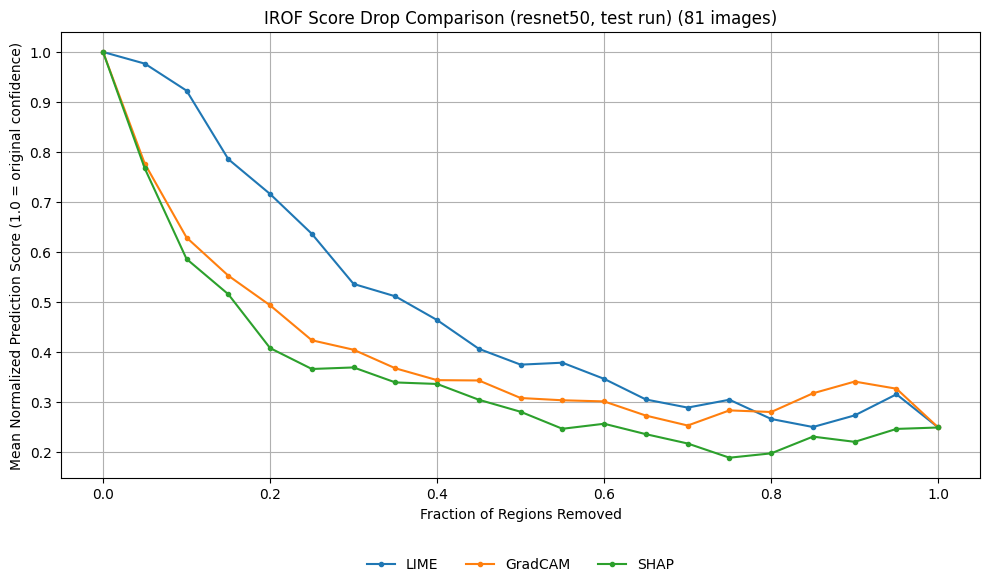

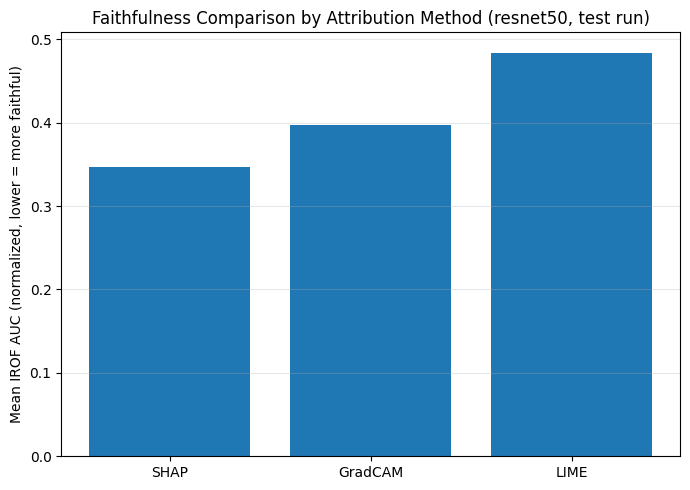


  Faithfulness (IROF) | Model: efficientnetb0


Running faithfulness (IROF) test run on 81 images 



IROF:   0%|                                                        | 0/81 [00:00<?, ?it/s]

[W910 16:40:23.676029608 NNPACK.cpp:61] Could not initialize NNPACK! Reason: Unsupported hardware.



IROF:   1%|▌                                               | 1/81 [00:07<09:27,  7.09s/it]


IROF:   2%|█▏                                              | 2/81 [00:14<09:13,  7.00s/it]


IROF:   4%|█▊                                              | 3/81 [00:22<10:09,  7.82s/it]


IROF:   5%|██▎                                             | 4/81 [00:29<09:37,  7.50s/it]


IROF:   6%|██▉                                             | 5/81 [00:36<09:07,  7.20s/it]


IROF:   7%|███▌                                            | 6/81 [00:43<09:04,  7.26s/it]


IROF:   9%|████▏                                           | 7/81 [00:50<08:34,  6.95s/it]


IROF:  10%|████▋                                           | 8/81 [00:56<08:12,  6.75s/it]


IROF:  11%|█████▎                                          | 9/81 [01:03<08:18,  6.92s/it]


IROF:  12%|█████▊                                         | 10/81 [01:11<08:17,  7.01s/it]


IROF:  14%|██████▍                                        | 11/81 [01:18<08:24,  7.20s/it]


IROF:  15%|██████▉                                        | 12/81 [01:25<08:09,  7.09s/it]


IROF:  16%|███████▌                                       | 13/81 [01:33<08:15,  7.28s/it]


IROF:  17%|████████                                       | 14/81 [01:40<07:58,  7.14s/it]


IROF:  19%|████████▋                                      | 15/81 [01:47<08:01,  7.29s/it]


IROF:  20%|█████████▎                                     | 16/81 [01:54<07:44,  7.15s/it]


IROF:  21%|█████████▊                                     | 17/81 [02:00<07:18,  6.85s/it]


IROF:  22%|██████████▍                                    | 18/81 [02:07<07:08,  6.80s/it]


IROF:  23%|███████████                                    | 19/81 [02:14<07:02,  6.82s/it]


IROF:  25%|███████████▌                                   | 20/81 [02:21<06:56,  6.83s/it]


IROF:  26%|████████████▏                                  | 21/81 [02:29<07:12,  7.21s/it]


IROF:  27%|████████████▊                                  | 22/81 [02:35<06:58,  7.09s/it]


IROF:  28%|█████████████▎                                 | 23/81 [02:42<06:49,  7.07s/it]


IROF:  30%|█████████████▉                                 | 24/81 [02:51<07:00,  7.38s/it]


IROF:  31%|██████████████▌                                | 25/81 [02:57<06:36,  7.08s/it]


IROF:  32%|███████████████                                | 26/81 [03:04<06:29,  7.08s/it]


IROF:  33%|███████████████▋                               | 27/81 [03:11<06:28,  7.20s/it]


IROF:  35%|████████████████▏                              | 28/81 [03:19<06:27,  7.30s/it]


IROF:  36%|████████████████▊                              | 29/81 [03:26<06:14,  7.19s/it]


IROF:  37%|█████████████████▍                             | 30/81 [03:33<06:04,  7.15s/it]


IROF:  38%|█████████████████▉                             | 31/81 [03:40<06:02,  7.25s/it]


IROF:  40%|██████████████████▌                            | 32/81 [03:48<06:03,  7.42s/it]


IROF:  41%|███████████████████▏                           | 33/81 [03:56<06:03,  7.58s/it]


IROF:  42%|███████████████████▋                           | 34/81 [04:03<05:45,  7.35s/it]


IROF:  43%|████████████████████▎                          | 35/81 [04:10<05:29,  7.17s/it]


IROF:  44%|████████████████████▉                          | 36/81 [04:17<05:20,  7.13s/it]


IROF:  46%|█████████████████████▍                         | 37/81 [04:24<05:12,  7.11s/it]


IROF:  47%|██████████████████████                         | 38/81 [04:32<05:13,  7.28s/it]


IROF:  48%|██████████████████████▋                        | 39/81 [04:39<05:13,  7.46s/it]


IROF:  49%|███████████████████████▏                       | 40/81 [04:46<04:49,  7.07s/it]


IROF:  51%|███████████████████████▊                       | 41/81 [04:53<04:41,  7.05s/it]


IROF:  52%|████████████████████████▎                      | 42/81 [05:00<04:43,  7.26s/it]


IROF:  53%|████████████████████████▉                      | 43/81 [05:08<04:41,  7.41s/it]


IROF:  54%|█████████████████████████▌                     | 44/81 [05:15<04:28,  7.27s/it]


IROF:  56%|██████████████████████████                     | 45/81 [05:22<04:15,  7.10s/it]


IROF:  57%|██████████████████████████▋                    | 46/81 [05:28<03:54,  6.69s/it]


IROF:  58%|███████████████████████████▎                   | 47/81 [05:34<03:41,  6.51s/it]


IROF:  59%|███████████████████████████▊                   | 48/81 [05:39<03:27,  6.30s/it]


IROF:  60%|████████████████████████████▍                  | 49/81 [05:46<03:19,  6.24s/it]


IROF:  62%|█████████████████████████████                  | 50/81 [05:53<03:23,  6.58s/it]


IROF:  63%|█████████████████████████████▌                 | 51/81 [06:01<03:34,  7.14s/it]


IROF:  64%|██████████████████████████████▏                | 52/81 [06:08<03:18,  6.86s/it]


IROF:  65%|██████████████████████████████▊                | 53/81 [06:15<03:13,  6.91s/it]


IROF:  67%|███████████████████████████████▎               | 54/81 [06:21<03:00,  6.67s/it]


IROF:  68%|███████████████████████████████▉               | 55/81 [06:28<02:56,  6.78s/it]


IROF:  69%|████████████████████████████████▍              | 56/81 [06:34<02:49,  6.78s/it]


IROF:  70%|█████████████████████████████████              | 57/81 [06:42<02:48,  7.02s/it]


IROF:  72%|█████████████████████████████████▋             | 58/81 [06:48<02:36,  6.81s/it]


IROF:  73%|██████████████████████████████████▏            | 59/81 [06:56<02:33,  7.00s/it]


IROF:  74%|██████████████████████████████████▊            | 60/81 [07:03<02:27,  7.02s/it]


IROF:  75%|███████████████████████████████████▍           | 61/81 [07:10<02:19,  6.97s/it]


IROF:  77%|███████████████████████████████████▉           | 62/81 [07:17<02:14,  7.09s/it]


IROF:  78%|████████████████████████████████████▌          | 63/81 [07:24<02:06,  7.05s/it]


IROF:  79%|█████████████████████████████████████▏         | 64/81 [07:31<01:59,  7.01s/it]


IROF:  80%|█████████████████████████████████████▋         | 65/81 [07:39<01:55,  7.19s/it]


IROF:  81%|██████████████████████████████████████▎        | 66/81 [07:46<01:47,  7.15s/it]


IROF:  83%|██████████████████████████████████████▉        | 67/81 [07:51<01:34,  6.74s/it]


IROF:  84%|███████████████████████████████████████▍       | 68/81 [07:58<01:27,  6.76s/it]


IROF:  85%|████████████████████████████████████████       | 69/81 [08:06<01:24,  7.07s/it]


IROF:  86%|████████████████████████████████████████▌      | 70/81 [08:13<01:16,  6.94s/it]


IROF:  88%|█████████████████████████████████████████▏     | 71/81 [08:20<01:09,  6.91s/it]


IROF:  89%|█████████████████████████████████████████▊     | 72/81 [08:27<01:02,  6.94s/it]


IROF:  90%|██████████████████████████████████████████▎    | 73/81 [08:33<00:54,  6.85s/it]


IROF:  91%|██████████████████████████████████████████▉    | 74/81 [08:40<00:47,  6.76s/it]


IROF:  93%|███████████████████████████████████████████▌   | 75/81 [08:47<00:41,  6.86s/it]


IROF:  94%|████████████████████████████████████████████   | 76/81 [08:53<00:33,  6.62s/it]


IROF:  95%|████████████████████████████████████████████▋  | 77/81 [09:01<00:28,  7.07s/it]


IROF:  96%|█████████████████████████████████████████████▎ | 78/81 [09:08<00:21,  7.07s/it]


IROF:  98%|█████████████████████████████████████████████▊ | 79/81 [09:16<00:14,  7.20s/it]


IROF:  99%|██████████████████████████████████████████████▍| 80/81 [09:24<00:07,  7.49s/it]


IROF: 100%|███████████████████████████████████████████████| 81/81 [09:30<00:00,  7.27s/it]


IROF: 100%|███████████████████████████████████████████████| 81/81 [09:30<00:00,  7.05s/it]


Collected 243 IROF measurements
Saved per-image results to /data/ramdhavb/results/irof_full_efficientnetb0_test_2026-09-10.csv
Saved summary to /data/ramdhavb/results/irof_summary_efficientnetb0_test_2026-09-10.csv

=== Faithfulness (IROF) summary | efficientnetb0 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
2,SHAP,0.3757,0.1595,81
0,GradCAM,0.3825,0.1845,81
1,LIME,0.6052,0.2369,81


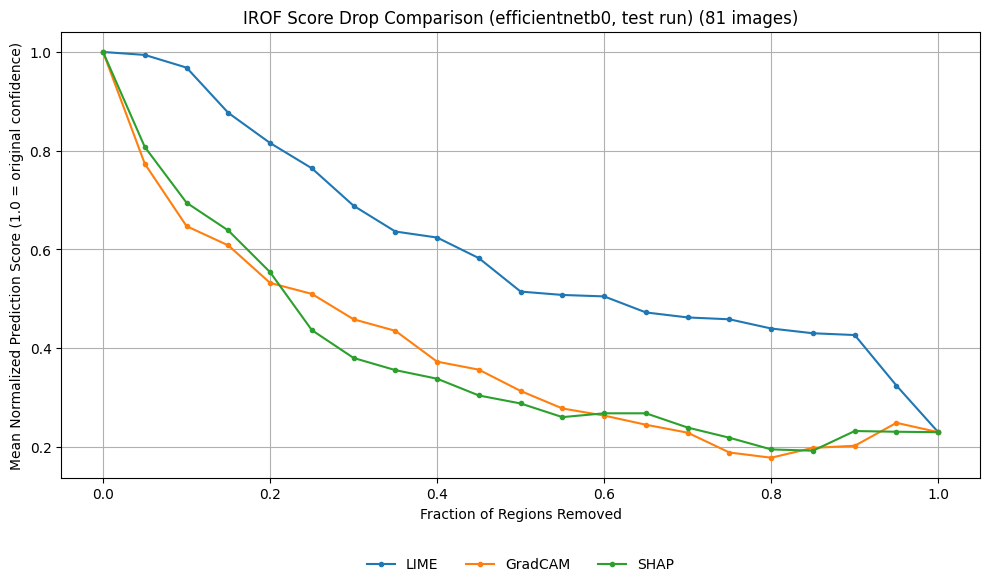

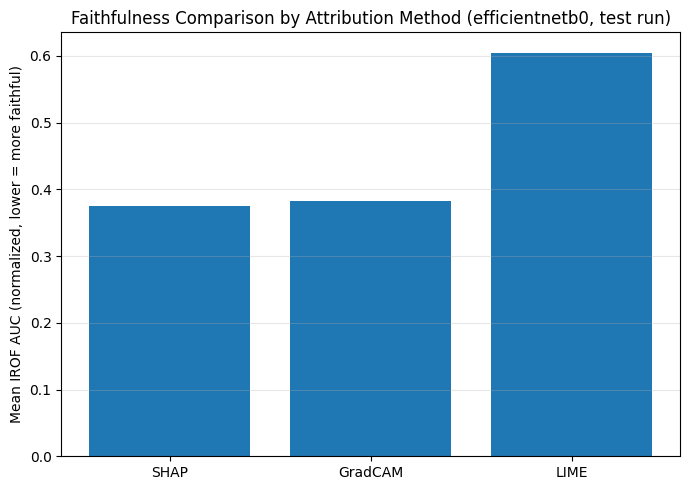


=== Combined IROF summary (all models) ===


,model,method,mean_irof_auc,std_irof_auc,n_images
2,efficientnetb0,SHAP,0.3757,0.1595,81
0,efficientnetb0,GradCAM,0.3825,0.1845,81
1,efficientnetb0,LIME,0.6052,0.2369,81
5,resnet50,SHAP,0.3466,0.1835,81
3,resnet50,GradCAM,0.3971,0.1861,81
4,resnet50,LIME,0.4840,0.2310,81


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_trapz = getattr(np, "trapezoid", None) or np.trapz

all_irof_dfs = []
irof_curves_by_model = {}

for model_name in["resnet50", "efficientnetb0"]:
    print(f"\n{'='*60}\n  Faithfulness (IROF) | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    engine = AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    method_maps = load_attribution_maps(SAVE_DIR, model_name)
    N_FAITHFULNESS_IMAGES = len(next(iter(method_maps.values())))
    faithfulness_samples = idrid_subset[:N_FAITHFULNESS_IMAGES]

    predicted_labels = get_predicted_labels(model, faithfulness_samples, device)

    print(f"Running faithfulness (IROF) test run on {N_FAITHFULNESS_IMAGES} images ")

    full_irof_df, irof_curves, irof_random_curves = run_irof_evaluation(
        model, faithfulness_samples, predicted_labels, method_maps, device=device
    )

    full_irof_df['model'] = model_name
    all_irof_dfs.append(full_irof_df)
    irof_curves_by_model[model_name] = irof_curves

    print(f"\nCollected {len(full_irof_df)} IROF measurements")

    irof_summary = summarize_and_save_irof(
        full_irof_df,
        results_dir="/data/aveera/results",
        tag=f"{model_name}_test"
    )

    print(f"\n=== Faithfulness (IROF) summary | {model_name} ===")
    print("    (lower mean_irof_auc = confidence drops faster once top-attributed regions")
    print("     are removed = more faithful explanation)\n")
    display(irof_summary)

    plot_irof_curves(irof_curves, N_FAITHFULNESS_IMAGES, title_suffix=f" ({model_name}, test run)")
    print()
    plot_irof_bar(irof_summary, title_suffix=f" ({model_name}, test run)")

    del method_maps, irof_random_curves
    unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    gpu_mem_report(f"after unloading {model_name}")

full_irof_df_all_models = pd.concat(all_irof_dfs, ignore_index=True)
combined_irof_summary = (
    full_irof_df_all_models.groupby(['model', 'method'])
    .agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'), n_images=('irof_auc', 'count'))
    .reset_index()
    .sort_values(['model', 'mean_irof_auc'])
)

combined_irof_summary['mean_irof_auc'] = combined_irof_summary['mean_irof_auc'].round(4)
combined_irof_summary['std_irof_auc'] = combined_irof_summary['std_irof_auc'].round(4)

print("\n=== Combined IROF summary (all models) ===")
display(combined_irof_summary)

In [ ]:
RESULTS_DIR = "/data/aveera/results"
combined_irof_summary.to_csv(os.path.join(RESULTS_DIR, "irof_summary_all_models.csv"), index=False)

# **Interpretation of the IROF Score Curve**
The displayed score curve illustrates how the model’s output score changes when important image regions are gradually masked. The regions are sorted based on their estimated importance according to the chosen attribution method and then removed step by step.

An ideal score curve would show a continuous and steady decline. This would indicate that the model strongly relies on these regions for its prediction. An unstable or fluctuating curve should not necessarily be interpreted as an error but rather as a possible indication of a robust model or a broadly distributed attribution.

In this case, the score curve shows an unusual pattern. Instead of decreasing steadily, the score goes up and down a lot. There are two possible reasons for this:

1. The model appears to be highly robust to the removal of individual regions and is able to extract relevant information from the remaining areas.

2. The selected attribution method (eg. LIME) distributes importance relatively evenly across many regions, resulting in less focused and highly localized key areas.